# **Part Two: Explainable Artificial Intelligence (XAI)**

In [1]:
# !git clone https://github.com/XAIdataset/XAIdataset.github.io.git xaibenchmark_repo
# %cd xaibenchmark_repo
# !pip install -e . --break-system-packages
# %cd ..

In [2]:
# !git clone https://github.com/XAIdataset/XAIdataset.github.io.git xaibenchmark_repo

In [3]:
# !dir /s /b xaibenchmark_repo\__init__.py

In [4]:
# !pip install xaibenchmark_repo/

In [5]:
import xaibenchmark

In [6]:
# %pip install --upgrade shap opencv-python

In [7]:
# !pip install -q grad-cam
# !pip install lime
# !pip install shap
# !pip install opencv-python-headless

In [8]:
import os
import random
import time
import warnings
warnings.filterwarnings("ignore")

import torchvision.models as models
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import cv2
from scipy.stats import spearmanr
from torchvision import transforms

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from skimage.segmentation import slic
import shap

from PIL import Image as PILImage
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
from torch.utils.data import Dataset, DataLoader

import cv2

In [9]:
from shap import PartitionExplainer

In [10]:
# !pip install -q quantus
# !pip install -q cachetools

In [11]:
import quantus
from quantus import PointingGame, MaxSensitivity
import glob
from PIL import Image

from pytorch_grad_cam.utils.image import preprocess_image, show_cam_on_image
from quantus import norm_func, perturb_func, similarity_func
from datetime import datetime

In [12]:
# !pip install captum
# !pip install tf-explain

In [13]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
SEED = 42

In [14]:
import gc 

**Mount Drive**

In [15]:
# drive.mount('/content/drive')

In [16]:
def load_model(model_name, weight_path, device):
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


# **Downloading the Refined IDRID segmentation dataset**

For our Diabetic retinopathy segmentation images, we decided to go with [Refined IDRiD](https://www.mdpi.com/2306-5729/11/2/30) as it identified and corrected some issues within the widely adopted Indian Diabetic Retinopathy Image Dataset

In [18]:
IDRID_DIR = "/data/aveera/Refined IDRiD"

IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR / your Drive layout.")

print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)


**The segmentation dataset we are using has some features that aren't useful to us like the background or anatomical structure, so we remove them from our masks.**

In [19]:
# Grabbing the pixel values of all the lesions
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}

**Applying the same preprocessing pipeline used for the APTOS training images (Ben Graham-style `circle_crop`) to the IDRiD localization-evaluation images.**

**The lesion masks are kept pixel-aligned with the image by applying the *same crop / circular-FOV vignette* to the mask at every step -- the only step****skipped for the mask is the local-average contrast/blur enhancement, since that has no meaning for a binary mask.**

In [20]:
def crop_bbox_from_gray(img, tol=7):
    gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    fg_mask = gray_img > tol
    row_mask, col_mask = fg_mask.any(1), fg_mask.any(0)

    check_shape = img[:, :, 0][np.ix_(row_mask, col_mask)].shape[0]
    if check_shape == 0:  # image too dark -- crop_image_from_gray falls back to the original image
        return None, None
    return row_mask, col_mask


def circle_crop_with_mask(img_rgb, lesion_mask, sigmaX=30):
    img = img_rgb
    mask = lesion_mask

    # Gray-crop (removes the black border around the fundus photo)
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Circular FOV vignette, centred on the (now cropped) image
    height, width = img.shape[:2]
    cx, cy = width // 2, height // 2
    r = np.amin((cx, cy))

    circle_mask = np.zeros((height, width), np.uint8)
    cv2.circle(circle_mask, (cx, cy), int(r), 1, thickness=-1)

    img = cv2.bitwise_and(img, img, mask=circle_mask)
    mask = mask * circle_mask  # Zero out any lesion pixels that fall outside the circular FOV

    # Second gray-crop
    row_mask, col_mask = crop_bbox_from_gray(img)
    if row_mask is not None:
        img = img[np.ix_(row_mask, col_mask)]
        mask = mask[np.ix_(row_mask, col_mask)]

    # Local-average contrast/brightness enhancement to image only
    img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigmaX), -4, 128)

    return img, mask


**Downsample a binary mask so that any block containing at least**
**one lesion pixel is marked as lesion in the output.**

Microaneurysms can be as small as a few pixels, so after this shrinking they become smaller than a single pixel in our masks. If we only marked a pixel as "lesion" when most of its area was lesion, nearly all microaneurysms would simply vanish from the ground truth. Instead, we mark a pixel as "lesion" if any part of it touched a lesion at all. This makes lesion boundaries look slightly larger than they truly are, but ensures we don't lose the smallest and most important lesions entirely.

In [21]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

In [22]:
def load_idrid_subset_preprocessed(split_dirs, target_size=(224, 224), max_images=None, sigmaX=30):
    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        for img_path in image_paths:
            if split_dir == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"):
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] # Checking for test images

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            # Same Ben Graham preprocessing pipeline used for the APTOS training images
            cropped_img, cropped_mask = circle_crop_with_mask(raw_img, lesion_mask, sigmaX=sigmaX)

            img_resized = cv2.resize(cropped_img, target_size)
            mask_resized = resize_mask_no_loss(cropped_mask, target_size)

            samples.append((img_resized, mask_resized))

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

In [23]:
idrid_subset = load_idrid_subset_preprocessed(IDRID_SPLIT_DIRS, sigmaX=30)

print(f"IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): "
      f"{len(idrid_subset)} images with lesion masks")


There are  27  images in  /data/aveera/Refined IDRiD/Test/Test


There are  81  images in  /data/aveera/Refined IDRiD/Train/Train
IDRiD localization-evaluation subset (circle-crop preprocessed, same pipeline as APTOS): 81 images with lesion masks


**Side by side comparison of before and after image preprocessing**

In [24]:
def show_idrid_before_after(split_dirs, index=0, target_size=(224, 224), sigmaX=30):

#Collect all image paths across the given split dirs
    all_image_paths = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        all_image_paths.extend(sorted(glob.glob(os.path.join(images_dir, "*.jpg"))))

    if not all_image_paths:
        raise FileNotFoundError("No .jpg images found in the given split directories.")

    img_path = all_image_paths[index]
    image_id = os.path.splitext(os.path.basename(img_path))[0]

    raw_img = np.array(Image.open(img_path).convert('RGB'))

    dummy_mask = np.zeros(raw_img.shape[:2], dtype=np.uint8)
    cropped_img  = circle_crop_with_mask(raw_img, dummy_mask, sigmaX=sigmaX)
    processed_img = cv2.resize(cropped_img, target_size)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(raw_img)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(processed_img)
    axes[1].set_title("After Preprocessing")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    return raw_img, processed_img

**Side-by-side comparison of of the mask before and after we remove the anatomical structures.**

Sample: IDRiD_55f055
Unique label values in raw mask: [0, 8, 16, 24, 32, 63, 127, 191, 255]
Lesion pixels after filtering: 5.23% of image
Lesion pixel count: 2623


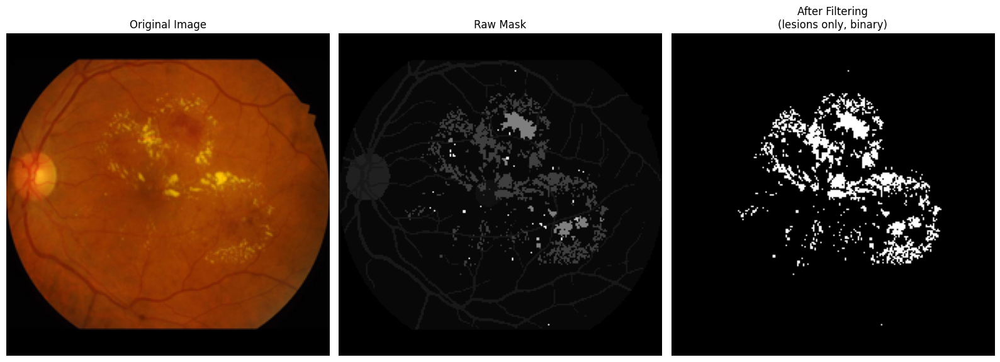

In [25]:
split_dir = IDRID_SPLIT_DIRS[0]
images_dir = os.path.join(split_dir, "Images")
labels_dir = os.path.join(split_dir, "Labels")

sample_img_path = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))[0]

if os.path.normpath(split_dir) == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"):
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0] + "_vessel"
else:
    image_id = os.path.splitext(os.path.basename(sample_img_path))[0]

sample_mask_path = os.path.join(labels_dir, f"{image_id}.png")
target_size = (224, 224)

raw_img = np.array(Image.open(sample_img_path).convert('RGB').resize(target_size))
raw_mask_native = np.array(Image.open(sample_mask_path).convert('L'))

raw_mask = cv2.resize(raw_mask_native, target_size, interpolation=cv2.INTER_NEAREST)

lesion_only_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

print(f"Sample: {image_id}")
print(f"Unique label values in raw mask: {sorted(np.unique(raw_mask).tolist())}")
print(f"Lesion pixels after filtering: {lesion_only_mask.mean():.2%} of image")
print(f"Lesion pixel count: {lesion_only_mask.sum()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(raw_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(raw_mask, cmap="gray")
axes[1].set_title("Raw Mask")
axes[1].axis("off")

axes[2].imshow(lesion_only_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("After Filtering\n(lesions only, binary)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

**This function fetches the weights for the model saved from the drive and loads them into the appropriate model.**

In [26]:
def load_model(model_name, weight_path, device):
    """Load the model given the model weights"""
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model

In [27]:
class_names = ["No DR", "Mild DR","Moderate DR", "Severe DR","Proliferative DR"]

In [28]:
idrid_loader = DataLoader(
    idrid_subset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True
)

**While Grad-CAM is widely applied in DR interpretability literature, disclosed hyperparameters for perturbation-based methods (LIME, SHAP) are rarely reported in DR-specific work.**

Our parameter choices were therefore informed by broader medical-imaging and XAI benchmarking literature rather than DR-specific research, while also accoutning for our resource constraints given the scale of our evaluation.

**For LIME, we set lime_samples=1000**, consistent with values used in [Gastrointestinal Endoscopic study](https://arxiv.org/pdf/2503.00780), [Sickle Cell study](https://arxiv.org/pdf/2305.01663) and [Photonic Chip study](https://arxiv.org/pdf/2505.09266) which set the number of samples to 1000 to ensure the creation of a sufficient number of perturbed samples around the input instance for accurate approximation.

**For SHAP, we set the max_evals =500**, consistent with the [Sickle Cell study](https://arxiv.org/pdf/2305.01663) from above and is also the SHAP libraries default. We also use batch_size-50 which is the SHAP library, the same justification as this study [haematopoietic stem cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12746025/)


**We use a 32x32 blur kernel for the SHAP masker, smaller than the 128x128 kernel used in SHAP's reference examples for 224x224 natural images.** In natural-image classification, the relevant object typically occupies a large contiguous region of the frame whereas for DR lesion attribution, multiple small lesions can appear simultaneously across the image. A 128x128 kernel would blur across a majority of the image width in a single masking operation, conflating spatially distinct lesions that should be attributed independently, which is why we choose 32x32

**The XAI Attribution Engine is a single wrapper around three XAI methods, so each trained model can be explained the same way regardless of which method is used. Given a model and an image, it returns an attribution map per method highlighting the regions that most influenced the prediction**

In [29]:
class AttributionEngine:
    IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    CLASS_NAMES = ["No DR","Mild DR","Moderate DR","Severe DR", "Proliferative DR"]

    def __init__(self, model, device, lime_samples=1000, img_size=224, shap_max_evals=500, shap_batch_size=50):
        self.model = model.to(device)
        self.model.eval()
        self.device = device

        self.lime_samples    = lime_samples     # How many perturbed versions of the image LIME generates to fit its local surrogate model
        self.img_size        = img_size
        self.shap_max_evals  = shap_max_evals   # How many masked evaluations shap.Explainer's Partition explainer is allowed per image
        self.shap_batch_size = shap_batch_size  # Batch size used when shap.Explainer evaluates masked images through the model
        self.class_names     = self.CLASS_NAMES

        self._gradcam = None

        self._norm_transform = transforms.Normalize(mean=self.IMAGENET_MEAN.tolist(), std=self.IMAGENET_STD.tolist()) # Stores the standard ImageNet normalization
        self.shap_explainer = None  # Built lazily on first compute_shap() call, once we know the image shape
        self.lime_explainer = lime_image.LimeImageExplainer()

    def find_gradcam_target_layer(self):
      if hasattr(self.model, "layer4"):
          target_layer = self.model.layer4[-1]
          layer_desc = "self.model.layer4[-1] (last residual block)"
      elif hasattr(self.model, "features"):
          target_layer = self.model.features[-1]
          layer_desc = "self.model.features[-1] (last conv+BN+activation block)"
      else:
          conv_layers = [m for m in self.model.modules() if isinstance(m, nn.Conv2d)]
          if not conv_layers:
              raise ValueError("Could not locate a Conv2d layer in the model for Grad-CAM.")
          target_layer = conv_layers[-1]
          layer_desc = ("Last convolutional layer. It is a raw convolutional layer")
      return target_layer

    # Builds a Grad-CAM object
    def get_gradcam(self):
        if self._gradcam is None:
            target_layer = self.find_gradcam_target_layer()
            self._gradcam = GradCAM(model=self.model, target_layers=[target_layer])
        return self._gradcam

    def unnormalize_to_uint8(self, img_tensor):
        """Unormalizes the image for LIME and SHAP (since they need the original image to create their superpixels)"""
        img = img_tensor.detach().cpu().numpy().transpose(1, 2, 0)
        img = img * self.IMAGENET_STD + self.IMAGENET_MEAN
        img = np.clip(img, 0.0, 1.0)
        return (img * 255).astype(np.uint8)

    @staticmethod
    def normalize_map(m, pct_clip=99.0, mode="abs"):
        m = np.nan_to_num(m.astype(np.float32))
        if mode == "abs":
            m = np.abs(m)
        elif mode == "pos":
            m = np.clip(m, 0, None)
        else:
            raise ValueError(f"Unknown normalize mode: {mode!r} (expected 'abs' or 'pos')")

        if m.max() > 0:
            clip_val = np.percentile(m, pct_clip)
            if clip_val > 0:
                m = np.clip(m, 0, clip_val)
        mn, mx = m.min(), m.max()
        if mx - mn > 1e-12:
            m = (m - mn) / (mx - mn)
        else:
            m = np.zeros_like(m)
        return m

    def resize_map(self, m):
        """Grad-CAM generally produces a smaller image, so the image is resized back to a normal viewing standard (224 x 224 pixels)"""
        if m.shape[0] != self.img_size or m.shape[1] != self.img_size:
            m = cv2.resize(m.astype(np.float32), (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        return m

    def compute_gradcam(self, img, target_class):
        """Computes and returns the Grad-CAM heatmap"""
        cam = self.get_gradcam()
        targets = [ClassifierOutputTarget(target_class)]
        grayscale_cam = cam(input_tensor=img, targets=targets)[0]
        heatmap = self.normalize_map(grayscale_cam, mode="abs")
        return self.resize_map(heatmap)

    def show_grad_cam(self, img, raw_img_uint8, target_class):
        """Displays the GradCAM heatmap"""
        heatmap = self.compute_gradcam(img, target_class)
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image")
        axes[0].axis("off")
        axes[1].imshow(raw_img_uint8)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        axes[1].set_title("Grad-CAM")
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()

    def _lime_predict_fn(self, numpy_images):
        """Returns the model's raw logits as a numpy array"""
        tensor = torch.from_numpy(numpy_images).float().to(self.device)
        tensor = tensor / 255.0
        tensor = tensor.permute(0, 3, 1, 2)
        tensor = self._norm_transform(tensor)

        with torch.no_grad():
            logits = self.model(tensor)

        return logits.cpu().numpy()

    def compute_lime(self, raw_img_uint8, target_class):
        """Runs LIME once, returns the raw explanation object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        explanation = self.lime_explainer.explain_instance(
            raw_img_uint8.astype('double'),
            self._lime_predict_fn,
            top_labels=5,
            hide_color=0, # Uses a flat black baseline to represent "hidden" superpixels, following the library's default
            num_samples=self.lime_samples,
        )

        if target_class not in explanation.local_exp:
            raise ValueError(
                f"LIME did not explain class {target_class} "
                f"(only explained {list(explanation.local_exp.keys())}); increase top_labels."
            )
        return explanation

    def get_lime_heatmap(self, explanation, target_class):
        """LIME heatmaps for Pointing Game"""
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)
        heatmap = self.normalize_map(heatmap, mode="pos")
        return self.resize_map(heatmap)

    def show_lime(self, raw_img_uint8, target_class, num_features=5, positive_only=True):
        """Displays the LIME maps."""
        explanation = self.compute_lime(raw_img_uint8, target_class)

        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        fig.suptitle(f"LIME Detailed Subpixel Diagnostics: {type(self.model).__name__} (Class {target_class})",fontsize=14, weight='bold', y=1.02)

        # Original image
        axes[0].imshow(raw_img_uint8)
        axes[0].set_title("Original Image Structure")
        axes[0].axis("off")

        # Positive-only masking, using the method's own parameters
        temp1, mask1 = explanation.get_image_and_mask(
            target_class, positive_only=positive_only, num_features=num_features, hide_rest=True
        )
        axes[1].imshow(mark_boundaries(temp1 / 255.0, mask1))
        axes[1].set_title(f"Top {num_features} {'Positive' if positive_only else 'Pos/Neg'} Features")
        axes[1].axis("off")

        # Pros & cons boundary (fixed at 10 features, both signs, rest shown)
        temp2, mask2 = explanation.get_image_and_mask(
            target_class, positive_only=False, num_features=10, hide_rest=False
        )
        axes[2].imshow(mark_boundaries(temp2 / 255.0, mask2))
        axes[2].set_title("Top 10 Pros/Cons Boundary")
        axes[2].axis("off")

        # Symmetrical continuous weight heatmap
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap_matrix = np.vectorize(dict_heatmap.get)(explanation.segments)

        max_val = np.abs(heatmap_matrix).max() if np.abs(heatmap_matrix).max() > 0 else 1.0
        im = axes[3].imshow(heatmap_matrix, cmap='RdBu', vmin=-max_val, vmax=max_val)
        axes[3].set_title("Symmetrical Weight Distribution")
        axes[3].axis("off")

        fig.colorbar(im, ax=axes[3], orientation='vertical', fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

    def _shap_predict_fn(self, numpy_images):
        """Returns the model's raw logits as a numpy array"""
        tensor = torch.from_numpy(numpy_images).float().to(self.device)
        tensor = tensor / 255.0
        tensor = tensor.permute(0, 3, 1, 2)
        tensor = self._norm_transform(tensor)

        with torch.no_grad():
            logits = self.model(tensor)

        return logits.cpu().numpy()

    def _build_shap_explainer(self, image_shape):
        """Builds the SHAP explainer object."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)
        masker_blur = shap.maskers.Image("blur(32,32)", image_shape)
        self.shap_explainer = shap.Explainer(self._shap_predict_fn, masker_blur, output_names=self.class_names)

    def compute_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Return the SHAP values for the given image."""
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        if self.shap_explainer is None:
            self._build_shap_explainer(raw_img_uint8.shape)

        images_batch = raw_img_uint8[np.newaxis, ...]
        n_classes = len(self.class_names) if self.class_names else 5
        outputs = list(range(n_classes)) if all_classes else [target_class]

        return self.shap_explainer(images_batch,max_evals=self.shap_max_evals,batch_size=self.shap_batch_size,outputs=outputs,)

    def get_shap_heatmap(self, shap_values, class_position=0):
        """SHAP heatmaps for Pointing Game"""
        raw_shap = shap_values.values[0, :, :, :, class_position]
        sv_signed = raw_shap.sum(axis=-1)
        heatmap = self.normalize_map(sv_signed, mode="pos")
        return self.resize_map(heatmap), self.resize_map(sv_signed)

    def show_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        """Visualizes SHAP values using SHAP's own built-in image_plot."""
        shap_values = self.compute_shap(raw_img_uint8, target_class=target_class, all_classes=all_classes)
        shap.image_plot(shap_values)

    def compute_all(self, img_tensor, label):
        """Runs all the XAI techniques at once, returns a dictionary with the results."""
        self.model.eval()
        img = img_tensor.unsqueeze(0).to(self.device)

        with torch.no_grad():
            pred = self.model(img).argmax(dim=1).item()

        raw_img_uint8 = self.unnormalize_to_uint8(img_tensor)

        gradcam_map = self.compute_gradcam(img, pred)

        lime_explanation = self.compute_lime(raw_img_uint8, pred)
        lime_map = self.get_lime_heatmap(lime_explanation, pred)

        shap_values = self.compute_shap(raw_img_uint8, target_class=pred, all_classes=False)
        shap_map, sv_signed = self.get_shap_heatmap(shap_values, class_position=0)

        return {'lime': lime_map, 'shap': shap_map, 'visual_shap': sv_signed, 'gradcam': gradcam_map, 'pred': pred}

In [30]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""

    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError(
            "No AttributionEngine registered for this model."
        )
    return eng


In [31]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [32]:
def run_attributions_on_samples(engine, samples, transform, desc="XAI"):
    results = {'lime': [], 'shap': [], 'gradcam': [], 'labels': []}
    for raw_img, label in samples:
        img_tensor = transform(PILImage.fromarray(raw_img))
        maps = engine.compute_all(img_tensor, label)
        results['lime'].append(maps['lime'])
        results['shap'].append(maps['shap'])
        results['gradcam'].append(maps['gradcam'])
        results['labels'].append(label)
    return results

# **Side-by-Side Comparison of each XAI technique**

--- resnet50 ---


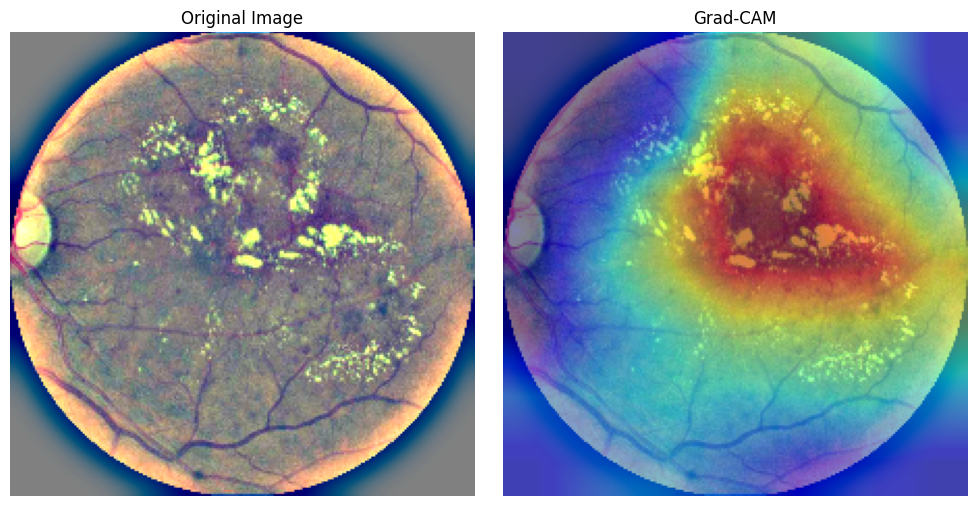

  0%|          | 0/498 [00:00<?, ?it/s]

 99%|█████████▉| 492/498 [00:00<00:00, 2264.65it/s]

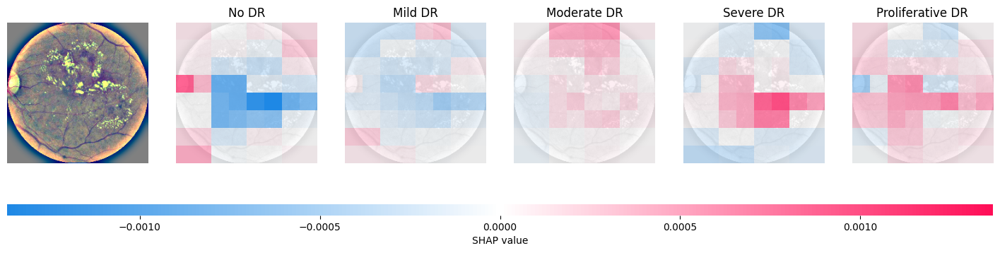

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<01:04, 15.29it/s]

  2%|▏         | 20/1000 [00:00<00:34, 28.15it/s]

  3%|▎         | 30/1000 [00:00<00:24, 39.04it/s]

  4%|▍         | 40/1000 [00:01<00:20, 47.33it/s]

  5%|▌         | 50/1000 [00:01<00:17, 53.94it/s]

  6%|▌         | 60/1000 [00:01<00:16, 58.70it/s]

  7%|▋         | 70/1000 [00:01<00:14, 62.71it/s]

  8%|▊         | 80/1000 [00:01<00:14, 65.30it/s]

  9%|▉         | 90/1000 [00:01<00:13, 67.06it/s]

 10%|█         | 100/1000 [00:01<00:13, 67.79it/s]

 11%|█         | 110/1000 [00:02<00:12, 68.51it/s]

 12%|█▏        | 120/1000 [00:02<00:12, 69.34it/s]

 13%|█▎        | 130/1000 [00:02<00:12, 70.10it/s]

 14%|█▍        | 140/1000 [00:02<00:12, 70.33it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 70.01it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 69.93it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 69.09it/s]

 18%|█▊        | 180/1000 [00:03<00:11, 68.57it/s]

 19%|█▉        | 190/1000 [00:03<00:11, 68.05it/s]

 20%|██        | 200/1000 [00:03<00:11, 67.34it/s]

 21%|██        | 210/1000 [00:03<00:11, 67.32it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 67.12it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 67.10it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 66.71it/s]

 25%|██▌       | 250/1000 [00:04<00:11, 66.35it/s]

 26%|██▌       | 260/1000 [00:04<00:11, 66.20it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 65.88it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 65.36it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 64.82it/s]

 30%|███       | 300/1000 [00:04<00:10, 64.31it/s]

 31%|███       | 310/1000 [00:05<00:10, 63.96it/s]

 32%|███▏      | 320/1000 [00:05<00:10, 63.82it/s]

 33%|███▎      | 330/1000 [00:05<00:10, 63.60it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 63.70it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 63.11it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 62.89it/s]

 37%|███▋      | 370/1000 [00:06<00:10, 62.62it/s]

 38%|███▊      | 380/1000 [00:06<00:09, 62.63it/s]

 39%|███▉      | 390/1000 [00:06<00:09, 62.24it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.78it/s]

 41%|████      | 410/1000 [00:06<00:09, 61.28it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 61.46it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 61.65it/s]

 44%|████▍     | 440/1000 [00:07<00:09, 62.22it/s]

 45%|████▌     | 450/1000 [00:07<00:08, 62.31it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 62.08it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 62.04it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 61.79it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 62.00it/s]

 50%|█████     | 500/1000 [00:08<00:08, 62.25it/s]

 51%|█████     | 510/1000 [00:08<00:07, 62.04it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 62.28it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 62.54it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 62.39it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 62.58it/s]

 56%|█████▌    | 560/1000 [00:09<00:07, 62.65it/s]

 57%|█████▋    | 570/1000 [00:09<00:06, 62.63it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 62.77it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 62.65it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.44it/s]

 61%|██████    | 610/1000 [00:09<00:06, 62.66it/s]

 62%|██████▏   | 620/1000 [00:10<00:06, 63.04it/s]

 63%|██████▎   | 630/1000 [00:10<00:05, 63.07it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 62.97it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 62.37it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 61.97it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.87it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 61.69it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 61.28it/s]

 70%|███████   | 700/1000 [00:11<00:04, 61.08it/s]

 71%|███████   | 710/1000 [00:11<00:04, 61.45it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 61.72it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 62.04it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 61.82it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 61.90it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 62.06it/s]

 77%|███████▋  | 770/1000 [00:12<00:03, 62.03it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 61.84it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.84it/s]

 80%|████████  | 800/1000 [00:12<00:03, 61.79it/s]

 81%|████████  | 810/1000 [00:13<00:03, 62.21it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 62.11it/s]

 83%|████████▎ | 830/1000 [00:13<00:02, 62.27it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 62.66it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 62.86it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 63.05it/s]

 87%|████████▋ | 870/1000 [00:14<00:02, 62.87it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 62.90it/s]

 89%|████████▉ | 890/1000 [00:14<00:01, 62.63it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 62.74it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.73it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 63.07it/s]

 93%|█████████▎| 930/1000 [00:15<00:01, 62.90it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 62.67it/s]

 95%|█████████▌| 950/1000 [00:15<00:00, 62.05it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 61.64it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 61.47it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 61.64it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 61.46it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.23it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.90it/s]

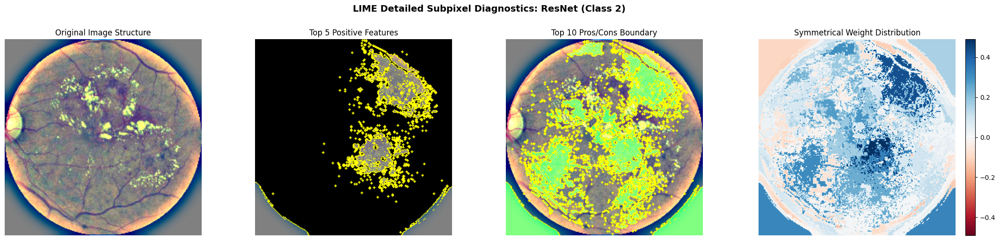

--- efficientnetb0 ---


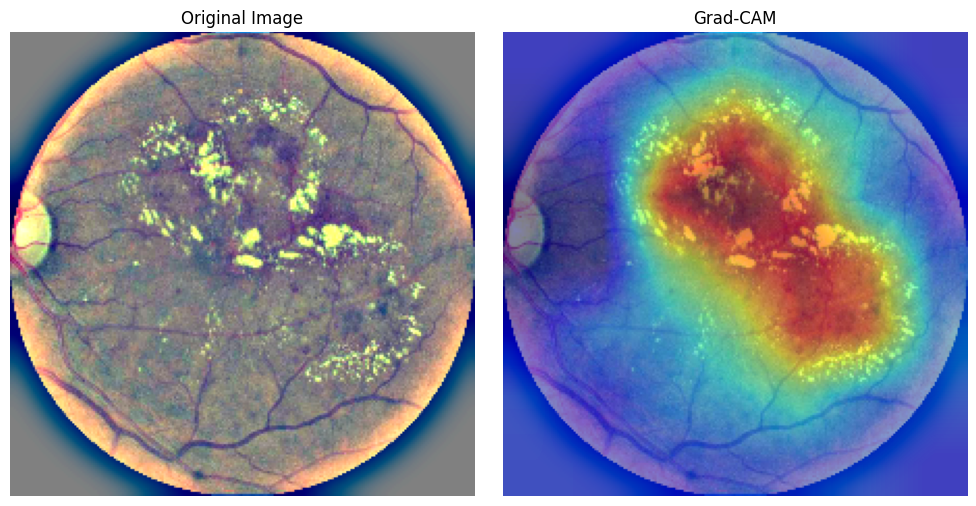

  0%|          | 0/498 [00:00<?, ?it/s]

 25%|██▍       | 124/498 [00:04<00:13, 27.45it/s]

 35%|███▍      | 174/498 [00:04<00:07, 41.52it/s]

 45%|████▍     | 224/498 [00:04<00:04, 59.82it/s]

 55%|█████▌    | 274/498 [00:04<00:02, 82.82it/s]

 65%|██████▌   | 324/498 [00:05<00:01, 110.57it/s]

 75%|███████▌  | 374/498 [00:05<00:00, 142.36it/s]

 85%|████████▌ | 424/498 [00:05<00:00, 176.85it/s]

 95%|█████████▌| 474/498 [00:05<00:00, 211.78it/s]

524it [00:05, 245.51it/s]                         

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:16, 16.76s/it]               

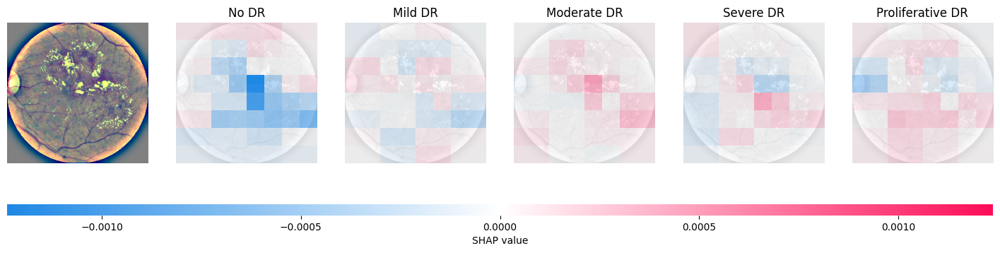

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:02<03:28,  4.74it/s]

  2%|▏         | 20/1000 [00:02<01:32, 10.55it/s]

  3%|▎         | 30/1000 [00:02<00:55, 17.47it/s]

  4%|▍         | 40/1000 [00:02<00:38, 25.13it/s]

  5%|▌         | 50/1000 [00:02<00:28, 33.32it/s]

  6%|▌         | 60/1000 [00:02<00:22, 41.39it/s]

  7%|▋         | 70/1000 [00:02<00:18, 49.13it/s]

  8%|▊         | 80/1000 [00:03<00:16, 55.79it/s]

  9%|▉         | 90/1000 [00:03<00:14, 61.31it/s]

 10%|█         | 100/1000 [00:03<00:13, 65.15it/s]

 11%|█         | 110/1000 [00:03<00:13, 68.38it/s]

 12%|█▏        | 120/1000 [00:03<00:12, 71.10it/s]

 13%|█▎        | 130/1000 [00:03<00:11, 73.54it/s]

 14%|█▍        | 140/1000 [00:03<00:11, 74.72it/s]

 15%|█▌        | 150/1000 [00:03<00:11, 75.58it/s]

 16%|█▌        | 160/1000 [00:04<00:10, 76.65it/s]

 17%|█▋        | 170/1000 [00:04<00:10, 76.70it/s]

 18%|█▊        | 180/1000 [00:04<00:10, 76.80it/s]

 19%|█▉        | 190/1000 [00:04<00:10, 77.02it/s]

 20%|██        | 200/1000 [00:04<00:10, 76.73it/s]

 21%|██        | 210/1000 [00:04<00:10, 77.12it/s]

 22%|██▏       | 220/1000 [00:04<00:10, 77.21it/s]

 23%|██▎       | 230/1000 [00:04<00:09, 77.45it/s]

 24%|██▍       | 240/1000 [00:05<00:09, 77.04it/s]

 25%|██▌       | 250/1000 [00:05<00:09, 77.19it/s]

 26%|██▌       | 260/1000 [00:05<00:09, 77.44it/s]

 27%|██▋       | 270/1000 [00:05<00:09, 77.37it/s]

 28%|██▊       | 280/1000 [00:05<00:09, 76.58it/s]

 29%|██▉       | 290/1000 [00:05<00:09, 76.68it/s]

 30%|███       | 300/1000 [00:05<00:09, 76.30it/s]

 31%|███       | 310/1000 [00:05<00:09, 76.36it/s]

 32%|███▏      | 320/1000 [00:06<00:08, 76.39it/s]

 33%|███▎      | 330/1000 [00:06<00:08, 76.42it/s]

 34%|███▍      | 340/1000 [00:06<00:08, 76.97it/s]

 35%|███▌      | 350/1000 [00:06<00:08, 76.54it/s]

 36%|███▌      | 360/1000 [00:06<00:08, 76.59it/s]

 37%|███▋      | 370/1000 [00:06<00:08, 76.82it/s]

 38%|███▊      | 380/1000 [00:06<00:08, 77.22it/s]

 39%|███▉      | 390/1000 [00:07<00:07, 76.90it/s]

 40%|████      | 400/1000 [00:07<00:07, 76.56it/s]

 41%|████      | 410/1000 [00:07<00:07, 76.27it/s]

 42%|████▏     | 420/1000 [00:07<00:07, 76.63it/s]

 43%|████▎     | 430/1000 [00:07<00:07, 76.78it/s]

 44%|████▍     | 440/1000 [00:07<00:07, 77.49it/s]

 45%|████▌     | 450/1000 [00:07<00:07, 77.49it/s]

 46%|████▌     | 460/1000 [00:07<00:07, 77.12it/s]

 47%|████▋     | 470/1000 [00:08<00:06, 76.96it/s]

 48%|████▊     | 480/1000 [00:08<00:06, 76.87it/s]

 49%|████▉     | 490/1000 [00:08<00:06, 76.83it/s]

 50%|█████     | 500/1000 [00:08<00:06, 77.16it/s]

 51%|█████     | 510/1000 [00:08<00:06, 76.69it/s]

 52%|█████▏    | 520/1000 [00:08<00:06, 77.26it/s]

 53%|█████▎    | 530/1000 [00:08<00:06, 77.47it/s]

 54%|█████▍    | 540/1000 [00:08<00:05, 77.13it/s]

 55%|█████▌    | 550/1000 [00:09<00:05, 77.16it/s]

 56%|█████▌    | 560/1000 [00:09<00:05, 77.06it/s]

 57%|█████▋    | 570/1000 [00:09<00:05, 76.88it/s]

 58%|█████▊    | 580/1000 [00:09<00:05, 76.98it/s]

 59%|█████▉    | 590/1000 [00:09<00:05, 76.76it/s]

 60%|██████    | 600/1000 [00:09<00:05, 76.50it/s]

 61%|██████    | 610/1000 [00:09<00:05, 76.63it/s]

 62%|██████▏   | 620/1000 [00:10<00:04, 77.29it/s]

 63%|██████▎   | 630/1000 [00:10<00:04, 77.49it/s]

 64%|██████▍   | 640/1000 [00:10<00:04, 78.15it/s]

 65%|██████▌   | 650/1000 [00:10<00:04, 77.91it/s]

 66%|██████▌   | 660/1000 [00:10<00:04, 77.80it/s]

 67%|██████▋   | 670/1000 [00:10<00:04, 77.91it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 77.73it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 77.17it/s]

 70%|███████   | 700/1000 [00:11<00:03, 77.06it/s]

 71%|███████   | 710/1000 [00:11<00:03, 77.80it/s]

 72%|███████▏  | 720/1000 [00:11<00:03, 77.61it/s]

 73%|███████▎  | 730/1000 [00:11<00:03, 77.85it/s]

 74%|███████▍  | 740/1000 [00:11<00:03, 77.18it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 77.05it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 77.06it/s]

 77%|███████▋  | 770/1000 [00:11<00:02, 77.09it/s]

 78%|███████▊  | 780/1000 [00:12<00:02, 76.64it/s]

 79%|███████▉  | 790/1000 [00:12<00:02, 76.42it/s]

 80%|████████  | 800/1000 [00:12<00:02, 76.25it/s]

 81%|████████  | 810/1000 [00:12<00:02, 77.05it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 76.66it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 76.47it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 76.66it/s]

 85%|████████▌ | 850/1000 [00:12<00:01, 77.19it/s]

 86%|████████▌ | 860/1000 [00:13<00:01, 77.16it/s]

 87%|████████▋ | 870/1000 [00:13<00:01, 76.58it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 76.93it/s]

 89%|████████▉ | 890/1000 [00:13<00:01, 76.43it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 76.75it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 76.71it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 77.58it/s]

 93%|█████████▎| 930/1000 [00:14<00:00, 77.37it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 77.67it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 76.98it/s]

 96%|█████████▌| 960/1000 [00:14<00:00, 76.88it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 76.50it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 77.09it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 76.97it/s]

100%|██████████| 1000/1000 [00:14<00:00, 76.57it/s]

100%|██████████| 1000/1000 [00:14<00:00, 66.91it/s]

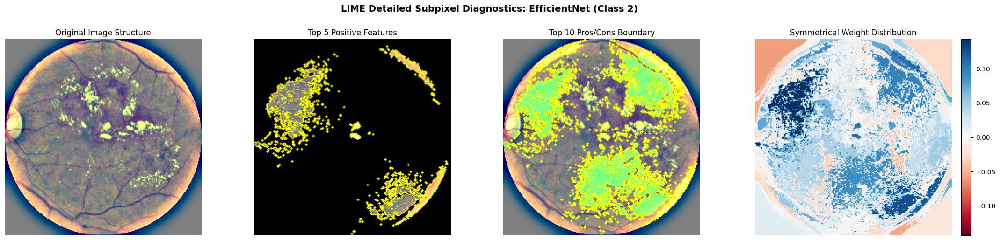

In [33]:
raw_image, lesion_mask = idrid_subset[0] # Sample image
drive_model_dir = "/data/aveera/models"
# xai_maps = {}

for model_name in ["resnet50","efficientnetb0"]:
  drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
  model = load_model(model_name, drive_weight_path, device)

  engine = AttributionEngine(model, device)
  # Initialize SHAP background for the current engine
  _engine_cache[id(model)] = engine  # register so explain_* (MaxSensitivity) can find this engine later

  image_tensor = test_transform(PILImage.fromarray(raw_image))
  with torch.no_grad():
    predicted_class = model(image_tensor.unsqueeze(0).to(device)).argmax(dim=1).item()

  # Compute all heatmaps for downstream metrics (Pointing Game, IROF, etc.)
  # xai_maps[model_name] = engine.compute_all(image_tensor, predicted_class)

  # Visual display for this model
  raw_img_uint8 = engine.unnormalize_to_uint8(image_tensor)
  img_batched = image_tensor.unsqueeze(0).to(device)

  print(f"--- {model_name} ---")
  engine.show_grad_cam(img_batched, raw_img_uint8, predicted_class)
  engine.show_shap(raw_img_uint8, target_class=predicted_class, all_classes=True)
  engine.show_lime(raw_img_uint8, target_class=predicted_class)

# print("Computed attribution maps for:",list(xai_maps.keys()))

# **Part Three: Explainability Evaluation Metrics**

# **Localization Evaluation: The pointing game and IoU**


**Pointing Game**: Takes the single highest-attribution pixel in the explanation map and checks if it falls inside the ground-truth lesion region. Scores 1 if yes, 0 if no. It's a strict, all-or-nothing test of whether the model's single most important pixel is disease-relevant.

**IoU**: Measures a model's localization performance by calculating the ratio of the overlap area to the combined total area of the predicted bounding box and the ground-truth bounding box


In [34]:
import os
import numpy as np

N_TEST = 81
SAVE_DIR = "/data/aveera/xai_maps"
os.makedirs(SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

attribution_maps_by_model = {}

for model_name in ["resnet50", "efficientnetb0"]:
    save_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")

    if os.path.exists(save_path):
        print(f"\nFound existing maps for {model_name} at {save_path}")
        data = np.load(save_path)
        attribution_maps_by_model[model_name] ={
            'gts': data['gts'],
            'gradcam': data['gradcam'],
            'lime': data['lime'],
            'shap': data['shap']
        }
        continue

    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    attribution_results = run_attributions_on_samples(engine, test_samples, test_transform, desc=f"XAI maps ({model_name})")

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    attribution_maps_by_model[model_name]= {
        'gts': gts, 
        'gradcam': gradcam_maps, 
        'lime': lime_maps, 
        'shap': shap_maps
    }

    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")


  Computing attribution maps | Model: resnet50


  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 83.75it/s]

  2%|▏         | 18/1000 [00:00<00:16, 59.18it/s]

  2%|▎         | 25/1000 [00:00<00:18, 53.21it/s]

  3%|▎         | 31/1000 [00:00<00:19, 49.21it/s]

  4%|▍         | 39/1000 [00:00<00:17, 56.32it/s]

  4%|▍         | 45/1000 [00:00<00:18, 51.90it/s]

  5%|▌         | 51/1000 [00:00<00:19, 48.86it/s]

  6%|▌         | 59/1000 [00:01<00:16, 55.71it/s]

  6%|▋         | 65/1000 [00:01<00:18, 51.45it/s]

  7%|▋         | 71/1000 [00:01<00:18, 49.17it/s]

  8%|▊         | 79/1000 [00:01<00:16, 55.87it/s]

  8%|▊         | 85/1000 [00:01<00:17, 51.75it/s]

  9%|▉         | 91/1000 [00:01<00:18, 48.81it/s]

 10%|▉         | 99/1000 [00:01<00:16, 54.80it/s]

 10%|█         | 105/1000 [00:01<00:17, 50.95it/s]

 11%|█         | 111/1000 [00:02<00:18, 48.24it/s]

 12%|█▏        | 119/1000 [00:02<00:15, 55.07it/s]

 12%|█▎        | 125/1000 [00:02<00:17, 51.18it/s]

 13%|█▎        | 131/1000 [00:02<00:17, 49.01it/s]

 14%|█▍        | 139/1000 [00:02<00:15, 55.69it/s]

 14%|█▍        | 145/1000 [00:02<00:16, 51.72it/s]

 15%|█▌        | 151/1000 [00:02<00:17, 48.88it/s]

 16%|█▌        | 159/1000 [00:03<00:15, 55.52it/s]

 16%|█▋        | 165/1000 [00:03<00:16, 51.29it/s]

 17%|█▋        | 171/1000 [00:03<00:17, 48.49it/s]

 18%|█▊        | 179/1000 [00:03<00:14, 54.99it/s]

 18%|█▊        | 185/1000 [00:03<00:15, 51.08it/s]

 19%|█▉        | 191/1000 [00:03<00:16, 48.58it/s]

 20%|█▉        | 199/1000 [00:03<00:14, 54.34it/s]

 20%|██        | 205/1000 [00:03<00:15, 50.74it/s]

 21%|██        | 211/1000 [00:04<00:16, 48.33it/s]

 22%|██▏       | 219/1000 [00:04<00:14, 54.91it/s]

 22%|██▎       | 225/1000 [00:04<00:15, 51.39it/s]

 23%|██▎       | 231/1000 [00:04<00:15, 48.56it/s]

 24%|██▍       | 239/1000 [00:04<00:13, 55.10it/s]

 24%|██▍       | 245/1000 [00:04<00:14, 50.87it/s]

 25%|██▌       | 251/1000 [00:04<00:15, 48.31it/s]

 26%|██▌       | 259/1000 [00:04<00:13, 55.18it/s]

 26%|██▋       | 265/1000 [00:05<00:14, 51.14it/s]

 27%|██▋       | 271/1000 [00:05<00:15, 48.33it/s]

 28%|██▊       | 279/1000 [00:05<00:13, 54.70it/s]

 28%|██▊       | 285/1000 [00:05<00:14, 50.65it/s]

 29%|██▉       | 291/1000 [00:05<00:14, 47.89it/s]

 30%|██▉       | 299/1000 [00:05<00:12, 54.35it/s]

 30%|███       | 305/1000 [00:05<00:13, 50.25it/s]

 31%|███       | 311/1000 [00:06<00:14, 47.80it/s]

 32%|███▏      | 319/1000 [00:06<00:12, 54.34it/s]

 32%|███▎      | 325/1000 [00:06<00:13, 50.28it/s]

 33%|███▎      | 331/1000 [00:06<00:13, 47.81it/s]

 34%|███▍      | 339/1000 [00:06<00:12, 54.67it/s]

 34%|███▍      | 345/1000 [00:06<00:12, 50.60it/s]

 35%|███▌      | 351/1000 [00:06<00:13, 47.81it/s]

 36%|███▌      | 359/1000 [00:06<00:11, 54.44it/s]

 36%|███▋      | 365/1000 [00:07<00:12, 50.49it/s]

 37%|███▋      | 371/1000 [00:07<00:13, 47.85it/s]

 38%|███▊      | 379/1000 [00:07<00:11, 54.74it/s]

 38%|███▊      | 385/1000 [00:07<00:12, 50.79it/s]

 39%|███▉      | 391/1000 [00:07<00:12, 48.02it/s]

 40%|███▉      | 399/1000 [00:07<00:11, 54.53it/s]

 40%|████      | 405/1000 [00:07<00:11, 50.28it/s]

 41%|████      | 411/1000 [00:07<00:12, 47.76it/s]

 42%|████▏     | 419/1000 [00:08<00:10, 54.50it/s]

 42%|████▎     | 425/1000 [00:08<00:11, 50.53it/s]

 43%|████▎     | 431/1000 [00:08<00:11, 48.28it/s]

 44%|████▍     | 439/1000 [00:08<00:10, 55.33it/s]

 44%|████▍     | 445/1000 [00:08<00:10, 51.07it/s]

 45%|████▌     | 451/1000 [00:08<00:11, 48.66it/s]

 46%|████▌     | 459/1000 [00:08<00:09, 55.15it/s]

 46%|████▋     | 465/1000 [00:09<00:10, 51.05it/s]

 47%|████▋     | 471/1000 [00:09<00:11, 48.07it/s]

 48%|████▊     | 479/1000 [00:09<00:09, 54.52it/s]

 48%|████▊     | 485/1000 [00:09<00:10, 50.94it/s]

 49%|████▉     | 491/1000 [00:09<00:10, 48.23it/s]

 50%|████▉     | 499/1000 [00:09<00:09, 54.83it/s]

 50%|█████     | 505/1000 [00:09<00:09, 50.60it/s]

 51%|█████     | 511/1000 [00:09<00:10, 48.13it/s]

 52%|█████▏    | 519/1000 [00:10<00:08, 54.65it/s]

 52%|█████▎    | 525/1000 [00:10<00:09, 51.03it/s]

 53%|█████▎    | 531/1000 [00:10<00:09, 48.15it/s]

 54%|█████▍    | 539/1000 [00:10<00:08, 54.82it/s]

 55%|█████▍    | 545/1000 [00:10<00:08, 50.94it/s]

 55%|█████▌    | 551/1000 [00:10<00:09, 48.28it/s]

 56%|█████▌    | 559/1000 [00:10<00:08, 54.80it/s]

 56%|█████▋    | 565/1000 [00:10<00:08, 51.05it/s]

 57%|█████▋    | 571/1000 [00:11<00:08, 48.18it/s]

 58%|█████▊    | 579/1000 [00:11<00:07, 55.00it/s]

 58%|█████▊    | 585/1000 [00:11<00:08, 50.55it/s]

 59%|█████▉    | 591/1000 [00:11<00:08, 48.01it/s]

 60%|█████▉    | 599/1000 [00:11<00:07, 54.52it/s]

 60%|██████    | 605/1000 [00:11<00:07, 50.48it/s]

 61%|██████    | 611/1000 [00:11<00:08, 48.03it/s]

 62%|██████▏   | 619/1000 [00:12<00:06, 55.09it/s]

 62%|██████▎   | 625/1000 [00:12<00:07, 51.04it/s]

 63%|██████▎   | 631/1000 [00:12<00:07, 48.54it/s]

 64%|██████▍   | 639/1000 [00:12<00:06, 55.63it/s]

 64%|██████▍   | 645/1000 [00:12<00:06, 51.35it/s]

 65%|██████▌   | 651/1000 [00:12<00:07, 48.29it/s]

 66%|██████▌   | 659/1000 [00:12<00:06, 54.70it/s]

 66%|██████▋   | 665/1000 [00:12<00:06, 50.88it/s]

 67%|██████▋   | 671/1000 [00:13<00:06, 48.21it/s]

 68%|██████▊   | 679/1000 [00:13<00:05, 54.86it/s]

 68%|██████▊   | 685/1000 [00:13<00:06, 50.48it/s]

 69%|██████▉   | 691/1000 [00:13<00:06, 47.65it/s]

 70%|██████▉   | 699/1000 [00:13<00:05, 54.55it/s]

 70%|███████   | 705/1000 [00:13<00:05, 50.69it/s]

 71%|███████   | 711/1000 [00:13<00:06, 48.12it/s]

 72%|███████▏  | 719/1000 [00:13<00:05, 54.81it/s]

 72%|███████▎  | 725/1000 [00:14<00:05, 50.48it/s]

 73%|███████▎  | 731/1000 [00:14<00:05, 48.14it/s]

 74%|███████▍  | 739/1000 [00:14<00:04, 54.59it/s]

 74%|███████▍  | 745/1000 [00:14<00:05, 50.69it/s]

 75%|███████▌  | 751/1000 [00:14<00:05, 48.20it/s]

 76%|███████▌  | 759/1000 [00:14<00:04, 54.78it/s]

 76%|███████▋  | 765/1000 [00:14<00:04, 50.73it/s]

 77%|███████▋  | 771/1000 [00:15<00:04, 48.13it/s]

 78%|███████▊  | 779/1000 [00:15<00:04, 54.52it/s]

 78%|███████▊  | 785/1000 [00:15<00:04, 50.47it/s]

 79%|███████▉  | 791/1000 [00:15<00:04, 47.79it/s]

 80%|███████▉  | 799/1000 [00:15<00:03, 54.22it/s]

 80%|████████  | 805/1000 [00:15<00:03, 50.70it/s]

 81%|████████  | 811/1000 [00:15<00:03, 48.13it/s]

 82%|████████▏ | 819/1000 [00:15<00:03, 54.58it/s]

 82%|████████▎ | 825/1000 [00:16<00:03, 50.31it/s]

 83%|████████▎ | 831/1000 [00:16<00:03, 47.75it/s]

 84%|████████▍ | 839/1000 [00:16<00:02, 54.58it/s]

 84%|████████▍ | 845/1000 [00:16<00:03, 50.58it/s]

 85%|████████▌ | 851/1000 [00:16<00:03, 48.23it/s]

 86%|████████▌ | 859/1000 [00:16<00:02, 55.04it/s]

 86%|████████▋ | 865/1000 [00:16<00:02, 50.69it/s]

 87%|████████▋ | 871/1000 [00:16<00:02, 47.89it/s]

 88%|████████▊ | 879/1000 [00:17<00:02, 54.69it/s]

 88%|████████▊ | 885/1000 [00:17<00:02, 50.45it/s]

 89%|████████▉ | 891/1000 [00:17<00:02, 47.86it/s]

 90%|████████▉ | 899/1000 [00:17<00:01, 54.49it/s]

 90%|█████████ | 905/1000 [00:17<00:01, 50.70it/s]

 91%|█████████ | 911/1000 [00:17<00:01, 48.03it/s]

 92%|█████████▏| 919/1000 [00:17<00:01, 55.00it/s]

 92%|█████████▎| 925/1000 [00:18<00:01, 50.64it/s]

 93%|█████████▎| 931/1000 [00:18<00:01, 48.05it/s]

 94%|█████████▍| 939/1000 [00:18<00:01, 55.01it/s]

 94%|█████████▍| 945/1000 [00:18<00:01, 50.78it/s]

 95%|█████████▌| 951/1000 [00:18<00:01, 47.84it/s]

 96%|█████████▌| 959/1000 [00:18<00:00, 54.19it/s]

 96%|█████████▋| 965/1000 [00:18<00:00, 50.58it/s]

 97%|█████████▋| 971/1000 [00:18<00:00, 47.84it/s]

 98%|█████████▊| 979/1000 [00:19<00:00, 54.65it/s]

 98%|█████████▊| 985/1000 [00:19<00:00, 50.86it/s]

 99%|█████████▉| 991/1000 [00:19<00:00, 47.80it/s]

100%|█████████▉| 999/1000 [00:19<00:00, 54.37it/s]

100%|██████████| 1000/1000 [00:19<00:00, 51.23it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.76it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.84it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.42it/s]

  3%|▎         | 33/1000 [00:00<00:16, 59.08it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.57it/s]

  5%|▍         | 48/1000 [00:00<00:14, 63.78it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.49it/s]

  6%|▌         | 62/1000 [00:01<00:16, 56.96it/s]

  7%|▋         | 70/1000 [00:01<00:16, 56.07it/s]

  8%|▊         | 79/1000 [00:01<00:14, 62.52it/s]

  9%|▊         | 86/1000 [00:01<00:15, 58.68it/s]

  9%|▉         | 92/1000 [00:01<00:16, 56.01it/s]

 10%|█         | 100/1000 [00:01<00:16, 54.71it/s]

 11%|█         | 108/1000 [00:01<00:14, 60.12it/s]

 12%|█▏        | 115/1000 [00:01<00:15, 57.01it/s]

 12%|█▏        | 121/1000 [00:02<00:16, 54.23it/s]

 13%|█▎        | 129/1000 [00:02<00:14, 60.41it/s]

 14%|█▎        | 136/1000 [00:02<00:15, 57.17it/s]

 14%|█▍        | 142/1000 [00:02<00:15, 54.24it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 53.84it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 59.75it/s]

 16%|█▋        | 165/1000 [00:02<00:14, 56.47it/s]

 17%|█▋        | 171/1000 [00:02<00:15, 53.07it/s]

 18%|█▊        | 179/1000 [00:03<00:13, 58.81it/s]

 19%|█▊        | 186/1000 [00:03<00:14, 55.21it/s]

 19%|█▉        | 192/1000 [00:03<00:15, 52.27it/s]

 20%|██        | 200/1000 [00:03<00:15, 51.60it/s]

 21%|██        | 208/1000 [00:03<00:13, 57.77it/s]

 21%|██▏       | 214/1000 [00:03<00:14, 53.69it/s]

 22%|██▏       | 220/1000 [00:03<00:15, 51.08it/s]

 23%|██▎       | 228/1000 [00:03<00:13, 57.54it/s]

 23%|██▎       | 234/1000 [00:04<00:14, 53.39it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 50.68it/s]

 25%|██▍       | 248/1000 [00:04<00:13, 57.62it/s]

 25%|██▌       | 254/1000 [00:04<00:14, 53.13it/s]

 26%|██▌       | 260/1000 [00:04<00:14, 50.37it/s]

 27%|██▋       | 268/1000 [00:04<00:12, 57.22it/s]

 27%|██▋       | 274/1000 [00:04<00:13, 53.15it/s]

 28%|██▊       | 280/1000 [00:05<00:14, 50.26it/s]

 29%|██▉       | 288/1000 [00:05<00:12, 57.17it/s]

 29%|██▉       | 294/1000 [00:05<00:13, 52.92it/s]

 30%|███       | 300/1000 [00:05<00:14, 49.92it/s]

 31%|███       | 308/1000 [00:05<00:12, 56.90it/s]

 31%|███▏      | 314/1000 [00:05<00:13, 52.52it/s]

 32%|███▏      | 320/1000 [00:05<00:13, 49.60it/s]

 33%|███▎      | 328/1000 [00:05<00:11, 56.34it/s]

 33%|███▎      | 334/1000 [00:06<00:12, 52.36it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 49.69it/s]

 35%|███▍      | 348/1000 [00:06<00:11, 56.44it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 52.45it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 49.94it/s]

 37%|███▋      | 368/1000 [00:06<00:11, 56.78it/s]

 37%|███▋      | 374/1000 [00:06<00:11, 52.38it/s]

 38%|███▊      | 380/1000 [00:06<00:12, 49.60it/s]

 39%|███▉      | 388/1000 [00:06<00:10, 56.60it/s]

 39%|███▉      | 394/1000 [00:07<00:11, 52.22it/s]

 40%|████      | 400/1000 [00:07<00:12, 49.92it/s]

 41%|████      | 408/1000 [00:07<00:10, 56.71it/s]

 41%|████▏     | 414/1000 [00:07<00:11, 52.50it/s]

 42%|████▏     | 420/1000 [00:07<00:11, 49.60it/s]

 43%|████▎     | 428/1000 [00:07<00:10, 56.49it/s]

 43%|████▎     | 434/1000 [00:07<00:10, 52.18it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 49.52it/s]

 45%|████▍     | 448/1000 [00:08<00:09, 56.74it/s]

 45%|████▌     | 454/1000 [00:08<00:10, 52.43it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 49.93it/s]

 47%|████▋     | 469/1000 [00:08<00:09, 58.14it/s]

 48%|████▊     | 476/1000 [00:08<00:09, 54.12it/s]

 48%|████▊     | 482/1000 [00:08<00:10, 51.42it/s]

 49%|████▉     | 490/1000 [00:08<00:10, 50.73it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 57.20it/s]

 50%|█████     | 504/1000 [00:09<00:09, 52.73it/s]

 51%|█████     | 510/1000 [00:09<00:09, 49.76it/s]

 52%|█████▏    | 519/1000 [00:09<00:08, 57.97it/s]

 53%|█████▎    | 526/1000 [00:09<00:08, 54.08it/s]

 53%|█████▎    | 532/1000 [00:09<00:09, 50.98it/s]

 54%|█████▍    | 540/1000 [00:09<00:09, 49.73it/s]

 55%|█████▍    | 548/1000 [00:10<00:08, 56.47it/s]

 55%|█████▌    | 554/1000 [00:10<00:08, 52.49it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 50.27it/s]

 57%|█████▋    | 568/1000 [00:10<00:07, 57.35it/s]

 57%|█████▋    | 574/1000 [00:10<00:08, 53.00it/s]

 58%|█████▊    | 580/1000 [00:10<00:08, 50.22it/s]

 59%|█████▉    | 588/1000 [00:10<00:07, 57.28it/s]

 59%|█████▉    | 594/1000 [00:10<00:07, 52.81it/s]

 60%|██████    | 600/1000 [00:11<00:08, 49.97it/s]

 61%|██████    | 608/1000 [00:11<00:06, 57.00it/s]

 61%|██████▏   | 614/1000 [00:11<00:07, 52.77it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 49.91it/s]

 63%|██████▎   | 628/1000 [00:11<00:06, 56.72it/s]

 63%|██████▎   | 634/1000 [00:11<00:06, 52.48it/s]

 64%|██████▍   | 640/1000 [00:11<00:07, 49.67it/s]

 65%|██████▍   | 648/1000 [00:11<00:06, 56.75it/s]

 65%|██████▌   | 654/1000 [00:12<00:06, 52.62it/s]

 66%|██████▌   | 660/1000 [00:12<00:06, 49.98it/s]

 67%|██████▋   | 669/1000 [00:12<00:05, 58.08it/s]

 68%|██████▊   | 675/1000 [00:12<00:06, 54.10it/s]

 68%|██████▊   | 681/1000 [00:12<00:06, 51.19it/s]

 69%|██████▉   | 689/1000 [00:12<00:05, 57.99it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 53.75it/s]

 70%|███████   | 702/1000 [00:12<00:05, 50.62it/s]

 71%|███████   | 710/1000 [00:13<00:05, 50.41it/s]

 72%|███████▏  | 718/1000 [00:13<00:04, 56.94it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 52.91it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 49.64it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 56.19it/s]

 74%|███████▍  | 744/1000 [00:13<00:04, 52.24it/s]

 75%|███████▌  | 750/1000 [00:13<00:05, 49.66it/s]

 76%|███████▌  | 758/1000 [00:13<00:04, 56.84it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.63it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 49.85it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 57.21it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.69it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.85it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 56.92it/s]

 80%|████████  | 804/1000 [00:14<00:03, 52.70it/s]

 81%|████████  | 810/1000 [00:14<00:03, 50.10it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 56.82it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 52.68it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 49.78it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 56.45it/s]

 84%|████████▍ | 844/1000 [00:15<00:02, 52.33it/s]

 85%|████████▌ | 850/1000 [00:15<00:03, 49.55it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 56.83it/s]

 86%|████████▋ | 864/1000 [00:15<00:02, 52.74it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 49.84it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 56.78it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.59it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.58it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 56.90it/s]

 90%|█████████ | 904/1000 [00:16<00:01, 53.08it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 50.50it/s]

 92%|█████████▏| 918/1000 [00:16<00:01, 57.38it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 52.84it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 49.66it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 56.73it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 52.52it/s]

 95%|█████████▌| 950/1000 [00:17<00:01, 49.65it/s]

 96%|█████████▌| 958/1000 [00:17<00:00, 56.45it/s]

 96%|█████████▋| 964/1000 [00:17<00:00, 52.54it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.57it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.63it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.76it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 49.88it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 57.09it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.85it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 73.57it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.95it/s]

  3%|▎         | 28/1000 [00:00<00:13, 73.06it/s]

  4%|▎         | 36/1000 [00:00<00:14, 68.72it/s]

  4%|▍         | 43/1000 [00:00<00:14, 65.29it/s]

  5%|▌         | 50/1000 [00:00<00:15, 62.51it/s]

  6%|▌         | 60/1000 [00:00<00:14, 63.38it/s]

  7%|▋         | 69/1000 [00:01<00:13, 69.90it/s]

  8%|▊         | 77/1000 [00:01<00:13, 66.45it/s]

  8%|▊         | 84/1000 [00:01<00:14, 63.48it/s]

  9%|▉         | 91/1000 [00:01<00:14, 61.61it/s]

 10%|█         | 100/1000 [00:01<00:14, 61.07it/s]

 11%|█         | 109/1000 [00:01<00:13, 67.76it/s]

 12%|█▏        | 116/1000 [00:01<00:13, 63.28it/s]

 12%|█▏        | 123/1000 [00:01<00:14, 60.23it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 58.55it/s]

 14%|█▍        | 139/1000 [00:02<00:13, 65.99it/s]

 15%|█▍        | 146/1000 [00:02<00:13, 62.33it/s]

 15%|█▌        | 153/1000 [00:02<00:14, 59.49it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 57.97it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 59.13it/s]

 18%|█▊        | 179/1000 [00:02<00:12, 66.47it/s]

 19%|█▊        | 186/1000 [00:02<00:13, 62.10it/s]

 19%|█▉        | 193/1000 [00:03<00:13, 59.56it/s]

 20%|██        | 200/1000 [00:03<00:13, 57.33it/s]

 21%|██        | 209/1000 [00:03<00:12, 64.50it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 60.18it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 57.46it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 55.56it/s]

 24%|██▍       | 239/1000 [00:03<00:11, 63.68it/s]

 25%|██▍       | 246/1000 [00:03<00:12, 59.32it/s]

 25%|██▌       | 253/1000 [00:04<00:13, 56.79it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 55.00it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 63.22it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 59.22it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 56.93it/s]

 29%|██▉       | 290/1000 [00:04<00:12, 55.17it/s]

 30%|██▉       | 299/1000 [00:04<00:11, 63.13it/s]

 31%|███       | 306/1000 [00:04<00:11, 59.12it/s]

 31%|███▏      | 313/1000 [00:05<00:12, 56.59it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 54.94it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 63.19it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 58.89it/s]

 34%|███▍      | 343/1000 [00:05<00:11, 56.08it/s]

 35%|███▌      | 350/1000 [00:05<00:12, 54.06it/s]

 36%|███▌      | 359/1000 [00:05<00:10, 62.30it/s]

 37%|███▋      | 366/1000 [00:06<00:10, 58.22it/s]

 37%|███▋      | 373/1000 [00:06<00:11, 55.85it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 54.04it/s]

 39%|███▉      | 389/1000 [00:06<00:09, 62.45it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 58.65it/s]

 40%|████      | 403/1000 [00:06<00:10, 56.13it/s]

 41%|████      | 410/1000 [00:06<00:10, 54.30it/s]

 42%|████▏     | 420/1000 [00:06<00:10, 56.01it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 63.39it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 59.09it/s]

 44%|████▍     | 443/1000 [00:07<00:09, 56.38it/s]

 45%|████▌     | 450/1000 [00:07<00:10, 54.52it/s]

 46%|████▌     | 459/1000 [00:07<00:08, 62.44it/s]

 47%|████▋     | 466/1000 [00:07<00:09, 58.67it/s]

 47%|████▋     | 473/1000 [00:07<00:09, 56.17it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 54.45it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 62.78it/s]

 50%|████▉     | 496/1000 [00:08<00:08, 58.40it/s]

 50%|█████     | 503/1000 [00:08<00:08, 55.59it/s]

 51%|█████     | 510/1000 [00:08<00:09, 53.86it/s]

 52%|█████▏    | 519/1000 [00:08<00:07, 61.95it/s]

 53%|█████▎    | 526/1000 [00:08<00:08, 58.38it/s]

 53%|█████▎    | 533/1000 [00:08<00:08, 55.94it/s]

 54%|█████▍    | 540/1000 [00:09<00:08, 54.40it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 56.24it/s]

 56%|█████▌    | 559/1000 [00:09<00:06, 63.43it/s]

 57%|█████▋    | 566/1000 [00:09<00:07, 59.61it/s]

 57%|█████▋    | 573/1000 [00:09<00:07, 56.75it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 54.86it/s]

 59%|█████▉    | 589/1000 [00:09<00:06, 62.66it/s]

 60%|█████▉    | 596/1000 [00:09<00:06, 58.48it/s]

 60%|██████    | 603/1000 [00:10<00:07, 56.12it/s]

 61%|██████    | 610/1000 [00:10<00:07, 54.54it/s]

 62%|██████▏   | 619/1000 [00:10<00:06, 62.57it/s]

 63%|██████▎   | 626/1000 [00:10<00:06, 58.66it/s]

 63%|██████▎   | 633/1000 [00:10<00:06, 55.89it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 54.44it/s]

 65%|██████▍   | 649/1000 [00:10<00:05, 62.66it/s]

 66%|██████▌   | 656/1000 [00:11<00:05, 59.01it/s]

 66%|██████▋   | 663/1000 [00:11<00:05, 56.33it/s]

 67%|██████▋   | 670/1000 [00:11<00:06, 54.67it/s]

 68%|██████▊   | 679/1000 [00:11<00:05, 62.90it/s]

 69%|██████▊   | 686/1000 [00:11<00:05, 59.00it/s]

 69%|██████▉   | 693/1000 [00:11<00:05, 56.26it/s]

 70%|███████   | 700/1000 [00:11<00:05, 54.35it/s]

 71%|███████   | 709/1000 [00:11<00:04, 62.96it/s]

 72%|███████▏  | 716/1000 [00:12<00:04, 58.81it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.16it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 54.11it/s]

 74%|███████▍  | 739/1000 [00:12<00:04, 62.30it/s]

 75%|███████▍  | 746/1000 [00:12<00:04, 58.57it/s]

 75%|███████▌  | 753/1000 [00:12<00:04, 55.91it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 54.07it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.81it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 63.52it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 59.64it/s]

 79%|███████▉  | 793/1000 [00:13<00:03, 57.22it/s]

 80%|████████  | 800/1000 [00:13<00:03, 55.31it/s]

 81%|████████  | 809/1000 [00:13<00:03, 63.57it/s]

 82%|████████▏ | 816/1000 [00:13<00:03, 59.19it/s]

 82%|████████▏ | 823/1000 [00:13<00:03, 56.57it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 55.10it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 63.35it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 59.48it/s]

 85%|████████▌ | 853/1000 [00:14<00:02, 56.42it/s]

 86%|████████▌ | 860/1000 [00:14<00:02, 54.59it/s]

 87%|████████▋ | 869/1000 [00:14<00:02, 62.69it/s]

 88%|████████▊ | 876/1000 [00:14<00:02, 58.64it/s]

 88%|████████▊ | 883/1000 [00:14<00:02, 56.54it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 54.87it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 63.11it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 59.09it/s]

 91%|█████████▏| 913/1000 [00:15<00:01, 56.36it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 54.46it/s]

 93%|█████████▎| 929/1000 [00:15<00:01, 62.68it/s]

 94%|█████████▎| 936/1000 [00:15<00:01, 58.71it/s]

 94%|█████████▍| 943/1000 [00:15<00:01, 55.97it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 54.23it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 62.52it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 58.75it/s]

 97%|█████████▋| 973/1000 [00:16<00:00, 55.70it/s]

 98%|█████████▊| 980/1000 [00:16<00:00, 53.78it/s]

 99%|█████████▉| 989/1000 [00:16<00:00, 62.18it/s]

100%|█████████▉| 996/1000 [00:16<00:00, 58.05it/s]

100%|██████████| 1000/1000 [00:16<00:00, 58.87it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.68it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.07it/s]

  3%|▎         | 28/1000 [00:00<00:13, 72.57it/s]

  4%|▎         | 36/1000 [00:00<00:14, 68.78it/s]

  4%|▍         | 43/1000 [00:00<00:14, 65.52it/s]

  5%|▌         | 50/1000 [00:00<00:15, 62.39it/s]

  6%|▌         | 60/1000 [00:00<00:14, 63.13it/s]

  7%|▋         | 69/1000 [00:01<00:13, 69.58it/s]

  8%|▊         | 77/1000 [00:01<00:13, 66.09it/s]

  8%|▊         | 84/1000 [00:01<00:14, 62.93it/s]

  9%|▉         | 91/1000 [00:01<00:14, 60.80it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.22it/s]

 11%|█         | 110/1000 [00:01<00:14, 61.08it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 67.10it/s]

 13%|█▎        | 126/1000 [00:01<00:13, 63.01it/s]

 13%|█▎        | 133/1000 [00:02<00:14, 60.42it/s]

 14%|█▍        | 140/1000 [00:02<00:14, 58.12it/s]

 15%|█▍        | 149/1000 [00:02<00:12, 65.92it/s]

 16%|█▌        | 156/1000 [00:02<00:13, 61.78it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 59.26it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 57.51it/s]

 18%|█▊        | 179/1000 [00:02<00:12, 65.64it/s]

 19%|█▊        | 186/1000 [00:02<00:13, 61.68it/s]

 19%|█▉        | 193/1000 [00:03<00:13, 59.03it/s]

 20%|██        | 200/1000 [00:03<00:13, 57.46it/s]

 21%|██        | 209/1000 [00:03<00:12, 65.22it/s]

 22%|██▏       | 216/1000 [00:03<00:12, 60.92it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 58.18it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 56.64it/s]

 24%|██▍       | 239/1000 [00:03<00:11, 64.65it/s]

 25%|██▍       | 246/1000 [00:03<00:12, 61.15it/s]

 25%|██▌       | 253/1000 [00:04<00:12, 58.28it/s]

 26%|██▌       | 260/1000 [00:04<00:12, 56.99it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 64.94it/s]

 28%|██▊       | 276/1000 [00:04<00:11, 61.15it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 58.83it/s]

 29%|██▉       | 290/1000 [00:04<00:12, 56.81it/s]

 30%|███       | 300/1000 [00:04<00:12, 57.79it/s]

 31%|███       | 309/1000 [00:04<00:10, 65.08it/s]

 32%|███▏      | 316/1000 [00:05<00:11, 60.78it/s]

 32%|███▏      | 323/1000 [00:05<00:11, 57.99it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 55.82it/s]

 34%|███▍      | 339/1000 [00:05<00:10, 63.71it/s]

 35%|███▍      | 346/1000 [00:05<00:11, 59.43it/s]

 35%|███▌      | 353/1000 [00:05<00:11, 56.97it/s]

 36%|███▌      | 360/1000 [00:05<00:11, 54.94it/s]

 37%|███▋      | 369/1000 [00:05<00:09, 63.22it/s]

 38%|███▊      | 376/1000 [00:06<00:10, 58.81it/s]

 38%|███▊      | 383/1000 [00:06<00:10, 56.35it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 54.58it/s]

 40%|███▉      | 399/1000 [00:06<00:09, 62.83it/s]

 41%|████      | 406/1000 [00:06<00:10, 59.18it/s]

 41%|████▏     | 413/1000 [00:06<00:10, 56.57it/s]

 42%|████▏     | 420/1000 [00:06<00:10, 54.89it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 56.65it/s]

 44%|████▍     | 439/1000 [00:07<00:08, 64.30it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 60.10it/s]

 45%|████▌     | 453/1000 [00:07<00:09, 57.23it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 55.49it/s]

 47%|████▋     | 469/1000 [00:07<00:08, 63.55it/s]

 48%|████▊     | 476/1000 [00:07<00:08, 59.90it/s]

 48%|████▊     | 483/1000 [00:07<00:09, 57.06it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 55.11it/s]

 50%|████▉     | 499/1000 [00:08<00:07, 63.17it/s]

 51%|█████     | 506/1000 [00:08<00:08, 59.24it/s]

 51%|█████▏    | 513/1000 [00:08<00:08, 56.43it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 54.76it/s]

 53%|█████▎    | 530/1000 [00:08<00:08, 56.31it/s]

 54%|█████▍    | 539/1000 [00:08<00:07, 63.99it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 60.36it/s]

 55%|█████▌    | 553/1000 [00:09<00:07, 57.64it/s]

 56%|█████▌    | 560/1000 [00:09<00:07, 56.38it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 64.29it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 60.20it/s]

 58%|█████▊    | 583/1000 [00:09<00:07, 57.66it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 55.66it/s]

 60%|█████▉    | 599/1000 [00:09<00:06, 63.50it/s]

 61%|██████    | 606/1000 [00:10<00:06, 59.41it/s]

 61%|██████▏   | 613/1000 [00:10<00:06, 57.29it/s]

 62%|██████▏   | 620/1000 [00:10<00:06, 55.56it/s]

 63%|██████▎   | 629/1000 [00:10<00:05, 64.02it/s]

 64%|██████▎   | 636/1000 [00:10<00:06, 60.00it/s]

 64%|██████▍   | 643/1000 [00:10<00:06, 56.92it/s]

 65%|██████▌   | 650/1000 [00:10<00:06, 55.45it/s]

 66%|██████▌   | 659/1000 [00:10<00:05, 63.70it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 60.04it/s]

 67%|██████▋   | 673/1000 [00:11<00:05, 57.11it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 55.26it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 56.71it/s]

 70%|███████   | 700/1000 [00:11<00:05, 57.71it/s]

 71%|███████   | 709/1000 [00:11<00:04, 64.55it/s]

 72%|███████▏  | 716/1000 [00:11<00:04, 60.73it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 57.92it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 55.90it/s]

 74%|███████▍  | 739/1000 [00:12<00:04, 63.92it/s]

 75%|███████▍  | 746/1000 [00:12<00:04, 59.72it/s]

 75%|███████▌  | 753/1000 [00:12<00:04, 57.28it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 55.22it/s]

 77%|███████▋  | 769/1000 [00:12<00:03, 63.13it/s]

 78%|███████▊  | 776/1000 [00:12<00:03, 59.52it/s]

 78%|███████▊  | 783/1000 [00:13<00:03, 57.16it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 55.57it/s]

 80%|████████  | 800/1000 [00:13<00:03, 57.21it/s]

 81%|████████  | 810/1000 [00:13<00:03, 58.46it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 58.92it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 65.04it/s]

 84%|████████▎ | 836/1000 [00:13<00:02, 61.04it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 58.47it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 56.26it/s]

 86%|████████▌ | 859/1000 [00:14<00:02, 64.29it/s]

 87%|████████▋ | 866/1000 [00:14<00:02, 59.72it/s]

 87%|████████▋ | 873/1000 [00:14<00:02, 56.78it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 54.81it/s]

 89%|████████▉ | 889/1000 [00:14<00:01, 63.30it/s]

 90%|████████▉ | 896/1000 [00:14<00:01, 59.48it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 57.15it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 55.30it/s]

 92%|█████████▏| 919/1000 [00:15<00:01, 63.57it/s]

 93%|█████████▎| 926/1000 [00:15<00:01, 59.62it/s]

 93%|█████████▎| 933/1000 [00:15<00:01, 56.81it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 54.94it/s]

 95%|█████████▍| 949/1000 [00:15<00:00, 63.50it/s]

 96%|█████████▌| 956/1000 [00:15<00:00, 59.37it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 56.78it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 54.84it/s]

 98%|█████████▊| 979/1000 [00:16<00:00, 63.29it/s]

 99%|█████████▊| 986/1000 [00:16<00:00, 59.21it/s]

 99%|█████████▉| 993/1000 [00:16<00:00, 56.40it/s]

100%|██████████| 1000/1000 [00:16<00:00, 54.74it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.63it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 78.54it/s]

  2%|▏         | 17/1000 [00:00<00:16, 60.50it/s]

  2%|▏         | 24/1000 [00:00<00:17, 55.56it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.12it/s]

  4%|▍         | 38/1000 [00:00<00:16, 58.01it/s]

  4%|▍         | 44/1000 [00:00<00:18, 52.52it/s]

  5%|▌         | 50/1000 [00:00<00:19, 48.91it/s]

  6%|▌         | 57/1000 [00:01<00:17, 54.05it/s]

  6%|▋         | 63/1000 [00:01<00:18, 50.17it/s]

  7%|▋         | 70/1000 [00:01<00:19, 48.17it/s]

  8%|▊         | 77/1000 [00:01<00:17, 53.28it/s]

  8%|▊         | 83/1000 [00:01<00:18, 49.13it/s]

  9%|▉         | 90/1000 [00:01<00:19, 46.82it/s]

 10%|▉         | 97/1000 [00:01<00:17, 51.92it/s]

 10%|█         | 103/1000 [00:02<00:18, 48.00it/s]

 11%|█         | 110/1000 [00:02<00:19, 46.52it/s]

 12%|█▏        | 118/1000 [00:02<00:16, 52.69it/s]

 12%|█▏        | 124/1000 [00:02<00:17, 48.88it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 46.58it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 51.79it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 48.38it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 46.56it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 51.47it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 47.87it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 46.33it/s]

 18%|█▊        | 177/1000 [00:03<00:15, 51.67it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 47.85it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.44it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 51.66it/s]

 20%|██        | 203/1000 [00:04<00:16, 48.19it/s]

 21%|██        | 210/1000 [00:04<00:16, 46.71it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 51.86it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 48.24it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 46.54it/s]

 24%|██▍       | 238/1000 [00:04<00:14, 52.50it/s]

 24%|██▍       | 244/1000 [00:04<00:15, 48.70it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 46.02it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 51.06it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 47.68it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 46.00it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 51.21it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 47.69it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 46.13it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 51.34it/s]

 30%|███       | 303/1000 [00:06<00:14, 48.08it/s]

 31%|███       | 310/1000 [00:06<00:14, 46.66it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 51.69it/s]

 32%|███▏      | 323/1000 [00:06<00:14, 48.11it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.39it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 51.40it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 48.05it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 46.27it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 51.41it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 47.79it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 45.96it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 50.97it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 47.63it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.05it/s]

 40%|███▉      | 398/1000 [00:08<00:11, 52.25it/s]

 40%|████      | 404/1000 [00:08<00:12, 48.77it/s]

 41%|████      | 410/1000 [00:08<00:12, 46.31it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 51.56it/s]

 42%|████▏     | 423/1000 [00:08<00:11, 48.24it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 46.29it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 51.30it/s]

 44%|████▍     | 443/1000 [00:08<00:11, 48.17it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 46.50it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 51.79it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 47.86it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.40it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 52.51it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 48.62it/s]

 49%|████▉     | 490/1000 [00:09<00:11, 46.14it/s]

 50%|████▉     | 497/1000 [00:10<00:09, 51.52it/s]

 50%|█████     | 503/1000 [00:10<00:10, 47.94it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.29it/s]

 52%|█████▏    | 518/1000 [00:10<00:09, 52.32it/s]

 52%|█████▏    | 524/1000 [00:10<00:09, 48.61it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 46.03it/s]

 54%|█████▎    | 537/1000 [00:10<00:09, 51.27it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 47.76it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 46.08it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.38it/s]

 56%|█████▋    | 563/1000 [00:11<00:09, 48.17it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.70it/s]

 58%|█████▊    | 578/1000 [00:11<00:07, 52.97it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 49.34it/s]

 59%|█████▉    | 590/1000 [00:12<00:08, 46.63it/s]

 60%|█████▉    | 597/1000 [00:12<00:07, 51.66it/s]

 60%|██████    | 603/1000 [00:12<00:08, 48.06it/s]

 61%|██████    | 610/1000 [00:12<00:08, 46.56it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 51.88it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 47.86it/s]

 63%|██████▎   | 630/1000 [00:12<00:08, 46.18it/s]

 64%|██████▎   | 637/1000 [00:12<00:07, 51.37it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 47.80it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 46.31it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 51.40it/s]

 66%|██████▋   | 663/1000 [00:13<00:07, 47.93it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 46.47it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 51.58it/s]

 68%|██████▊   | 683/1000 [00:13<00:06, 47.99it/s]

 69%|██████▉   | 690/1000 [00:14<00:06, 46.36it/s]

 70%|██████▉   | 697/1000 [00:14<00:05, 51.33it/s]

 70%|███████   | 703/1000 [00:14<00:06, 47.81it/s]

 71%|███████   | 710/1000 [00:14<00:06, 46.20it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 51.11it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 47.58it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 46.03it/s]

 74%|███████▍  | 738/1000 [00:15<00:05, 52.26it/s]

 74%|███████▍  | 744/1000 [00:15<00:05, 48.60it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 45.86it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 51.14it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 47.51it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.21it/s]

 78%|███████▊  | 778/1000 [00:15<00:04, 52.53it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 48.89it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 46.07it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.22it/s]

 80%|████████  | 803/1000 [00:16<00:04, 47.85it/s]

 81%|████████  | 810/1000 [00:16<00:04, 46.04it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.05it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 47.56it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 45.90it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 51.28it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 48.05it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 46.16it/s]

 86%|████████▌ | 858/1000 [00:17<00:02, 52.20it/s]

 86%|████████▋ | 864/1000 [00:17<00:02, 48.24it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 45.66it/s]

 88%|████████▊ | 877/1000 [00:17<00:02, 50.82it/s]

 88%|████████▊ | 883/1000 [00:18<00:02, 47.43it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 45.99it/s]

 90%|████████▉ | 897/1000 [00:18<00:02, 51.44it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 47.93it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 46.24it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 51.38it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 47.75it/s]

 93%|█████████▎| 930/1000 [00:19<00:01, 46.20it/s]

 94%|█████████▍| 938/1000 [00:19<00:01, 52.27it/s]

 94%|█████████▍| 944/1000 [00:19<00:01, 48.27it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.07it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 51.32it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 47.62it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 46.16it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.56it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 47.81it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 46.21it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 51.18it/s]

100%|██████████| 1000/1000 [00:20<00:00, 48.81it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 82.35it/s]

  2%|▏         | 18/1000 [00:00<00:15, 64.03it/s]

  2%|▎         | 25/1000 [00:00<00:16, 58.87it/s]

  3%|▎         | 32/1000 [00:00<00:17, 55.60it/s]

  4%|▍         | 40/1000 [00:00<00:17, 55.21it/s]

  5%|▍         | 48/1000 [00:00<00:15, 60.19it/s]

  6%|▌         | 55/1000 [00:00<00:16, 56.06it/s]

  6%|▌         | 61/1000 [00:01<00:17, 52.40it/s]

  7%|▋         | 69/1000 [00:01<00:16, 57.85it/s]

  8%|▊         | 75/1000 [00:01<00:17, 53.80it/s]

  8%|▊         | 81/1000 [00:01<00:18, 50.78it/s]

  9%|▉         | 89/1000 [00:01<00:16, 56.43it/s]

 10%|▉         | 95/1000 [00:01<00:17, 52.16it/s]

 10%|█         | 101/1000 [00:01<00:18, 49.26it/s]

 11%|█         | 109/1000 [00:01<00:16, 55.10it/s]

 12%|█▏        | 115/1000 [00:02<00:17, 51.51it/s]

 12%|█▏        | 121/1000 [00:02<00:18, 48.70it/s]

 13%|█▎        | 129/1000 [00:02<00:15, 55.30it/s]

 14%|█▎        | 135/1000 [00:02<00:16, 51.37it/s]

 14%|█▍        | 141/1000 [00:02<00:17, 48.62it/s]

 15%|█▍        | 149/1000 [00:02<00:15, 54.76it/s]

 16%|█▌        | 155/1000 [00:02<00:16, 50.85it/s]

 16%|█▌        | 161/1000 [00:03<00:17, 47.82it/s]

 17%|█▋        | 169/1000 [00:03<00:15, 53.79it/s]

 18%|█▊        | 175/1000 [00:03<00:16, 49.99it/s]

 18%|█▊        | 181/1000 [00:03<00:17, 47.34it/s]

 19%|█▉        | 189/1000 [00:03<00:15, 53.77it/s]

 20%|█▉        | 195/1000 [00:03<00:16, 49.77it/s]

 20%|██        | 201/1000 [00:03<00:16, 47.81it/s]

 21%|██        | 209/1000 [00:03<00:14, 54.01it/s]

 22%|██▏       | 215/1000 [00:04<00:15, 50.45it/s]

 22%|██▏       | 221/1000 [00:04<00:16, 47.95it/s]

 23%|██▎       | 229/1000 [00:04<00:14, 54.24it/s]

 24%|██▎       | 235/1000 [00:04<00:15, 50.12it/s]

 24%|██▍       | 241/1000 [00:04<00:15, 47.52it/s]

 25%|██▍       | 249/1000 [00:04<00:13, 54.13it/s]

 26%|██▌       | 255/1000 [00:04<00:14, 50.27it/s]

 26%|██▌       | 261/1000 [00:05<00:15, 47.75it/s]

 27%|██▋       | 269/1000 [00:05<00:13, 53.86it/s]

 28%|██▊       | 275/1000 [00:05<00:14, 49.71it/s]

 28%|██▊       | 281/1000 [00:05<00:15, 47.39it/s]

 29%|██▉       | 288/1000 [00:05<00:13, 52.68it/s]

 29%|██▉       | 294/1000 [00:05<00:14, 49.19it/s]

 30%|███       | 300/1000 [00:05<00:14, 46.87it/s]

 31%|███       | 308/1000 [00:05<00:12, 53.37it/s]

 31%|███▏      | 314/1000 [00:06<00:13, 49.62it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.13it/s]

 33%|███▎      | 328/1000 [00:06<00:12, 54.01it/s]

 33%|███▎      | 334/1000 [00:06<00:13, 50.07it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 47.54it/s]

 35%|███▍      | 348/1000 [00:06<00:12, 53.79it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 49.96it/s]

 36%|███▌      | 360/1000 [00:06<00:13, 47.40it/s]

 37%|███▋      | 368/1000 [00:07<00:11, 54.30it/s]

 37%|███▋      | 374/1000 [00:07<00:12, 50.39it/s]

 38%|███▊      | 380/1000 [00:07<00:12, 47.74it/s]

 39%|███▉      | 388/1000 [00:07<00:11, 53.75it/s]

 39%|███▉      | 394/1000 [00:07<00:12, 49.94it/s]

 40%|████      | 400/1000 [00:07<00:12, 47.32it/s]

 41%|████      | 408/1000 [00:07<00:10, 53.88it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 50.20it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 47.90it/s]

 43%|████▎     | 428/1000 [00:08<00:10, 54.43it/s]

 43%|████▎     | 434/1000 [00:08<00:11, 50.81it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 48.08it/s]

 45%|████▍     | 448/1000 [00:08<00:10, 54.30it/s]

 45%|████▌     | 454/1000 [00:08<00:10, 50.49it/s]

 46%|████▌     | 460/1000 [00:08<00:11, 47.79it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 52.99it/s]

 47%|████▋     | 473/1000 [00:09<00:10, 49.98it/s]

 48%|████▊     | 480/1000 [00:09<00:10, 48.36it/s]

 49%|████▉     | 488/1000 [00:09<00:09, 54.70it/s]

 49%|████▉     | 494/1000 [00:09<00:10, 50.48it/s]

 50%|█████     | 500/1000 [00:09<00:10, 48.03it/s]

 51%|█████     | 508/1000 [00:09<00:09, 54.08it/s]

 51%|█████▏    | 514/1000 [00:09<00:09, 50.45it/s]

 52%|█████▏    | 520/1000 [00:10<00:10, 47.98it/s]

 53%|█████▎    | 528/1000 [00:10<00:08, 54.19it/s]

 53%|█████▎    | 534/1000 [00:10<00:09, 50.44it/s]

 54%|█████▍    | 540/1000 [00:10<00:09, 47.85it/s]

 55%|█████▍    | 548/1000 [00:10<00:08, 54.16it/s]

 55%|█████▌    | 554/1000 [00:10<00:08, 50.43it/s]

 56%|█████▌    | 560/1000 [00:10<00:09, 47.60it/s]

 57%|█████▋    | 568/1000 [00:11<00:08, 53.93it/s]

 57%|█████▋    | 574/1000 [00:11<00:08, 50.01it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 47.63it/s]

 59%|█████▉    | 588/1000 [00:11<00:07, 53.79it/s]

 59%|█████▉    | 594/1000 [00:11<00:08, 49.88it/s]

 60%|██████    | 600/1000 [00:11<00:08, 47.64it/s]

 61%|██████    | 608/1000 [00:11<00:07, 54.40it/s]

 61%|██████▏   | 614/1000 [00:11<00:07, 50.55it/s]

 62%|██████▏   | 620/1000 [00:12<00:07, 48.36it/s]

 63%|██████▎   | 628/1000 [00:12<00:06, 54.91it/s]

 63%|██████▎   | 634/1000 [00:12<00:07, 50.81it/s]

 64%|██████▍   | 640/1000 [00:12<00:07, 47.90it/s]

 65%|██████▍   | 648/1000 [00:12<00:06, 54.38it/s]

 65%|██████▌   | 654/1000 [00:12<00:06, 50.29it/s]

 66%|██████▌   | 660/1000 [00:12<00:07, 47.75it/s]

 67%|██████▋   | 667/1000 [00:12<00:06, 52.87it/s]

 67%|██████▋   | 673/1000 [00:13<00:06, 49.20it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 47.50it/s]

 69%|██████▉   | 688/1000 [00:13<00:05, 53.77it/s]

 69%|██████▉   | 694/1000 [00:13<00:06, 50.12it/s]

 70%|███████   | 700/1000 [00:13<00:06, 47.62it/s]

 71%|███████   | 708/1000 [00:13<00:05, 53.92it/s]

 71%|███████▏  | 714/1000 [00:13<00:05, 50.28it/s]

 72%|███████▏  | 720/1000 [00:14<00:05, 47.30it/s]

 73%|███████▎  | 728/1000 [00:14<00:05, 53.86it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 50.10it/s]

 74%|███████▍  | 740/1000 [00:14<00:05, 47.83it/s]

 75%|███████▍  | 748/1000 [00:14<00:04, 54.02it/s]

 75%|███████▌  | 754/1000 [00:14<00:04, 50.22it/s]

 76%|███████▌  | 760/1000 [00:14<00:05, 47.53it/s]

 77%|███████▋  | 768/1000 [00:14<00:04, 53.67it/s]

 77%|███████▋  | 774/1000 [00:15<00:04, 49.86it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 47.42it/s]

 79%|███████▉  | 788/1000 [00:15<00:03, 54.00it/s]

 79%|███████▉  | 794/1000 [00:15<00:04, 50.06it/s]

 80%|████████  | 800/1000 [00:15<00:04, 47.55it/s]

 81%|████████  | 807/1000 [00:15<00:03, 52.84it/s]

 81%|████████▏ | 813/1000 [00:15<00:03, 49.41it/s]

 82%|████████▏ | 820/1000 [00:16<00:03, 47.97it/s]

 83%|████████▎ | 828/1000 [00:16<00:03, 54.33it/s]

 83%|████████▎ | 834/1000 [00:16<00:03, 50.71it/s]

 84%|████████▍ | 840/1000 [00:16<00:03, 48.01it/s]

 85%|████████▍ | 848/1000 [00:16<00:02, 54.07it/s]

 85%|████████▌ | 854/1000 [00:16<00:02, 50.17it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 47.90it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 54.00it/s]

 87%|████████▋ | 874/1000 [00:17<00:02, 50.04it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 47.69it/s]

 89%|████████▉ | 888/1000 [00:17<00:02, 53.95it/s]

 89%|████████▉ | 894/1000 [00:17<00:02, 50.11it/s]

 90%|█████████ | 900/1000 [00:17<00:02, 48.01it/s]

 91%|█████████ | 908/1000 [00:17<00:01, 53.95it/s]

 91%|█████████▏| 914/1000 [00:17<00:01, 50.23it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 47.67it/s]

 93%|█████████▎| 928/1000 [00:18<00:01, 53.81it/s]

 93%|█████████▎| 934/1000 [00:18<00:01, 49.68it/s]

 94%|█████████▍| 940/1000 [00:18<00:01, 47.42it/s]

 95%|█████████▍| 948/1000 [00:18<00:00, 53.77it/s]

 95%|█████████▌| 954/1000 [00:18<00:00, 50.15it/s]

 96%|█████████▌| 960/1000 [00:18<00:00, 47.74it/s]

 97%|█████████▋| 968/1000 [00:18<00:00, 54.01it/s]

 97%|█████████▋| 974/1000 [00:19<00:00, 49.96it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 47.48it/s]

 99%|█████████▉| 988/1000 [00:19<00:00, 53.49it/s]

 99%|█████████▉| 994/1000 [00:19<00:00, 50.02it/s]

100%|██████████| 1000/1000 [00:19<00:00, 47.23it/s]

100%|██████████| 1000/1000 [00:19<00:00, 50.91it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 67.54it/s]

  2%|▏         | 18/1000 [00:00<00:13, 73.11it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.62it/s]

  3%|▎         | 33/1000 [00:00<00:15, 62.22it/s]

  4%|▍         | 40/1000 [00:00<00:16, 59.29it/s]

  5%|▍         | 49/1000 [00:00<00:14, 66.51it/s]

  6%|▌         | 56/1000 [00:00<00:15, 60.87it/s]

  6%|▋         | 63/1000 [00:01<00:16, 57.55it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.13it/s]

  8%|▊         | 79/1000 [00:01<00:14, 62.38it/s]

  9%|▊         | 86/1000 [00:01<00:15, 58.34it/s]

  9%|▉         | 92/1000 [00:01<00:16, 54.80it/s]

 10%|█         | 100/1000 [00:01<00:16, 53.79it/s]

 11%|█         | 108/1000 [00:01<00:14, 59.51it/s]

 12%|█▏        | 115/1000 [00:01<00:15, 55.86it/s]

 12%|█▏        | 121/1000 [00:02<00:16, 52.38it/s]

 13%|█▎        | 129/1000 [00:02<00:14, 59.05it/s]

 14%|█▎        | 136/1000 [00:02<00:15, 55.53it/s]

 14%|█▍        | 142/1000 [00:02<00:16, 52.32it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 52.01it/s]

 16%|█▌        | 159/1000 [00:02<00:14, 59.61it/s]

 17%|█▋        | 166/1000 [00:02<00:14, 55.71it/s]

 17%|█▋        | 172/1000 [00:03<00:15, 52.64it/s]

 18%|█▊        | 180/1000 [00:03<00:15, 52.30it/s]

 19%|█▉        | 188/1000 [00:03<00:13, 58.42it/s]

 20%|█▉        | 195/1000 [00:03<00:14, 54.90it/s]

 20%|██        | 201/1000 [00:03<00:15, 51.67it/s]

 21%|██        | 210/1000 [00:03<00:15, 52.02it/s]

 22%|██▏       | 219/1000 [00:03<00:13, 59.09it/s]

 23%|██▎       | 226/1000 [00:03<00:13, 55.36it/s]

 23%|██▎       | 232/1000 [00:04<00:14, 52.48it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 51.57it/s]

 25%|██▍       | 249/1000 [00:04<00:12, 58.94it/s]

 26%|██▌       | 256/1000 [00:04<00:13, 55.62it/s]

 26%|██▌       | 262/1000 [00:04<00:14, 52.56it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 51.68it/s]

 28%|██▊       | 276/1000 [00:04<00:15, 46.10it/s]

 28%|██▊       | 281/1000 [00:05<00:18, 39.68it/s]

 29%|██▉       | 290/1000 [00:05<00:16, 43.90it/s]

 30%|██▉       | 299/1000 [00:05<00:13, 52.20it/s]

 30%|███       | 305/1000 [00:05<00:13, 50.12it/s]

 31%|███       | 311/1000 [00:05<00:14, 48.63it/s]

 32%|███▏      | 319/1000 [00:05<00:12, 55.70it/s]

 32%|███▎      | 325/1000 [00:05<00:12, 52.51it/s]

 33%|███▎      | 331/1000 [00:06<00:13, 49.93it/s]

 34%|███▍      | 339/1000 [00:06<00:11, 57.18it/s]

 34%|███▍      | 345/1000 [00:06<00:12, 53.23it/s]

 35%|███▌      | 351/1000 [00:06<00:12, 50.58it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 51.58it/s]

 37%|███▋      | 368/1000 [00:06<00:10, 57.92it/s]

 38%|███▊      | 375/1000 [00:06<00:11, 54.90it/s]

 38%|███▊      | 381/1000 [00:07<00:11, 51.84it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 52.28it/s]

 40%|███▉      | 399/1000 [00:07<00:10, 59.34it/s]

 41%|████      | 406/1000 [00:07<00:10, 55.69it/s]

 41%|████      | 412/1000 [00:07<00:11, 52.45it/s]

 42%|████▏     | 420/1000 [00:07<00:11, 51.99it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 59.16it/s]

 44%|████▎     | 436/1000 [00:07<00:10, 55.38it/s]

 44%|████▍     | 442/1000 [00:08<00:10, 52.14it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 51.38it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 57.86it/s]

 46%|████▋     | 465/1000 [00:08<00:09, 54.37it/s]

 47%|████▋     | 471/1000 [00:08<00:10, 51.54it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 52.14it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 59.50it/s]

 50%|████▉     | 496/1000 [00:09<00:08, 56.48it/s]

 50%|█████     | 502/1000 [00:09<00:09, 52.80it/s]

 51%|█████     | 510/1000 [00:09<00:09, 52.20it/s]

 52%|█████▏    | 519/1000 [00:09<00:08, 59.43it/s]

 53%|█████▎    | 526/1000 [00:09<00:08, 55.79it/s]

 53%|█████▎    | 532/1000 [00:09<00:08, 52.24it/s]

 54%|█████▍    | 540/1000 [00:09<00:08, 51.98it/s]

 55%|█████▍    | 549/1000 [00:10<00:07, 59.40it/s]

 56%|█████▌    | 556/1000 [00:10<00:07, 55.64it/s]

 56%|█████▌    | 562/1000 [00:10<00:08, 52.67it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 51.69it/s]

 58%|█████▊    | 579/1000 [00:10<00:07, 59.19it/s]

 59%|█████▊    | 586/1000 [00:10<00:07, 56.03it/s]

 59%|█████▉    | 592/1000 [00:10<00:07, 52.72it/s]

 60%|██████    | 600/1000 [00:11<00:07, 52.07it/s]

 61%|██████    | 609/1000 [00:11<00:06, 59.60it/s]

 62%|██████▏   | 616/1000 [00:11<00:06, 55.81it/s]

 62%|██████▏   | 622/1000 [00:11<00:07, 52.57it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 52.13it/s]

 64%|██████▍   | 639/1000 [00:11<00:06, 59.36it/s]

 65%|██████▍   | 646/1000 [00:11<00:06, 55.87it/s]

 65%|██████▌   | 652/1000 [00:11<00:06, 52.60it/s]

 66%|██████▌   | 660/1000 [00:12<00:06, 51.73it/s]

 67%|██████▋   | 669/1000 [00:12<00:05, 59.02it/s]

 68%|██████▊   | 676/1000 [00:12<00:05, 55.41it/s]

 68%|██████▊   | 682/1000 [00:12<00:06, 52.23it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 52.15it/s]

 70%|██████▉   | 699/1000 [00:12<00:05, 59.63it/s]

 71%|███████   | 706/1000 [00:12<00:05, 56.09it/s]

 71%|███████   | 712/1000 [00:13<00:05, 53.26it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 52.49it/s]

 73%|███████▎  | 729/1000 [00:13<00:04, 59.72it/s]

 74%|███████▎  | 736/1000 [00:13<00:04, 55.78it/s]

 74%|███████▍  | 742/1000 [00:13<00:04, 52.61it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 52.20it/s]

 76%|███████▌  | 759/1000 [00:13<00:04, 59.42it/s]

 77%|███████▋  | 766/1000 [00:14<00:04, 55.65it/s]

 77%|███████▋  | 772/1000 [00:14<00:04, 52.23it/s]

 78%|███████▊  | 780/1000 [00:14<00:04, 51.59it/s]

 79%|███████▉  | 789/1000 [00:14<00:03, 58.85it/s]

 80%|███████▉  | 796/1000 [00:14<00:03, 55.42it/s]

 80%|████████  | 802/1000 [00:14<00:03, 52.50it/s]

 81%|████████  | 810/1000 [00:14<00:03, 51.75it/s]

 82%|████████▏ | 819/1000 [00:14<00:03, 59.25it/s]

 83%|████████▎ | 826/1000 [00:15<00:03, 55.65it/s]

 83%|████████▎ | 832/1000 [00:15<00:03, 52.28it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 51.63it/s]

 85%|████████▍ | 849/1000 [00:15<00:02, 59.03it/s]

 86%|████████▌ | 856/1000 [00:15<00:02, 55.52it/s]

 86%|████████▌ | 862/1000 [00:15<00:02, 52.25it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 52.07it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 58.03it/s]

 88%|████████▊ | 885/1000 [00:16<00:02, 54.68it/s]

 89%|████████▉ | 891/1000 [00:16<00:02, 51.57it/s]

 90%|████████▉ | 899/1000 [00:16<00:01, 58.20it/s]

 91%|█████████ | 906/1000 [00:16<00:01, 55.03it/s]

 91%|█████████ | 912/1000 [00:16<00:01, 52.13it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 51.50it/s]

 93%|█████████▎| 928/1000 [00:16<00:01, 58.03it/s]

 94%|█████████▎| 935/1000 [00:17<00:01, 54.74it/s]

 94%|█████████▍| 941/1000 [00:17<00:01, 51.78it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 52.20it/s]

 96%|█████████▌| 959/1000 [00:17<00:00, 59.93it/s]

 97%|█████████▋| 966/1000 [00:17<00:00, 56.07it/s]

 97%|█████████▋| 972/1000 [00:17<00:00, 52.60it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 51.81it/s]

 99%|█████████▉| 989/1000 [00:18<00:00, 59.18it/s]

100%|█████████▉| 996/1000 [00:18<00:00, 55.40it/s]

100%|██████████| 1000/1000 [00:18<00:00, 54.56it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 79.53it/s]

  2%|▏         | 16/1000 [00:00<00:16, 60.41it/s]

  2%|▏         | 23/1000 [00:00<00:17, 55.64it/s]

  3%|▎         | 30/1000 [00:00<00:18, 53.02it/s]

  4%|▎         | 37/1000 [00:00<00:16, 57.86it/s]

  4%|▍         | 43/1000 [00:00<00:18, 52.71it/s]

  5%|▌         | 50/1000 [00:00<00:19, 49.77it/s]

  6%|▌         | 58/1000 [00:01<00:17, 55.38it/s]

  6%|▋         | 64/1000 [00:01<00:18, 51.36it/s]

  7%|▋         | 70/1000 [00:01<00:19, 48.51it/s]

  8%|▊         | 77/1000 [00:01<00:17, 53.27it/s]

  8%|▊         | 83/1000 [00:01<00:18, 49.60it/s]

  9%|▉         | 90/1000 [00:01<00:19, 47.21it/s]

 10%|▉         | 97/1000 [00:01<00:17, 52.15it/s]

 10%|█         | 103/1000 [00:01<00:18, 48.53it/s]

 11%|█         | 110/1000 [00:02<00:18, 47.03it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 52.30it/s]

 12%|█▏        | 123/1000 [00:02<00:17, 48.77it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 47.25it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 52.50it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 48.90it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 47.01it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 51.82it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 48.27it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 46.77it/s]

 18%|█▊        | 177/1000 [00:03<00:15, 51.89it/s]

 18%|█▊        | 183/1000 [00:03<00:16, 48.16it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.97it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 51.83it/s]

 20%|██        | 203/1000 [00:04<00:16, 48.47it/s]

 21%|██        | 210/1000 [00:04<00:16, 47.02it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 52.20it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 48.36it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 46.97it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 52.18it/s]

 24%|██▍       | 243/1000 [00:04<00:15, 48.63it/s]

 25%|██▌       | 250/1000 [00:04<00:16, 46.80it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 51.72it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 48.06it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 46.51it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 51.59it/s]

 28%|██▊       | 283/1000 [00:05<00:14, 47.97it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 46.67it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 51.83it/s]

 30%|███       | 303/1000 [00:06<00:14, 48.32it/s]

 31%|███       | 310/1000 [00:06<00:14, 47.02it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 52.01it/s]

 32%|███▏      | 323/1000 [00:06<00:13, 48.44it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.80it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 51.74it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 48.31it/s]

 35%|███▌      | 350/1000 [00:07<00:13, 46.81it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 51.95it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 48.20it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 46.54it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 51.34it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 47.96it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.63it/s]

 40%|███▉      | 397/1000 [00:07<00:11, 51.86it/s]

 40%|████      | 403/1000 [00:08<00:12, 48.53it/s]

 41%|████      | 410/1000 [00:08<00:12, 46.99it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 52.20it/s]

 42%|████▏     | 423/1000 [00:08<00:11, 48.54it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 47.07it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 51.89it/s]

 44%|████▍     | 443/1000 [00:08<00:11, 48.25it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 47.02it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 52.03it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 48.45it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.53it/s]

 48%|████▊     | 477/1000 [00:09<00:10, 51.81it/s]

 48%|████▊     | 483/1000 [00:09<00:10, 48.78it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 46.99it/s]

 50%|████▉     | 497/1000 [00:10<00:09, 52.02it/s]

 50%|█████     | 503/1000 [00:10<00:10, 48.49it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.88it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 51.78it/s]

 52%|█████▏    | 523/1000 [00:10<00:09, 48.67it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 46.68it/s]

 54%|█████▎    | 537/1000 [00:10<00:08, 51.84it/s]

 54%|█████▍    | 543/1000 [00:10<00:09, 48.17it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 46.75it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.77it/s]

 56%|█████▋    | 563/1000 [00:11<00:09, 48.28it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.82it/s]

 58%|█████▊    | 578/1000 [00:11<00:07, 52.95it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 49.59it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 47.27it/s]

 60%|█████▉    | 597/1000 [00:12<00:07, 52.51it/s]

 60%|██████    | 603/1000 [00:12<00:08, 48.36it/s]

 61%|██████    | 610/1000 [00:12<00:08, 46.92it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 52.02it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 48.59it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 46.61it/s]

 64%|██████▎   | 637/1000 [00:12<00:07, 51.50it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 47.91it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 46.50it/s]

 66%|██████▌   | 658/1000 [00:13<00:06, 52.51it/s]

 66%|██████▋   | 664/1000 [00:13<00:06, 48.74it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 46.50it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 51.79it/s]

 68%|██████▊   | 683/1000 [00:13<00:06, 48.25it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 46.68it/s]

 70%|██████▉   | 697/1000 [00:14<00:05, 51.98it/s]

 70%|███████   | 703/1000 [00:14<00:06, 48.31it/s]

 71%|███████   | 710/1000 [00:14<00:06, 46.65it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 51.82it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 48.18it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 46.64it/s]

 74%|███████▎  | 737/1000 [00:14<00:05, 51.73it/s]

 74%|███████▍  | 743/1000 [00:15<00:05, 48.44it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 46.94it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 51.84it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 48.17it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.41it/s]

 78%|███████▊  | 777/1000 [00:15<00:04, 51.72it/s]

 78%|███████▊  | 783/1000 [00:15<00:04, 48.79it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 47.11it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.73it/s]

 80%|████████  | 803/1000 [00:16<00:04, 48.06it/s]

 81%|████████  | 810/1000 [00:16<00:04, 46.66it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.92it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 48.30it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 46.69it/s]

 84%|████████▎ | 837/1000 [00:16<00:03, 51.80it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 48.29it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 47.11it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 51.86it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 48.18it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 46.87it/s]

 88%|████████▊ | 877/1000 [00:17<00:02, 51.80it/s]

 88%|████████▊ | 883/1000 [00:17<00:02, 47.91it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 46.81it/s]

 90%|████████▉ | 897/1000 [00:18<00:01, 51.87it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 48.41it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 46.92it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 51.72it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 48.07it/s]

 93%|█████████▎| 930/1000 [00:18<00:01, 46.57it/s]

 94%|█████████▎| 937/1000 [00:18<00:01, 51.58it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 47.95it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.60it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 51.79it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 48.21it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 46.65it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.77it/s]

 98%|█████████▊| 983/1000 [00:19<00:00, 48.29it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 46.71it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 51.86it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.19it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.25it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.68it/s]

  3%|▎         | 28/1000 [00:00<00:13, 72.51it/s]

  4%|▎         | 36/1000 [00:00<00:14, 68.84it/s]

  4%|▍         | 43/1000 [00:00<00:14, 65.05it/s]

  5%|▌         | 50/1000 [00:00<00:14, 63.61it/s]

  6%|▌         | 60/1000 [00:00<00:14, 64.69it/s]

  7%|▋         | 70/1000 [00:01<00:14, 64.76it/s]

  8%|▊         | 79/1000 [00:01<00:12, 70.91it/s]

  9%|▊         | 87/1000 [00:01<00:13, 67.40it/s]

  9%|▉         | 94/1000 [00:01<00:14, 64.71it/s]

 10%|█         | 101/1000 [00:01<00:14, 62.28it/s]

 11%|█         | 110/1000 [00:01<00:14, 61.95it/s]

 12%|█▏        | 119/1000 [00:01<00:12, 68.27it/s]

 13%|█▎        | 126/1000 [00:01<00:13, 64.04it/s]

 13%|█▎        | 133/1000 [00:02<00:14, 61.75it/s]

 14%|█▍        | 140/1000 [00:02<00:14, 59.78it/s]

 15%|█▍        | 149/1000 [00:02<00:12, 67.33it/s]

 16%|█▌        | 156/1000 [00:02<00:13, 63.70it/s]

 16%|█▋        | 163/1000 [00:02<00:13, 61.02it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 58.89it/s]

 18%|█▊        | 180/1000 [00:02<00:13, 60.37it/s]

 19%|█▉        | 190/1000 [00:02<00:13, 60.88it/s]

 20%|██        | 200/1000 [00:03<00:13, 61.16it/s]

 21%|██        | 209/1000 [00:03<00:11, 67.50it/s]

 22%|██▏       | 216/1000 [00:03<00:12, 62.71it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 59.71it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 57.37it/s]

 24%|██▍       | 239/1000 [00:03<00:11, 65.01it/s]

 25%|██▍       | 246/1000 [00:03<00:12, 60.83it/s]

 25%|██▌       | 253/1000 [00:03<00:12, 57.85it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 56.00it/s]

 27%|██▋       | 270/1000 [00:04<00:12, 57.12it/s]

 28%|██▊       | 279/1000 [00:04<00:11, 64.32it/s]

 29%|██▊       | 286/1000 [00:04<00:11, 60.69it/s]

 29%|██▉       | 293/1000 [00:04<00:12, 57.77it/s]

 30%|███       | 300/1000 [00:04<00:12, 55.85it/s]

 31%|███       | 309/1000 [00:04<00:10, 63.99it/s]

 32%|███▏      | 316/1000 [00:05<00:11, 59.91it/s]

 32%|███▏      | 323/1000 [00:05<00:11, 57.12it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 55.31it/s]

 34%|███▍      | 339/1000 [00:05<00:10, 63.57it/s]

 35%|███▍      | 346/1000 [00:05<00:10, 59.55it/s]

 35%|███▌      | 353/1000 [00:05<00:11, 56.77it/s]

 36%|███▌      | 360/1000 [00:05<00:11, 54.62it/s]

 37%|███▋      | 369/1000 [00:05<00:10, 62.98it/s]

 38%|███▊      | 376/1000 [00:06<00:10, 58.81it/s]

 38%|███▊      | 383/1000 [00:06<00:10, 56.21it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 54.35it/s]

 40%|████      | 400/1000 [00:06<00:10, 55.97it/s]

 41%|████      | 409/1000 [00:06<00:09, 63.74it/s]

 42%|████▏     | 416/1000 [00:06<00:09, 59.45it/s]

 42%|████▏     | 423/1000 [00:06<00:10, 57.20it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 55.91it/s]

 44%|████▍     | 439/1000 [00:07<00:08, 63.99it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 59.81it/s]

 45%|████▌     | 453/1000 [00:07<00:09, 57.15it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 55.05it/s]

 47%|████▋     | 469/1000 [00:07<00:08, 63.53it/s]

 48%|████▊     | 476/1000 [00:07<00:08, 59.12it/s]

 48%|████▊     | 483/1000 [00:07<00:09, 56.99it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 55.39it/s]

 50%|████▉     | 499/1000 [00:08<00:07, 63.55it/s]

 51%|█████     | 506/1000 [00:08<00:08, 59.56it/s]

 51%|█████▏    | 513/1000 [00:08<00:08, 56.58it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 54.38it/s]

 53%|█████▎    | 529/1000 [00:08<00:07, 62.62it/s]

 54%|█████▎    | 536/1000 [00:08<00:07, 58.81it/s]

 54%|█████▍    | 543/1000 [00:08<00:08, 56.36it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 54.57it/s]

 56%|█████▌    | 560/1000 [00:09<00:07, 56.11it/s]

 57%|█████▋    | 570/1000 [00:09<00:07, 57.24it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 58.08it/s]

 59%|█████▉    | 589/1000 [00:09<00:06, 64.45it/s]

 60%|█████▉    | 596/1000 [00:09<00:06, 60.57it/s]

 60%|██████    | 603/1000 [00:09<00:06, 57.59it/s]

 61%|██████    | 610/1000 [00:10<00:07, 55.41it/s]

 62%|██████▏   | 620/1000 [00:10<00:06, 56.76it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 57.60it/s]

 64%|██████▍   | 639/1000 [00:10<00:05, 64.62it/s]

 65%|██████▍   | 646/1000 [00:10<00:05, 60.46it/s]

 65%|██████▌   | 653/1000 [00:10<00:06, 57.32it/s]

 66%|██████▌   | 660/1000 [00:10<00:06, 55.34it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 56.78it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 57.49it/s]

 69%|██████▉   | 689/1000 [00:11<00:04, 64.49it/s]

 70%|██████▉   | 696/1000 [00:11<00:05, 60.54it/s]

 70%|███████   | 703/1000 [00:11<00:05, 57.67it/s]

 71%|███████   | 710/1000 [00:11<00:05, 55.70it/s]

 72%|███████▏  | 719/1000 [00:11<00:04, 63.61it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 59.74it/s]

 73%|███████▎  | 733/1000 [00:12<00:04, 56.74it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 55.07it/s]

 75%|███████▍  | 749/1000 [00:12<00:03, 63.39it/s]

 76%|███████▌  | 756/1000 [00:12<00:04, 59.40it/s]

 76%|███████▋  | 763/1000 [00:12<00:04, 56.81it/s]

 77%|███████▋  | 770/1000 [00:12<00:04, 54.81it/s]

 78%|███████▊  | 779/1000 [00:12<00:03, 63.12it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 59.42it/s]

 79%|███████▉  | 793/1000 [00:13<00:03, 56.90it/s]

 80%|████████  | 800/1000 [00:13<00:03, 55.29it/s]

 81%|████████  | 810/1000 [00:13<00:03, 57.21it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 57.97it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 65.02it/s]

 84%|████████▎ | 836/1000 [00:13<00:02, 60.46it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 57.33it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 55.44it/s]

 86%|████████▌ | 859/1000 [00:14<00:02, 63.53it/s]

 87%|████████▋ | 866/1000 [00:14<00:02, 59.70it/s]

 87%|████████▋ | 873/1000 [00:14<00:02, 56.64it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 54.39it/s]

 89%|████████▉ | 889/1000 [00:14<00:01, 62.19it/s]

 90%|████████▉ | 896/1000 [00:14<00:01, 58.69it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.07it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 54.77it/s]

 92%|█████████▏| 919/1000 [00:15<00:01, 63.23it/s]

 93%|█████████▎| 926/1000 [00:15<00:01, 58.99it/s]

 93%|█████████▎| 933/1000 [00:15<00:01, 56.36it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 54.93it/s]

 95%|█████████▍| 949/1000 [00:15<00:00, 63.25it/s]

 96%|█████████▌| 956/1000 [00:15<00:00, 59.14it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 56.51it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 54.81it/s]

 98%|█████████▊| 979/1000 [00:16<00:00, 63.23it/s]

 99%|█████████▊| 986/1000 [00:16<00:00, 59.27it/s]

 99%|█████████▉| 993/1000 [00:16<00:00, 57.06it/s]

100%|██████████| 1000/1000 [00:16<00:00, 54.87it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.60it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 78.95it/s]

  2%|▏         | 17/1000 [00:00<00:16, 60.79it/s]

  2%|▏         | 24/1000 [00:00<00:17, 56.25it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.77it/s]

  4%|▎         | 37/1000 [00:00<00:16, 57.43it/s]

  4%|▍         | 43/1000 [00:00<00:17, 54.51it/s]

  5%|▌         | 50/1000 [00:00<00:18, 51.74it/s]

  6%|▌         | 57/1000 [00:01<00:16, 56.40it/s]

  6%|▋         | 63/1000 [00:01<00:17, 52.87it/s]

  7%|▋         | 70/1000 [00:01<00:18, 51.21it/s]

  8%|▊         | 77/1000 [00:01<00:16, 55.21it/s]

  8%|▊         | 83/1000 [00:01<00:17, 51.69it/s]

  9%|▉         | 90/1000 [00:01<00:18, 49.53it/s]

 10%|▉         | 97/1000 [00:01<00:16, 54.21it/s]

 10%|█         | 103/1000 [00:01<00:17, 50.54it/s]

 11%|█         | 110/1000 [00:02<00:18, 49.03it/s]

 12%|█▏        | 118/1000 [00:02<00:16, 54.71it/s]

 12%|█▏        | 124/1000 [00:02<00:17, 51.03it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 48.27it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 53.36it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 49.93it/s]

 15%|█▌        | 150/1000 [00:02<00:17, 47.84it/s]

 16%|█▌        | 157/1000 [00:02<00:16, 52.43it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 48.54it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 46.84it/s]

 18%|█▊        | 177/1000 [00:03<00:15, 51.86it/s]

 18%|█▊        | 183/1000 [00:03<00:16, 48.16it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.81it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 51.78it/s]

 20%|██        | 203/1000 [00:03<00:16, 48.33it/s]

 21%|██        | 210/1000 [00:04<00:16, 46.89it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 52.19it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 48.36it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 46.80it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 52.00it/s]

 24%|██▍       | 243/1000 [00:04<00:15, 48.55it/s]

 25%|██▌       | 250/1000 [00:04<00:16, 46.84it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 51.86it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 48.25it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 46.55it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 51.54it/s]

 28%|██▊       | 283/1000 [00:05<00:14, 47.98it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 46.55it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 51.65it/s]

 30%|███       | 303/1000 [00:05<00:14, 48.18it/s]

 31%|███       | 310/1000 [00:06<00:14, 46.92it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 52.11it/s]

 32%|███▏      | 323/1000 [00:06<00:14, 48.24it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.81it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 51.89it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 48.50it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 47.06it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 52.05it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 48.45it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 46.61it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 51.34it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 47.94it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.66it/s]

 40%|███▉      | 397/1000 [00:07<00:11, 51.92it/s]

 40%|████      | 403/1000 [00:08<00:12, 48.52it/s]

 41%|████      | 410/1000 [00:08<00:12, 47.03it/s]

 42%|████▏     | 418/1000 [00:08<00:10, 52.95it/s]

 42%|████▏     | 424/1000 [00:08<00:11, 49.29it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 46.75it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 51.68it/s]

 44%|████▍     | 443/1000 [00:08<00:11, 48.17it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 46.93it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 51.91it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 48.41it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.67it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 52.77it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 49.17it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 46.65it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 51.95it/s]

 50%|█████     | 503/1000 [00:10<00:10, 48.53it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.89it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 51.93it/s]

 52%|█████▏    | 523/1000 [00:10<00:09, 48.79it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 46.98it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 52.87it/s]

 54%|█████▍    | 544/1000 [00:10<00:09, 49.12it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 46.71it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.87it/s]

 56%|█████▋    | 563/1000 [00:11<00:09, 48.42it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.82it/s]

 58%|█████▊    | 578/1000 [00:11<00:07, 52.83it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 49.41it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 47.10it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 52.47it/s]

 60%|██████    | 603/1000 [00:12<00:08, 48.42it/s]

 61%|██████    | 610/1000 [00:12<00:08, 46.98it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 52.24it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 48.62it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 46.65it/s]

 64%|██████▎   | 637/1000 [00:12<00:07, 51.75it/s]

 64%|██████▍   | 643/1000 [00:12<00:07, 48.26it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 46.70it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 51.90it/s]

 66%|██████▋   | 663/1000 [00:13<00:06, 48.46it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 46.95it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 52.07it/s]

 68%|██████▊   | 683/1000 [00:13<00:06, 48.41it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 46.79it/s]

 70%|██████▉   | 698/1000 [00:14<00:05, 52.66it/s]

 70%|███████   | 704/1000 [00:14<00:06, 48.95it/s]

 71%|███████   | 710/1000 [00:14<00:06, 46.66it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 51.80it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 47.99it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 46.38it/s]

 74%|███████▎  | 737/1000 [00:14<00:05, 51.43it/s]

 74%|███████▍  | 743/1000 [00:14<00:05, 48.27it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 46.84it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 51.79it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 48.03it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.25it/s]

 78%|███████▊  | 778/1000 [00:15<00:04, 52.35it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 49.20it/s]

 79%|███████▉  | 790/1000 [00:15<00:04, 46.85it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.73it/s]

 80%|████████  | 803/1000 [00:16<00:04, 48.21it/s]

 81%|████████  | 810/1000 [00:16<00:04, 46.81it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.79it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 48.29it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 46.45it/s]

 84%|████████▎ | 837/1000 [00:16<00:03, 51.61it/s]

 84%|████████▍ | 843/1000 [00:16<00:03, 48.22it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 47.07it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 51.96it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 48.45it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 47.10it/s]

 88%|████████▊ | 877/1000 [00:17<00:02, 52.15it/s]

 88%|████████▊ | 883/1000 [00:17<00:02, 48.17it/s]

 89%|████████▉ | 890/1000 [00:17<00:02, 46.96it/s]

 90%|████████▉ | 897/1000 [00:18<00:01, 51.82it/s]

 90%|█████████ | 903/1000 [00:18<00:01, 48.53it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 47.20it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 52.07it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 48.40it/s]

 93%|█████████▎| 930/1000 [00:18<00:01, 47.08it/s]

 94%|█████████▎| 937/1000 [00:18<00:01, 52.28it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 48.36it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.91it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 51.89it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 48.31it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 46.71it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.78it/s]

 98%|█████████▊| 983/1000 [00:19<00:00, 48.45it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 46.72it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 52.01it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.46it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 68.64it/s]

  1%|▏         | 14/1000 [00:00<00:19, 51.76it/s]

  2%|▏         | 20/1000 [00:00<00:20, 47.69it/s]

  3%|▎         | 26/1000 [00:00<00:19, 50.62it/s]

  3%|▎         | 32/1000 [00:00<00:20, 47.70it/s]

  4%|▍         | 38/1000 [00:00<00:18, 50.90it/s]

  4%|▍         | 44/1000 [00:00<00:20, 46.40it/s]

  5%|▌         | 50/1000 [00:01<00:21, 43.75it/s]

  6%|▌         | 57/1000 [00:01<00:19, 48.30it/s]

  6%|▌         | 62/1000 [00:01<00:21, 44.17it/s]

  7%|▋         | 68/1000 [00:01<00:19, 47.81it/s]

  7%|▋         | 73/1000 [00:01<00:21, 43.06it/s]

  8%|▊         | 79/1000 [00:01<00:19, 46.63it/s]

  8%|▊         | 84/1000 [00:01<00:21, 42.30it/s]

  9%|▉         | 90/1000 [00:01<00:22, 40.65it/s]

 10%|▉         | 96/1000 [00:02<00:20, 44.85it/s]

 10%|█         | 101/1000 [00:02<00:21, 41.73it/s]

 11%|█         | 107/1000 [00:02<00:19, 45.99it/s]

 11%|█         | 112/1000 [00:02<00:21, 42.28it/s]

 12%|█▏        | 118/1000 [00:02<00:18, 46.66it/s]

 12%|█▏        | 123/1000 [00:02<00:20, 42.44it/s]

 13%|█▎        | 129/1000 [00:02<00:18, 46.19it/s]

 13%|█▎        | 134/1000 [00:02<00:20, 42.13it/s]

 14%|█▍        | 140/1000 [00:03<00:21, 40.35it/s]

 15%|█▍        | 146/1000 [00:03<00:19, 44.68it/s]

 15%|█▌        | 151/1000 [00:03<00:20, 41.26it/s]

 16%|█▌        | 157/1000 [00:03<00:18, 45.75it/s]

 16%|█▌        | 162/1000 [00:03<00:20, 41.77it/s]

 17%|█▋        | 168/1000 [00:03<00:18, 46.05it/s]

 17%|█▋        | 173/1000 [00:03<00:19, 42.37it/s]

 18%|█▊        | 179/1000 [00:03<00:17, 46.47it/s]

 18%|█▊        | 184/1000 [00:04<00:19, 42.38it/s]

 19%|█▉        | 190/1000 [00:04<00:19, 40.52it/s]

 20%|█▉        | 196/1000 [00:04<00:17, 44.74it/s]

 20%|██        | 201/1000 [00:04<00:19, 41.39it/s]

 21%|██        | 207/1000 [00:04<00:17, 45.38it/s]

 21%|██        | 212/1000 [00:04<00:18, 41.62it/s]

 22%|██▏       | 218/1000 [00:04<00:17, 45.79it/s]

 22%|██▏       | 223/1000 [00:05<00:18, 41.70it/s]

 23%|██▎       | 229/1000 [00:05<00:16, 45.68it/s]

 23%|██▎       | 234/1000 [00:05<00:18, 41.78it/s]

 24%|██▍       | 240/1000 [00:05<00:19, 39.96it/s]

 25%|██▍       | 246/1000 [00:05<00:17, 44.14it/s]

 25%|██▌       | 251/1000 [00:05<00:18, 41.19it/s]

 26%|██▌       | 257/1000 [00:05<00:16, 45.69it/s]

 26%|██▌       | 262/1000 [00:05<00:17, 41.81it/s]

 27%|██▋       | 268/1000 [00:06<00:15, 45.85it/s]

 27%|██▋       | 273/1000 [00:06<00:17, 41.89it/s]

 28%|██▊       | 279/1000 [00:06<00:15, 45.89it/s]

 28%|██▊       | 284/1000 [00:06<00:16, 42.38it/s]

 29%|██▉       | 290/1000 [00:06<00:17, 40.50it/s]

 30%|██▉       | 296/1000 [00:06<00:15, 44.59it/s]

 30%|███       | 301/1000 [00:06<00:16, 41.16it/s]

 31%|███       | 307/1000 [00:06<00:15, 45.13it/s]

 31%|███       | 312/1000 [00:07<00:16, 41.71it/s]

 32%|███▏      | 318/1000 [00:07<00:14, 46.00it/s]

 32%|███▏      | 323/1000 [00:07<00:16, 42.08it/s]

 33%|███▎      | 329/1000 [00:07<00:14, 46.49it/s]

 33%|███▎      | 334/1000 [00:07<00:15, 42.62it/s]

 34%|███▍      | 340/1000 [00:07<00:16, 40.64it/s]

 35%|███▍      | 346/1000 [00:07<00:14, 44.72it/s]

 35%|███▌      | 351/1000 [00:07<00:15, 41.41it/s]

 36%|███▌      | 357/1000 [00:08<00:14, 45.34it/s]

 36%|███▌      | 362/1000 [00:08<00:15, 41.50it/s]

 37%|███▋      | 369/1000 [00:08<00:13, 46.66it/s]

 37%|███▋      | 374/1000 [00:08<00:14, 42.72it/s]

 38%|███▊      | 380/1000 [00:08<00:15, 40.68it/s]

 39%|███▊      | 386/1000 [00:08<00:13, 44.62it/s]

 39%|███▉      | 391/1000 [00:08<00:14, 41.44it/s]

 40%|███▉      | 398/1000 [00:09<00:12, 46.46it/s]

 40%|████      | 403/1000 [00:09<00:14, 42.63it/s]

 41%|████      | 409/1000 [00:09<00:12, 46.49it/s]

 41%|████▏     | 414/1000 [00:09<00:13, 42.72it/s]

 42%|████▏     | 420/1000 [00:09<00:14, 40.90it/s]

 43%|████▎     | 426/1000 [00:09<00:12, 44.98it/s]

 43%|████▎     | 431/1000 [00:09<00:13, 41.77it/s]

 44%|████▎     | 437/1000 [00:09<00:12, 45.72it/s]

 44%|████▍     | 442/1000 [00:10<00:13, 42.00it/s]

 45%|████▍     | 448/1000 [00:10<00:11, 46.05it/s]

 45%|████▌     | 453/1000 [00:10<00:12, 42.28it/s]

 46%|████▌     | 459/1000 [00:10<00:11, 46.13it/s]

 46%|████▋     | 464/1000 [00:10<00:12, 42.41it/s]

 47%|████▋     | 470/1000 [00:10<00:13, 40.72it/s]

 48%|████▊     | 476/1000 [00:10<00:11, 45.16it/s]

 48%|████▊     | 481/1000 [00:10<00:12, 42.02it/s]

 49%|████▊     | 487/1000 [00:11<00:11, 46.15it/s]

 49%|████▉     | 492/1000 [00:11<00:12, 42.26it/s]

 50%|████▉     | 498/1000 [00:11<00:10, 46.16it/s]

 50%|█████     | 503/1000 [00:11<00:11, 42.40it/s]

 51%|█████     | 509/1000 [00:11<00:10, 46.45it/s]

 51%|█████▏    | 514/1000 [00:11<00:11, 42.39it/s]

 52%|█████▏    | 520/1000 [00:11<00:11, 40.19it/s]

 53%|█████▎    | 526/1000 [00:11<00:10, 44.42it/s]

 53%|█████▎    | 531/1000 [00:12<00:11, 41.14it/s]

 54%|█████▎    | 537/1000 [00:12<00:10, 45.42it/s]

 54%|█████▍    | 542/1000 [00:12<00:10, 41.73it/s]

 55%|█████▍    | 548/1000 [00:12<00:09, 45.91it/s]

 55%|█████▌    | 553/1000 [00:12<00:10, 42.14it/s]

 56%|█████▌    | 559/1000 [00:12<00:09, 46.03it/s]

 56%|█████▋    | 564/1000 [00:12<00:10, 41.95it/s]

 57%|█████▋    | 570/1000 [00:13<00:10, 40.16it/s]

 58%|█████▊    | 576/1000 [00:13<00:09, 44.39it/s]

 58%|█████▊    | 581/1000 [00:13<00:10, 41.07it/s]

 59%|█████▊    | 587/1000 [00:13<00:09, 45.29it/s]

 59%|█████▉    | 592/1000 [00:13<00:09, 41.28it/s]

 60%|█████▉    | 598/1000 [00:13<00:08, 45.40it/s]

 60%|██████    | 603/1000 [00:13<00:09, 41.64it/s]

 61%|██████    | 610/1000 [00:13<00:09, 40.94it/s]

 62%|██████▏   | 616/1000 [00:14<00:08, 44.96it/s]

 62%|██████▏   | 621/1000 [00:14<00:09, 41.48it/s]

 63%|██████▎   | 627/1000 [00:14<00:08, 45.32it/s]

 63%|██████▎   | 632/1000 [00:14<00:08, 41.66it/s]

 64%|██████▍   | 638/1000 [00:14<00:07, 45.96it/s]

 64%|██████▍   | 643/1000 [00:14<00:08, 42.53it/s]

 65%|██████▍   | 649/1000 [00:14<00:07, 46.71it/s]

 65%|██████▌   | 654/1000 [00:14<00:08, 42.34it/s]

 66%|██████▌   | 660/1000 [00:15<00:08, 40.39it/s]

 67%|██████▋   | 666/1000 [00:15<00:07, 44.87it/s]

 67%|██████▋   | 671/1000 [00:15<00:07, 41.41it/s]

 68%|██████▊   | 677/1000 [00:15<00:07, 45.42it/s]

 68%|██████▊   | 682/1000 [00:15<00:07, 41.68it/s]

 69%|██████▉   | 688/1000 [00:15<00:06, 45.60it/s]

 69%|██████▉   | 693/1000 [00:15<00:07, 41.93it/s]

 70%|██████▉   | 699/1000 [00:15<00:06, 46.26it/s]

 70%|███████   | 704/1000 [00:16<00:07, 42.05it/s]

 71%|███████   | 710/1000 [00:16<00:07, 40.44it/s]

 72%|███████▏  | 716/1000 [00:16<00:06, 44.46it/s]

 72%|███████▏  | 721/1000 [00:16<00:06, 40.87it/s]

 73%|███████▎  | 727/1000 [00:16<00:06, 44.92it/s]

 73%|███████▎  | 732/1000 [00:16<00:06, 41.51it/s]

 74%|███████▍  | 738/1000 [00:16<00:05, 45.84it/s]

 74%|███████▍  | 743/1000 [00:17<00:06, 41.99it/s]

 75%|███████▍  | 749/1000 [00:17<00:05, 46.07it/s]

 75%|███████▌  | 754/1000 [00:17<00:05, 41.96it/s]

 76%|███████▌  | 760/1000 [00:17<00:05, 40.19it/s]

 77%|███████▋  | 766/1000 [00:17<00:05, 44.53it/s]

 77%|███████▋  | 771/1000 [00:17<00:05, 41.23it/s]

 78%|███████▊  | 777/1000 [00:17<00:04, 45.48it/s]

 78%|███████▊  | 782/1000 [00:17<00:05, 41.74it/s]

 79%|███████▉  | 788/1000 [00:18<00:04, 45.86it/s]

 79%|███████▉  | 793/1000 [00:18<00:04, 41.85it/s]

 80%|███████▉  | 799/1000 [00:18<00:04, 45.81it/s]

 80%|████████  | 804/1000 [00:18<00:04, 42.04it/s]

 81%|████████  | 810/1000 [00:18<00:04, 40.47it/s]

 82%|████████▏ | 816/1000 [00:18<00:04, 44.59it/s]

 82%|████████▏ | 821/1000 [00:18<00:04, 41.21it/s]

 83%|████████▎ | 827/1000 [00:18<00:03, 45.26it/s]

 83%|████████▎ | 832/1000 [00:19<00:04, 41.53it/s]

 84%|████████▍ | 838/1000 [00:19<00:03, 45.75it/s]

 84%|████████▍ | 843/1000 [00:19<00:03, 42.19it/s]

 85%|████████▍ | 849/1000 [00:19<00:03, 46.35it/s]

 85%|████████▌ | 854/1000 [00:19<00:03, 42.27it/s]

 86%|████████▌ | 860/1000 [00:19<00:03, 40.66it/s]

 87%|████████▋ | 866/1000 [00:19<00:02, 45.14it/s]

 87%|████████▋ | 871/1000 [00:20<00:03, 41.71it/s]

 88%|████████▊ | 877/1000 [00:20<00:02, 45.62it/s]

 88%|████████▊ | 882/1000 [00:20<00:02, 41.63it/s]

 89%|████████▉ | 888/1000 [00:20<00:02, 45.67it/s]

 89%|████████▉ | 893/1000 [00:20<00:02, 41.80it/s]

 90%|████████▉ | 899/1000 [00:20<00:02, 46.00it/s]

 90%|█████████ | 904/1000 [00:20<00:02, 41.89it/s]

 91%|█████████ | 910/1000 [00:20<00:02, 40.20it/s]

 92%|█████████▏| 916/1000 [00:21<00:01, 44.62it/s]

 92%|█████████▏| 921/1000 [00:21<00:01, 41.13it/s]

 93%|█████████▎| 927/1000 [00:21<00:01, 45.09it/s]

 93%|█████████▎| 932/1000 [00:21<00:01, 41.55it/s]

 94%|█████████▍| 938/1000 [00:21<00:01, 45.80it/s]

 94%|█████████▍| 943/1000 [00:21<00:01, 41.93it/s]

 95%|█████████▍| 949/1000 [00:21<00:01, 45.94it/s]

 95%|█████████▌| 954/1000 [00:21<00:01, 41.71it/s]

 96%|█████████▌| 960/1000 [00:22<00:01, 39.87it/s]

 97%|█████████▋| 966/1000 [00:22<00:00, 44.29it/s]

 97%|█████████▋| 971/1000 [00:22<00:00, 40.99it/s]

 98%|█████████▊| 977/1000 [00:22<00:00, 45.23it/s]

 98%|█████████▊| 982/1000 [00:22<00:00, 41.60it/s]

 99%|█████████▉| 988/1000 [00:22<00:00, 45.81it/s]

 99%|█████████▉| 993/1000 [00:22<00:00, 42.22it/s]

100%|██████████| 1000/1000 [00:23<00:00, 41.42it/s]

100%|██████████| 1000/1000 [00:23<00:00, 43.45it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 69.75it/s]

  2%|▏         | 15/1000 [00:00<00:18, 54.42it/s]

  2%|▏         | 21/1000 [00:00<00:19, 49.40it/s]

  3%|▎         | 28/1000 [00:00<00:18, 53.87it/s]

  3%|▎         | 34/1000 [00:00<00:19, 50.58it/s]

  4%|▍         | 40/1000 [00:00<00:19, 48.50it/s]

  5%|▍         | 47/1000 [00:00<00:18, 52.26it/s]

  5%|▌         | 53/1000 [00:01<00:19, 49.65it/s]

  6%|▌         | 59/1000 [00:01<00:18, 51.85it/s]

  6%|▋         | 65/1000 [00:01<00:19, 47.72it/s]

  7%|▋         | 70/1000 [00:01<00:20, 44.60it/s]

  8%|▊         | 77/1000 [00:01<00:18, 49.20it/s]

  8%|▊         | 83/1000 [00:01<00:19, 46.09it/s]

  9%|▉         | 89/1000 [00:01<00:18, 49.51it/s]

 10%|▉         | 95/1000 [00:01<00:19, 46.19it/s]

 10%|█         | 100/1000 [00:02<00:21, 42.72it/s]

 11%|█         | 106/1000 [00:02<00:19, 46.88it/s]

 11%|█         | 111/1000 [00:02<00:20, 43.22it/s]

 12%|█▏        | 117/1000 [00:02<00:18, 47.38it/s]

 12%|█▏        | 122/1000 [00:02<00:20, 43.59it/s]

 13%|█▎        | 129/1000 [00:02<00:17, 48.39it/s]

 13%|█▎        | 134/1000 [00:02<00:19, 44.59it/s]

 14%|█▍        | 140/1000 [00:02<00:20, 42.47it/s]

 15%|█▍        | 147/1000 [00:03<00:18, 47.23it/s]

 15%|█▌        | 152/1000 [00:03<00:19, 43.74it/s]

 16%|█▌        | 159/1000 [00:03<00:17, 48.31it/s]

 16%|█▋        | 164/1000 [00:03<00:18, 44.32it/s]

 17%|█▋        | 170/1000 [00:03<00:19, 42.31it/s]

 18%|█▊        | 176/1000 [00:03<00:17, 46.32it/s]

 18%|█▊        | 181/1000 [00:03<00:19, 43.00it/s]

 19%|█▉        | 188/1000 [00:03<00:16, 47.88it/s]

 19%|█▉        | 193/1000 [00:04<00:18, 43.94it/s]

 20%|██        | 200/1000 [00:04<00:18, 43.06it/s]

 21%|██        | 207/1000 [00:04<00:16, 47.50it/s]

 21%|██        | 212/1000 [00:04<00:17, 43.84it/s]

 22%|██▏       | 219/1000 [00:04<00:16, 48.15it/s]

 22%|██▏       | 224/1000 [00:04<00:17, 44.37it/s]

 23%|██▎       | 230/1000 [00:04<00:18, 42.32it/s]

 24%|██▎       | 236/1000 [00:05<00:16, 46.40it/s]

 24%|██▍       | 241/1000 [00:05<00:17, 42.75it/s]

 25%|██▍       | 248/1000 [00:05<00:15, 47.60it/s]

 25%|██▌       | 253/1000 [00:05<00:17, 43.86it/s]

 26%|██▌       | 260/1000 [00:05<00:17, 43.02it/s]

 27%|██▋       | 267/1000 [00:05<00:15, 47.79it/s]

 27%|██▋       | 272/1000 [00:05<00:16, 44.02it/s]

 28%|██▊       | 279/1000 [00:05<00:14, 48.58it/s]

 28%|██▊       | 285/1000 [00:06<00:15, 44.82it/s]

 29%|██▉       | 290/1000 [00:06<00:16, 42.37it/s]

 30%|██▉       | 296/1000 [00:06<00:15, 46.53it/s]

 30%|███       | 301/1000 [00:06<00:16, 42.96it/s]

 31%|███       | 308/1000 [00:06<00:14, 47.85it/s]

 31%|███▏      | 313/1000 [00:06<00:15, 44.15it/s]

 32%|███▏      | 320/1000 [00:06<00:15, 42.91it/s]

 33%|███▎      | 327/1000 [00:07<00:14, 47.66it/s]

 33%|███▎      | 332/1000 [00:07<00:15, 43.82it/s]

 34%|███▍      | 339/1000 [00:07<00:13, 48.51it/s]

 34%|███▍      | 345/1000 [00:07<00:14, 45.06it/s]

 35%|███▌      | 350/1000 [00:07<00:15, 42.07it/s]

 36%|███▌      | 357/1000 [00:07<00:13, 46.97it/s]

 36%|███▌      | 362/1000 [00:07<00:14, 43.52it/s]

 37%|███▋      | 369/1000 [00:07<00:13, 48.48it/s]

 37%|███▋      | 374/1000 [00:08<00:14, 44.63it/s]

 38%|███▊      | 380/1000 [00:08<00:14, 42.91it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 47.57it/s]

 39%|███▉      | 392/1000 [00:08<00:13, 43.60it/s]

 40%|███▉      | 399/1000 [00:08<00:12, 48.25it/s]

 40%|████      | 404/1000 [00:08<00:13, 44.33it/s]

 41%|████      | 410/1000 [00:08<00:14, 41.84it/s]

 42%|████▏     | 416/1000 [00:09<00:12, 46.05it/s]

 42%|████▏     | 421/1000 [00:09<00:13, 42.73it/s]

 43%|████▎     | 428/1000 [00:09<00:11, 47.70it/s]

 43%|████▎     | 433/1000 [00:09<00:12, 43.73it/s]

 44%|████▍     | 440/1000 [00:09<00:13, 42.81it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 47.36it/s]

 45%|████▌     | 452/1000 [00:09<00:12, 43.80it/s]

 46%|████▌     | 458/1000 [00:09<00:11, 47.49it/s]

 46%|████▋     | 463/1000 [00:10<00:12, 43.68it/s]

 47%|████▋     | 469/1000 [00:10<00:11, 47.63it/s]

 47%|████▋     | 474/1000 [00:10<00:12, 43.49it/s]

 48%|████▊     | 480/1000 [00:10<00:12, 41.97it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 46.91it/s]

 49%|████▉     | 492/1000 [00:10<00:11, 43.27it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 47.98it/s]

 50%|█████     | 504/1000 [00:11<00:11, 44.26it/s]

 51%|█████     | 510/1000 [00:11<00:11, 42.39it/s]

 52%|█████▏    | 516/1000 [00:11<00:10, 46.49it/s]

 52%|█████▏    | 521/1000 [00:11<00:11, 42.94it/s]

 53%|█████▎    | 527/1000 [00:11<00:10, 47.11it/s]

 53%|█████▎    | 532/1000 [00:11<00:10, 43.35it/s]

 54%|█████▍    | 538/1000 [00:11<00:09, 47.53it/s]

 54%|█████▍    | 543/1000 [00:11<00:10, 43.58it/s]

 55%|█████▌    | 550/1000 [00:12<00:10, 42.75it/s]

 56%|█████▌    | 556/1000 [00:12<00:09, 46.82it/s]

 56%|█████▌    | 561/1000 [00:12<00:10, 43.38it/s]

 57%|█████▋    | 567/1000 [00:12<00:09, 47.31it/s]

 57%|█████▋    | 572/1000 [00:12<00:09, 43.34it/s]

 58%|█████▊    | 579/1000 [00:12<00:08, 48.24it/s]

 58%|█████▊    | 584/1000 [00:12<00:09, 44.14it/s]

 59%|█████▉    | 590/1000 [00:12<00:09, 42.05it/s]

 60%|█████▉    | 596/1000 [00:13<00:08, 46.29it/s]

 60%|██████    | 601/1000 [00:13<00:09, 42.74it/s]

 61%|██████    | 608/1000 [00:13<00:08, 47.74it/s]

 61%|██████▏   | 613/1000 [00:13<00:08, 43.99it/s]

 62%|██████▏   | 620/1000 [00:13<00:08, 42.70it/s]

 63%|██████▎   | 626/1000 [00:13<00:08, 46.66it/s]

 63%|██████▎   | 631/1000 [00:13<00:08, 43.20it/s]

 64%|██████▍   | 638/1000 [00:13<00:07, 48.04it/s]

 64%|██████▍   | 643/1000 [00:14<00:08, 44.05it/s]

 65%|██████▍   | 649/1000 [00:14<00:07, 47.87it/s]

 65%|██████▌   | 654/1000 [00:14<00:07, 43.62it/s]

 66%|██████▌   | 660/1000 [00:14<00:08, 42.00it/s]

 67%|██████▋   | 667/1000 [00:14<00:07, 46.96it/s]

 67%|██████▋   | 672/1000 [00:14<00:07, 43.39it/s]

 68%|██████▊   | 679/1000 [00:14<00:06, 48.09it/s]

 68%|██████▊   | 684/1000 [00:15<00:07, 44.27it/s]

 69%|██████▉   | 690/1000 [00:15<00:07, 42.12it/s]

 70%|██████▉   | 696/1000 [00:15<00:06, 46.25it/s]

 70%|███████   | 701/1000 [00:15<00:06, 42.79it/s]

 71%|███████   | 708/1000 [00:15<00:06, 47.61it/s]

 71%|███████▏  | 713/1000 [00:15<00:06, 43.54it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 42.52it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 47.13it/s]

 73%|███████▎  | 732/1000 [00:16<00:06, 43.39it/s]

 74%|███████▍  | 739/1000 [00:16<00:05, 47.94it/s]

 74%|███████▍  | 744/1000 [00:16<00:05, 44.00it/s]

 75%|███████▌  | 750/1000 [00:16<00:05, 41.96it/s]

 76%|███████▌  | 756/1000 [00:16<00:05, 45.99it/s]

 76%|███████▌  | 761/1000 [00:16<00:05, 42.65it/s]

 77%|███████▋  | 768/1000 [00:16<00:04, 47.46it/s]

 77%|███████▋  | 773/1000 [00:17<00:05, 43.60it/s]

 78%|███████▊  | 780/1000 [00:17<00:05, 42.68it/s]

 79%|███████▊  | 787/1000 [00:17<00:04, 47.67it/s]

 79%|███████▉  | 792/1000 [00:17<00:04, 44.07it/s]

 80%|███████▉  | 799/1000 [00:17<00:04, 48.71it/s]

 80%|████████  | 805/1000 [00:17<00:04, 45.22it/s]

 81%|████████  | 810/1000 [00:17<00:04, 42.21it/s]

 82%|████████▏ | 816/1000 [00:17<00:03, 46.39it/s]

 82%|████████▏ | 821/1000 [00:18<00:04, 42.98it/s]

 83%|████████▎ | 828/1000 [00:18<00:03, 47.87it/s]

 83%|████████▎ | 833/1000 [00:18<00:03, 43.96it/s]

 84%|████████▍ | 840/1000 [00:18<00:03, 43.02it/s]

 85%|████████▍ | 846/1000 [00:18<00:03, 46.83it/s]

 85%|████████▌ | 851/1000 [00:18<00:03, 43.13it/s]

 86%|████████▌ | 857/1000 [00:18<00:03, 47.12it/s]

 86%|████████▌ | 862/1000 [00:19<00:03, 43.52it/s]

 87%|████████▋ | 869/1000 [00:19<00:02, 48.34it/s]

 87%|████████▋ | 874/1000 [00:19<00:02, 44.10it/s]

 88%|████████▊ | 880/1000 [00:19<00:02, 42.19it/s]

 89%|████████▊ | 886/1000 [00:19<00:02, 46.39it/s]

 89%|████████▉ | 891/1000 [00:19<00:02, 43.17it/s]

 90%|████████▉ | 897/1000 [00:19<00:02, 47.32it/s]

 90%|█████████ | 902/1000 [00:19<00:02, 43.36it/s]

 91%|█████████ | 909/1000 [00:20<00:01, 48.32it/s]

 91%|█████████▏| 914/1000 [00:20<00:01, 43.95it/s]

 92%|█████████▏| 920/1000 [00:20<00:01, 41.96it/s]

 93%|█████████▎| 927/1000 [00:20<00:01, 47.33it/s]

 93%|█████████▎| 932/1000 [00:20<00:01, 43.58it/s]

 94%|█████████▍| 939/1000 [00:20<00:01, 48.30it/s]

 94%|█████████▍| 944/1000 [00:20<00:01, 44.17it/s]

 95%|█████████▌| 950/1000 [00:20<00:01, 42.27it/s]

 96%|█████████▌| 957/1000 [00:21<00:00, 47.23it/s]

 96%|█████████▌| 962/1000 [00:21<00:00, 43.65it/s]

 97%|█████████▋| 968/1000 [00:21<00:00, 47.58it/s]

 97%|█████████▋| 973/1000 [00:21<00:00, 43.62it/s]

 98%|█████████▊| 980/1000 [00:21<00:00, 42.55it/s]

 99%|█████████▊| 987/1000 [00:21<00:00, 47.20it/s]

 99%|█████████▉| 992/1000 [00:21<00:00, 43.75it/s]

100%|█████████▉| 999/1000 [00:22<00:00, 48.32it/s]

100%|██████████| 1000/1000 [00:22<00:00, 45.24it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 85.20it/s]

  2%|▏         | 20/1000 [00:00<00:12, 80.80it/s]

  3%|▎         | 30/1000 [00:00<00:12, 79.92it/s]

  4%|▍         | 40/1000 [00:00<00:12, 78.80it/s]

  5%|▌         | 50/1000 [00:00<00:12, 78.93it/s]

  6%|▌         | 60/1000 [00:00<00:11, 79.48it/s]

  7%|▋         | 70/1000 [00:00<00:11, 79.18it/s]

  8%|▊         | 80/1000 [00:01<00:11, 78.13it/s]

  9%|▉         | 90/1000 [00:01<00:11, 78.27it/s]

 10%|█         | 100/1000 [00:01<00:11, 77.49it/s]

 11%|█         | 110/1000 [00:01<00:11, 77.32it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 76.26it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 75.77it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 75.49it/s]

 15%|█▌        | 150/1000 [00:01<00:11, 75.54it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 75.85it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 75.71it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 75.46it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 75.04it/s]

 20%|██        | 200/1000 [00:02<00:11, 72.04it/s]

 21%|██        | 210/1000 [00:02<00:10, 72.14it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 72.55it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 72.75it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 72.96it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 72.47it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 72.59it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 72.39it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 72.69it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 72.14it/s]

 30%|███       | 300/1000 [00:04<00:09, 71.69it/s]

 31%|███       | 310/1000 [00:04<00:09, 72.22it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 72.42it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 72.34it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 72.07it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 71.73it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 71.79it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 71.42it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 71.11it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 71.50it/s]

 40%|████      | 400/1000 [00:05<00:08, 71.71it/s]

 41%|████      | 410/1000 [00:05<00:08, 71.82it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 72.29it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 72.13it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 72.23it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 71.97it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 71.84it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 71.81it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 71.55it/s]

 49%|████▉     | 490/1000 [00:06<00:07, 71.21it/s]

 50%|█████     | 500/1000 [00:06<00:07, 70.66it/s]

 51%|█████     | 510/1000 [00:06<00:06, 70.24it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 70.17it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 70.58it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 71.00it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 71.51it/s]

 56%|█████▌    | 560/1000 [00:07<00:06, 71.74it/s]

 57%|█████▋    | 570/1000 [00:07<00:06, 71.64it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 71.94it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 71.52it/s]

 60%|██████    | 600/1000 [00:08<00:05, 71.77it/s]

 61%|██████    | 610/1000 [00:08<00:05, 71.64it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 71.65it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 71.26it/s]

 64%|██████▍   | 640/1000 [00:08<00:05, 71.37it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 71.79it/s]

 66%|██████▌   | 660/1000 [00:09<00:04, 71.96it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 71.95it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 72.16it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 72.16it/s]

 70%|███████   | 700/1000 [00:09<00:04, 72.23it/s]

 71%|███████   | 710/1000 [00:09<00:04, 72.20it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 72.12it/s]

 73%|███████▎  | 730/1000 [00:10<00:03, 71.69it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 71.93it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 71.82it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 72.21it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 72.64it/s]

 78%|███████▊  | 780/1000 [00:10<00:03, 72.63it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 72.95it/s]

 80%|████████  | 800/1000 [00:10<00:02, 72.96it/s]

 81%|████████  | 810/1000 [00:11<00:02, 72.30it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 72.39it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 72.35it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 72.78it/s]

 85%|████████▌ | 850/1000 [00:11<00:02, 72.17it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 71.67it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 71.87it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 72.39it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 72.40it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 72.50it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 72.47it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 71.65it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 71.41it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 71.60it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 71.41it/s]

 96%|█████████▌| 960/1000 [00:13<00:00, 71.82it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 71.27it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 71.23it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 71.30it/s]

100%|██████████| 1000/1000 [00:13<00:00, 71.69it/s]

100%|██████████| 1000/1000 [00:13<00:00, 72.73it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.65it/s]

  2%|▏         | 20/1000 [00:00<00:13, 72.30it/s]

  3%|▎         | 30/1000 [00:00<00:13, 71.96it/s]

  4%|▍         | 40/1000 [00:00<00:13, 71.46it/s]

  5%|▍         | 49/1000 [00:00<00:12, 76.58it/s]

  6%|▌         | 57/1000 [00:00<00:12, 73.63it/s]

  6%|▋         | 65/1000 [00:00<00:13, 69.93it/s]

  7%|▋         | 73/1000 [00:01<00:13, 67.09it/s]

  8%|▊         | 80/1000 [00:01<00:14, 64.93it/s]

  9%|▉         | 90/1000 [00:01<00:13, 65.75it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.78it/s]

 11%|█         | 110/1000 [00:01<00:13, 66.04it/s]

 12%|█▏        | 120/1000 [00:01<00:13, 65.81it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 65.07it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 64.55it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 64.50it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 64.49it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 64.89it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 65.14it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 64.99it/s]

 20%|██        | 200/1000 [00:02<00:12, 64.60it/s]

 21%|██        | 210/1000 [00:03<00:12, 64.03it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 64.11it/s]

 23%|██▎       | 230/1000 [00:03<00:12, 63.71it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 63.66it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 63.83it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.98it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 64.28it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 64.27it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 64.21it/s]

 30%|███       | 300/1000 [00:04<00:10, 64.03it/s]

 31%|███       | 310/1000 [00:04<00:10, 64.57it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 64.59it/s]

 33%|███▎      | 330/1000 [00:05<00:10, 64.32it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 64.37it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 64.50it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 64.58it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 64.36it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 64.38it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 64.13it/s]

 40%|████      | 400/1000 [00:06<00:09, 64.30it/s]

 41%|████      | 410/1000 [00:06<00:09, 63.80it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 63.15it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 62.75it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 62.87it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 62.76it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 62.81it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 62.57it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 62.22it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 62.16it/s]

 50%|█████     | 500/1000 [00:07<00:08, 61.72it/s]

 51%|█████     | 510/1000 [00:07<00:07, 61.31it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.62it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 61.39it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 61.04it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.00it/s]

 56%|█████▌    | 560/1000 [00:08<00:07, 61.04it/s]

 57%|█████▋    | 570/1000 [00:08<00:07, 61.16it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.23it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 61.56it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.08it/s]

 61%|██████    | 610/1000 [00:09<00:06, 62.45it/s]

 62%|██████▏   | 620/1000 [00:09<00:06, 62.30it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 62.22it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 62.27it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 62.57it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 62.35it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 62.98it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 63.04it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 62.98it/s]

 70%|███████   | 700/1000 [00:10<00:04, 62.74it/s]

 71%|███████   | 710/1000 [00:11<00:04, 62.80it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 62.83it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 63.06it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 63.15it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 63.10it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 62.69it/s]

 77%|███████▋  | 770/1000 [00:12<00:03, 62.22it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 61.85it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.60it/s]

 80%|████████  | 800/1000 [00:12<00:03, 61.61it/s]

 81%|████████  | 810/1000 [00:12<00:03, 61.19it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 61.02it/s]

 83%|████████▎ | 830/1000 [00:13<00:02, 61.18it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.00it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.40it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 61.59it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 61.80it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 62.38it/s]

 89%|████████▉ | 890/1000 [00:14<00:01, 62.16it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 62.46it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.55it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 62.79it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 62.61it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 62.87it/s]

 95%|█████████▍| 949/1000 [00:14<00:00, 68.61it/s]

 96%|█████████▌| 957/1000 [00:15<00:00, 63.41it/s]

 96%|█████████▋| 964/1000 [00:15<00:00, 60.93it/s]

 97%|█████████▋| 971/1000 [00:15<00:00, 59.28it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 59.97it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 61.28it/s]

100%|██████████| 1000/1000 [00:15<00:00, 61.90it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 69.94it/s]

  2%|▏         | 19/1000 [00:00<00:12, 76.21it/s]

  3%|▎         | 27/1000 [00:00<00:14, 69.21it/s]

  3%|▎         | 34/1000 [00:00<00:14, 64.86it/s]

  4%|▍         | 41/1000 [00:00<00:15, 61.70it/s]

  5%|▌         | 50/1000 [00:00<00:15, 61.37it/s]

  6%|▌         | 59/1000 [00:00<00:13, 67.96it/s]

  7%|▋         | 66/1000 [00:01<00:14, 63.69it/s]

  7%|▋         | 73/1000 [00:01<00:15, 60.74it/s]

  8%|▊         | 80/1000 [00:01<00:15, 58.93it/s]

  9%|▉         | 89/1000 [00:01<00:13, 66.27it/s]

 10%|▉         | 96/1000 [00:01<00:14, 62.11it/s]

 10%|█         | 103/1000 [00:01<00:14, 59.99it/s]

 11%|█         | 110/1000 [00:01<00:15, 57.54it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 63.97it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 60.49it/s]

 13%|█▎        | 133/1000 [00:02<00:14, 57.87it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 56.69it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 63.93it/s]

 16%|█▌        | 156/1000 [00:02<00:13, 60.57it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 58.37it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 56.52it/s]

 18%|█▊        | 179/1000 [00:02<00:12, 63.47it/s]

 19%|█▊        | 186/1000 [00:03<00:13, 59.97it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 57.03it/s]

 20%|██        | 200/1000 [00:03<00:14, 54.95it/s]

 21%|██        | 209/1000 [00:03<00:12, 62.58it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 58.66it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 56.09it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 54.34it/s]

 24%|██▍       | 239/1000 [00:03<00:12, 61.88it/s]

 25%|██▍       | 246/1000 [00:04<00:12, 58.37it/s]

 25%|██▌       | 252/1000 [00:04<00:13, 54.56it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 53.77it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 62.02it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 57.85it/s]

 28%|██▊       | 282/1000 [00:04<00:13, 54.52it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.76it/s]

 30%|██▉       | 299/1000 [00:04<00:11, 61.62it/s]

 31%|███       | 306/1000 [00:05<00:12, 57.82it/s]

 31%|███       | 312/1000 [00:05<00:12, 54.38it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 53.43it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.12it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 57.03it/s]

 34%|███▍      | 342/1000 [00:05<00:12, 53.71it/s]

 35%|███▌      | 350/1000 [00:05<00:12, 53.10it/s]

 36%|███▌      | 359/1000 [00:06<00:10, 60.96it/s]

 37%|███▋      | 366/1000 [00:06<00:11, 56.98it/s]

 37%|███▋      | 372/1000 [00:06<00:11, 53.78it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 53.26it/s]

 39%|███▉      | 389/1000 [00:06<00:10, 60.78it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 57.31it/s]

 40%|████      | 402/1000 [00:06<00:11, 54.23it/s]

 41%|████      | 410/1000 [00:06<00:11, 53.49it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 61.12it/s]

 43%|████▎     | 426/1000 [00:07<00:09, 57.47it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 54.06it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 53.05it/s]

 45%|████▍     | 449/1000 [00:07<00:09, 61.16it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 57.47it/s]

 46%|████▌     | 462/1000 [00:07<00:09, 53.81it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 53.08it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 60.79it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 56.86it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 53.56it/s]

 50%|█████     | 500/1000 [00:08<00:09, 53.10it/s]

 51%|█████     | 509/1000 [00:08<00:08, 60.83it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 57.30it/s]

 52%|█████▏    | 522/1000 [00:08<00:08, 54.12it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 53.72it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 61.51it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 57.33it/s]

 55%|█████▌    | 552/1000 [00:09<00:08, 54.02it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 53.53it/s]

 57%|█████▋    | 569/1000 [00:09<00:07, 60.66it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 57.06it/s]

 58%|█████▊    | 582/1000 [00:10<00:07, 54.18it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 53.35it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 61.11it/s]

 61%|██████    | 606/1000 [00:10<00:06, 57.08it/s]

 61%|██████    | 612/1000 [00:10<00:07, 54.16it/s]

 62%|██████▏   | 620/1000 [00:10<00:07, 53.56it/s]

 63%|██████▎   | 629/1000 [00:10<00:06, 61.46it/s]

 64%|██████▎   | 636/1000 [00:10<00:06, 57.72it/s]

 64%|██████▍   | 642/1000 [00:11<00:06, 54.12it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 53.49it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 61.22it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 57.14it/s]

 67%|██████▋   | 672/1000 [00:11<00:06, 53.73it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 53.35it/s]

 69%|██████▉   | 689/1000 [00:11<00:05, 61.16it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 57.24it/s]

 70%|███████   | 702/1000 [00:12<00:05, 53.64it/s]

 71%|███████   | 710/1000 [00:12<00:05, 53.22it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 61.03it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 57.15it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 54.03it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 53.70it/s]

 75%|███████▍  | 749/1000 [00:12<00:04, 61.49it/s]

 76%|███████▌  | 756/1000 [00:13<00:04, 57.94it/s]

 76%|███████▌  | 762/1000 [00:13<00:04, 54.87it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 54.20it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 61.47it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 57.71it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 54.50it/s]

 80%|████████  | 800/1000 [00:13<00:03, 53.53it/s]

 81%|████████  | 809/1000 [00:14<00:03, 61.34it/s]

 82%|████████▏ | 816/1000 [00:14<00:03, 56.92it/s]

 82%|████████▏ | 822/1000 [00:14<00:03, 53.63it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 53.04it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 60.70it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 57.14it/s]

 85%|████████▌ | 852/1000 [00:14<00:02, 54.34it/s]

 86%|████████▌ | 860/1000 [00:14<00:02, 53.53it/s]

 87%|████████▋ | 869/1000 [00:15<00:02, 61.22it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 57.56it/s]

 88%|████████▊ | 882/1000 [00:15<00:02, 53.99it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 53.28it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 60.96it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 57.32it/s]

 91%|█████████ | 912/1000 [00:15<00:01, 53.78it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 53.05it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 60.87it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 56.71it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 53.47it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 52.91it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 60.88it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 57.22it/s]

 97%|█████████▋| 972/1000 [00:16<00:00, 54.14it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 53.24it/s]

 99%|█████████▉| 989/1000 [00:17<00:00, 60.68it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 56.77it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.23it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 89.55it/s]

  2%|▏         | 18/1000 [00:00<00:14, 68.66it/s]

  3%|▎         | 26/1000 [00:00<00:15, 63.20it/s]

  3%|▎         | 33/1000 [00:00<00:16, 60.20it/s]

  4%|▍         | 40/1000 [00:00<00:16, 58.37it/s]

  5%|▍         | 49/1000 [00:00<00:14, 65.40it/s]

  6%|▌         | 56/1000 [00:00<00:15, 59.72it/s]

  6%|▋         | 63/1000 [00:01<00:16, 56.21it/s]

  7%|▋         | 70/1000 [00:01<00:17, 54.16it/s]

  8%|▊         | 79/1000 [00:01<00:14, 61.41it/s]

  9%|▊         | 86/1000 [00:01<00:16, 57.08it/s]

  9%|▉         | 92/1000 [00:01<00:16, 54.00it/s]

 10%|█         | 100/1000 [00:01<00:17, 52.61it/s]

 11%|█         | 108/1000 [00:01<00:15, 58.37it/s]

 12%|█▏        | 115/1000 [00:01<00:16, 54.91it/s]

 12%|█▏        | 121/1000 [00:02<00:17, 51.65it/s]

 13%|█▎        | 129/1000 [00:02<00:14, 58.41it/s]

 14%|█▎        | 136/1000 [00:02<00:15, 54.65it/s]

 14%|█▍        | 142/1000 [00:02<00:16, 51.37it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 51.32it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 57.75it/s]

 16%|█▋        | 165/1000 [00:02<00:15, 54.65it/s]

 17%|█▋        | 171/1000 [00:03<00:16, 51.54it/s]

 18%|█▊        | 179/1000 [00:03<00:14, 57.76it/s]

 18%|█▊        | 185/1000 [00:03<00:15, 53.45it/s]

 19%|█▉        | 191/1000 [00:03<00:16, 50.53it/s]

 20%|█▉        | 199/1000 [00:03<00:13, 57.61it/s]

 20%|██        | 205/1000 [00:03<00:14, 53.47it/s]

 21%|██        | 211/1000 [00:03<00:15, 50.35it/s]

 22%|██▏       | 219/1000 [00:03<00:13, 57.55it/s]

 23%|██▎       | 226/1000 [00:04<00:14, 53.89it/s]

 23%|██▎       | 232/1000 [00:04<00:15, 50.86it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 50.86it/s]

 25%|██▍       | 248/1000 [00:04<00:13, 57.51it/s]

 26%|██▌       | 255/1000 [00:04<00:13, 54.19it/s]

 26%|██▌       | 261/1000 [00:04<00:14, 51.20it/s]

 27%|██▋       | 269/1000 [00:04<00:12, 58.00it/s]

 28%|██▊       | 276/1000 [00:04<00:13, 54.46it/s]

 28%|██▊       | 282/1000 [00:05<00:14, 51.19it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 50.61it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 57.21it/s]

 30%|███       | 304/1000 [00:05<00:13, 52.84it/s]

 31%|███       | 310/1000 [00:05<00:13, 50.30it/s]

 32%|███▏      | 318/1000 [00:05<00:11, 56.86it/s]

 32%|███▏      | 324/1000 [00:05<00:12, 52.82it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.99it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 57.33it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.94it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 50.10it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 57.46it/s]

 36%|███▋      | 365/1000 [00:06<00:11, 54.01it/s]

 37%|███▋      | 371/1000 [00:06<00:12, 50.89it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 57.87it/s]

 39%|███▊      | 386/1000 [00:07<00:11, 54.00it/s]

 39%|███▉      | 392/1000 [00:07<00:11, 51.15it/s]

 40%|████      | 400/1000 [00:07<00:11, 50.79it/s]

 41%|████      | 408/1000 [00:07<00:10, 57.47it/s]

 42%|████▏     | 415/1000 [00:07<00:10, 53.81it/s]

 42%|████▏     | 421/1000 [00:07<00:11, 50.73it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 57.23it/s]

 44%|████▎     | 435/1000 [00:07<00:10, 52.77it/s]

 44%|████▍     | 441/1000 [00:08<00:11, 49.99it/s]

 45%|████▍     | 449/1000 [00:08<00:09, 57.13it/s]

 46%|████▌     | 455/1000 [00:08<00:10, 52.90it/s]

 46%|████▌     | 461/1000 [00:08<00:10, 50.32it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 51.25it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 57.58it/s]

 48%|████▊     | 484/1000 [00:08<00:09, 53.89it/s]

 49%|████▉     | 490/1000 [00:08<00:10, 50.79it/s]

 50%|████▉     | 499/1000 [00:09<00:08, 58.81it/s]

 51%|█████     | 506/1000 [00:09<00:09, 54.62it/s]

 51%|█████     | 512/1000 [00:09<00:09, 51.15it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 51.14it/s]

 53%|█████▎    | 528/1000 [00:09<00:08, 57.70it/s]

 54%|█████▎    | 535/1000 [00:09<00:08, 54.27it/s]

 54%|█████▍    | 541/1000 [00:09<00:09, 50.99it/s]

 55%|█████▍    | 549/1000 [00:10<00:07, 57.66it/s]

 56%|█████▌    | 556/1000 [00:10<00:08, 54.25it/s]

 56%|█████▌    | 562/1000 [00:10<00:08, 51.43it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 50.96it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 57.19it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 53.38it/s]

 59%|█████▉    | 590/1000 [00:10<00:08, 50.63it/s]

 60%|█████▉    | 598/1000 [00:10<00:07, 57.38it/s]

 60%|██████    | 604/1000 [00:11<00:07, 53.23it/s]

 61%|██████    | 610/1000 [00:11<00:07, 50.47it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 57.39it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 53.10it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 50.14it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 57.42it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 53.01it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 50.20it/s]

 66%|██████▌   | 658/1000 [00:12<00:05, 57.56it/s]

 66%|██████▋   | 665/1000 [00:12<00:06, 54.26it/s]

 67%|██████▋   | 671/1000 [00:12<00:06, 51.41it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 52.16it/s]

 69%|██████▉   | 688/1000 [00:12<00:05, 58.49it/s]

 70%|██████▉   | 695/1000 [00:12<00:05, 54.98it/s]

 70%|███████   | 701/1000 [00:12<00:05, 51.59it/s]

 71%|███████   | 710/1000 [00:13<00:05, 52.05it/s]

 72%|███████▏  | 718/1000 [00:13<00:04, 57.96it/s]

 72%|███████▎  | 725/1000 [00:13<00:05, 54.76it/s]

 73%|███████▎  | 731/1000 [00:13<00:05, 51.24it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 57.41it/s]

 74%|███████▍  | 745/1000 [00:13<00:04, 53.12it/s]

 75%|███████▌  | 751/1000 [00:13<00:04, 50.10it/s]

 76%|███████▌  | 759/1000 [00:13<00:04, 57.24it/s]

 76%|███████▋  | 765/1000 [00:14<00:04, 53.30it/s]

 77%|███████▋  | 771/1000 [00:14<00:04, 50.34it/s]

 78%|███████▊  | 779/1000 [00:14<00:03, 57.32it/s]

 78%|███████▊  | 785/1000 [00:14<00:04, 53.20it/s]

 79%|███████▉  | 791/1000 [00:14<00:04, 50.08it/s]

 80%|███████▉  | 799/1000 [00:14<00:03, 57.23it/s]

 80%|████████  | 805/1000 [00:14<00:03, 52.95it/s]

 81%|████████  | 811/1000 [00:14<00:03, 50.10it/s]

 82%|████████▏ | 819/1000 [00:15<00:03, 56.99it/s]

 82%|████████▎ | 825/1000 [00:15<00:03, 52.84it/s]

 83%|████████▎ | 831/1000 [00:15<00:03, 50.10it/s]

 84%|████████▍ | 839/1000 [00:15<00:02, 56.84it/s]

 84%|████████▍ | 845/1000 [00:15<00:02, 52.68it/s]

 85%|████████▌ | 851/1000 [00:15<00:02, 49.88it/s]

 86%|████████▌ | 859/1000 [00:15<00:02, 56.87it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 53.14it/s]

 87%|████████▋ | 871/1000 [00:16<00:02, 50.16it/s]

 88%|████████▊ | 879/1000 [00:16<00:02, 57.20it/s]

 88%|████████▊ | 885/1000 [00:16<00:02, 52.90it/s]

 89%|████████▉ | 891/1000 [00:16<00:02, 50.11it/s]

 90%|████████▉ | 899/1000 [00:16<00:01, 57.33it/s]

 90%|█████████ | 905/1000 [00:16<00:01, 53.06it/s]

 91%|█████████ | 911/1000 [00:16<00:01, 50.51it/s]

 92%|█████████▏| 919/1000 [00:16<00:01, 57.89it/s]

 93%|█████████▎| 926/1000 [00:17<00:01, 53.92it/s]

 93%|█████████▎| 932/1000 [00:17<00:01, 50.65it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 50.46it/s]

 95%|█████████▍| 948/1000 [00:17<00:00, 57.35it/s]

 96%|█████████▌| 955/1000 [00:17<00:00, 53.86it/s]

 96%|█████████▌| 961/1000 [00:17<00:00, 50.84it/s]

 97%|█████████▋| 969/1000 [00:17<00:00, 57.69it/s]

 98%|█████████▊| 976/1000 [00:18<00:00, 54.12it/s]

 98%|█████████▊| 982/1000 [00:18<00:00, 51.19it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 50.98it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 57.30it/s]

100%|██████████| 1000/1000 [00:18<00:00, 54.01it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 69.32it/s]

  2%|▏         | 15/1000 [00:00<00:27, 36.37it/s]

  2%|▏         | 20/1000 [00:00<00:25, 37.93it/s]

  3%|▎         | 26/1000 [00:00<00:22, 43.83it/s]

  3%|▎         | 31/1000 [00:00<00:23, 41.07it/s]

  4%|▍         | 38/1000 [00:00<00:20, 46.89it/s]

  4%|▍         | 43/1000 [00:01<00:22, 42.97it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.04it/s]

  6%|▌         | 57/1000 [00:01<00:20, 47.11it/s]

  6%|▌         | 62/1000 [00:01<00:23, 39.19it/s]

  7%|▋         | 67/1000 [00:01<00:25, 36.58it/s]

  7%|▋         | 71/1000 [00:01<00:26, 35.11it/s]

  8%|▊         | 77/1000 [00:01<00:22, 40.46it/s]

  8%|▊         | 82/1000 [00:02<00:26, 34.80it/s]

  9%|▊         | 86/1000 [00:02<00:28, 32.25it/s]

  9%|▉         | 90/1000 [00:02<00:29, 30.76it/s]

  9%|▉         | 94/1000 [00:02<00:30, 29.53it/s]

 10%|▉         | 98/1000 [00:02<00:29, 30.29it/s]

 10%|█         | 102/1000 [00:02<00:32, 28.05it/s]

 10%|█         | 105/1000 [00:02<00:32, 27.64it/s]

 11%|█         | 109/1000 [00:03<00:29, 30.13it/s]

 11%|█▏        | 113/1000 [00:03<00:33, 26.47it/s]

 12%|█▏        | 116/1000 [00:03<00:33, 26.53it/s]

 12%|█▏        | 120/1000 [00:03<00:33, 26.49it/s]

 12%|█▏        | 123/1000 [00:03<00:33, 26.44it/s]

 13%|█▎        | 126/1000 [00:03<00:32, 26.55it/s]

 13%|█▎        | 130/1000 [00:03<00:33, 26.34it/s]

 13%|█▎        | 133/1000 [00:03<00:33, 26.15it/s]

 14%|█▎        | 136/1000 [00:04<00:32, 26.42it/s]

 14%|█▍        | 140/1000 [00:04<00:32, 26.77it/s]

 15%|█▍        | 146/1000 [00:04<00:24, 34.90it/s]

 15%|█▌        | 150/1000 [00:04<00:25, 33.85it/s]

 16%|█▌        | 156/1000 [00:04<00:20, 40.34it/s]

 16%|█▌        | 161/1000 [00:04<00:21, 38.38it/s]

 17%|█▋        | 168/1000 [00:04<00:18, 44.58it/s]

 17%|█▋        | 173/1000 [00:04<00:20, 41.29it/s]

 18%|█▊        | 180/1000 [00:05<00:20, 40.68it/s]

 19%|█▊        | 187/1000 [00:05<00:17, 45.63it/s]

 19%|█▉        | 192/1000 [00:05<00:20, 38.75it/s]

 20%|█▉        | 197/1000 [00:05<00:22, 35.50it/s]

 20%|██        | 201/1000 [00:05<00:24, 32.85it/s]

 20%|██        | 205/1000 [00:05<00:25, 30.93it/s]

 21%|██        | 209/1000 [00:06<00:24, 32.57it/s]

 21%|██▏       | 213/1000 [00:06<00:28, 27.82it/s]

 22%|██▏       | 216/1000 [00:06<00:28, 27.65it/s]

 22%|██▏       | 220/1000 [00:06<00:28, 27.71it/s]

 23%|██▎       | 226/1000 [00:06<00:22, 35.00it/s]

 23%|██▎       | 230/1000 [00:06<00:23, 33.43it/s]

 23%|██▎       | 234/1000 [00:06<00:24, 30.89it/s]

 24%|██▍       | 240/1000 [00:07<00:23, 32.80it/s]

 24%|██▍       | 244/1000 [00:07<00:24, 31.31it/s]

 25%|██▍       | 249/1000 [00:07<00:21, 34.41it/s]

 25%|██▌       | 253/1000 [00:07<00:25, 28.82it/s]

 26%|██▌       | 257/1000 [00:07<00:26, 27.94it/s]

 26%|██▌       | 260/1000 [00:07<00:29, 25.05it/s]

 27%|██▋       | 267/1000 [00:07<00:21, 33.64it/s]

 27%|██▋       | 271/1000 [00:08<00:22, 33.02it/s]

 28%|██▊       | 277/1000 [00:08<00:18, 39.36it/s]

 28%|██▊       | 282/1000 [00:08<00:21, 34.17it/s]

 29%|██▊       | 286/1000 [00:08<00:21, 32.91it/s]

 29%|██▉       | 290/1000 [00:08<00:22, 31.49it/s]

 29%|██▉       | 294/1000 [00:08<00:23, 29.98it/s]

 30%|██▉       | 298/1000 [00:08<00:22, 31.00it/s]

 30%|███       | 302/1000 [00:09<00:24, 27.98it/s]

 30%|███       | 305/1000 [00:09<00:25, 27.59it/s]

 31%|███       | 309/1000 [00:09<00:22, 30.42it/s]

 31%|███▏      | 313/1000 [00:09<00:26, 26.02it/s]

 32%|███▏      | 316/1000 [00:09<00:26, 26.25it/s]

 32%|███▏      | 320/1000 [00:09<00:25, 26.79it/s]

 33%|███▎      | 326/1000 [00:09<00:19, 34.36it/s]

 33%|███▎      | 330/1000 [00:09<00:20, 33.03it/s]

 33%|███▎      | 334/1000 [00:10<00:21, 30.96it/s]

 34%|███▍      | 340/1000 [00:10<00:19, 33.11it/s]

 34%|███▍      | 344/1000 [00:10<00:20, 31.35it/s]

 35%|███▍      | 349/1000 [00:10<00:18, 34.54it/s]

 35%|███▌      | 353/1000 [00:10<00:19, 33.56it/s]

 36%|███▌      | 360/1000 [00:10<00:18, 35.40it/s]

 36%|███▋      | 364/1000 [00:11<00:19, 32.59it/s]

 37%|███▋      | 368/1000 [00:11<00:19, 32.48it/s]

 37%|███▋      | 372/1000 [00:11<00:19, 31.91it/s]

 38%|███▊      | 379/1000 [00:11<00:15, 39.53it/s]

 38%|███▊      | 384/1000 [00:11<00:16, 38.27it/s]

 39%|███▉      | 390/1000 [00:11<00:16, 37.91it/s]

 40%|███▉      | 397/1000 [00:11<00:13, 43.75it/s]

 40%|████      | 402/1000 [00:11<00:14, 40.92it/s]

 41%|████      | 409/1000 [00:12<00:12, 46.35it/s]

 41%|████▏     | 414/1000 [00:12<00:13, 42.99it/s]

 42%|████▏     | 420/1000 [00:12<00:14, 41.25it/s]

 43%|████▎     | 427/1000 [00:12<00:12, 46.32it/s]

 43%|████▎     | 432/1000 [00:12<00:13, 42.75it/s]

 44%|████▍     | 439/1000 [00:12<00:11, 47.44it/s]

 44%|████▍     | 444/1000 [00:12<00:12, 43.36it/s]

 45%|████▌     | 450/1000 [00:13<00:13, 41.38it/s]

 46%|████▌     | 457/1000 [00:13<00:11, 46.49it/s]

 46%|████▌     | 462/1000 [00:13<00:12, 42.74it/s]

 47%|████▋     | 469/1000 [00:13<00:11, 47.57it/s]

 47%|████▋     | 474/1000 [00:13<00:12, 43.43it/s]

 48%|████▊     | 480/1000 [00:13<00:12, 41.52it/s]

 49%|████▊     | 487/1000 [00:13<00:11, 46.57it/s]

 49%|████▉     | 492/1000 [00:13<00:11, 42.95it/s]

 50%|████▉     | 499/1000 [00:14<00:10, 48.35it/s]

 50%|█████     | 505/1000 [00:14<00:11, 44.76it/s]

 51%|█████     | 510/1000 [00:14<00:11, 41.73it/s]

 52%|█████▏    | 516/1000 [00:14<00:10, 45.85it/s]

 52%|█████▏    | 521/1000 [00:14<00:11, 42.42it/s]

 53%|█████▎    | 528/1000 [00:14<00:09, 47.33it/s]

 53%|█████▎    | 533/1000 [00:14<00:10, 43.39it/s]

 54%|█████▍    | 539/1000 [00:14<00:09, 47.16it/s]

 54%|█████▍    | 544/1000 [00:15<00:10, 42.81it/s]

 55%|█████▌    | 550/1000 [00:15<00:10, 41.03it/s]

 56%|█████▌    | 557/1000 [00:15<00:09, 46.44it/s]

 56%|█████▌    | 562/1000 [00:15<00:10, 42.88it/s]

 57%|█████▋    | 568/1000 [00:15<00:09, 46.95it/s]

 57%|█████▋    | 573/1000 [00:15<00:09, 42.93it/s]

 58%|█████▊    | 580/1000 [00:15<00:10, 41.70it/s]

 59%|█████▊    | 587/1000 [00:16<00:08, 46.60it/s]

 59%|█████▉    | 592/1000 [00:16<00:09, 43.02it/s]

 60%|█████▉    | 599/1000 [00:16<00:08, 47.60it/s]

 60%|██████    | 604/1000 [00:16<00:09, 43.57it/s]

 61%|██████    | 610/1000 [00:16<00:09, 41.66it/s]

 62%|██████▏   | 616/1000 [00:16<00:08, 45.56it/s]

 62%|██████▏   | 621/1000 [00:16<00:09, 42.02it/s]

 63%|██████▎   | 627/1000 [00:16<00:08, 46.27it/s]

 63%|██████▎   | 632/1000 [00:17<00:08, 42.41it/s]

 64%|██████▍   | 639/1000 [00:17<00:07, 47.88it/s]

 64%|██████▍   | 644/1000 [00:17<00:08, 43.47it/s]

 65%|██████▌   | 650/1000 [00:17<00:08, 41.23it/s]

 66%|██████▌   | 657/1000 [00:17<00:07, 46.11it/s]

 66%|██████▌   | 662/1000 [00:17<00:07, 42.83it/s]

 67%|██████▋   | 669/1000 [00:17<00:06, 47.94it/s]

 67%|██████▋   | 674/1000 [00:18<00:07, 43.88it/s]

 68%|██████▊   | 680/1000 [00:18<00:07, 41.63it/s]

 69%|██████▊   | 686/1000 [00:18<00:06, 45.84it/s]

 69%|██████▉   | 691/1000 [00:18<00:07, 42.47it/s]

 70%|██████▉   | 698/1000 [00:18<00:06, 47.37it/s]

 70%|███████   | 703/1000 [00:18<00:06, 43.32it/s]

 71%|███████   | 710/1000 [00:18<00:06, 42.03it/s]

 72%|███████▏  | 716/1000 [00:18<00:06, 46.07it/s]

 72%|███████▏  | 721/1000 [00:19<00:06, 42.65it/s]

 73%|███████▎  | 728/1000 [00:19<00:05, 47.72it/s]

 73%|███████▎  | 733/1000 [00:19<00:06, 43.47it/s]

 74%|███████▍  | 740/1000 [00:19<00:06, 42.36it/s]

 75%|███████▍  | 746/1000 [00:19<00:05, 46.20it/s]

 75%|███████▌  | 751/1000 [00:19<00:05, 42.48it/s]

 76%|███████▌  | 758/1000 [00:19<00:05, 47.28it/s]

 76%|███████▋  | 763/1000 [00:20<00:05, 43.40it/s]

 77%|███████▋  | 770/1000 [00:20<00:05, 42.19it/s]

 78%|███████▊  | 777/1000 [00:20<00:04, 47.11it/s]

 78%|███████▊  | 782/1000 [00:20<00:05, 43.03it/s]

 79%|███████▉  | 789/1000 [00:20<00:04, 47.71it/s]

 79%|███████▉  | 794/1000 [00:20<00:04, 43.56it/s]

 80%|████████  | 800/1000 [00:20<00:04, 41.79it/s]

 81%|████████  | 806/1000 [00:21<00:04, 45.98it/s]

 81%|████████  | 811/1000 [00:21<00:04, 42.43it/s]

 82%|████████▏ | 818/1000 [00:21<00:03, 47.34it/s]

 82%|████████▏ | 823/1000 [00:21<00:04, 43.21it/s]

 83%|████████▎ | 829/1000 [00:21<00:03, 47.26it/s]

 83%|████████▎ | 834/1000 [00:21<00:03, 43.32it/s]

 84%|████████▍ | 840/1000 [00:21<00:03, 41.52it/s]

 85%|████████▍ | 846/1000 [00:21<00:03, 45.92it/s]

 85%|████████▌ | 851/1000 [00:22<00:03, 42.34it/s]

 86%|████████▌ | 857/1000 [00:22<00:03, 46.45it/s]

 86%|████████▌ | 862/1000 [00:22<00:03, 42.69it/s]

 87%|████████▋ | 869/1000 [00:22<00:02, 47.64it/s]

 87%|████████▋ | 874/1000 [00:22<00:02, 43.75it/s]

 88%|████████▊ | 880/1000 [00:22<00:02, 41.67it/s]

 89%|████████▊ | 886/1000 [00:22<00:02, 45.92it/s]

 89%|████████▉ | 891/1000 [00:22<00:02, 42.47it/s]

 90%|████████▉ | 898/1000 [00:23<00:02, 47.57it/s]

 90%|█████████ | 903/1000 [00:23<00:02, 43.61it/s]

 91%|█████████ | 909/1000 [00:23<00:01, 47.64it/s]

 91%|█████████▏| 914/1000 [00:23<00:01, 43.35it/s]

 92%|█████████▏| 920/1000 [00:23<00:01, 41.28it/s]

 93%|█████████▎| 927/1000 [00:23<00:01, 46.29it/s]

 93%|█████████▎| 932/1000 [00:23<00:01, 42.66it/s]

 94%|█████████▍| 939/1000 [00:24<00:01, 47.48it/s]

 94%|█████████▍| 944/1000 [00:24<00:01, 43.38it/s]

 95%|█████████▌| 950/1000 [00:24<00:01, 41.42it/s]

 96%|█████████▌| 957/1000 [00:24<00:00, 46.43it/s]

 96%|█████████▌| 962/1000 [00:24<00:00, 42.72it/s]

 97%|█████████▋| 969/1000 [00:24<00:00, 47.34it/s]

 97%|█████████▋| 974/1000 [00:24<00:00, 43.39it/s]

 98%|█████████▊| 980/1000 [00:24<00:00, 41.43it/s]

 99%|█████████▊| 987/1000 [00:25<00:00, 46.44it/s]

 99%|█████████▉| 992/1000 [00:25<00:00, 42.61it/s]

100%|█████████▉| 998/1000 [00:25<00:00, 46.65it/s]

100%|██████████| 1000/1000 [00:25<00:00, 39.29it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 68.02it/s]

  2%|▏         | 18/1000 [00:00<00:13, 73.16it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.82it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.97it/s]

  4%|▍         | 40/1000 [00:00<00:16, 59.09it/s]

  5%|▍         | 49/1000 [00:00<00:14, 66.30it/s]

  6%|▌         | 56/1000 [00:00<00:15, 61.80it/s]

  6%|▋         | 63/1000 [00:01<00:15, 58.60it/s]

  7%|▋         | 70/1000 [00:01<00:16, 56.18it/s]

  8%|▊         | 79/1000 [00:01<00:14, 63.23it/s]

  9%|▊         | 86/1000 [00:01<00:15, 59.38it/s]

  9%|▉         | 93/1000 [00:01<00:16, 56.32it/s]

 10%|█         | 100/1000 [00:01<00:16, 54.64it/s]

 11%|█         | 108/1000 [00:01<00:14, 60.48it/s]

 12%|█▏        | 115/1000 [00:01<00:15, 56.78it/s]

 12%|█▏        | 121/1000 [00:02<00:16, 53.49it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 53.77it/s]

 14%|█▍        | 139/1000 [00:02<00:14, 60.56it/s]

 15%|█▍        | 146/1000 [00:02<00:14, 57.47it/s]

 15%|█▌        | 152/1000 [00:02<00:15, 54.34it/s]

 16%|█▌        | 160/1000 [00:02<00:15, 53.81it/s]

 17%|█▋        | 168/1000 [00:02<00:13, 59.81it/s]

 18%|█▊        | 175/1000 [00:02<00:14, 56.60it/s]

 18%|█▊        | 181/1000 [00:03<00:15, 53.02it/s]

 19%|█▉        | 189/1000 [00:03<00:13, 59.28it/s]

 20%|█▉        | 196/1000 [00:03<00:14, 55.34it/s]

 20%|██        | 202/1000 [00:03<00:15, 52.26it/s]

 21%|██        | 210/1000 [00:03<00:15, 51.62it/s]

 22%|██▏       | 219/1000 [00:03<00:13, 59.24it/s]

 23%|██▎       | 226/1000 [00:03<00:13, 55.42it/s]

 23%|██▎       | 232/1000 [00:04<00:14, 52.41it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 51.97it/s]

 25%|██▍       | 249/1000 [00:04<00:12, 59.48it/s]

 26%|██▌       | 256/1000 [00:04<00:13, 55.97it/s]

 26%|██▌       | 262/1000 [00:04<00:13, 52.77it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 51.99it/s]

 28%|██▊       | 279/1000 [00:04<00:12, 59.36it/s]

 29%|██▊       | 286/1000 [00:05<00:12, 55.91it/s]

 29%|██▉       | 292/1000 [00:05<00:13, 52.83it/s]

 30%|███       | 300/1000 [00:05<00:13, 52.12it/s]

 31%|███       | 309/1000 [00:05<00:11, 59.41it/s]

 32%|███▏      | 316/1000 [00:05<00:12, 55.46it/s]

 32%|███▏      | 322/1000 [00:05<00:12, 52.36it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 51.71it/s]

 34%|███▍      | 338/1000 [00:05<00:11, 57.98it/s]

 34%|███▍      | 345/1000 [00:06<00:12, 54.56it/s]

 35%|███▌      | 351/1000 [00:06<00:12, 51.64it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 52.12it/s]

 37%|███▋      | 368/1000 [00:06<00:10, 58.33it/s]

 38%|███▊      | 375/1000 [00:06<00:11, 55.03it/s]

 38%|███▊      | 381/1000 [00:06<00:11, 52.04it/s]

 39%|███▉      | 389/1000 [00:06<00:10, 58.70it/s]

 40%|███▉      | 396/1000 [00:07<00:10, 55.25it/s]

 40%|████      | 402/1000 [00:07<00:11, 51.87it/s]

 41%|████      | 410/1000 [00:07<00:11, 51.27it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 58.73it/s]

 43%|████▎     | 426/1000 [00:07<00:10, 55.38it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 52.38it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 51.61it/s]

 45%|████▍     | 448/1000 [00:07<00:09, 57.98it/s]

 46%|████▌     | 455/1000 [00:08<00:10, 54.25it/s]

 46%|████▌     | 461/1000 [00:08<00:10, 51.33it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 51.91it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 59.14it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 55.79it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 52.76it/s]

 50%|█████     | 500/1000 [00:08<00:09, 52.02it/s]

 51%|█████     | 509/1000 [00:09<00:08, 59.56it/s]

 52%|█████▏    | 516/1000 [00:09<00:08, 55.91it/s]

 52%|█████▏    | 522/1000 [00:09<00:09, 52.75it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 51.90it/s]

 54%|█████▍    | 538/1000 [00:09<00:07, 58.32it/s]

 55%|█████▍    | 545/1000 [00:09<00:08, 55.32it/s]

 55%|█████▌    | 551/1000 [00:09<00:08, 51.95it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 52.27it/s]

 57%|█████▋    | 568/1000 [00:10<00:07, 58.37it/s]

 57%|█████▊    | 575/1000 [00:10<00:07, 55.16it/s]

 58%|█████▊    | 581/1000 [00:10<00:08, 52.02it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 52.67it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 59.58it/s]

 61%|██████    | 606/1000 [00:10<00:07, 55.95it/s]

 61%|██████    | 612/1000 [00:11<00:07, 52.81it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 52.11it/s]

 63%|██████▎   | 629/1000 [00:11<00:06, 59.25it/s]

 64%|██████▎   | 636/1000 [00:11<00:06, 55.87it/s]

 64%|██████▍   | 642/1000 [00:11<00:06, 52.27it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 52.01it/s]

 66%|██████▌   | 658/1000 [00:11<00:05, 58.23it/s]

 66%|██████▋   | 665/1000 [00:11<00:06, 54.94it/s]

 67%|██████▋   | 671/1000 [00:12<00:06, 52.15it/s]

 68%|██████▊   | 679/1000 [00:12<00:05, 58.86it/s]

 69%|██████▊   | 686/1000 [00:12<00:05, 55.46it/s]

 69%|██████▉   | 692/1000 [00:12<00:05, 52.45it/s]

 70%|███████   | 700/1000 [00:12<00:05, 52.11it/s]

 71%|███████   | 709/1000 [00:12<00:04, 60.01it/s]

 72%|███████▏  | 716/1000 [00:12<00:05, 56.71it/s]

 72%|███████▏  | 722/1000 [00:13<00:05, 53.19it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 52.51it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 59.67it/s]

 75%|███████▍  | 746/1000 [00:13<00:04, 56.10it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 52.86it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 52.30it/s]

 77%|███████▋  | 768/1000 [00:13<00:03, 58.39it/s]

 78%|███████▊  | 775/1000 [00:13<00:04, 54.72it/s]

 78%|███████▊  | 781/1000 [00:14<00:04, 51.58it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 51.98it/s]

 80%|███████▉  | 799/1000 [00:14<00:03, 59.45it/s]

 81%|████████  | 806/1000 [00:14<00:03, 55.88it/s]

 81%|████████  | 812/1000 [00:14<00:03, 52.53it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 52.11it/s]

 83%|████████▎ | 828/1000 [00:14<00:02, 58.49it/s]

 84%|████████▎ | 835/1000 [00:15<00:02, 55.11it/s]

 84%|████████▍ | 841/1000 [00:15<00:03, 52.01it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.43it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 58.52it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 54.99it/s]

 87%|████████▋ | 871/1000 [00:15<00:02, 52.09it/s]

 88%|████████▊ | 879/1000 [00:15<00:02, 58.51it/s]

 89%|████████▊ | 886/1000 [00:15<00:02, 54.80it/s]

 89%|████████▉ | 892/1000 [00:16<00:02, 51.52it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 51.01it/s]

 91%|█████████ | 909/1000 [00:16<00:01, 59.13it/s]

 92%|█████████▏| 916/1000 [00:16<00:01, 55.46it/s]

 92%|█████████▏| 922/1000 [00:16<00:01, 52.19it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 51.63it/s]

 94%|█████████▍| 938/1000 [00:16<00:01, 57.98it/s]

 94%|█████████▍| 945/1000 [00:17<00:00, 55.03it/s]

 95%|█████████▌| 951/1000 [00:17<00:00, 52.30it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 52.94it/s]

 97%|█████████▋| 969/1000 [00:17<00:00, 59.78it/s]

 98%|█████████▊| 976/1000 [00:17<00:00, 55.95it/s]

 98%|█████████▊| 982/1000 [00:17<00:00, 52.47it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 52.19it/s]

100%|█████████▉| 999/1000 [00:18<00:00, 59.21it/s]

100%|██████████| 1000/1000 [00:18<00:00, 55.21it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 71.57it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.43it/s]

  3%|▎         | 28/1000 [00:00<00:13, 72.08it/s]

  4%|▎         | 36/1000 [00:00<00:14, 67.82it/s]

  4%|▍         | 43/1000 [00:00<00:14, 63.89it/s]

  5%|▌         | 50/1000 [00:00<00:15, 62.59it/s]

  6%|▌         | 59/1000 [00:00<00:13, 70.20it/s]

  7%|▋         | 67/1000 [00:00<00:14, 66.51it/s]

  7%|▋         | 74/1000 [00:01<00:14, 63.25it/s]

  8%|▊         | 81/1000 [00:01<00:15, 61.16it/s]

  9%|▉         | 90/1000 [00:01<00:14, 61.76it/s]

 10%|▉         | 99/1000 [00:01<00:13, 68.07it/s]

 11%|█         | 106/1000 [00:01<00:13, 64.41it/s]

 11%|█▏        | 113/1000 [00:01<00:14, 61.24it/s]

 12%|█▏        | 120/1000 [00:01<00:14, 58.81it/s]

 13%|█▎        | 129/1000 [00:01<00:13, 65.89it/s]

 14%|█▎        | 136/1000 [00:02<00:13, 62.03it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 59.76it/s]

 15%|█▌        | 150/1000 [00:02<00:14, 58.37it/s]

 16%|█▌        | 159/1000 [00:02<00:12, 66.29it/s]

 17%|█▋        | 166/1000 [00:02<00:13, 62.55it/s]

 17%|█▋        | 173/1000 [00:02<00:13, 59.99it/s]

 18%|█▊        | 180/1000 [00:02<00:14, 57.92it/s]

 19%|█▉        | 189/1000 [00:02<00:12, 65.70it/s]

 20%|█▉        | 196/1000 [00:03<00:13, 61.49it/s]

 20%|██        | 203/1000 [00:03<00:13, 58.65it/s]

 21%|██        | 210/1000 [00:03<00:13, 56.46it/s]

 22%|██▏       | 219/1000 [00:03<00:12, 64.20it/s]

 23%|██▎       | 226/1000 [00:03<00:12, 60.38it/s]

 23%|██▎       | 233/1000 [00:03<00:13, 57.49it/s]

 24%|██▍       | 240/1000 [00:03<00:13, 55.68it/s]

 25%|██▍       | 249/1000 [00:03<00:11, 63.60it/s]

 26%|██▌       | 256/1000 [00:04<00:12, 59.57it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 56.60it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 54.82it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 56.31it/s]

 29%|██▉       | 289/1000 [00:04<00:11, 63.88it/s]

 30%|██▉       | 296/1000 [00:04<00:11, 59.41it/s]

 30%|███       | 303/1000 [00:04<00:12, 56.65it/s]

 31%|███       | 310/1000 [00:05<00:12, 55.13it/s]

 32%|███▏      | 319/1000 [00:05<00:10, 63.03it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 58.91it/s]

 33%|███▎      | 333/1000 [00:05<00:11, 56.20it/s]

 34%|███▍      | 340/1000 [00:05<00:12, 54.32it/s]

 35%|███▍      | 349/1000 [00:05<00:10, 62.22it/s]

 36%|███▌      | 356/1000 [00:05<00:11, 58.35it/s]

 36%|███▋      | 363/1000 [00:05<00:11, 55.77it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 54.05it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 62.06it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 58.18it/s]

 39%|███▉      | 393/1000 [00:06<00:10, 55.70it/s]

 40%|████      | 400/1000 [00:06<00:11, 53.90it/s]

 41%|████      | 409/1000 [00:06<00:09, 62.41it/s]

 42%|████▏     | 416/1000 [00:06<00:09, 58.80it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 56.23it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 54.40it/s]

 44%|████▍     | 439/1000 [00:07<00:08, 62.77it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 58.57it/s]

 45%|████▌     | 453/1000 [00:07<00:09, 55.95it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 54.39it/s]

 47%|████▋     | 470/1000 [00:07<00:09, 55.92it/s]

 48%|████▊     | 479/1000 [00:07<00:08, 63.18it/s]

 49%|████▊     | 486/1000 [00:08<00:08, 59.05it/s]

 49%|████▉     | 493/1000 [00:08<00:09, 56.27it/s]

 50%|█████     | 500/1000 [00:08<00:09, 54.02it/s]

 51%|█████     | 509/1000 [00:08<00:07, 62.10it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 58.30it/s]

 52%|█████▏    | 523/1000 [00:08<00:08, 55.83it/s]

 53%|█████▎    | 530/1000 [00:08<00:08, 54.36it/s]

 54%|█████▍    | 539/1000 [00:08<00:07, 62.81it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 59.10it/s]

 55%|█████▌    | 553/1000 [00:09<00:07, 56.23it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 54.44it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 62.59it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 58.89it/s]

 58%|█████▊    | 583/1000 [00:09<00:07, 55.77it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 53.99it/s]

 60%|██████    | 600/1000 [00:10<00:07, 56.04it/s]

 61%|██████    | 609/1000 [00:10<00:06, 63.30it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 59.31it/s]

 62%|██████▏   | 623/1000 [00:10<00:06, 56.42it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 54.81it/s]

 64%|██████▍   | 639/1000 [00:10<00:05, 62.99it/s]

 65%|██████▍   | 646/1000 [00:10<00:05, 59.27it/s]

 65%|██████▌   | 653/1000 [00:10<00:06, 56.59it/s]

 66%|██████▌   | 660/1000 [00:11<00:06, 54.62it/s]

 67%|██████▋   | 669/1000 [00:11<00:05, 62.65it/s]

 68%|██████▊   | 676/1000 [00:11<00:05, 58.89it/s]

 68%|██████▊   | 683/1000 [00:11<00:05, 56.10it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 54.27it/s]

 70%|██████▉   | 699/1000 [00:11<00:04, 62.83it/s]

 71%|███████   | 706/1000 [00:11<00:05, 58.60it/s]

 71%|███████▏  | 713/1000 [00:12<00:05, 55.98it/s]

 72%|███████▏  | 720/1000 [00:12<00:05, 54.29it/s]

 73%|███████▎  | 729/1000 [00:12<00:04, 62.52it/s]

 74%|███████▎  | 736/1000 [00:12<00:04, 58.73it/s]

 74%|███████▍  | 743/1000 [00:12<00:04, 55.93it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 54.18it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 56.04it/s]

 77%|███████▋  | 769/1000 [00:12<00:03, 63.50it/s]

 78%|███████▊  | 776/1000 [00:13<00:03, 59.66it/s]

 78%|███████▊  | 783/1000 [00:13<00:03, 57.30it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 55.41it/s]

 80%|███████▉  | 799/1000 [00:13<00:03, 63.59it/s]

 81%|████████  | 806/1000 [00:13<00:03, 58.95it/s]

 81%|████████▏ | 813/1000 [00:13<00:03, 56.33it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 54.80it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 62.72it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 58.99it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 55.73it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 53.93it/s]

 86%|████████▌ | 859/1000 [00:14<00:02, 62.05it/s]

 87%|████████▋ | 866/1000 [00:14<00:02, 58.15it/s]

 87%|████████▋ | 873/1000 [00:14<00:02, 55.80it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 54.39it/s]

 89%|████████▉ | 889/1000 [00:15<00:01, 62.46it/s]

 90%|████████▉ | 896/1000 [00:15<00:01, 58.71it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.30it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 54.26it/s]

 92%|█████████▏| 919/1000 [00:15<00:01, 62.66it/s]

 93%|█████████▎| 926/1000 [00:15<00:01, 58.60it/s]

 93%|█████████▎| 933/1000 [00:15<00:01, 56.04it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 54.16it/s]

 95%|█████████▍| 949/1000 [00:16<00:00, 62.45it/s]

 96%|█████████▌| 956/1000 [00:16<00:00, 58.82it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 55.68it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 53.85it/s]

 98%|█████████▊| 979/1000 [00:16<00:00, 62.09it/s]

 99%|█████████▊| 986/1000 [00:16<00:00, 58.25it/s]

 99%|█████████▉| 993/1000 [00:16<00:00, 56.14it/s]

100%|██████████| 1000/1000 [00:16<00:00, 54.48it/s]

100%|██████████| 1000/1000 [00:17<00:00, 58.82it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 72.44it/s]

  2%|▏         | 16/1000 [00:00<00:17, 55.79it/s]

  2%|▏         | 22/1000 [00:00<00:19, 51.08it/s]

  3%|▎         | 29/1000 [00:00<00:17, 54.75it/s]

  4%|▎         | 35/1000 [00:00<00:18, 51.38it/s]

  4%|▍         | 41/1000 [00:00<00:19, 49.05it/s]

  5%|▍         | 48/1000 [00:00<00:17, 53.24it/s]

  5%|▌         | 54/1000 [00:01<00:19, 49.23it/s]

  6%|▌         | 60/1000 [00:01<00:19, 47.33it/s]

  7%|▋         | 67/1000 [00:01<00:18, 51.29it/s]

  7%|▋         | 73/1000 [00:01<00:19, 47.82it/s]

  8%|▊         | 80/1000 [00:01<00:20, 45.90it/s]

  9%|▊         | 87/1000 [00:01<00:18, 50.08it/s]

  9%|▉         | 93/1000 [00:01<00:19, 46.57it/s]

 10%|█         | 100/1000 [00:02<00:19, 45.21it/s]

 11%|█         | 107/1000 [00:02<00:17, 49.75it/s]

 11%|█▏        | 113/1000 [00:02<00:19, 46.49it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 45.04it/s]

 13%|█▎        | 127/1000 [00:02<00:17, 49.31it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.00it/s]

 14%|█▍        | 140/1000 [00:02<00:19, 44.19it/s]

 15%|█▍        | 147/1000 [00:03<00:17, 48.59it/s]

 15%|█▌        | 153/1000 [00:03<00:18, 45.39it/s]

 16%|█▌        | 160/1000 [00:03<00:19, 44.01it/s]

 17%|█▋        | 167/1000 [00:03<00:17, 48.29it/s]

 17%|█▋        | 173/1000 [00:03<00:18, 45.53it/s]

 18%|█▊        | 180/1000 [00:03<00:18, 44.14it/s]

 19%|█▊        | 187/1000 [00:03<00:16, 48.91it/s]

 19%|█▉        | 193/1000 [00:04<00:17, 45.76it/s]

 20%|██        | 200/1000 [00:04<00:18, 44.34it/s]

 21%|██        | 207/1000 [00:04<00:16, 49.01it/s]

 21%|██▏       | 213/1000 [00:04<00:17, 45.76it/s]

 22%|██▏       | 220/1000 [00:04<00:17, 44.30it/s]

 23%|██▎       | 227/1000 [00:04<00:15, 48.55it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 45.19it/s]

 24%|██▍       | 240/1000 [00:05<00:17, 43.67it/s]

 25%|██▍       | 247/1000 [00:05<00:15, 47.90it/s]

 25%|██▌       | 252/1000 [00:05<00:16, 44.39it/s]

 26%|██▌       | 259/1000 [00:05<00:15, 48.89it/s]

 26%|██▋       | 265/1000 [00:05<00:16, 45.66it/s]

 27%|██▋       | 270/1000 [00:05<00:17, 42.68it/s]

 28%|██▊       | 277/1000 [00:05<00:15, 47.93it/s]

 28%|██▊       | 282/1000 [00:05<00:16, 44.38it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 49.22it/s]

 30%|██▉       | 295/1000 [00:06<00:15, 45.60it/s]

 30%|███       | 300/1000 [00:06<00:16, 42.60it/s]

 31%|███       | 307/1000 [00:06<00:14, 47.56it/s]

 31%|███       | 312/1000 [00:06<00:15, 44.27it/s]

 32%|███▏      | 319/1000 [00:06<00:13, 49.10it/s]

 32%|███▎      | 325/1000 [00:06<00:14, 45.64it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 42.44it/s]

 34%|███▎      | 337/1000 [00:07<00:13, 47.46it/s]

 34%|███▍      | 342/1000 [00:07<00:15, 43.74it/s]

 35%|███▍      | 349/1000 [00:07<00:13, 49.02it/s]

 36%|███▌      | 355/1000 [00:07<00:14, 45.49it/s]

 36%|███▌      | 360/1000 [00:07<00:14, 42.77it/s]

 37%|███▋      | 367/1000 [00:07<00:13, 48.48it/s]

 37%|███▋      | 373/1000 [00:07<00:13, 45.19it/s]

 38%|███▊      | 380/1000 [00:08<00:14, 43.72it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 48.63it/s]

 39%|███▉      | 393/1000 [00:08<00:13, 45.29it/s]

 40%|███▉      | 399/1000 [00:08<00:12, 48.47it/s]

 40%|████      | 405/1000 [00:08<00:13, 45.57it/s]

 41%|████      | 410/1000 [00:08<00:13, 42.58it/s]

 42%|████▏     | 417/1000 [00:08<00:12, 47.94it/s]

 42%|████▏     | 422/1000 [00:09<00:13, 43.90it/s]

 43%|████▎     | 429/1000 [00:09<00:11, 48.96it/s]

 44%|████▎     | 435/1000 [00:09<00:12, 45.80it/s]

 44%|████▍     | 440/1000 [00:09<00:13, 42.81it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 48.19it/s]

 45%|████▌     | 452/1000 [00:09<00:12, 44.39it/s]

 46%|████▌     | 459/1000 [00:09<00:10, 49.49it/s]

 46%|████▋     | 465/1000 [00:09<00:11, 45.73it/s]

 47%|████▋     | 470/1000 [00:10<00:12, 42.79it/s]

 48%|████▊     | 477/1000 [00:10<00:10, 48.09it/s]

 48%|████▊     | 482/1000 [00:10<00:11, 44.26it/s]

 49%|████▉     | 489/1000 [00:10<00:10, 49.03it/s]

 50%|████▉     | 495/1000 [00:10<00:11, 45.67it/s]

 50%|█████     | 500/1000 [00:10<00:11, 42.59it/s]

 51%|█████     | 507/1000 [00:10<00:10, 47.95it/s]

 51%|█████     | 512/1000 [00:11<00:11, 44.25it/s]

 52%|█████▏    | 519/1000 [00:11<00:09, 49.40it/s]

 52%|█████▎    | 525/1000 [00:11<00:10, 46.05it/s]

 53%|█████▎    | 530/1000 [00:11<00:10, 43.20it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 48.46it/s]

 54%|█████▍    | 543/1000 [00:11<00:10, 44.99it/s]

 55%|█████▌    | 550/1000 [00:11<00:10, 43.70it/s]

 56%|█████▌    | 557/1000 [00:11<00:09, 48.52it/s]

 56%|█████▋    | 563/1000 [00:12<00:09, 45.45it/s]

 57%|█████▋    | 570/1000 [00:12<00:09, 43.65it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 48.00it/s]

 58%|█████▊    | 582/1000 [00:12<00:09, 44.59it/s]

 59%|█████▉    | 589/1000 [00:12<00:08, 49.43it/s]

 60%|█████▉    | 595/1000 [00:12<00:08, 45.96it/s]

 60%|██████    | 600/1000 [00:12<00:09, 43.11it/s]

 61%|██████    | 607/1000 [00:13<00:08, 48.58it/s]

 61%|██████▏   | 613/1000 [00:13<00:08, 45.14it/s]

 62%|██████▏   | 620/1000 [00:13<00:08, 43.73it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 48.39it/s]

 63%|██████▎   | 633/1000 [00:13<00:08, 45.34it/s]

 64%|██████▍   | 640/1000 [00:13<00:08, 43.88it/s]

 65%|██████▍   | 647/1000 [00:13<00:07, 48.60it/s]

 65%|██████▌   | 653/1000 [00:14<00:07, 45.09it/s]

 66%|██████▌   | 660/1000 [00:14<00:07, 43.75it/s]

 67%|██████▋   | 667/1000 [00:14<00:06, 48.07it/s]

 67%|██████▋   | 673/1000 [00:14<00:07, 45.37it/s]

 68%|██████▊   | 680/1000 [00:14<00:07, 44.04it/s]

 69%|██████▊   | 687/1000 [00:14<00:06, 48.30it/s]

 69%|██████▉   | 693/1000 [00:14<00:06, 45.13it/s]

 70%|███████   | 700/1000 [00:15<00:06, 43.71it/s]

 71%|███████   | 707/1000 [00:15<00:06, 48.58it/s]

 71%|███████▏  | 713/1000 [00:15<00:06, 45.55it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 43.89it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 48.40it/s]

 73%|███████▎  | 733/1000 [00:15<00:05, 45.45it/s]

 74%|███████▍  | 740/1000 [00:15<00:05, 43.89it/s]

 75%|███████▍  | 747/1000 [00:16<00:05, 48.26it/s]

 75%|███████▌  | 753/1000 [00:16<00:05, 45.28it/s]

 76%|███████▌  | 760/1000 [00:16<00:05, 43.85it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 48.55it/s]

 77%|███████▋  | 773/1000 [00:16<00:05, 45.33it/s]

 78%|███████▊  | 780/1000 [00:16<00:04, 44.23it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 48.52it/s]

 79%|███████▉  | 793/1000 [00:17<00:04, 45.22it/s]

 80%|████████  | 800/1000 [00:17<00:04, 43.59it/s]

 81%|████████  | 807/1000 [00:17<00:03, 48.41it/s]

 81%|████████▏ | 813/1000 [00:17<00:04, 45.39it/s]

 82%|████████▏ | 820/1000 [00:17<00:04, 43.90it/s]

 83%|████████▎ | 827/1000 [00:17<00:03, 48.24it/s]

 83%|████████▎ | 833/1000 [00:17<00:03, 45.20it/s]

 84%|████████▍ | 840/1000 [00:18<00:03, 43.77it/s]

 85%|████████▍ | 847/1000 [00:18<00:03, 48.48it/s]

 85%|████████▌ | 853/1000 [00:18<00:03, 45.26it/s]

 86%|████████▌ | 859/1000 [00:18<00:02, 48.60it/s]

 86%|████████▋ | 865/1000 [00:18<00:02, 45.37it/s]

 87%|████████▋ | 870/1000 [00:18<00:03, 42.51it/s]

 88%|████████▊ | 877/1000 [00:18<00:02, 47.57it/s]

 88%|████████▊ | 882/1000 [00:19<00:02, 43.97it/s]

 89%|████████▉ | 889/1000 [00:19<00:02, 49.25it/s]

 90%|████████▉ | 895/1000 [00:19<00:02, 45.53it/s]

 90%|█████████ | 900/1000 [00:19<00:02, 42.60it/s]

 91%|█████████ | 907/1000 [00:19<00:01, 47.61it/s]

 91%|█████████ | 912/1000 [00:19<00:02, 43.88it/s]

 92%|█████████▏| 919/1000 [00:19<00:01, 48.91it/s]

 92%|█████████▎| 925/1000 [00:19<00:01, 45.50it/s]

 93%|█████████▎| 930/1000 [00:20<00:01, 42.65it/s]

 94%|█████████▎| 937/1000 [00:20<00:01, 47.89it/s]

 94%|█████████▍| 942/1000 [00:20<00:01, 44.17it/s]

 95%|█████████▍| 949/1000 [00:20<00:01, 49.18it/s]

 96%|█████████▌| 955/1000 [00:20<00:00, 45.85it/s]

 96%|█████████▌| 960/1000 [00:20<00:00, 42.80it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 47.95it/s]

 97%|█████████▋| 972/1000 [00:21<00:00, 43.94it/s]

 98%|█████████▊| 979/1000 [00:21<00:00, 48.80it/s]

 98%|█████████▊| 985/1000 [00:21<00:00, 45.24it/s]

 99%|█████████▉| 990/1000 [00:21<00:00, 42.74it/s]

100%|█████████▉| 997/1000 [00:21<00:00, 47.68it/s]

100%|██████████| 1000/1000 [00:21<00:00, 46.16it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 70.35it/s]

  2%|▏         | 19/1000 [00:00<00:12, 76.95it/s]

  3%|▎         | 27/1000 [00:00<00:14, 69.08it/s]

  3%|▎         | 34/1000 [00:00<00:14, 64.92it/s]

  4%|▍         | 41/1000 [00:00<00:15, 61.67it/s]

  5%|▌         | 50/1000 [00:00<00:15, 60.99it/s]

  6%|▌         | 59/1000 [00:00<00:13, 67.51it/s]

  7%|▋         | 66/1000 [00:01<00:14, 63.29it/s]

  7%|▋         | 73/1000 [00:01<00:15, 60.50it/s]

  8%|▊         | 80/1000 [00:01<00:15, 58.78it/s]

  9%|▉         | 89/1000 [00:01<00:13, 65.71it/s]

 10%|▉         | 96/1000 [00:01<00:14, 61.60it/s]

 10%|█         | 103/1000 [00:01<00:15, 59.12it/s]

 11%|█         | 110/1000 [00:01<00:15, 56.58it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 63.46it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 59.89it/s]

 13%|█▎        | 133/1000 [00:02<00:15, 57.22it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 55.89it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 63.22it/s]

 16%|█▌        | 156/1000 [00:02<00:14, 59.98it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 57.73it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 55.86it/s]

 18%|█▊        | 179/1000 [00:02<00:13, 62.94it/s]

 19%|█▊        | 186/1000 [00:03<00:13, 59.34it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 56.26it/s]

 20%|██        | 200/1000 [00:03<00:14, 54.07it/s]

 21%|██        | 209/1000 [00:03<00:12, 61.63it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 57.96it/s]

 22%|██▏       | 222/1000 [00:03<00:14, 54.40it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 53.62it/s]

 24%|██▍       | 239/1000 [00:03<00:12, 61.01it/s]

 25%|██▍       | 246/1000 [00:04<00:13, 57.39it/s]

 25%|██▌       | 252/1000 [00:04<00:13, 54.00it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 53.33it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 61.30it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 57.60it/s]

 28%|██▊       | 282/1000 [00:04<00:13, 54.02it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.42it/s]

 30%|██▉       | 299/1000 [00:05<00:11, 61.04it/s]

 31%|███       | 306/1000 [00:05<00:12, 57.26it/s]

 31%|███       | 312/1000 [00:05<00:12, 53.85it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 53.11it/s]

 33%|███▎      | 329/1000 [00:05<00:11, 60.59it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 56.66it/s]

 34%|███▍      | 342/1000 [00:05<00:12, 53.42it/s]

 35%|███▌      | 350/1000 [00:05<00:12, 52.60it/s]

 36%|███▌      | 359/1000 [00:06<00:10, 60.32it/s]

 37%|███▋      | 366/1000 [00:06<00:11, 56.51it/s]

 37%|███▋      | 372/1000 [00:06<00:11, 53.35it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 53.11it/s]

 39%|███▉      | 389/1000 [00:06<00:10, 60.62it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 57.06it/s]

 40%|████      | 402/1000 [00:06<00:11, 53.94it/s]

 41%|████      | 410/1000 [00:07<00:11, 53.48it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 61.06it/s]

 43%|████▎     | 426/1000 [00:07<00:10, 57.26it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 53.93it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 53.23it/s]

 45%|████▍     | 449/1000 [00:07<00:09, 60.95it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 56.99it/s]

 46%|████▌     | 462/1000 [00:07<00:10, 53.67it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.92it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 60.28it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 56.60it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 53.67it/s]

 50%|█████     | 500/1000 [00:08<00:09, 53.21it/s]

 51%|█████     | 509/1000 [00:08<00:08, 61.07it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 57.62it/s]

 52%|█████▏    | 522/1000 [00:09<00:08, 54.54it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 53.74it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 61.50it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 57.69it/s]

 55%|█████▌    | 552/1000 [00:09<00:08, 54.29it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 53.18it/s]

 57%|█████▋    | 569/1000 [00:09<00:07, 60.59it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 57.34it/s]

 58%|█████▊    | 582/1000 [00:10<00:07, 53.98it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 53.34it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 61.06it/s]

 61%|██████    | 606/1000 [00:10<00:06, 56.98it/s]

 61%|██████    | 612/1000 [00:10<00:07, 53.95it/s]

 62%|██████▏   | 620/1000 [00:10<00:07, 53.62it/s]

 63%|██████▎   | 629/1000 [00:10<00:06, 61.26it/s]

 64%|██████▎   | 636/1000 [00:11<00:06, 57.50it/s]

 64%|██████▍   | 642/1000 [00:11<00:06, 53.91it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 53.54it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 61.27it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 57.26it/s]

 67%|██████▋   | 672/1000 [00:11<00:06, 54.11it/s]

 68%|██████▊   | 680/1000 [00:11<00:06, 53.24it/s]

 69%|██████▉   | 689/1000 [00:11<00:05, 60.94it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 56.76it/s]

 70%|███████   | 702/1000 [00:12<00:05, 53.40it/s]

 71%|███████   | 710/1000 [00:12<00:05, 53.08it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 60.38it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 56.84it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 53.72it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 53.23it/s]

 75%|███████▍  | 749/1000 [00:13<00:04, 61.24it/s]

 76%|███████▌  | 756/1000 [00:13<00:04, 57.83it/s]

 76%|███████▌  | 762/1000 [00:13<00:04, 54.59it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 53.71it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 60.94it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 57.44it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 54.17it/s]

 80%|████████  | 800/1000 [00:13<00:03, 53.48it/s]

 81%|████████  | 809/1000 [00:14<00:03, 60.87it/s]

 82%|████████▏ | 816/1000 [00:14<00:03, 56.65it/s]

 82%|████████▏ | 822/1000 [00:14<00:03, 53.19it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 52.84it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 60.72it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 57.13it/s]

 85%|████████▌ | 852/1000 [00:14<00:02, 53.91it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 53.23it/s]

 87%|████████▋ | 869/1000 [00:15<00:02, 61.26it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 56.98it/s]

 88%|████████▊ | 882/1000 [00:15<00:02, 53.69it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 53.30it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 60.85it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 57.03it/s]

 91%|█████████ | 912/1000 [00:15<00:01, 53.58it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 53.10it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 60.23it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 56.57it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 53.31it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 52.87it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 60.91it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 57.10it/s]

 97%|█████████▋| 972/1000 [00:17<00:00, 53.83it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 53.06it/s]

 99%|█████████▉| 989/1000 [00:17<00:00, 60.53it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 56.97it/s]

100%|██████████| 1000/1000 [00:17<00:00, 56.95it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 74.59it/s]

  2%|▏         | 16/1000 [00:00<00:17, 55.81it/s]

  2%|▏         | 22/1000 [00:00<00:19, 51.47it/s]

  3%|▎         | 29/1000 [00:00<00:17, 55.51it/s]

  4%|▎         | 35/1000 [00:00<00:18, 51.78it/s]

  4%|▍         | 41/1000 [00:00<00:20, 47.92it/s]

  5%|▍         | 48/1000 [00:00<00:18, 52.66it/s]

  5%|▌         | 54/1000 [00:01<00:19, 48.32it/s]

  6%|▌         | 60/1000 [00:01<00:20, 45.75it/s]

  7%|▋         | 67/1000 [00:01<00:18, 50.68it/s]

  7%|▋         | 73/1000 [00:01<00:19, 47.02it/s]

  8%|▊         | 80/1000 [00:01<00:20, 45.02it/s]

  9%|▊         | 87/1000 [00:01<00:18, 49.55it/s]

  9%|▉         | 93/1000 [00:01<00:19, 46.04it/s]

 10%|█         | 100/1000 [00:02<00:20, 44.62it/s]

 11%|█         | 107/1000 [00:02<00:18, 49.37it/s]

 11%|█▏        | 113/1000 [00:02<00:19, 46.36it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 44.89it/s]

 13%|█▎        | 127/1000 [00:02<00:17, 49.63it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.50it/s]

 14%|█▍        | 140/1000 [00:02<00:19, 44.71it/s]

 15%|█▍        | 147/1000 [00:03<00:17, 49.31it/s]

 15%|█▌        | 153/1000 [00:03<00:18, 45.92it/s]

 16%|█▌        | 160/1000 [00:03<00:18, 44.47it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 49.22it/s]

 17%|█▋        | 173/1000 [00:03<00:17, 46.07it/s]

 18%|█▊        | 180/1000 [00:03<00:18, 44.64it/s]

 19%|█▊        | 187/1000 [00:03<00:16, 49.39it/s]

 19%|█▉        | 193/1000 [00:04<00:17, 46.28it/s]

 20%|██        | 200/1000 [00:04<00:17, 44.70it/s]

 21%|██        | 207/1000 [00:04<00:16, 49.36it/s]

 21%|██▏       | 213/1000 [00:04<00:17, 46.14it/s]

 22%|██▏       | 220/1000 [00:04<00:17, 44.74it/s]

 23%|██▎       | 227/1000 [00:04<00:15, 49.38it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 45.92it/s]

 24%|██▍       | 240/1000 [00:05<00:17, 44.32it/s]

 25%|██▍       | 247/1000 [00:05<00:15, 49.08it/s]

 25%|██▌       | 253/1000 [00:05<00:16, 45.60it/s]

 26%|██▌       | 260/1000 [00:05<00:16, 44.07it/s]

 27%|██▋       | 267/1000 [00:05<00:15, 48.70it/s]

 27%|██▋       | 273/1000 [00:05<00:15, 45.66it/s]

 28%|██▊       | 280/1000 [00:05<00:16, 44.11it/s]

 29%|██▊       | 287/1000 [00:06<00:14, 49.20it/s]

 29%|██▉       | 293/1000 [00:06<00:15, 45.95it/s]

 30%|███       | 300/1000 [00:06<00:15, 44.39it/s]

 31%|███       | 307/1000 [00:06<00:14, 49.10it/s]

 31%|███▏      | 313/1000 [00:06<00:15, 45.73it/s]

 32%|███▏      | 320/1000 [00:06<00:15, 44.53it/s]

 33%|███▎      | 327/1000 [00:06<00:13, 49.24it/s]

 33%|███▎      | 333/1000 [00:07<00:14, 45.85it/s]

 34%|███▍      | 340/1000 [00:07<00:14, 44.25it/s]

 35%|███▍      | 347/1000 [00:07<00:13, 48.73it/s]

 35%|███▌      | 353/1000 [00:07<00:14, 45.53it/s]

 36%|███▌      | 360/1000 [00:07<00:14, 44.38it/s]

 37%|███▋      | 367/1000 [00:07<00:12, 49.19it/s]

 37%|███▋      | 373/1000 [00:07<00:13, 46.00it/s]

 38%|███▊      | 380/1000 [00:08<00:13, 44.49it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 49.39it/s]

 39%|███▉      | 393/1000 [00:08<00:13, 46.18it/s]

 40%|████      | 400/1000 [00:08<00:13, 44.58it/s]

 41%|████      | 407/1000 [00:08<00:12, 48.84it/s]

 41%|████▏     | 413/1000 [00:08<00:12, 45.91it/s]

 42%|████▏     | 420/1000 [00:08<00:13, 44.45it/s]

 43%|████▎     | 427/1000 [00:09<00:11, 49.29it/s]

 43%|████▎     | 433/1000 [00:09<00:12, 45.76it/s]

 44%|████▍     | 440/1000 [00:09<00:12, 44.41it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 49.39it/s]

 45%|████▌     | 453/1000 [00:09<00:11, 46.17it/s]

 46%|████▌     | 460/1000 [00:09<00:12, 44.57it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 49.42it/s]

 47%|████▋     | 473/1000 [00:10<00:11, 46.14it/s]

 48%|████▊     | 480/1000 [00:10<00:11, 44.48it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 49.22it/s]

 49%|████▉     | 493/1000 [00:10<00:11, 46.00it/s]

 50%|█████     | 500/1000 [00:10<00:11, 44.40it/s]

 51%|█████     | 507/1000 [00:10<00:10, 49.26it/s]

 51%|█████▏    | 513/1000 [00:10<00:10, 45.81it/s]

 52%|█████▏    | 520/1000 [00:11<00:10, 44.39it/s]

 53%|█████▎    | 527/1000 [00:11<00:09, 49.24it/s]

 53%|█████▎    | 533/1000 [00:11<00:10, 46.26it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 45.08it/s]

 55%|█████▍    | 547/1000 [00:11<00:09, 49.94it/s]

 55%|█████▌    | 553/1000 [00:11<00:09, 46.54it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 44.83it/s]

 57%|█████▋    | 567/1000 [00:12<00:08, 49.52it/s]

 57%|█████▋    | 573/1000 [00:12<00:09, 46.27it/s]

 58%|█████▊    | 580/1000 [00:12<00:09, 44.71it/s]

 59%|█████▊    | 587/1000 [00:12<00:08, 49.02it/s]

 59%|█████▉    | 593/1000 [00:12<00:08, 45.73it/s]

 60%|██████    | 600/1000 [00:12<00:09, 44.30it/s]

 61%|██████    | 607/1000 [00:12<00:07, 49.16it/s]

 61%|██████▏   | 613/1000 [00:13<00:08, 45.93it/s]

 62%|██████▏   | 620/1000 [00:13<00:08, 44.36it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 49.15it/s]

 63%|██████▎   | 633/1000 [00:13<00:08, 45.77it/s]

 64%|██████▍   | 640/1000 [00:13<00:08, 44.30it/s]

 65%|██████▍   | 647/1000 [00:13<00:07, 49.24it/s]

 65%|██████▌   | 653/1000 [00:13<00:07, 45.71it/s]

 66%|██████▌   | 660/1000 [00:14<00:07, 44.37it/s]

 67%|██████▋   | 667/1000 [00:14<00:06, 48.60it/s]

 67%|██████▋   | 673/1000 [00:14<00:07, 45.55it/s]

 68%|██████▊   | 680/1000 [00:14<00:07, 44.02it/s]

 69%|██████▊   | 687/1000 [00:14<00:06, 48.95it/s]

 69%|██████▉   | 693/1000 [00:14<00:06, 45.83it/s]

 70%|███████   | 700/1000 [00:14<00:06, 44.19it/s]

 71%|███████   | 707/1000 [00:15<00:05, 48.84it/s]

 71%|███████▏  | 713/1000 [00:15<00:06, 45.61it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 44.29it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 49.51it/s]

 73%|███████▎  | 733/1000 [00:15<00:05, 46.26it/s]

 74%|███████▍  | 740/1000 [00:15<00:05, 44.62it/s]

 75%|███████▍  | 747/1000 [00:15<00:05, 49.23it/s]

 75%|███████▌  | 753/1000 [00:16<00:05, 46.05it/s]

 76%|███████▌  | 760/1000 [00:16<00:05, 44.34it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 48.99it/s]

 77%|███████▋  | 773/1000 [00:16<00:04, 45.69it/s]

 78%|███████▊  | 780/1000 [00:16<00:04, 44.42it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 49.33it/s]

 79%|███████▉  | 793/1000 [00:16<00:04, 46.00it/s]

 80%|████████  | 800/1000 [00:17<00:04, 44.79it/s]

 81%|████████  | 807/1000 [00:17<00:03, 49.33it/s]

 81%|████████▏ | 813/1000 [00:17<00:04, 45.91it/s]

 82%|████████▏ | 820/1000 [00:17<00:04, 44.28it/s]

 83%|████████▎ | 827/1000 [00:17<00:03, 49.17it/s]

 83%|████████▎ | 833/1000 [00:17<00:03, 46.05it/s]

 84%|████████▍ | 840/1000 [00:17<00:03, 44.56it/s]

 85%|████████▍ | 847/1000 [00:18<00:03, 49.15it/s]

 85%|████████▌ | 853/1000 [00:18<00:03, 45.83it/s]

 86%|████████▌ | 860/1000 [00:18<00:03, 44.38it/s]

 87%|████████▋ | 867/1000 [00:18<00:02, 49.14it/s]

 87%|████████▋ | 873/1000 [00:18<00:02, 45.92it/s]

 88%|████████▊ | 880/1000 [00:18<00:02, 44.41it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 49.24it/s]

 89%|████████▉ | 893/1000 [00:19<00:02, 46.01it/s]

 90%|█████████ | 900/1000 [00:19<00:02, 44.47it/s]

 91%|█████████ | 907/1000 [00:19<00:01, 49.24it/s]

 91%|█████████▏| 913/1000 [00:19<00:01, 46.21it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 44.62it/s]

 93%|█████████▎| 927/1000 [00:19<00:01, 49.19it/s]

 93%|█████████▎| 933/1000 [00:19<00:01, 45.98it/s]

 94%|█████████▍| 940/1000 [00:20<00:01, 44.39it/s]

 95%|█████████▍| 947/1000 [00:20<00:01, 49.43it/s]

 95%|█████████▌| 953/1000 [00:20<00:01, 46.07it/s]

 96%|█████████▌| 960/1000 [00:20<00:00, 44.62it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 49.31it/s]

 97%|█████████▋| 973/1000 [00:20<00:00, 46.03it/s]

 98%|█████████▊| 980/1000 [00:20<00:00, 44.79it/s]

 99%|█████████▊| 987/1000 [00:21<00:00, 49.38it/s]

 99%|█████████▉| 993/1000 [00:21<00:00, 45.96it/s]

100%|██████████| 1000/1000 [00:21<00:00, 44.15it/s]

100%|██████████| 1000/1000 [00:21<00:00, 46.68it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.64it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.33it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.35it/s]

  3%|▎         | 33/1000 [00:00<00:16, 58.94it/s]

  4%|▍         | 40/1000 [00:00<00:16, 56.98it/s]

  5%|▍         | 48/1000 [00:00<00:15, 63.23it/s]

  6%|▌         | 55/1000 [00:00<00:16, 59.05it/s]

  6%|▌         | 62/1000 [00:01<00:16, 56.57it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.53it/s]

  8%|▊         | 78/1000 [00:01<00:14, 61.53it/s]

  8%|▊         | 85/1000 [00:01<00:15, 57.76it/s]

  9%|▉         | 91/1000 [00:01<00:16, 55.01it/s]

 10%|▉         | 99/1000 [00:01<00:14, 60.30it/s]

 11%|█         | 106/1000 [00:01<00:15, 56.25it/s]

 11%|█         | 112/1000 [00:01<00:16, 53.36it/s]

 12%|█▏        | 120/1000 [00:02<00:16, 52.84it/s]

 13%|█▎        | 128/1000 [00:02<00:14, 59.10it/s]

 14%|█▎        | 135/1000 [00:02<00:15, 56.15it/s]

 14%|█▍        | 141/1000 [00:02<00:16, 53.59it/s]

 15%|█▍        | 149/1000 [00:02<00:14, 59.85it/s]

 16%|█▌        | 156/1000 [00:02<00:15, 56.21it/s]

 16%|█▌        | 162/1000 [00:02<00:15, 53.15it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 52.31it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 58.06it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 53.84it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 50.94it/s]

 20%|█▉        | 198/1000 [00:03<00:13, 57.39it/s]

 20%|██        | 204/1000 [00:03<00:14, 53.21it/s]

 21%|██        | 210/1000 [00:03<00:15, 50.06it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 57.21it/s]

 22%|██▏       | 224/1000 [00:03<00:14, 52.91it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.98it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 57.41it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 52.93it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 50.04it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 56.96it/s]

 26%|██▋       | 264/1000 [00:04<00:13, 52.73it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 50.13it/s]

 28%|██▊       | 278/1000 [00:04<00:12, 56.93it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 52.60it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.75it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.45it/s]

 30%|███       | 304/1000 [00:05<00:13, 52.49it/s]

 31%|███       | 310/1000 [00:05<00:13, 49.54it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 56.26it/s]

 32%|███▏      | 324/1000 [00:05<00:12, 52.10it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.60it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.57it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.14it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.56it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.80it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.69it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 49.72it/s]

 38%|███▊      | 378/1000 [00:06<00:10, 56.68it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 52.41it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.46it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.69it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.59it/s]

 41%|████      | 410/1000 [00:07<00:11, 49.68it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 56.28it/s]

 42%|████▏     | 424/1000 [00:07<00:11, 52.06it/s]

 43%|████▎     | 430/1000 [00:07<00:11, 49.23it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 55.86it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.02it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.29it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 56.56it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.65it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 49.96it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 57.12it/s]

 48%|████▊     | 484/1000 [00:08<00:09, 52.55it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 49.99it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 56.59it/s]

 50%|█████     | 504/1000 [00:09<00:09, 52.24it/s]

 51%|█████     | 510/1000 [00:09<00:09, 49.85it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 56.93it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 52.68it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 49.92it/s]

 54%|█████▍    | 538/1000 [00:09<00:08, 56.42it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 52.44it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 49.78it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 57.12it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.83it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 50.00it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 57.20it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 52.88it/s]

 59%|█████▉    | 590/1000 [00:10<00:08, 49.83it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 57.12it/s]

 60%|██████    | 604/1000 [00:11<00:07, 52.49it/s]

 61%|██████    | 610/1000 [00:11<00:07, 49.79it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 56.66it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 52.31it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 49.70it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 56.53it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 52.30it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.85it/s]

 66%|██████▌   | 658/1000 [00:12<00:05, 57.24it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 52.88it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.25it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 57.36it/s]

 68%|██████▊   | 684/1000 [00:12<00:05, 53.04it/s]

 69%|██████▉   | 690/1000 [00:12<00:06, 50.02it/s]

 70%|██████▉   | 698/1000 [00:12<00:05, 57.03it/s]

 70%|███████   | 704/1000 [00:13<00:05, 52.89it/s]

 71%|███████   | 710/1000 [00:13<00:05, 49.94it/s]

 72%|███████▏  | 718/1000 [00:13<00:04, 56.99it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 52.09it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 49.45it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 56.17it/s]

 74%|███████▍  | 744/1000 [00:13<00:04, 52.04it/s]

 75%|███████▌  | 750/1000 [00:13<00:05, 49.81it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.93it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.64it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 50.03it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 56.85it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.53it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.93it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 56.96it/s]

 80%|████████  | 804/1000 [00:14<00:03, 52.57it/s]

 81%|████████  | 810/1000 [00:15<00:03, 49.64it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 56.99it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 52.44it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 49.74it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 56.56it/s]

 84%|████████▍ | 844/1000 [00:15<00:02, 52.47it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 50.07it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 57.14it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 52.85it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 49.68it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 56.71it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.31it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.69it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 57.18it/s]

 90%|█████████ | 904/1000 [00:16<00:01, 52.86it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 50.09it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 56.58it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 52.18it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 49.56it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 56.36it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 52.11it/s]

 95%|█████████▌| 950/1000 [00:17<00:01, 49.39it/s]

 96%|█████████▌| 958/1000 [00:17<00:00, 56.41it/s]

 96%|█████████▋| 964/1000 [00:17<00:00, 52.24it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.60it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.82it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.52it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 50.01it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 56.90it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.60it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 71.56it/s]

  2%|▏         | 19/1000 [00:00<00:12, 77.93it/s]

  3%|▎         | 27/1000 [00:00<00:13, 69.51it/s]

  4%|▎         | 35/1000 [00:00<00:14, 66.26it/s]

  4%|▍         | 42/1000 [00:00<00:15, 63.06it/s]

  5%|▌         | 50/1000 [00:00<00:15, 61.34it/s]

  6%|▌         | 59/1000 [00:00<00:13, 68.43it/s]

  7%|▋         | 66/1000 [00:01<00:14, 64.09it/s]

  7%|▋         | 73/1000 [00:01<00:15, 61.20it/s]

  8%|▊         | 80/1000 [00:01<00:15, 59.17it/s]

  9%|▉         | 89/1000 [00:01<00:13, 67.06it/s]

 10%|▉         | 96/1000 [00:01<00:14, 62.54it/s]

 10%|█         | 103/1000 [00:01<00:15, 59.65it/s]

 11%|█         | 110/1000 [00:01<00:15, 57.37it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 64.22it/s]

 13%|█▎        | 126/1000 [00:01<00:14, 60.83it/s]

 13%|█▎        | 133/1000 [00:02<00:14, 58.04it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 56.28it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 64.24it/s]

 16%|█▌        | 156/1000 [00:02<00:13, 60.77it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 57.93it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 56.12it/s]

 18%|█▊        | 179/1000 [00:02<00:12, 63.86it/s]

 19%|█▊        | 186/1000 [00:03<00:13, 59.98it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 57.16it/s]

 20%|██        | 200/1000 [00:03<00:14, 54.98it/s]

 21%|██        | 209/1000 [00:03<00:12, 62.54it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 58.37it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 55.74it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 53.97it/s]

 24%|██▍       | 239/1000 [00:03<00:12, 61.69it/s]

 25%|██▍       | 246/1000 [00:04<00:13, 57.86it/s]

 25%|██▌       | 252/1000 [00:04<00:13, 54.51it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 53.86it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 62.04it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 58.34it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 55.70it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.74it/s]

 30%|██▉       | 299/1000 [00:04<00:11, 61.65it/s]

 31%|███       | 306/1000 [00:05<00:11, 58.05it/s]

 31%|███       | 312/1000 [00:05<00:12, 54.58it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 53.77it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.74it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 57.49it/s]

 34%|███▍      | 342/1000 [00:05<00:12, 53.94it/s]

 35%|███▌      | 350/1000 [00:05<00:12, 53.52it/s]

 36%|███▌      | 359/1000 [00:06<00:10, 61.05it/s]

 37%|███▋      | 366/1000 [00:06<00:11, 57.39it/s]

 37%|███▋      | 372/1000 [00:06<00:11, 53.96it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 53.57it/s]

 39%|███▉      | 389/1000 [00:06<00:09, 61.47it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 57.63it/s]

 40%|████      | 402/1000 [00:06<00:10, 54.53it/s]

 41%|████      | 410/1000 [00:06<00:10, 54.11it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 61.64it/s]

 43%|████▎     | 426/1000 [00:07<00:09, 58.00it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 54.39it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 53.55it/s]

 45%|████▍     | 449/1000 [00:07<00:08, 61.37it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 57.75it/s]

 46%|████▌     | 462/1000 [00:07<00:09, 54.32it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 53.80it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 61.38it/s]

 49%|████▊     | 486/1000 [00:08<00:08, 57.60it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 53.99it/s]

 50%|█████     | 500/1000 [00:08<00:09, 53.29it/s]

 51%|█████     | 509/1000 [00:08<00:08, 61.28it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 57.51it/s]

 52%|█████▏    | 522/1000 [00:08<00:08, 54.44it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 53.96it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 61.86it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 58.18it/s]

 55%|█████▌    | 553/1000 [00:09<00:08, 55.04it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 53.41it/s]

 57%|█████▋    | 569/1000 [00:09<00:07, 61.26it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 57.18it/s]

 58%|█████▊    | 582/1000 [00:09<00:07, 54.01it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 53.79it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 61.38it/s]

 61%|██████    | 606/1000 [00:10<00:06, 57.80it/s]

 61%|██████    | 612/1000 [00:10<00:07, 54.28it/s]

 62%|██████▏   | 620/1000 [00:10<00:07, 53.68it/s]

 63%|██████▎   | 629/1000 [00:10<00:06, 61.76it/s]

 64%|██████▎   | 636/1000 [00:10<00:06, 58.08it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 55.32it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 53.72it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 61.78it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 57.77it/s]

 67%|██████▋   | 672/1000 [00:11<00:06, 54.32it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 53.70it/s]

 69%|██████▉   | 689/1000 [00:11<00:05, 61.64it/s]

 70%|██████▉   | 696/1000 [00:11<00:05, 57.98it/s]

 70%|███████   | 702/1000 [00:12<00:05, 54.35it/s]

 71%|███████   | 710/1000 [00:12<00:05, 53.59it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 61.72it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 57.44it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 54.26it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 53.91it/s]

 75%|███████▍  | 749/1000 [00:12<00:04, 62.07it/s]

 76%|███████▌  | 756/1000 [00:13<00:04, 58.26it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 55.89it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 54.48it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 62.27it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 58.35it/s]

 79%|███████▉  | 793/1000 [00:13<00:03, 55.36it/s]

 80%|████████  | 800/1000 [00:13<00:03, 53.67it/s]

 81%|████████  | 809/1000 [00:13<00:03, 61.44it/s]

 82%|████████▏ | 816/1000 [00:14<00:03, 57.58it/s]

 82%|████████▏ | 822/1000 [00:14<00:03, 54.20it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 53.07it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 60.45it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 57.15it/s]

 85%|████████▌ | 852/1000 [00:14<00:02, 54.01it/s]

 86%|████████▌ | 860/1000 [00:14<00:02, 53.75it/s]

 87%|████████▋ | 869/1000 [00:14<00:02, 61.64it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 57.82it/s]

 88%|████████▊ | 882/1000 [00:15<00:02, 54.35it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 53.68it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 61.63it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 57.75it/s]

 91%|█████████ | 912/1000 [00:15<00:01, 54.33it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 53.85it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 61.49it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 57.84it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 54.04it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 53.24it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 60.87it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 57.19it/s]

 97%|█████████▋| 972/1000 [00:16<00:00, 54.24it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 53.75it/s]

 99%|█████████▉| 989/1000 [00:17<00:00, 61.69it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 57.54it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.58it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 72.02it/s]

  2%|▏         | 16/1000 [00:00<00:17, 55.35it/s]

  2%|▏         | 22/1000 [00:00<00:19, 50.80it/s]

  3%|▎         | 29/1000 [00:00<00:17, 54.15it/s]

  4%|▎         | 35/1000 [00:00<00:18, 51.10it/s]

  4%|▍         | 41/1000 [00:00<00:19, 48.97it/s]

  5%|▍         | 48/1000 [00:00<00:18, 52.67it/s]

  5%|▌         | 54/1000 [00:01<00:19, 48.75it/s]

  6%|▌         | 60/1000 [00:01<00:20, 46.49it/s]

  7%|▋         | 67/1000 [00:01<00:18, 50.45it/s]

  7%|▋         | 73/1000 [00:01<00:19, 47.08it/s]

  8%|▊         | 79/1000 [00:01<00:18, 50.11it/s]

  8%|▊         | 85/1000 [00:01<00:19, 46.59it/s]

  9%|▉         | 90/1000 [00:01<00:21, 43.31it/s]

 10%|▉         | 97/1000 [00:01<00:18, 48.18it/s]

 10%|█         | 102/1000 [00:02<00:20, 44.40it/s]

 11%|█         | 109/1000 [00:02<00:18, 49.45it/s]

 12%|█▏        | 115/1000 [00:02<00:19, 46.01it/s]

 12%|█▏        | 120/1000 [00:02<00:20, 42.80it/s]

 13%|█▎        | 127/1000 [00:02<00:18, 48.18it/s]

 13%|█▎        | 132/1000 [00:02<00:19, 44.03it/s]

 14%|█▍        | 139/1000 [00:02<00:17, 48.50it/s]

 14%|█▍        | 144/1000 [00:03<00:19, 44.39it/s]

 15%|█▌        | 150/1000 [00:03<00:20, 42.17it/s]

 16%|█▌        | 157/1000 [00:03<00:17, 47.30it/s]

 16%|█▌        | 162/1000 [00:03<00:19, 43.50it/s]

 17%|█▋        | 169/1000 [00:03<00:17, 48.69it/s]

 18%|█▊        | 175/1000 [00:03<00:18, 45.22it/s]

 18%|█▊        | 180/1000 [00:03<00:19, 42.26it/s]

 19%|█▊        | 187/1000 [00:03<00:17, 47.60it/s]

 19%|█▉        | 192/1000 [00:04<00:18, 43.97it/s]

 20%|█▉        | 199/1000 [00:04<00:16, 48.69it/s]

 20%|██        | 205/1000 [00:04<00:17, 45.26it/s]

 21%|██        | 210/1000 [00:04<00:18, 42.45it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 47.44it/s]

 22%|██▏       | 222/1000 [00:04<00:17, 43.66it/s]

 23%|██▎       | 229/1000 [00:04<00:15, 48.42it/s]

 23%|██▎       | 234/1000 [00:04<00:17, 44.35it/s]

 24%|██▍       | 240/1000 [00:05<00:18, 42.11it/s]

 25%|██▍       | 247/1000 [00:05<00:16, 46.90it/s]

 25%|██▌       | 252/1000 [00:05<00:17, 43.32it/s]

 26%|██▌       | 259/1000 [00:05<00:15, 48.22it/s]

 26%|██▋       | 264/1000 [00:05<00:16, 44.06it/s]

 27%|██▋       | 270/1000 [00:05<00:17, 42.31it/s]

 28%|██▊       | 277/1000 [00:05<00:15, 47.54it/s]

 28%|██▊       | 282/1000 [00:06<00:16, 43.72it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 48.60it/s]

 30%|██▉       | 295/1000 [00:06<00:15, 45.19it/s]

 30%|███       | 300/1000 [00:06<00:16, 42.12it/s]

 31%|███       | 307/1000 [00:06<00:14, 47.57it/s]

 31%|███       | 312/1000 [00:06<00:15, 43.77it/s]

 32%|███▏      | 319/1000 [00:06<00:14, 48.40it/s]

 32%|███▏      | 324/1000 [00:06<00:15, 44.13it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 42.09it/s]

 34%|███▎      | 337/1000 [00:07<00:14, 46.98it/s]

 34%|███▍      | 342/1000 [00:07<00:15, 43.66it/s]

 35%|███▍      | 349/1000 [00:07<00:13, 48.47it/s]

 35%|███▌      | 354/1000 [00:07<00:14, 44.50it/s]

 36%|███▌      | 360/1000 [00:07<00:14, 42.69it/s]

 37%|███▋      | 367/1000 [00:07<00:13, 47.79it/s]

 37%|███▋      | 372/1000 [00:08<00:14, 43.90it/s]

 38%|███▊      | 379/1000 [00:08<00:12, 48.73it/s]

 38%|███▊      | 385/1000 [00:08<00:13, 44.87it/s]

 39%|███▉      | 390/1000 [00:08<00:14, 42.03it/s]

 40%|███▉      | 397/1000 [00:08<00:12, 47.44it/s]

 40%|████      | 402/1000 [00:08<00:13, 43.57it/s]

 41%|████      | 409/1000 [00:08<00:12, 48.45it/s]

 42%|████▏     | 415/1000 [00:08<00:13, 44.83it/s]

 42%|████▏     | 420/1000 [00:09<00:13, 42.07it/s]

 43%|████▎     | 427/1000 [00:09<00:12, 47.55it/s]

 43%|████▎     | 432/1000 [00:09<00:12, 43.87it/s]

 44%|████▍     | 439/1000 [00:09<00:11, 48.60it/s]

 44%|████▍     | 445/1000 [00:09<00:12, 45.26it/s]

 45%|████▌     | 450/1000 [00:09<00:13, 42.28it/s]

 46%|████▌     | 457/1000 [00:09<00:11, 47.42it/s]

 46%|████▌     | 462/1000 [00:10<00:12, 43.77it/s]

 47%|████▋     | 469/1000 [00:10<00:10, 48.58it/s]

 48%|████▊     | 475/1000 [00:10<00:11, 44.77it/s]

 48%|████▊     | 480/1000 [00:10<00:12, 41.89it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 47.04it/s]

 49%|████▉     | 492/1000 [00:10<00:11, 43.34it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 48.40it/s]

 50%|█████     | 504/1000 [00:10<00:11, 44.62it/s]

 51%|█████     | 510/1000 [00:11<00:11, 42.67it/s]

 52%|█████▏    | 517/1000 [00:11<00:09, 48.43it/s]

 52%|█████▏    | 523/1000 [00:11<00:10, 44.99it/s]

 53%|█████▎    | 530/1000 [00:11<00:10, 43.40it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 48.02it/s]

 54%|█████▍    | 543/1000 [00:11<00:10, 45.00it/s]

 55%|█████▌    | 550/1000 [00:11<00:10, 43.56it/s]

 56%|█████▌    | 556/1000 [00:12<00:09, 47.13it/s]

 56%|█████▌    | 561/1000 [00:12<00:10, 43.46it/s]

 57%|█████▋    | 568/1000 [00:12<00:08, 48.16it/s]

 57%|█████▋    | 574/1000 [00:12<00:09, 44.94it/s]

 58%|█████▊    | 580/1000 [00:12<00:09, 43.05it/s]

 59%|█████▊    | 587/1000 [00:12<00:08, 47.61it/s]

 59%|█████▉    | 592/1000 [00:12<00:09, 44.05it/s]

 60%|█████▉    | 599/1000 [00:13<00:08, 48.65it/s]

 60%|██████    | 605/1000 [00:13<00:08, 45.21it/s]

 61%|██████    | 610/1000 [00:13<00:09, 42.44it/s]

 62%|██████▏   | 616/1000 [00:13<00:08, 46.24it/s]

 62%|██████▏   | 621/1000 [00:13<00:08, 42.66it/s]

 63%|██████▎   | 628/1000 [00:13<00:07, 47.79it/s]

 63%|██████▎   | 633/1000 [00:13<00:08, 43.86it/s]

 64%|██████▍   | 640/1000 [00:13<00:08, 42.51it/s]

 65%|██████▍   | 647/1000 [00:14<00:07, 47.34it/s]

 65%|██████▌   | 652/1000 [00:14<00:07, 43.83it/s]

 66%|██████▌   | 659/1000 [00:14<00:06, 48.87it/s]

 66%|██████▋   | 665/1000 [00:14<00:07, 45.24it/s]

 67%|██████▋   | 670/1000 [00:14<00:07, 42.16it/s]

 68%|██████▊   | 677/1000 [00:14<00:06, 47.05it/s]

 68%|██████▊   | 682/1000 [00:14<00:07, 43.69it/s]

 69%|██████▉   | 689/1000 [00:15<00:06, 48.59it/s]

 70%|██████▉   | 695/1000 [00:15<00:06, 45.25it/s]

 70%|███████   | 700/1000 [00:15<00:07, 42.24it/s]

 71%|███████   | 706/1000 [00:15<00:06, 46.37it/s]

 71%|███████   | 711/1000 [00:15<00:06, 42.92it/s]

 72%|███████▏  | 718/1000 [00:15<00:05, 48.07it/s]

 72%|███████▏  | 723/1000 [00:15<00:06, 43.93it/s]

 73%|███████▎  | 730/1000 [00:15<00:06, 42.73it/s]

 74%|███████▎  | 737/1000 [00:16<00:05, 47.69it/s]

 74%|███████▍  | 742/1000 [00:16<00:05, 43.81it/s]

 75%|███████▍  | 749/1000 [00:16<00:05, 48.77it/s]

 76%|███████▌  | 755/1000 [00:16<00:05, 45.03it/s]

 76%|███████▌  | 760/1000 [00:16<00:05, 42.34it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 47.45it/s]

 77%|███████▋  | 772/1000 [00:16<00:05, 43.70it/s]

 78%|███████▊  | 778/1000 [00:17<00:04, 47.53it/s]

 78%|███████▊  | 783/1000 [00:17<00:04, 43.82it/s]

 79%|███████▉  | 790/1000 [00:17<00:04, 42.78it/s]

 80%|███████▉  | 797/1000 [00:17<00:04, 47.83it/s]

 80%|████████  | 802/1000 [00:17<00:04, 44.10it/s]

 81%|████████  | 809/1000 [00:17<00:03, 48.56it/s]

 82%|████████▏ | 815/1000 [00:17<00:04, 44.92it/s]

 82%|████████▏ | 820/1000 [00:17<00:04, 42.01it/s]

 83%|████████▎ | 827/1000 [00:18<00:03, 47.31it/s]

 83%|████████▎ | 832/1000 [00:18<00:03, 43.41it/s]

 84%|████████▍ | 839/1000 [00:18<00:03, 48.33it/s]

 84%|████████▍ | 844/1000 [00:18<00:03, 44.24it/s]

 85%|████████▌ | 850/1000 [00:18<00:03, 42.40it/s]

 86%|████████▌ | 857/1000 [00:18<00:03, 47.21it/s]

 86%|████████▌ | 862/1000 [00:18<00:03, 43.86it/s]

 87%|████████▋ | 869/1000 [00:19<00:02, 48.65it/s]

 88%|████████▊ | 875/1000 [00:19<00:02, 45.17it/s]

 88%|████████▊ | 880/1000 [00:19<00:02, 42.25it/s]

 89%|████████▊ | 887/1000 [00:19<00:02, 47.20it/s]

 89%|████████▉ | 892/1000 [00:19<00:02, 43.47it/s]

 90%|████████▉ | 899/1000 [00:19<00:02, 48.44it/s]

 90%|█████████ | 904/1000 [00:19<00:02, 44.52it/s]

 91%|█████████ | 910/1000 [00:19<00:02, 42.48it/s]

 92%|█████████▏| 917/1000 [00:20<00:01, 47.34it/s]

 92%|█████████▏| 922/1000 [00:20<00:01, 43.70it/s]

 93%|█████████▎| 929/1000 [00:20<00:01, 48.75it/s]

 94%|█████████▎| 935/1000 [00:20<00:01, 45.29it/s]

 94%|█████████▍| 940/1000 [00:20<00:01, 42.33it/s]

 95%|█████████▍| 947/1000 [00:20<00:01, 47.14it/s]

 95%|█████████▌| 952/1000 [00:20<00:01, 43.26it/s]

 96%|█████████▌| 959/1000 [00:21<00:00, 48.14it/s]

 96%|█████████▋| 964/1000 [00:21<00:00, 44.08it/s]

 97%|█████████▋| 970/1000 [00:21<00:00, 42.13it/s]

 98%|█████████▊| 977/1000 [00:21<00:00, 47.22it/s]

 98%|█████████▊| 982/1000 [00:21<00:00, 43.56it/s]

 99%|█████████▉| 989/1000 [00:21<00:00, 48.45it/s]

 99%|█████████▉| 994/1000 [00:21<00:00, 44.12it/s]

100%|██████████| 1000/1000 [00:21<00:00, 42.08it/s]

100%|██████████| 1000/1000 [00:21<00:00, 45.52it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 76.23it/s]

  2%|▏         | 20/1000 [00:00<00:13, 72.22it/s]

  3%|▎         | 30/1000 [00:00<00:13, 71.71it/s]

  4%|▍         | 40/1000 [00:00<00:13, 71.32it/s]

  5%|▌         | 50/1000 [00:00<00:13, 68.68it/s]

  6%|▌         | 60/1000 [00:00<00:13, 68.41it/s]

  7%|▋         | 70/1000 [00:01<00:13, 67.75it/s]

  8%|▊         | 80/1000 [00:01<00:13, 67.41it/s]

  9%|▉         | 90/1000 [00:01<00:13, 66.73it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.82it/s]

 11%|█         | 110/1000 [00:01<00:13, 66.51it/s]

 12%|█▏        | 120/1000 [00:01<00:13, 66.04it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 65.57it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 64.97it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 64.73it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 64.09it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 64.21it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 64.11it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 63.86it/s]

 20%|██        | 200/1000 [00:03<00:12, 63.75it/s]

 21%|██        | 210/1000 [00:03<00:12, 63.55it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 64.12it/s]

 23%|██▎       | 230/1000 [00:03<00:12, 63.88it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 63.43it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 63.49it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.57it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 63.77it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 63.61it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.95it/s]

 30%|███       | 300/1000 [00:04<00:10, 63.87it/s]

 31%|███       | 310/1000 [00:04<00:10, 64.08it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 63.89it/s]

 33%|███▎      | 330/1000 [00:05<00:10, 63.58it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 63.12it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 62.86it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 62.83it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 62.77it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 62.77it/s]

 39%|███▉      | 390/1000 [00:06<00:09, 62.60it/s]

 40%|████      | 400/1000 [00:06<00:09, 62.39it/s]

 41%|████      | 410/1000 [00:06<00:09, 62.12it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 62.11it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 61.97it/s]

 44%|████▍     | 440/1000 [00:06<00:09, 62.05it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 62.10it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 61.74it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 62.10it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 61.84it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.48it/s]

 50%|█████     | 500/1000 [00:07<00:08, 61.70it/s]

 51%|█████     | 510/1000 [00:07<00:07, 61.69it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.71it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 61.94it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 62.04it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 62.05it/s]

 56%|█████▌    | 560/1000 [00:08<00:07, 62.05it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 62.07it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 62.25it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 62.89it/s]

 60%|██████    | 600/1000 [00:09<00:06, 63.15it/s]

 61%|██████    | 610/1000 [00:09<00:06, 63.84it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 64.30it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 64.51it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 64.33it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 64.65it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 64.58it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 64.05it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 64.46it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 64.35it/s]

 70%|███████   | 700/1000 [00:10<00:04, 64.20it/s]

 71%|███████   | 710/1000 [00:11<00:04, 63.35it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 63.41it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 63.22it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 62.91it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 62.54it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 62.23it/s]

 77%|███████▋  | 770/1000 [00:12<00:03, 61.97it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 61.66it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.52it/s]

 80%|████████  | 800/1000 [00:12<00:03, 61.43it/s]

 81%|████████  | 810/1000 [00:12<00:03, 61.56it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 61.18it/s]

 83%|████████▎ | 830/1000 [00:13<00:02, 61.29it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.50it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.38it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 61.57it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 61.77it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 62.06it/s]

 89%|████████▉ | 890/1000 [00:14<00:01, 62.68it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 62.79it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.88it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 62.54it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 62.70it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 62.79it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 62.75it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 62.18it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 62.13it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 62.56it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 62.65it/s]

100%|██████████| 1000/1000 [00:15<00:00, 62.36it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.35it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 69.26it/s]

  2%|▏         | 15/1000 [00:00<00:18, 53.52it/s]

  2%|▏         | 21/1000 [00:00<00:19, 49.45it/s]

  3%|▎         | 27/1000 [00:00<00:18, 52.35it/s]

  3%|▎         | 33/1000 [00:00<00:19, 49.40it/s]

  4%|▍         | 40/1000 [00:00<00:20, 46.40it/s]

  5%|▍         | 47/1000 [00:00<00:18, 50.41it/s]

  5%|▌         | 53/1000 [00:01<00:20, 46.64it/s]

  6%|▌         | 60/1000 [00:01<00:20, 44.93it/s]

  7%|▋         | 66/1000 [00:01<00:19, 48.33it/s]

  7%|▋         | 72/1000 [00:01<00:20, 45.15it/s]

  8%|▊         | 78/1000 [00:01<00:19, 48.24it/s]

  8%|▊         | 84/1000 [00:01<00:20, 44.60it/s]

  9%|▉         | 90/1000 [00:01<00:21, 42.37it/s]

 10%|▉         | 97/1000 [00:02<00:19, 47.24it/s]

 10%|█         | 102/1000 [00:02<00:20, 43.92it/s]

 11%|█         | 109/1000 [00:02<00:18, 48.52it/s]

 12%|█▏        | 115/1000 [00:02<00:19, 44.99it/s]

 12%|█▏        | 120/1000 [00:02<00:20, 41.94it/s]

 13%|█▎        | 127/1000 [00:02<00:18, 46.85it/s]

 13%|█▎        | 132/1000 [00:02<00:20, 42.85it/s]

 14%|█▍        | 139/1000 [00:02<00:18, 47.65it/s]

 14%|█▍        | 144/1000 [00:03<00:19, 43.61it/s]

 15%|█▌        | 150/1000 [00:03<00:20, 41.94it/s]

 16%|█▌        | 156/1000 [00:03<00:18, 46.14it/s]

 16%|█▌        | 161/1000 [00:03<00:19, 42.85it/s]

 17%|█▋        | 168/1000 [00:03<00:17, 47.69it/s]

 17%|█▋        | 173/1000 [00:03<00:18, 43.64it/s]

 18%|█▊        | 180/1000 [00:03<00:19, 42.54it/s]

 19%|█▊        | 187/1000 [00:04<00:17, 47.09it/s]

 19%|█▉        | 192/1000 [00:04<00:18, 43.30it/s]

 20%|█▉        | 199/1000 [00:04<00:16, 47.88it/s]

 20%|██        | 204/1000 [00:04<00:18, 44.11it/s]

 21%|██        | 210/1000 [00:04<00:18, 41.97it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 46.78it/s]

 22%|██▏       | 222/1000 [00:04<00:18, 42.86it/s]

 23%|██▎       | 229/1000 [00:04<00:16, 47.51it/s]

 23%|██▎       | 234/1000 [00:05<00:17, 43.28it/s]

 24%|██▍       | 240/1000 [00:05<00:18, 41.38it/s]

 25%|██▍       | 246/1000 [00:05<00:16, 45.62it/s]

 25%|██▌       | 251/1000 [00:05<00:17, 42.27it/s]

 26%|██▌       | 257/1000 [00:05<00:16, 46.41it/s]

 26%|██▌       | 262/1000 [00:05<00:17, 42.97it/s]

 27%|██▋       | 269/1000 [00:05<00:15, 47.95it/s]

 27%|██▋       | 274/1000 [00:06<00:16, 43.68it/s]

 28%|██▊       | 280/1000 [00:06<00:17, 41.84it/s]

 29%|██▊       | 287/1000 [00:06<00:15, 46.79it/s]

 29%|██▉       | 292/1000 [00:06<00:16, 43.10it/s]

 30%|██▉       | 299/1000 [00:06<00:14, 47.86it/s]

 30%|███       | 304/1000 [00:06<00:15, 43.97it/s]

 31%|███       | 310/1000 [00:06<00:16, 41.67it/s]

 32%|███▏      | 317/1000 [00:06<00:14, 46.32it/s]

 32%|███▏      | 322/1000 [00:07<00:15, 42.71it/s]

 33%|███▎      | 328/1000 [00:07<00:14, 46.82it/s]

 33%|███▎      | 333/1000 [00:07<00:15, 43.15it/s]

 34%|███▍      | 340/1000 [00:07<00:15, 42.14it/s]

 35%|███▍      | 347/1000 [00:07<00:13, 47.13it/s]

 35%|███▌      | 352/1000 [00:07<00:14, 43.40it/s]

 36%|███▌      | 359/1000 [00:07<00:13, 47.95it/s]

 36%|███▋      | 364/1000 [00:08<00:14, 43.98it/s]

 37%|███▋      | 370/1000 [00:08<00:15, 41.97it/s]

 38%|███▊      | 376/1000 [00:08<00:13, 45.93it/s]

 38%|███▊      | 381/1000 [00:08<00:14, 42.64it/s]

 39%|███▉      | 388/1000 [00:08<00:12, 47.08it/s]

 39%|███▉      | 393/1000 [00:08<00:14, 43.31it/s]

 40%|███▉      | 399/1000 [00:08<00:12, 47.17it/s]

 40%|████      | 404/1000 [00:08<00:13, 43.17it/s]

 41%|████      | 410/1000 [00:09<00:14, 41.34it/s]

 42%|████▏     | 417/1000 [00:09<00:12, 46.61it/s]

 42%|████▏     | 422/1000 [00:09<00:13, 43.05it/s]

 43%|████▎     | 429/1000 [00:09<00:11, 47.93it/s]

 43%|████▎     | 434/1000 [00:09<00:12, 43.98it/s]

 44%|████▍     | 440/1000 [00:09<00:13, 41.94it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 47.00it/s]

 45%|████▌     | 452/1000 [00:10<00:12, 43.08it/s]

 46%|████▌     | 459/1000 [00:10<00:11, 47.72it/s]

 46%|████▋     | 464/1000 [00:10<00:12, 43.57it/s]

 47%|████▋     | 470/1000 [00:10<00:12, 41.72it/s]

 48%|████▊     | 476/1000 [00:10<00:11, 45.87it/s]

 48%|████▊     | 481/1000 [00:10<00:12, 42.37it/s]

 49%|████▉     | 488/1000 [00:10<00:10, 47.33it/s]

 49%|████▉     | 493/1000 [00:10<00:11, 43.59it/s]

 50%|█████     | 500/1000 [00:11<00:11, 42.74it/s]

 51%|█████     | 507/1000 [00:11<00:10, 47.78it/s]

 51%|█████     | 512/1000 [00:11<00:11, 43.85it/s]

 52%|█████▏    | 518/1000 [00:11<00:10, 47.71it/s]

 52%|█████▏    | 523/1000 [00:11<00:10, 43.75it/s]

 53%|█████▎    | 530/1000 [00:11<00:11, 42.56it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 47.08it/s]

 54%|█████▍    | 542/1000 [00:12<00:10, 43.08it/s]

 55%|█████▍    | 548/1000 [00:12<00:09, 46.77it/s]

 55%|█████▌    | 553/1000 [00:12<00:10, 43.12it/s]

 56%|█████▌    | 560/1000 [00:12<00:10, 42.07it/s]

 57%|█████▋    | 567/1000 [00:12<00:09, 46.86it/s]

 57%|█████▋    | 572/1000 [00:12<00:09, 43.24it/s]

 58%|█████▊    | 579/1000 [00:12<00:08, 47.88it/s]

 58%|█████▊    | 584/1000 [00:12<00:09, 43.73it/s]

 59%|█████▉    | 590/1000 [00:13<00:09, 41.84it/s]

 60%|█████▉    | 597/1000 [00:13<00:08, 46.63it/s]

 60%|██████    | 602/1000 [00:13<00:09, 43.19it/s]

 61%|██████    | 608/1000 [00:13<00:08, 47.20it/s]

 61%|██████▏   | 613/1000 [00:13<00:08, 43.30it/s]

 62%|██████▏   | 619/1000 [00:13<00:08, 47.00it/s]

 62%|██████▏   | 624/1000 [00:13<00:08, 43.07it/s]

 63%|██████▎   | 630/1000 [00:14<00:09, 41.08it/s]

 64%|██████▎   | 637/1000 [00:14<00:07, 46.42it/s]

 64%|██████▍   | 642/1000 [00:14<00:08, 42.98it/s]

 65%|██████▍   | 648/1000 [00:14<00:07, 47.11it/s]

 65%|██████▌   | 653/1000 [00:14<00:08, 42.96it/s]

 66%|██████▌   | 659/1000 [00:14<00:07, 47.15it/s]

 66%|██████▋   | 664/1000 [00:14<00:07, 43.37it/s]

 67%|██████▋   | 670/1000 [00:14<00:07, 41.71it/s]

 68%|██████▊   | 677/1000 [00:15<00:06, 46.84it/s]

 68%|██████▊   | 682/1000 [00:15<00:07, 42.91it/s]

 69%|██████▉   | 688/1000 [00:15<00:06, 46.83it/s]

 69%|██████▉   | 693/1000 [00:15<00:07, 43.22it/s]

 70%|██████▉   | 699/1000 [00:15<00:06, 47.36it/s]

 70%|███████   | 704/1000 [00:15<00:06, 43.06it/s]

 71%|███████   | 710/1000 [00:15<00:07, 41.04it/s]

 72%|███████▏  | 717/1000 [00:15<00:06, 46.25it/s]

 72%|███████▏  | 722/1000 [00:16<00:06, 42.60it/s]

 73%|███████▎  | 729/1000 [00:16<00:05, 47.52it/s]

 73%|███████▎  | 734/1000 [00:16<00:06, 43.53it/s]

 74%|███████▍  | 740/1000 [00:16<00:06, 41.93it/s]

 75%|███████▍  | 746/1000 [00:16<00:05, 46.07it/s]

 75%|███████▌  | 751/1000 [00:16<00:05, 42.41it/s]

 76%|███████▌  | 757/1000 [00:16<00:05, 46.43it/s]

 76%|███████▌  | 762/1000 [00:17<00:05, 42.80it/s]

 77%|███████▋  | 769/1000 [00:17<00:04, 47.66it/s]

 77%|███████▋  | 774/1000 [00:17<00:05, 43.67it/s]

 78%|███████▊  | 780/1000 [00:17<00:05, 41.76it/s]

 79%|███████▊  | 786/1000 [00:17<00:04, 45.99it/s]

 79%|███████▉  | 791/1000 [00:17<00:04, 42.35it/s]

 80%|███████▉  | 797/1000 [00:17<00:04, 46.64it/s]

 80%|████████  | 802/1000 [00:17<00:04, 43.12it/s]

 81%|████████  | 808/1000 [00:18<00:04, 47.33it/s]

 81%|████████▏ | 813/1000 [00:18<00:04, 43.26it/s]

 82%|████████▏ | 819/1000 [00:18<00:03, 47.49it/s]

 82%|████████▏ | 824/1000 [00:18<00:04, 43.20it/s]

 83%|████████▎ | 830/1000 [00:18<00:04, 41.42it/s]

 84%|████████▎ | 836/1000 [00:18<00:03, 45.79it/s]

 84%|████████▍ | 841/1000 [00:18<00:03, 41.92it/s]

 85%|████████▍ | 848/1000 [00:18<00:03, 47.08it/s]

 85%|████████▌ | 853/1000 [00:19<00:03, 43.40it/s]

 86%|████████▌ | 859/1000 [00:19<00:02, 47.14it/s]

 86%|████████▋ | 864/1000 [00:19<00:03, 43.15it/s]

 87%|████████▋ | 870/1000 [00:19<00:03, 41.34it/s]

 88%|████████▊ | 877/1000 [00:19<00:02, 46.56it/s]

 88%|████████▊ | 882/1000 [00:19<00:02, 42.93it/s]

 89%|████████▉ | 888/1000 [00:19<00:02, 47.05it/s]

 89%|████████▉ | 893/1000 [00:19<00:02, 43.29it/s]

 90%|█████████ | 900/1000 [00:20<00:02, 42.14it/s]

 91%|█████████ | 907/1000 [00:20<00:01, 47.23it/s]

 91%|█████████ | 912/1000 [00:20<00:02, 43.35it/s]

 92%|█████████▏| 919/1000 [00:20<00:01, 47.89it/s]

 92%|█████████▏| 924/1000 [00:20<00:01, 43.63it/s]

 93%|█████████▎| 930/1000 [00:20<00:01, 41.74it/s]

 94%|█████████▎| 936/1000 [00:20<00:01, 45.93it/s]

 94%|█████████▍| 941/1000 [00:21<00:01, 42.46it/s]

 95%|█████████▍| 947/1000 [00:21<00:01, 46.59it/s]

 95%|█████████▌| 952/1000 [00:21<00:01, 42.90it/s]

 96%|█████████▌| 959/1000 [00:21<00:00, 47.72it/s]

 96%|█████████▋| 964/1000 [00:21<00:00, 43.59it/s]

 97%|█████████▋| 970/1000 [00:21<00:00, 41.46it/s]

 98%|█████████▊| 977/1000 [00:21<00:00, 46.29it/s]

 98%|█████████▊| 982/1000 [00:21<00:00, 42.85it/s]

 99%|█████████▉| 988/1000 [00:22<00:00, 46.93it/s]

 99%|█████████▉| 993/1000 [00:22<00:00, 42.82it/s]

100%|█████████▉| 999/1000 [00:22<00:00, 47.05it/s]

100%|██████████| 1000/1000 [00:22<00:00, 44.67it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 89.18it/s]

  2%|▏         | 18/1000 [00:00<00:14, 68.86it/s]

  3%|▎         | 26/1000 [00:00<00:15, 63.67it/s]

  3%|▎         | 33/1000 [00:00<00:16, 60.16it/s]

  4%|▍         | 40/1000 [00:00<00:17, 56.04it/s]

  5%|▍         | 48/1000 [00:00<00:15, 62.60it/s]

  6%|▌         | 55/1000 [00:00<00:16, 57.90it/s]

  6%|▌         | 61/1000 [00:01<00:17, 54.29it/s]

  7%|▋         | 69/1000 [00:01<00:15, 60.54it/s]

  8%|▊         | 76/1000 [00:01<00:16, 57.24it/s]

  8%|▊         | 82/1000 [00:01<00:17, 53.87it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.89it/s]

 10%|▉         | 98/1000 [00:01<00:15, 59.16it/s]

 10%|█         | 105/1000 [00:01<00:16, 55.19it/s]

 11%|█         | 111/1000 [00:01<00:17, 51.98it/s]

 12%|█▏        | 119/1000 [00:02<00:15, 58.38it/s]

 13%|█▎        | 126/1000 [00:02<00:15, 54.65it/s]

 13%|█▎        | 132/1000 [00:02<00:16, 51.60it/s]

 14%|█▍        | 140/1000 [00:02<00:16, 51.27it/s]

 15%|█▍        | 148/1000 [00:02<00:14, 57.81it/s]

 16%|█▌        | 155/1000 [00:02<00:15, 54.49it/s]

 16%|█▌        | 161/1000 [00:02<00:16, 51.33it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 51.76it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 57.64it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 53.26it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 50.33it/s]

 20%|█▉        | 198/1000 [00:03<00:13, 57.44it/s]

 20%|██        | 205/1000 [00:03<00:14, 53.88it/s]

 21%|██        | 211/1000 [00:03<00:15, 51.04it/s]

 22%|██▏       | 219/1000 [00:03<00:13, 57.97it/s]

 23%|██▎       | 226/1000 [00:04<00:14, 54.37it/s]

 23%|██▎       | 232/1000 [00:04<00:15, 51.16it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 50.84it/s]

 25%|██▍       | 249/1000 [00:04<00:12, 58.55it/s]

 26%|██▌       | 256/1000 [00:04<00:13, 54.83it/s]

 26%|██▌       | 262/1000 [00:04<00:14, 51.58it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 51.22it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 57.66it/s]

 28%|██▊       | 285/1000 [00:05<00:13, 54.14it/s]

 29%|██▉       | 291/1000 [00:05<00:13, 50.98it/s]

 30%|██▉       | 299/1000 [00:05<00:12, 57.53it/s]

 31%|███       | 306/1000 [00:05<00:12, 53.59it/s]

 31%|███       | 312/1000 [00:05<00:13, 50.75it/s]

 32%|███▏      | 320/1000 [00:05<00:13, 50.31it/s]

 33%|███▎      | 328/1000 [00:05<00:11, 56.80it/s]

 33%|███▎      | 334/1000 [00:06<00:12, 52.76it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 50.22it/s]

 35%|███▍      | 348/1000 [00:06<00:11, 57.14it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 52.74it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 50.33it/s]

 37%|███▋      | 368/1000 [00:06<00:10, 57.60it/s]

 38%|███▊      | 375/1000 [00:06<00:11, 53.88it/s]

 38%|███▊      | 381/1000 [00:06<00:12, 50.85it/s]

 39%|███▉      | 389/1000 [00:07<00:10, 57.78it/s]

 40%|███▉      | 396/1000 [00:07<00:11, 54.13it/s]

 40%|████      | 402/1000 [00:07<00:11, 50.98it/s]

 41%|████      | 410/1000 [00:07<00:11, 50.87it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 57.39it/s]

 42%|████▏     | 424/1000 [00:07<00:10, 53.12it/s]

 43%|████▎     | 430/1000 [00:07<00:11, 50.12it/s]

 44%|████▍     | 438/1000 [00:08<00:09, 56.71it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.58it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.99it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 57.17it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.83it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 50.27it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 58.41it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 54.66it/s]

 49%|████▉     | 492/1000 [00:09<00:09, 51.35it/s]

 50%|█████     | 500/1000 [00:09<00:09, 51.07it/s]

 51%|█████     | 508/1000 [00:09<00:08, 57.66it/s]

 52%|█████▏    | 515/1000 [00:09<00:09, 53.83it/s]

 52%|█████▏    | 521/1000 [00:09<00:09, 51.18it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 51.80it/s]

 54%|█████▍    | 538/1000 [00:09<00:07, 57.77it/s]

 55%|█████▍    | 545/1000 [00:10<00:08, 54.34it/s]

 55%|█████▌    | 551/1000 [00:10<00:08, 51.25it/s]

 56%|█████▌    | 559/1000 [00:10<00:07, 58.02it/s]

 57%|█████▋    | 566/1000 [00:10<00:07, 54.86it/s]

 57%|█████▋    | 572/1000 [00:10<00:08, 51.54it/s]

 58%|█████▊    | 580/1000 [00:10<00:08, 51.07it/s]

 59%|█████▉    | 588/1000 [00:10<00:07, 57.76it/s]

 60%|█████▉    | 595/1000 [00:10<00:07, 54.19it/s]

 60%|██████    | 601/1000 [00:11<00:07, 51.34it/s]

 61%|██████    | 609/1000 [00:11<00:06, 57.79it/s]

 62%|██████▏   | 616/1000 [00:11<00:07, 54.38it/s]

 62%|██████▏   | 622/1000 [00:11<00:07, 51.25it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 50.77it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 57.27it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 53.38it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 50.39it/s]

 66%|██████▌   | 658/1000 [00:12<00:05, 57.19it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 53.49it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.84it/s]

 68%|██████▊   | 679/1000 [00:12<00:05, 58.80it/s]

 69%|██████▊   | 686/1000 [00:12<00:05, 55.49it/s]

 69%|██████▉   | 692/1000 [00:12<00:05, 52.16it/s]

 70%|███████   | 700/1000 [00:12<00:05, 51.43it/s]

 71%|███████   | 708/1000 [00:13<00:05, 57.34it/s]

 71%|███████▏  | 714/1000 [00:13<00:05, 53.22it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 50.83it/s]

 73%|███████▎  | 728/1000 [00:13<00:04, 57.72it/s]

 73%|███████▎  | 734/1000 [00:13<00:04, 53.40it/s]

 74%|███████▍  | 740/1000 [00:13<00:05, 49.94it/s]

 75%|███████▍  | 748/1000 [00:13<00:04, 56.88it/s]

 75%|███████▌  | 754/1000 [00:13<00:04, 52.67it/s]

 76%|███████▌  | 760/1000 [00:14<00:04, 50.11it/s]

 77%|███████▋  | 769/1000 [00:14<00:03, 58.42it/s]

 78%|███████▊  | 776/1000 [00:14<00:04, 54.47it/s]

 78%|███████▊  | 782/1000 [00:14<00:04, 51.22it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 51.03it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 57.23it/s]

 80%|████████  | 804/1000 [00:14<00:03, 53.25it/s]

 81%|████████  | 810/1000 [00:14<00:03, 50.55it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 57.54it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 53.15it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 50.28it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 57.62it/s]

 84%|████████▍ | 845/1000 [00:15<00:02, 53.62it/s]

 85%|████████▌ | 851/1000 [00:15<00:02, 50.45it/s]

 86%|████████▌ | 859/1000 [00:15<00:02, 57.24it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 53.01it/s]

 87%|████████▋ | 871/1000 [00:16<00:02, 50.71it/s]

 88%|████████▊ | 879/1000 [00:16<00:02, 57.88it/s]

 89%|████████▊ | 886/1000 [00:16<00:02, 54.21it/s]

 89%|████████▉ | 892/1000 [00:16<00:02, 50.85it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 50.51it/s]

 91%|█████████ | 908/1000 [00:16<00:01, 57.17it/s]

 91%|█████████▏| 914/1000 [00:16<00:01, 53.00it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 50.66it/s]

 93%|█████████▎| 928/1000 [00:17<00:01, 57.72it/s]

 94%|█████████▎| 935/1000 [00:17<00:01, 53.87it/s]

 94%|█████████▍| 941/1000 [00:17<00:01, 50.70it/s]

 95%|█████████▍| 949/1000 [00:17<00:00, 57.64it/s]

 96%|█████████▌| 956/1000 [00:17<00:00, 54.18it/s]

 96%|█████████▌| 962/1000 [00:17<00:00, 50.71it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 50.54it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 57.23it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.88it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 50.57it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 57.64it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.99it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 69.82it/s]

  1%|▏         | 14/1000 [00:00<00:20, 48.77it/s]

  2%|▏         | 21/1000 [00:00<00:17, 55.95it/s]

  3%|▎         | 30/1000 [00:00<00:15, 64.63it/s]

  4%|▍         | 40/1000 [00:00<00:13, 71.05it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.32it/s]

  6%|▌         | 60/1000 [00:00<00:12, 75.90it/s]

  7%|▋         | 70/1000 [00:00<00:12, 76.73it/s]

  8%|▊         | 80/1000 [00:01<00:11, 77.96it/s]

  9%|▉         | 90/1000 [00:01<00:11, 78.70it/s]

 10%|█         | 100/1000 [00:01<00:11, 78.47it/s]

 11%|█         | 110/1000 [00:01<00:11, 78.29it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 78.14it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 78.14it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 78.43it/s]

 15%|█▌        | 150/1000 [00:02<00:10, 78.09it/s]

 16%|█▌        | 160/1000 [00:02<00:10, 77.62it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 77.88it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 77.21it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 76.84it/s]

 20%|██        | 200/1000 [00:02<00:10, 77.07it/s]

 21%|██        | 210/1000 [00:02<00:10, 76.67it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 76.71it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 76.87it/s]

 24%|██▍       | 240/1000 [00:03<00:09, 76.55it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 77.02it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 76.99it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 76.87it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 76.99it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 76.14it/s]

 30%|███       | 300/1000 [00:03<00:09, 76.54it/s]

 31%|███       | 310/1000 [00:04<00:09, 76.08it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 75.58it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 75.13it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 74.78it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 74.75it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 74.25it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 74.28it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 73.63it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 73.30it/s]

 40%|████      | 400/1000 [00:05<00:08, 73.26it/s]

 41%|████      | 410/1000 [00:05<00:08, 73.48it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 73.02it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 72.99it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 73.09it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 73.14it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 72.94it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 72.93it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 73.30it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 73.88it/s]

 50%|█████     | 500/1000 [00:06<00:06, 74.38it/s]

 51%|█████     | 510/1000 [00:06<00:06, 74.53it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 74.59it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 74.61it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 74.65it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 74.31it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 74.45it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 74.54it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 74.52it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 74.39it/s]

 60%|██████    | 600/1000 [00:08<00:05, 74.88it/s]

 61%|██████    | 610/1000 [00:08<00:05, 74.71it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 74.66it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 74.47it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 74.76it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 75.32it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 75.31it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 75.56it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 75.20it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 75.53it/s]

 70%|███████   | 700/1000 [00:09<00:03, 75.26it/s]

 71%|███████   | 710/1000 [00:09<00:03, 75.33it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 75.28it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 75.31it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 75.41it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 75.25it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 75.11it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 74.63it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 74.49it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 74.21it/s]

 80%|████████  | 800/1000 [00:10<00:02, 73.87it/s]

 81%|████████  | 810/1000 [00:10<00:02, 73.57it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 73.29it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 72.88it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 73.76it/s]

 85%|████████▌ | 850/1000 [00:11<00:02, 74.32it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 74.46it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 74.58it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 75.03it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 75.00it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 75.37it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 75.24it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 74.98it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 75.08it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 75.60it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 75.77it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 75.75it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 75.87it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 75.72it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 75.16it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.51it/s]

100%|██████████| 1000/1000 [00:13<00:00, 74.87it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 79.00it/s]

  2%|▏         | 16/1000 [00:00<00:16, 59.50it/s]

  2%|▏         | 23/1000 [00:00<00:17, 54.61it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.28it/s]

  4%|▎         | 37/1000 [00:00<00:16, 57.16it/s]

  4%|▍         | 43/1000 [00:00<00:17, 54.03it/s]

  5%|▌         | 50/1000 [00:00<00:18, 51.35it/s]

  6%|▌         | 57/1000 [00:01<00:16, 55.71it/s]

  6%|▋         | 63/1000 [00:01<00:17, 52.23it/s]

  7%|▋         | 70/1000 [00:01<00:18, 50.12it/s]

  8%|▊         | 77/1000 [00:01<00:16, 54.80it/s]

  8%|▊         | 83/1000 [00:01<00:18, 50.82it/s]

  9%|▉         | 90/1000 [00:01<00:18, 48.52it/s]

 10%|▉         | 97/1000 [00:01<00:16, 53.26it/s]

 10%|█         | 103/1000 [00:01<00:18, 49.46it/s]

 11%|█         | 110/1000 [00:02<00:18, 48.13it/s]

 12%|█▏        | 118/1000 [00:02<00:16, 53.93it/s]

 12%|█▏        | 124/1000 [00:02<00:17, 50.12it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 47.68it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 52.74it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 49.19it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 47.10it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 51.88it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 48.11it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 46.34it/s]

 18%|█▊        | 177/1000 [00:03<00:15, 51.48it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 47.92it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.51it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 51.48it/s]

 20%|██        | 203/1000 [00:03<00:16, 48.28it/s]

 21%|██        | 210/1000 [00:04<00:16, 46.68it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 51.55it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 48.01it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 46.56it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 51.79it/s]

 24%|██▍       | 243/1000 [00:04<00:15, 47.93it/s]

 25%|██▌       | 250/1000 [00:04<00:16, 46.19it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 51.04it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 47.68it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 45.85it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 50.66it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 47.38it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 45.88it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 50.98it/s]

 30%|███       | 303/1000 [00:06<00:14, 47.59it/s]

 31%|███       | 310/1000 [00:06<00:14, 46.18it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 51.17it/s]

 32%|███▏      | 323/1000 [00:06<00:14, 47.65it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.02it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 51.13it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 47.96it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 46.36it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 51.13it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 47.67it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 45.65it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 50.74it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 47.62it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.09it/s]

 40%|███▉      | 397/1000 [00:07<00:11, 51.42it/s]

 40%|████      | 403/1000 [00:08<00:12, 48.05it/s]

 41%|████      | 410/1000 [00:08<00:12, 46.58it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 51.52it/s]

 42%|████▏     | 423/1000 [00:08<00:12, 47.96it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 46.10it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 51.21it/s]

 44%|████▍     | 443/1000 [00:08<00:11, 48.01it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 46.26it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 51.43it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 47.71it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.45it/s]

 48%|████▊     | 477/1000 [00:09<00:10, 51.76it/s]

 48%|████▊     | 483/1000 [00:09<00:10, 48.22it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 46.37it/s]

 50%|████▉     | 497/1000 [00:10<00:09, 51.77it/s]

 50%|█████     | 503/1000 [00:10<00:10, 47.99it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.23it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 51.51it/s]

 52%|█████▏    | 523/1000 [00:10<00:09, 47.88it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 46.19it/s]

 54%|█████▎    | 537/1000 [00:10<00:09, 51.15it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 47.97it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 46.13it/s]

 56%|█████▌    | 558/1000 [00:11<00:08, 52.18it/s]

 56%|█████▋    | 564/1000 [00:11<00:08, 48.55it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.29it/s]

 58%|█████▊    | 578/1000 [00:11<00:08, 52.62it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 48.59it/s]

 59%|█████▉    | 590/1000 [00:12<00:08, 46.20it/s]

 60%|█████▉    | 597/1000 [00:12<00:07, 51.24it/s]

 60%|██████    | 603/1000 [00:12<00:08, 47.90it/s]

 61%|██████    | 610/1000 [00:12<00:08, 46.14it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 51.28it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 47.38it/s]

 63%|██████▎   | 630/1000 [00:12<00:08, 45.70it/s]

 64%|██████▎   | 637/1000 [00:12<00:07, 51.04it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 47.75it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 46.30it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 51.28it/s]

 66%|██████▋   | 663/1000 [00:13<00:07, 48.04it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 46.14it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 51.27it/s]

 68%|██████▊   | 683/1000 [00:13<00:06, 47.78it/s]

 69%|██████▉   | 690/1000 [00:14<00:06, 46.10it/s]

 70%|██████▉   | 697/1000 [00:14<00:05, 51.19it/s]

 70%|███████   | 703/1000 [00:14<00:06, 47.97it/s]

 71%|███████   | 710/1000 [00:14<00:06, 45.83it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 51.02it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 47.54it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 46.25it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 51.43it/s]

 74%|███████▍  | 743/1000 [00:15<00:05, 47.76it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 45.82it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 50.94it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 47.60it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.43it/s]

 78%|███████▊  | 777/1000 [00:15<00:04, 51.71it/s]

 78%|███████▊  | 783/1000 [00:15<00:04, 47.98it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 46.11it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.35it/s]

 80%|████████  | 803/1000 [00:16<00:04, 47.88it/s]

 81%|████████  | 810/1000 [00:16<00:04, 46.04it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.00it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 47.58it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 46.04it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 51.42it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 47.83it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 46.29it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 51.27it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 47.63it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 45.77it/s]

 88%|████████▊ | 877/1000 [00:17<00:02, 51.10it/s]

 88%|████████▊ | 883/1000 [00:18<00:02, 47.60it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 46.15it/s]

 90%|████████▉ | 897/1000 [00:18<00:02, 51.12it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 47.67it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 46.06it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 50.89it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 47.56it/s]

 93%|█████████▎| 930/1000 [00:19<00:01, 45.95it/s]

 94%|█████████▎| 937/1000 [00:19<00:01, 51.09it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 47.62it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 45.93it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 51.08it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 47.63it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 46.20it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.25it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 47.56it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 45.87it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 50.80it/s]

100%|██████████| 1000/1000 [00:20<00:00, 48.77it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.58it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.69it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.50it/s]

  3%|▎         | 33/1000 [00:00<00:16, 58.93it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.22it/s]

  5%|▍         | 48/1000 [00:00<00:14, 63.51it/s]

  6%|▌         | 55/1000 [00:00<00:16, 58.02it/s]

  6%|▌         | 61/1000 [00:01<00:17, 54.18it/s]

  7%|▋         | 69/1000 [00:01<00:15, 60.21it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.60it/s]

  8%|▊         | 82/1000 [00:01<00:17, 53.17it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.26it/s]

 10%|▉         | 98/1000 [00:01<00:15, 58.24it/s]

 10%|█         | 105/1000 [00:01<00:16, 54.44it/s]

 11%|█         | 111/1000 [00:01<00:17, 51.42it/s]

 12%|█▏        | 119/1000 [00:02<00:15, 57.67it/s]

 12%|█▎        | 125/1000 [00:02<00:16, 53.40it/s]

 13%|█▎        | 131/1000 [00:02<00:17, 50.51it/s]

 14%|█▍        | 139/1000 [00:02<00:14, 57.72it/s]

 15%|█▍        | 146/1000 [00:02<00:15, 54.23it/s]

 15%|█▌        | 152/1000 [00:02<00:16, 51.36it/s]

 16%|█▌        | 160/1000 [00:02<00:16, 50.51it/s]

 17%|█▋        | 169/1000 [00:02<00:14, 58.03it/s]

 18%|█▊        | 176/1000 [00:03<00:15, 54.11it/s]

 18%|█▊        | 182/1000 [00:03<00:16, 50.87it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 50.33it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 56.61it/s]

 20%|██        | 204/1000 [00:03<00:15, 52.81it/s]

 21%|██        | 210/1000 [00:03<00:15, 49.93it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 56.66it/s]

 22%|██▏       | 224/1000 [00:04<00:14, 52.82it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.97it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 57.09it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 53.05it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 50.26it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 57.01it/s]

 26%|██▋       | 264/1000 [00:04<00:13, 52.84it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 50.13it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 57.11it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 52.84it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.92it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.80it/s]

 30%|███       | 304/1000 [00:05<00:13, 52.29it/s]

 31%|███       | 310/1000 [00:05<00:13, 49.69it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 56.53it/s]

 32%|███▏      | 324/1000 [00:05<00:12, 52.25it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.41it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.62it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.43it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.73it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.93it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.86it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 50.04it/s]

 38%|███▊      | 378/1000 [00:06<00:10, 57.06it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 52.52it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.86it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.85it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.84it/s]

 41%|████      | 410/1000 [00:07<00:11, 50.10it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 57.04it/s]

 42%|████▏     | 424/1000 [00:07<00:10, 52.71it/s]

 43%|████▎     | 430/1000 [00:07<00:11, 49.93it/s]

 44%|████▍     | 438/1000 [00:08<00:09, 56.62it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.24it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.81it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 56.89it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.70it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 50.39it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 57.21it/s]

 48%|████▊     | 484/1000 [00:08<00:09, 53.11it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 49.85it/s]

 50%|████▉     | 499/1000 [00:09<00:08, 58.01it/s]

 50%|█████     | 505/1000 [00:09<00:09, 53.59it/s]

 51%|█████     | 511/1000 [00:09<00:09, 50.32it/s]

 52%|█████▏    | 519/1000 [00:09<00:08, 57.42it/s]

 52%|█████▎    | 525/1000 [00:09<00:08, 53.27it/s]

 53%|█████▎    | 531/1000 [00:09<00:09, 50.30it/s]

 54%|█████▍    | 539/1000 [00:09<00:08, 57.15it/s]

 55%|█████▍    | 545/1000 [00:10<00:08, 52.60it/s]

 55%|█████▌    | 551/1000 [00:10<00:08, 50.24it/s]

 56%|█████▌    | 559/1000 [00:10<00:07, 57.33it/s]

 56%|█████▋    | 565/1000 [00:10<00:08, 53.18it/s]

 57%|█████▋    | 571/1000 [00:10<00:08, 50.28it/s]

 58%|█████▊    | 579/1000 [00:10<00:07, 57.32it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 53.28it/s]

 59%|█████▉    | 591/1000 [00:10<00:08, 50.32it/s]

 60%|█████▉    | 599/1000 [00:11<00:06, 57.33it/s]

 60%|██████    | 605/1000 [00:11<00:07, 53.02it/s]

 61%|██████    | 611/1000 [00:11<00:07, 50.18it/s]

 62%|██████▏   | 619/1000 [00:11<00:06, 57.35it/s]

 62%|██████▎   | 625/1000 [00:11<00:07, 52.83it/s]

 63%|██████▎   | 631/1000 [00:11<00:07, 49.79it/s]

 64%|██████▍   | 639/1000 [00:11<00:06, 57.02it/s]

 64%|██████▍   | 645/1000 [00:11<00:06, 52.61it/s]

 65%|██████▌   | 651/1000 [00:12<00:07, 49.78it/s]

 66%|██████▌   | 659/1000 [00:12<00:05, 57.28it/s]

 66%|██████▋   | 665/1000 [00:12<00:06, 53.24it/s]

 67%|██████▋   | 671/1000 [00:12<00:06, 50.50it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 51.54it/s]

 69%|██████▉   | 688/1000 [00:12<00:05, 57.99it/s]

 70%|██████▉   | 695/1000 [00:12<00:05, 54.54it/s]

 70%|███████   | 701/1000 [00:13<00:05, 51.12it/s]

 71%|███████   | 709/1000 [00:13<00:05, 57.75it/s]

 72%|███████▏  | 716/1000 [00:13<00:05, 54.09it/s]

 72%|███████▏  | 722/1000 [00:13<00:05, 50.87it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 50.19it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 56.34it/s]

 74%|███████▍  | 744/1000 [00:13<00:04, 51.97it/s]

 75%|███████▌  | 750/1000 [00:13<00:05, 49.75it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.73it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.69it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 50.13it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 57.40it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.93it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.99it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 57.17it/s]

 80%|████████  | 804/1000 [00:14<00:03, 52.76it/s]

 81%|████████  | 810/1000 [00:15<00:03, 50.08it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 57.00it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 52.62it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 50.26it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 56.69it/s]

 84%|████████▍ | 844/1000 [00:15<00:02, 52.36it/s]

 85%|████████▌ | 850/1000 [00:15<00:03, 49.55it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 56.50it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 52.68it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 50.19it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 57.04it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.48it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.78it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 56.70it/s]

 90%|█████████ | 904/1000 [00:16<00:01, 52.93it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 50.55it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 57.63it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 53.00it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 50.12it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 57.00it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 52.76it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 50.09it/s]

 96%|█████████▌| 958/1000 [00:17<00:00, 56.98it/s]

 96%|█████████▋| 964/1000 [00:17<00:00, 52.58it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 50.10it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 57.07it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.77it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 50.41it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 57.37it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.58it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 70.91it/s]

  2%|▏         | 19/1000 [00:00<00:12, 78.91it/s]

  3%|▎         | 28/1000 [00:00<00:13, 70.86it/s]

  4%|▎         | 36/1000 [00:00<00:14, 66.94it/s]

  4%|▍         | 43/1000 [00:00<00:15, 62.71it/s]

  5%|▌         | 50/1000 [00:00<00:15, 61.26it/s]

  6%|▌         | 59/1000 [00:00<00:13, 68.91it/s]

  7%|▋         | 67/1000 [00:01<00:14, 65.02it/s]

  7%|▋         | 74/1000 [00:01<00:14, 62.08it/s]

  8%|▊         | 81/1000 [00:01<00:15, 60.17it/s]

  9%|▉         | 90/1000 [00:01<00:15, 60.48it/s]

 10%|▉         | 99/1000 [00:01<00:13, 67.35it/s]

 11%|█         | 106/1000 [00:01<00:14, 63.47it/s]

 11%|█▏        | 113/1000 [00:01<00:14, 59.77it/s]

 12%|█▏        | 120/1000 [00:01<00:15, 57.77it/s]

 13%|█▎        | 129/1000 [00:02<00:13, 65.43it/s]

 14%|█▎        | 136/1000 [00:02<00:14, 61.47it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 59.26it/s]

 15%|█▌        | 150/1000 [00:02<00:14, 57.68it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 59.08it/s]

 17%|█▋        | 169/1000 [00:02<00:12, 66.42it/s]

 18%|█▊        | 176/1000 [00:02<00:13, 62.06it/s]

 18%|█▊        | 183/1000 [00:02<00:13, 59.04it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 57.37it/s]

 20%|█▉        | 199/1000 [00:03<00:12, 64.67it/s]

 21%|██        | 206/1000 [00:03<00:13, 60.39it/s]

 21%|██▏       | 213/1000 [00:03<00:13, 57.63it/s]

 22%|██▏       | 220/1000 [00:03<00:13, 55.78it/s]

 23%|██▎       | 229/1000 [00:03<00:12, 63.52it/s]

 24%|██▎       | 236/1000 [00:03<00:12, 59.43it/s]

 24%|██▍       | 243/1000 [00:03<00:13, 56.47it/s]

 25%|██▌       | 250/1000 [00:04<00:13, 54.92it/s]

 26%|██▌       | 259/1000 [00:04<00:11, 62.83it/s]

 27%|██▋       | 266/1000 [00:04<00:12, 58.71it/s]

 27%|██▋       | 273/1000 [00:04<00:12, 56.21it/s]

 28%|██▊       | 280/1000 [00:04<00:13, 54.18it/s]

 29%|██▉       | 289/1000 [00:04<00:11, 62.32it/s]

 30%|██▉       | 296/1000 [00:04<00:12, 58.37it/s]

 30%|███       | 303/1000 [00:04<00:12, 55.69it/s]

 31%|███       | 310/1000 [00:05<00:12, 54.02it/s]

 32%|███▏      | 319/1000 [00:05<00:10, 62.14it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 58.07it/s]

 33%|███▎      | 333/1000 [00:05<00:12, 55.27it/s]

 34%|███▍      | 340/1000 [00:05<00:12, 53.37it/s]

 35%|███▍      | 349/1000 [00:05<00:10, 61.63it/s]

 36%|███▌      | 356/1000 [00:05<00:11, 57.59it/s]

 36%|███▌      | 362/1000 [00:06<00:11, 54.06it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 53.43it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 61.58it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 57.77it/s]

 39%|███▉      | 392/1000 [00:06<00:11, 54.26it/s]

 40%|████      | 400/1000 [00:06<00:11, 53.94it/s]

 41%|████      | 409/1000 [00:06<00:09, 62.38it/s]

 42%|████▏     | 416/1000 [00:06<00:10, 58.25it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 55.29it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 53.78it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 61.83it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 57.91it/s]

 45%|████▌     | 453/1000 [00:07<00:09, 55.63it/s]

 46%|████▌     | 460/1000 [00:07<00:10, 53.78it/s]

 47%|████▋     | 469/1000 [00:07<00:08, 61.64it/s]

 48%|████▊     | 476/1000 [00:08<00:09, 57.62it/s]

 48%|████▊     | 482/1000 [00:08<00:09, 53.99it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 53.26it/s]

 50%|████▉     | 499/1000 [00:08<00:08, 61.37it/s]

 51%|█████     | 506/1000 [00:08<00:08, 57.41it/s]

 51%|█████     | 512/1000 [00:08<00:08, 54.23it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 53.84it/s]

 53%|█████▎    | 529/1000 [00:08<00:07, 62.22it/s]

 54%|█████▎    | 536/1000 [00:09<00:07, 58.30it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 55.65it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 53.53it/s]

 56%|█████▌    | 559/1000 [00:09<00:07, 61.99it/s]

 57%|█████▋    | 566/1000 [00:09<00:07, 58.28it/s]

 57%|█████▋    | 573/1000 [00:09<00:07, 55.20it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 53.38it/s]

 59%|█████▉    | 589/1000 [00:09<00:06, 62.07it/s]

 60%|█████▉    | 596/1000 [00:10<00:06, 57.97it/s]

 60%|██████    | 603/1000 [00:10<00:07, 55.20it/s]

 61%|██████    | 610/1000 [00:10<00:07, 53.36it/s]

 62%|██████▏   | 619/1000 [00:10<00:06, 61.69it/s]

 63%|██████▎   | 626/1000 [00:10<00:06, 57.73it/s]

 63%|██████▎   | 633/1000 [00:10<00:06, 55.57it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 53.78it/s]

 65%|██████▍   | 649/1000 [00:11<00:05, 61.88it/s]

 66%|██████▌   | 656/1000 [00:11<00:05, 57.90it/s]

 66%|██████▌   | 662/1000 [00:11<00:06, 54.49it/s]

 67%|██████▋   | 670/1000 [00:11<00:06, 53.84it/s]

 68%|██████▊   | 679/1000 [00:11<00:05, 61.78it/s]

 69%|██████▊   | 686/1000 [00:11<00:05, 57.94it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 54.41it/s]

 70%|███████   | 700/1000 [00:11<00:05, 54.08it/s]

 71%|███████   | 709/1000 [00:12<00:04, 61.91it/s]

 72%|███████▏  | 716/1000 [00:12<00:04, 57.94it/s]

 72%|███████▏  | 722/1000 [00:12<00:05, 54.61it/s]

 73%|███████▎  | 730/1000 [00:12<00:05, 53.84it/s]

 74%|███████▍  | 739/1000 [00:12<00:04, 62.08it/s]

 75%|███████▍  | 746/1000 [00:12<00:04, 58.28it/s]

 75%|███████▌  | 753/1000 [00:12<00:04, 55.69it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 54.09it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.73it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 63.01it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 58.76it/s]

 79%|███████▉  | 793/1000 [00:13<00:03, 55.84it/s]

 80%|████████  | 800/1000 [00:13<00:03, 54.04it/s]

 81%|████████  | 809/1000 [00:13<00:03, 61.94it/s]

 82%|████████▏ | 816/1000 [00:13<00:03, 57.97it/s]

 82%|████████▏ | 823/1000 [00:14<00:03, 55.07it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 53.18it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 60.90it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 57.53it/s]

 85%|████████▌ | 852/1000 [00:14<00:02, 54.24it/s]

 86%|████████▌ | 860/1000 [00:14<00:02, 53.97it/s]

 87%|████████▋ | 869/1000 [00:14<00:02, 62.36it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 58.40it/s]

 88%|████████▊ | 883/1000 [00:15<00:02, 55.83it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 53.89it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 61.97it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 57.93it/s]

 91%|█████████▏| 913/1000 [00:15<00:01, 55.34it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 53.61it/s]

 93%|█████████▎| 929/1000 [00:15<00:01, 61.71it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 57.95it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 54.29it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 53.38it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 61.52it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 57.68it/s]

 97%|█████████▋| 972/1000 [00:16<00:00, 54.58it/s]

 98%|█████████▊| 980/1000 [00:16<00:00, 54.04it/s]

 99%|█████████▉| 989/1000 [00:16<00:00, 62.05it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 57.76it/s]

100%|██████████| 1000/1000 [00:17<00:00, 58.02it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 76.89it/s]

  2%|▏         | 20/1000 [00:00<00:13, 72.68it/s]

  3%|▎         | 30/1000 [00:00<00:13, 72.17it/s]

  4%|▍         | 40/1000 [00:00<00:13, 71.92it/s]

  5%|▌         | 50/1000 [00:00<00:13, 71.08it/s]

  6%|▌         | 60/1000 [00:00<00:13, 70.85it/s]

  7%|▋         | 70/1000 [00:00<00:13, 70.33it/s]

  8%|▊         | 80/1000 [00:01<00:13, 69.83it/s]

  9%|▉         | 89/1000 [00:01<00:12, 73.62it/s]

 10%|▉         | 97/1000 [00:01<00:12, 71.02it/s]

 10%|█         | 105/1000 [00:01<00:13, 68.80it/s]

 11%|█         | 112/1000 [00:01<00:13, 65.97it/s]

 12%|█▏        | 120/1000 [00:01<00:13, 64.85it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 65.65it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 65.58it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 65.79it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 65.76it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 66.14it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 66.21it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 66.35it/s]

 20%|██        | 200/1000 [00:02<00:12, 66.41it/s]

 21%|██        | 210/1000 [00:03<00:11, 66.30it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 66.04it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 65.37it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 64.95it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 64.46it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 64.38it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 63.95it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 63.90it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.61it/s]

 30%|███       | 300/1000 [00:04<00:10, 63.82it/s]

 31%|███       | 310/1000 [00:04<00:10, 63.65it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 63.95it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 64.18it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 64.05it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 64.06it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 64.04it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 64.04it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 64.00it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 63.51it/s]

 40%|████      | 400/1000 [00:06<00:09, 63.44it/s]

 41%|████      | 410/1000 [00:06<00:09, 63.25it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 62.71it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 62.54it/s]

 44%|████▍     | 440/1000 [00:06<00:09, 62.12it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 62.15it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 62.04it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 61.85it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 62.24it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 62.25it/s]

 50%|█████     | 500/1000 [00:07<00:08, 62.34it/s]

 51%|█████     | 510/1000 [00:07<00:07, 62.45it/s]

 52%|█████▏    | 520/1000 [00:07<00:07, 62.48it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 62.39it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 62.80it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 62.61it/s]

 56%|█████▌    | 560/1000 [00:08<00:07, 62.35it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 62.07it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 62.01it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 62.06it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.12it/s]

 61%|██████    | 610/1000 [00:09<00:06, 62.17it/s]

 62%|██████▏   | 620/1000 [00:09<00:06, 62.33it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 62.62it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 62.30it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 62.30it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 62.29it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 62.38it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 61.96it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 62.08it/s]

 70%|███████   | 700/1000 [00:10<00:04, 62.36it/s]

 71%|███████   | 710/1000 [00:11<00:04, 62.13it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 62.05it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 61.76it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 62.06it/s]

 75%|███████▌  | 750/1000 [00:11<00:04, 62.43it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 62.33it/s]

 77%|███████▋  | 770/1000 [00:12<00:03, 62.28it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 62.28it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 62.29it/s]

 80%|████████  | 800/1000 [00:12<00:03, 62.07it/s]

 81%|████████  | 810/1000 [00:12<00:03, 62.20it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 62.03it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 62.23it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.83it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.97it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 61.88it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 61.83it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 62.25it/s]

 89%|████████▉ | 890/1000 [00:13<00:01, 62.58it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 62.78it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 63.27it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 63.14it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 63.03it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 62.63it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 62.66it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 62.62it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 62.68it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 62.28it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 62.15it/s]

100%|██████████| 1000/1000 [00:15<00:00, 62.28it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.70it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 69.65it/s]

  2%|▏         | 19/1000 [00:00<00:12, 75.95it/s]

  3%|▎         | 27/1000 [00:00<00:14, 68.14it/s]

  3%|▎         | 34/1000 [00:00<00:15, 63.93it/s]

  4%|▍         | 41/1000 [00:00<00:15, 60.81it/s]

  5%|▌         | 50/1000 [00:00<00:15, 60.75it/s]

  6%|▌         | 59/1000 [00:00<00:14, 67.07it/s]

  7%|▋         | 66/1000 [00:01<00:14, 63.20it/s]

  7%|▋         | 73/1000 [00:01<00:15, 60.12it/s]

  8%|▊         | 80/1000 [00:01<00:15, 58.34it/s]

  9%|▉         | 89/1000 [00:01<00:13, 65.28it/s]

 10%|▉         | 96/1000 [00:01<00:14, 61.11it/s]

 10%|█         | 103/1000 [00:01<00:15, 58.68it/s]

 11%|█         | 110/1000 [00:01<00:15, 56.64it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 63.23it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 59.36it/s]

 13%|█▎        | 133/1000 [00:02<00:15, 56.84it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 55.48it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 62.91it/s]

 16%|█▌        | 156/1000 [00:02<00:14, 59.41it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 56.97it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 55.12it/s]

 18%|█▊        | 179/1000 [00:02<00:13, 62.35it/s]

 19%|█▊        | 186/1000 [00:03<00:13, 58.83it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 55.59it/s]

 20%|██        | 200/1000 [00:03<00:14, 53.69it/s]

 21%|██        | 209/1000 [00:03<00:12, 61.05it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 57.32it/s]

 22%|██▏       | 222/1000 [00:03<00:14, 54.12it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 53.05it/s]

 24%|██▍       | 239/1000 [00:03<00:12, 60.80it/s]

 25%|██▍       | 246/1000 [00:04<00:13, 56.78it/s]

 25%|██▌       | 252/1000 [00:04<00:14, 53.19it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 53.03it/s]

 27%|██▋       | 269/1000 [00:04<00:12, 60.80it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 56.77it/s]

 28%|██▊       | 282/1000 [00:04<00:13, 53.60it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.02it/s]

 30%|██▉       | 299/1000 [00:05<00:11, 60.79it/s]

 31%|███       | 306/1000 [00:05<00:12, 56.98it/s]

 31%|███       | 312/1000 [00:05<00:12, 53.47it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 52.73it/s]

 33%|███▎      | 328/1000 [00:05<00:11, 59.02it/s]

 34%|███▎      | 335/1000 [00:05<00:11, 55.68it/s]

 34%|███▍      | 341/1000 [00:05<00:12, 52.31it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 52.74it/s]

 36%|███▌      | 359/1000 [00:06<00:10, 59.79it/s]

 37%|███▋      | 366/1000 [00:06<00:11, 56.00it/s]

 37%|███▋      | 372/1000 [00:06<00:11, 52.80it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 52.08it/s]

 39%|███▉      | 389/1000 [00:06<00:10, 59.80it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 56.35it/s]

 40%|████      | 402/1000 [00:06<00:11, 53.11it/s]

 41%|████      | 410/1000 [00:07<00:11, 52.66it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 59.86it/s]

 43%|████▎     | 426/1000 [00:07<00:10, 56.45it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 53.18it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 52.68it/s]

 45%|████▍     | 449/1000 [00:07<00:09, 60.17it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 56.30it/s]

 46%|████▌     | 462/1000 [00:08<00:10, 52.78it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.21it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 59.67it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 56.14it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 53.10it/s]

 50%|█████     | 500/1000 [00:08<00:09, 52.67it/s]

 51%|█████     | 509/1000 [00:08<00:08, 60.56it/s]

 52%|█████▏    | 516/1000 [00:09<00:08, 56.70it/s]

 52%|█████▏    | 522/1000 [00:09<00:08, 53.33it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 52.39it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 60.26it/s]

 55%|█████▍    | 546/1000 [00:09<00:08, 56.61it/s]

 55%|█████▌    | 552/1000 [00:09<00:08, 52.92it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 52.73it/s]

 57%|█████▋    | 569/1000 [00:09<00:07, 60.59it/s]

 58%|█████▊    | 576/1000 [00:10<00:07, 56.72it/s]

 58%|█████▊    | 582/1000 [00:10<00:07, 53.58it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 52.61it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 60.26it/s]

 61%|██████    | 606/1000 [00:10<00:06, 56.74it/s]

 61%|██████    | 612/1000 [00:10<00:07, 53.44it/s]

 62%|██████▏   | 620/1000 [00:10<00:07, 52.85it/s]

 63%|██████▎   | 629/1000 [00:11<00:06, 60.42it/s]

 64%|██████▎   | 636/1000 [00:11<00:06, 56.66it/s]

 64%|██████▍   | 642/1000 [00:11<00:06, 53.42it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 52.61it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 60.46it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 56.35it/s]

 67%|██████▋   | 672/1000 [00:11<00:06, 53.08it/s]

 68%|██████▊   | 680/1000 [00:11<00:06, 52.55it/s]

 69%|██████▉   | 689/1000 [00:12<00:05, 60.08it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 56.67it/s]

 70%|███████   | 702/1000 [00:12<00:05, 53.17it/s]

 71%|███████   | 710/1000 [00:12<00:05, 52.67it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 60.54it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 56.90it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 53.66it/s]

 74%|███████▍  | 740/1000 [00:13<00:04, 53.64it/s]

 75%|███████▍  | 749/1000 [00:13<00:04, 61.17it/s]

 76%|███████▌  | 756/1000 [00:13<00:04, 57.30it/s]

 76%|███████▌  | 762/1000 [00:13<00:04, 53.53it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 53.06it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 60.44it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 56.90it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 53.26it/s]

 80%|████████  | 800/1000 [00:14<00:03, 52.45it/s]

 81%|████████  | 809/1000 [00:14<00:03, 59.69it/s]

 82%|████████▏ | 816/1000 [00:14<00:03, 56.15it/s]

 82%|████████▏ | 822/1000 [00:14<00:03, 52.79it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 52.68it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 60.09it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 56.54it/s]

 85%|████████▌ | 852/1000 [00:15<00:02, 53.49it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 52.76it/s]

 87%|████████▋ | 869/1000 [00:15<00:02, 60.23it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 56.60it/s]

 88%|████████▊ | 882/1000 [00:15<00:02, 53.42it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 52.55it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 60.14it/s]

 91%|█████████ | 906/1000 [00:16<00:01, 56.40it/s]

 91%|█████████ | 912/1000 [00:16<00:01, 52.80it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 52.26it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 59.54it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 56.40it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 53.41it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 52.86it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 60.02it/s]

 97%|█████████▋| 966/1000 [00:17<00:00, 56.20it/s]

 97%|█████████▋| 972/1000 [00:17<00:00, 52.92it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 52.91it/s]

 99%|█████████▉| 989/1000 [00:17<00:00, 60.73it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 57.06it/s]

100%|██████████| 1000/1000 [00:17<00:00, 56.40it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 84.47it/s]

  2%|▏         | 18/1000 [00:00<00:15, 64.86it/s]

  2%|▎         | 25/1000 [00:00<00:16, 59.33it/s]

  3%|▎         | 32/1000 [00:00<00:17, 56.52it/s]

  4%|▍         | 40/1000 [00:00<00:17, 55.84it/s]

  5%|▍         | 48/1000 [00:00<00:15, 61.58it/s]

  6%|▌         | 55/1000 [00:00<00:16, 57.34it/s]

  6%|▌         | 61/1000 [00:01<00:17, 53.90it/s]

  7%|▋         | 69/1000 [00:01<00:15, 59.58it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.14it/s]

  8%|▊         | 82/1000 [00:01<00:17, 52.77it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.11it/s]

 10%|▉         | 98/1000 [00:01<00:15, 57.25it/s]

 10%|█         | 104/1000 [00:01<00:16, 53.33it/s]

 11%|█         | 110/1000 [00:01<00:17, 50.65it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 57.21it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 52.97it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 50.98it/s]

 14%|█▍        | 138/1000 [00:02<00:14, 57.55it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 53.40it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 50.16it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 57.09it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 52.48it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 49.20it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 55.81it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 51.52it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 48.67it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 55.07it/s]

 20%|██        | 204/1000 [00:03<00:15, 51.27it/s]

 21%|██        | 210/1000 [00:03<00:16, 48.77it/s]

 22%|██▏       | 218/1000 [00:03<00:14, 55.25it/s]

 22%|██▏       | 224/1000 [00:04<00:15, 51.49it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 48.74it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 55.48it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 51.24it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 48.60it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 55.45it/s]

 26%|██▋       | 264/1000 [00:04<00:14, 51.27it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 48.53it/s]

 28%|██▊       | 278/1000 [00:05<00:13, 55.14it/s]

 28%|██▊       | 284/1000 [00:05<00:14, 50.99it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 48.28it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 54.57it/s]

 30%|███       | 304/1000 [00:05<00:13, 50.71it/s]

 31%|███       | 310/1000 [00:05<00:14, 48.16it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 54.86it/s]

 32%|███▏      | 324/1000 [00:06<00:13, 50.76it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 48.12it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 55.34it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 51.18it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 48.27it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 54.92it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 50.84it/s]

 37%|███▋      | 370/1000 [00:06<00:13, 47.95it/s]

 38%|███▊      | 378/1000 [00:07<00:11, 55.15it/s]

 38%|███▊      | 384/1000 [00:07<00:12, 51.14it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 48.44it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 54.82it/s]

 40%|████      | 404/1000 [00:07<00:11, 50.79it/s]

 41%|████      | 410/1000 [00:07<00:12, 47.93it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 54.54it/s]

 42%|████▏     | 424/1000 [00:08<00:11, 50.93it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 48.24it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 55.21it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 51.35it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 48.38it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 55.05it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 51.28it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 48.40it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 54.61it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 50.86it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 48.39it/s]

 50%|████▉     | 498/1000 [00:09<00:09, 54.96it/s]

 50%|█████     | 504/1000 [00:09<00:09, 50.93it/s]

 51%|█████     | 510/1000 [00:09<00:10, 48.03it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 55.21it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 51.34it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 48.64it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 55.58it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 51.22it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 48.78it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 55.48it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 51.26it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 48.75it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 55.38it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 51.18it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 48.12it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 54.94it/s]

 60%|██████    | 604/1000 [00:11<00:07, 50.84it/s]

 61%|██████    | 610/1000 [00:11<00:08, 48.04it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 55.19it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 51.26it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 48.65it/s]

 64%|██████▍   | 638/1000 [00:12<00:06, 56.23it/s]

 64%|██████▍   | 644/1000 [00:12<00:06, 51.88it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.07it/s]

 66%|██████▌   | 658/1000 [00:12<00:06, 55.42it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 51.41it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 48.70it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 55.36it/s]

 68%|██████▊   | 684/1000 [00:13<00:06, 51.09it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 48.10it/s]

 70%|██████▉   | 698/1000 [00:13<00:05, 54.57it/s]

 70%|███████   | 704/1000 [00:13<00:05, 50.67it/s]

 71%|███████   | 710/1000 [00:13<00:06, 48.25it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 55.21it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 50.90it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 48.52it/s]

 74%|███████▍  | 738/1000 [00:14<00:04, 55.33it/s]

 74%|███████▍  | 744/1000 [00:14<00:05, 51.10it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 48.34it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 54.95it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 50.80it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 47.94it/s]

 78%|███████▊  | 778/1000 [00:14<00:04, 54.97it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 50.56it/s]

 79%|███████▉  | 790/1000 [00:15<00:04, 47.98it/s]

 80%|███████▉  | 798/1000 [00:15<00:03, 54.57it/s]

 80%|████████  | 804/1000 [00:15<00:03, 50.70it/s]

 81%|████████  | 810/1000 [00:15<00:03, 48.48it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 55.25it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 51.05it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 48.07it/s]

 84%|████████▍ | 838/1000 [00:16<00:02, 54.86it/s]

 84%|████████▍ | 844/1000 [00:16<00:03, 51.04it/s]

 85%|████████▌ | 850/1000 [00:16<00:03, 48.50it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 55.67it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 51.31it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 48.38it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 54.88it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 50.89it/s]

 89%|████████▉ | 890/1000 [00:17<00:02, 48.15it/s]

 90%|████████▉ | 898/1000 [00:17<00:01, 54.90it/s]

 90%|█████████ | 904/1000 [00:17<00:01, 50.68it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 48.15it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 54.98it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 51.29it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 48.54it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 55.18it/s]

 94%|█████████▍| 944/1000 [00:18<00:01, 51.40it/s]

 95%|█████████▌| 950/1000 [00:18<00:01, 48.48it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 55.00it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 50.71it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 48.19it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 55.00it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 51.01it/s]

 99%|█████████▉| 990/1000 [00:19<00:00, 48.48it/s]

100%|█████████▉| 998/1000 [00:19<00:00, 54.95it/s]

100%|██████████| 1000/1000 [00:19<00:00, 51.96it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 71.20it/s]

  2%|▏         | 19/1000 [00:00<00:12, 77.81it/s]

  3%|▎         | 27/1000 [00:00<00:13, 69.92it/s]

  4%|▎         | 35/1000 [00:00<00:14, 66.77it/s]

  4%|▍         | 42/1000 [00:00<00:15, 63.30it/s]

  5%|▌         | 50/1000 [00:00<00:15, 61.85it/s]

  6%|▌         | 59/1000 [00:00<00:13, 68.87it/s]

  7%|▋         | 67/1000 [00:01<00:14, 65.01it/s]

  7%|▋         | 74/1000 [00:01<00:14, 61.75it/s]

  8%|▊         | 81/1000 [00:01<00:15, 59.76it/s]

  9%|▉         | 90/1000 [00:01<00:15, 60.04it/s]

 10%|▉         | 99/1000 [00:01<00:13, 66.36it/s]

 11%|█         | 106/1000 [00:01<00:14, 62.55it/s]

 11%|█▏        | 113/1000 [00:01<00:15, 58.99it/s]

 12%|█▏        | 120/1000 [00:01<00:15, 56.92it/s]

 13%|█▎        | 129/1000 [00:02<00:13, 64.30it/s]

 14%|█▎        | 136/1000 [00:02<00:14, 60.53it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 58.39it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 56.44it/s]

 16%|█▌        | 159/1000 [00:02<00:13, 64.36it/s]

 17%|█▋        | 166/1000 [00:02<00:13, 60.58it/s]

 17%|█▋        | 173/1000 [00:02<00:14, 57.46it/s]

 18%|█▊        | 180/1000 [00:02<00:14, 55.31it/s]

 19%|█▉        | 189/1000 [00:03<00:12, 63.69it/s]

 20%|█▉        | 196/1000 [00:03<00:13, 59.62it/s]

 20%|██        | 203/1000 [00:03<00:14, 56.40it/s]

 21%|██        | 210/1000 [00:03<00:14, 54.60it/s]

 22%|██▏       | 219/1000 [00:03<00:12, 62.74it/s]

 23%|██▎       | 226/1000 [00:03<00:13, 58.41it/s]

 23%|██▎       | 233/1000 [00:03<00:13, 56.02it/s]

 24%|██▍       | 240/1000 [00:03<00:14, 54.07it/s]

 25%|██▍       | 249/1000 [00:04<00:12, 62.37it/s]

 26%|██▌       | 256/1000 [00:04<00:12, 58.41it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 55.80it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 54.12it/s]

 28%|██▊       | 279/1000 [00:04<00:11, 62.42it/s]

 29%|██▊       | 286/1000 [00:04<00:12, 58.52it/s]

 29%|██▉       | 293/1000 [00:04<00:12, 55.59it/s]

 30%|███       | 300/1000 [00:05<00:12, 54.10it/s]

 31%|███       | 309/1000 [00:05<00:11, 62.40it/s]

 32%|███▏      | 316/1000 [00:05<00:11, 58.39it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 55.72it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 53.75it/s]

 34%|███▍      | 339/1000 [00:05<00:10, 61.65it/s]

 35%|███▍      | 346/1000 [00:05<00:11, 57.70it/s]

 35%|███▌      | 352/1000 [00:05<00:11, 54.37it/s]

 36%|███▌      | 360/1000 [00:06<00:11, 53.51it/s]

 37%|███▋      | 369/1000 [00:06<00:10, 61.51it/s]

 38%|███▊      | 376/1000 [00:06<00:10, 57.72it/s]

 38%|███▊      | 382/1000 [00:06<00:11, 54.28it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 53.87it/s]

 40%|███▉      | 399/1000 [00:06<00:09, 61.46it/s]

 41%|████      | 406/1000 [00:06<00:10, 57.89it/s]

 41%|████      | 412/1000 [00:06<00:10, 54.88it/s]

 42%|████▏     | 420/1000 [00:07<00:10, 54.16it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 62.08it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 58.07it/s]

 44%|████▍     | 442/1000 [00:07<00:10, 54.78it/s]

 45%|████▌     | 450/1000 [00:07<00:10, 53.99it/s]

 46%|████▌     | 459/1000 [00:07<00:08, 62.30it/s]

 47%|████▋     | 466/1000 [00:07<00:09, 58.59it/s]

 47%|████▋     | 473/1000 [00:08<00:09, 55.71it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 53.71it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 61.44it/s]

 50%|████▉     | 496/1000 [00:08<00:08, 57.40it/s]

 50%|█████     | 502/1000 [00:08<00:09, 53.95it/s]

 51%|█████     | 510/1000 [00:08<00:09, 53.51it/s]

 52%|█████▏    | 519/1000 [00:08<00:07, 61.69it/s]

 53%|█████▎    | 526/1000 [00:08<00:08, 58.02it/s]

 53%|█████▎    | 533/1000 [00:09<00:08, 55.85it/s]

 54%|█████▍    | 540/1000 [00:09<00:08, 54.46it/s]

 55%|█████▍    | 549/1000 [00:09<00:07, 62.65it/s]

 56%|█████▌    | 556/1000 [00:09<00:07, 58.19it/s]

 56%|█████▋    | 563/1000 [00:09<00:07, 55.72it/s]

 57%|█████▋    | 570/1000 [00:09<00:07, 54.17it/s]

 58%|█████▊    | 579/1000 [00:09<00:06, 61.92it/s]

 59%|█████▊    | 586/1000 [00:09<00:07, 58.22it/s]

 59%|█████▉    | 593/1000 [00:10<00:07, 56.07it/s]

 60%|██████    | 600/1000 [00:10<00:07, 54.07it/s]

 61%|██████    | 609/1000 [00:10<00:06, 61.97it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 57.85it/s]

 62%|██████▏   | 622/1000 [00:10<00:06, 54.45it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 54.10it/s]

 64%|██████▍   | 639/1000 [00:10<00:05, 62.54it/s]

 65%|██████▍   | 646/1000 [00:11<00:06, 58.40it/s]

 65%|██████▌   | 653/1000 [00:11<00:06, 55.86it/s]

 66%|██████▌   | 660/1000 [00:11<00:06, 53.87it/s]

 67%|██████▋   | 669/1000 [00:11<00:05, 62.17it/s]

 68%|██████▊   | 676/1000 [00:11<00:05, 58.21it/s]

 68%|██████▊   | 683/1000 [00:11<00:05, 55.52it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 54.17it/s]

 70%|██████▉   | 699/1000 [00:11<00:04, 61.98it/s]

 71%|███████   | 706/1000 [00:12<00:05, 58.36it/s]

 71%|███████▏  | 713/1000 [00:12<00:05, 55.36it/s]

 72%|███████▏  | 720/1000 [00:12<00:05, 53.74it/s]

 73%|███████▎  | 729/1000 [00:12<00:04, 61.88it/s]

 74%|███████▎  | 736/1000 [00:12<00:04, 57.86it/s]

 74%|███████▍  | 742/1000 [00:12<00:04, 54.43it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 54.19it/s]

 76%|███████▌  | 759/1000 [00:12<00:03, 61.79it/s]

 77%|███████▋  | 766/1000 [00:13<00:04, 58.20it/s]

 77%|███████▋  | 772/1000 [00:13<00:04, 55.09it/s]

 78%|███████▊  | 780/1000 [00:13<00:04, 54.60it/s]

 79%|███████▉  | 789/1000 [00:13<00:03, 62.66it/s]

 80%|███████▉  | 796/1000 [00:13<00:03, 58.23it/s]

 80%|████████  | 803/1000 [00:13<00:03, 55.64it/s]

 81%|████████  | 810/1000 [00:13<00:03, 54.22it/s]

 82%|████████▏ | 819/1000 [00:14<00:02, 61.92it/s]

 83%|████████▎ | 826/1000 [00:14<00:02, 58.28it/s]

 83%|████████▎ | 833/1000 [00:14<00:03, 55.01it/s]

 84%|████████▍ | 840/1000 [00:14<00:02, 53.47it/s]

 85%|████████▍ | 849/1000 [00:14<00:02, 61.25it/s]

 86%|████████▌ | 856/1000 [00:14<00:02, 57.61it/s]

 86%|████████▌ | 862/1000 [00:14<00:02, 54.50it/s]

 87%|████████▋ | 870/1000 [00:14<00:02, 54.30it/s]

 88%|████████▊ | 879/1000 [00:15<00:01, 62.05it/s]

 89%|████████▊ | 886/1000 [00:15<00:01, 58.27it/s]

 89%|████████▉ | 893/1000 [00:15<00:01, 56.00it/s]

 90%|█████████ | 900/1000 [00:15<00:01, 54.05it/s]

 91%|█████████ | 909/1000 [00:15<00:01, 62.15it/s]

 92%|█████████▏| 916/1000 [00:15<00:01, 58.22it/s]

 92%|█████████▏| 923/1000 [00:15<00:01, 55.82it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 53.85it/s]

 94%|█████████▍| 939/1000 [00:16<00:00, 61.87it/s]

 95%|█████████▍| 946/1000 [00:16<00:00, 58.13it/s]

 95%|█████████▌| 953/1000 [00:16<00:00, 55.21it/s]

 96%|█████████▌| 960/1000 [00:16<00:00, 53.48it/s]

 97%|█████████▋| 969/1000 [00:16<00:00, 61.28it/s]

 98%|█████████▊| 976/1000 [00:16<00:00, 57.53it/s]

 98%|█████████▊| 982/1000 [00:16<00:00, 54.65it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 54.22it/s]

100%|█████████▉| 999/1000 [00:17<00:00, 62.00it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.96it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 84.45it/s]

  2%|▏         | 18/1000 [00:00<00:15, 65.00it/s]

  2%|▎         | 25/1000 [00:00<00:16, 59.58it/s]

  3%|▎         | 32/1000 [00:00<00:17, 56.56it/s]

  4%|▍         | 40/1000 [00:00<00:17, 56.08it/s]

  5%|▍         | 48/1000 [00:00<00:15, 61.58it/s]

  6%|▌         | 55/1000 [00:00<00:16, 57.88it/s]

  6%|▌         | 61/1000 [00:01<00:17, 54.63it/s]

  7%|▋         | 69/1000 [00:01<00:15, 60.17it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.72it/s]

  8%|▊         | 82/1000 [00:01<00:17, 53.34it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.39it/s]

 10%|▉         | 98/1000 [00:01<00:15, 57.24it/s]

 10%|█         | 104/1000 [00:01<00:16, 53.59it/s]

 11%|█         | 110/1000 [00:01<00:17, 50.73it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 57.03it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 53.11it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 50.97it/s]

 14%|█▍        | 138/1000 [00:02<00:15, 57.25it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 53.37it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 50.24it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 56.88it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 52.46it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 49.44it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 55.67it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 51.54it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 48.70it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 54.89it/s]

 20%|██        | 204/1000 [00:03<00:15, 51.09it/s]

 21%|██        | 210/1000 [00:03<00:16, 48.55it/s]

 22%|██▏       | 218/1000 [00:03<00:14, 55.08it/s]

 22%|██▏       | 224/1000 [00:04<00:15, 51.39it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 48.71it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 54.95it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 51.09it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 48.43it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 55.32it/s]

 26%|██▋       | 264/1000 [00:04<00:14, 51.10it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 48.33it/s]

 28%|██▊       | 278/1000 [00:05<00:13, 54.95it/s]

 28%|██▊       | 284/1000 [00:05<00:14, 50.73it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 48.42it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 54.79it/s]

 30%|███       | 304/1000 [00:05<00:13, 50.56it/s]

 31%|███       | 310/1000 [00:05<00:14, 48.23it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 54.87it/s]

 32%|███▏      | 324/1000 [00:06<00:13, 50.74it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 48.26it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 55.35it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 51.23it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 48.33it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 54.88it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 50.98it/s]

 37%|███▋      | 370/1000 [00:06<00:13, 48.39it/s]

 38%|███▊      | 378/1000 [00:07<00:11, 55.26it/s]

 38%|███▊      | 384/1000 [00:07<00:12, 51.18it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 48.53it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 54.74it/s]

 40%|████      | 404/1000 [00:07<00:11, 50.59it/s]

 41%|████      | 410/1000 [00:07<00:12, 47.89it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 54.46it/s]

 42%|████▏     | 424/1000 [00:08<00:11, 50.56it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 48.30it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 55.26it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 51.27it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 48.88it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 55.31it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 51.40it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 48.80it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 54.94it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 51.18it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 48.71it/s]

 50%|████▉     | 498/1000 [00:09<00:09, 55.45it/s]

 50%|█████     | 504/1000 [00:09<00:09, 51.17it/s]

 51%|█████     | 510/1000 [00:09<00:10, 48.20it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 55.19it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 51.29it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 48.71it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 55.49it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 51.31it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 48.64it/s]

 56%|█████▌    | 558/1000 [00:10<00:08, 54.96it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 51.07it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 48.66it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 55.13it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 50.94it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 48.26it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 54.99it/s]

 60%|██████    | 604/1000 [00:11<00:07, 50.82it/s]

 61%|██████    | 610/1000 [00:11<00:08, 48.23it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 55.01it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 51.31it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 48.87it/s]

 64%|██████▍   | 638/1000 [00:12<00:06, 56.00it/s]

 64%|██████▍   | 644/1000 [00:12<00:06, 51.62it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.02it/s]

 66%|██████▌   | 658/1000 [00:12<00:06, 55.37it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 51.42it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 48.59it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 55.31it/s]

 68%|██████▊   | 684/1000 [00:13<00:06, 50.78it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 48.18it/s]

 70%|██████▉   | 698/1000 [00:13<00:05, 54.86it/s]

 70%|███████   | 704/1000 [00:13<00:05, 50.86it/s]

 71%|███████   | 710/1000 [00:13<00:05, 48.35it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 55.02it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 51.06it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 48.53it/s]

 74%|███████▍  | 738/1000 [00:14<00:04, 54.97it/s]

 74%|███████▍  | 744/1000 [00:14<00:05, 50.94it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 48.43it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 54.97it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 50.91it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 48.44it/s]

 78%|███████▊  | 778/1000 [00:14<00:04, 54.90it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 50.75it/s]

 79%|███████▉  | 790/1000 [00:15<00:04, 48.28it/s]

 80%|███████▉  | 798/1000 [00:15<00:03, 54.55it/s]

 80%|████████  | 804/1000 [00:15<00:03, 50.88it/s]

 81%|████████  | 810/1000 [00:15<00:03, 48.55it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 55.25it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 50.81it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 48.24it/s]

 84%|████████▍ | 838/1000 [00:16<00:02, 54.87it/s]

 84%|████████▍ | 844/1000 [00:16<00:03, 50.85it/s]

 85%|████████▌ | 850/1000 [00:16<00:03, 48.65it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 55.47it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 51.08it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 48.36it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 55.17it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 51.21it/s]

 89%|████████▉ | 890/1000 [00:17<00:02, 48.48it/s]

 90%|████████▉ | 898/1000 [00:17<00:01, 54.91it/s]

 90%|█████████ | 904/1000 [00:17<00:01, 51.10it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 48.33it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 55.05it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 51.29it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 48.48it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 55.25it/s]

 94%|█████████▍| 944/1000 [00:18<00:01, 50.98it/s]

 95%|█████████▌| 950/1000 [00:18<00:01, 48.35it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 54.51it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 50.87it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 48.48it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 55.20it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 51.32it/s]

 99%|█████████▉| 990/1000 [00:19<00:00, 48.42it/s]

100%|█████████▉| 998/1000 [00:19<00:00, 54.92it/s]

100%|██████████| 1000/1000 [00:19<00:00, 52.00it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 80.93it/s]

  2%|▏         | 20/1000 [00:00<00:12, 77.01it/s]

  3%|▎         | 30/1000 [00:00<00:12, 76.26it/s]

  4%|▍         | 40/1000 [00:00<00:12, 76.42it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.64it/s]

  6%|▌         | 60/1000 [00:00<00:12, 73.83it/s]

  7%|▋         | 70/1000 [00:00<00:12, 73.73it/s]

  8%|▊         | 80/1000 [00:01<00:12, 72.91it/s]

  9%|▉         | 90/1000 [00:01<00:12, 72.61it/s]

 10%|█         | 100/1000 [00:01<00:12, 72.24it/s]

 11%|█         | 110/1000 [00:01<00:12, 72.50it/s]

 12%|█▏        | 120/1000 [00:01<00:12, 72.18it/s]

 13%|█▎        | 130/1000 [00:01<00:12, 71.50it/s]

 14%|█▍        | 140/1000 [00:01<00:12, 71.36it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 70.58it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 70.11it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 69.93it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 69.30it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 69.63it/s]

 20%|██        | 200/1000 [00:02<00:11, 69.84it/s]

 21%|██        | 210/1000 [00:02<00:11, 69.76it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 69.84it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 69.51it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 69.37it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 68.94it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 68.03it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 67.76it/s]

 28%|██▊       | 280/1000 [00:03<00:10, 67.41it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 67.18it/s]

 30%|███       | 300/1000 [00:04<00:10, 67.15it/s]

 31%|███       | 310/1000 [00:04<00:10, 67.04it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 67.59it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 67.89it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 67.93it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 68.49it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 68.57it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 68.27it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 68.40it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 68.23it/s]

 40%|████      | 400/1000 [00:05<00:08, 68.41it/s]

 41%|████      | 410/1000 [00:05<00:08, 68.29it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 68.42it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 68.25it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 67.90it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 68.01it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 67.66it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 67.84it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 67.73it/s]

 49%|████▉     | 490/1000 [00:07<00:07, 67.87it/s]

 50%|█████     | 500/1000 [00:07<00:07, 67.76it/s]

 51%|█████     | 510/1000 [00:07<00:07, 67.81it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 68.58it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 68.77it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 68.56it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 68.55it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 68.58it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 68.44it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 68.42it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 68.91it/s]

 60%|██████    | 600/1000 [00:08<00:05, 68.68it/s]

 61%|██████    | 610/1000 [00:08<00:05, 68.67it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 68.45it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 68.32it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 68.34it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 68.53it/s]

 66%|██████▌   | 660/1000 [00:09<00:04, 68.94it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 68.96it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 68.93it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 69.10it/s]

 70%|███████   | 700/1000 [00:10<00:04, 68.94it/s]

 71%|███████   | 710/1000 [00:10<00:04, 68.94it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 68.72it/s]

 73%|███████▎  | 730/1000 [00:10<00:03, 68.49it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.77it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 67.73it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 68.42it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 68.25it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 68.00it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 67.69it/s]

 80%|████████  | 800/1000 [00:11<00:02, 67.93it/s]

 81%|████████  | 810/1000 [00:11<00:02, 68.17it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 68.69it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 68.63it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 68.62it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 68.72it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 68.74it/s]

 87%|████████▋ | 869/1000 [00:12<00:01, 73.24it/s]

 88%|████████▊ | 877/1000 [00:12<00:01, 70.04it/s]

 88%|████████▊ | 885/1000 [00:12<00:01, 68.31it/s]

 89%|████████▉ | 892/1000 [00:12<00:01, 65.22it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 64.73it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 65.57it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 65.96it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 66.32it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 66.78it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 66.86it/s]

 96%|█████████▌| 960/1000 [00:13<00:00, 67.58it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 68.05it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 68.31it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 69.06it/s]

100%|██████████| 1000/1000 [00:14<00:00, 69.18it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.92it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 5/1000 [00:00<00:23, 42.77it/s]

  1%|          | 10/1000 [00:00<00:35, 27.81it/s]

  1%|▏         | 14/1000 [00:00<00:31, 31.49it/s]

  2%|▏         | 20/1000 [00:00<00:27, 35.69it/s]

  3%|▎         | 27/1000 [00:00<00:22, 43.92it/s]

  3%|▎         | 32/1000 [00:00<00:23, 41.96it/s]

  4%|▍         | 39/1000 [00:00<00:19, 48.67it/s]

  4%|▍         | 45/1000 [00:01<00:20, 45.75it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.77it/s]

  6%|▌         | 57/1000 [00:01<00:19, 48.45it/s]

  6%|▋         | 63/1000 [00:01<00:20, 45.78it/s]

  7%|▋         | 70/1000 [00:01<00:20, 44.53it/s]

  8%|▊         | 77/1000 [00:01<00:18, 49.04it/s]

  8%|▊         | 83/1000 [00:01<00:20, 45.72it/s]

  9%|▉         | 90/1000 [00:02<00:20, 44.34it/s]

 10%|▉         | 97/1000 [00:02<00:18, 48.96it/s]

 10%|█         | 103/1000 [00:02<00:19, 45.87it/s]

 11%|█         | 110/1000 [00:02<00:19, 44.82it/s]

 12%|█▏        | 117/1000 [00:02<00:17, 49.63it/s]

 12%|█▏        | 123/1000 [00:02<00:18, 46.26it/s]

 13%|█▎        | 130/1000 [00:02<00:19, 44.90it/s]

 14%|█▎        | 137/1000 [00:03<00:17, 49.27it/s]

 14%|█▍        | 143/1000 [00:03<00:18, 45.81it/s]

 15%|█▌        | 150/1000 [00:03<00:19, 44.37it/s]

 16%|█▌        | 157/1000 [00:03<00:17, 48.91it/s]

 16%|█▋        | 163/1000 [00:03<00:18, 45.89it/s]

 17%|█▋        | 170/1000 [00:03<00:18, 44.54it/s]

 18%|█▊        | 177/1000 [00:03<00:16, 49.18it/s]

 18%|█▊        | 183/1000 [00:04<00:17, 46.15it/s]

 19%|█▉        | 190/1000 [00:04<00:18, 44.86it/s]

 20%|█▉        | 197/1000 [00:04<00:16, 49.32it/s]

 20%|██        | 203/1000 [00:04<00:17, 46.05it/s]

 21%|██        | 210/1000 [00:04<00:17, 44.61it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 49.40it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 46.10it/s]

 23%|██▎       | 230/1000 [00:05<00:17, 44.47it/s]

 24%|██▎       | 237/1000 [00:05<00:15, 48.79it/s]

 24%|██▍       | 243/1000 [00:05<00:16, 45.59it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 44.14it/s]

 26%|██▌       | 257/1000 [00:05<00:15, 48.74it/s]

 26%|██▋       | 263/1000 [00:05<00:16, 45.76it/s]

 27%|██▋       | 270/1000 [00:05<00:16, 44.30it/s]

 28%|██▊       | 277/1000 [00:06<00:14, 49.07it/s]

 28%|██▊       | 283/1000 [00:06<00:15, 45.94it/s]

 29%|██▉       | 290/1000 [00:06<00:16, 44.34it/s]

 30%|██▉       | 297/1000 [00:06<00:14, 48.97it/s]

 30%|███       | 303/1000 [00:06<00:15, 45.83it/s]

 31%|███       | 310/1000 [00:06<00:15, 44.43it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 49.15it/s]

 32%|███▏      | 323/1000 [00:07<00:14, 45.82it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 44.26it/s]

 34%|███▎      | 337/1000 [00:07<00:13, 48.51it/s]

 34%|███▍      | 343/1000 [00:07<00:14, 45.44it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 44.24it/s]

 36%|███▌      | 357/1000 [00:07<00:13, 49.03it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 46.06it/s]

 37%|███▋      | 370/1000 [00:08<00:14, 44.67it/s]

 38%|███▊      | 377/1000 [00:08<00:12, 49.42it/s]

 38%|███▊      | 383/1000 [00:08<00:13, 45.97it/s]

 39%|███▉      | 390/1000 [00:08<00:13, 44.54it/s]

 40%|███▉      | 397/1000 [00:08<00:12, 48.87it/s]

 40%|████      | 403/1000 [00:08<00:12, 45.97it/s]

 41%|████      | 410/1000 [00:08<00:13, 44.64it/s]

 42%|████▏     | 417/1000 [00:09<00:11, 49.28it/s]

 42%|████▏     | 423/1000 [00:09<00:12, 45.79it/s]

 43%|████▎     | 430/1000 [00:09<00:12, 44.56it/s]

 44%|████▎     | 437/1000 [00:09<00:11, 49.47it/s]

 44%|████▍     | 443/1000 [00:09<00:12, 46.30it/s]

 45%|████▌     | 450/1000 [00:09<00:12, 44.79it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 49.49it/s]

 46%|████▋     | 463/1000 [00:10<00:11, 46.32it/s]

 47%|████▋     | 470/1000 [00:10<00:11, 44.67it/s]

 48%|████▊     | 477/1000 [00:10<00:10, 49.26it/s]

 48%|████▊     | 483/1000 [00:10<00:11, 46.28it/s]

 49%|████▉     | 490/1000 [00:10<00:11, 44.52it/s]

 50%|████▉     | 497/1000 [00:10<00:10, 49.13it/s]

 50%|█████     | 503/1000 [00:10<00:10, 45.87it/s]

 51%|█████     | 510/1000 [00:11<00:11, 44.40it/s]

 52%|█████▏    | 517/1000 [00:11<00:09, 49.28it/s]

 52%|█████▏    | 523/1000 [00:11<00:10, 46.25it/s]

 53%|█████▎    | 530/1000 [00:11<00:10, 44.71it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 49.34it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 46.17it/s]

 55%|█████▌    | 550/1000 [00:11<00:10, 44.57it/s]

 56%|█████▌    | 557/1000 [00:12<00:08, 49.28it/s]

 56%|█████▋    | 563/1000 [00:12<00:09, 46.12it/s]

 57%|█████▋    | 570/1000 [00:12<00:09, 44.30it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 48.61it/s]

 58%|█████▊    | 583/1000 [00:12<00:09, 45.67it/s]

 59%|█████▉    | 590/1000 [00:12<00:09, 44.45it/s]

 60%|█████▉    | 597/1000 [00:12<00:08, 49.05it/s]

 60%|██████    | 603/1000 [00:13<00:08, 46.01it/s]

 61%|██████    | 610/1000 [00:13<00:08, 44.67it/s]

 62%|██████▏   | 617/1000 [00:13<00:07, 49.06it/s]

 62%|██████▏   | 623/1000 [00:13<00:08, 45.79it/s]

 63%|██████▎   | 630/1000 [00:13<00:08, 44.44it/s]

 64%|██████▎   | 637/1000 [00:13<00:07, 48.91it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 45.85it/s]

 65%|██████▌   | 650/1000 [00:14<00:07, 44.27it/s]

 66%|██████▌   | 657/1000 [00:14<00:07, 48.61it/s]

 66%|██████▋   | 663/1000 [00:14<00:07, 45.55it/s]

 67%|██████▋   | 670/1000 [00:14<00:07, 44.17it/s]

 68%|██████▊   | 677/1000 [00:14<00:06, 48.96it/s]

 68%|██████▊   | 683/1000 [00:14<00:06, 45.77it/s]

 69%|██████▉   | 690/1000 [00:14<00:07, 44.14it/s]

 70%|██████▉   | 697/1000 [00:15<00:06, 48.55it/s]

 70%|███████   | 703/1000 [00:15<00:06, 45.84it/s]

 71%|███████   | 710/1000 [00:15<00:06, 44.66it/s]

 72%|███████▏  | 717/1000 [00:15<00:05, 49.26it/s]

 72%|███████▏  | 723/1000 [00:15<00:06, 45.95it/s]

 73%|███████▎  | 730/1000 [00:15<00:06, 44.45it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 49.31it/s]

 74%|███████▍  | 743/1000 [00:16<00:05, 45.88it/s]

 75%|███████▌  | 750/1000 [00:16<00:05, 44.44it/s]

 76%|███████▌  | 757/1000 [00:16<00:04, 48.97it/s]

 76%|███████▋  | 763/1000 [00:16<00:05, 45.93it/s]

 77%|███████▋  | 770/1000 [00:16<00:05, 44.63it/s]

 78%|███████▊  | 777/1000 [00:16<00:04, 49.11it/s]

 78%|███████▊  | 783/1000 [00:16<00:04, 46.17it/s]

 79%|███████▉  | 790/1000 [00:17<00:04, 44.37it/s]

 80%|███████▉  | 797/1000 [00:17<00:04, 48.70it/s]

 80%|████████  | 803/1000 [00:17<00:04, 45.79it/s]

 81%|████████  | 810/1000 [00:17<00:04, 44.39it/s]

 82%|████████▏ | 817/1000 [00:17<00:03, 49.15it/s]

 82%|████████▏ | 823/1000 [00:17<00:03, 46.21it/s]

 83%|████████▎ | 830/1000 [00:18<00:03, 44.43it/s]

 84%|████████▎ | 837/1000 [00:18<00:03, 48.91it/s]

 84%|████████▍ | 843/1000 [00:18<00:03, 45.82it/s]

 85%|████████▌ | 850/1000 [00:18<00:03, 44.51it/s]

 86%|████████▌ | 857/1000 [00:18<00:02, 49.11it/s]

 86%|████████▋ | 863/1000 [00:18<00:02, 45.91it/s]

 87%|████████▋ | 870/1000 [00:18<00:02, 44.50it/s]

 88%|████████▊ | 877/1000 [00:18<00:02, 48.98it/s]

 88%|████████▊ | 883/1000 [00:19<00:02, 45.73it/s]

 89%|████████▉ | 890/1000 [00:19<00:02, 44.59it/s]

 90%|████████▉ | 897/1000 [00:19<00:02, 49.07it/s]

 90%|█████████ | 903/1000 [00:19<00:02, 45.90it/s]

 91%|█████████ | 910/1000 [00:19<00:02, 44.37it/s]

 92%|█████████▏| 917/1000 [00:19<00:01, 48.91it/s]

 92%|█████████▏| 923/1000 [00:19<00:01, 45.94it/s]

 93%|█████████▎| 930/1000 [00:20<00:01, 44.51it/s]

 94%|█████████▎| 937/1000 [00:20<00:01, 49.16it/s]

 94%|█████████▍| 943/1000 [00:20<00:01, 46.15it/s]

 95%|█████████▌| 950/1000 [00:20<00:01, 44.60it/s]

 96%|█████████▌| 957/1000 [00:20<00:00, 49.39it/s]

 96%|█████████▋| 963/1000 [00:20<00:00, 45.99it/s]

 97%|█████████▋| 970/1000 [00:21<00:00, 44.44it/s]

 98%|█████████▊| 977/1000 [00:21<00:00, 48.89it/s]

 98%|█████████▊| 983/1000 [00:21<00:00, 45.82it/s]

 99%|█████████▉| 990/1000 [00:21<00:00, 44.54it/s]

100%|█████████▉| 997/1000 [00:21<00:00, 49.16it/s]

100%|██████████| 1000/1000 [00:21<00:00, 46.14it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 66.63it/s]

  1%|▏         | 14/1000 [00:00<00:27, 35.52it/s]

  2%|▏         | 19/1000 [00:00<00:26, 37.53it/s]

  2%|▏         | 24/1000 [00:00<00:33, 29.50it/s]

  3%|▎         | 28/1000 [00:00<00:31, 31.06it/s]

  3%|▎         | 32/1000 [00:01<00:34, 28.01it/s]

  4%|▎         | 36/1000 [00:01<00:35, 27.26it/s]

  4%|▍         | 40/1000 [00:01<00:34, 27.52it/s]

  4%|▍         | 43/1000 [00:01<00:35, 26.62it/s]

  5%|▍         | 46/1000 [00:01<00:36, 26.50it/s]

  5%|▌         | 50/1000 [00:01<00:34, 27.39it/s]

  6%|▌         | 56/1000 [00:01<00:27, 34.87it/s]

  6%|▌         | 60/1000 [00:01<00:28, 33.28it/s]

  7%|▋         | 66/1000 [00:02<00:23, 39.23it/s]

  7%|▋         | 71/1000 [00:02<00:27, 34.34it/s]

  8%|▊         | 75/1000 [00:02<00:29, 31.33it/s]

  8%|▊         | 79/1000 [00:02<00:27, 33.16it/s]

  8%|▊         | 83/1000 [00:02<00:33, 27.39it/s]

  9%|▊         | 87/1000 [00:02<00:32, 28.31it/s]

  9%|▉         | 91/1000 [00:02<00:33, 27.38it/s]

  9%|▉         | 94/1000 [00:03<00:33, 27.06it/s]

 10%|▉         | 97/1000 [00:03<00:32, 27.73it/s]

 10%|█         | 100/1000 [00:03<00:33, 27.20it/s]

 11%|█         | 106/1000 [00:03<00:25, 35.09it/s]

 11%|█         | 110/1000 [00:03<00:26, 33.24it/s]

 11%|█▏        | 114/1000 [00:03<00:29, 30.16it/s]

 12%|█▏        | 118/1000 [00:03<00:28, 30.90it/s]

 12%|█▏        | 122/1000 [00:04<00:32, 27.36it/s]

 12%|█▎        | 125/1000 [00:04<00:32, 27.24it/s]

 13%|█▎        | 130/1000 [00:04<00:31, 27.50it/s]

 13%|█▎        | 133/1000 [00:04<00:32, 26.78it/s]

 14%|█▎        | 136/1000 [00:04<00:32, 26.48it/s]

 14%|█▍        | 140/1000 [00:04<00:31, 27.17it/s]

 14%|█▍        | 143/1000 [00:04<00:32, 26.21it/s]

 15%|█▍        | 146/1000 [00:04<00:32, 26.18it/s]

 15%|█▌        | 150/1000 [00:05<00:31, 27.19it/s]

 15%|█▌        | 153/1000 [00:05<00:32, 26.35it/s]

 16%|█▌        | 156/1000 [00:05<00:32, 26.32it/s]

 16%|█▌        | 160/1000 [00:05<00:30, 27.20it/s]

 16%|█▋        | 163/1000 [00:05<00:31, 26.63it/s]

 17%|█▋        | 166/1000 [00:05<00:31, 26.55it/s]

 17%|█▋        | 170/1000 [00:05<00:30, 27.15it/s]

 17%|█▋        | 173/1000 [00:05<00:31, 26.28it/s]

 18%|█▊        | 176/1000 [00:06<00:31, 26.22it/s]

 18%|█▊        | 180/1000 [00:06<00:30, 27.18it/s]

 18%|█▊        | 183/1000 [00:06<00:31, 26.31it/s]

 19%|█▊        | 186/1000 [00:06<00:30, 26.41it/s]

 19%|█▉        | 190/1000 [00:06<00:29, 27.37it/s]

 20%|█▉        | 196/1000 [00:06<00:22, 35.00it/s]

 20%|██        | 200/1000 [00:06<00:24, 32.87it/s]

 20%|██        | 204/1000 [00:06<00:26, 29.60it/s]

 21%|██        | 208/1000 [00:07<00:25, 31.08it/s]

 21%|██        | 212/1000 [00:07<00:25, 30.63it/s]

 22%|██▏       | 218/1000 [00:07<00:21, 37.13it/s]

 22%|██▏       | 222/1000 [00:07<00:25, 30.97it/s]

 23%|██▎       | 226/1000 [00:07<00:26, 29.33it/s]

 23%|██▎       | 230/1000 [00:07<00:26, 29.30it/s]

 24%|██▎       | 236/1000 [00:07<00:21, 35.79it/s]

 24%|██▍       | 240/1000 [00:08<00:22, 34.05it/s]

 25%|██▍       | 246/1000 [00:08<00:18, 39.85it/s]

 25%|██▌       | 251/1000 [00:08<00:21, 35.18it/s]

 26%|██▌       | 255/1000 [00:08<00:23, 31.69it/s]

 26%|██▌       | 259/1000 [00:08<00:22, 33.50it/s]

 26%|██▋       | 263/1000 [00:08<00:26, 27.95it/s]

 27%|██▋       | 267/1000 [00:08<00:25, 28.47it/s]

 27%|██▋       | 271/1000 [00:09<00:26, 27.51it/s]

 27%|██▋       | 274/1000 [00:09<00:27, 26.88it/s]

 28%|██▊       | 277/1000 [00:09<00:26, 27.60it/s]

 28%|██▊       | 280/1000 [00:09<00:26, 26.99it/s]

 28%|██▊       | 283/1000 [00:09<00:27, 26.00it/s]

 29%|██▊       | 286/1000 [00:09<00:27, 25.82it/s]

 29%|██▉       | 290/1000 [00:09<00:26, 27.05it/s]

 30%|██▉       | 296/1000 [00:09<00:20, 34.50it/s]

 30%|███       | 300/1000 [00:10<00:21, 33.02it/s]

 31%|███       | 306/1000 [00:10<00:17, 39.42it/s]

 31%|███       | 311/1000 [00:10<00:19, 35.01it/s]

 32%|███▏      | 315/1000 [00:10<00:21, 31.94it/s]

 32%|███▏      | 320/1000 [00:10<00:22, 30.54it/s]

 32%|███▏      | 324/1000 [00:10<00:23, 28.39it/s]

 33%|███▎      | 328/1000 [00:10<00:22, 30.00it/s]

 33%|███▎      | 332/1000 [00:11<00:24, 26.97it/s]

 34%|███▎      | 335/1000 [00:11<00:24, 26.73it/s]

 34%|███▍      | 340/1000 [00:11<00:24, 27.24it/s]

 34%|███▍      | 343/1000 [00:11<00:24, 26.35it/s]

 35%|███▍      | 346/1000 [00:11<00:25, 26.13it/s]

 35%|███▌      | 350/1000 [00:11<00:23, 27.21it/s]

 35%|███▌      | 353/1000 [00:11<00:24, 26.72it/s]

 36%|███▌      | 356/1000 [00:12<00:24, 26.48it/s]

 36%|███▌      | 360/1000 [00:12<00:23, 27.51it/s]

 37%|███▋      | 366/1000 [00:12<00:18, 35.17it/s]

 37%|███▋      | 370/1000 [00:12<00:18, 33.47it/s]

 38%|███▊      | 376/1000 [00:12<00:15, 39.79it/s]

 38%|███▊      | 381/1000 [00:12<00:17, 35.31it/s]

 38%|███▊      | 385/1000 [00:12<00:19, 32.00it/s]

 39%|███▉      | 389/1000 [00:12<00:18, 33.32it/s]

 39%|███▉      | 393/1000 [00:13<00:18, 32.27it/s]

 40%|███▉      | 399/1000 [00:13<00:15, 38.57it/s]

 40%|████      | 404/1000 [00:13<00:19, 29.99it/s]

 41%|████      | 408/1000 [00:13<00:19, 30.67it/s]

 41%|████      | 412/1000 [00:13<00:19, 30.55it/s]

 42%|████▏     | 418/1000 [00:13<00:15, 36.86it/s]

 42%|████▏     | 423/1000 [00:14<00:18, 30.53it/s]

 43%|████▎     | 427/1000 [00:14<00:19, 29.66it/s]

 43%|████▎     | 431/1000 [00:14<00:20, 28.22it/s]

 44%|████▎     | 435/1000 [00:14<00:20, 27.35it/s]

 44%|████▍     | 440/1000 [00:14<00:20, 27.49it/s]

 44%|████▍     | 443/1000 [00:14<00:20, 26.82it/s]

 45%|████▍     | 446/1000 [00:14<00:20, 26.73it/s]

 45%|████▌     | 450/1000 [00:15<00:20, 27.28it/s]

 45%|████▌     | 453/1000 [00:15<00:20, 26.54it/s]

 46%|████▌     | 456/1000 [00:15<00:20, 26.62it/s]

 46%|████▌     | 460/1000 [00:15<00:19, 27.39it/s]

 46%|████▋     | 463/1000 [00:15<00:20, 26.65it/s]

 47%|████▋     | 466/1000 [00:15<00:20, 26.59it/s]

 47%|████▋     | 470/1000 [00:15<00:19, 27.44it/s]

 48%|████▊     | 476/1000 [00:15<00:15, 34.93it/s]

 48%|████▊     | 480/1000 [00:16<00:15, 33.49it/s]

 49%|████▊     | 486/1000 [00:16<00:12, 39.67it/s]

 49%|████▉     | 491/1000 [00:16<00:13, 37.62it/s]

 50%|████▉     | 497/1000 [00:16<00:11, 42.06it/s]

 50%|█████     | 502/1000 [00:16<00:12, 38.90it/s]

 51%|█████     | 508/1000 [00:16<00:11, 43.67it/s]

 51%|█████▏    | 513/1000 [00:16<00:12, 40.27it/s]

 52%|█████▏    | 519/1000 [00:16<00:10, 44.48it/s]

 52%|█████▏    | 524/1000 [00:17<00:11, 40.65it/s]

 53%|█████▎    | 530/1000 [00:17<00:11, 39.24it/s]

 54%|█████▎    | 536/1000 [00:17<00:10, 43.29it/s]

 54%|█████▍    | 541/1000 [00:17<00:11, 40.07it/s]

 55%|█████▍    | 547/1000 [00:17<00:10, 44.16it/s]

 55%|█████▌    | 552/1000 [00:17<00:11, 40.58it/s]

 56%|█████▌    | 558/1000 [00:17<00:09, 44.69it/s]

 56%|█████▋    | 563/1000 [00:18<00:10, 41.02it/s]

 57%|█████▋    | 569/1000 [00:18<00:09, 44.82it/s]

 57%|█████▋    | 574/1000 [00:18<00:10, 40.86it/s]

 58%|█████▊    | 580/1000 [00:18<00:10, 39.18it/s]

 59%|█████▊    | 586/1000 [00:18<00:09, 43.45it/s]

 59%|█████▉    | 591/1000 [00:18<00:10, 40.40it/s]

 60%|█████▉    | 597/1000 [00:18<00:09, 44.06it/s]

 60%|██████    | 602/1000 [00:18<00:09, 40.55it/s]

 61%|██████    | 608/1000 [00:19<00:08, 44.90it/s]

 61%|██████▏   | 613/1000 [00:19<00:09, 41.02it/s]

 62%|██████▏   | 619/1000 [00:19<00:08, 45.62it/s]

 62%|██████▏   | 624/1000 [00:19<00:09, 41.48it/s]

 63%|██████▎   | 630/1000 [00:19<00:09, 39.46it/s]

 64%|██████▎   | 636/1000 [00:19<00:08, 43.60it/s]

 64%|██████▍   | 641/1000 [00:19<00:08, 40.40it/s]

 65%|██████▍   | 647/1000 [00:19<00:07, 44.31it/s]

 65%|██████▌   | 652/1000 [00:20<00:08, 40.67it/s]

 66%|██████▌   | 658/1000 [00:20<00:07, 44.81it/s]

 66%|██████▋   | 663/1000 [00:20<00:08, 41.04it/s]

 67%|██████▋   | 669/1000 [00:20<00:07, 45.34it/s]

 67%|██████▋   | 674/1000 [00:20<00:07, 41.20it/s]

 68%|██████▊   | 680/1000 [00:20<00:08, 39.72it/s]

 69%|██████▊   | 686/1000 [00:20<00:07, 43.62it/s]

 69%|██████▉   | 691/1000 [00:21<00:07, 40.13it/s]

 70%|██████▉   | 697/1000 [00:21<00:06, 44.08it/s]

 70%|███████   | 702/1000 [00:21<00:07, 40.72it/s]

 71%|███████   | 708/1000 [00:21<00:06, 44.82it/s]

 71%|███████▏  | 713/1000 [00:21<00:06, 41.11it/s]

 72%|███████▏  | 719/1000 [00:21<00:06, 44.97it/s]

 72%|███████▏  | 724/1000 [00:21<00:06, 41.01it/s]

 73%|███████▎  | 730/1000 [00:21<00:06, 39.21it/s]

 74%|███████▎  | 736/1000 [00:22<00:06, 43.46it/s]

 74%|███████▍  | 741/1000 [00:22<00:06, 40.25it/s]

 75%|███████▍  | 747/1000 [00:22<00:05, 44.46it/s]

 75%|███████▌  | 752/1000 [00:22<00:06, 40.80it/s]

 76%|███████▌  | 758/1000 [00:22<00:05, 44.82it/s]

 76%|███████▋  | 763/1000 [00:22<00:05, 41.04it/s]

 77%|███████▋  | 769/1000 [00:22<00:05, 45.05it/s]

 77%|███████▋  | 774/1000 [00:23<00:05, 41.21it/s]

 78%|███████▊  | 780/1000 [00:23<00:05, 39.46it/s]

 79%|███████▊  | 786/1000 [00:23<00:04, 43.54it/s]

 79%|███████▉  | 791/1000 [00:23<00:05, 40.06it/s]

 80%|███████▉  | 797/1000 [00:23<00:04, 44.02it/s]

 80%|████████  | 802/1000 [00:23<00:04, 40.64it/s]

 81%|████████  | 808/1000 [00:23<00:04, 44.96it/s]

 81%|████████▏ | 813/1000 [00:23<00:04, 40.99it/s]

 82%|████████▏ | 819/1000 [00:24<00:04, 45.13it/s]

 82%|████████▏ | 824/1000 [00:24<00:04, 41.18it/s]

 83%|████████▎ | 830/1000 [00:24<00:04, 39.61it/s]

 84%|████████▎ | 836/1000 [00:24<00:03, 43.67it/s]

 84%|████████▍ | 841/1000 [00:24<00:03, 40.46it/s]

 85%|████████▍ | 847/1000 [00:24<00:03, 44.35it/s]

 85%|████████▌ | 852/1000 [00:24<00:03, 40.75it/s]

 86%|████████▌ | 858/1000 [00:24<00:03, 44.68it/s]

 86%|████████▋ | 863/1000 [00:25<00:03, 41.08it/s]

 87%|████████▋ | 869/1000 [00:25<00:02, 44.80it/s]

 87%|████████▋ | 874/1000 [00:25<00:03, 41.00it/s]

 88%|████████▊ | 880/1000 [00:25<00:03, 39.40it/s]

 89%|████████▊ | 886/1000 [00:25<00:02, 43.41it/s]

 89%|████████▉ | 891/1000 [00:25<00:02, 39.98it/s]

 90%|████████▉ | 897/1000 [00:25<00:02, 44.02it/s]

 90%|█████████ | 902/1000 [00:26<00:02, 40.60it/s]

 91%|█████████ | 908/1000 [00:26<00:02, 44.59it/s]

 91%|█████████▏| 913/1000 [00:26<00:02, 40.71it/s]

 92%|█████████▏| 919/1000 [00:26<00:01, 44.68it/s]

 92%|█████████▏| 924/1000 [00:26<00:01, 40.77it/s]

 93%|█████████▎| 930/1000 [00:26<00:01, 39.22it/s]

 94%|█████████▎| 936/1000 [00:26<00:01, 43.30it/s]

 94%|█████████▍| 941/1000 [00:26<00:01, 40.06it/s]

 95%|█████████▍| 947/1000 [00:27<00:01, 44.39it/s]

 95%|█████████▌| 952/1000 [00:27<00:01, 41.12it/s]

 96%|█████████▌| 958/1000 [00:27<00:00, 45.45it/s]

 96%|█████████▋| 963/1000 [00:27<00:00, 41.51it/s]

 97%|█████████▋| 969/1000 [00:27<00:00, 45.60it/s]

 97%|█████████▋| 974/1000 [00:27<00:00, 41.63it/s]

 98%|█████████▊| 980/1000 [00:27<00:00, 39.88it/s]

 99%|█████████▊| 986/1000 [00:28<00:00, 43.95it/s]

 99%|█████████▉| 991/1000 [00:28<00:00, 40.52it/s]

100%|█████████▉| 997/1000 [00:28<00:00, 44.64it/s]

100%|██████████| 1000/1000 [00:28<00:00, 35.24it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 76.08it/s]

  2%|▏         | 16/1000 [00:00<00:16, 58.39it/s]

  2%|▏         | 23/1000 [00:00<00:18, 53.81it/s]

  3%|▎         | 30/1000 [00:00<00:18, 51.38it/s]

  4%|▎         | 37/1000 [00:00<00:17, 55.87it/s]

  4%|▍         | 43/1000 [00:00<00:18, 52.88it/s]

  5%|▌         | 50/1000 [00:00<00:18, 50.53it/s]

  6%|▌         | 57/1000 [00:01<00:17, 54.48it/s]

  6%|▋         | 63/1000 [00:01<00:18, 51.38it/s]

  7%|▋         | 70/1000 [00:01<00:18, 49.17it/s]

  8%|▊         | 77/1000 [00:01<00:17, 53.47it/s]

  8%|▊         | 83/1000 [00:01<00:18, 49.47it/s]

  9%|▉         | 90/1000 [00:01<00:19, 47.84it/s]

 10%|▉         | 97/1000 [00:01<00:17, 52.07it/s]

 10%|█         | 103/1000 [00:01<00:18, 48.99it/s]

 11%|█         | 110/1000 [00:02<00:18, 47.26it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 52.04it/s]

 12%|█▏        | 123/1000 [00:02<00:17, 48.86it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 47.19it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 51.99it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 48.10it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 46.07it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 50.71it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 47.35it/s]

 17%|█▋        | 170/1000 [00:03<00:18, 45.87it/s]

 18%|█▊        | 177/1000 [00:03<00:16, 50.44it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 47.19it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 45.53it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 50.63it/s]

 20%|██        | 203/1000 [00:04<00:16, 47.08it/s]

 21%|██        | 210/1000 [00:04<00:17, 45.57it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 50.48it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 47.25it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 45.69it/s]

 24%|██▎       | 237/1000 [00:04<00:15, 50.33it/s]

 24%|██▍       | 243/1000 [00:04<00:16, 46.91it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 45.14it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 49.98it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 46.54it/s]

 27%|██▋       | 270/1000 [00:05<00:16, 45.18it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 50.18it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 46.77it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 45.33it/s]

 30%|██▉       | 297/1000 [00:06<00:13, 50.29it/s]

 30%|███       | 303/1000 [00:06<00:14, 46.96it/s]

 31%|███       | 310/1000 [00:06<00:15, 45.36it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 50.14it/s]

 32%|███▏      | 323/1000 [00:06<00:14, 46.78it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 45.69it/s]

 34%|███▎      | 337/1000 [00:06<00:13, 50.38it/s]

 34%|███▍      | 343/1000 [00:07<00:13, 46.95it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 45.29it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 49.78it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 46.39it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 45.33it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 50.21it/s]

 38%|███▊      | 383/1000 [00:07<00:13, 47.13it/s]

 39%|███▉      | 390/1000 [00:08<00:13, 45.80it/s]

 40%|███▉      | 397/1000 [00:08<00:11, 50.80it/s]

 40%|████      | 403/1000 [00:08<00:12, 47.20it/s]

 41%|████      | 410/1000 [00:08<00:12, 45.77it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 50.34it/s]

 42%|████▏     | 423/1000 [00:08<00:12, 46.93it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 45.57it/s]

 44%|████▎     | 437/1000 [00:08<00:11, 50.47it/s]

 44%|████▍     | 443/1000 [00:09<00:11, 46.98it/s]

 45%|████▌     | 450/1000 [00:09<00:12, 45.36it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 50.26it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 47.04it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 45.63it/s]

 48%|████▊     | 477/1000 [00:09<00:10, 50.63it/s]

 48%|████▊     | 483/1000 [00:09<00:10, 47.30it/s]

 49%|████▉     | 490/1000 [00:10<00:11, 45.74it/s]

 50%|████▉     | 497/1000 [00:10<00:09, 50.70it/s]

 50%|█████     | 503/1000 [00:10<00:10, 47.19it/s]

 51%|█████     | 510/1000 [00:10<00:10, 45.59it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 50.22it/s]

 52%|█████▏    | 523/1000 [00:10<00:10, 47.15it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 45.46it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 50.57it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 47.34it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 45.94it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.29it/s]

 56%|█████▋    | 563/1000 [00:11<00:09, 47.80it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.10it/s]

 58%|█████▊    | 577/1000 [00:11<00:08, 50.65it/s]

 58%|█████▊    | 583/1000 [00:12<00:08, 47.34it/s]

 59%|█████▉    | 590/1000 [00:12<00:08, 45.72it/s]

 60%|█████▉    | 597/1000 [00:12<00:07, 50.56it/s]

 60%|██████    | 603/1000 [00:12<00:08, 46.81it/s]

 61%|██████    | 610/1000 [00:12<00:08, 45.23it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 50.06it/s]

 62%|██████▏   | 623/1000 [00:12<00:08, 46.95it/s]

 63%|██████▎   | 630/1000 [00:13<00:08, 45.51it/s]

 64%|██████▎   | 637/1000 [00:13<00:07, 50.32it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 46.96it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 45.47it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 50.36it/s]

 66%|██████▋   | 663/1000 [00:13<00:07, 47.04it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 45.29it/s]

 68%|██████▊   | 677/1000 [00:14<00:06, 50.19it/s]

 68%|██████▊   | 683/1000 [00:14<00:06, 46.88it/s]

 69%|██████▉   | 690/1000 [00:14<00:06, 45.23it/s]

 70%|██████▉   | 697/1000 [00:14<00:06, 50.10it/s]

 70%|███████   | 703/1000 [00:14<00:06, 46.59it/s]

 71%|███████   | 710/1000 [00:14<00:06, 45.49it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 50.38it/s]

 72%|███████▏  | 723/1000 [00:15<00:05, 47.01it/s]

 73%|███████▎  | 730/1000 [00:15<00:05, 45.52it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 50.27it/s]

 74%|███████▍  | 743/1000 [00:15<00:05, 47.08it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 45.90it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 50.84it/s]

 76%|███████▋  | 763/1000 [00:15<00:05, 47.04it/s]

 77%|███████▋  | 770/1000 [00:16<00:05, 45.37it/s]

 78%|███████▊  | 777/1000 [00:16<00:04, 50.19it/s]

 78%|███████▊  | 783/1000 [00:16<00:04, 46.87it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 45.38it/s]

 80%|███████▉  | 797/1000 [00:16<00:04, 50.19it/s]

 80%|████████  | 803/1000 [00:16<00:04, 46.67it/s]

 81%|████████  | 810/1000 [00:16<00:04, 45.42it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 50.20it/s]

 82%|████████▏ | 823/1000 [00:17<00:03, 47.18it/s]

 83%|████████▎ | 830/1000 [00:17<00:03, 45.51it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 50.15it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 46.66it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 45.49it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 50.66it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 47.22it/s]

 87%|████████▋ | 870/1000 [00:18<00:02, 45.58it/s]

 88%|████████▊ | 877/1000 [00:18<00:02, 50.28it/s]

 88%|████████▊ | 883/1000 [00:18<00:02, 47.08it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 45.45it/s]

 90%|████████▉ | 897/1000 [00:18<00:02, 50.08it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 46.98it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 45.36it/s]

 92%|█████████▏| 917/1000 [00:19<00:01, 50.16it/s]

 92%|█████████▏| 923/1000 [00:19<00:01, 46.85it/s]

 93%|█████████▎| 930/1000 [00:19<00:01, 45.44it/s]

 94%|█████████▎| 937/1000 [00:19<00:01, 50.53it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 46.98it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 45.49it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 50.05it/s]

 96%|█████████▋| 963/1000 [00:20<00:00, 46.84it/s]

 97%|█████████▋| 970/1000 [00:20<00:00, 45.51it/s]

 98%|█████████▊| 977/1000 [00:20<00:00, 50.67it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 47.24it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 45.63it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 50.49it/s]

100%|██████████| 1000/1000 [00:20<00:00, 47.96it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 81.63it/s]

  2%|▏         | 20/1000 [00:00<00:12, 78.66it/s]

  3%|▎         | 30/1000 [00:00<00:12, 77.90it/s]

  4%|▍         | 40/1000 [00:00<00:12, 77.16it/s]

  5%|▌         | 50/1000 [00:00<00:12, 75.44it/s]

  6%|▌         | 60/1000 [00:00<00:12, 73.95it/s]

  7%|▋         | 70/1000 [00:00<00:12, 74.12it/s]

  8%|▊         | 80/1000 [00:01<00:12, 73.64it/s]

  9%|▉         | 90/1000 [00:01<00:12, 72.96it/s]

 10%|█         | 100/1000 [00:01<00:12, 72.61it/s]

 11%|█         | 110/1000 [00:01<00:12, 72.27it/s]

 12%|█▏        | 120/1000 [00:01<00:12, 72.31it/s]

 13%|█▎        | 130/1000 [00:01<00:12, 71.59it/s]

 14%|█▍        | 140/1000 [00:01<00:12, 70.95it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 70.51it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 69.90it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 69.78it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 69.31it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 69.07it/s]

 20%|██        | 200/1000 [00:02<00:11, 69.36it/s]

 21%|██        | 210/1000 [00:02<00:11, 69.89it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 70.13it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 70.43it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 70.27it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 70.23it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 70.45it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 70.22it/s]

 28%|██▊       | 280/1000 [00:03<00:10, 70.03it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 69.81it/s]

 30%|███       | 300/1000 [00:04<00:10, 69.76it/s]

 31%|███       | 310/1000 [00:04<00:09, 69.79it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 69.85it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 69.19it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 69.05it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 69.20it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 69.02it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 69.43it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 69.48it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 69.81it/s]

 40%|████      | 400/1000 [00:05<00:08, 69.29it/s]

 41%|████      | 410/1000 [00:05<00:08, 69.35it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 69.72it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 69.95it/s]

 44%|████▍     | 440/1000 [00:06<00:07, 70.10it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 69.75it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 69.67it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 69.38it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 69.73it/s]

 49%|████▉     | 490/1000 [00:06<00:07, 69.54it/s]

 50%|█████     | 500/1000 [00:07<00:07, 69.59it/s]

 51%|█████     | 510/1000 [00:07<00:07, 69.29it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 69.72it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 69.73it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 69.60it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 69.99it/s]

 56%|█████▌    | 560/1000 [00:07<00:06, 70.32it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 70.31it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 69.86it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 70.19it/s]

 60%|██████    | 600/1000 [00:08<00:05, 69.87it/s]

 61%|██████    | 610/1000 [00:08<00:05, 69.01it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 69.13it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 69.54it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 69.34it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 69.03it/s]

 66%|██████▌   | 660/1000 [00:09<00:04, 68.82it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 68.61it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 69.02it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 69.24it/s]

 70%|███████   | 700/1000 [00:09<00:04, 69.96it/s]

 71%|███████   | 710/1000 [00:10<00:04, 70.11it/s]

 72%|███████▏  | 720/1000 [00:10<00:03, 70.43it/s]

 73%|███████▎  | 730/1000 [00:10<00:03, 70.63it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 70.18it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 70.63it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 70.36it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 70.39it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 70.32it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 69.95it/s]

 80%|████████  | 800/1000 [00:11<00:02, 70.29it/s]

 81%|████████  | 810/1000 [00:11<00:02, 70.49it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 69.73it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 69.58it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 69.07it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 69.05it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 68.81it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 69.05it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 68.44it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 67.88it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 67.78it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 68.23it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 68.63it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 68.53it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 68.81it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 68.84it/s]

 96%|█████████▌| 960/1000 [00:13<00:00, 69.16it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 68.55it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 68.56it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 68.85it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.71it/s]

100%|██████████| 1000/1000 [00:14<00:00, 69.99it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 80.41it/s]

  2%|▏         | 20/1000 [00:00<00:12, 77.00it/s]

  3%|▎         | 30/1000 [00:00<00:12, 75.61it/s]

  4%|▍         | 40/1000 [00:00<00:12, 75.45it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.79it/s]

  6%|▌         | 60/1000 [00:00<00:12, 73.47it/s]

  7%|▋         | 70/1000 [00:00<00:12, 73.64it/s]

  8%|▊         | 80/1000 [00:01<00:12, 73.00it/s]

  9%|▉         | 90/1000 [00:01<00:12, 72.22it/s]

 10%|█         | 100/1000 [00:01<00:12, 71.33it/s]

 11%|█         | 110/1000 [00:01<00:12, 71.53it/s]

 12%|█▏        | 120/1000 [00:01<00:12, 71.47it/s]

 13%|█▎        | 130/1000 [00:01<00:12, 70.95it/s]

 14%|█▍        | 140/1000 [00:01<00:12, 70.56it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 69.77it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 69.30it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 69.24it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 68.81it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 69.02it/s]

 20%|██        | 200/1000 [00:02<00:11, 68.91it/s]

 21%|██        | 210/1000 [00:02<00:11, 69.08it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 69.03it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 68.98it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 68.44it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 68.39it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 67.85it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 67.09it/s]

 28%|██▊       | 280/1000 [00:03<00:10, 66.54it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 66.72it/s]

 30%|███       | 300/1000 [00:04<00:10, 66.53it/s]

 31%|███       | 310/1000 [00:04<00:10, 66.35it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 65.73it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 65.71it/s]

 34%|███▍      | 340/1000 [00:04<00:10, 65.89it/s]

 35%|███▌      | 350/1000 [00:05<00:09, 66.18it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 66.41it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 66.21it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.11it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 66.27it/s]

 40%|████      | 400/1000 [00:05<00:09, 66.54it/s]

 41%|████      | 410/1000 [00:05<00:08, 66.76it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 66.61it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 66.54it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 66.56it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 66.32it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 66.50it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 66.39it/s]

 48%|████▊     | 480/1000 [00:07<00:07, 66.67it/s]

 49%|████▉     | 490/1000 [00:07<00:07, 66.33it/s]

 50%|█████     | 500/1000 [00:07<00:07, 66.49it/s]

 51%|█████     | 510/1000 [00:07<00:07, 66.68it/s]

 52%|█████▏    | 520/1000 [00:07<00:07, 66.50it/s]

 53%|█████▎    | 530/1000 [00:07<00:07, 66.79it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 66.83it/s]

 55%|█████▌    | 550/1000 [00:08<00:06, 66.65it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 66.32it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 66.19it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 66.11it/s]

 59%|█████▉    | 590/1000 [00:08<00:06, 65.74it/s]

 60%|██████    | 600/1000 [00:08<00:06, 65.63it/s]

 61%|██████    | 610/1000 [00:08<00:05, 65.22it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 65.21it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 65.30it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 65.33it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 65.20it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 65.75it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 66.25it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 66.43it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 66.99it/s]

 70%|███████   | 700/1000 [00:10<00:04, 67.70it/s]

 71%|███████   | 710/1000 [00:10<00:04, 67.71it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 68.10it/s]

 73%|███████▎  | 730/1000 [00:10<00:03, 67.89it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.85it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 67.58it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 67.20it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 67.71it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 67.85it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 67.56it/s]

 80%|████████  | 800/1000 [00:11<00:02, 67.72it/s]

 81%|████████  | 810/1000 [00:11<00:02, 67.44it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 67.16it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 67.29it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 66.99it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 67.06it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 67.04it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 67.28it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 67.27it/s]

 89%|████████▉ | 890/1000 [00:13<00:01, 67.37it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 67.91it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 67.93it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 67.97it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 67.83it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 67.92it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 68.05it/s]

 96%|█████████▌| 960/1000 [00:14<00:00, 68.03it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 68.00it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 68.31it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 68.26it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.76it/s]

100%|██████████| 1000/1000 [00:14<00:00, 67.79it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 69.32it/s]

  2%|▏         | 19/1000 [00:00<00:12, 77.01it/s]

  3%|▎         | 27/1000 [00:00<00:14, 69.06it/s]

  3%|▎         | 34/1000 [00:00<00:14, 64.70it/s]

  4%|▍         | 41/1000 [00:00<00:15, 61.30it/s]

  5%|▌         | 50/1000 [00:00<00:15, 60.52it/s]

  6%|▌         | 59/1000 [00:00<00:13, 67.49it/s]

  7%|▋         | 66/1000 [00:01<00:14, 63.01it/s]

  7%|▋         | 73/1000 [00:01<00:15, 60.01it/s]

  8%|▊         | 80/1000 [00:01<00:15, 58.12it/s]

  9%|▉         | 89/1000 [00:01<00:13, 65.60it/s]

 10%|▉         | 96/1000 [00:01<00:14, 61.43it/s]

 10%|█         | 103/1000 [00:01<00:15, 58.46it/s]

 11%|█         | 110/1000 [00:01<00:15, 56.06it/s]

 12%|█▏        | 119/1000 [00:01<00:13, 63.25it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 59.46it/s]

 13%|█▎        | 133/1000 [00:02<00:15, 56.74it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 55.24it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 62.96it/s]

 16%|█▌        | 156/1000 [00:02<00:14, 59.45it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 56.80it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 54.95it/s]

 18%|█▊        | 179/1000 [00:02<00:13, 62.76it/s]

 19%|█▊        | 186/1000 [00:03<00:13, 58.52it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 55.46it/s]

 20%|██        | 200/1000 [00:03<00:14, 53.58it/s]

 21%|██        | 209/1000 [00:03<00:12, 61.48it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 57.51it/s]

 22%|██▏       | 222/1000 [00:03<00:14, 54.03it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 53.41it/s]

 24%|██▍       | 239/1000 [00:03<00:12, 61.12it/s]

 25%|██▍       | 246/1000 [00:04<00:13, 57.29it/s]

 25%|██▌       | 252/1000 [00:04<00:13, 53.83it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 53.32it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 61.52it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 57.72it/s]

 28%|██▊       | 282/1000 [00:04<00:13, 54.10it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.32it/s]

 30%|██▉       | 299/1000 [00:05<00:11, 61.42it/s]

 31%|███       | 306/1000 [00:05<00:12, 57.37it/s]

 31%|███       | 312/1000 [00:05<00:12, 53.98it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 53.33it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.01it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 56.99it/s]

 34%|███▍      | 342/1000 [00:05<00:12, 53.73it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 52.96it/s]

 36%|███▌      | 359/1000 [00:06<00:10, 60.85it/s]

 37%|███▋      | 366/1000 [00:06<00:11, 57.08it/s]

 37%|███▋      | 372/1000 [00:06<00:11, 53.65it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 53.08it/s]

 39%|███▉      | 389/1000 [00:06<00:10, 60.86it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 57.35it/s]

 40%|████      | 402/1000 [00:06<00:11, 53.95it/s]

 41%|████      | 410/1000 [00:07<00:11, 53.23it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 61.12it/s]

 43%|████▎     | 426/1000 [00:07<00:10, 56.97it/s]

 43%|████▎     | 432/1000 [00:07<00:10, 53.62it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 53.23it/s]

 45%|████▍     | 449/1000 [00:07<00:08, 61.50it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 57.33it/s]

 46%|████▌     | 462/1000 [00:07<00:10, 53.76it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.89it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 60.30it/s]

 49%|████▊     | 486/1000 [00:08<00:09, 56.55it/s]

 49%|████▉     | 492/1000 [00:08<00:09, 53.35it/s]

 50%|█████     | 500/1000 [00:08<00:09, 53.20it/s]

 51%|█████     | 509/1000 [00:08<00:08, 61.18it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 57.45it/s]

 52%|█████▏    | 522/1000 [00:09<00:08, 54.31it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 53.41it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 61.27it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 57.44it/s]

 55%|█████▌    | 552/1000 [00:09<00:08, 54.04it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 53.12it/s]

 57%|█████▋    | 569/1000 [00:09<00:07, 61.18it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 57.69it/s]

 58%|█████▊    | 582/1000 [00:10<00:07, 54.04it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 53.35it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 60.73it/s]

 61%|██████    | 606/1000 [00:10<00:06, 57.02it/s]

 61%|██████    | 612/1000 [00:10<00:07, 53.55it/s]

 62%|██████▏   | 620/1000 [00:10<00:07, 53.49it/s]

 63%|██████▎   | 629/1000 [00:10<00:06, 61.34it/s]

 64%|██████▎   | 636/1000 [00:11<00:06, 57.44it/s]

 64%|██████▍   | 642/1000 [00:11<00:06, 54.09it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 53.35it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 61.08it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 57.08it/s]

 67%|██████▋   | 672/1000 [00:11<00:06, 53.74it/s]

 68%|██████▊   | 680/1000 [00:11<00:06, 53.03it/s]

 69%|██████▉   | 689/1000 [00:11<00:05, 60.88it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 56.83it/s]

 70%|███████   | 702/1000 [00:12<00:05, 53.70it/s]

 71%|███████   | 710/1000 [00:12<00:05, 53.01it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 60.68it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 57.51it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 54.07it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 53.53it/s]

 75%|███████▍  | 749/1000 [00:13<00:04, 62.08it/s]

 76%|███████▌  | 756/1000 [00:13<00:04, 58.18it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 55.43it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 53.32it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 61.04it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 57.47it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 53.94it/s]

 80%|████████  | 800/1000 [00:13<00:03, 53.50it/s]

 81%|████████  | 809/1000 [00:14<00:03, 60.88it/s]

 82%|████████▏ | 816/1000 [00:14<00:03, 57.05it/s]

 82%|████████▏ | 822/1000 [00:14<00:03, 53.60it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 53.08it/s]

 84%|████████▍ | 839/1000 [00:14<00:02, 61.14it/s]

 85%|████████▍ | 846/1000 [00:14<00:02, 57.34it/s]

 85%|████████▌ | 852/1000 [00:14<00:02, 53.98it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 53.37it/s]

 87%|████████▋ | 869/1000 [00:15<00:02, 61.60it/s]

 88%|████████▊ | 876/1000 [00:15<00:02, 57.39it/s]

 88%|████████▊ | 882/1000 [00:15<00:02, 53.94it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 53.34it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 61.29it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 57.22it/s]

 91%|█████████ | 912/1000 [00:15<00:01, 53.89it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 53.14it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 60.75it/s]

 94%|█████████▎| 936/1000 [00:16<00:01, 56.86it/s]

 94%|█████████▍| 942/1000 [00:16<00:01, 53.52it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 52.96it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 61.13it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 57.33it/s]

 97%|█████████▋| 972/1000 [00:17<00:00, 53.63it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 53.05it/s]

 99%|█████████▉| 989/1000 [00:17<00:00, 60.85it/s]

100%|█████████▉| 996/1000 [00:17<00:00, 57.17it/s]

100%|██████████| 1000/1000 [00:17<00:00, 56.96it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 76.90it/s]

  2%|▏         | 16/1000 [00:00<00:16, 58.38it/s]

  2%|▏         | 23/1000 [00:00<00:18, 53.59it/s]

  3%|▎         | 30/1000 [00:00<00:18, 51.07it/s]

  4%|▎         | 37/1000 [00:00<00:17, 55.52it/s]

  4%|▍         | 43/1000 [00:00<00:18, 50.78it/s]

  5%|▌         | 50/1000 [00:00<00:19, 48.29it/s]

  6%|▌         | 57/1000 [00:01<00:17, 52.70it/s]

  6%|▋         | 63/1000 [00:01<00:19, 49.28it/s]

  7%|▋         | 70/1000 [00:01<00:19, 47.04it/s]

  8%|▊         | 76/1000 [00:01<00:18, 49.16it/s]

  8%|▊         | 82/1000 [00:01<00:19, 45.93it/s]

  9%|▉         | 89/1000 [00:01<00:18, 50.60it/s]

 10%|▉         | 95/1000 [00:01<00:19, 47.00it/s]

 10%|█         | 100/1000 [00:02<00:20, 43.91it/s]

 11%|█         | 107/1000 [00:02<00:17, 49.70it/s]

 11%|█▏        | 113/1000 [00:02<00:19, 46.52it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 45.26it/s]

 13%|█▎        | 127/1000 [00:02<00:17, 50.37it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 47.07it/s]

 14%|█▍        | 140/1000 [00:02<00:18, 45.52it/s]

 15%|█▍        | 147/1000 [00:02<00:17, 50.05it/s]

 15%|█▌        | 153/1000 [00:03<00:18, 46.63it/s]

 16%|█▌        | 160/1000 [00:03<00:18, 45.24it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 50.09it/s]

 17%|█▋        | 173/1000 [00:03<00:17, 46.56it/s]

 18%|█▊        | 180/1000 [00:03<00:18, 45.48it/s]

 19%|█▊        | 187/1000 [00:03<00:16, 50.24it/s]

 19%|█▉        | 193/1000 [00:03<00:17, 47.04it/s]

 20%|██        | 200/1000 [00:04<00:17, 45.62it/s]

 21%|██        | 207/1000 [00:04<00:15, 50.50it/s]

 21%|██▏       | 213/1000 [00:04<00:16, 46.97it/s]

 22%|██▏       | 220/1000 [00:04<00:17, 45.45it/s]

 23%|██▎       | 227/1000 [00:04<00:15, 50.34it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 47.09it/s]

 24%|██▍       | 240/1000 [00:04<00:16, 45.24it/s]

 25%|██▍       | 247/1000 [00:05<00:15, 49.87it/s]

 25%|██▌       | 253/1000 [00:05<00:15, 46.72it/s]

 26%|██▌       | 260/1000 [00:05<00:16, 45.01it/s]

 27%|██▋       | 267/1000 [00:05<00:14, 49.85it/s]

 27%|██▋       | 273/1000 [00:05<00:15, 46.50it/s]

 28%|██▊       | 280/1000 [00:05<00:15, 45.16it/s]

 29%|██▊       | 287/1000 [00:05<00:14, 49.86it/s]

 29%|██▉       | 293/1000 [00:06<00:15, 46.93it/s]

 30%|███       | 300/1000 [00:06<00:15, 45.51it/s]

 31%|███       | 307/1000 [00:06<00:13, 50.15it/s]

 31%|███▏      | 313/1000 [00:06<00:14, 47.01it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 45.42it/s]

 33%|███▎      | 327/1000 [00:06<00:13, 50.30it/s]

 33%|███▎      | 333/1000 [00:06<00:14, 47.14it/s]

 34%|███▍      | 340/1000 [00:07<00:14, 45.60it/s]

 35%|███▍      | 347/1000 [00:07<00:13, 50.23it/s]

 35%|███▌      | 353/1000 [00:07<00:13, 46.95it/s]

 36%|███▌      | 360/1000 [00:07<00:14, 45.09it/s]

 37%|███▋      | 367/1000 [00:07<00:12, 49.85it/s]

 37%|███▋      | 373/1000 [00:07<00:13, 46.74it/s]

 38%|███▊      | 380/1000 [00:07<00:13, 45.52it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 50.68it/s]

 39%|███▉      | 393/1000 [00:08<00:12, 47.09it/s]

 40%|████      | 400/1000 [00:08<00:13, 45.68it/s]

 41%|████      | 407/1000 [00:08<00:11, 50.76it/s]

 41%|████▏     | 413/1000 [00:08<00:12, 47.36it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 45.41it/s]

 43%|████▎     | 427/1000 [00:08<00:11, 50.79it/s]

 43%|████▎     | 433/1000 [00:09<00:11, 47.26it/s]

 44%|████▍     | 440/1000 [00:09<00:12, 45.81it/s]

 45%|████▍     | 447/1000 [00:09<00:10, 50.42it/s]

 45%|████▌     | 453/1000 [00:09<00:11, 47.11it/s]

 46%|████▌     | 460/1000 [00:09<00:11, 45.79it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 50.47it/s]

 47%|████▋     | 473/1000 [00:09<00:11, 47.26it/s]

 48%|████▊     | 480/1000 [00:10<00:11, 45.70it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 50.51it/s]

 49%|████▉     | 493/1000 [00:10<00:10, 46.97it/s]

 50%|█████     | 500/1000 [00:10<00:10, 45.66it/s]

 51%|█████     | 507/1000 [00:10<00:09, 50.40it/s]

 51%|█████▏    | 513/1000 [00:10<00:10, 47.00it/s]

 52%|█████▏    | 520/1000 [00:10<00:10, 45.42it/s]

 53%|█████▎    | 527/1000 [00:10<00:09, 50.28it/s]

 53%|█████▎    | 533/1000 [00:11<00:09, 46.92it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 45.67it/s]

 55%|█████▍    | 547/1000 [00:11<00:08, 50.81it/s]

 55%|█████▌    | 553/1000 [00:11<00:09, 47.44it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 46.33it/s]

 57%|█████▋    | 567/1000 [00:11<00:08, 51.24it/s]

 57%|█████▋    | 573/1000 [00:11<00:09, 47.39it/s]

 58%|█████▊    | 580/1000 [00:12<00:09, 45.78it/s]

 59%|█████▊    | 587/1000 [00:12<00:08, 50.62it/s]

 59%|█████▉    | 593/1000 [00:12<00:08, 47.36it/s]

 60%|██████    | 600/1000 [00:12<00:08, 45.26it/s]

 61%|██████    | 607/1000 [00:12<00:07, 49.97it/s]

 61%|██████▏   | 613/1000 [00:12<00:08, 46.67it/s]

 62%|██████▏   | 620/1000 [00:12<00:08, 45.32it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 50.22it/s]

 63%|██████▎   | 633/1000 [00:13<00:07, 46.94it/s]

 64%|██████▍   | 640/1000 [00:13<00:07, 45.62it/s]

 65%|██████▍   | 647/1000 [00:13<00:07, 50.15it/s]

 65%|██████▌   | 653/1000 [00:13<00:07, 46.93it/s]

 66%|██████▌   | 660/1000 [00:13<00:07, 45.50it/s]

 67%|██████▋   | 667/1000 [00:13<00:06, 50.33it/s]

 67%|██████▋   | 673/1000 [00:14<00:06, 46.76it/s]

 68%|██████▊   | 680/1000 [00:14<00:07, 45.65it/s]

 69%|██████▊   | 687/1000 [00:14<00:06, 49.95it/s]

 69%|██████▉   | 693/1000 [00:14<00:06, 46.74it/s]

 70%|███████   | 700/1000 [00:14<00:06, 45.13it/s]

 71%|███████   | 707/1000 [00:14<00:05, 50.22it/s]

 71%|███████▏  | 713/1000 [00:14<00:06, 46.91it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 45.45it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 50.10it/s]

 73%|███████▎  | 733/1000 [00:15<00:05, 46.59it/s]

 74%|███████▍  | 740/1000 [00:15<00:05, 45.57it/s]

 75%|███████▍  | 747/1000 [00:15<00:04, 50.63it/s]

 75%|███████▌  | 753/1000 [00:15<00:05, 47.39it/s]

 76%|███████▌  | 760/1000 [00:15<00:05, 45.57it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 50.30it/s]

 77%|███████▋  | 773/1000 [00:16<00:04, 47.11it/s]

 78%|███████▊  | 780/1000 [00:16<00:04, 45.54it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 50.09it/s]

 79%|███████▉  | 793/1000 [00:16<00:04, 46.97it/s]

 80%|████████  | 800/1000 [00:16<00:04, 45.29it/s]

 81%|████████  | 807/1000 [00:16<00:03, 50.27it/s]

 81%|████████▏ | 813/1000 [00:17<00:04, 46.72it/s]

 82%|████████▏ | 820/1000 [00:17<00:03, 45.26it/s]

 83%|████████▎ | 827/1000 [00:17<00:03, 50.22it/s]

 83%|████████▎ | 833/1000 [00:17<00:03, 46.83it/s]

 84%|████████▍ | 840/1000 [00:17<00:03, 45.15it/s]

 85%|████████▍ | 847/1000 [00:17<00:03, 50.15it/s]

 85%|████████▌ | 853/1000 [00:17<00:03, 46.78it/s]

 86%|████████▌ | 860/1000 [00:18<00:03, 45.56it/s]

 87%|████████▋ | 867/1000 [00:18<00:02, 50.29it/s]

 87%|████████▋ | 873/1000 [00:18<00:02, 46.78it/s]

 88%|████████▊ | 880/1000 [00:18<00:02, 45.43it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 50.13it/s]

 89%|████████▉ | 893/1000 [00:18<00:02, 47.03it/s]

 90%|█████████ | 900/1000 [00:18<00:02, 45.50it/s]

 91%|█████████ | 907/1000 [00:18<00:01, 50.18it/s]

 91%|█████████▏| 913/1000 [00:19<00:01, 46.93it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 45.32it/s]

 93%|█████████▎| 927/1000 [00:19<00:01, 50.18it/s]

 93%|█████████▎| 933/1000 [00:19<00:01, 46.82it/s]

 94%|█████████▍| 940/1000 [00:19<00:01, 45.61it/s]

 95%|█████████▍| 947/1000 [00:19<00:01, 50.35it/s]

 95%|█████████▌| 953/1000 [00:19<00:00, 47.15it/s]

 96%|█████████▌| 960/1000 [00:20<00:00, 45.42it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 49.95it/s]

 97%|█████████▋| 973/1000 [00:20<00:00, 47.08it/s]

 98%|█████████▊| 980/1000 [00:20<00:00, 45.53it/s]

 99%|█████████▊| 987/1000 [00:20<00:00, 50.31it/s]

 99%|█████████▉| 993/1000 [00:20<00:00, 47.08it/s]

100%|██████████| 1000/1000 [00:20<00:00, 45.42it/s]

100%|██████████| 1000/1000 [00:20<00:00, 47.68it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 78.39it/s]

  2%|▏         | 16/1000 [00:00<00:16, 58.62it/s]

  2%|▏         | 23/1000 [00:00<00:18, 54.26it/s]

  3%|▎         | 30/1000 [00:00<00:18, 51.86it/s]

  4%|▎         | 37/1000 [00:00<00:16, 56.76it/s]

  4%|▍         | 43/1000 [00:00<00:17, 53.56it/s]

  5%|▌         | 50/1000 [00:00<00:18, 50.72it/s]

  6%|▌         | 57/1000 [00:01<00:17, 55.00it/s]

  6%|▋         | 63/1000 [00:01<00:18, 51.33it/s]

  7%|▋         | 70/1000 [00:01<00:18, 49.31it/s]

  8%|▊         | 77/1000 [00:01<00:17, 53.92it/s]

  8%|▊         | 83/1000 [00:01<00:18, 49.91it/s]

  9%|▉         | 90/1000 [00:01<00:18, 47.90it/s]

 10%|▉         | 97/1000 [00:01<00:17, 52.53it/s]

 10%|█         | 103/1000 [00:01<00:18, 49.01it/s]

 11%|█         | 110/1000 [00:02<00:18, 47.55it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 52.73it/s]

 12%|█▏        | 123/1000 [00:02<00:17, 49.04it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 47.28it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 52.11it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 48.33it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 46.29it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 51.13it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 47.55it/s]

 17%|█▋        | 170/1000 [00:03<00:18, 45.95it/s]

 18%|█▊        | 177/1000 [00:03<00:16, 50.88it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 47.53it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.00it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 51.02it/s]

 20%|██        | 203/1000 [00:04<00:16, 47.85it/s]

 21%|██        | 210/1000 [00:04<00:17, 46.26it/s]

 22%|██▏       | 217/1000 [00:04<00:15, 51.06it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 47.84it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 46.16it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 51.06it/s]

 24%|██▍       | 243/1000 [00:04<00:15, 47.49it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 45.89it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 50.86it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 47.21it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 45.68it/s]

 28%|██▊       | 277/1000 [00:05<00:14, 50.55it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 47.41it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 45.84it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 50.97it/s]

 30%|███       | 303/1000 [00:06<00:14, 47.82it/s]

 31%|███       | 310/1000 [00:06<00:14, 46.22it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 51.22it/s]

 32%|███▏      | 323/1000 [00:06<00:14, 47.63it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 45.91it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 51.22it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 47.75it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 45.92it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 50.75it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 47.11it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 45.63it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 50.76it/s]

 38%|███▊      | 383/1000 [00:07<00:13, 47.35it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.20it/s]

 40%|███▉      | 398/1000 [00:08<00:11, 52.11it/s]

 40%|████      | 404/1000 [00:08<00:12, 48.52it/s]

 41%|████      | 410/1000 [00:08<00:12, 45.75it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 51.16it/s]

 42%|████▏     | 423/1000 [00:08<00:12, 47.57it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 45.59it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 51.88it/s]

 44%|████▍     | 444/1000 [00:09<00:11, 48.08it/s]

 45%|████▌     | 450/1000 [00:09<00:12, 45.71it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 50.52it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 47.21it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.12it/s]

 48%|████▊     | 477/1000 [00:09<00:10, 51.19it/s]

 48%|████▊     | 483/1000 [00:09<00:10, 47.60it/s]

 49%|████▉     | 490/1000 [00:10<00:11, 46.14it/s]

 50%|████▉     | 497/1000 [00:10<00:09, 51.33it/s]

 50%|█████     | 503/1000 [00:10<00:10, 47.65it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.21it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 51.27it/s]

 52%|█████▏    | 523/1000 [00:10<00:10, 47.69it/s]

 53%|█████▎    | 530/1000 [00:10<00:10, 45.94it/s]

 54%|█████▎    | 537/1000 [00:10<00:09, 51.10it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 47.51it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 45.95it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.28it/s]

 56%|█████▋    | 563/1000 [00:11<00:09, 47.68it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 46.51it/s]

 58%|█████▊    | 577/1000 [00:11<00:08, 51.62it/s]

 58%|█████▊    | 583/1000 [00:11<00:08, 47.99it/s]

 59%|█████▉    | 590/1000 [00:12<00:08, 46.02it/s]

 60%|█████▉    | 597/1000 [00:12<00:07, 51.09it/s]

 60%|██████    | 603/1000 [00:12<00:08, 47.55it/s]

 61%|██████    | 610/1000 [00:12<00:08, 46.06it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 50.82it/s]

 62%|██████▏   | 623/1000 [00:12<00:08, 46.95it/s]

 63%|██████▎   | 630/1000 [00:12<00:08, 45.59it/s]

 64%|██████▎   | 637/1000 [00:13<00:07, 50.90it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 47.52it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 45.95it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 51.27it/s]

 66%|██████▋   | 663/1000 [00:13<00:07, 47.49it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 45.93it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 51.06it/s]

 68%|██████▊   | 683/1000 [00:14<00:06, 47.56it/s]

 69%|██████▉   | 690/1000 [00:14<00:06, 45.91it/s]

 70%|██████▉   | 697/1000 [00:14<00:05, 51.02it/s]

 70%|███████   | 703/1000 [00:14<00:06, 47.19it/s]

 71%|███████   | 710/1000 [00:14<00:06, 45.68it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 50.59it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 47.41it/s]

 73%|███████▎  | 730/1000 [00:15<00:05, 46.06it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 51.04it/s]

 74%|███████▍  | 743/1000 [00:15<00:05, 47.33it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 45.88it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 50.86it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 47.81it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.33it/s]

 78%|███████▊  | 777/1000 [00:15<00:04, 51.38it/s]

 78%|███████▊  | 783/1000 [00:16<00:04, 47.52it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 46.04it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.03it/s]

 80%|████████  | 803/1000 [00:16<00:04, 47.24it/s]

 81%|████████  | 810/1000 [00:16<00:04, 45.79it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 50.74it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 47.43it/s]

 83%|████████▎ | 830/1000 [00:17<00:03, 46.09it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 50.95it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 47.79it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 45.91it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 50.71it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 47.02it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 45.67it/s]

 88%|████████▊ | 877/1000 [00:18<00:02, 50.83it/s]

 88%|████████▊ | 883/1000 [00:18<00:02, 47.41it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 45.71it/s]

 90%|████████▉ | 897/1000 [00:18<00:02, 50.60it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 47.10it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 45.50it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 50.50it/s]

 92%|█████████▏| 923/1000 [00:19<00:01, 47.27it/s]

 93%|█████████▎| 930/1000 [00:19<00:01, 45.52it/s]

 94%|█████████▎| 937/1000 [00:19<00:01, 50.50it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 47.08it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 45.49it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 50.59it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 47.21it/s]

 97%|█████████▋| 970/1000 [00:20<00:00, 45.57it/s]

 98%|█████████▊| 977/1000 [00:20<00:00, 50.61it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 46.96it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 45.40it/s]

100%|█████████▉| 997/1000 [00:20<00:00, 50.69it/s]

100%|██████████| 1000/1000 [00:20<00:00, 48.42it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 6/1000 [00:00<00:16, 59.27it/s]

  1%|          | 12/1000 [00:00<00:22, 43.80it/s]

  2%|▏         | 17/1000 [00:00<00:21, 45.78it/s]

  2%|▏         | 22/1000 [00:00<00:23, 41.03it/s]

  3%|▎         | 28/1000 [00:00<00:21, 44.26it/s]

  3%|▎         | 33/1000 [00:00<00:23, 40.92it/s]

  4%|▍         | 38/1000 [00:00<00:22, 43.22it/s]

  4%|▍         | 43/1000 [00:01<00:24, 39.19it/s]

  5%|▍         | 48/1000 [00:01<00:22, 41.71it/s]

  5%|▌         | 53/1000 [00:01<00:24, 38.26it/s]

  6%|▌         | 58/1000 [00:01<00:23, 40.63it/s]

  6%|▋         | 63/1000 [00:01<00:25, 36.99it/s]

  7%|▋         | 68/1000 [00:01<00:23, 39.88it/s]

  7%|▋         | 73/1000 [00:01<00:25, 36.74it/s]

  8%|▊         | 78/1000 [00:01<00:23, 39.88it/s]

  8%|▊         | 83/1000 [00:02<00:24, 36.88it/s]

  9%|▉         | 89/1000 [00:02<00:22, 40.56it/s]

  9%|▉         | 94/1000 [00:02<00:24, 37.25it/s]

 10%|▉         | 99/1000 [00:02<00:22, 40.12it/s]

 10%|█         | 104/1000 [00:02<00:24, 36.76it/s]

 11%|█         | 109/1000 [00:02<00:22, 39.61it/s]

 11%|█▏        | 114/1000 [00:02<00:24, 36.70it/s]

 12%|█▏        | 119/1000 [00:02<00:22, 39.64it/s]

 12%|█▏        | 124/1000 [00:03<00:23, 36.53it/s]

 13%|█▎        | 130/1000 [00:03<00:24, 35.47it/s]

 14%|█▎        | 135/1000 [00:03<00:22, 38.51it/s]

 14%|█▍        | 140/1000 [00:03<00:23, 36.29it/s]

 14%|█▍        | 145/1000 [00:03<00:21, 39.26it/s]

 15%|█▌        | 150/1000 [00:03<00:23, 36.39it/s]

 16%|█▌        | 155/1000 [00:03<00:21, 39.43it/s]

 16%|█▌        | 160/1000 [00:04<00:22, 36.66it/s]

 16%|█▋        | 165/1000 [00:04<00:21, 39.55it/s]

 17%|█▋        | 170/1000 [00:04<00:22, 36.62it/s]

 18%|█▊        | 175/1000 [00:04<00:20, 39.42it/s]

 18%|█▊        | 180/1000 [00:04<00:22, 36.58it/s]

 18%|█▊        | 185/1000 [00:04<00:20, 39.35it/s]

 19%|█▉        | 190/1000 [00:04<00:22, 36.42it/s]

 20%|█▉        | 195/1000 [00:05<00:20, 39.38it/s]

 20%|██        | 200/1000 [00:05<00:21, 36.55it/s]

 20%|██        | 205/1000 [00:05<00:20, 39.43it/s]

 21%|██        | 210/1000 [00:05<00:21, 36.69it/s]

 22%|██▏       | 215/1000 [00:05<00:19, 39.67it/s]

 22%|██▏       | 220/1000 [00:05<00:21, 36.63it/s]

 22%|██▎       | 225/1000 [00:05<00:19, 39.55it/s]

 23%|██▎       | 230/1000 [00:05<00:21, 36.48it/s]

 24%|██▎       | 235/1000 [00:06<00:19, 39.67it/s]

 24%|██▍       | 240/1000 [00:06<00:20, 36.56it/s]

 24%|██▍       | 245/1000 [00:06<00:19, 39.51it/s]

 25%|██▌       | 250/1000 [00:06<00:20, 36.31it/s]

 26%|██▌       | 255/1000 [00:06<00:19, 39.17it/s]

 26%|██▌       | 260/1000 [00:06<00:20, 36.32it/s]

 26%|██▋       | 265/1000 [00:06<00:18, 39.29it/s]

 27%|██▋       | 270/1000 [00:07<00:19, 36.56it/s]

 28%|██▊       | 275/1000 [00:07<00:18, 39.65it/s]

 28%|██▊       | 280/1000 [00:07<00:19, 36.80it/s]

 28%|██▊       | 285/1000 [00:07<00:18, 39.59it/s]

 29%|██▉       | 290/1000 [00:07<00:19, 36.61it/s]

 30%|██▉       | 295/1000 [00:07<00:17, 39.31it/s]

 30%|███       | 300/1000 [00:07<00:19, 36.58it/s]

 30%|███       | 305/1000 [00:07<00:17, 39.60it/s]

 31%|███       | 310/1000 [00:08<00:18, 36.58it/s]

 32%|███▏      | 315/1000 [00:08<00:17, 39.25it/s]

 32%|███▏      | 320/1000 [00:08<00:18, 36.53it/s]

 32%|███▎      | 325/1000 [00:08<00:16, 39.72it/s]

 33%|███▎      | 330/1000 [00:08<00:18, 36.84it/s]

 34%|███▎      | 335/1000 [00:08<00:16, 39.74it/s]

 34%|███▍      | 340/1000 [00:08<00:17, 36.94it/s]

 34%|███▍      | 345/1000 [00:08<00:16, 39.87it/s]

 35%|███▌      | 350/1000 [00:09<00:17, 36.92it/s]

 36%|███▌      | 355/1000 [00:09<00:16, 39.79it/s]

 36%|███▌      | 360/1000 [00:09<00:17, 36.80it/s]

 36%|███▋      | 365/1000 [00:09<00:16, 39.65it/s]

 37%|███▋      | 370/1000 [00:09<00:17, 36.72it/s]

 38%|███▊      | 375/1000 [00:09<00:15, 39.51it/s]

 38%|███▊      | 380/1000 [00:09<00:16, 36.62it/s]

 38%|███▊      | 385/1000 [00:09<00:15, 39.74it/s]

 39%|███▉      | 390/1000 [00:10<00:16, 36.90it/s]

 40%|███▉      | 396/1000 [00:10<00:14, 40.72it/s]

 40%|████      | 401/1000 [00:10<00:15, 37.45it/s]

 41%|████      | 406/1000 [00:10<00:14, 40.05it/s]

 41%|████      | 411/1000 [00:10<00:15, 37.14it/s]

 42%|████▏     | 416/1000 [00:10<00:14, 39.93it/s]

 42%|████▏     | 421/1000 [00:10<00:15, 36.89it/s]

 43%|████▎     | 426/1000 [00:11<00:14, 39.58it/s]

 43%|████▎     | 431/1000 [00:11<00:15, 36.63it/s]

 44%|████▎     | 436/1000 [00:11<00:14, 39.65it/s]

 44%|████▍     | 441/1000 [00:11<00:15, 36.84it/s]

 45%|████▍     | 446/1000 [00:11<00:13, 39.87it/s]

 45%|████▌     | 451/1000 [00:11<00:14, 36.78it/s]

 46%|████▌     | 456/1000 [00:11<00:13, 39.75it/s]

 46%|████▌     | 461/1000 [00:12<00:14, 36.63it/s]

 47%|████▋     | 466/1000 [00:12<00:13, 39.60it/s]

 47%|████▋     | 471/1000 [00:12<00:14, 36.53it/s]

 48%|████▊     | 476/1000 [00:12<00:13, 39.36it/s]

 48%|████▊     | 481/1000 [00:12<00:14, 36.42it/s]

 49%|████▊     | 486/1000 [00:12<00:13, 39.01it/s]

 49%|████▉     | 491/1000 [00:12<00:14, 36.04it/s]

 50%|████▉     | 496/1000 [00:12<00:12, 39.00it/s]

 50%|█████     | 501/1000 [00:13<00:13, 36.39it/s]

 51%|█████     | 506/1000 [00:13<00:12, 39.46it/s]

 51%|█████     | 511/1000 [00:13<00:13, 36.45it/s]

 52%|█████▏    | 516/1000 [00:13<00:12, 39.37it/s]

 52%|█████▏    | 521/1000 [00:13<00:13, 36.65it/s]

 53%|█████▎    | 527/1000 [00:13<00:11, 40.43it/s]

 53%|█████▎    | 532/1000 [00:13<00:12, 37.40it/s]

 54%|█████▎    | 537/1000 [00:13<00:11, 39.90it/s]

 54%|█████▍    | 542/1000 [00:14<00:12, 36.71it/s]

 55%|█████▍    | 547/1000 [00:14<00:11, 39.70it/s]

 55%|█████▌    | 552/1000 [00:14<00:12, 36.47it/s]

 56%|█████▌    | 557/1000 [00:14<00:11, 39.35it/s]

 56%|█████▌    | 562/1000 [00:14<00:12, 36.37it/s]

 57%|█████▋    | 567/1000 [00:14<00:11, 39.24it/s]

 57%|█████▋    | 572/1000 [00:14<00:11, 36.43it/s]

 58%|█████▊    | 577/1000 [00:15<00:10, 39.35it/s]

 58%|█████▊    | 582/1000 [00:15<00:11, 36.57it/s]

 59%|█████▊    | 587/1000 [00:15<00:10, 39.45it/s]

 59%|█████▉    | 592/1000 [00:15<00:11, 36.26it/s]

 60%|█████▉    | 597/1000 [00:15<00:10, 39.39it/s]

 60%|██████    | 602/1000 [00:15<00:10, 36.54it/s]

 61%|██████    | 607/1000 [00:15<00:09, 39.68it/s]

 61%|██████    | 612/1000 [00:15<00:10, 36.78it/s]

 62%|██████▏   | 617/1000 [00:16<00:09, 39.63it/s]

 62%|██████▏   | 622/1000 [00:16<00:10, 36.51it/s]

 63%|██████▎   | 627/1000 [00:16<00:09, 39.29it/s]

 63%|██████▎   | 632/1000 [00:16<00:10, 36.34it/s]

 64%|██████▎   | 637/1000 [00:16<00:09, 39.51it/s]

 64%|██████▍   | 642/1000 [00:16<00:09, 36.52it/s]

 65%|██████▍   | 647/1000 [00:16<00:08, 39.52it/s]

 65%|██████▌   | 652/1000 [00:17<00:09, 36.52it/s]

 66%|██████▌   | 657/1000 [00:17<00:08, 39.47it/s]

 66%|██████▌   | 662/1000 [00:17<00:09, 36.69it/s]

 67%|██████▋   | 667/1000 [00:17<00:08, 39.68it/s]

 67%|██████▋   | 672/1000 [00:17<00:08, 36.54it/s]

 68%|██████▊   | 677/1000 [00:17<00:08, 39.37it/s]

 68%|██████▊   | 682/1000 [00:17<00:08, 36.43it/s]

 69%|██████▉   | 688/1000 [00:17<00:07, 40.18it/s]

 69%|██████▉   | 693/1000 [00:18<00:08, 37.10it/s]

 70%|██████▉   | 698/1000 [00:18<00:07, 39.88it/s]

 70%|███████   | 703/1000 [00:18<00:08, 36.90it/s]

 71%|███████   | 708/1000 [00:18<00:07, 39.82it/s]

 71%|███████▏  | 713/1000 [00:18<00:07, 36.94it/s]

 72%|███████▏  | 718/1000 [00:18<00:07, 39.66it/s]

 72%|███████▏  | 723/1000 [00:18<00:07, 36.60it/s]

 73%|███████▎  | 728/1000 [00:19<00:06, 39.54it/s]

 73%|███████▎  | 733/1000 [00:19<00:07, 36.51it/s]

 74%|███████▍  | 738/1000 [00:19<00:06, 39.60it/s]

 74%|███████▍  | 743/1000 [00:19<00:07, 36.37it/s]

 75%|███████▍  | 748/1000 [00:19<00:06, 39.47it/s]

 75%|███████▌  | 753/1000 [00:19<00:06, 36.56it/s]

 76%|███████▌  | 758/1000 [00:19<00:06, 39.42it/s]

 76%|███████▋  | 763/1000 [00:19<00:06, 36.36it/s]

 77%|███████▋  | 768/1000 [00:20<00:05, 39.36it/s]

 77%|███████▋  | 773/1000 [00:20<00:06, 36.54it/s]

 78%|███████▊  | 778/1000 [00:20<00:05, 39.51it/s]

 78%|███████▊  | 783/1000 [00:20<00:05, 36.52it/s]

 79%|███████▉  | 788/1000 [00:20<00:05, 39.16it/s]

 79%|███████▉  | 793/1000 [00:20<00:05, 36.28it/s]

 80%|███████▉  | 798/1000 [00:20<00:05, 39.23it/s]

 80%|████████  | 803/1000 [00:21<00:05, 36.30it/s]

 81%|████████  | 808/1000 [00:21<00:04, 39.29it/s]

 81%|████████▏ | 813/1000 [00:21<00:05, 36.51it/s]

 82%|████████▏ | 819/1000 [00:21<00:04, 40.34it/s]

 82%|████████▏ | 824/1000 [00:21<00:04, 37.16it/s]

 83%|████████▎ | 830/1000 [00:21<00:04, 35.99it/s]

 84%|████████▎ | 835/1000 [00:21<00:04, 38.91it/s]

 84%|████████▍ | 840/1000 [00:21<00:04, 36.49it/s]

 84%|████████▍ | 845/1000 [00:22<00:03, 39.30it/s]

 85%|████████▌ | 850/1000 [00:22<00:04, 36.44it/s]

 86%|████████▌ | 855/1000 [00:22<00:03, 39.51it/s]

 86%|████████▌ | 860/1000 [00:22<00:03, 36.44it/s]

 86%|████████▋ | 865/1000 [00:22<00:03, 39.46it/s]

 87%|████████▋ | 870/1000 [00:22<00:03, 36.56it/s]

 88%|████████▊ | 875/1000 [00:22<00:03, 39.71it/s]

 88%|████████▊ | 880/1000 [00:23<00:03, 36.56it/s]

 88%|████████▊ | 885/1000 [00:23<00:02, 39.35it/s]

 89%|████████▉ | 890/1000 [00:23<00:03, 36.33it/s]

 90%|████████▉ | 896/1000 [00:23<00:02, 40.03it/s]

 90%|█████████ | 901/1000 [00:23<00:02, 36.95it/s]

 91%|█████████ | 906/1000 [00:23<00:02, 39.79it/s]

 91%|█████████ | 911/1000 [00:23<00:02, 36.70it/s]

 92%|█████████▏| 916/1000 [00:23<00:02, 39.52it/s]

 92%|█████████▏| 921/1000 [00:24<00:02, 36.55it/s]

 93%|█████████▎| 926/1000 [00:24<00:01, 39.54it/s]

 93%|█████████▎| 931/1000 [00:24<00:01, 36.67it/s]

 94%|█████████▎| 936/1000 [00:24<00:01, 39.63it/s]

 94%|█████████▍| 941/1000 [00:24<00:01, 36.66it/s]

 95%|█████████▍| 946/1000 [00:24<00:01, 39.71it/s]

 95%|█████████▌| 951/1000 [00:24<00:01, 36.42it/s]

 96%|█████████▌| 956/1000 [00:25<00:01, 39.10it/s]

 96%|█████████▌| 961/1000 [00:25<00:01, 36.27it/s]

 97%|█████████▋| 967/1000 [00:25<00:00, 39.93it/s]

 97%|█████████▋| 972/1000 [00:25<00:00, 36.98it/s]

 98%|█████████▊| 978/1000 [00:25<00:00, 40.45it/s]

 98%|█████████▊| 983/1000 [00:25<00:00, 37.22it/s]

 99%|█████████▉| 988/1000 [00:25<00:00, 39.71it/s]

 99%|█████████▉| 993/1000 [00:26<00:00, 36.91it/s]

100%|█████████▉| 998/1000 [00:26<00:00, 39.72it/s]

100%|██████████| 1000/1000 [00:26<00:00, 38.15it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 67.08it/s]

  1%|▏         | 14/1000 [00:00<00:19, 49.70it/s]

  2%|▏         | 20/1000 [00:00<00:21, 46.07it/s]

  3%|▎         | 26/1000 [00:00<00:19, 49.26it/s]

  3%|▎         | 32/1000 [00:00<00:20, 46.64it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.73it/s]

  4%|▍         | 44/1000 [00:00<00:21, 45.19it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.32it/s]

  6%|▌         | 56/1000 [00:01<00:20, 46.09it/s]

  6%|▌         | 61/1000 [00:01<00:22, 42.03it/s]

  7%|▋         | 67/1000 [00:01<00:20, 45.74it/s]

  7%|▋         | 72/1000 [00:01<00:22, 41.33it/s]

  8%|▊         | 78/1000 [00:01<00:20, 45.35it/s]

  8%|▊         | 83/1000 [00:01<00:22, 41.15it/s]

  9%|▉         | 89/1000 [00:01<00:20, 45.39it/s]

  9%|▉         | 94/1000 [00:02<00:21, 41.40it/s]

 10%|█         | 100/1000 [00:02<00:22, 39.77it/s]

 11%|█         | 106/1000 [00:02<00:20, 44.24it/s]

 11%|█         | 111/1000 [00:02<00:21, 40.64it/s]

 12%|█▏        | 117/1000 [00:02<00:19, 45.13it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 40.80it/s]

 13%|█▎        | 128/1000 [00:02<00:19, 44.88it/s]

 13%|█▎        | 133/1000 [00:03<00:21, 41.11it/s]

 14%|█▍        | 139/1000 [00:03<00:18, 45.41it/s]

 14%|█▍        | 144/1000 [00:03<00:20, 41.07it/s]

 15%|█▌        | 150/1000 [00:03<00:21, 39.36it/s]

 16%|█▌        | 156/1000 [00:03<00:19, 43.59it/s]

 16%|█▌        | 161/1000 [00:03<00:20, 40.24it/s]

 17%|█▋        | 167/1000 [00:03<00:18, 44.66it/s]

 17%|█▋        | 172/1000 [00:03<00:20, 41.16it/s]

 18%|█▊        | 178/1000 [00:04<00:18, 45.09it/s]

 18%|█▊        | 183/1000 [00:04<00:19, 41.09it/s]

 19%|█▉        | 189/1000 [00:04<00:17, 45.28it/s]

 19%|█▉        | 194/1000 [00:04<00:19, 41.28it/s]

 20%|██        | 200/1000 [00:04<00:20, 39.37it/s]

 21%|██        | 206/1000 [00:04<00:18, 43.40it/s]

 21%|██        | 211/1000 [00:04<00:19, 40.22it/s]

 22%|██▏       | 217/1000 [00:04<00:17, 44.19it/s]

 22%|██▏       | 222/1000 [00:05<00:19, 40.41it/s]

 23%|██▎       | 228/1000 [00:05<00:17, 44.74it/s]

 23%|██▎       | 233/1000 [00:05<00:21, 34.96it/s]

 24%|██▍       | 238/1000 [00:05<00:20, 37.75it/s]

 24%|██▍       | 243/1000 [00:05<00:23, 32.01it/s]

 25%|██▍       | 247/1000 [00:05<00:22, 32.92it/s]

 25%|██▌       | 251/1000 [00:06<00:24, 30.66it/s]

 26%|██▌       | 255/1000 [00:06<00:25, 28.98it/s]

 26%|██▌       | 260/1000 [00:06<00:25, 29.15it/s]

 26%|██▋       | 264/1000 [00:06<00:26, 27.88it/s]

 27%|██▋       | 268/1000 [00:06<00:24, 29.58it/s]

 27%|██▋       | 272/1000 [00:06<00:26, 27.07it/s]

 28%|██▊       | 275/1000 [00:06<00:27, 26.80it/s]

 28%|██▊       | 280/1000 [00:07<00:26, 27.19it/s]

 28%|██▊       | 283/1000 [00:07<00:27, 26.38it/s]

 29%|██▊       | 286/1000 [00:07<00:27, 26.41it/s]

 29%|██▉       | 290/1000 [00:07<00:25, 27.35it/s]

 30%|██▉       | 296/1000 [00:07<00:20, 34.50it/s]

 30%|███       | 300/1000 [00:07<00:21, 32.88it/s]

 30%|███       | 304/1000 [00:07<00:23, 29.91it/s]

 31%|███       | 308/1000 [00:08<00:22, 31.19it/s]

 31%|███       | 312/1000 [00:08<00:24, 27.76it/s]

 32%|███▏      | 315/1000 [00:08<00:25, 27.34it/s]

 32%|███▏      | 320/1000 [00:08<00:24, 27.69it/s]

 32%|███▏      | 323/1000 [00:08<00:25, 27.05it/s]

 33%|███▎      | 326/1000 [00:08<00:25, 26.65it/s]

 33%|███▎      | 330/1000 [00:08<00:24, 27.42it/s]

 33%|███▎      | 333/1000 [00:09<00:25, 26.24it/s]

 34%|███▎      | 336/1000 [00:09<00:25, 26.50it/s]

 34%|███▍      | 340/1000 [00:09<00:24, 27.13it/s]

 34%|███▍      | 343/1000 [00:09<00:25, 26.27it/s]

 35%|███▍      | 346/1000 [00:09<00:25, 26.06it/s]

 35%|███▌      | 350/1000 [00:09<00:23, 27.17it/s]

 35%|███▌      | 353/1000 [00:09<00:24, 26.63it/s]

 36%|███▌      | 356/1000 [00:09<00:24, 26.78it/s]

 36%|███▌      | 360/1000 [00:10<00:23, 27.24it/s]

 36%|███▋      | 363/1000 [00:10<00:24, 26.51it/s]

 37%|███▋      | 366/1000 [00:10<00:23, 26.47it/s]

 37%|███▋      | 370/1000 [00:10<00:23, 27.24it/s]

 38%|███▊      | 376/1000 [00:10<00:17, 35.27it/s]

 38%|███▊      | 380/1000 [00:10<00:18, 33.46it/s]

 38%|███▊      | 384/1000 [00:10<00:20, 30.26it/s]

 39%|███▉      | 388/1000 [00:10<00:19, 31.04it/s]

 39%|███▉      | 392/1000 [00:11<00:21, 27.73it/s]

 40%|███▉      | 395/1000 [00:11<00:22, 27.09it/s]

 40%|████      | 400/1000 [00:11<00:21, 27.66it/s]

 41%|████      | 406/1000 [00:11<00:17, 34.40it/s]

 41%|████      | 410/1000 [00:11<00:17, 33.17it/s]

 42%|████▏     | 416/1000 [00:11<00:14, 39.14it/s]

 42%|████▏     | 421/1000 [00:11<00:15, 37.28it/s]

 43%|████▎     | 427/1000 [00:11<00:13, 42.05it/s]

 43%|████▎     | 432/1000 [00:12<00:14, 39.11it/s]

 44%|████▍     | 438/1000 [00:12<00:12, 43.66it/s]

 44%|████▍     | 443/1000 [00:12<00:13, 40.25it/s]

 45%|████▍     | 449/1000 [00:12<00:12, 44.92it/s]

 45%|████▌     | 454/1000 [00:12<00:13, 41.26it/s]

 46%|████▌     | 460/1000 [00:12<00:13, 39.76it/s]

 47%|████▋     | 466/1000 [00:12<00:12, 44.45it/s]

 47%|████▋     | 471/1000 [00:13<00:12, 41.06it/s]

 48%|████▊     | 477/1000 [00:13<00:11, 44.93it/s]

 48%|████▊     | 482/1000 [00:13<00:12, 41.43it/s]

 49%|████▉     | 488/1000 [00:13<00:11, 45.50it/s]

 49%|████▉     | 493/1000 [00:13<00:12, 41.60it/s]

 50%|████▉     | 499/1000 [00:13<00:11, 45.09it/s]

 50%|█████     | 504/1000 [00:13<00:12, 41.17it/s]

 51%|█████     | 510/1000 [00:13<00:12, 39.46it/s]

 52%|█████▏    | 516/1000 [00:14<00:11, 43.82it/s]

 52%|█████▏    | 521/1000 [00:14<00:11, 40.72it/s]

 53%|█████▎    | 527/1000 [00:14<00:10, 44.78it/s]

 53%|█████▎    | 532/1000 [00:14<00:11, 41.29it/s]

 54%|█████▍    | 538/1000 [00:14<00:10, 45.19it/s]

 54%|█████▍    | 543/1000 [00:14<00:11, 41.32it/s]

 55%|█████▍    | 549/1000 [00:14<00:09, 45.49it/s]

 55%|█████▌    | 554/1000 [00:14<00:10, 41.63it/s]

 56%|█████▌    | 560/1000 [00:15<00:11, 39.68it/s]

 57%|█████▋    | 566/1000 [00:15<00:09, 44.00it/s]

 57%|█████▋    | 571/1000 [00:15<00:10, 40.40it/s]

 58%|█████▊    | 577/1000 [00:15<00:09, 44.62it/s]

 58%|█████▊    | 582/1000 [00:15<00:10, 40.73it/s]

 59%|█████▉    | 588/1000 [00:15<00:09, 45.14it/s]

 59%|█████▉    | 593/1000 [00:15<00:09, 41.31it/s]

 60%|█████▉    | 599/1000 [00:16<00:08, 45.31it/s]

 60%|██████    | 604/1000 [00:16<00:09, 41.36it/s]

 61%|██████    | 610/1000 [00:16<00:09, 39.61it/s]

 62%|██████▏   | 616/1000 [00:16<00:08, 43.96it/s]

 62%|██████▏   | 621/1000 [00:16<00:09, 40.87it/s]

 63%|██████▎   | 627/1000 [00:16<00:08, 45.03it/s]

 63%|██████▎   | 632/1000 [00:16<00:08, 41.27it/s]

 64%|██████▍   | 638/1000 [00:16<00:08, 45.11it/s]

 64%|██████▍   | 643/1000 [00:17<00:08, 41.34it/s]

 65%|██████▍   | 649/1000 [00:17<00:07, 45.18it/s]

 65%|██████▌   | 654/1000 [00:17<00:08, 41.33it/s]

 66%|██████▌   | 660/1000 [00:17<00:08, 39.63it/s]

 67%|██████▋   | 666/1000 [00:17<00:07, 43.76it/s]

 67%|██████▋   | 671/1000 [00:17<00:08, 40.72it/s]

 68%|██████▊   | 677/1000 [00:17<00:07, 44.71it/s]

 68%|██████▊   | 682/1000 [00:18<00:07, 40.99it/s]

 69%|██████▉   | 688/1000 [00:18<00:06, 45.26it/s]

 69%|██████▉   | 693/1000 [00:18<00:07, 41.15it/s]

 70%|██████▉   | 699/1000 [00:18<00:06, 45.03it/s]

 70%|███████   | 704/1000 [00:18<00:07, 41.21it/s]

 71%|███████   | 710/1000 [00:18<00:07, 39.46it/s]

 72%|███████▏  | 716/1000 [00:18<00:06, 43.94it/s]

 72%|███████▏  | 721/1000 [00:18<00:06, 40.56it/s]

 73%|███████▎  | 727/1000 [00:19<00:06, 44.73it/s]

 73%|███████▎  | 732/1000 [00:19<00:06, 40.87it/s]

 74%|███████▍  | 738/1000 [00:19<00:05, 44.76it/s]

 74%|███████▍  | 743/1000 [00:19<00:06, 41.18it/s]

 75%|███████▍  | 749/1000 [00:19<00:05, 45.27it/s]

 75%|███████▌  | 754/1000 [00:19<00:05, 41.32it/s]

 76%|███████▌  | 760/1000 [00:19<00:06, 39.57it/s]

 77%|███████▋  | 766/1000 [00:19<00:05, 43.71it/s]

 77%|███████▋  | 771/1000 [00:20<00:05, 40.40it/s]

 78%|███████▊  | 777/1000 [00:20<00:05, 44.52it/s]

 78%|███████▊  | 782/1000 [00:20<00:05, 41.14it/s]

 79%|███████▉  | 788/1000 [00:20<00:04, 45.22it/s]

 79%|███████▉  | 793/1000 [00:20<00:05, 41.17it/s]

 80%|███████▉  | 799/1000 [00:20<00:04, 45.02it/s]

 80%|████████  | 804/1000 [00:20<00:04, 41.16it/s]

 81%|████████  | 810/1000 [00:21<00:04, 39.64it/s]

 82%|████████▏ | 816/1000 [00:21<00:04, 43.85it/s]

 82%|████████▏ | 821/1000 [00:21<00:04, 40.61it/s]

 83%|████████▎ | 827/1000 [00:21<00:03, 44.70it/s]

 83%|████████▎ | 832/1000 [00:21<00:04, 41.09it/s]

 84%|████████▍ | 838/1000 [00:21<00:03, 45.35it/s]

 84%|████████▍ | 843/1000 [00:21<00:03, 41.26it/s]

 85%|████████▍ | 849/1000 [00:21<00:03, 45.31it/s]

 85%|████████▌ | 854/1000 [00:22<00:03, 41.18it/s]

 86%|████████▌ | 860/1000 [00:22<00:03, 39.61it/s]

 87%|████████▋ | 866/1000 [00:22<00:03, 43.76it/s]

 87%|████████▋ | 871/1000 [00:22<00:03, 40.49it/s]

 88%|████████▊ | 877/1000 [00:22<00:02, 44.54it/s]

 88%|████████▊ | 882/1000 [00:22<00:02, 40.94it/s]

 89%|████████▉ | 888/1000 [00:22<00:02, 45.15it/s]

 89%|████████▉ | 893/1000 [00:22<00:02, 41.15it/s]

 90%|████████▉ | 899/1000 [00:23<00:02, 45.25it/s]

 90%|█████████ | 904/1000 [00:23<00:02, 41.30it/s]

 91%|█████████ | 910/1000 [00:23<00:02, 39.65it/s]

 92%|█████████▏| 916/1000 [00:23<00:01, 43.62it/s]

 92%|█████████▏| 921/1000 [00:23<00:01, 40.18it/s]

 93%|█████████▎| 927/1000 [00:23<00:01, 43.90it/s]

 93%|█████████▎| 932/1000 [00:23<00:01, 40.53it/s]

 94%|█████████▍| 938/1000 [00:24<00:01, 44.69it/s]

 94%|█████████▍| 943/1000 [00:24<00:01, 40.88it/s]

 95%|█████████▍| 949/1000 [00:24<00:01, 45.07it/s]

 95%|█████████▌| 954/1000 [00:24<00:01, 41.17it/s]

 96%|█████████▌| 960/1000 [00:24<00:01, 39.60it/s]

 97%|█████████▋| 966/1000 [00:24<00:00, 44.05it/s]

 97%|█████████▋| 971/1000 [00:24<00:00, 40.85it/s]

 98%|█████████▊| 977/1000 [00:24<00:00, 45.08it/s]

 98%|█████████▊| 982/1000 [00:25<00:00, 41.27it/s]

 99%|█████████▉| 988/1000 [00:25<00:00, 45.52it/s]

 99%|█████████▉| 993/1000 [00:25<00:00, 41.35it/s]

100%|█████████▉| 999/1000 [00:25<00:00, 45.35it/s]

100%|██████████| 1000/1000 [00:25<00:00, 39.19it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 65.96it/s]

  1%|▏         | 14/1000 [00:00<00:19, 49.78it/s]

  2%|▏         | 20/1000 [00:00<00:21, 46.30it/s]

  3%|▎         | 26/1000 [00:00<00:19, 49.14it/s]

  3%|▎         | 32/1000 [00:00<00:20, 46.58it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.08it/s]

  4%|▍         | 44/1000 [00:00<00:21, 45.00it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.50it/s]

  6%|▌         | 56/1000 [00:01<00:20, 46.03it/s]

  6%|▌         | 61/1000 [00:01<00:22, 42.12it/s]

  7%|▋         | 67/1000 [00:01<00:20, 45.36it/s]

  7%|▋         | 72/1000 [00:01<00:22, 41.35it/s]

  8%|▊         | 78/1000 [00:01<00:20, 44.93it/s]

  8%|▊         | 83/1000 [00:01<00:22, 41.14it/s]

  9%|▉         | 89/1000 [00:01<00:20, 44.98it/s]

  9%|▉         | 94/1000 [00:02<00:21, 41.58it/s]

 10%|█         | 100/1000 [00:02<00:22, 39.88it/s]

 11%|█         | 106/1000 [00:02<00:20, 43.87it/s]

 11%|█         | 111/1000 [00:02<00:21, 40.80it/s]

 12%|█▏        | 117/1000 [00:02<00:19, 44.59it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 40.87it/s]

 13%|█▎        | 128/1000 [00:02<00:19, 44.80it/s]

 13%|█▎        | 133/1000 [00:03<00:21, 41.08it/s]

 14%|█▍        | 139/1000 [00:03<00:19, 44.92it/s]

 14%|█▍        | 144/1000 [00:03<00:20, 41.00it/s]

 15%|█▌        | 150/1000 [00:03<00:21, 39.63it/s]

 16%|█▌        | 156/1000 [00:03<00:19, 43.60it/s]

 16%|█▌        | 161/1000 [00:03<00:20, 40.70it/s]

 17%|█▋        | 167/1000 [00:03<00:18, 44.63it/s]

 17%|█▋        | 172/1000 [00:03<00:20, 41.06it/s]

 18%|█▊        | 178/1000 [00:04<00:18, 44.77it/s]

 18%|█▊        | 183/1000 [00:04<00:19, 41.28it/s]

 19%|█▉        | 189/1000 [00:04<00:17, 45.22it/s]

 19%|█▉        | 194/1000 [00:04<00:19, 41.25it/s]

 20%|██        | 200/1000 [00:04<00:20, 39.55it/s]

 21%|██        | 206/1000 [00:04<00:18, 43.45it/s]

 21%|██        | 211/1000 [00:04<00:19, 40.18it/s]

 22%|██▏       | 217/1000 [00:05<00:17, 44.09it/s]

 22%|██▏       | 222/1000 [00:05<00:19, 40.52it/s]

 23%|██▎       | 228/1000 [00:05<00:17, 44.47it/s]

 23%|██▎       | 233/1000 [00:05<00:18, 40.96it/s]

 24%|██▍       | 239/1000 [00:05<00:16, 44.89it/s]

 24%|██▍       | 244/1000 [00:05<00:18, 41.55it/s]

 25%|██▌       | 250/1000 [00:05<00:18, 39.64it/s]

 26%|██▌       | 256/1000 [00:05<00:17, 43.69it/s]

 26%|██▌       | 261/1000 [00:06<00:18, 40.52it/s]

 27%|██▋       | 267/1000 [00:06<00:16, 44.44it/s]

 27%|██▋       | 272/1000 [00:06<00:17, 41.07it/s]

 28%|██▊       | 278/1000 [00:06<00:16, 45.01it/s]

 28%|██▊       | 283/1000 [00:06<00:17, 41.21it/s]

 29%|██▉       | 289/1000 [00:06<00:15, 44.91it/s]

 29%|██▉       | 294/1000 [00:06<00:17, 41.00it/s]

 30%|███       | 300/1000 [00:07<00:17, 39.23it/s]

 31%|███       | 306/1000 [00:07<00:15, 43.46it/s]

 31%|███       | 311/1000 [00:07<00:17, 40.38it/s]

 32%|███▏      | 317/1000 [00:07<00:15, 44.72it/s]

 32%|███▏      | 322/1000 [00:07<00:16, 41.03it/s]

 33%|███▎      | 328/1000 [00:07<00:14, 45.13it/s]

 33%|███▎      | 333/1000 [00:07<00:16, 41.29it/s]

 34%|███▍      | 339/1000 [00:07<00:14, 45.39it/s]

 34%|███▍      | 344/1000 [00:08<00:15, 41.18it/s]

 35%|███▌      | 350/1000 [00:08<00:16, 39.81it/s]

 36%|███▌      | 356/1000 [00:08<00:14, 43.87it/s]

 36%|███▌      | 361/1000 [00:08<00:15, 40.56it/s]

 37%|███▋      | 367/1000 [00:08<00:14, 44.17it/s]

 37%|███▋      | 372/1000 [00:08<00:15, 40.95it/s]

 38%|███▊      | 378/1000 [00:08<00:13, 45.05it/s]

 38%|███▊      | 383/1000 [00:08<00:14, 41.39it/s]

 39%|███▉      | 389/1000 [00:09<00:13, 45.23it/s]

 39%|███▉      | 394/1000 [00:09<00:14, 41.42it/s]

 40%|████      | 400/1000 [00:09<00:15, 39.80it/s]

 41%|████      | 406/1000 [00:09<00:13, 43.64it/s]

 41%|████      | 411/1000 [00:09<00:14, 40.53it/s]

 42%|████▏     | 417/1000 [00:09<00:13, 44.41it/s]

 42%|████▏     | 422/1000 [00:09<00:14, 40.85it/s]

 43%|████▎     | 428/1000 [00:09<00:12, 44.75it/s]

 43%|████▎     | 433/1000 [00:10<00:13, 41.11it/s]

 44%|████▍     | 439/1000 [00:10<00:12, 44.71it/s]

 44%|████▍     | 444/1000 [00:10<00:13, 41.23it/s]

 45%|████▌     | 450/1000 [00:10<00:13, 39.81it/s]

 46%|████▌     | 456/1000 [00:10<00:12, 44.16it/s]

 46%|████▌     | 461/1000 [00:10<00:13, 41.16it/s]

 47%|████▋     | 467/1000 [00:10<00:11, 45.11it/s]

 47%|████▋     | 472/1000 [00:11<00:12, 41.18it/s]

 48%|████▊     | 478/1000 [00:11<00:11, 45.25it/s]

 48%|████▊     | 483/1000 [00:11<00:12, 41.40it/s]

 49%|████▉     | 489/1000 [00:11<00:11, 45.38it/s]

 49%|████▉     | 494/1000 [00:11<00:12, 41.07it/s]

 50%|█████     | 500/1000 [00:11<00:12, 39.06it/s]

 51%|█████     | 506/1000 [00:11<00:11, 43.20it/s]

 51%|█████     | 511/1000 [00:11<00:12, 40.30it/s]

 52%|█████▏    | 517/1000 [00:12<00:10, 44.32it/s]

 52%|█████▏    | 522/1000 [00:12<00:11, 40.81it/s]

 53%|█████▎    | 528/1000 [00:12<00:10, 44.85it/s]

 53%|█████▎    | 533/1000 [00:12<00:11, 40.93it/s]

 54%|█████▍    | 539/1000 [00:12<00:10, 44.78it/s]

 54%|█████▍    | 544/1000 [00:12<00:11, 41.03it/s]

 55%|█████▌    | 550/1000 [00:12<00:11, 39.40it/s]

 56%|█████▌    | 556/1000 [00:13<00:10, 43.26it/s]

 56%|█████▌    | 561/1000 [00:13<00:10, 40.19it/s]

 57%|█████▋    | 567/1000 [00:13<00:09, 43.93it/s]

 57%|█████▋    | 572/1000 [00:13<00:10, 40.46it/s]

 58%|█████▊    | 578/1000 [00:13<00:09, 44.35it/s]

 58%|█████▊    | 583/1000 [00:13<00:10, 41.13it/s]

 59%|█████▉    | 589/1000 [00:13<00:09, 44.90it/s]

 59%|█████▉    | 594/1000 [00:13<00:09, 40.97it/s]

 60%|██████    | 600/1000 [00:14<00:10, 39.45it/s]

 61%|██████    | 606/1000 [00:14<00:09, 43.46it/s]

 61%|██████    | 611/1000 [00:14<00:09, 40.34it/s]

 62%|██████▏   | 617/1000 [00:14<00:08, 44.67it/s]

 62%|██████▏   | 622/1000 [00:14<00:09, 41.15it/s]

 63%|██████▎   | 628/1000 [00:14<00:08, 44.68it/s]

 63%|██████▎   | 633/1000 [00:14<00:08, 40.96it/s]

 64%|██████▍   | 639/1000 [00:14<00:08, 44.81it/s]

 64%|██████▍   | 644/1000 [00:15<00:08, 41.02it/s]

 65%|██████▌   | 650/1000 [00:15<00:08, 39.36it/s]

 66%|██████▌   | 656/1000 [00:15<00:07, 43.46it/s]

 66%|██████▌   | 661/1000 [00:15<00:08, 40.41it/s]

 67%|██████▋   | 667/1000 [00:15<00:07, 44.72it/s]

 67%|██████▋   | 672/1000 [00:15<00:07, 41.02it/s]

 68%|██████▊   | 678/1000 [00:15<00:07, 45.19it/s]

 68%|██████▊   | 683/1000 [00:16<00:07, 41.29it/s]

 69%|██████▉   | 689/1000 [00:16<00:06, 44.95it/s]

 69%|██████▉   | 694/1000 [00:16<00:07, 41.09it/s]

 70%|███████   | 700/1000 [00:16<00:07, 39.59it/s]

 71%|███████   | 706/1000 [00:16<00:06, 43.69it/s]

 71%|███████   | 711/1000 [00:16<00:07, 40.56it/s]

 72%|███████▏  | 717/1000 [00:16<00:06, 44.35it/s]

 72%|███████▏  | 722/1000 [00:16<00:06, 40.81it/s]

 73%|███████▎  | 728/1000 [00:17<00:06, 44.60it/s]

 73%|███████▎  | 733/1000 [00:17<00:06, 41.23it/s]

 74%|███████▍  | 739/1000 [00:17<00:05, 44.91it/s]

 74%|███████▍  | 744/1000 [00:17<00:06, 41.25it/s]

 75%|███████▌  | 750/1000 [00:17<00:06, 39.51it/s]

 76%|███████▌  | 756/1000 [00:17<00:05, 43.65it/s]

 76%|███████▌  | 761/1000 [00:17<00:05, 40.42it/s]

 77%|███████▋  | 767/1000 [00:18<00:05, 44.44it/s]

 77%|███████▋  | 772/1000 [00:18<00:05, 41.10it/s]

 78%|███████▊  | 778/1000 [00:18<00:04, 44.75it/s]

 78%|███████▊  | 783/1000 [00:18<00:05, 41.00it/s]

 79%|███████▉  | 789/1000 [00:18<00:04, 44.68it/s]

 79%|███████▉  | 794/1000 [00:18<00:05, 40.71it/s]

 80%|████████  | 800/1000 [00:18<00:05, 39.43it/s]

 81%|████████  | 806/1000 [00:18<00:04, 43.43it/s]

 81%|████████  | 811/1000 [00:19<00:04, 40.26it/s]

 82%|████████▏ | 817/1000 [00:19<00:04, 44.25it/s]

 82%|████████▏ | 822/1000 [00:19<00:04, 40.84it/s]

 83%|████████▎ | 828/1000 [00:19<00:03, 44.93it/s]

 83%|████████▎ | 833/1000 [00:19<00:04, 41.09it/s]

 84%|████████▍ | 839/1000 [00:19<00:03, 44.90it/s]

 84%|████████▍ | 844/1000 [00:19<00:03, 41.00it/s]

 85%|████████▌ | 850/1000 [00:20<00:03, 39.27it/s]

 86%|████████▌ | 856/1000 [00:20<00:03, 43.48it/s]

 86%|████████▌ | 861/1000 [00:20<00:03, 40.38it/s]

 87%|████████▋ | 867/1000 [00:20<00:03, 44.12it/s]

 87%|████████▋ | 872/1000 [00:20<00:03, 40.62it/s]

 88%|████████▊ | 878/1000 [00:20<00:02, 44.58it/s]

 88%|████████▊ | 883/1000 [00:20<00:02, 40.86it/s]

 89%|████████▉ | 889/1000 [00:20<00:02, 44.56it/s]

 89%|████████▉ | 894/1000 [00:21<00:02, 40.93it/s]

 90%|█████████ | 900/1000 [00:21<00:02, 39.31it/s]

 91%|█████████ | 906/1000 [00:21<00:02, 43.16it/s]

 91%|█████████ | 911/1000 [00:21<00:02, 39.97it/s]

 92%|█████████▏| 917/1000 [00:21<00:01, 43.54it/s]

 92%|█████████▏| 922/1000 [00:21<00:01, 40.41it/s]

 93%|█████████▎| 928/1000 [00:21<00:01, 44.22it/s]

 93%|█████████▎| 933/1000 [00:21<00:01, 40.68it/s]

 94%|█████████▍| 939/1000 [00:22<00:01, 44.65it/s]

 94%|█████████▍| 944/1000 [00:22<00:01, 41.10it/s]

 95%|█████████▌| 950/1000 [00:22<00:01, 39.55it/s]

 96%|█████████▌| 956/1000 [00:22<00:01, 43.89it/s]

 96%|█████████▌| 961/1000 [00:22<00:00, 40.83it/s]

 97%|█████████▋| 967/1000 [00:22<00:00, 44.91it/s]

 97%|█████████▋| 972/1000 [00:22<00:00, 41.18it/s]

 98%|█████████▊| 978/1000 [00:23<00:00, 45.31it/s]

 98%|█████████▊| 983/1000 [00:23<00:00, 41.19it/s]

 99%|█████████▉| 989/1000 [00:23<00:00, 45.03it/s]

 99%|█████████▉| 994/1000 [00:23<00:00, 41.36it/s]

100%|██████████| 1000/1000 [00:23<00:00, 39.39it/s]

100%|██████████| 1000/1000 [00:23<00:00, 42.40it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 69.76it/s]

  2%|▏         | 19/1000 [00:00<00:12, 77.05it/s]

  3%|▎         | 27/1000 [00:00<00:14, 69.45it/s]

  4%|▎         | 35/1000 [00:00<00:14, 65.80it/s]

  4%|▍         | 42/1000 [00:00<00:15, 62.42it/s]

  5%|▌         | 50/1000 [00:00<00:15, 61.01it/s]

  6%|▌         | 59/1000 [00:00<00:13, 68.55it/s]

  7%|▋         | 67/1000 [00:01<00:14, 64.58it/s]

  7%|▋         | 74/1000 [00:01<00:15, 61.33it/s]

  8%|▊         | 81/1000 [00:01<00:15, 58.88it/s]

  9%|▉         | 90/1000 [00:01<00:15, 59.12it/s]

 10%|▉         | 99/1000 [00:01<00:13, 65.82it/s]

 11%|█         | 106/1000 [00:01<00:14, 62.11it/s]

 11%|█▏        | 113/1000 [00:01<00:15, 58.85it/s]

 12%|█▏        | 120/1000 [00:01<00:15, 56.50it/s]

 13%|█▎        | 129/1000 [00:02<00:13, 64.08it/s]

 14%|█▎        | 136/1000 [00:02<00:14, 59.75it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 57.51it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 55.36it/s]

 16%|█▌        | 159/1000 [00:02<00:13, 63.60it/s]

 17%|█▋        | 166/1000 [00:02<00:13, 59.96it/s]

 17%|█▋        | 173/1000 [00:02<00:14, 57.41it/s]

 18%|█▊        | 180/1000 [00:02<00:14, 55.20it/s]

 19%|█▉        | 189/1000 [00:03<00:12, 63.49it/s]

 20%|█▉        | 196/1000 [00:03<00:13, 59.01it/s]

 20%|██        | 203/1000 [00:03<00:14, 55.62it/s]

 21%|██        | 210/1000 [00:03<00:14, 53.39it/s]

 22%|██▏       | 219/1000 [00:03<00:12, 61.65it/s]

 23%|██▎       | 226/1000 [00:03<00:13, 57.52it/s]

 23%|██▎       | 232/1000 [00:03<00:14, 54.23it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 53.38it/s]

 25%|██▍       | 249/1000 [00:04<00:12, 61.76it/s]

 26%|██▌       | 256/1000 [00:04<00:12, 57.82it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 55.26it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 53.73it/s]

 28%|██▊       | 279/1000 [00:04<00:11, 62.05it/s]

 29%|██▊       | 286/1000 [00:04<00:12, 57.88it/s]

 29%|██▉       | 293/1000 [00:04<00:12, 55.20it/s]

 30%|███       | 300/1000 [00:05<00:13, 53.71it/s]

 31%|███       | 309/1000 [00:05<00:11, 62.11it/s]

 32%|███▏      | 316/1000 [00:05<00:11, 58.17it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 55.26it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 53.43it/s]

 34%|███▍      | 339/1000 [00:05<00:10, 61.23it/s]

 35%|███▍      | 346/1000 [00:05<00:11, 57.51it/s]

 35%|███▌      | 352/1000 [00:05<00:11, 54.07it/s]

 36%|███▌      | 360/1000 [00:06<00:11, 53.56it/s]

 37%|███▋      | 369/1000 [00:06<00:10, 61.30it/s]

 38%|███▊      | 376/1000 [00:06<00:10, 57.49it/s]

 38%|███▊      | 382/1000 [00:06<00:11, 54.20it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 53.68it/s]

 40%|███▉      | 399/1000 [00:06<00:09, 61.70it/s]

 41%|████      | 406/1000 [00:06<00:10, 58.17it/s]

 41%|████▏     | 413/1000 [00:07<00:10, 55.51it/s]

 42%|████▏     | 420/1000 [00:07<00:10, 53.46it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 61.46it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 57.64it/s]

 44%|████▍     | 442/1000 [00:07<00:10, 54.23it/s]

 45%|████▌     | 450/1000 [00:07<00:10, 53.73it/s]

 46%|████▌     | 459/1000 [00:07<00:08, 62.05it/s]

 47%|████▋     | 466/1000 [00:07<00:09, 58.01it/s]

 47%|████▋     | 473/1000 [00:08<00:09, 55.06it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 53.01it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 60.78it/s]

 50%|████▉     | 496/1000 [00:08<00:08, 56.90it/s]

 50%|█████     | 502/1000 [00:08<00:09, 53.72it/s]

 51%|█████     | 510/1000 [00:08<00:09, 53.62it/s]

 52%|█████▏    | 519/1000 [00:08<00:07, 61.66it/s]

 53%|█████▎    | 526/1000 [00:09<00:08, 57.97it/s]

 53%|█████▎    | 532/1000 [00:09<00:08, 54.76it/s]

 54%|█████▍    | 540/1000 [00:09<00:08, 53.77it/s]

 55%|█████▍    | 549/1000 [00:09<00:07, 62.13it/s]

 56%|█████▌    | 556/1000 [00:09<00:07, 58.08it/s]

 56%|█████▋    | 563/1000 [00:09<00:07, 55.47it/s]

 57%|█████▋    | 570/1000 [00:09<00:08, 53.38it/s]

 58%|█████▊    | 579/1000 [00:09<00:06, 61.26it/s]

 59%|█████▊    | 586/1000 [00:10<00:07, 57.84it/s]

 59%|█████▉    | 592/1000 [00:10<00:07, 54.31it/s]

 60%|██████    | 600/1000 [00:10<00:07, 53.69it/s]

 61%|██████    | 609/1000 [00:10<00:06, 61.62it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 57.46it/s]

 62%|██████▏   | 622/1000 [00:10<00:06, 54.36it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 54.03it/s]

 64%|██████▍   | 639/1000 [00:10<00:05, 62.37it/s]

 65%|██████▍   | 646/1000 [00:11<00:06, 58.22it/s]

 65%|██████▌   | 653/1000 [00:11<00:06, 55.39it/s]

 66%|██████▌   | 660/1000 [00:11<00:06, 53.79it/s]

 67%|██████▋   | 669/1000 [00:11<00:05, 61.90it/s]

 68%|██████▊   | 676/1000 [00:11<00:05, 57.63it/s]

 68%|██████▊   | 682/1000 [00:11<00:05, 54.36it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 53.78it/s]

 70%|██████▉   | 699/1000 [00:12<00:04, 62.03it/s]

 71%|███████   | 706/1000 [00:12<00:05, 57.77it/s]

 71%|███████▏  | 713/1000 [00:12<00:05, 55.16it/s]

 72%|███████▏  | 720/1000 [00:12<00:05, 53.63it/s]

 73%|███████▎  | 729/1000 [00:12<00:04, 61.57it/s]

 74%|███████▎  | 736/1000 [00:12<00:04, 57.57it/s]

 74%|███████▍  | 742/1000 [00:12<00:04, 54.34it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 53.75it/s]

 76%|███████▌  | 759/1000 [00:13<00:03, 62.14it/s]

 77%|███████▋  | 766/1000 [00:13<00:03, 58.71it/s]

 77%|███████▋  | 773/1000 [00:13<00:04, 56.18it/s]

 78%|███████▊  | 780/1000 [00:13<00:04, 54.15it/s]

 79%|███████▉  | 789/1000 [00:13<00:03, 61.95it/s]

 80%|███████▉  | 796/1000 [00:13<00:03, 57.91it/s]

 80%|████████  | 802/1000 [00:13<00:03, 54.56it/s]

 81%|████████  | 810/1000 [00:14<00:03, 53.72it/s]

 82%|████████▏ | 819/1000 [00:14<00:02, 62.22it/s]

 83%|████████▎ | 826/1000 [00:14<00:03, 57.47it/s]

 83%|████████▎ | 832/1000 [00:14<00:03, 54.25it/s]

 84%|████████▍ | 840/1000 [00:14<00:02, 53.63it/s]

 85%|████████▍ | 849/1000 [00:14<00:02, 61.90it/s]

 86%|████████▌ | 856/1000 [00:14<00:02, 58.06it/s]

 86%|████████▋ | 863/1000 [00:14<00:02, 55.71it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 53.61it/s]

 88%|████████▊ | 879/1000 [00:15<00:01, 61.76it/s]

 89%|████████▊ | 886/1000 [00:15<00:01, 57.90it/s]

 89%|████████▉ | 893/1000 [00:15<00:01, 55.00it/s]

 90%|█████████ | 900/1000 [00:15<00:01, 53.14it/s]

 91%|█████████ | 909/1000 [00:15<00:01, 61.39it/s]

 92%|█████████▏| 916/1000 [00:15<00:01, 57.40it/s]

 92%|█████████▏| 922/1000 [00:15<00:01, 54.10it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 53.28it/s]

 94%|█████████▍| 939/1000 [00:16<00:00, 61.29it/s]

 95%|█████████▍| 946/1000 [00:16<00:00, 57.09it/s]

 95%|█████████▌| 952/1000 [00:16<00:00, 53.71it/s]

 96%|█████████▌| 960/1000 [00:16<00:00, 53.19it/s]

 97%|█████████▋| 969/1000 [00:16<00:00, 61.06it/s]

 98%|█████████▊| 976/1000 [00:16<00:00, 57.73it/s]

 98%|█████████▊| 982/1000 [00:17<00:00, 54.39it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 53.70it/s]

100%|█████████▉| 999/1000 [00:17<00:00, 61.24it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.53it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 78.32it/s]

  2%|▏         | 20/1000 [00:00<00:13, 75.07it/s]

  3%|▎         | 30/1000 [00:00<00:13, 74.34it/s]

  4%|▍         | 40/1000 [00:00<00:12, 74.06it/s]

  5%|▌         | 50/1000 [00:00<00:12, 73.23it/s]

  6%|▌         | 60/1000 [00:00<00:13, 71.87it/s]

  7%|▋         | 70/1000 [00:00<00:12, 71.70it/s]

  8%|▊         | 80/1000 [00:01<00:12, 70.80it/s]

  9%|▉         | 90/1000 [00:01<00:12, 70.61it/s]

 10%|█         | 100/1000 [00:01<00:12, 70.26it/s]

 11%|█         | 110/1000 [00:01<00:12, 70.29it/s]

 12%|█▏        | 120/1000 [00:01<00:12, 69.78it/s]

 13%|█▎        | 130/1000 [00:01<00:12, 69.18it/s]

 14%|█▍        | 140/1000 [00:01<00:12, 68.29it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 67.65it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 67.74it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 67.12it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 67.55it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 66.84it/s]

 20%|██        | 200/1000 [00:02<00:11, 67.38it/s]

 21%|██        | 210/1000 [00:03<00:11, 67.52it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 67.31it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 66.60it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 66.56it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 65.96it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 65.49it/s]

 27%|██▋       | 270/1000 [00:03<00:11, 65.30it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 65.40it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 65.54it/s]

 30%|███       | 300/1000 [00:04<00:10, 65.54it/s]

 31%|███       | 310/1000 [00:04<00:10, 65.79it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 66.33it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 66.50it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 66.90it/s]

 35%|███▌      | 350/1000 [00:05<00:09, 67.10it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 67.21it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 66.87it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 67.00it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 67.17it/s]

 40%|████      | 400/1000 [00:05<00:08, 67.20it/s]

 41%|████      | 410/1000 [00:06<00:08, 66.73it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 66.70it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 66.35it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 65.87it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 65.27it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 65.01it/s]

 47%|████▋     | 470/1000 [00:06<00:08, 64.58it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 64.97it/s]

 49%|████▉     | 490/1000 [00:07<00:07, 65.46it/s]

 50%|█████     | 500/1000 [00:07<00:07, 65.59it/s]

 51%|█████     | 510/1000 [00:07<00:07, 65.92it/s]

 52%|█████▏    | 520/1000 [00:07<00:07, 66.55it/s]

 53%|█████▎    | 530/1000 [00:07<00:07, 66.54it/s]

 54%|█████▍    | 540/1000 [00:08<00:06, 66.90it/s]

 55%|█████▌    | 550/1000 [00:08<00:06, 66.84it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 66.74it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 66.79it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 67.27it/s]

 59%|█████▉    | 590/1000 [00:08<00:06, 67.28it/s]

 60%|██████    | 600/1000 [00:08<00:05, 67.00it/s]

 61%|██████    | 610/1000 [00:09<00:05, 67.00it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 66.56it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 66.70it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 66.97it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 67.19it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 67.48it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 67.93it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 67.24it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 66.98it/s]

 70%|███████   | 700/1000 [00:10<00:04, 66.15it/s]

 71%|███████   | 710/1000 [00:10<00:04, 66.13it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 65.49it/s]

 73%|███████▎  | 730/1000 [00:10<00:04, 64.85it/s]

 74%|███████▍  | 740/1000 [00:11<00:03, 65.49it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 65.00it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 64.75it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 64.51it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 64.29it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 64.46it/s]

 80%|████████  | 800/1000 [00:11<00:03, 65.07it/s]

 81%|████████  | 810/1000 [00:12<00:02, 65.12it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 65.19it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 65.29it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 65.45it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 65.35it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 65.18it/s]

 87%|████████▋ | 870/1000 [00:13<00:01, 65.35it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 65.42it/s]

 89%|████████▉ | 890/1000 [00:13<00:01, 65.21it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 65.16it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 65.15it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 64.64it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 64.66it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 64.84it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 64.93it/s]

 96%|█████████▌| 960/1000 [00:14<00:00, 65.15it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 66.14it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 66.45it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 66.35it/s]

100%|██████████| 1000/1000 [00:15<00:00, 65.79it/s]

100%|██████████| 1000/1000 [00:15<00:00, 66.64it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.40it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.80it/s]

  3%|▎         | 28/1000 [00:00<00:13, 72.25it/s]

  4%|▎         | 36/1000 [00:00<00:14, 68.38it/s]

  4%|▍         | 43/1000 [00:00<00:14, 64.78it/s]

  5%|▌         | 50/1000 [00:00<00:15, 62.30it/s]

  6%|▌         | 59/1000 [00:00<00:13, 70.06it/s]

  7%|▋         | 67/1000 [00:00<00:14, 65.90it/s]

  7%|▋         | 74/1000 [00:01<00:14, 62.95it/s]

  8%|▊         | 81/1000 [00:01<00:15, 60.82it/s]

  9%|▉         | 90/1000 [00:01<00:14, 61.24it/s]

 10%|▉         | 99/1000 [00:01<00:13, 67.70it/s]

 11%|█         | 106/1000 [00:01<00:13, 63.91it/s]

 11%|█▏        | 113/1000 [00:01<00:14, 60.95it/s]

 12%|█▏        | 120/1000 [00:01<00:14, 58.78it/s]

 13%|█▎        | 129/1000 [00:01<00:13, 66.11it/s]

 14%|█▎        | 136/1000 [00:02<00:13, 62.07it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 59.76it/s]

 15%|█▌        | 150/1000 [00:02<00:14, 58.11it/s]

 16%|█▌        | 159/1000 [00:02<00:12, 66.14it/s]

 17%|█▋        | 166/1000 [00:02<00:13, 62.28it/s]

 17%|█▋        | 173/1000 [00:02<00:13, 59.36it/s]

 18%|█▊        | 180/1000 [00:02<00:14, 57.48it/s]

 19%|█▉        | 189/1000 [00:02<00:12, 65.44it/s]

 20%|█▉        | 196/1000 [00:03<00:13, 61.42it/s]

 20%|██        | 203/1000 [00:03<00:13, 58.54it/s]

 21%|██        | 210/1000 [00:03<00:14, 56.23it/s]

 22%|██▏       | 219/1000 [00:03<00:12, 64.33it/s]

 23%|██▎       | 226/1000 [00:03<00:12, 60.02it/s]

 23%|██▎       | 233/1000 [00:03<00:13, 57.16it/s]

 24%|██▍       | 240/1000 [00:03<00:13, 55.55it/s]

 25%|██▍       | 249/1000 [00:03<00:11, 63.53it/s]

 26%|██▌       | 256/1000 [00:04<00:12, 59.74it/s]

 26%|██▋       | 263/1000 [00:04<00:12, 56.93it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 55.16it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 56.76it/s]

 29%|██▉       | 289/1000 [00:04<00:11, 64.41it/s]

 30%|██▉       | 296/1000 [00:04<00:11, 60.21it/s]

 30%|███       | 303/1000 [00:04<00:12, 57.37it/s]

 31%|███       | 310/1000 [00:05<00:12, 55.57it/s]

 32%|███▏      | 319/1000 [00:05<00:10, 63.88it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 59.51it/s]

 33%|███▎      | 333/1000 [00:05<00:11, 56.65it/s]

 34%|███▍      | 340/1000 [00:05<00:12, 54.72it/s]

 35%|███▍      | 349/1000 [00:05<00:10, 62.50it/s]

 36%|███▌      | 356/1000 [00:05<00:10, 58.83it/s]

 36%|███▋      | 363/1000 [00:05<00:11, 56.03it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 54.23it/s]

 38%|███▊      | 379/1000 [00:06<00:09, 62.24it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 58.44it/s]

 39%|███▉      | 393/1000 [00:06<00:10, 56.19it/s]

 40%|████      | 400/1000 [00:06<00:11, 54.45it/s]

 41%|████      | 409/1000 [00:06<00:09, 62.60it/s]

 42%|████▏     | 416/1000 [00:06<00:09, 59.02it/s]

 42%|████▏     | 423/1000 [00:06<00:10, 56.37it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 54.48it/s]

 44%|████▍     | 439/1000 [00:07<00:08, 62.61it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 58.70it/s]

 45%|████▌     | 453/1000 [00:07<00:09, 56.23it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 54.37it/s]

 47%|████▋     | 469/1000 [00:07<00:08, 62.80it/s]

 48%|████▊     | 476/1000 [00:07<00:08, 58.93it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 56.20it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 54.36it/s]

 50%|████▉     | 499/1000 [00:08<00:08, 62.21it/s]

 51%|█████     | 506/1000 [00:08<00:08, 58.28it/s]

 51%|█████▏    | 513/1000 [00:08<00:08, 55.76it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 54.37it/s]

 53%|█████▎    | 529/1000 [00:08<00:07, 62.73it/s]

 54%|█████▎    | 536/1000 [00:08<00:07, 58.99it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 56.81it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 54.98it/s]

 56%|█████▌    | 560/1000 [00:09<00:07, 56.44it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 63.92it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 59.88it/s]

 58%|█████▊    | 583/1000 [00:09<00:07, 56.79it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 54.83it/s]

 60%|██████    | 600/1000 [00:10<00:07, 56.47it/s]

 61%|██████    | 609/1000 [00:10<00:06, 63.98it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 59.87it/s]

 62%|██████▏   | 623/1000 [00:10<00:06, 57.06it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 54.98it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 56.54it/s]

 65%|██████▌   | 650/1000 [00:10<00:06, 57.70it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 64.33it/s]

 67%|██████▋   | 666/1000 [00:11<00:05, 60.69it/s]

 67%|██████▋   | 673/1000 [00:11<00:05, 57.74it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 55.43it/s]

 69%|██████▉   | 689/1000 [00:11<00:04, 63.21it/s]

 70%|██████▉   | 696/1000 [00:11<00:05, 59.40it/s]

 70%|███████   | 703/1000 [00:11<00:05, 56.85it/s]

 71%|███████   | 710/1000 [00:11<00:05, 54.97it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 63.39it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 59.12it/s]

 73%|███████▎  | 733/1000 [00:12<00:04, 56.49it/s]

 74%|███████▍  | 740/1000 [00:12<00:04, 54.81it/s]

 75%|███████▍  | 749/1000 [00:12<00:03, 62.97it/s]

 76%|███████▌  | 756/1000 [00:12<00:04, 59.23it/s]

 76%|███████▋  | 763/1000 [00:12<00:04, 56.66it/s]

 77%|███████▋  | 770/1000 [00:12<00:04, 55.04it/s]

 78%|███████▊  | 780/1000 [00:13<00:03, 56.70it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 57.56it/s]

 80%|███████▉  | 799/1000 [00:13<00:03, 64.51it/s]

 81%|████████  | 806/1000 [00:13<00:03, 60.06it/s]

 81%|████████▏ | 813/1000 [00:13<00:03, 57.25it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 55.78it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 63.64it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 59.92it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 56.98it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 54.86it/s]

 86%|████████▌ | 859/1000 [00:14<00:02, 62.96it/s]

 87%|████████▋ | 866/1000 [00:14<00:02, 59.07it/s]

 87%|████████▋ | 873/1000 [00:14<00:02, 56.66it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 55.10it/s]

 89%|████████▉ | 889/1000 [00:14<00:01, 63.30it/s]

 90%|████████▉ | 896/1000 [00:15<00:01, 59.45it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.84it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 54.89it/s]

 92%|█████████▏| 919/1000 [00:15<00:01, 62.90it/s]

 93%|█████████▎| 926/1000 [00:15<00:01, 59.12it/s]

 93%|█████████▎| 933/1000 [00:15<00:01, 56.52it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 54.75it/s]

 95%|█████████▍| 949/1000 [00:15<00:00, 63.02it/s]

 96%|█████████▌| 956/1000 [00:16<00:00, 59.14it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 56.55it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 54.52it/s]

 98%|█████████▊| 979/1000 [00:16<00:00, 62.61it/s]

 99%|█████████▊| 986/1000 [00:16<00:00, 58.59it/s]

 99%|█████████▉| 993/1000 [00:16<00:00, 56.24it/s]

100%|██████████| 1000/1000 [00:16<00:00, 54.66it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.14it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.44it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.28it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.00it/s]

  3%|▎         | 33/1000 [00:00<00:16, 59.26it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.34it/s]

  5%|▍         | 48/1000 [00:00<00:14, 63.68it/s]

  6%|▌         | 55/1000 [00:00<00:16, 58.20it/s]

  6%|▌         | 61/1000 [00:01<00:17, 54.22it/s]

  7%|▋         | 69/1000 [00:01<00:15, 60.36it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.51it/s]

  8%|▊         | 82/1000 [00:01<00:17, 52.90it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.21it/s]

 10%|▉         | 98/1000 [00:01<00:15, 58.01it/s]

 10%|█         | 104/1000 [00:01<00:16, 53.69it/s]

 11%|█         | 110/1000 [00:01<00:17, 50.98it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 57.49it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 53.41it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 50.18it/s]

 14%|█▍        | 138/1000 [00:02<00:15, 57.36it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 53.14it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 50.51it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 57.12it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 53.14it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 50.07it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 56.85it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 52.44it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 49.77it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 56.61it/s]

 20%|██        | 204/1000 [00:03<00:15, 52.45it/s]

 21%|██        | 210/1000 [00:03<00:15, 49.61it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 57.02it/s]

 22%|██▏       | 224/1000 [00:04<00:14, 52.53it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.74it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 57.23it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 52.66it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 49.94it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 57.03it/s]

 26%|██▋       | 264/1000 [00:04<00:13, 52.81it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 49.97it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 56.83it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 52.54it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.91it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.50it/s]

 30%|███       | 304/1000 [00:05<00:13, 52.65it/s]

 31%|███       | 310/1000 [00:05<00:13, 49.68it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 56.44it/s]

 32%|███▏      | 324/1000 [00:05<00:12, 52.25it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.56it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.76it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.43it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.89it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.99it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.78it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 49.87it/s]

 38%|███▊      | 378/1000 [00:06<00:10, 56.79it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 52.54it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.71it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.96it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.57it/s]

 41%|████      | 410/1000 [00:07<00:11, 49.80it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 56.43it/s]

 42%|████▏     | 424/1000 [00:07<00:11, 52.24it/s]

 43%|████▎     | 430/1000 [00:07<00:11, 49.50it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 56.13it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.48it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.69it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 57.03it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.97it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 50.00it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 57.05it/s]

 48%|████▊     | 484/1000 [00:08<00:09, 52.86it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 50.12it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 56.75it/s]

 50%|█████     | 504/1000 [00:09<00:09, 52.48it/s]

 51%|█████     | 510/1000 [00:09<00:09, 50.11it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 57.01it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 52.57it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 49.72it/s]

 54%|█████▍    | 538/1000 [00:09<00:08, 56.49it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 52.59it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 50.12it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 57.05it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.84it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 49.95it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 57.12it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 52.74it/s]

 59%|█████▉    | 590/1000 [00:10<00:08, 49.86it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 56.98it/s]

 60%|██████    | 604/1000 [00:11<00:07, 52.62it/s]

 61%|██████    | 610/1000 [00:11<00:07, 49.99it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 56.66it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 52.49it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 49.98it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 56.60it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 52.71it/s]

 65%|██████▌   | 650/1000 [00:12<00:06, 50.18it/s]

 66%|██████▌   | 658/1000 [00:12<00:05, 57.33it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 53.20it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.84it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 57.52it/s]

 68%|██████▊   | 684/1000 [00:12<00:05, 53.26it/s]

 69%|██████▉   | 690/1000 [00:12<00:06, 50.04it/s]

 70%|██████▉   | 698/1000 [00:12<00:05, 57.16it/s]

 70%|███████   | 704/1000 [00:13<00:05, 52.95it/s]

 71%|███████   | 710/1000 [00:13<00:05, 50.20it/s]

 72%|███████▏  | 718/1000 [00:13<00:04, 56.77it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 52.31it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 49.42it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 56.35it/s]

 74%|███████▍  | 744/1000 [00:13<00:04, 52.58it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 49.93it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.84it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.71it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 50.26it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 56.88it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.43it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.73it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 56.57it/s]

 80%|████████  | 804/1000 [00:15<00:03, 52.53it/s]

 81%|████████  | 810/1000 [00:15<00:03, 49.53it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 56.63it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 52.09it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 49.41it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 56.33it/s]

 84%|████████▍ | 844/1000 [00:15<00:02, 52.18it/s]

 85%|████████▌ | 850/1000 [00:15<00:03, 49.74it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 56.65it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 52.44it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 49.51it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 56.55it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.45it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.72it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 57.12it/s]

 90%|█████████ | 904/1000 [00:16<00:01, 53.10it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 49.99it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 56.84it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 52.53it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 49.94it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 56.74it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 52.34it/s]

 95%|█████████▌| 950/1000 [00:17<00:01, 49.82it/s]

 96%|█████████▌| 958/1000 [00:17<00:00, 57.00it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 52.70it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 50.24it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.98it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.53it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 50.02it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 56.61it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 78.73it/s]

  2%|▏         | 17/1000 [00:00<00:16, 60.60it/s]

  2%|▏         | 24/1000 [00:00<00:17, 55.76it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.10it/s]

  4%|▎         | 37/1000 [00:00<00:16, 57.31it/s]

  4%|▍         | 43/1000 [00:00<00:17, 54.20it/s]

  5%|▌         | 50/1000 [00:00<00:18, 50.51it/s]

  6%|▌         | 57/1000 [00:01<00:17, 55.36it/s]

  6%|▋         | 63/1000 [00:01<00:18, 50.97it/s]

  7%|▋         | 70/1000 [00:01<00:19, 48.84it/s]

  8%|▊         | 77/1000 [00:01<00:17, 53.41it/s]

  8%|▊         | 83/1000 [00:01<00:18, 49.42it/s]

  9%|▉         | 90/1000 [00:01<00:19, 47.16it/s]

 10%|▉         | 97/1000 [00:01<00:17, 52.28it/s]

 10%|█         | 103/1000 [00:01<00:18, 48.33it/s]

 11%|█         | 110/1000 [00:02<00:18, 46.96it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 52.16it/s]

 12%|█▏        | 123/1000 [00:02<00:17, 48.83it/s]

 13%|█▎        | 130/1000 [00:02<00:18, 47.34it/s]

 14%|█▎        | 137/1000 [00:02<00:16, 52.37it/s]

 14%|█▍        | 143/1000 [00:02<00:17, 49.07it/s]

 15%|█▌        | 150/1000 [00:02<00:18, 47.17it/s]

 16%|█▌        | 157/1000 [00:03<00:16, 51.92it/s]

 16%|█▋        | 163/1000 [00:03<00:17, 48.46it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 46.88it/s]

 18%|█▊        | 177/1000 [00:03<00:15, 52.04it/s]

 18%|█▊        | 183/1000 [00:03<00:16, 48.29it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.96it/s]

 20%|█▉        | 197/1000 [00:03<00:15, 52.15it/s]

 20%|██        | 203/1000 [00:04<00:16, 48.79it/s]

 21%|██        | 210/1000 [00:04<00:16, 47.47it/s]

 22%|██▏       | 217/1000 [00:04<00:14, 52.69it/s]

 22%|██▏       | 223/1000 [00:04<00:15, 48.83it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 47.35it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 52.44it/s]

 24%|██▍       | 243/1000 [00:04<00:15, 48.93it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 47.16it/s]

 26%|██▌       | 257/1000 [00:05<00:14, 52.25it/s]

 26%|██▋       | 263/1000 [00:05<00:15, 48.45it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 46.67it/s]

 28%|██▊       | 277/1000 [00:05<00:13, 51.79it/s]

 28%|██▊       | 283/1000 [00:05<00:14, 48.33it/s]

 29%|██▉       | 290/1000 [00:05<00:15, 46.87it/s]

 30%|██▉       | 297/1000 [00:05<00:13, 51.96it/s]

 30%|███       | 303/1000 [00:06<00:14, 48.53it/s]

 31%|███       | 310/1000 [00:06<00:14, 47.14it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 52.16it/s]

 32%|███▏      | 323/1000 [00:06<00:13, 48.46it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.95it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 52.10it/s]

 34%|███▍      | 343/1000 [00:06<00:13, 48.49it/s]

 35%|███▌      | 350/1000 [00:07<00:13, 47.10it/s]

 36%|███▌      | 357/1000 [00:07<00:12, 51.97it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 48.46it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 46.83it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 51.55it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 48.34it/s]

 39%|███▉      | 390/1000 [00:07<00:13, 46.92it/s]

 40%|███▉      | 397/1000 [00:07<00:11, 52.12it/s]

 40%|████      | 403/1000 [00:08<00:12, 48.71it/s]

 41%|████      | 410/1000 [00:08<00:12, 47.11it/s]

 42%|████▏     | 418/1000 [00:08<00:10, 52.91it/s]

 42%|████▏     | 424/1000 [00:08<00:11, 49.24it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 46.87it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 51.81it/s]

 44%|████▍     | 443/1000 [00:08<00:11, 48.34it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 46.95it/s]

 46%|████▌     | 457/1000 [00:09<00:10, 52.01it/s]

 46%|████▋     | 463/1000 [00:09<00:11, 48.62it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.83it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 52.94it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 49.42it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 46.99it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 51.62it/s]

 50%|█████     | 503/1000 [00:10<00:10, 48.38it/s]

 51%|█████     | 510/1000 [00:10<00:10, 47.08it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 52.24it/s]

 52%|█████▏    | 523/1000 [00:10<00:09, 48.91it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 47.21it/s]

 54%|█████▎    | 537/1000 [00:10<00:08, 52.14it/s]

 54%|█████▍    | 543/1000 [00:10<00:09, 48.53it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 47.00it/s]

 56%|█████▌    | 557/1000 [00:11<00:08, 51.87it/s]

 56%|█████▋    | 563/1000 [00:11<00:08, 48.59it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 47.09it/s]

 58%|█████▊    | 577/1000 [00:11<00:08, 52.41it/s]

 58%|█████▊    | 583/1000 [00:11<00:08, 49.22it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 47.77it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 52.88it/s]

 60%|██████    | 603/1000 [00:12<00:08, 48.79it/s]

 61%|██████    | 610/1000 [00:12<00:08, 47.38it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 52.52it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 48.95it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 46.81it/s]

 64%|██████▎   | 637/1000 [00:12<00:07, 51.71it/s]

 64%|██████▍   | 643/1000 [00:12<00:07, 48.41it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 46.87it/s]

 66%|██████▌   | 658/1000 [00:13<00:06, 52.75it/s]

 66%|██████▋   | 664/1000 [00:13<00:06, 49.02it/s]

 67%|██████▋   | 670/1000 [00:13<00:07, 46.47it/s]

 68%|██████▊   | 678/1000 [00:13<00:06, 52.53it/s]

 68%|██████▊   | 684/1000 [00:13<00:06, 48.86it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 46.45it/s]

 70%|██████▉   | 697/1000 [00:14<00:05, 51.70it/s]

 70%|███████   | 703/1000 [00:14<00:06, 48.14it/s]

 71%|███████   | 710/1000 [00:14<00:06, 46.66it/s]

 72%|███████▏  | 717/1000 [00:14<00:05, 51.78it/s]

 72%|███████▏  | 723/1000 [00:14<00:05, 48.17it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 46.63it/s]

 74%|███████▎  | 737/1000 [00:14<00:05, 51.73it/s]

 74%|███████▍  | 743/1000 [00:14<00:05, 48.65it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 47.14it/s]

 76%|███████▌  | 757/1000 [00:15<00:04, 52.02it/s]

 76%|███████▋  | 763/1000 [00:15<00:04, 48.46it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 46.66it/s]

 78%|███████▊  | 778/1000 [00:15<00:04, 52.78it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 49.42it/s]

 79%|███████▉  | 790/1000 [00:15<00:04, 46.91it/s]

 80%|███████▉  | 797/1000 [00:16<00:03, 51.84it/s]

 80%|████████  | 803/1000 [00:16<00:04, 48.21it/s]

 81%|████████  | 810/1000 [00:16<00:04, 46.69it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.67it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 48.30it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 46.72it/s]

 84%|████████▎ | 837/1000 [00:16<00:03, 51.72it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 48.47it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 47.20it/s]

 86%|████████▌ | 857/1000 [00:17<00:02, 52.30it/s]

 86%|████████▋ | 863/1000 [00:17<00:02, 48.88it/s]

 87%|████████▋ | 870/1000 [00:17<00:02, 47.04it/s]

 88%|████████▊ | 877/1000 [00:17<00:02, 52.13it/s]

 88%|████████▊ | 883/1000 [00:17<00:02, 48.46it/s]

 89%|████████▉ | 890/1000 [00:17<00:02, 46.95it/s]

 90%|████████▉ | 897/1000 [00:18<00:01, 52.01it/s]

 90%|█████████ | 903/1000 [00:18<00:01, 48.58it/s]

 91%|█████████ | 910/1000 [00:18<00:01, 47.07it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 52.03it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 48.39it/s]

 93%|█████████▎| 930/1000 [00:18<00:01, 46.83it/s]

 94%|█████████▎| 937/1000 [00:18<00:01, 52.09it/s]

 94%|█████████▍| 943/1000 [00:19<00:01, 48.49it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.96it/s]

 96%|█████████▌| 957/1000 [00:19<00:00, 52.17it/s]

 96%|█████████▋| 963/1000 [00:19<00:00, 48.44it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 46.74it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.99it/s]

 98%|█████████▊| 983/1000 [00:19<00:00, 48.75it/s]

 99%|█████████▉| 989/1000 [00:19<00:00, 51.10it/s]

100%|█████████▉| 995/1000 [00:20<00:00, 47.90it/s]

100%|██████████| 1000/1000 [00:20<00:00, 44.85it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.37it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 66.54it/s]

  1%|▏         | 14/1000 [00:00<00:19, 50.21it/s]

  2%|▏         | 20/1000 [00:00<00:21, 46.33it/s]

  3%|▎         | 26/1000 [00:00<00:19, 48.95it/s]

  3%|▎         | 32/1000 [00:00<00:20, 46.55it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.14it/s]

  4%|▍         | 44/1000 [00:00<00:21, 44.99it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.43it/s]

  6%|▌         | 56/1000 [00:01<00:20, 45.72it/s]

  6%|▌         | 61/1000 [00:01<00:22, 42.19it/s]

  7%|▋         | 67/1000 [00:01<00:20, 45.35it/s]

  7%|▋         | 72/1000 [00:01<00:22, 41.68it/s]

  8%|▊         | 78/1000 [00:01<00:20, 45.12it/s]

  8%|▊         | 83/1000 [00:01<00:22, 41.46it/s]

  9%|▉         | 89/1000 [00:01<00:20, 45.23it/s]

  9%|▉         | 94/1000 [00:02<00:21, 41.54it/s]

 10%|█         | 100/1000 [00:02<00:22, 39.92it/s]

 11%|█         | 106/1000 [00:02<00:20, 43.95it/s]

 11%|█         | 111/1000 [00:02<00:21, 40.86it/s]

 12%|█▏        | 117/1000 [00:02<00:19, 44.60it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 40.84it/s]

 13%|█▎        | 128/1000 [00:02<00:19, 44.55it/s]

 13%|█▎        | 133/1000 [00:03<00:21, 41.10it/s]

 14%|█▍        | 139/1000 [00:03<00:19, 45.02it/s]

 14%|█▍        | 144/1000 [00:03<00:20, 41.20it/s]

 15%|█▌        | 150/1000 [00:03<00:21, 39.62it/s]

 16%|█▌        | 156/1000 [00:03<00:19, 43.50it/s]

 16%|█▌        | 161/1000 [00:03<00:20, 40.58it/s]

 17%|█▋        | 167/1000 [00:03<00:18, 44.49it/s]

 17%|█▋        | 172/1000 [00:03<00:20, 40.80it/s]

 18%|█▊        | 178/1000 [00:04<00:18, 44.79it/s]

 18%|█▊        | 183/1000 [00:04<00:19, 41.17it/s]

 19%|█▉        | 189/1000 [00:04<00:18, 44.89it/s]

 19%|█▉        | 194/1000 [00:04<00:19, 41.13it/s]

 20%|██        | 200/1000 [00:04<00:20, 39.34it/s]

 21%|██        | 206/1000 [00:04<00:18, 43.30it/s]

 21%|██        | 211/1000 [00:04<00:19, 39.96it/s]

 22%|██▏       | 217/1000 [00:05<00:17, 43.74it/s]

 22%|██▏       | 222/1000 [00:05<00:19, 40.49it/s]

 23%|██▎       | 228/1000 [00:05<00:17, 44.42it/s]

 23%|██▎       | 233/1000 [00:05<00:18, 40.80it/s]

 24%|██▍       | 239/1000 [00:05<00:16, 44.86it/s]

 24%|██▍       | 244/1000 [00:05<00:18, 41.22it/s]

 25%|██▌       | 250/1000 [00:05<00:19, 39.40it/s]

 26%|██▌       | 256/1000 [00:05<00:17, 43.32it/s]

 26%|██▌       | 261/1000 [00:06<00:18, 40.28it/s]

 27%|██▋       | 267/1000 [00:06<00:16, 44.27it/s]

 27%|██▋       | 272/1000 [00:06<00:17, 41.01it/s]

 28%|██▊       | 278/1000 [00:06<00:16, 44.55it/s]

 28%|██▊       | 283/1000 [00:06<00:17, 40.76it/s]

 29%|██▉       | 289/1000 [00:06<00:16, 44.16it/s]

 29%|██▉       | 294/1000 [00:06<00:17, 40.48it/s]

 30%|███       | 300/1000 [00:07<00:17, 39.14it/s]

 31%|███       | 306/1000 [00:07<00:16, 43.27it/s]

 31%|███       | 311/1000 [00:07<00:17, 40.46it/s]

 32%|███▏      | 317/1000 [00:07<00:15, 44.65it/s]

 32%|███▏      | 322/1000 [00:07<00:16, 41.07it/s]

 33%|███▎      | 328/1000 [00:07<00:14, 44.99it/s]

 33%|███▎      | 333/1000 [00:07<00:16, 41.24it/s]

 34%|███▍      | 339/1000 [00:07<00:14, 44.79it/s]

 34%|███▍      | 344/1000 [00:08<00:15, 41.03it/s]

 35%|███▌      | 350/1000 [00:08<00:16, 39.47it/s]

 36%|███▌      | 356/1000 [00:08<00:14, 43.53it/s]

 36%|███▌      | 361/1000 [00:08<00:15, 40.20it/s]

 37%|███▋      | 367/1000 [00:08<00:14, 44.06it/s]

 37%|███▋      | 372/1000 [00:08<00:15, 40.66it/s]

 38%|███▊      | 378/1000 [00:08<00:13, 44.76it/s]

 38%|███▊      | 383/1000 [00:08<00:15, 41.09it/s]

 39%|███▉      | 389/1000 [00:09<00:13, 44.89it/s]

 39%|███▉      | 394/1000 [00:09<00:14, 41.21it/s]

 40%|████      | 400/1000 [00:09<00:15, 39.47it/s]

 41%|████      | 406/1000 [00:09<00:13, 43.45it/s]

 41%|████      | 411/1000 [00:09<00:14, 40.32it/s]

 42%|████▏     | 417/1000 [00:09<00:13, 44.18it/s]

 42%|████▏     | 422/1000 [00:09<00:14, 40.62it/s]

 43%|████▎     | 428/1000 [00:10<00:12, 44.65it/s]

 43%|████▎     | 433/1000 [00:10<00:13, 40.84it/s]

 44%|████▍     | 439/1000 [00:10<00:12, 44.89it/s]

 44%|████▍     | 444/1000 [00:10<00:13, 41.21it/s]

 45%|████▌     | 450/1000 [00:10<00:13, 39.62it/s]

 46%|████▌     | 456/1000 [00:10<00:12, 44.01it/s]

 46%|████▌     | 461/1000 [00:10<00:13, 40.76it/s]

 47%|████▋     | 467/1000 [00:10<00:12, 44.39it/s]

 47%|████▋     | 472/1000 [00:11<00:12, 40.93it/s]

 48%|████▊     | 478/1000 [00:11<00:11, 44.86it/s]

 48%|████▊     | 483/1000 [00:11<00:12, 41.23it/s]

 49%|████▉     | 489/1000 [00:11<00:11, 44.61it/s]

 49%|████▉     | 494/1000 [00:11<00:12, 40.83it/s]

 50%|█████     | 500/1000 [00:11<00:12, 39.11it/s]

 51%|█████     | 506/1000 [00:11<00:11, 43.28it/s]

 51%|█████     | 511/1000 [00:12<00:12, 40.38it/s]

 52%|█████▏    | 517/1000 [00:12<00:10, 44.28it/s]

 52%|█████▏    | 522/1000 [00:12<00:11, 40.94it/s]

 53%|█████▎    | 528/1000 [00:12<00:10, 44.56it/s]

 53%|█████▎    | 533/1000 [00:12<00:11, 40.93it/s]

 54%|█████▍    | 539/1000 [00:12<00:10, 44.84it/s]

 54%|█████▍    | 544/1000 [00:12<00:11, 41.15it/s]

 55%|█████▌    | 550/1000 [00:12<00:11, 39.36it/s]

 56%|█████▌    | 556/1000 [00:13<00:10, 43.37it/s]

 56%|█████▌    | 561/1000 [00:13<00:10, 40.09it/s]

 57%|█████▋    | 567/1000 [00:13<00:09, 43.97it/s]

 57%|█████▋    | 572/1000 [00:13<00:10, 40.51it/s]

 58%|█████▊    | 578/1000 [00:13<00:09, 44.75it/s]

 58%|█████▊    | 583/1000 [00:13<00:10, 41.16it/s]

 59%|█████▉    | 589/1000 [00:13<00:09, 44.67it/s]

 59%|█████▉    | 594/1000 [00:13<00:09, 41.00it/s]

 60%|██████    | 600/1000 [00:14<00:10, 39.41it/s]

 61%|██████    | 606/1000 [00:14<00:09, 43.67it/s]

 61%|██████    | 611/1000 [00:14<00:09, 40.76it/s]

 62%|██████▏   | 617/1000 [00:14<00:08, 44.46it/s]

 62%|██████▏   | 622/1000 [00:14<00:09, 40.67it/s]

 63%|██████▎   | 628/1000 [00:14<00:08, 44.67it/s]

 63%|██████▎   | 633/1000 [00:14<00:08, 41.03it/s]

 64%|██████▍   | 639/1000 [00:15<00:08, 44.71it/s]

 64%|██████▍   | 644/1000 [00:15<00:08, 40.90it/s]

 65%|██████▌   | 650/1000 [00:15<00:08, 39.21it/s]

 66%|██████▌   | 656/1000 [00:15<00:07, 43.32it/s]

 66%|██████▌   | 661/1000 [00:15<00:08, 40.28it/s]

 67%|██████▋   | 667/1000 [00:15<00:07, 44.02it/s]

 67%|██████▋   | 672/1000 [00:15<00:08, 40.87it/s]

 68%|██████▊   | 678/1000 [00:15<00:07, 44.45it/s]

 68%|██████▊   | 683/1000 [00:16<00:07, 40.60it/s]

 69%|██████▉   | 689/1000 [00:16<00:06, 44.55it/s]

 69%|██████▉   | 694/1000 [00:16<00:07, 40.87it/s]

 70%|███████   | 700/1000 [00:16<00:07, 39.23it/s]

 71%|███████   | 706/1000 [00:16<00:06, 43.56it/s]

 71%|███████   | 711/1000 [00:16<00:07, 40.30it/s]

 72%|███████▏  | 717/1000 [00:16<00:06, 44.14it/s]

 72%|███████▏  | 722/1000 [00:17<00:06, 40.70it/s]

 73%|███████▎  | 728/1000 [00:17<00:06, 44.71it/s]

 73%|███████▎  | 733/1000 [00:17<00:06, 40.84it/s]

 74%|███████▍  | 739/1000 [00:17<00:05, 44.75it/s]

 74%|███████▍  | 744/1000 [00:17<00:06, 40.96it/s]

 75%|███████▌  | 750/1000 [00:17<00:06, 39.15it/s]

 76%|███████▌  | 756/1000 [00:17<00:05, 43.05it/s]

 76%|███████▌  | 761/1000 [00:17<00:05, 40.03it/s]

 77%|███████▋  | 767/1000 [00:18<00:05, 44.16it/s]

 77%|███████▋  | 772/1000 [00:18<00:05, 40.61it/s]

 78%|███████▊  | 778/1000 [00:18<00:05, 44.29it/s]

 78%|███████▊  | 783/1000 [00:18<00:05, 40.59it/s]

 79%|███████▉  | 789/1000 [00:18<00:04, 44.48it/s]

 79%|███████▉  | 794/1000 [00:18<00:05, 41.10it/s]

 80%|████████  | 800/1000 [00:18<00:05, 39.44it/s]

 81%|████████  | 806/1000 [00:19<00:04, 43.31it/s]

 81%|████████  | 811/1000 [00:19<00:04, 40.35it/s]

 82%|████████▏ | 817/1000 [00:19<00:04, 44.34it/s]

 82%|████████▏ | 822/1000 [00:19<00:04, 40.92it/s]

 83%|████████▎ | 828/1000 [00:19<00:03, 44.64it/s]

 83%|████████▎ | 833/1000 [00:19<00:04, 40.85it/s]

 84%|████████▍ | 839/1000 [00:19<00:03, 44.58it/s]

 84%|████████▍ | 844/1000 [00:19<00:03, 40.97it/s]

 85%|████████▌ | 850/1000 [00:20<00:03, 39.37it/s]

 86%|████████▌ | 856/1000 [00:20<00:03, 43.24it/s]

 86%|████████▌ | 861/1000 [00:20<00:03, 40.16it/s]

 87%|████████▋ | 867/1000 [00:20<00:03, 44.05it/s]

 87%|████████▋ | 872/1000 [00:20<00:03, 40.74it/s]

 88%|████████▊ | 878/1000 [00:20<00:02, 44.18it/s]

 88%|████████▊ | 883/1000 [00:20<00:02, 40.76it/s]

 89%|████████▉ | 889/1000 [00:20<00:02, 44.51it/s]

 89%|████████▉ | 894/1000 [00:21<00:02, 40.93it/s]

 90%|█████████ | 900/1000 [00:21<00:02, 39.07it/s]

 91%|█████████ | 906/1000 [00:21<00:02, 43.09it/s]

 91%|█████████ | 911/1000 [00:21<00:02, 40.01it/s]

 92%|█████████▏| 917/1000 [00:21<00:01, 43.94it/s]

 92%|█████████▏| 922/1000 [00:21<00:01, 40.54it/s]

 93%|█████████▎| 928/1000 [00:21<00:01, 44.13it/s]

 93%|█████████▎| 933/1000 [00:22<00:01, 40.75it/s]

 94%|█████████▍| 939/1000 [00:22<00:01, 44.86it/s]

 94%|█████████▍| 944/1000 [00:22<00:01, 41.42it/s]

 95%|█████████▌| 950/1000 [00:22<00:01, 39.71it/s]

 96%|█████████▌| 956/1000 [00:22<00:01, 43.71it/s]

 96%|█████████▌| 961/1000 [00:22<00:00, 40.64it/s]

 97%|█████████▋| 967/1000 [00:22<00:00, 44.50it/s]

 97%|█████████▋| 972/1000 [00:22<00:00, 41.09it/s]

 98%|█████████▊| 978/1000 [00:23<00:00, 44.68it/s]

 98%|█████████▊| 983/1000 [00:23<00:00, 41.03it/s]

 99%|█████████▉| 989/1000 [00:23<00:00, 44.64it/s]

 99%|█████████▉| 994/1000 [00:23<00:00, 40.73it/s]

100%|██████████| 1000/1000 [00:23<00:00, 39.41it/s]

100%|██████████| 1000/1000 [00:23<00:00, 42.27it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:16, 58.93it/s]

  1%|▏         | 13/1000 [00:00<00:21, 45.46it/s]

  2%|▏         | 18/1000 [00:00<00:29, 33.44it/s]

  2%|▏         | 22/1000 [00:00<00:31, 31.04it/s]

  3%|▎         | 28/1000 [00:00<00:26, 37.02it/s]

  3%|▎         | 32/1000 [00:00<00:27, 34.90it/s]

  4%|▍         | 38/1000 [00:01<00:24, 39.46it/s]

  4%|▍         | 43/1000 [00:01<00:25, 37.15it/s]

  5%|▍         | 49/1000 [00:01<00:23, 41.16it/s]

  5%|▌         | 54/1000 [00:01<00:24, 38.19it/s]

  6%|▌         | 59/1000 [00:01<00:23, 40.82it/s]

  6%|▋         | 64/1000 [00:01<00:24, 37.62it/s]

  7%|▋         | 70/1000 [00:01<00:25, 36.42it/s]

  8%|▊         | 76/1000 [00:01<00:22, 40.27it/s]

  8%|▊         | 81/1000 [00:02<00:24, 37.66it/s]

  9%|▊         | 87/1000 [00:02<00:22, 41.34it/s]

  9%|▉         | 92/1000 [00:02<00:23, 38.36it/s]

 10%|▉         | 98/1000 [00:02<00:21, 41.74it/s]

 10%|█         | 103/1000 [00:02<00:23, 38.60it/s]

 11%|█         | 108/1000 [00:02<00:21, 41.17it/s]

 11%|█▏        | 113/1000 [00:02<00:23, 37.96it/s]

 12%|█▏        | 119/1000 [00:03<00:21, 41.52it/s]

 12%|█▏        | 124/1000 [00:03<00:22, 38.32it/s]

 13%|█▎        | 130/1000 [00:03<00:23, 36.90it/s]

 14%|█▎        | 136/1000 [00:03<00:21, 40.52it/s]

 14%|█▍        | 141/1000 [00:03<00:22, 37.79it/s]

 15%|█▍        | 147/1000 [00:03<00:20, 41.38it/s]

 15%|█▌        | 152/1000 [00:03<00:22, 38.32it/s]

 16%|█▌        | 158/1000 [00:04<00:20, 41.60it/s]

 16%|█▋        | 163/1000 [00:04<00:21, 38.64it/s]

 17%|█▋        | 169/1000 [00:04<00:19, 41.82it/s]

 17%|█▋        | 174/1000 [00:04<00:21, 38.53it/s]

 18%|█▊        | 180/1000 [00:04<00:22, 36.94it/s]

 19%|█▊        | 186/1000 [00:04<00:20, 40.51it/s]

 19%|█▉        | 191/1000 [00:04<00:21, 37.60it/s]

 20%|█▉        | 196/1000 [00:05<00:19, 40.28it/s]

 20%|██        | 201/1000 [00:05<00:21, 37.48it/s]

 21%|██        | 207/1000 [00:05<00:19, 41.18it/s]

 21%|██        | 212/1000 [00:05<00:20, 38.00it/s]

 22%|██▏       | 218/1000 [00:05<00:18, 41.64it/s]

 22%|██▏       | 223/1000 [00:05<00:20, 38.35it/s]

 23%|██▎       | 229/1000 [00:05<00:18, 41.68it/s]

 23%|██▎       | 234/1000 [00:05<00:19, 38.40it/s]

 24%|██▍       | 240/1000 [00:06<00:20, 37.05it/s]

 25%|██▍       | 246/1000 [00:06<00:18, 40.47it/s]

 25%|██▌       | 251/1000 [00:06<00:19, 37.72it/s]

 26%|██▌       | 257/1000 [00:06<00:18, 40.92it/s]

 26%|██▌       | 262/1000 [00:06<00:19, 37.79it/s]

 27%|██▋       | 268/1000 [00:06<00:17, 41.19it/s]

 27%|██▋       | 273/1000 [00:07<00:19, 38.19it/s]

 28%|██▊       | 279/1000 [00:07<00:17, 41.86it/s]

 28%|██▊       | 284/1000 [00:07<00:18, 38.69it/s]

 29%|██▉       | 290/1000 [00:07<00:19, 37.25it/s]

 30%|██▉       | 296/1000 [00:07<00:17, 40.58it/s]

 30%|███       | 301/1000 [00:07<00:18, 37.97it/s]

 31%|███       | 306/1000 [00:07<00:17, 40.62it/s]

 31%|███       | 311/1000 [00:07<00:18, 37.98it/s]

 32%|███▏      | 317/1000 [00:08<00:16, 41.49it/s]

 32%|███▏      | 322/1000 [00:08<00:17, 38.28it/s]

 33%|███▎      | 327/1000 [00:08<00:16, 40.94it/s]

 33%|███▎      | 332/1000 [00:08<00:17, 38.09it/s]

 34%|███▍      | 338/1000 [00:08<00:15, 41.70it/s]

 34%|███▍      | 343/1000 [00:08<00:17, 38.53it/s]

 35%|███▍      | 349/1000 [00:08<00:15, 42.02it/s]

 35%|███▌      | 354/1000 [00:09<00:16, 38.71it/s]

 36%|███▌      | 360/1000 [00:09<00:17, 37.01it/s]

 37%|███▋      | 366/1000 [00:09<00:15, 40.53it/s]

 37%|███▋      | 371/1000 [00:09<00:16, 37.94it/s]

 38%|███▊      | 376/1000 [00:09<00:15, 40.67it/s]

 38%|███▊      | 381/1000 [00:09<00:16, 37.80it/s]

 39%|███▊      | 387/1000 [00:09<00:14, 41.35it/s]

 39%|███▉      | 392/1000 [00:10<00:15, 38.24it/s]

 40%|███▉      | 398/1000 [00:10<00:14, 41.76it/s]

 40%|████      | 403/1000 [00:10<00:15, 38.69it/s]

 41%|████      | 409/1000 [00:10<00:13, 42.45it/s]

 41%|████▏     | 414/1000 [00:10<00:14, 39.07it/s]

 42%|████▏     | 420/1000 [00:10<00:15, 37.25it/s]

 43%|████▎     | 426/1000 [00:10<00:14, 40.97it/s]

 43%|████▎     | 431/1000 [00:11<00:14, 38.09it/s]

 44%|████▎     | 437/1000 [00:11<00:13, 41.39it/s]

 44%|████▍     | 442/1000 [00:11<00:14, 38.00it/s]

 45%|████▍     | 448/1000 [00:11<00:13, 41.28it/s]

 45%|████▌     | 453/1000 [00:11<00:14, 38.21it/s]

 46%|████▌     | 459/1000 [00:11<00:13, 41.54it/s]

 46%|████▋     | 464/1000 [00:11<00:13, 38.48it/s]

 47%|████▋     | 470/1000 [00:12<00:14, 37.06it/s]

 48%|████▊     | 476/1000 [00:12<00:12, 40.45it/s]

 48%|████▊     | 481/1000 [00:12<00:13, 37.71it/s]

 49%|████▊     | 487/1000 [00:12<00:12, 41.17it/s]

 49%|████▉     | 492/1000 [00:12<00:13, 38.04it/s]

 50%|████▉     | 498/1000 [00:12<00:12, 41.49it/s]

 50%|█████     | 503/1000 [00:12<00:13, 38.08it/s]

 51%|█████     | 509/1000 [00:12<00:11, 41.39it/s]

 51%|█████▏    | 514/1000 [00:13<00:12, 38.18it/s]

 52%|█████▏    | 520/1000 [00:13<00:12, 36.95it/s]

 53%|█████▎    | 526/1000 [00:13<00:11, 40.40it/s]

 53%|█████▎    | 531/1000 [00:13<00:12, 37.53it/s]

 54%|█████▎    | 537/1000 [00:13<00:11, 41.00it/s]

 54%|█████▍    | 542/1000 [00:13<00:12, 38.15it/s]

 55%|█████▍    | 548/1000 [00:13<00:10, 41.83it/s]

 55%|█████▌    | 553/1000 [00:14<00:11, 38.56it/s]

 56%|█████▌    | 558/1000 [00:14<00:10, 41.13it/s]

 56%|█████▋    | 563/1000 [00:14<00:11, 38.06it/s]

 57%|█████▋    | 569/1000 [00:14<00:10, 41.44it/s]

 57%|█████▋    | 574/1000 [00:14<00:11, 38.10it/s]

 58%|█████▊    | 580/1000 [00:14<00:11, 36.75it/s]

 59%|█████▊    | 586/1000 [00:14<00:10, 40.33it/s]

 59%|█████▉    | 591/1000 [00:15<00:10, 37.85it/s]

 60%|█████▉    | 597/1000 [00:15<00:09, 41.22it/s]

 60%|██████    | 602/1000 [00:15<00:10, 38.41it/s]

 61%|██████    | 608/1000 [00:15<00:09, 41.57it/s]

 61%|██████▏   | 613/1000 [00:15<00:10, 38.19it/s]

 62%|██████▏   | 619/1000 [00:15<00:09, 41.69it/s]

 62%|██████▏   | 624/1000 [00:15<00:09, 38.39it/s]

 63%|██████▎   | 630/1000 [00:16<00:10, 36.94it/s]

 64%|██████▎   | 636/1000 [00:16<00:08, 40.45it/s]

 64%|██████▍   | 641/1000 [00:16<00:09, 37.69it/s]

 65%|██████▍   | 647/1000 [00:16<00:08, 41.12it/s]

 65%|██████▌   | 652/1000 [00:16<00:09, 38.20it/s]

 66%|██████▌   | 658/1000 [00:16<00:08, 41.59it/s]

 66%|██████▋   | 663/1000 [00:16<00:08, 38.36it/s]

 67%|██████▋   | 669/1000 [00:17<00:07, 41.56it/s]

 67%|██████▋   | 674/1000 [00:17<00:08, 38.24it/s]

 68%|██████▊   | 680/1000 [00:17<00:08, 36.82it/s]

 69%|██████▊   | 686/1000 [00:17<00:07, 40.54it/s]

 69%|██████▉   | 691/1000 [00:17<00:08, 37.80it/s]

 70%|██████▉   | 697/1000 [00:17<00:07, 41.17it/s]

 70%|███████   | 702/1000 [00:17<00:07, 38.04it/s]

 71%|███████   | 708/1000 [00:18<00:07, 41.42it/s]

 71%|███████▏  | 713/1000 [00:18<00:07, 38.54it/s]

 72%|███████▏  | 719/1000 [00:18<00:06, 41.81it/s]

 72%|███████▏  | 724/1000 [00:18<00:07, 38.42it/s]

 73%|███████▎  | 730/1000 [00:18<00:07, 37.09it/s]

 74%|███████▎  | 736/1000 [00:18<00:06, 40.91it/s]

 74%|███████▍  | 741/1000 [00:18<00:06, 37.94it/s]

 75%|███████▍  | 747/1000 [00:19<00:06, 41.22it/s]

 75%|███████▌  | 752/1000 [00:19<00:06, 38.20it/s]

 76%|███████▌  | 758/1000 [00:19<00:05, 41.48it/s]

 76%|███████▋  | 763/1000 [00:19<00:06, 38.43it/s]

 77%|███████▋  | 769/1000 [00:19<00:05, 41.56it/s]

 77%|███████▋  | 774/1000 [00:19<00:05, 38.31it/s]

 78%|███████▊  | 780/1000 [00:19<00:05, 36.97it/s]

 78%|███████▊  | 785/1000 [00:19<00:05, 39.79it/s]

 79%|███████▉  | 790/1000 [00:20<00:05, 37.24it/s]

 80%|███████▉  | 796/1000 [00:20<00:05, 40.78it/s]

 80%|████████  | 801/1000 [00:20<00:05, 37.83it/s]

 81%|████████  | 806/1000 [00:20<00:04, 40.48it/s]

 81%|████████  | 811/1000 [00:20<00:05, 37.52it/s]

 82%|████████▏ | 816/1000 [00:20<00:04, 40.44it/s]

 82%|████████▏ | 821/1000 [00:20<00:04, 37.41it/s]

 83%|████████▎ | 827/1000 [00:21<00:04, 40.97it/s]

 83%|████████▎ | 832/1000 [00:21<00:04, 37.80it/s]

 84%|████████▍ | 838/1000 [00:21<00:03, 41.66it/s]

 84%|████████▍ | 843/1000 [00:21<00:04, 38.49it/s]

 85%|████████▍ | 849/1000 [00:21<00:03, 42.14it/s]

 85%|████████▌ | 854/1000 [00:21<00:03, 38.74it/s]

 86%|████████▌ | 860/1000 [00:21<00:03, 37.30it/s]

 87%|████████▋ | 866/1000 [00:22<00:03, 40.97it/s]

 87%|████████▋ | 871/1000 [00:22<00:03, 38.15it/s]

 88%|████████▊ | 877/1000 [00:22<00:02, 41.48it/s]

 88%|████████▊ | 882/1000 [00:22<00:03, 38.51it/s]

 89%|████████▉ | 888/1000 [00:22<00:02, 41.57it/s]

 89%|████████▉ | 893/1000 [00:22<00:02, 38.52it/s]

 90%|████████▉ | 899/1000 [00:22<00:02, 41.76it/s]

 90%|█████████ | 904/1000 [00:23<00:02, 38.73it/s]

 91%|█████████ | 910/1000 [00:23<00:02, 37.15it/s]

 92%|█████████▏| 915/1000 [00:23<00:02, 39.96it/s]

 92%|█████████▏| 920/1000 [00:23<00:02, 37.18it/s]

 93%|█████████▎| 926/1000 [00:23<00:01, 40.87it/s]

 93%|█████████▎| 931/1000 [00:23<00:01, 37.91it/s]

 94%|█████████▎| 937/1000 [00:23<00:01, 41.46it/s]

 94%|█████████▍| 942/1000 [00:23<00:01, 38.31it/s]

 95%|█████████▍| 948/1000 [00:24<00:01, 41.56it/s]

 95%|█████████▌| 953/1000 [00:24<00:01, 38.38it/s]

 96%|█████████▌| 959/1000 [00:24<00:00, 41.91it/s]

 96%|█████████▋| 964/1000 [00:24<00:00, 38.57it/s]

 97%|█████████▋| 970/1000 [00:24<00:00, 36.96it/s]

 98%|█████████▊| 976/1000 [00:24<00:00, 40.43it/s]

 98%|█████████▊| 981/1000 [00:24<00:00, 37.68it/s]

 99%|█████████▊| 986/1000 [00:25<00:00, 40.33it/s]

 99%|█████████▉| 991/1000 [00:25<00:00, 37.39it/s]

100%|█████████▉| 997/1000 [00:25<00:00, 41.30it/s]

100%|██████████| 1000/1000 [00:25<00:00, 39.24it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.44it/s]

  2%|▏         | 20/1000 [00:00<00:13, 71.81it/s]

  3%|▎         | 30/1000 [00:00<00:13, 70.99it/s]

  4%|▍         | 40/1000 [00:00<00:13, 70.04it/s]

  5%|▌         | 50/1000 [00:00<00:13, 68.40it/s]

  6%|▌         | 60/1000 [00:00<00:13, 68.27it/s]

  7%|▋         | 70/1000 [00:01<00:13, 67.62it/s]

  8%|▊         | 80/1000 [00:01<00:13, 67.19it/s]

  9%|▉         | 90/1000 [00:01<00:13, 66.52it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.75it/s]

 11%|█         | 110/1000 [00:01<00:13, 66.05it/s]

 12%|█▏        | 120/1000 [00:01<00:13, 65.62it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 64.92it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 64.48it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 64.32it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 64.22it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 64.20it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 64.06it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 64.13it/s]

 20%|██        | 200/1000 [00:03<00:12, 63.96it/s]

 21%|██        | 210/1000 [00:03<00:12, 63.69it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 63.63it/s]

 23%|██▎       | 230/1000 [00:03<00:12, 63.41it/s]

 24%|██▍       | 240/1000 [00:03<00:12, 63.18it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 63.07it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.01it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 63.05it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 63.31it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.47it/s]

 30%|███       | 300/1000 [00:04<00:11, 63.50it/s]

 31%|███       | 310/1000 [00:04<00:10, 63.03it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 62.39it/s]

 33%|███▎      | 330/1000 [00:05<00:10, 61.80it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 61.62it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 61.59it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 61.24it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 61.05it/s]

 38%|███▊      | 380/1000 [00:05<00:10, 60.89it/s]

 39%|███▉      | 390/1000 [00:06<00:10, 60.59it/s]

 40%|████      | 400/1000 [00:06<00:09, 60.59it/s]

 41%|████      | 410/1000 [00:06<00:09, 60.46it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 60.39it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 60.60it/s]

 44%|████▍     | 440/1000 [00:06<00:09, 60.78it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 60.72it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 61.17it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 61.17it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 61.03it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.23it/s]

 50%|█████     | 500/1000 [00:07<00:08, 61.20it/s]

 51%|█████     | 510/1000 [00:08<00:07, 61.28it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.55it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 61.75it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 61.72it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.54it/s]

 56%|█████▌    | 560/1000 [00:08<00:07, 61.53it/s]

 57%|█████▋    | 570/1000 [00:09<00:06, 61.55it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.95it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 62.04it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.47it/s]

 61%|██████    | 610/1000 [00:09<00:06, 62.81it/s]

 62%|██████▏   | 620/1000 [00:09<00:06, 63.02it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 62.76it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 62.77it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 62.41it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 62.43it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 62.99it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 62.93it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 62.91it/s]

 70%|███████   | 700/1000 [00:11<00:04, 62.68it/s]

 71%|███████   | 710/1000 [00:11<00:04, 62.85it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 63.01it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 63.03it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 63.19it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 63.42it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 63.38it/s]

 77%|███████▋  | 770/1000 [00:12<00:03, 62.65it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 62.15it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.88it/s]

 80%|████████  | 800/1000 [00:12<00:03, 61.38it/s]

 81%|████████  | 810/1000 [00:12<00:03, 61.20it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 61.33it/s]

 83%|████████▎ | 830/1000 [00:13<00:02, 61.12it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.08it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.18it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 61.62it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 62.16it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 62.35it/s]

 89%|████████▉ | 890/1000 [00:14<00:01, 62.26it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 61.96it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.30it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 62.26it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 62.29it/s]

 94%|█████████▍| 939/1000 [00:14<00:00, 68.01it/s]

 95%|█████████▍| 947/1000 [00:15<00:00, 64.48it/s]

 95%|█████████▌| 954/1000 [00:15<00:00, 61.26it/s]

 96%|█████████▌| 961/1000 [00:15<00:00, 59.18it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 59.36it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 60.45it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 60.85it/s]

100%|██████████| 1000/1000 [00:15<00:00, 61.41it/s]

100%|██████████| 1000/1000 [00:15<00:00, 62.73it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.51it/s]

  2%|▏         | 16/1000 [00:00<00:18, 54.39it/s]

  2%|▏         | 22/1000 [00:00<00:19, 49.77it/s]

  3%|▎         | 29/1000 [00:00<00:18, 53.60it/s]

  4%|▎         | 35/1000 [00:00<00:19, 48.58it/s]

  4%|▍         | 40/1000 [00:00<00:21, 44.81it/s]

  5%|▍         | 47/1000 [00:00<00:19, 49.74it/s]

  5%|▌         | 53/1000 [00:01<00:20, 46.11it/s]

  6%|▌         | 60/1000 [00:01<00:20, 44.80it/s]

  7%|▋         | 67/1000 [00:01<00:19, 48.89it/s]

  7%|▋         | 73/1000 [00:01<00:20, 45.51it/s]

  8%|▊         | 80/1000 [00:01<00:21, 43.36it/s]

  9%|▊         | 87/1000 [00:01<00:19, 47.85it/s]

  9%|▉         | 92/1000 [00:01<00:20, 43.80it/s]

 10%|▉         | 99/1000 [00:02<00:18, 48.69it/s]

 10%|█         | 105/1000 [00:02<00:19, 45.25it/s]

 11%|█         | 110/1000 [00:02<00:21, 42.22it/s]

 12%|█▏        | 117/1000 [00:02<00:18, 47.58it/s]

 12%|█▏        | 122/1000 [00:02<00:20, 43.42it/s]

 13%|█▎        | 129/1000 [00:02<00:17, 48.83it/s]

 14%|█▎        | 135/1000 [00:02<00:23, 37.13it/s]

 14%|█▍        | 140/1000 [00:03<00:24, 35.27it/s]

 15%|█▍        | 147/1000 [00:03<00:20, 41.53it/s]

 15%|█▌        | 152/1000 [00:03<00:21, 39.57it/s]

 16%|█▌        | 159/1000 [00:03<00:18, 45.46it/s]

 16%|█▋        | 164/1000 [00:03<00:19, 42.33it/s]

 17%|█▋        | 170/1000 [00:03<00:20, 41.33it/s]

 18%|█▊        | 177/1000 [00:03<00:17, 46.60it/s]

 18%|█▊        | 182/1000 [00:04<00:18, 43.48it/s]

 19%|█▉        | 189/1000 [00:04<00:16, 48.68it/s]

 20%|█▉        | 195/1000 [00:04<00:17, 45.11it/s]

 20%|██        | 200/1000 [00:04<00:18, 42.21it/s]

 21%|██        | 207/1000 [00:04<00:16, 47.78it/s]

 21%|██        | 212/1000 [00:04<00:17, 43.98it/s]

 22%|██▏       | 219/1000 [00:04<00:16, 48.70it/s]

 22%|██▎       | 225/1000 [00:04<00:17, 45.12it/s]

 23%|██▎       | 230/1000 [00:05<00:18, 42.05it/s]

 24%|██▎       | 237/1000 [00:05<00:16, 47.24it/s]

 24%|██▍       | 242/1000 [00:05<00:17, 43.35it/s]

 25%|██▍       | 249/1000 [00:05<00:15, 48.26it/s]

 25%|██▌       | 254/1000 [00:05<00:16, 44.33it/s]

 26%|██▌       | 260/1000 [00:05<00:17, 42.33it/s]

 27%|██▋       | 267/1000 [00:05<00:15, 47.32it/s]

 27%|██▋       | 272/1000 [00:06<00:16, 43.75it/s]

 28%|██▊       | 279/1000 [00:06<00:14, 48.85it/s]

 28%|██▊       | 285/1000 [00:06<00:15, 45.10it/s]

 29%|██▉       | 290/1000 [00:06<00:16, 42.24it/s]

 30%|██▉       | 297/1000 [00:06<00:14, 47.33it/s]

 30%|███       | 302/1000 [00:06<00:16, 43.57it/s]

 31%|███       | 309/1000 [00:06<00:14, 48.81it/s]

 32%|███▏      | 315/1000 [00:06<00:15, 45.10it/s]

 32%|███▏      | 320/1000 [00:07<00:16, 42.03it/s]

 33%|███▎      | 327/1000 [00:07<00:14, 47.00it/s]

 33%|███▎      | 332/1000 [00:07<00:15, 43.32it/s]

 34%|███▍      | 339/1000 [00:07<00:13, 48.04it/s]

 34%|███▍      | 344/1000 [00:07<00:14, 44.27it/s]

 35%|███▌      | 350/1000 [00:07<00:15, 42.30it/s]

 36%|███▌      | 357/1000 [00:07<00:13, 47.79it/s]

 36%|███▌      | 362/1000 [00:08<00:14, 43.84it/s]

 37%|███▋      | 369/1000 [00:08<00:12, 49.03it/s]

 38%|███▊      | 375/1000 [00:08<00:13, 45.25it/s]

 38%|███▊      | 380/1000 [00:08<00:14, 42.39it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 47.31it/s]

 39%|███▉      | 392/1000 [00:08<00:13, 43.77it/s]

 40%|███▉      | 399/1000 [00:08<00:12, 48.99it/s]

 40%|████      | 405/1000 [00:08<00:13, 45.32it/s]

 41%|████      | 410/1000 [00:09<00:13, 42.30it/s]

 42%|████▏     | 417/1000 [00:09<00:12, 47.66it/s]

 42%|████▏     | 422/1000 [00:09<00:13, 43.94it/s]

 43%|████▎     | 429/1000 [00:09<00:11, 49.15it/s]

 44%|████▎     | 435/1000 [00:09<00:12, 45.49it/s]

 44%|████▍     | 440/1000 [00:09<00:13, 42.44it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 47.89it/s]

 45%|████▌     | 452/1000 [00:09<00:12, 43.91it/s]

 46%|████▌     | 459/1000 [00:10<00:11, 48.71it/s]

 46%|████▋     | 465/1000 [00:10<00:11, 45.09it/s]

 47%|████▋     | 470/1000 [00:10<00:12, 42.42it/s]

 48%|████▊     | 477/1000 [00:10<00:11, 47.41it/s]

 48%|████▊     | 482/1000 [00:10<00:11, 43.54it/s]

 49%|████▉     | 489/1000 [00:10<00:10, 48.57it/s]

 50%|████▉     | 495/1000 [00:10<00:11, 44.96it/s]

 50%|█████     | 500/1000 [00:11<00:11, 42.29it/s]

 51%|█████     | 507/1000 [00:11<00:10, 47.88it/s]

 51%|█████     | 512/1000 [00:11<00:11, 44.07it/s]

 52%|█████▏    | 519/1000 [00:11<00:09, 49.58it/s]

 52%|█████▎    | 525/1000 [00:11<00:10, 45.76it/s]

 53%|█████▎    | 530/1000 [00:11<00:11, 42.62it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 47.62it/s]

 54%|█████▍    | 542/1000 [00:11<00:10, 44.12it/s]

 55%|█████▍    | 549/1000 [00:12<00:09, 49.05it/s]

 56%|█████▌    | 555/1000 [00:12<00:09, 45.26it/s]

 56%|█████▌    | 560/1000 [00:12<00:10, 41.89it/s]

 57%|█████▋    | 567/1000 [00:12<00:09, 47.06it/s]

 57%|█████▋    | 572/1000 [00:12<00:09, 43.42it/s]

 58%|█████▊    | 579/1000 [00:12<00:08, 48.65it/s]

 58%|█████▊    | 585/1000 [00:12<00:09, 44.97it/s]

 59%|█████▉    | 590/1000 [00:13<00:09, 42.21it/s]

 60%|█████▉    | 597/1000 [00:13<00:08, 47.70it/s]

 60%|██████    | 602/1000 [00:13<00:09, 43.72it/s]

 61%|██████    | 609/1000 [00:13<00:08, 48.79it/s]

 62%|██████▏   | 615/1000 [00:13<00:08, 45.11it/s]

 62%|██████▏   | 620/1000 [00:13<00:09, 42.16it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 47.28it/s]

 63%|██████▎   | 632/1000 [00:13<00:08, 43.71it/s]

 64%|██████▍   | 639/1000 [00:14<00:07, 48.31it/s]

 64%|██████▍   | 644/1000 [00:14<00:08, 44.26it/s]

 65%|██████▌   | 650/1000 [00:14<00:08, 42.16it/s]

 66%|██████▌   | 657/1000 [00:14<00:07, 47.61it/s]

 66%|██████▌   | 662/1000 [00:14<00:07, 43.86it/s]

 67%|██████▋   | 669/1000 [00:14<00:06, 48.72it/s]

 68%|██████▊   | 675/1000 [00:14<00:07, 45.01it/s]

 68%|██████▊   | 680/1000 [00:15<00:07, 42.01it/s]

 69%|██████▊   | 687/1000 [00:15<00:06, 47.51it/s]

 69%|██████▉   | 692/1000 [00:15<00:07, 43.99it/s]

 70%|██████▉   | 699/1000 [00:15<00:06, 49.27it/s]

 70%|███████   | 705/1000 [00:15<00:06, 45.28it/s]

 71%|███████   | 710/1000 [00:15<00:06, 42.17it/s]

 72%|███████▏  | 717/1000 [00:15<00:05, 47.57it/s]

 72%|███████▏  | 722/1000 [00:15<00:06, 43.62it/s]

 73%|███████▎  | 729/1000 [00:16<00:05, 48.56it/s]

 74%|███████▎  | 735/1000 [00:16<00:05, 44.92it/s]

 74%|███████▍  | 740/1000 [00:16<00:06, 41.92it/s]

 75%|███████▍  | 747/1000 [00:16<00:05, 47.13it/s]

 75%|███████▌  | 752/1000 [00:16<00:05, 43.63it/s]

 76%|███████▌  | 759/1000 [00:16<00:04, 48.66it/s]

 76%|███████▋  | 765/1000 [00:16<00:05, 45.44it/s]

 77%|███████▋  | 770/1000 [00:17<00:05, 42.13it/s]

 78%|███████▊  | 777/1000 [00:17<00:04, 47.19it/s]

 78%|███████▊  | 782/1000 [00:17<00:05, 43.22it/s]

 79%|███████▉  | 789/1000 [00:17<00:04, 48.53it/s]

 80%|███████▉  | 795/1000 [00:17<00:04, 44.97it/s]

 80%|████████  | 800/1000 [00:17<00:04, 42.13it/s]

 81%|████████  | 807/1000 [00:17<00:04, 47.38it/s]

 81%|████████  | 812/1000 [00:17<00:04, 43.46it/s]

 82%|████████▏ | 819/1000 [00:18<00:03, 48.48it/s]

 82%|████████▎ | 825/1000 [00:18<00:03, 44.85it/s]

 83%|████████▎ | 830/1000 [00:18<00:04, 41.99it/s]

 84%|████████▎ | 837/1000 [00:18<00:03, 47.25it/s]

 84%|████████▍ | 842/1000 [00:18<00:03, 43.48it/s]

 85%|████████▍ | 849/1000 [00:18<00:03, 48.53it/s]

 86%|████████▌ | 855/1000 [00:18<00:03, 44.96it/s]

 86%|████████▌ | 860/1000 [00:19<00:03, 42.01it/s]

 87%|████████▋ | 867/1000 [00:19<00:02, 47.31it/s]

 87%|████████▋ | 872/1000 [00:19<00:02, 43.71it/s]

 88%|████████▊ | 879/1000 [00:19<00:02, 48.62it/s]

 88%|████████▊ | 885/1000 [00:19<00:02, 44.87it/s]

 89%|████████▉ | 890/1000 [00:19<00:02, 41.98it/s]

 90%|████████▉ | 897/1000 [00:19<00:02, 47.10it/s]

 90%|█████████ | 902/1000 [00:19<00:02, 43.48it/s]

 91%|█████████ | 909/1000 [00:20<00:01, 48.75it/s]

 92%|█████████▏| 915/1000 [00:20<00:01, 45.21it/s]

 92%|█████████▏| 920/1000 [00:20<00:01, 42.12it/s]

 93%|█████████▎| 927/1000 [00:20<00:01, 47.42it/s]

 93%|█████████▎| 932/1000 [00:20<00:01, 43.81it/s]

 94%|█████████▍| 939/1000 [00:20<00:01, 48.75it/s]

 94%|█████████▍| 945/1000 [00:20<00:01, 45.12it/s]

 95%|█████████▌| 950/1000 [00:20<00:01, 41.89it/s]

 96%|█████████▌| 957/1000 [00:21<00:00, 47.02it/s]

 96%|█████████▌| 962/1000 [00:21<00:00, 43.31it/s]

 97%|█████████▋| 969/1000 [00:21<00:00, 48.53it/s]

 98%|█████████▊| 975/1000 [00:21<00:00, 44.77it/s]

 98%|█████████▊| 980/1000 [00:21<00:00, 41.90it/s]

 99%|█████████▊| 987/1000 [00:21<00:00, 47.30it/s]

 99%|█████████▉| 992/1000 [00:21<00:00, 43.62it/s]

100%|█████████▉| 999/1000 [00:22<00:00, 48.22it/s]

100%|██████████| 1000/1000 [00:22<00:00, 45.23it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.87it/s]

  2%|▏         | 20/1000 [00:00<00:13, 72.25it/s]

  3%|▎         | 30/1000 [00:00<00:13, 71.40it/s]

  4%|▍         | 40/1000 [00:00<00:13, 70.80it/s]

  5%|▌         | 50/1000 [00:00<00:13, 69.88it/s]

  6%|▌         | 60/1000 [00:00<00:13, 69.86it/s]

  7%|▋         | 70/1000 [00:00<00:13, 69.10it/s]

  8%|▊         | 80/1000 [00:01<00:13, 68.64it/s]

  9%|▉         | 90/1000 [00:01<00:13, 68.79it/s]

 10%|█         | 100/1000 [00:01<00:13, 69.14it/s]

 11%|█         | 110/1000 [00:01<00:13, 68.13it/s]

 12%|█▏        | 120/1000 [00:01<00:12, 68.10it/s]

 13%|█▎        | 130/1000 [00:01<00:12, 67.22it/s]

 14%|█▍        | 140/1000 [00:02<00:12, 66.67it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 66.31it/s]

 16%|█▌        | 160/1000 [00:02<00:12, 66.33it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 65.85it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 66.09it/s]

 19%|█▉        | 190/1000 [00:02<00:12, 66.20it/s]

 20%|██        | 200/1000 [00:02<00:12, 66.03it/s]

 21%|██        | 210/1000 [00:03<00:12, 65.71it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 65.34it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 64.47it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 63.97it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 63.85it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.69it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 63.66it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 63.66it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.77it/s]

 30%|███       | 300/1000 [00:04<00:10, 63.65it/s]

 31%|███       | 310/1000 [00:04<00:10, 64.41it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 64.25it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 64.17it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 64.25it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 64.53it/s]

 36%|███▌      | 360/1000 [00:05<00:09, 64.41it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 64.20it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 64.27it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 63.85it/s]

 40%|████      | 400/1000 [00:06<00:09, 63.89it/s]

 41%|████      | 410/1000 [00:06<00:09, 63.77it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 63.38it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 63.48it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 63.89it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 63.66it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 63.66it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 63.50it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 63.19it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 63.04it/s]

 50%|█████     | 500/1000 [00:07<00:07, 62.57it/s]

 51%|█████     | 510/1000 [00:07<00:07, 62.19it/s]

 52%|█████▏    | 520/1000 [00:07<00:07, 62.17it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 61.95it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 61.98it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.88it/s]

 56%|█████▌    | 560/1000 [00:08<00:07, 61.51it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 61.43it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 61.96it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 62.16it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.96it/s]

 61%|██████    | 610/1000 [00:09<00:06, 63.48it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 63.81it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 63.33it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 63.53it/s]

 65%|██████▌   | 650/1000 [00:10<00:05, 63.21it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 63.34it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 63.63it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 63.41it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 63.53it/s]

 70%|███████   | 700/1000 [00:10<00:04, 62.91it/s]

 71%|███████   | 710/1000 [00:11<00:04, 62.68it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 62.88it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 63.35it/s]

 74%|███████▍  | 740/1000 [00:11<00:04, 63.40it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 63.44it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 63.50it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 63.27it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 63.45it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 63.11it/s]

 80%|████████  | 800/1000 [00:12<00:03, 63.30it/s]

 81%|████████  | 810/1000 [00:12<00:03, 63.12it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 63.31it/s]

 83%|████████▎ | 830/1000 [00:12<00:02, 63.11it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 62.61it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 62.27it/s]

 86%|████████▌ | 860/1000 [00:13<00:02, 62.14it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 62.63it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 63.00it/s]

 89%|████████▉ | 890/1000 [00:13<00:01, 62.71it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 62.21it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.51it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 62.99it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 63.23it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 62.69it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 62.75it/s]

 96%|█████████▌| 960/1000 [00:14<00:00, 62.53it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 62.71it/s]

 98%|█████████▊| 980/1000 [00:15<00:00, 63.20it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 63.51it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.39it/s]

100%|██████████| 1000/1000 [00:15<00:00, 64.06it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 75.24it/s]

  2%|▏         | 16/1000 [00:00<00:17, 56.99it/s]

  2%|▏         | 22/1000 [00:00<00:18, 52.17it/s]

  3%|▎         | 29/1000 [00:00<00:17, 55.94it/s]

  4%|▎         | 35/1000 [00:00<00:18, 52.05it/s]

  4%|▍         | 41/1000 [00:00<00:19, 50.01it/s]

  5%|▍         | 48/1000 [00:00<00:17, 54.22it/s]

  5%|▌         | 54/1000 [00:01<00:19, 49.32it/s]

  6%|▌         | 60/1000 [00:01<00:20, 46.58it/s]

  7%|▋         | 67/1000 [00:01<00:18, 51.32it/s]

  7%|▋         | 73/1000 [00:01<00:19, 47.55it/s]

  8%|▊         | 80/1000 [00:01<00:20, 45.36it/s]

  9%|▊         | 87/1000 [00:01<00:18, 49.95it/s]

  9%|▉         | 93/1000 [00:01<00:19, 46.28it/s]

 10%|█         | 100/1000 [00:02<00:20, 44.84it/s]

 11%|█         | 107/1000 [00:02<00:18, 49.47it/s]

 11%|█▏        | 113/1000 [00:02<00:19, 46.51it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 45.07it/s]

 13%|█▎        | 127/1000 [00:02<00:17, 49.79it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.70it/s]

 14%|█▍        | 140/1000 [00:02<00:19, 44.94it/s]

 15%|█▍        | 147/1000 [00:02<00:17, 49.31it/s]

 15%|█▌        | 153/1000 [00:03<00:18, 46.07it/s]

 16%|█▌        | 160/1000 [00:03<00:18, 44.69it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 49.42it/s]

 17%|█▋        | 173/1000 [00:03<00:17, 46.38it/s]

 18%|█▊        | 180/1000 [00:03<00:18, 44.95it/s]

 19%|█▊        | 187/1000 [00:03<00:16, 49.72it/s]

 19%|█▉        | 193/1000 [00:03<00:17, 46.70it/s]

 20%|██        | 200/1000 [00:04<00:17, 45.24it/s]

 21%|██        | 207/1000 [00:04<00:15, 49.73it/s]

 21%|██▏       | 213/1000 [00:04<00:16, 46.55it/s]

 22%|██▏       | 220/1000 [00:04<00:17, 45.24it/s]

 23%|██▎       | 227/1000 [00:04<00:15, 49.67it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 46.37it/s]

 24%|██▍       | 240/1000 [00:05<00:16, 44.73it/s]

 25%|██▍       | 247/1000 [00:05<00:15, 49.48it/s]

 25%|██▌       | 253/1000 [00:05<00:16, 46.00it/s]

 26%|██▌       | 260/1000 [00:05<00:16, 44.62it/s]

 27%|██▋       | 267/1000 [00:05<00:14, 49.21it/s]

 27%|██▋       | 273/1000 [00:05<00:15, 46.18it/s]

 28%|██▊       | 280/1000 [00:05<00:16, 44.62it/s]

 29%|██▊       | 287/1000 [00:05<00:14, 49.77it/s]

 29%|██▉       | 293/1000 [00:06<00:15, 46.54it/s]

 30%|███       | 300/1000 [00:06<00:15, 44.92it/s]

 31%|███       | 307/1000 [00:06<00:13, 49.63it/s]

 31%|███▏      | 313/1000 [00:06<00:14, 46.32it/s]

 32%|███▏      | 320/1000 [00:06<00:15, 45.06it/s]

 33%|███▎      | 327/1000 [00:06<00:13, 49.60it/s]

 33%|███▎      | 333/1000 [00:06<00:14, 46.19it/s]

 34%|███▍      | 340/1000 [00:07<00:14, 44.51it/s]

 35%|███▍      | 347/1000 [00:07<00:13, 48.80it/s]

 35%|███▌      | 353/1000 [00:07<00:14, 45.68it/s]

 36%|███▌      | 360/1000 [00:07<00:14, 44.58it/s]

 37%|███▋      | 367/1000 [00:07<00:12, 49.19it/s]

 37%|███▋      | 373/1000 [00:07<00:13, 46.28it/s]

 38%|███▊      | 380/1000 [00:08<00:13, 44.89it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 49.75it/s]

 39%|███▉      | 393/1000 [00:08<00:13, 46.50it/s]

 40%|████      | 400/1000 [00:08<00:13, 44.95it/s]

 41%|████      | 407/1000 [00:08<00:12, 49.25it/s]

 41%|████▏     | 413/1000 [00:08<00:12, 46.36it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 44.87it/s]

 43%|████▎     | 427/1000 [00:08<00:11, 49.55it/s]

 43%|████▎     | 433/1000 [00:09<00:12, 45.94it/s]

 44%|████▍     | 440/1000 [00:09<00:12, 44.71it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 49.68it/s]

 45%|████▌     | 453/1000 [00:09<00:11, 46.50it/s]

 46%|████▌     | 460/1000 [00:09<00:12, 44.98it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 49.57it/s]

 47%|████▋     | 473/1000 [00:09<00:11, 46.19it/s]

 48%|████▊     | 480/1000 [00:10<00:11, 44.58it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 49.19it/s]

 49%|████▉     | 493/1000 [00:10<00:10, 46.12it/s]

 50%|█████     | 500/1000 [00:10<00:11, 44.58it/s]

 51%|█████     | 507/1000 [00:10<00:10, 49.27it/s]

 51%|█████▏    | 513/1000 [00:10<00:10, 45.99it/s]

 52%|█████▏    | 520/1000 [00:11<00:10, 44.61it/s]

 53%|█████▎    | 527/1000 [00:11<00:09, 49.37it/s]

 53%|█████▎    | 533/1000 [00:11<00:10, 46.45it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 45.31it/s]

 55%|█████▍    | 547/1000 [00:11<00:09, 50.06it/s]

 55%|█████▌    | 553/1000 [00:11<00:09, 46.72it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 44.92it/s]

 57%|█████▋    | 567/1000 [00:11<00:08, 49.74it/s]

 57%|█████▋    | 573/1000 [00:12<00:09, 46.34it/s]

 58%|█████▊    | 580/1000 [00:12<00:09, 44.83it/s]

 59%|█████▊    | 587/1000 [00:12<00:08, 48.98it/s]

 59%|█████▉    | 593/1000 [00:12<00:08, 45.78it/s]

 60%|██████    | 600/1000 [00:12<00:09, 44.39it/s]

 61%|██████    | 607/1000 [00:12<00:07, 49.24it/s]

 61%|██████▏   | 613/1000 [00:12<00:08, 46.06it/s]

 62%|██████▏   | 620/1000 [00:13<00:08, 44.72it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 49.49it/s]

 63%|██████▎   | 633/1000 [00:13<00:07, 46.20it/s]

 64%|██████▍   | 640/1000 [00:13<00:08, 44.74it/s]

 65%|██████▍   | 647/1000 [00:13<00:07, 49.33it/s]

 65%|██████▌   | 653/1000 [00:13<00:07, 45.99it/s]

 66%|██████▌   | 660/1000 [00:14<00:07, 44.70it/s]

 67%|██████▋   | 667/1000 [00:14<00:06, 48.76it/s]

 67%|██████▋   | 673/1000 [00:14<00:07, 45.72it/s]

 68%|██████▊   | 680/1000 [00:14<00:07, 44.29it/s]

 69%|██████▊   | 687/1000 [00:14<00:06, 49.31it/s]

 69%|██████▉   | 693/1000 [00:14<00:06, 46.06it/s]

 70%|███████   | 700/1000 [00:14<00:06, 44.49it/s]

 71%|███████   | 707/1000 [00:14<00:05, 48.88it/s]

 71%|███████▏  | 713/1000 [00:15<00:06, 45.70it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 44.56it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 49.52it/s]

 73%|███████▎  | 733/1000 [00:15<00:05, 46.47it/s]

 74%|███████▍  | 740/1000 [00:15<00:05, 44.68it/s]

 75%|███████▍  | 747/1000 [00:15<00:05, 49.43it/s]

 75%|███████▌  | 753/1000 [00:15<00:05, 46.17it/s]

 76%|███████▌  | 760/1000 [00:16<00:05, 44.58it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 49.28it/s]

 77%|███████▋  | 773/1000 [00:16<00:04, 46.03it/s]

 78%|███████▊  | 780/1000 [00:16<00:04, 44.57it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 49.30it/s]

 79%|███████▉  | 793/1000 [00:16<00:04, 46.01it/s]

 80%|████████  | 800/1000 [00:17<00:04, 44.81it/s]

 81%|████████  | 807/1000 [00:17<00:03, 49.20it/s]

 81%|████████▏ | 813/1000 [00:17<00:04, 45.96it/s]

 82%|████████▏ | 820/1000 [00:17<00:04, 44.44it/s]

 83%|████████▎ | 827/1000 [00:17<00:03, 49.33it/s]

 83%|████████▎ | 833/1000 [00:17<00:03, 46.30it/s]

 84%|████████▍ | 840/1000 [00:17<00:03, 44.76it/s]

 85%|████████▍ | 847/1000 [00:17<00:03, 49.29it/s]

 85%|████████▌ | 853/1000 [00:18<00:03, 46.05it/s]

 86%|████████▌ | 860/1000 [00:18<00:03, 44.66it/s]

 87%|████████▋ | 867/1000 [00:18<00:02, 49.30it/s]

 87%|████████▋ | 873/1000 [00:18<00:02, 46.06it/s]

 88%|████████▊ | 880/1000 [00:18<00:02, 44.62it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 49.52it/s]

 89%|████████▉ | 893/1000 [00:18<00:02, 46.14it/s]

 90%|█████████ | 900/1000 [00:19<00:02, 44.67it/s]

 91%|█████████ | 907/1000 [00:19<00:01, 49.36it/s]

 91%|█████████▏| 913/1000 [00:19<00:01, 46.29it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 44.71it/s]

 93%|█████████▎| 927/1000 [00:19<00:01, 49.23it/s]

 93%|█████████▎| 933/1000 [00:19<00:01, 45.82it/s]

 94%|█████████▍| 940/1000 [00:20<00:01, 44.41it/s]

 95%|█████████▍| 947/1000 [00:20<00:01, 49.44it/s]

 95%|█████████▌| 953/1000 [00:20<00:01, 46.26it/s]

 96%|█████████▌| 960/1000 [00:20<00:00, 44.87it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 49.42it/s]

 97%|█████████▋| 973/1000 [00:20<00:00, 46.25it/s]

 98%|█████████▊| 980/1000 [00:20<00:00, 44.98it/s]

 99%|█████████▊| 987/1000 [00:20<00:00, 49.59it/s]

 99%|█████████▉| 993/1000 [00:21<00:00, 46.27it/s]

100%|██████████| 1000/1000 [00:21<00:00, 44.63it/s]

100%|██████████| 1000/1000 [00:21<00:00, 46.95it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.75it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.50it/s]

  3%|▎         | 28/1000 [00:00<00:13, 73.26it/s]

  4%|▎         | 36/1000 [00:00<00:13, 68.90it/s]

  4%|▍         | 43/1000 [00:00<00:14, 65.23it/s]

  5%|▌         | 50/1000 [00:00<00:14, 63.74it/s]

  6%|▌         | 59/1000 [00:00<00:13, 71.22it/s]

  7%|▋         | 67/1000 [00:00<00:13, 67.13it/s]

  7%|▋         | 74/1000 [00:01<00:14, 64.05it/s]

  8%|▊         | 81/1000 [00:01<00:14, 61.76it/s]

  9%|▉         | 90/1000 [00:01<00:14, 62.52it/s]

 10%|▉         | 99/1000 [00:01<00:13, 69.23it/s]

 11%|█         | 107/1000 [00:01<00:13, 65.78it/s]

 11%|█▏        | 114/1000 [00:01<00:14, 62.68it/s]

 12%|█▏        | 121/1000 [00:01<00:14, 60.51it/s]

 13%|█▎        | 130/1000 [00:01<00:14, 60.49it/s]

 14%|█▍        | 139/1000 [00:02<00:12, 67.28it/s]

 15%|█▍        | 146/1000 [00:02<00:13, 63.43it/s]

 15%|█▌        | 153/1000 [00:02<00:13, 60.95it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 59.35it/s]

 17%|█▋        | 170/1000 [00:02<00:13, 60.69it/s]

 18%|█▊        | 180/1000 [00:02<00:13, 61.47it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 67.87it/s]

 20%|█▉        | 196/1000 [00:03<00:12, 64.05it/s]

 20%|██        | 203/1000 [00:03<00:13, 60.77it/s]

 21%|██        | 210/1000 [00:03<00:13, 58.38it/s]

 22%|██▏       | 219/1000 [00:03<00:11, 65.84it/s]

 23%|██▎       | 226/1000 [00:03<00:12, 61.54it/s]

 23%|██▎       | 233/1000 [00:03<00:13, 58.73it/s]

 24%|██▍       | 240/1000 [00:03<00:13, 57.00it/s]

 25%|██▍       | 249/1000 [00:03<00:11, 64.53it/s]

 26%|██▌       | 256/1000 [00:04<00:12, 60.68it/s]

 26%|██▋       | 263/1000 [00:04<00:12, 57.77it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 56.02it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 57.30it/s]

 29%|██▉       | 289/1000 [00:04<00:11, 64.63it/s]

 30%|██▉       | 296/1000 [00:04<00:11, 60.38it/s]

 30%|███       | 303/1000 [00:04<00:12, 57.20it/s]

 31%|███       | 310/1000 [00:04<00:12, 55.33it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 56.61it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 63.80it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 59.79it/s]

 34%|███▍      | 343/1000 [00:05<00:11, 57.03it/s]

 35%|███▌      | 350/1000 [00:05<00:11, 55.05it/s]

 36%|███▌      | 359/1000 [00:05<00:10, 62.86it/s]

 37%|███▋      | 366/1000 [00:05<00:10, 58.81it/s]

 37%|███▋      | 373/1000 [00:06<00:11, 56.33it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 54.33it/s]

 39%|███▉      | 389/1000 [00:06<00:09, 62.47it/s]

 40%|███▉      | 396/1000 [00:06<00:10, 58.78it/s]

 40%|████      | 403/1000 [00:06<00:10, 56.26it/s]

 41%|████      | 410/1000 [00:06<00:10, 54.45it/s]

 42%|████▏     | 419/1000 [00:06<00:09, 63.01it/s]

 43%|████▎     | 426/1000 [00:06<00:09, 59.06it/s]

 43%|████▎     | 433/1000 [00:07<00:10, 56.21it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 54.43it/s]

 45%|████▍     | 449/1000 [00:07<00:08, 62.92it/s]

 46%|████▌     | 456/1000 [00:07<00:09, 58.88it/s]

 46%|████▋     | 463/1000 [00:07<00:09, 55.98it/s]

 47%|████▋     | 470/1000 [00:07<00:09, 54.84it/s]

 48%|████▊     | 479/1000 [00:07<00:08, 63.40it/s]

 49%|████▊     | 486/1000 [00:07<00:08, 58.84it/s]

 49%|████▉     | 493/1000 [00:08<00:09, 56.13it/s]

 50%|█████     | 500/1000 [00:08<00:09, 54.56it/s]

 51%|█████     | 509/1000 [00:08<00:07, 62.74it/s]

 52%|█████▏    | 516/1000 [00:08<00:08, 58.70it/s]

 52%|█████▏    | 523/1000 [00:08<00:08, 56.16it/s]

 53%|█████▎    | 530/1000 [00:08<00:08, 54.85it/s]

 54%|█████▍    | 539/1000 [00:08<00:07, 63.32it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 59.38it/s]

 55%|█████▌    | 553/1000 [00:09<00:07, 57.12it/s]

 56%|█████▌    | 560/1000 [00:09<00:08, 54.88it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 63.41it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 59.43it/s]

 58%|█████▊    | 583/1000 [00:09<00:07, 56.81it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 54.80it/s]

 60%|█████▉    | 599/1000 [00:09<00:06, 62.88it/s]

 61%|██████    | 606/1000 [00:10<00:06, 59.37it/s]

 61%|██████▏   | 613/1000 [00:10<00:06, 56.88it/s]

 62%|██████▏   | 620/1000 [00:10<00:06, 54.89it/s]

 63%|██████▎   | 629/1000 [00:10<00:05, 63.25it/s]

 64%|██████▎   | 636/1000 [00:10<00:06, 58.93it/s]

 64%|██████▍   | 643/1000 [00:10<00:06, 56.66it/s]

 65%|██████▌   | 650/1000 [00:10<00:06, 54.87it/s]

 66%|██████▌   | 660/1000 [00:10<00:06, 56.44it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 57.23it/s]

 68%|██████▊   | 679/1000 [00:11<00:04, 64.42it/s]

 69%|██████▊   | 686/1000 [00:11<00:05, 60.52it/s]

 69%|██████▉   | 693/1000 [00:11<00:05, 57.52it/s]

 70%|███████   | 700/1000 [00:11<00:05, 55.40it/s]

 71%|███████   | 709/1000 [00:11<00:04, 63.58it/s]

 72%|███████▏  | 716/1000 [00:11<00:04, 59.14it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.58it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 54.76it/s]

 74%|███████▍  | 739/1000 [00:12<00:04, 62.81it/s]

 75%|███████▍  | 746/1000 [00:12<00:04, 59.24it/s]

 75%|███████▌  | 753/1000 [00:12<00:04, 56.23it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 54.48it/s]

 77%|███████▋  | 770/1000 [00:12<00:04, 56.21it/s]

 78%|███████▊  | 780/1000 [00:13<00:03, 57.45it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 58.28it/s]

 80%|████████  | 800/1000 [00:13<00:03, 58.89it/s]

 81%|████████  | 810/1000 [00:13<00:03, 59.07it/s]

 82%|████████▏ | 819/1000 [00:13<00:02, 64.99it/s]

 83%|████████▎ | 826/1000 [00:13<00:02, 61.01it/s]

 83%|████████▎ | 833/1000 [00:13<00:02, 58.30it/s]

 84%|████████▍ | 840/1000 [00:14<00:02, 55.79it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 56.91it/s]

 86%|████████▌ | 859/1000 [00:14<00:02, 63.58it/s]

 87%|████████▋ | 866/1000 [00:14<00:02, 59.41it/s]

 87%|████████▋ | 873/1000 [00:14<00:02, 56.89it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 55.07it/s]

 89%|████████▉ | 890/1000 [00:14<00:01, 56.51it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 63.90it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 59.75it/s]

 91%|█████████▏| 913/1000 [00:15<00:01, 57.21it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 55.24it/s]

 93%|█████████▎| 929/1000 [00:15<00:01, 63.21it/s]

 94%|█████████▎| 936/1000 [00:15<00:01, 59.25it/s]

 94%|█████████▍| 943/1000 [00:15<00:01, 56.55it/s]

 95%|█████████▌| 950/1000 [00:15<00:00, 55.02it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 62.98it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 59.36it/s]

 97%|█████████▋| 973/1000 [00:16<00:00, 56.56it/s]

 98%|█████████▊| 980/1000 [00:16<00:00, 54.44it/s]

 99%|█████████▉| 989/1000 [00:16<00:00, 62.48it/s]

100%|█████████▉| 996/1000 [00:16<00:00, 58.50it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.47it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 87.26it/s]

  2%|▏         | 20/1000 [00:00<00:11, 82.75it/s]

  3%|▎         | 30/1000 [00:00<00:12, 80.72it/s]

  4%|▍         | 40/1000 [00:00<00:11, 80.13it/s]

  5%|▌         | 50/1000 [00:00<00:11, 80.33it/s]

  6%|▌         | 60/1000 [00:00<00:11, 78.40it/s]

  7%|▋         | 70/1000 [00:00<00:11, 78.12it/s]

  8%|▊         | 80/1000 [00:01<00:11, 78.06it/s]

  9%|▉         | 90/1000 [00:01<00:11, 77.51it/s]

 10%|█         | 100/1000 [00:01<00:11, 77.43it/s]

 11%|█         | 110/1000 [00:01<00:11, 76.67it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 76.57it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 76.70it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 75.76it/s]

 15%|█▌        | 150/1000 [00:01<00:11, 75.54it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 75.04it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 74.25it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 74.01it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 73.47it/s]

 20%|██        | 200/1000 [00:02<00:10, 73.27it/s]

 21%|██        | 210/1000 [00:02<00:10, 73.77it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 73.82it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 73.96it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 74.02it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 73.90it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 73.10it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 73.02it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 72.72it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 71.99it/s]

 30%|███       | 300/1000 [00:03<00:09, 71.54it/s]

 31%|███       | 310/1000 [00:04<00:09, 71.46it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 71.46it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 71.44it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 71.50it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 71.30it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 71.74it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 71.92it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 71.91it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 72.19it/s]

 40%|████      | 400/1000 [00:05<00:08, 72.85it/s]

 41%|████      | 410/1000 [00:05<00:08, 72.75it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 72.49it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 72.39it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 72.21it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 72.16it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 72.27it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 71.69it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 71.88it/s]

 49%|████▉     | 490/1000 [00:06<00:07, 72.04it/s]

 50%|█████     | 500/1000 [00:06<00:06, 71.97it/s]

 51%|█████     | 510/1000 [00:06<00:06, 72.23it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 71.60it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 71.67it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 71.62it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 71.60it/s]

 56%|█████▌    | 560/1000 [00:07<00:06, 71.68it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 71.81it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 72.10it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 72.71it/s]

 60%|██████    | 600/1000 [00:08<00:05, 72.56it/s]

 61%|██████    | 610/1000 [00:08<00:05, 72.17it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 72.05it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 71.78it/s]

 64%|██████▍   | 640/1000 [00:08<00:05, 71.54it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 71.00it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 71.32it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 71.21it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 70.71it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 70.50it/s]

 70%|███████   | 700/1000 [00:09<00:04, 70.01it/s]

 71%|███████   | 710/1000 [00:09<00:04, 69.81it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 70.10it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 70.52it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 70.89it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 71.11it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 71.34it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 72.06it/s]

 78%|███████▊  | 780/1000 [00:10<00:03, 72.17it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 71.97it/s]

 80%|████████  | 800/1000 [00:10<00:02, 71.58it/s]

 81%|████████  | 810/1000 [00:11<00:02, 72.15it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 72.28it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 71.66it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 71.42it/s]

 85%|████████▌ | 850/1000 [00:11<00:02, 71.86it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 72.05it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 72.25it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 72.51it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 72.15it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 72.31it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 72.58it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 73.13it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 72.76it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 72.25it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 71.61it/s]

 96%|█████████▌| 960/1000 [00:13<00:00, 71.35it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 71.57it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 71.58it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 71.54it/s]

100%|██████████| 1000/1000 [00:13<00:00, 71.67it/s]

100%|██████████| 1000/1000 [00:13<00:00, 72.74it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 89.37it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.89it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.65it/s]

  3%|▎         | 33/1000 [00:00<00:16, 59.48it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.40it/s]

  5%|▍         | 48/1000 [00:00<00:14, 63.70it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.64it/s]

  6%|▌         | 62/1000 [00:01<00:16, 57.27it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.68it/s]

  8%|▊         | 78/1000 [00:01<00:14, 61.62it/s]

  8%|▊         | 85/1000 [00:01<00:15, 58.26it/s]

  9%|▉         | 91/1000 [00:01<00:16, 55.41it/s]

 10%|▉         | 99/1000 [00:01<00:14, 61.04it/s]

 11%|█         | 106/1000 [00:01<00:15, 57.20it/s]

 11%|█         | 112/1000 [00:01<00:16, 54.49it/s]

 12%|█▏        | 120/1000 [00:02<00:16, 53.59it/s]

 13%|█▎        | 128/1000 [00:02<00:14, 59.68it/s]

 14%|█▎        | 135/1000 [00:02<00:15, 56.46it/s]

 14%|█▍        | 141/1000 [00:02<00:15, 54.05it/s]

 15%|█▍        | 149/1000 [00:02<00:14, 60.19it/s]

 16%|█▌        | 156/1000 [00:02<00:14, 56.58it/s]

 16%|█▌        | 162/1000 [00:02<00:15, 53.05it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 52.77it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 58.50it/s]

 18%|█▊        | 185/1000 [00:03<00:14, 54.95it/s]

 19%|█▉        | 191/1000 [00:03<00:15, 51.96it/s]

 20%|█▉        | 199/1000 [00:03<00:13, 58.42it/s]

 21%|██        | 206/1000 [00:03<00:14, 54.69it/s]

 21%|██        | 212/1000 [00:03<00:15, 51.52it/s]

 22%|██▏       | 220/1000 [00:03<00:15, 51.00it/s]

 23%|██▎       | 228/1000 [00:03<00:13, 57.38it/s]

 23%|██▎       | 234/1000 [00:04<00:14, 53.26it/s]

 24%|██▍       | 240/1000 [00:04<00:15, 50.64it/s]

 25%|██▍       | 248/1000 [00:04<00:13, 57.78it/s]

 26%|██▌       | 255/1000 [00:04<00:13, 54.03it/s]

 26%|██▌       | 261/1000 [00:04<00:14, 50.74it/s]

 27%|██▋       | 269/1000 [00:04<00:12, 57.67it/s]

 28%|██▊       | 276/1000 [00:04<00:13, 54.08it/s]

 28%|██▊       | 282/1000 [00:05<00:14, 51.13it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 50.51it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.87it/s]

 30%|███       | 304/1000 [00:05<00:13, 52.69it/s]

 31%|███       | 310/1000 [00:05<00:13, 49.95it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 56.36it/s]

 32%|███▏      | 324/1000 [00:05<00:12, 52.41it/s]

 33%|███▎      | 330/1000 [00:05<00:13, 49.64it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.52it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.56it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.94it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.87it/s]

 36%|███▋      | 364/1000 [00:06<00:11, 53.11it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 50.20it/s]

 38%|███▊      | 378/1000 [00:06<00:10, 57.05it/s]

 38%|███▊      | 384/1000 [00:06<00:11, 52.78it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.94it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.64it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.57it/s]

 41%|████      | 410/1000 [00:07<00:11, 50.18it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 57.31it/s]

 42%|████▏     | 424/1000 [00:07<00:10, 52.65it/s]

 43%|████▎     | 430/1000 [00:07<00:11, 49.76it/s]

 44%|████▍     | 438/1000 [00:07<00:09, 56.31it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.10it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.53it/s]

 46%|████▌     | 459/1000 [00:08<00:09, 57.87it/s]

 46%|████▋     | 465/1000 [00:08<00:10, 53.32it/s]

 47%|████▋     | 471/1000 [00:08<00:10, 50.59it/s]

 48%|████▊     | 480/1000 [00:08<00:10, 51.36it/s]

 49%|████▉     | 488/1000 [00:08<00:08, 57.74it/s]

 50%|████▉     | 495/1000 [00:09<00:09, 53.86it/s]

 50%|█████     | 501/1000 [00:09<00:09, 51.07it/s]

 51%|█████     | 509/1000 [00:09<00:08, 57.81it/s]

 52%|█████▏    | 516/1000 [00:09<00:08, 53.80it/s]

 52%|█████▏    | 522/1000 [00:09<00:09, 50.96it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 50.70it/s]

 54%|█████▍    | 538/1000 [00:09<00:08, 56.92it/s]

 54%|█████▍    | 544/1000 [00:09<00:08, 52.96it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 50.00it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 56.99it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.78it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 50.45it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 57.38it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 52.95it/s]

 59%|█████▉    | 590/1000 [00:10<00:08, 50.08it/s]

 60%|█████▉    | 598/1000 [00:10<00:07, 57.25it/s]

 60%|██████    | 604/1000 [00:11<00:07, 52.99it/s]

 61%|██████    | 610/1000 [00:11<00:07, 50.16it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 57.30it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 52.98it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 50.10it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 56.79it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 52.97it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 50.10it/s]

 66%|██████▌   | 658/1000 [00:12<00:06, 56.98it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 52.83it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.13it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 57.29it/s]

 68%|██████▊   | 684/1000 [00:12<00:05, 53.35it/s]

 69%|██████▉   | 690/1000 [00:12<00:06, 50.79it/s]

 70%|██████▉   | 698/1000 [00:12<00:05, 57.74it/s]

 70%|███████   | 704/1000 [00:12<00:05, 53.46it/s]

 71%|███████   | 710/1000 [00:13<00:05, 50.21it/s]

 72%|███████▏  | 718/1000 [00:13<00:04, 57.60it/s]

 72%|███████▎  | 725/1000 [00:13<00:05, 53.87it/s]

 73%|███████▎  | 731/1000 [00:13<00:05, 50.73it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 57.53it/s]

 75%|███████▍  | 746/1000 [00:13<00:04, 53.44it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 50.27it/s]

 76%|███████▌  | 760/1000 [00:14<00:04, 50.16it/s]

 77%|███████▋  | 768/1000 [00:14<00:04, 56.96it/s]

 77%|███████▋  | 774/1000 [00:14<00:04, 53.11it/s]

 78%|███████▊  | 780/1000 [00:14<00:04, 50.23it/s]

 79%|███████▉  | 788/1000 [00:14<00:03, 57.31it/s]

 79%|███████▉  | 794/1000 [00:14<00:03, 53.18it/s]

 80%|████████  | 800/1000 [00:14<00:03, 50.27it/s]

 81%|████████  | 808/1000 [00:14<00:03, 57.27it/s]

 81%|████████▏ | 814/1000 [00:15<00:03, 52.98it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 50.21it/s]

 83%|████████▎ | 828/1000 [00:15<00:03, 57.14it/s]

 83%|████████▎ | 834/1000 [00:15<00:03, 52.82it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 50.06it/s]

 85%|████████▍ | 848/1000 [00:15<00:02, 56.55it/s]

 85%|████████▌ | 854/1000 [00:15<00:02, 52.36it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 49.58it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 56.57it/s]

 87%|████████▋ | 874/1000 [00:16<00:02, 52.85it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 50.25it/s]

 89%|████████▉ | 888/1000 [00:16<00:01, 57.24it/s]

 89%|████████▉ | 894/1000 [00:16<00:02, 52.52it/s]

 90%|█████████ | 900/1000 [00:16<00:02, 49.60it/s]

 91%|█████████ | 908/1000 [00:16<00:01, 56.55it/s]

 91%|█████████▏| 914/1000 [00:16<00:01, 52.46it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 50.15it/s]

 93%|█████████▎| 928/1000 [00:17<00:01, 57.47it/s]

 93%|█████████▎| 934/1000 [00:17<00:01, 53.23it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 50.21it/s]

 95%|█████████▍| 948/1000 [00:17<00:00, 56.88it/s]

 95%|█████████▌| 954/1000 [00:17<00:00, 52.73it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 50.07it/s]

 97%|█████████▋| 968/1000 [00:17<00:00, 56.94it/s]

 97%|█████████▋| 974/1000 [00:18<00:00, 52.54it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 50.15it/s]

 99%|█████████▉| 988/1000 [00:18<00:00, 56.71it/s]

 99%|█████████▉| 994/1000 [00:18<00:00, 52.51it/s]

100%|██████████| 1000/1000 [00:18<00:00, 50.13it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.96it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 83.41it/s]

  2%|▏         | 18/1000 [00:00<00:15, 63.27it/s]

  2%|▎         | 25/1000 [00:00<00:16, 58.00it/s]

  3%|▎         | 31/1000 [00:00<00:17, 53.96it/s]

  4%|▍         | 39/1000 [00:00<00:16, 59.93it/s]

  5%|▍         | 46/1000 [00:00<00:16, 56.21it/s]

  5%|▌         | 52/1000 [00:00<00:18, 52.60it/s]

  6%|▌         | 60/1000 [00:01<00:18, 52.02it/s]

  7%|▋         | 68/1000 [00:01<00:16, 57.80it/s]

  7%|▋         | 74/1000 [00:01<00:17, 54.02it/s]

  8%|▊         | 80/1000 [00:01<00:18, 50.93it/s]

  9%|▉         | 88/1000 [00:01<00:16, 56.91it/s]

  9%|▉         | 94/1000 [00:01<00:17, 52.27it/s]

 10%|█         | 100/1000 [00:01<00:18, 49.44it/s]

 11%|█         | 108/1000 [00:01<00:16, 55.38it/s]

 11%|█▏        | 114/1000 [00:02<00:17, 51.60it/s]

 12%|█▏        | 120/1000 [00:02<00:17, 49.01it/s]

 13%|█▎        | 128/1000 [00:02<00:15, 55.66it/s]

 13%|█▎        | 134/1000 [00:02<00:16, 51.56it/s]

 14%|█▍        | 140/1000 [00:02<00:17, 48.80it/s]

 15%|█▍        | 148/1000 [00:02<00:15, 54.95it/s]

 15%|█▌        | 154/1000 [00:02<00:16, 50.89it/s]

 16%|█▌        | 160/1000 [00:03<00:17, 47.91it/s]

 17%|█▋        | 168/1000 [00:03<00:15, 54.17it/s]

 17%|█▋        | 174/1000 [00:03<00:16, 50.21it/s]

 18%|█▊        | 180/1000 [00:03<00:17, 47.60it/s]

 19%|█▉        | 188/1000 [00:03<00:14, 54.38it/s]

 19%|█▉        | 194/1000 [00:03<00:16, 50.16it/s]

 20%|██        | 200/1000 [00:03<00:16, 47.79it/s]

 21%|██        | 208/1000 [00:03<00:14, 54.42it/s]

 21%|██▏       | 214/1000 [00:04<00:15, 50.31it/s]

 22%|██▏       | 220/1000 [00:04<00:16, 48.08it/s]

 23%|██▎       | 228/1000 [00:04<00:14, 54.64it/s]

 23%|██▎       | 234/1000 [00:04<00:15, 50.44it/s]

 24%|██▍       | 240/1000 [00:04<00:15, 47.83it/s]

 25%|██▍       | 248/1000 [00:04<00:13, 54.27it/s]

 25%|██▌       | 254/1000 [00:04<00:14, 50.34it/s]

 26%|██▌       | 260/1000 [00:05<00:19, 38.07it/s]

 27%|██▋       | 267/1000 [00:05<00:16, 43.56it/s]

 27%|██▋       | 272/1000 [00:05<00:17, 42.37it/s]

 28%|██▊       | 280/1000 [00:05<00:16, 43.94it/s]

 29%|██▉       | 288/1000 [00:05<00:14, 50.81it/s]

 29%|██▉       | 294/1000 [00:05<00:14, 48.21it/s]

 30%|███       | 300/1000 [00:05<00:15, 46.28it/s]

 31%|███       | 308/1000 [00:06<00:13, 53.10it/s]

 31%|███▏      | 314/1000 [00:06<00:13, 49.63it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.22it/s]

 33%|███▎      | 328/1000 [00:06<00:12, 54.05it/s]

 33%|███▎      | 334/1000 [00:06<00:13, 50.35it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 47.81it/s]

 35%|███▍      | 348/1000 [00:06<00:12, 54.26it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 50.45it/s]

 36%|███▌      | 360/1000 [00:07<00:13, 47.81it/s]

 37%|███▋      | 368/1000 [00:07<00:11, 54.31it/s]

 37%|███▋      | 374/1000 [00:07<00:12, 50.66it/s]

 38%|███▊      | 380/1000 [00:07<00:12, 48.07it/s]

 39%|███▉      | 388/1000 [00:07<00:11, 54.38it/s]

 39%|███▉      | 394/1000 [00:07<00:12, 50.43it/s]

 40%|████      | 400/1000 [00:07<00:12, 47.58it/s]

 41%|████      | 408/1000 [00:07<00:10, 54.13it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 50.52it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 47.94it/s]

 43%|████▎     | 428/1000 [00:08<00:10, 55.06it/s]

 43%|████▎     | 434/1000 [00:08<00:11, 51.09it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 48.36it/s]

 45%|████▍     | 448/1000 [00:08<00:10, 54.95it/s]

 45%|████▌     | 454/1000 [00:08<00:10, 50.97it/s]

 46%|████▌     | 460/1000 [00:09<00:11, 48.27it/s]

 47%|████▋     | 468/1000 [00:09<00:09, 54.54it/s]

 47%|████▋     | 474/1000 [00:09<00:10, 50.49it/s]

 48%|████▊     | 480/1000 [00:09<00:10, 48.28it/s]

 49%|████▉     | 488/1000 [00:09<00:09, 54.73it/s]

 49%|████▉     | 494/1000 [00:09<00:09, 50.77it/s]

 50%|█████     | 500/1000 [00:09<00:10, 47.72it/s]

 51%|█████     | 508/1000 [00:09<00:09, 54.45it/s]

 51%|█████▏    | 514/1000 [00:10<00:09, 50.82it/s]

 52%|█████▏    | 520/1000 [00:10<00:09, 48.14it/s]

 53%|█████▎    | 528/1000 [00:10<00:08, 54.98it/s]

 53%|█████▎    | 534/1000 [00:10<00:09, 50.70it/s]

 54%|█████▍    | 540/1000 [00:10<00:09, 48.35it/s]

 55%|█████▍    | 548/1000 [00:10<00:08, 54.80it/s]

 55%|█████▌    | 554/1000 [00:10<00:08, 50.64it/s]

 56%|█████▌    | 560/1000 [00:10<00:09, 48.17it/s]

 57%|█████▋    | 568/1000 [00:11<00:07, 54.77it/s]

 57%|█████▋    | 574/1000 [00:11<00:08, 50.61it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 47.91it/s]

 59%|█████▉    | 588/1000 [00:11<00:07, 54.83it/s]

 59%|█████▉    | 594/1000 [00:11<00:08, 50.56it/s]

 60%|██████    | 600/1000 [00:11<00:08, 47.96it/s]

 61%|██████    | 608/1000 [00:11<00:07, 55.01it/s]

 61%|██████▏   | 614/1000 [00:12<00:07, 50.99it/s]

 62%|██████▏   | 620/1000 [00:12<00:07, 48.46it/s]

 63%|██████▎   | 628/1000 [00:12<00:06, 55.64it/s]

 63%|██████▎   | 634/1000 [00:12<00:07, 51.36it/s]

 64%|██████▍   | 640/1000 [00:12<00:07, 48.70it/s]

 65%|██████▍   | 648/1000 [00:12<00:06, 54.93it/s]

 65%|██████▌   | 654/1000 [00:12<00:06, 50.88it/s]

 66%|██████▌   | 660/1000 [00:12<00:07, 48.08it/s]

 67%|██████▋   | 668/1000 [00:13<00:06, 54.79it/s]

 67%|██████▋   | 674/1000 [00:13<00:06, 50.29it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 47.47it/s]

 69%|██████▉   | 688/1000 [00:13<00:05, 54.00it/s]

 69%|██████▉   | 694/1000 [00:13<00:06, 50.30it/s]

 70%|███████   | 700/1000 [00:13<00:06, 48.06it/s]

 71%|███████   | 708/1000 [00:13<00:05, 54.81it/s]

 71%|███████▏  | 714/1000 [00:13<00:05, 50.77it/s]

 72%|███████▏  | 720/1000 [00:14<00:05, 48.34it/s]

 73%|███████▎  | 728/1000 [00:14<00:04, 54.66it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 50.65it/s]

 74%|███████▍  | 740/1000 [00:14<00:05, 48.04it/s]

 75%|███████▍  | 748/1000 [00:14<00:04, 54.86it/s]

 75%|███████▌  | 754/1000 [00:14<00:04, 50.46it/s]

 76%|███████▌  | 760/1000 [00:14<00:05, 47.99it/s]

 77%|███████▋  | 768/1000 [00:15<00:04, 54.72it/s]

 77%|███████▋  | 774/1000 [00:15<00:04, 50.49it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 48.00it/s]

 79%|███████▉  | 788/1000 [00:15<00:03, 54.37it/s]

 79%|███████▉  | 794/1000 [00:15<00:04, 50.86it/s]

 80%|████████  | 800/1000 [00:15<00:04, 48.19it/s]

 81%|████████  | 808/1000 [00:15<00:03, 54.67it/s]

 81%|████████▏ | 814/1000 [00:15<00:03, 50.45it/s]

 82%|████████▏ | 820/1000 [00:16<00:03, 48.03it/s]

 83%|████████▎ | 828/1000 [00:16<00:03, 54.66it/s]

 83%|████████▎ | 834/1000 [00:16<00:03, 50.75it/s]

 84%|████████▍ | 840/1000 [00:16<00:03, 48.37it/s]

 85%|████████▍ | 848/1000 [00:16<00:02, 55.01it/s]

 85%|████████▌ | 854/1000 [00:16<00:02, 50.62it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 47.94it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 54.57it/s]

 87%|████████▋ | 874/1000 [00:17<00:02, 50.47it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 47.84it/s]

 89%|████████▉ | 888/1000 [00:17<00:02, 54.38it/s]

 89%|████████▉ | 894/1000 [00:17<00:02, 50.35it/s]

 90%|█████████ | 900/1000 [00:17<00:02, 47.84it/s]

 91%|█████████ | 908/1000 [00:17<00:01, 54.65it/s]

 91%|█████████▏| 914/1000 [00:17<00:01, 50.48it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 47.91it/s]

 93%|█████████▎| 928/1000 [00:18<00:01, 54.77it/s]

 93%|█████████▎| 934/1000 [00:18<00:01, 50.44it/s]

 94%|█████████▍| 940/1000 [00:18<00:01, 47.91it/s]

 95%|█████████▍| 948/1000 [00:18<00:00, 54.28it/s]

 95%|█████████▌| 954/1000 [00:18<00:00, 50.63it/s]

 96%|█████████▌| 960/1000 [00:18<00:00, 47.84it/s]

 97%|█████████▋| 968/1000 [00:18<00:00, 54.58it/s]

 97%|█████████▋| 974/1000 [00:19<00:00, 50.49it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 47.72it/s]

 99%|█████████▉| 988/1000 [00:19<00:00, 54.17it/s]

 99%|█████████▉| 994/1000 [00:19<00:00, 50.31it/s]

100%|██████████| 1000/1000 [00:19<00:00, 47.76it/s]

100%|██████████| 1000/1000 [00:19<00:00, 50.98it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 68.87it/s]

  2%|▏         | 19/1000 [00:00<00:13, 75.37it/s]

  3%|▎         | 27/1000 [00:00<00:14, 67.75it/s]

  3%|▎         | 34/1000 [00:00<00:15, 63.38it/s]

  4%|▍         | 41/1000 [00:00<00:15, 60.71it/s]

  5%|▌         | 50/1000 [00:00<00:15, 60.50it/s]

  6%|▌         | 59/1000 [00:00<00:14, 66.19it/s]

  7%|▋         | 66/1000 [00:01<00:15, 62.15it/s]

  7%|▋         | 73/1000 [00:01<00:15, 59.55it/s]

  8%|▊         | 80/1000 [00:01<00:15, 58.04it/s]

  9%|▉         | 89/1000 [00:01<00:14, 64.32it/s]

 10%|▉         | 96/1000 [00:01<00:14, 60.88it/s]

 10%|█         | 103/1000 [00:01<00:15, 58.01it/s]

 11%|█         | 110/1000 [00:01<00:15, 55.74it/s]

 12%|█▏        | 119/1000 [00:01<00:14, 62.55it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 58.81it/s]

 13%|█▎        | 132/1000 [00:02<00:15, 56.25it/s]

 14%|█▍        | 140/1000 [00:02<00:15, 55.35it/s]

 15%|█▍        | 149/1000 [00:02<00:13, 62.56it/s]

 16%|█▌        | 156/1000 [00:02<00:14, 59.33it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 56.83it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 54.77it/s]

 18%|█▊        | 179/1000 [00:02<00:13, 62.01it/s]

 19%|█▊        | 186/1000 [00:03<00:14, 57.99it/s]

 19%|█▉        | 192/1000 [00:03<00:14, 54.43it/s]

 20%|██        | 200/1000 [00:03<00:14, 53.61it/s]

 21%|██        | 209/1000 [00:03<00:13, 60.67it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 56.97it/s]

 22%|██▏       | 222/1000 [00:03<00:14, 53.47it/s]

 23%|██▎       | 230/1000 [00:03<00:14, 53.24it/s]

 24%|██▍       | 239/1000 [00:04<00:12, 60.43it/s]

 25%|██▍       | 246/1000 [00:04<00:13, 56.66it/s]

 25%|██▌       | 252/1000 [00:04<00:13, 53.55it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 52.94it/s]

 27%|██▋       | 268/1000 [00:04<00:12, 59.25it/s]

 28%|██▊       | 275/1000 [00:04<00:12, 55.79it/s]

 28%|██▊       | 281/1000 [00:04<00:13, 52.70it/s]

 29%|██▉       | 290/1000 [00:04<00:13, 53.04it/s]

 30%|██▉       | 299/1000 [00:05<00:11, 60.07it/s]

 31%|███       | 306/1000 [00:05<00:12, 56.24it/s]

 31%|███       | 312/1000 [00:05<00:13, 52.86it/s]

 32%|███▏      | 320/1000 [00:05<00:13, 52.13it/s]

 33%|███▎      | 328/1000 [00:05<00:11, 58.52it/s]

 34%|███▎      | 335/1000 [00:05<00:12, 55.04it/s]

 34%|███▍      | 341/1000 [00:05<00:12, 51.92it/s]

 35%|███▍      | 349/1000 [00:06<00:11, 58.68it/s]

 36%|███▌      | 356/1000 [00:06<00:11, 55.26it/s]

 36%|███▌      | 362/1000 [00:06<00:12, 52.21it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 51.66it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 59.56it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 55.93it/s]

 39%|███▉      | 392/1000 [00:06<00:11, 52.55it/s]

 40%|████      | 400/1000 [00:07<00:11, 52.00it/s]

 41%|████      | 409/1000 [00:07<00:09, 59.22it/s]

 42%|████▏     | 416/1000 [00:07<00:10, 55.70it/s]

 42%|████▏     | 422/1000 [00:07<00:10, 52.67it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 52.05it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 59.39it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 55.43it/s]

 45%|████▌     | 452/1000 [00:07<00:10, 52.08it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 51.56it/s]

 47%|████▋     | 469/1000 [00:08<00:08, 59.05it/s]

 48%|████▊     | 476/1000 [00:08<00:09, 55.50it/s]

 48%|████▊     | 482/1000 [00:08<00:09, 52.56it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 52.41it/s]

 50%|████▉     | 499/1000 [00:08<00:08, 59.98it/s]

 51%|█████     | 506/1000 [00:08<00:08, 56.55it/s]

 51%|█████     | 512/1000 [00:09<00:09, 52.90it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 52.39it/s]

 53%|█████▎    | 529/1000 [00:09<00:07, 59.48it/s]

 54%|█████▎    | 536/1000 [00:09<00:08, 55.74it/s]

 54%|█████▍    | 542/1000 [00:09<00:08, 52.91it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 52.31it/s]

 56%|█████▌    | 559/1000 [00:09<00:07, 59.78it/s]

 57%|█████▋    | 566/1000 [00:09<00:07, 55.96it/s]

 57%|█████▋    | 572/1000 [00:10<00:08, 52.80it/s]

 58%|█████▊    | 580/1000 [00:10<00:08, 52.46it/s]

 59%|█████▉    | 589/1000 [00:10<00:06, 60.06it/s]

 60%|█████▉    | 596/1000 [00:10<00:07, 56.19it/s]

 60%|██████    | 602/1000 [00:10<00:07, 52.95it/s]

 61%|██████    | 610/1000 [00:10<00:07, 52.36it/s]

 62%|██████▏   | 619/1000 [00:10<00:06, 59.80it/s]

 63%|██████▎   | 626/1000 [00:11<00:06, 56.06it/s]

 63%|██████▎   | 632/1000 [00:11<00:06, 53.02it/s]

 64%|██████▍   | 640/1000 [00:11<00:06, 52.28it/s]

 65%|██████▍   | 649/1000 [00:11<00:05, 60.11it/s]

 66%|██████▌   | 656/1000 [00:11<00:06, 55.85it/s]

 66%|██████▌   | 662/1000 [00:11<00:06, 52.77it/s]

 67%|██████▋   | 670/1000 [00:11<00:06, 52.60it/s]

 68%|██████▊   | 679/1000 [00:12<00:05, 59.73it/s]

 69%|██████▊   | 686/1000 [00:12<00:05, 56.16it/s]

 69%|██████▉   | 692/1000 [00:12<00:05, 53.03it/s]

 70%|███████   | 700/1000 [00:12<00:05, 52.56it/s]

 71%|███████   | 709/1000 [00:12<00:04, 60.47it/s]

 72%|███████▏  | 716/1000 [00:12<00:04, 57.08it/s]

 72%|███████▏  | 722/1000 [00:12<00:05, 53.52it/s]

 73%|███████▎  | 730/1000 [00:12<00:05, 52.57it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 59.86it/s]

 75%|███████▍  | 746/1000 [00:13<00:04, 56.18it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 53.01it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 52.43it/s]

 77%|███████▋  | 768/1000 [00:13<00:03, 58.36it/s]

 78%|███████▊  | 775/1000 [00:13<00:04, 54.68it/s]

 78%|███████▊  | 781/1000 [00:13<00:04, 51.98it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 52.67it/s]

 80%|███████▉  | 799/1000 [00:14<00:03, 60.08it/s]

 81%|████████  | 806/1000 [00:14<00:03, 56.39it/s]

 81%|████████  | 812/1000 [00:14<00:03, 53.24it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 52.48it/s]

 83%|████████▎ | 829/1000 [00:14<00:02, 59.60it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 55.94it/s]

 84%|████████▍ | 842/1000 [00:15<00:02, 52.80it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.30it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 58.68it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 55.44it/s]

 87%|████████▋ | 871/1000 [00:15<00:02, 52.23it/s]

 88%|████████▊ | 880/1000 [00:15<00:02, 52.40it/s]

 89%|████████▉ | 888/1000 [00:15<00:01, 58.67it/s]

 90%|████████▉ | 895/1000 [00:15<00:01, 55.13it/s]

 90%|█████████ | 901/1000 [00:16<00:01, 52.47it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 52.91it/s]

 92%|█████████▏| 919/1000 [00:16<00:01, 59.72it/s]

 93%|█████████▎| 926/1000 [00:16<00:01, 55.69it/s]

 93%|█████████▎| 932/1000 [00:16<00:01, 52.71it/s]

 94%|█████████▍| 940/1000 [00:16<00:01, 52.16it/s]

 95%|█████████▍| 949/1000 [00:16<00:00, 59.81it/s]

 96%|█████████▌| 956/1000 [00:17<00:00, 56.45it/s]

 96%|█████████▌| 962/1000 [00:17<00:00, 53.13it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 52.16it/s]

 98%|█████████▊| 978/1000 [00:17<00:00, 58.57it/s]

 98%|█████████▊| 985/1000 [00:17<00:00, 55.41it/s]

 99%|█████████▉| 991/1000 [00:17<00:00, 52.54it/s]

100%|█████████▉| 999/1000 [00:17<00:00, 59.18it/s]

100%|██████████| 1000/1000 [00:17<00:00, 55.88it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.62it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.88it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.47it/s]

  3%|▎         | 33/1000 [00:00<00:16, 59.15it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.18it/s]

  5%|▍         | 48/1000 [00:00<00:15, 63.35it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.17it/s]

  6%|▌         | 62/1000 [00:01<00:16, 56.54it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.56it/s]

  8%|▊         | 78/1000 [00:01<00:14, 61.49it/s]

  8%|▊         | 85/1000 [00:01<00:15, 57.96it/s]

  9%|▉         | 91/1000 [00:01<00:16, 55.04it/s]

 10%|▉         | 99/1000 [00:01<00:14, 60.26it/s]

 11%|█         | 106/1000 [00:01<00:15, 56.96it/s]

 11%|█         | 112/1000 [00:01<00:16, 54.32it/s]

 12%|█▏        | 120/1000 [00:02<00:16, 53.32it/s]

 13%|█▎        | 128/1000 [00:02<00:14, 59.33it/s]

 14%|█▎        | 135/1000 [00:02<00:15, 56.29it/s]

 14%|█▍        | 141/1000 [00:02<00:16, 53.43it/s]

 15%|█▍        | 149/1000 [00:02<00:14, 59.88it/s]

 16%|█▌        | 156/1000 [00:02<00:15, 56.16it/s]

 16%|█▌        | 162/1000 [00:02<00:15, 52.81it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 52.22it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 58.11it/s]

 18%|█▊        | 185/1000 [00:03<00:14, 54.64it/s]

 19%|█▉        | 191/1000 [00:03<00:15, 51.80it/s]

 20%|█▉        | 199/1000 [00:03<00:13, 57.94it/s]

 20%|██        | 205/1000 [00:03<00:14, 53.94it/s]

 21%|██        | 211/1000 [00:03<00:15, 50.70it/s]

 22%|██▏       | 219/1000 [00:03<00:13, 57.59it/s]

 22%|██▎       | 225/1000 [00:03<00:14, 53.33it/s]

 23%|██▎       | 231/1000 [00:04<00:15, 50.42it/s]

 24%|██▍       | 239/1000 [00:04<00:13, 57.62it/s]

 24%|██▍       | 245/1000 [00:04<00:14, 53.57it/s]

 25%|██▌       | 251/1000 [00:04<00:14, 50.54it/s]

 26%|██▌       | 259/1000 [00:04<00:12, 57.38it/s]

 26%|██▋       | 265/1000 [00:04<00:13, 53.05it/s]

 27%|██▋       | 271/1000 [00:04<00:14, 50.31it/s]

 28%|██▊       | 279/1000 [00:04<00:12, 57.42it/s]

 28%|██▊       | 285/1000 [00:05<00:13, 52.95it/s]

 29%|██▉       | 291/1000 [00:05<00:14, 50.14it/s]

 30%|██▉       | 299/1000 [00:05<00:12, 57.00it/s]

 30%|███       | 305/1000 [00:05<00:13, 52.66it/s]

 31%|███       | 311/1000 [00:05<00:13, 49.86it/s]

 32%|███▏      | 319/1000 [00:05<00:12, 56.58it/s]

 32%|███▎      | 325/1000 [00:05<00:12, 52.34it/s]

 33%|███▎      | 331/1000 [00:05<00:13, 49.49it/s]

 34%|███▍      | 339/1000 [00:06<00:11, 56.53it/s]

 34%|███▍      | 345/1000 [00:06<00:12, 52.32it/s]

 35%|███▌      | 351/1000 [00:06<00:13, 49.50it/s]

 36%|███▌      | 359/1000 [00:06<00:11, 56.88it/s]

 36%|███▋      | 365/1000 [00:06<00:12, 52.82it/s]

 37%|███▋      | 371/1000 [00:06<00:12, 49.84it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 57.11it/s]

 38%|███▊      | 385/1000 [00:06<00:11, 52.68it/s]

 39%|███▉      | 391/1000 [00:07<00:12, 49.85it/s]

 40%|███▉      | 399/1000 [00:07<00:10, 56.90it/s]

 40%|████      | 405/1000 [00:07<00:11, 52.80it/s]

 41%|████      | 411/1000 [00:07<00:11, 49.93it/s]

 42%|████▏     | 419/1000 [00:07<00:10, 56.85it/s]

 42%|████▎     | 425/1000 [00:07<00:10, 52.33it/s]

 43%|████▎     | 431/1000 [00:07<00:11, 49.59it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 56.22it/s]

 44%|████▍     | 445/1000 [00:08<00:10, 52.18it/s]

 45%|████▌     | 451/1000 [00:08<00:11, 49.80it/s]

 46%|████▌     | 459/1000 [00:08<00:09, 56.85it/s]

 46%|████▋     | 465/1000 [00:08<00:10, 52.77it/s]

 47%|████▋     | 471/1000 [00:08<00:10, 50.36it/s]

 48%|████▊     | 479/1000 [00:08<00:09, 57.41it/s]

 48%|████▊     | 485/1000 [00:08<00:09, 53.39it/s]

 49%|████▉     | 491/1000 [00:09<00:10, 50.19it/s]

 50%|████▉     | 499/1000 [00:09<00:08, 57.36it/s]

 50%|█████     | 505/1000 [00:09<00:09, 52.84it/s]

 51%|█████     | 511/1000 [00:09<00:09, 49.70it/s]

 52%|█████▏    | 519/1000 [00:09<00:08, 56.91it/s]

 52%|█████▎    | 525/1000 [00:09<00:09, 52.78it/s]

 53%|█████▎    | 531/1000 [00:09<00:09, 49.90it/s]

 54%|█████▍    | 539/1000 [00:09<00:08, 56.89it/s]

 55%|█████▍    | 545/1000 [00:10<00:08, 52.32it/s]

 55%|█████▌    | 551/1000 [00:10<00:08, 49.92it/s]

 56%|█████▌    | 559/1000 [00:10<00:07, 57.08it/s]

 56%|█████▋    | 565/1000 [00:10<00:08, 52.79it/s]

 57%|█████▋    | 571/1000 [00:10<00:08, 49.90it/s]

 58%|█████▊    | 579/1000 [00:10<00:07, 56.79it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 52.81it/s]

 59%|█████▉    | 591/1000 [00:10<00:08, 49.94it/s]

 60%|█████▉    | 599/1000 [00:10<00:07, 56.97it/s]

 60%|██████    | 605/1000 [00:11<00:07, 52.65it/s]

 61%|██████    | 611/1000 [00:11<00:07, 49.93it/s]

 62%|██████▏   | 619/1000 [00:11<00:06, 56.82it/s]

 62%|██████▎   | 625/1000 [00:11<00:07, 52.55it/s]

 63%|██████▎   | 631/1000 [00:11<00:07, 49.53it/s]

 64%|██████▍   | 639/1000 [00:11<00:06, 56.73it/s]

 64%|██████▍   | 645/1000 [00:11<00:06, 52.16it/s]

 65%|██████▌   | 651/1000 [00:12<00:07, 49.38it/s]

 66%|██████▌   | 659/1000 [00:12<00:05, 56.84it/s]

 66%|██████▋   | 665/1000 [00:12<00:06, 52.68it/s]

 67%|██████▋   | 671/1000 [00:12<00:06, 50.03it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 51.23it/s]

 69%|██████▉   | 688/1000 [00:12<00:05, 57.56it/s]

 69%|██████▉   | 694/1000 [00:12<00:05, 53.53it/s]

 70%|███████   | 700/1000 [00:12<00:05, 50.17it/s]

 71%|███████   | 708/1000 [00:13<00:05, 56.95it/s]

 71%|███████▏  | 714/1000 [00:13<00:05, 52.77it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 49.87it/s]

 73%|███████▎  | 728/1000 [00:13<00:04, 57.04it/s]

 73%|███████▎  | 734/1000 [00:13<00:05, 52.19it/s]

 74%|███████▍  | 740/1000 [00:13<00:05, 49.33it/s]

 75%|███████▍  | 748/1000 [00:13<00:04, 56.39it/s]

 75%|███████▌  | 754/1000 [00:13<00:04, 52.29it/s]

 76%|███████▌  | 760/1000 [00:14<00:04, 49.60it/s]

 77%|███████▋  | 768/1000 [00:14<00:04, 56.71it/s]

 77%|███████▋  | 774/1000 [00:14<00:04, 52.59it/s]

 78%|███████▊  | 780/1000 [00:14<00:04, 49.98it/s]

 79%|███████▉  | 788/1000 [00:14<00:03, 57.34it/s]

 79%|███████▉  | 794/1000 [00:14<00:03, 52.78it/s]

 80%|████████  | 800/1000 [00:14<00:04, 49.92it/s]

 81%|████████  | 808/1000 [00:14<00:03, 57.11it/s]

 81%|████████▏ | 814/1000 [00:15<00:03, 52.87it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 49.72it/s]

 83%|████████▎ | 828/1000 [00:15<00:03, 56.65it/s]

 83%|████████▎ | 834/1000 [00:15<00:03, 52.42it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 49.41it/s]

 85%|████████▍ | 848/1000 [00:15<00:02, 56.50it/s]

 85%|████████▌ | 854/1000 [00:15<00:02, 52.13it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 49.58it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 57.09it/s]

 87%|████████▋ | 874/1000 [00:16<00:02, 52.83it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 50.01it/s]

 89%|████████▉ | 888/1000 [00:16<00:01, 56.58it/s]

 89%|████████▉ | 894/1000 [00:16<00:02, 52.43it/s]

 90%|█████████ | 900/1000 [00:16<00:02, 49.99it/s]

 91%|█████████ | 908/1000 [00:16<00:01, 57.02it/s]

 91%|█████████▏| 914/1000 [00:16<00:01, 52.98it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 50.38it/s]

 93%|█████████▎| 928/1000 [00:17<00:01, 57.05it/s]

 93%|█████████▎| 934/1000 [00:17<00:01, 52.40it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 49.84it/s]

 95%|█████████▍| 948/1000 [00:17<00:00, 57.10it/s]

 95%|█████████▌| 954/1000 [00:17<00:00, 52.70it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 49.87it/s]

 97%|█████████▋| 968/1000 [00:17<00:00, 56.96it/s]

 97%|█████████▋| 974/1000 [00:18<00:00, 52.75it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 49.83it/s]

 99%|█████████▉| 988/1000 [00:18<00:00, 57.15it/s]

 99%|█████████▉| 994/1000 [00:18<00:00, 52.44it/s]

100%|██████████| 1000/1000 [00:18<00:00, 49.82it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.75it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 65.71it/s]

  1%|▏         | 14/1000 [00:00<00:19, 50.09it/s]

  2%|▏         | 20/1000 [00:00<00:21, 46.19it/s]

  3%|▎         | 26/1000 [00:00<00:19, 48.88it/s]

  3%|▎         | 32/1000 [00:00<00:20, 46.36it/s]

  4%|▍         | 38/1000 [00:00<00:19, 48.90it/s]

  4%|▍         | 43/1000 [00:00<00:21, 44.11it/s]

  5%|▍         | 49/1000 [00:01<00:20, 47.42it/s]

  5%|▌         | 54/1000 [00:01<00:21, 43.20it/s]

  6%|▌         | 60/1000 [00:01<00:22, 40.92it/s]

  7%|▋         | 66/1000 [00:01<00:21, 44.21it/s]

  7%|▋         | 71/1000 [00:01<00:22, 40.78it/s]

  8%|▊         | 77/1000 [00:01<00:20, 44.50it/s]

  8%|▊         | 82/1000 [00:01<00:22, 40.92it/s]

  9%|▉         | 88/1000 [00:01<00:20, 44.80it/s]

  9%|▉         | 93/1000 [00:02<00:22, 41.18it/s]

 10%|▉         | 99/1000 [00:02<00:19, 45.35it/s]

 10%|█         | 104/1000 [00:02<00:21, 41.37it/s]

 11%|█         | 110/1000 [00:02<00:22, 39.65it/s]

 12%|█▏        | 116/1000 [00:02<00:20, 43.63it/s]

 12%|█▏        | 121/1000 [00:02<00:21, 40.11it/s]

 13%|█▎        | 127/1000 [00:02<00:19, 43.86it/s]

 13%|█▎        | 132/1000 [00:03<00:21, 40.44it/s]

 14%|█▍        | 138/1000 [00:03<00:19, 44.36it/s]

 14%|█▍        | 143/1000 [00:03<00:21, 40.71it/s]

 15%|█▍        | 149/1000 [00:03<00:19, 44.71it/s]

 15%|█▌        | 154/1000 [00:03<00:20, 40.94it/s]

 16%|█▌        | 160/1000 [00:03<00:21, 39.55it/s]

 17%|█▋        | 166/1000 [00:03<00:19, 43.53it/s]

 17%|█▋        | 171/1000 [00:03<00:20, 40.36it/s]

 18%|█▊        | 177/1000 [00:04<00:18, 44.37it/s]

 18%|█▊        | 182/1000 [00:04<00:19, 40.94it/s]

 19%|█▉        | 188/1000 [00:04<00:18, 44.84it/s]

 19%|█▉        | 193/1000 [00:04<00:19, 41.04it/s]

 20%|█▉        | 199/1000 [00:04<00:17, 44.67it/s]

 20%|██        | 204/1000 [00:04<00:19, 40.91it/s]

 21%|██        | 210/1000 [00:04<00:20, 39.14it/s]

 22%|██▏       | 216/1000 [00:05<00:18, 42.95it/s]

 22%|██▏       | 221/1000 [00:05<00:19, 39.97it/s]

 23%|██▎       | 227/1000 [00:05<00:17, 43.88it/s]

 23%|██▎       | 232/1000 [00:05<00:19, 40.39it/s]

 24%|██▍       | 238/1000 [00:05<00:17, 44.55it/s]

 24%|██▍       | 243/1000 [00:05<00:18, 40.93it/s]

 25%|██▍       | 249/1000 [00:05<00:16, 44.63it/s]

 25%|██▌       | 254/1000 [00:05<00:18, 41.01it/s]

 26%|██▌       | 260/1000 [00:06<00:18, 39.21it/s]

 27%|██▋       | 266/1000 [00:06<00:16, 43.31it/s]

 27%|██▋       | 271/1000 [00:06<00:18, 40.26it/s]

 28%|██▊       | 277/1000 [00:06<00:16, 44.08it/s]

 28%|██▊       | 282/1000 [00:06<00:17, 40.38it/s]

 29%|██▉       | 288/1000 [00:06<00:16, 43.96it/s]

 29%|██▉       | 293/1000 [00:06<00:17, 40.58it/s]

 30%|██▉       | 299/1000 [00:06<00:15, 44.31it/s]

 30%|███       | 304/1000 [00:07<00:17, 40.73it/s]

 31%|███       | 310/1000 [00:07<00:17, 39.37it/s]

 32%|███▏      | 316/1000 [00:07<00:15, 43.46it/s]

 32%|███▏      | 321/1000 [00:07<00:16, 40.54it/s]

 33%|███▎      | 327/1000 [00:07<00:15, 44.26it/s]

 33%|███▎      | 332/1000 [00:07<00:16, 40.74it/s]

 34%|███▍      | 338/1000 [00:07<00:14, 44.23it/s]

 34%|███▍      | 343/1000 [00:08<00:16, 40.79it/s]

 35%|███▍      | 349/1000 [00:08<00:14, 44.81it/s]

 35%|███▌      | 354/1000 [00:08<00:15, 40.91it/s]

 36%|███▌      | 360/1000 [00:08<00:16, 39.10it/s]

 37%|███▋      | 366/1000 [00:08<00:14, 43.21it/s]

 37%|███▋      | 371/1000 [00:08<00:15, 40.36it/s]

 38%|███▊      | 377/1000 [00:08<00:14, 44.26it/s]

 38%|███▊      | 382/1000 [00:08<00:15, 40.76it/s]

 39%|███▉      | 388/1000 [00:09<00:13, 44.60it/s]

 39%|███▉      | 393/1000 [00:09<00:14, 40.93it/s]

 40%|███▉      | 399/1000 [00:09<00:13, 44.58it/s]

 40%|████      | 404/1000 [00:09<00:14, 41.03it/s]

 41%|████      | 410/1000 [00:09<00:15, 39.32it/s]

 42%|████▏     | 416/1000 [00:09<00:13, 43.15it/s]

 42%|████▏     | 421/1000 [00:09<00:14, 39.99it/s]

 43%|████▎     | 427/1000 [00:10<00:13, 43.80it/s]

 43%|████▎     | 432/1000 [00:10<00:14, 40.39it/s]

 44%|████▍     | 438/1000 [00:10<00:12, 44.66it/s]

 44%|████▍     | 443/1000 [00:10<00:13, 41.06it/s]

 45%|████▍     | 449/1000 [00:10<00:12, 45.26it/s]

 45%|████▌     | 454/1000 [00:10<00:13, 41.53it/s]

 46%|████▌     | 460/1000 [00:10<00:13, 39.82it/s]

 47%|████▋     | 466/1000 [00:10<00:12, 43.61it/s]

 47%|████▋     | 471/1000 [00:11<00:13, 40.46it/s]

 48%|████▊     | 477/1000 [00:11<00:11, 44.30it/s]

 48%|████▊     | 482/1000 [00:11<00:12, 40.88it/s]

 49%|████▉     | 488/1000 [00:11<00:11, 44.10it/s]

 49%|████▉     | 493/1000 [00:11<00:12, 40.41it/s]

 50%|████▉     | 499/1000 [00:11<00:11, 44.36it/s]

 50%|█████     | 504/1000 [00:11<00:12, 40.87it/s]

 51%|█████     | 510/1000 [00:12<00:12, 39.23it/s]

 52%|█████▏    | 516/1000 [00:12<00:11, 43.26it/s]

 52%|█████▏    | 521/1000 [00:12<00:11, 40.24it/s]

 53%|█████▎    | 527/1000 [00:12<00:10, 43.92it/s]

 53%|█████▎    | 532/1000 [00:12<00:11, 40.42it/s]

 54%|█████▍    | 538/1000 [00:12<00:10, 44.46it/s]

 54%|█████▍    | 543/1000 [00:12<00:11, 40.54it/s]

 55%|█████▍    | 549/1000 [00:12<00:10, 44.66it/s]

 55%|█████▌    | 554/1000 [00:13<00:10, 40.67it/s]

 56%|█████▌    | 560/1000 [00:13<00:11, 39.01it/s]

 57%|█████▋    | 566/1000 [00:13<00:10, 42.85it/s]

 57%|█████▋    | 571/1000 [00:13<00:10, 40.02it/s]

 58%|█████▊    | 577/1000 [00:13<00:09, 44.15it/s]

 58%|█████▊    | 582/1000 [00:13<00:10, 40.58it/s]

 59%|█████▉    | 588/1000 [00:13<00:09, 44.16it/s]

 59%|█████▉    | 593/1000 [00:14<00:10, 40.51it/s]

 60%|█████▉    | 599/1000 [00:14<00:09, 44.55it/s]

 60%|██████    | 604/1000 [00:14<00:09, 41.22it/s]

 61%|██████    | 610/1000 [00:14<00:09, 39.51it/s]

 62%|██████▏   | 616/1000 [00:14<00:08, 43.24it/s]

 62%|██████▏   | 621/1000 [00:14<00:09, 39.89it/s]

 63%|██████▎   | 627/1000 [00:14<00:08, 43.99it/s]

 63%|██████▎   | 632/1000 [00:14<00:09, 40.23it/s]

 64%|██████▍   | 638/1000 [00:15<00:08, 43.96it/s]

 64%|██████▍   | 643/1000 [00:15<00:08, 40.55it/s]

 65%|██████▍   | 649/1000 [00:15<00:07, 44.36it/s]

 65%|██████▌   | 654/1000 [00:15<00:08, 40.97it/s]

 66%|██████▌   | 660/1000 [00:15<00:08, 39.16it/s]

 67%|██████▋   | 666/1000 [00:15<00:07, 43.36it/s]

 67%|██████▋   | 671/1000 [00:15<00:08, 40.07it/s]

 68%|██████▊   | 677/1000 [00:15<00:07, 43.68it/s]

 68%|██████▊   | 682/1000 [00:16<00:07, 40.16it/s]

 69%|██████▉   | 688/1000 [00:16<00:07, 44.19it/s]

 69%|██████▉   | 693/1000 [00:16<00:07, 40.75it/s]

 70%|██████▉   | 699/1000 [00:16<00:06, 44.61it/s]

 70%|███████   | 704/1000 [00:16<00:07, 40.87it/s]

 71%|███████   | 710/1000 [00:16<00:07, 39.00it/s]

 72%|███████▏  | 716/1000 [00:16<00:06, 42.92it/s]

 72%|███████▏  | 721/1000 [00:17<00:06, 39.94it/s]

 73%|███████▎  | 727/1000 [00:17<00:06, 43.69it/s]

 73%|███████▎  | 732/1000 [00:17<00:06, 40.25it/s]

 74%|███████▍  | 738/1000 [00:17<00:05, 44.11it/s]

 74%|███████▍  | 743/1000 [00:17<00:06, 40.48it/s]

 75%|███████▍  | 749/1000 [00:17<00:05, 44.26it/s]

 75%|███████▌  | 754/1000 [00:17<00:06, 40.75it/s]

 76%|███████▌  | 760/1000 [00:18<00:06, 39.17it/s]

 77%|███████▋  | 766/1000 [00:18<00:05, 42.95it/s]

 77%|███████▋  | 771/1000 [00:18<00:05, 39.88it/s]

 78%|███████▊  | 777/1000 [00:18<00:05, 43.56it/s]

 78%|███████▊  | 782/1000 [00:18<00:05, 40.21it/s]

 79%|███████▉  | 788/1000 [00:18<00:04, 44.33it/s]

 79%|███████▉  | 793/1000 [00:18<00:05, 40.67it/s]

 80%|███████▉  | 799/1000 [00:18<00:04, 44.49it/s]

 80%|████████  | 804/1000 [00:19<00:04, 40.77it/s]

 81%|████████  | 810/1000 [00:19<00:04, 39.24it/s]

 82%|████████▏ | 816/1000 [00:19<00:04, 43.47it/s]

 82%|████████▏ | 821/1000 [00:19<00:04, 40.29it/s]

 83%|████████▎ | 827/1000 [00:19<00:03, 44.12it/s]

 83%|████████▎ | 832/1000 [00:19<00:04, 40.50it/s]

 84%|████████▍ | 838/1000 [00:19<00:03, 44.39it/s]

 84%|████████▍ | 843/1000 [00:19<00:03, 40.68it/s]

 85%|████████▍ | 849/1000 [00:20<00:03, 44.33it/s]

 85%|████████▌ | 854/1000 [00:20<00:03, 40.67it/s]

 86%|████████▌ | 860/1000 [00:20<00:03, 39.09it/s]

 87%|████████▋ | 866/1000 [00:20<00:03, 42.97it/s]

 87%|████████▋ | 871/1000 [00:20<00:03, 39.60it/s]

 88%|████████▊ | 877/1000 [00:20<00:02, 43.67it/s]

 88%|████████▊ | 882/1000 [00:20<00:02, 40.26it/s]

 89%|████████▉ | 888/1000 [00:21<00:02, 44.11it/s]

 89%|████████▉ | 893/1000 [00:21<00:02, 40.31it/s]

 90%|████████▉ | 899/1000 [00:21<00:02, 43.98it/s]

 90%|█████████ | 904/1000 [00:21<00:02, 40.38it/s]

 91%|█████████ | 910/1000 [00:21<00:02, 39.03it/s]

 92%|█████████▏| 916/1000 [00:21<00:01, 42.76it/s]

 92%|█████████▏| 921/1000 [00:21<00:01, 39.71it/s]

 93%|█████████▎| 927/1000 [00:21<00:01, 43.78it/s]

 93%|█████████▎| 932/1000 [00:22<00:01, 40.61it/s]

 94%|█████████▍| 938/1000 [00:22<00:01, 44.84it/s]

 94%|█████████▍| 943/1000 [00:22<00:01, 41.25it/s]

 95%|█████████▍| 949/1000 [00:22<00:01, 45.18it/s]

 95%|█████████▌| 954/1000 [00:22<00:01, 41.40it/s]

 96%|█████████▌| 960/1000 [00:22<00:01, 39.53it/s]

 97%|█████████▋| 966/1000 [00:22<00:00, 43.39it/s]

 97%|█████████▋| 971/1000 [00:23<00:00, 40.20it/s]

 98%|█████████▊| 977/1000 [00:23<00:00, 44.19it/s]

 98%|█████████▊| 982/1000 [00:23<00:00, 40.55it/s]

 99%|█████████▉| 988/1000 [00:23<00:00, 44.25it/s]

 99%|█████████▉| 993/1000 [00:23<00:00, 40.82it/s]

100%|█████████▉| 999/1000 [00:23<00:00, 44.61it/s]

100%|██████████| 1000/1000 [00:23<00:00, 42.07it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 89.14it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.86it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.90it/s]

  3%|▎         | 33/1000 [00:00<00:16, 59.79it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.60it/s]

  5%|▍         | 49/1000 [00:00<00:14, 64.69it/s]

  6%|▌         | 56/1000 [00:00<00:15, 60.32it/s]

  6%|▋         | 63/1000 [00:01<00:16, 57.74it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.85it/s]

  8%|▊         | 79/1000 [00:01<00:14, 62.99it/s]

  9%|▊         | 86/1000 [00:01<00:15, 59.07it/s]

  9%|▉         | 93/1000 [00:01<00:16, 56.43it/s]

 10%|█         | 100/1000 [00:01<00:16, 54.37it/s]

 11%|█         | 108/1000 [00:01<00:14, 59.95it/s]

 12%|█▏        | 115/1000 [00:01<00:15, 56.99it/s]

 12%|█▏        | 121/1000 [00:02<00:16, 53.79it/s]

 13%|█▎        | 129/1000 [00:02<00:14, 60.31it/s]

 14%|█▎        | 136/1000 [00:02<00:15, 56.81it/s]

 14%|█▍        | 142/1000 [00:02<00:15, 54.04it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 53.55it/s]

 16%|█▌        | 159/1000 [00:02<00:13, 60.46it/s]

 17%|█▋        | 166/1000 [00:02<00:14, 56.56it/s]

 17%|█▋        | 172/1000 [00:02<00:15, 53.09it/s]

 18%|█▊        | 180/1000 [00:03<00:15, 52.01it/s]

 19%|█▉        | 188/1000 [00:03<00:13, 58.08it/s]

 20%|█▉        | 195/1000 [00:03<00:14, 54.44it/s]

 20%|██        | 201/1000 [00:03<00:15, 51.40it/s]

 21%|██        | 209/1000 [00:03<00:13, 58.01it/s]

 22%|██▏       | 216/1000 [00:03<00:14, 54.17it/s]

 22%|██▏       | 222/1000 [00:03<00:15, 51.18it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 50.62it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 57.26it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 53.26it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 50.47it/s]

 26%|██▌       | 258/1000 [00:04<00:12, 57.37it/s]

 26%|██▋       | 264/1000 [00:04<00:13, 53.04it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 50.31it/s]

 28%|██▊       | 278/1000 [00:04<00:12, 57.63it/s]

 28%|██▊       | 285/1000 [00:05<00:13, 53.98it/s]

 29%|██▉       | 291/1000 [00:05<00:14, 50.51it/s]

 30%|██▉       | 299/1000 [00:05<00:12, 57.37it/s]

 31%|███       | 306/1000 [00:05<00:12, 53.67it/s]

 31%|███       | 312/1000 [00:05<00:13, 50.55it/s]

 32%|███▏      | 320/1000 [00:05<00:13, 50.06it/s]

 33%|███▎      | 328/1000 [00:05<00:11, 56.65it/s]

 33%|███▎      | 334/1000 [00:05<00:12, 52.59it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 49.92it/s]

 35%|███▍      | 348/1000 [00:06<00:11, 57.18it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 52.68it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 50.18it/s]

 37%|███▋      | 369/1000 [00:06<00:10, 58.41it/s]

 38%|███▊      | 376/1000 [00:06<00:11, 54.36it/s]

 38%|███▊      | 382/1000 [00:06<00:12, 51.11it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 50.71it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 57.31it/s]

 40%|████      | 404/1000 [00:07<00:11, 53.25it/s]

 41%|████      | 410/1000 [00:07<00:11, 50.40it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 57.52it/s]

 42%|████▎     | 425/1000 [00:07<00:10, 53.71it/s]

 43%|████▎     | 431/1000 [00:07<00:11, 50.41it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 56.99it/s]

 44%|████▍     | 445/1000 [00:08<00:10, 52.54it/s]

 45%|████▌     | 451/1000 [00:08<00:10, 50.02it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 50.93it/s]

 47%|████▋     | 468/1000 [00:08<00:09, 57.40it/s]

 47%|████▋     | 474/1000 [00:08<00:09, 53.38it/s]

 48%|████▊     | 480/1000 [00:08<00:10, 50.93it/s]

 49%|████▉     | 488/1000 [00:08<00:08, 57.74it/s]

 50%|████▉     | 495/1000 [00:09<00:09, 54.02it/s]

 50%|█████     | 501/1000 [00:09<00:09, 51.12it/s]

 51%|█████     | 509/1000 [00:09<00:08, 58.09it/s]

 52%|█████▏    | 516/1000 [00:09<00:08, 53.93it/s]

 52%|█████▏    | 522/1000 [00:09<00:09, 50.86it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 50.87it/s]

 54%|█████▍    | 538/1000 [00:09<00:08, 57.13it/s]

 54%|█████▍    | 544/1000 [00:09<00:08, 53.12it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 50.08it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 57.29it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 53.07it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 50.31it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 57.37it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 53.19it/s]

 59%|█████▉    | 590/1000 [00:10<00:08, 50.43it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 57.69it/s]

 60%|██████    | 605/1000 [00:11<00:07, 54.01it/s]

 61%|██████    | 611/1000 [00:11<00:07, 50.89it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 51.40it/s]

 63%|██████▎   | 628/1000 [00:11<00:06, 57.68it/s]

 64%|██████▎   | 635/1000 [00:11<00:06, 53.91it/s]

 64%|██████▍   | 641/1000 [00:11<00:07, 51.05it/s]

 65%|██████▍   | 649/1000 [00:11<00:06, 57.82it/s]

 66%|██████▌   | 656/1000 [00:12<00:06, 54.06it/s]

 66%|██████▌   | 662/1000 [00:12<00:06, 51.01it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.85it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 57.57it/s]

 68%|██████▊   | 685/1000 [00:12<00:05, 54.55it/s]

 69%|██████▉   | 691/1000 [00:12<00:05, 51.65it/s]

 70%|██████▉   | 699/1000 [00:12<00:05, 58.52it/s]

 71%|███████   | 706/1000 [00:12<00:05, 54.56it/s]

 71%|███████   | 712/1000 [00:13<00:05, 51.05it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 50.83it/s]

 73%|███████▎  | 729/1000 [00:13<00:04, 58.36it/s]

 74%|███████▎  | 736/1000 [00:13<00:04, 54.69it/s]

 74%|███████▍  | 742/1000 [00:13<00:05, 51.46it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 50.56it/s]

 76%|███████▌  | 758/1000 [00:13<00:04, 56.99it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 53.05it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 50.35it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 57.35it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 53.13it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 50.55it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 57.66it/s]

 80%|████████  | 805/1000 [00:14<00:03, 53.86it/s]

 81%|████████  | 811/1000 [00:14<00:03, 50.77it/s]

 82%|████████▏ | 819/1000 [00:15<00:03, 57.68it/s]

 83%|████████▎ | 826/1000 [00:15<00:03, 54.16it/s]

 83%|████████▎ | 832/1000 [00:15<00:03, 50.69it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 50.32it/s]

 85%|████████▍ | 848/1000 [00:15<00:02, 56.97it/s]

 85%|████████▌ | 854/1000 [00:15<00:02, 52.77it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 50.04it/s]

 87%|████████▋ | 868/1000 [00:15<00:02, 56.75it/s]

 87%|████████▋ | 874/1000 [00:16<00:02, 52.88it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 50.06it/s]

 89%|████████▉ | 889/1000 [00:16<00:01, 58.18it/s]

 90%|████████▉ | 896/1000 [00:16<00:01, 54.00it/s]

 90%|█████████ | 902/1000 [00:16<00:01, 50.77it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 50.17it/s]

 92%|█████████▏| 919/1000 [00:16<00:01, 57.72it/s]

 92%|█████████▎| 925/1000 [00:17<00:01, 53.90it/s]

 93%|█████████▎| 931/1000 [00:17<00:01, 51.04it/s]

 94%|█████████▍| 939/1000 [00:17<00:01, 57.62it/s]

 94%|█████████▍| 945/1000 [00:17<00:01, 53.08it/s]

 95%|█████████▌| 951/1000 [00:17<00:00, 50.14it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 50.81it/s]

 97%|█████████▋| 968/1000 [00:17<00:00, 57.00it/s]

 97%|█████████▋| 974/1000 [00:17<00:00, 52.82it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 50.23it/s]

 99%|█████████▉| 988/1000 [00:18<00:00, 57.18it/s]

 99%|█████████▉| 994/1000 [00:18<00:00, 52.96it/s]

100%|██████████| 1000/1000 [00:18<00:00, 50.35it/s]

100%|██████████| 1000/1000 [00:18<00:00, 54.14it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 5/1000 [00:00<00:20, 49.57it/s]

  1%|          | 10/1000 [00:00<00:26, 36.84it/s]

  2%|▏         | 19/1000 [00:00<00:17, 55.44it/s]

  2%|▎         | 25/1000 [00:00<00:17, 54.94it/s]

  3%|▎         | 31/1000 [00:00<00:17, 54.57it/s]

  4%|▍         | 40/1000 [00:00<00:17, 54.99it/s]

  5%|▍         | 49/1000 [00:00<00:14, 63.71it/s]

  6%|▌         | 56/1000 [00:00<00:15, 59.60it/s]

  6%|▋         | 63/1000 [00:01<00:16, 56.55it/s]

  7%|▋         | 70/1000 [00:01<00:16, 54.88it/s]

  8%|▊         | 79/1000 [00:01<00:14, 62.78it/s]

  9%|▊         | 86/1000 [00:01<00:15, 59.17it/s]

  9%|▉         | 93/1000 [00:01<00:16, 56.32it/s]

 10%|█         | 100/1000 [00:01<00:16, 54.27it/s]

 11%|█         | 109/1000 [00:01<00:14, 61.54it/s]

 12%|█▏        | 116/1000 [00:02<00:15, 57.08it/s]

 12%|█▏        | 122/1000 [00:02<00:16, 53.70it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 52.91it/s]

 14%|█▍        | 139/1000 [00:02<00:14, 60.79it/s]

 15%|█▍        | 146/1000 [00:02<00:15, 56.76it/s]

 15%|█▌        | 152/1000 [00:02<00:15, 53.68it/s]

 16%|█▌        | 160/1000 [00:02<00:15, 53.24it/s]

 17%|█▋        | 169/1000 [00:02<00:13, 61.55it/s]

 18%|█▊        | 176/1000 [00:03<00:14, 57.13it/s]

 18%|█▊        | 182/1000 [00:03<00:15, 54.02it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 53.01it/s]

 20%|█▉        | 199/1000 [00:03<00:13, 60.74it/s]

 21%|██        | 206/1000 [00:03<00:14, 56.62it/s]

 21%|██        | 212/1000 [00:03<00:14, 53.26it/s]

 22%|██▏       | 220/1000 [00:03<00:14, 52.78it/s]

 23%|██▎       | 229/1000 [00:04<00:12, 60.66it/s]

 24%|██▎       | 236/1000 [00:04<00:13, 56.72it/s]

 24%|██▍       | 242/1000 [00:04<00:14, 53.48it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 52.81it/s]

 26%|██▌       | 259/1000 [00:04<00:12, 60.99it/s]

 27%|██▋       | 266/1000 [00:04<00:12, 57.16it/s]

 27%|██▋       | 272/1000 [00:04<00:13, 53.58it/s]

 28%|██▊       | 280/1000 [00:05<00:13, 53.15it/s]

 29%|██▉       | 289/1000 [00:05<00:11, 60.91it/s]

 30%|██▉       | 296/1000 [00:05<00:12, 57.07it/s]

 30%|███       | 302/1000 [00:05<00:12, 53.86it/s]

 31%|███       | 310/1000 [00:05<00:12, 53.12it/s]

 32%|███▏      | 319/1000 [00:05<00:11, 60.77it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 56.86it/s]

 33%|███▎      | 332/1000 [00:05<00:12, 53.31it/s]

 34%|███▍      | 340/1000 [00:06<00:12, 52.86it/s]

 35%|███▍      | 349/1000 [00:06<00:10, 60.18it/s]

 36%|███▌      | 356/1000 [00:06<00:11, 56.40it/s]

 36%|███▌      | 362/1000 [00:06<00:12, 53.02it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 52.63it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 60.35it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 56.58it/s]

 39%|███▉      | 392/1000 [00:07<00:11, 53.45it/s]

 40%|████      | 400/1000 [00:07<00:11, 52.97it/s]

 41%|████      | 409/1000 [00:07<00:09, 60.58it/s]

 42%|████▏     | 416/1000 [00:07<00:10, 56.86it/s]

 42%|████▏     | 422/1000 [00:07<00:10, 53.29it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 52.67it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 60.29it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 56.77it/s]

 45%|████▌     | 452/1000 [00:08<00:10, 53.41it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 52.67it/s]

 47%|████▋     | 469/1000 [00:08<00:08, 60.38it/s]

 48%|████▊     | 476/1000 [00:08<00:09, 56.23it/s]

 48%|████▊     | 482/1000 [00:08<00:09, 52.86it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 52.24it/s]

 50%|████▉     | 499/1000 [00:08<00:08, 60.23it/s]

 51%|█████     | 506/1000 [00:09<00:08, 56.64it/s]

 51%|█████     | 512/1000 [00:09<00:09, 53.61it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 53.18it/s]

 53%|█████▎    | 529/1000 [00:09<00:07, 61.08it/s]

 54%|█████▎    | 536/1000 [00:09<00:08, 56.98it/s]

 54%|█████▍    | 542/1000 [00:09<00:08, 53.83it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 53.30it/s]

 56%|█████▌    | 559/1000 [00:09<00:07, 60.48it/s]

 57%|█████▋    | 566/1000 [00:10<00:07, 56.74it/s]

 57%|█████▋    | 572/1000 [00:10<00:07, 53.69it/s]

 58%|█████▊    | 580/1000 [00:10<00:07, 52.98it/s]

 59%|█████▉    | 589/1000 [00:10<00:06, 60.81it/s]

 60%|█████▉    | 596/1000 [00:10<00:07, 56.61it/s]

 60%|██████    | 602/1000 [00:10<00:07, 53.35it/s]

 61%|██████    | 610/1000 [00:10<00:07, 52.83it/s]

 62%|██████▏   | 619/1000 [00:11<00:06, 60.91it/s]

 63%|██████▎   | 626/1000 [00:11<00:06, 56.96it/s]

 63%|██████▎   | 632/1000 [00:11<00:06, 53.58it/s]

 64%|██████▍   | 640/1000 [00:11<00:06, 53.09it/s]

 65%|██████▍   | 649/1000 [00:11<00:05, 60.99it/s]

 66%|██████▌   | 656/1000 [00:11<00:06, 56.84it/s]

 66%|██████▌   | 662/1000 [00:11<00:06, 53.47it/s]

 67%|██████▋   | 670/1000 [00:11<00:06, 53.08it/s]

 68%|██████▊   | 679/1000 [00:12<00:05, 60.83it/s]

 69%|██████▊   | 686/1000 [00:12<00:05, 56.76it/s]

 69%|██████▉   | 692/1000 [00:12<00:05, 53.26it/s]

 70%|███████   | 700/1000 [00:12<00:05, 53.05it/s]

 71%|███████   | 709/1000 [00:12<00:04, 60.66it/s]

 72%|███████▏  | 716/1000 [00:12<00:05, 56.78it/s]

 72%|███████▏  | 722/1000 [00:12<00:05, 53.84it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 53.33it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 61.36it/s]

 75%|███████▍  | 746/1000 [00:13<00:04, 57.91it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 54.54it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 53.68it/s]

 77%|███████▋  | 769/1000 [00:13<00:03, 61.03it/s]

 78%|███████▊  | 776/1000 [00:13<00:03, 56.96it/s]

 78%|███████▊  | 782/1000 [00:13<00:04, 53.68it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 52.86it/s]

 80%|███████▉  | 799/1000 [00:14<00:03, 60.71it/s]

 81%|████████  | 806/1000 [00:14<00:03, 56.35it/s]

 81%|████████  | 812/1000 [00:14<00:03, 53.19it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 52.62it/s]

 83%|████████▎ | 829/1000 [00:14<00:02, 60.31it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 56.76it/s]

 84%|████████▍ | 842/1000 [00:15<00:02, 53.26it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.80it/s]

 86%|████████▌ | 859/1000 [00:15<00:02, 60.88it/s]

 87%|████████▋ | 866/1000 [00:15<00:02, 56.95it/s]

 87%|████████▋ | 872/1000 [00:15<00:02, 53.40it/s]

 88%|████████▊ | 880/1000 [00:15<00:02, 52.72it/s]

 89%|████████▉ | 889/1000 [00:15<00:01, 60.70it/s]

 90%|████████▉ | 896/1000 [00:15<00:01, 56.52it/s]

 90%|█████████ | 902/1000 [00:16<00:01, 53.06it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 52.66it/s]

 92%|█████████▏| 919/1000 [00:16<00:01, 59.97it/s]

 93%|█████████▎| 926/1000 [00:16<00:01, 56.25it/s]

 93%|█████████▎| 932/1000 [00:16<00:01, 52.77it/s]

 94%|█████████▍| 940/1000 [00:16<00:01, 52.14it/s]

 95%|█████████▍| 949/1000 [00:16<00:00, 60.17it/s]

 96%|█████████▌| 956/1000 [00:17<00:00, 56.50it/s]

 96%|█████████▌| 962/1000 [00:17<00:00, 53.13it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 52.42it/s]

 98%|█████████▊| 979/1000 [00:17<00:00, 60.02it/s]

 99%|█████████▊| 986/1000 [00:17<00:00, 56.56it/s]

 99%|█████████▉| 992/1000 [00:17<00:00, 53.45it/s]

100%|██████████| 1000/1000 [00:17<00:00, 53.12it/s]

100%|██████████| 1000/1000 [00:17<00:00, 55.86it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 82.76it/s]

  2%|▏         | 18/1000 [00:00<00:15, 62.99it/s]

  2%|▎         | 25/1000 [00:00<00:16, 57.88it/s]

  3%|▎         | 31/1000 [00:00<00:18, 52.24it/s]

  4%|▍         | 39/1000 [00:00<00:16, 58.57it/s]

  5%|▍         | 46/1000 [00:00<00:17, 54.34it/s]

  5%|▌         | 52/1000 [00:00<00:18, 50.54it/s]

  6%|▌         | 60/1000 [00:01<00:18, 49.77it/s]

  7%|▋         | 68/1000 [00:01<00:16, 55.74it/s]

  7%|▋         | 74/1000 [00:01<00:17, 51.73it/s]

  8%|▊         | 80/1000 [00:01<00:18, 48.67it/s]

  9%|▉         | 88/1000 [00:01<00:16, 54.83it/s]

  9%|▉         | 94/1000 [00:01<00:18, 50.21it/s]

 10%|█         | 100/1000 [00:01<00:18, 47.60it/s]

 11%|█         | 108/1000 [00:02<00:16, 53.75it/s]

 11%|█▏        | 114/1000 [00:02<00:17, 49.91it/s]

 12%|█▏        | 120/1000 [00:02<00:18, 47.49it/s]

 13%|█▎        | 128/1000 [00:02<00:16, 54.23it/s]

 13%|█▎        | 134/1000 [00:02<00:17, 50.48it/s]

 14%|█▍        | 140/1000 [00:02<00:17, 47.97it/s]

 15%|█▍        | 148/1000 [00:02<00:15, 54.38it/s]

 15%|█▌        | 154/1000 [00:02<00:16, 50.57it/s]

 16%|█▌        | 160/1000 [00:03<00:17, 47.74it/s]

 17%|█▋        | 168/1000 [00:03<00:15, 53.85it/s]

 17%|█▋        | 174/1000 [00:03<00:16, 50.12it/s]

 18%|█▊        | 180/1000 [00:03<00:17, 47.37it/s]

 19%|█▉        | 188/1000 [00:03<00:15, 53.84it/s]

 19%|█▉        | 194/1000 [00:03<00:16, 49.58it/s]

 20%|██        | 200/1000 [00:03<00:16, 47.40it/s]

 21%|██        | 208/1000 [00:03<00:14, 53.89it/s]

 21%|██▏       | 214/1000 [00:04<00:15, 49.96it/s]

 22%|██▏       | 220/1000 [00:04<00:16, 47.70it/s]

 23%|██▎       | 228/1000 [00:04<00:14, 54.28it/s]

 23%|██▎       | 234/1000 [00:04<00:15, 50.00it/s]

 24%|██▍       | 240/1000 [00:04<00:15, 47.52it/s]

 25%|██▍       | 248/1000 [00:04<00:13, 54.21it/s]

 25%|██▌       | 254/1000 [00:04<00:14, 50.24it/s]

 26%|██▌       | 260/1000 [00:05<00:15, 47.59it/s]

 27%|██▋       | 268/1000 [00:05<00:13, 54.10it/s]

 27%|██▋       | 274/1000 [00:05<00:14, 49.99it/s]

 28%|██▊       | 280/1000 [00:05<00:15, 47.45it/s]

 29%|██▉       | 288/1000 [00:05<00:13, 53.62it/s]

 29%|██▉       | 294/1000 [00:05<00:14, 49.76it/s]

 30%|███       | 300/1000 [00:05<00:14, 47.19it/s]

 31%|███       | 308/1000 [00:05<00:12, 53.73it/s]

 31%|███▏      | 314/1000 [00:06<00:13, 49.65it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.05it/s]

 33%|███▎      | 328/1000 [00:06<00:12, 54.07it/s]

 33%|███▎      | 334/1000 [00:06<00:13, 49.90it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 47.37it/s]

 35%|███▍      | 348/1000 [00:06<00:12, 53.83it/s]

 35%|███▌      | 354/1000 [00:06<00:12, 49.96it/s]

 36%|███▌      | 360/1000 [00:07<00:13, 47.19it/s]

 37%|███▋      | 368/1000 [00:07<00:11, 54.02it/s]

 37%|███▋      | 374/1000 [00:07<00:12, 50.22it/s]

 38%|███▊      | 380/1000 [00:07<00:13, 47.47it/s]

 39%|███▉      | 388/1000 [00:07<00:11, 53.59it/s]

 39%|███▉      | 394/1000 [00:07<00:12, 49.61it/s]

 40%|████      | 400/1000 [00:07<00:12, 46.91it/s]

 41%|████      | 408/1000 [00:07<00:11, 53.39it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 49.71it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 47.33it/s]

 43%|████▎     | 428/1000 [00:08<00:10, 54.08it/s]

 43%|████▎     | 434/1000 [00:08<00:11, 50.17it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 47.82it/s]

 45%|████▍     | 448/1000 [00:08<00:10, 54.15it/s]

 45%|████▌     | 454/1000 [00:08<00:10, 50.19it/s]

 46%|████▌     | 460/1000 [00:09<00:11, 47.47it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 52.85it/s]

 47%|████▋     | 473/1000 [00:09<00:10, 49.68it/s]

 48%|████▊     | 480/1000 [00:09<00:10, 48.05it/s]

 49%|████▉     | 488/1000 [00:09<00:09, 54.30it/s]

 49%|████▉     | 494/1000 [00:09<00:10, 50.15it/s]

 50%|█████     | 500/1000 [00:09<00:10, 47.69it/s]

 51%|█████     | 508/1000 [00:09<00:09, 54.06it/s]

 51%|█████▏    | 514/1000 [00:10<00:09, 50.30it/s]

 52%|█████▏    | 520/1000 [00:10<00:10, 47.67it/s]

 53%|█████▎    | 528/1000 [00:10<00:08, 54.04it/s]

 53%|█████▎    | 534/1000 [00:10<00:09, 50.22it/s]

 54%|█████▍    | 540/1000 [00:10<00:09, 47.74it/s]

 55%|█████▍    | 548/1000 [00:10<00:08, 54.14it/s]

 55%|█████▌    | 554/1000 [00:10<00:08, 50.02it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 47.28it/s]

 57%|█████▋    | 568/1000 [00:11<00:08, 53.85it/s]

 57%|█████▋    | 574/1000 [00:11<00:08, 49.70it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 47.36it/s]

 59%|█████▉    | 588/1000 [00:11<00:07, 53.65it/s]

 59%|█████▉    | 594/1000 [00:11<00:08, 49.65it/s]

 60%|██████    | 600/1000 [00:11<00:08, 47.52it/s]

 61%|██████    | 608/1000 [00:11<00:07, 54.14it/s]

 61%|██████▏   | 614/1000 [00:12<00:07, 50.43it/s]

 62%|██████▏   | 620/1000 [00:12<00:07, 48.09it/s]

 63%|██████▎   | 628/1000 [00:12<00:06, 54.37it/s]

 63%|██████▎   | 634/1000 [00:12<00:07, 50.53it/s]

 64%|██████▍   | 640/1000 [00:12<00:07, 47.59it/s]

 65%|██████▍   | 648/1000 [00:12<00:06, 54.23it/s]

 65%|██████▌   | 654/1000 [00:12<00:08, 40.82it/s]

 66%|██████▌   | 660/1000 [00:13<00:08, 39.74it/s]

 67%|██████▋   | 668/1000 [00:13<00:07, 46.81it/s]

 67%|██████▋   | 674/1000 [00:13<00:07, 45.25it/s]

 68%|██████▊   | 680/1000 [00:13<00:07, 44.26it/s]

 69%|██████▉   | 688/1000 [00:13<00:06, 51.32it/s]

 69%|██████▉   | 694/1000 [00:13<00:06, 48.64it/s]

 70%|███████   | 700/1000 [00:13<00:06, 46.73it/s]

 71%|███████   | 708/1000 [00:14<00:05, 53.42it/s]

 71%|███████▏  | 714/1000 [00:14<00:05, 49.90it/s]

 72%|███████▏  | 720/1000 [00:14<00:05, 47.27it/s]

 73%|███████▎  | 728/1000 [00:14<00:05, 53.99it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 50.23it/s]

 74%|███████▍  | 740/1000 [00:14<00:05, 47.68it/s]

 75%|███████▍  | 748/1000 [00:14<00:04, 53.99it/s]

 75%|███████▌  | 754/1000 [00:14<00:04, 50.19it/s]

 76%|███████▌  | 760/1000 [00:15<00:05, 47.53it/s]

 77%|███████▋  | 768/1000 [00:15<00:04, 53.82it/s]

 77%|███████▋  | 774/1000 [00:15<00:04, 50.08it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 47.39it/s]

 79%|███████▉  | 788/1000 [00:15<00:03, 54.26it/s]

 79%|███████▉  | 794/1000 [00:15<00:04, 50.32it/s]

 80%|████████  | 800/1000 [00:15<00:04, 47.60it/s]

 81%|████████  | 808/1000 [00:16<00:03, 53.84it/s]

 81%|████████▏ | 814/1000 [00:16<00:03, 49.95it/s]

 82%|████████▏ | 820/1000 [00:16<00:03, 47.79it/s]

 83%|████████▎ | 828/1000 [00:16<00:03, 54.70it/s]

 83%|████████▎ | 834/1000 [00:16<00:03, 50.74it/s]

 84%|████████▍ | 840/1000 [00:16<00:03, 47.98it/s]

 85%|████████▍ | 848/1000 [00:16<00:02, 54.32it/s]

 85%|████████▌ | 854/1000 [00:16<00:02, 50.46it/s]

 86%|████████▌ | 860/1000 [00:17<00:02, 47.88it/s]

 87%|████████▋ | 868/1000 [00:17<00:02, 54.15it/s]

 87%|████████▋ | 874/1000 [00:17<00:02, 50.13it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 47.63it/s]

 89%|████████▉ | 888/1000 [00:17<00:02, 54.07it/s]

 89%|████████▉ | 894/1000 [00:17<00:02, 50.28it/s]

 90%|█████████ | 900/1000 [00:17<00:02, 48.02it/s]

 91%|█████████ | 908/1000 [00:17<00:01, 54.27it/s]

 91%|█████████▏| 914/1000 [00:18<00:01, 50.45it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 47.83it/s]

 93%|█████████▎| 928/1000 [00:18<00:01, 54.39it/s]

 93%|█████████▎| 934/1000 [00:18<00:01, 49.94it/s]

 94%|█████████▍| 940/1000 [00:18<00:01, 47.63it/s]

 95%|█████████▍| 948/1000 [00:18<00:00, 54.22it/s]

 95%|█████████▌| 954/1000 [00:18<00:00, 50.46it/s]

 96%|█████████▌| 960/1000 [00:19<00:00, 48.00it/s]

 97%|█████████▋| 968/1000 [00:19<00:00, 54.32it/s]

 97%|█████████▋| 974/1000 [00:19<00:00, 50.04it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 47.51it/s]

 99%|█████████▉| 988/1000 [00:19<00:00, 53.85it/s]

 99%|█████████▉| 994/1000 [00:19<00:00, 50.39it/s]

100%|██████████| 1000/1000 [00:19<00:00, 47.53it/s]

100%|██████████| 1000/1000 [00:19<00:00, 50.40it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 81.61it/s]

  2%|▏         | 18/1000 [00:00<00:15, 62.79it/s]

  2%|▎         | 25/1000 [00:00<00:16, 57.49it/s]

  3%|▎         | 31/1000 [00:00<00:17, 54.11it/s]

  4%|▍         | 39/1000 [00:00<00:16, 59.53it/s]

  5%|▍         | 46/1000 [00:00<00:17, 54.70it/s]

  5%|▌         | 52/1000 [00:00<00:18, 50.83it/s]

  6%|▌         | 60/1000 [00:01<00:18, 49.78it/s]

  7%|▋         | 68/1000 [00:01<00:16, 55.55it/s]

  7%|▋         | 74/1000 [00:01<00:17, 51.52it/s]

  8%|▊         | 80/1000 [00:01<00:18, 48.83it/s]

  9%|▉         | 88/1000 [00:01<00:16, 54.63it/s]

  9%|▉         | 94/1000 [00:01<00:18, 50.12it/s]

 10%|█         | 100/1000 [00:01<00:18, 47.52it/s]

 11%|█         | 107/1000 [00:02<00:16, 52.72it/s]

 11%|█▏        | 113/1000 [00:02<00:17, 49.40it/s]

 12%|█▏        | 120/1000 [00:02<00:18, 47.62it/s]

 13%|█▎        | 128/1000 [00:02<00:16, 53.78it/s]

 13%|█▎        | 134/1000 [00:02<00:17, 50.11it/s]

 14%|█▍        | 140/1000 [00:02<00:18, 47.64it/s]

 15%|█▍        | 148/1000 [00:02<00:15, 53.65it/s]

 15%|█▌        | 154/1000 [00:02<00:17, 49.64it/s]

 16%|█▌        | 160/1000 [00:03<00:17, 47.02it/s]

 17%|█▋        | 168/1000 [00:03<00:15, 53.15it/s]

 17%|█▋        | 174/1000 [00:03<00:16, 49.46it/s]

 18%|█▊        | 180/1000 [00:03<00:17, 47.03it/s]

 19%|█▉        | 188/1000 [00:03<00:15, 53.28it/s]

 19%|█▉        | 194/1000 [00:03<00:16, 49.63it/s]

 20%|██        | 200/1000 [00:03<00:16, 47.26it/s]

 21%|██        | 208/1000 [00:04<00:14, 53.34it/s]

 21%|██▏       | 214/1000 [00:04<00:15, 49.86it/s]

 22%|██▏       | 220/1000 [00:04<00:16, 47.41it/s]

 23%|██▎       | 228/1000 [00:04<00:14, 53.42it/s]

 23%|██▎       | 234/1000 [00:04<00:15, 49.66it/s]

 24%|██▍       | 240/1000 [00:04<00:16, 47.22it/s]

 25%|██▍       | 248/1000 [00:04<00:14, 53.45it/s]

 25%|██▌       | 254/1000 [00:04<00:15, 49.57it/s]

 26%|██▌       | 260/1000 [00:05<00:15, 47.15it/s]

 27%|██▋       | 268/1000 [00:05<00:13, 53.27it/s]

 27%|██▋       | 274/1000 [00:05<00:14, 49.37it/s]

 28%|██▊       | 280/1000 [00:05<00:15, 47.03it/s]

 29%|██▊       | 287/1000 [00:05<00:13, 52.43it/s]

 29%|██▉       | 293/1000 [00:05<00:14, 48.76it/s]

 30%|███       | 300/1000 [00:05<00:14, 47.29it/s]

 31%|███       | 308/1000 [00:06<00:12, 53.29it/s]

 31%|███▏      | 314/1000 [00:06<00:13, 49.40it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.28it/s]

 33%|███▎      | 328/1000 [00:06<00:12, 53.47it/s]

 33%|███▎      | 334/1000 [00:06<00:13, 49.53it/s]

 34%|███▍      | 340/1000 [00:06<00:14, 47.07it/s]

 35%|███▍      | 347/1000 [00:06<00:12, 52.42it/s]

 35%|███▌      | 353/1000 [00:06<00:13, 48.83it/s]

 36%|███▌      | 360/1000 [00:07<00:13, 47.80it/s]

 37%|███▋      | 368/1000 [00:07<00:11, 53.86it/s]

 37%|███▋      | 374/1000 [00:07<00:12, 49.78it/s]

 38%|███▊      | 380/1000 [00:07<00:13, 47.07it/s]

 39%|███▊      | 387/1000 [00:07<00:11, 52.29it/s]

 39%|███▉      | 393/1000 [00:07<00:12, 48.84it/s]

 40%|████      | 400/1000 [00:07<00:12, 47.35it/s]

 41%|████      | 408/1000 [00:08<00:11, 53.52it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 50.05it/s]

 42%|████▏     | 420/1000 [00:08<00:12, 47.55it/s]

 43%|████▎     | 428/1000 [00:08<00:10, 53.55it/s]

 43%|████▎     | 434/1000 [00:08<00:11, 50.22it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 47.30it/s]

 45%|████▍     | 448/1000 [00:08<00:10, 53.83it/s]

 45%|████▌     | 454/1000 [00:08<00:11, 49.63it/s]

 46%|████▌     | 460/1000 [00:09<00:11, 46.96it/s]

 47%|████▋     | 468/1000 [00:09<00:09, 53.80it/s]

 47%|████▋     | 474/1000 [00:09<00:10, 49.68it/s]

 48%|████▊     | 480/1000 [00:09<00:11, 47.21it/s]

 49%|████▊     | 487/1000 [00:09<00:09, 52.58it/s]

 49%|████▉     | 493/1000 [00:09<00:10, 49.14it/s]

 50%|█████     | 500/1000 [00:09<00:10, 47.55it/s]

 51%|█████     | 508/1000 [00:10<00:09, 53.79it/s]

 51%|█████▏    | 514/1000 [00:10<00:09, 49.88it/s]

 52%|█████▏    | 520/1000 [00:10<00:10, 47.29it/s]

 53%|█████▎    | 528/1000 [00:10<00:08, 53.59it/s]

 53%|█████▎    | 534/1000 [00:10<00:09, 49.71it/s]

 54%|█████▍    | 540/1000 [00:10<00:09, 47.12it/s]

 55%|█████▍    | 548/1000 [00:10<00:08, 53.63it/s]

 55%|█████▌    | 554/1000 [00:10<00:08, 49.63it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 47.24it/s]

 57%|█████▋    | 568/1000 [00:11<00:08, 53.38it/s]

 57%|█████▋    | 574/1000 [00:11<00:08, 49.73it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 47.26it/s]

 59%|█████▉    | 588/1000 [00:11<00:07, 53.64it/s]

 59%|█████▉    | 594/1000 [00:11<00:08, 49.84it/s]

 60%|██████    | 600/1000 [00:11<00:08, 47.66it/s]

 61%|██████    | 608/1000 [00:12<00:07, 54.31it/s]

 61%|██████▏   | 614/1000 [00:12<00:07, 50.61it/s]

 62%|██████▏   | 620/1000 [00:12<00:07, 47.99it/s]

 63%|██████▎   | 627/1000 [00:12<00:07, 53.06it/s]

 63%|██████▎   | 633/1000 [00:12<00:07, 49.54it/s]

 64%|██████▍   | 640/1000 [00:12<00:07, 47.92it/s]

 65%|██████▍   | 648/1000 [00:12<00:06, 53.96it/s]

 65%|██████▌   | 654/1000 [00:12<00:06, 49.94it/s]

 66%|██████▌   | 660/1000 [00:13<00:07, 46.97it/s]

 67%|██████▋   | 667/1000 [00:13<00:06, 52.29it/s]

 67%|██████▋   | 673/1000 [00:13<00:06, 48.92it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 47.58it/s]

 69%|██████▉   | 688/1000 [00:13<00:05, 53.68it/s]

 69%|██████▉   | 694/1000 [00:13<00:06, 49.93it/s]

 70%|███████   | 700/1000 [00:13<00:06, 47.47it/s]

 71%|███████   | 708/1000 [00:14<00:05, 53.58it/s]

 71%|███████▏  | 714/1000 [00:14<00:05, 49.74it/s]

 72%|███████▏  | 720/1000 [00:14<00:05, 47.27it/s]

 73%|███████▎  | 728/1000 [00:14<00:05, 53.45it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 49.47it/s]

 74%|███████▍  | 740/1000 [00:14<00:05, 46.93it/s]

 75%|███████▍  | 747/1000 [00:14<00:04, 52.37it/s]

 75%|███████▌  | 753/1000 [00:14<00:05, 48.55it/s]

 76%|███████▌  | 760/1000 [00:15<00:05, 47.08it/s]

 77%|███████▋  | 768/1000 [00:15<00:04, 53.00it/s]

 77%|███████▋  | 774/1000 [00:15<00:04, 49.71it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 47.28it/s]

 79%|███████▉  | 788/1000 [00:15<00:03, 53.32it/s]

 79%|███████▉  | 794/1000 [00:15<00:04, 49.27it/s]

 80%|████████  | 800/1000 [00:15<00:04, 46.95it/s]

 81%|████████  | 808/1000 [00:16<00:03, 53.19it/s]

 81%|████████▏ | 814/1000 [00:16<00:03, 49.72it/s]

 82%|████████▏ | 820/1000 [00:16<00:03, 47.54it/s]

 83%|████████▎ | 828/1000 [00:16<00:03, 53.67it/s]

 83%|████████▎ | 834/1000 [00:16<00:03, 49.73it/s]

 84%|████████▍ | 840/1000 [00:16<00:03, 47.17it/s]

 85%|████████▍ | 848/1000 [00:16<00:02, 53.45it/s]

 85%|████████▌ | 854/1000 [00:16<00:02, 49.31it/s]

 86%|████████▌ | 860/1000 [00:17<00:02, 46.85it/s]

 87%|████████▋ | 868/1000 [00:17<00:02, 53.09it/s]

 87%|████████▋ | 874/1000 [00:17<00:02, 49.23it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 46.93it/s]

 89%|████████▉ | 888/1000 [00:17<00:02, 53.54it/s]

 89%|████████▉ | 894/1000 [00:17<00:02, 49.55it/s]

 90%|█████████ | 900/1000 [00:17<00:02, 47.33it/s]

 91%|█████████ | 908/1000 [00:18<00:01, 53.33it/s]

 91%|█████████▏| 914/1000 [00:18<00:01, 49.56it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 46.82it/s]

 93%|█████████▎| 928/1000 [00:18<00:01, 53.11it/s]

 93%|█████████▎| 934/1000 [00:18<00:01, 49.42it/s]

 94%|█████████▍| 940/1000 [00:18<00:01, 47.15it/s]

 95%|█████████▍| 948/1000 [00:18<00:00, 53.75it/s]

 95%|█████████▌| 954/1000 [00:18<00:00, 49.59it/s]

 96%|█████████▌| 960/1000 [00:19<00:00, 47.13it/s]

 97%|█████████▋| 968/1000 [00:19<00:00, 53.51it/s]

 97%|█████████▋| 974/1000 [00:19<00:00, 49.79it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 47.13it/s]

 99%|█████████▉| 988/1000 [00:19<00:00, 53.66it/s]

 99%|█████████▉| 994/1000 [00:19<00:00, 49.56it/s]

100%|██████████| 1000/1000 [00:19<00:00, 47.39it/s]

100%|██████████| 1000/1000 [00:19<00:00, 50.24it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.98it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.03it/s]

  3%|▎         | 26/1000 [00:00<00:15, 62.06it/s]

  3%|▎         | 33/1000 [00:00<00:16, 58.66it/s]

  4%|▍         | 40/1000 [00:00<00:16, 56.73it/s]

  5%|▍         | 48/1000 [00:00<00:15, 62.93it/s]

  6%|▌         | 55/1000 [00:00<00:16, 57.71it/s]

  6%|▌         | 61/1000 [00:01<00:17, 54.03it/s]

  7%|▋         | 69/1000 [00:01<00:15, 59.94it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.24it/s]

  8%|▊         | 82/1000 [00:01<00:17, 52.71it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.02it/s]

 10%|▉         | 98/1000 [00:01<00:15, 57.58it/s]

 10%|█         | 104/1000 [00:01<00:16, 53.25it/s]

 11%|█         | 110/1000 [00:01<00:17, 50.60it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 56.55it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 52.68it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 49.80it/s]

 14%|█▍        | 138/1000 [00:02<00:15, 56.97it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 52.85it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 50.21it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 56.52it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 52.53it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 49.51it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 56.11it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 51.98it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 49.41it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 56.20it/s]

 20%|██        | 204/1000 [00:03<00:15, 52.25it/s]

 21%|██        | 210/1000 [00:03<00:16, 49.30it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 56.36it/s]

 22%|██▏       | 224/1000 [00:04<00:14, 52.16it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.44it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 56.68it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 52.51it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 49.61it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 56.21it/s]

 26%|██▋       | 264/1000 [00:04<00:14, 52.22it/s]

 27%|██▋       | 270/1000 [00:04<00:14, 49.54it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 56.61it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 52.18it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.34it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.01it/s]

 30%|███       | 304/1000 [00:05<00:13, 51.82it/s]

 31%|███       | 310/1000 [00:05<00:14, 49.02it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 56.02it/s]

 32%|███▏      | 324/1000 [00:06<00:13, 51.84it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.19it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.15it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 52.06it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.54it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.62it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.35it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 49.77it/s]

 38%|███▊      | 378/1000 [00:07<00:11, 55.90it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 51.87it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.31it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.50it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.37it/s]

 41%|████      | 410/1000 [00:07<00:11, 49.46it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 56.15it/s]

 42%|████▏     | 424/1000 [00:07<00:11, 51.78it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 49.14it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 56.06it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 52.26it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.60it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 56.79it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.93it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 49.81it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 56.75it/s]

 48%|████▊     | 484/1000 [00:09<00:09, 52.52it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 49.72it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 56.16it/s]

 50%|█████     | 504/1000 [00:09<00:09, 52.07it/s]

 51%|█████     | 510/1000 [00:09<00:09, 49.61it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 56.37it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 52.40it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 49.44it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 56.32it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 52.33it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 49.72it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 56.42it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.33it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 49.75it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 56.70it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 52.53it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 49.49it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 56.57it/s]

 60%|██████    | 604/1000 [00:11<00:07, 52.45it/s]

 61%|██████    | 610/1000 [00:11<00:07, 49.72it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 56.29it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 52.26it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 49.60it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 56.28it/s]

 64%|██████▍   | 644/1000 [00:12<00:06, 52.41it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.78it/s]

 66%|██████▌   | 658/1000 [00:12<00:06, 56.97it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 52.91it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 50.34it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 57.21it/s]

 68%|██████▊   | 684/1000 [00:12<00:06, 52.60it/s]

 69%|██████▉   | 690/1000 [00:12<00:06, 49.86it/s]

 70%|██████▉   | 698/1000 [00:13<00:05, 56.83it/s]

 70%|███████   | 704/1000 [00:13<00:05, 52.46it/s]

 71%|███████   | 710/1000 [00:13<00:05, 49.83it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 55.88it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 51.62it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 48.89it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 55.82it/s]

 74%|███████▍  | 744/1000 [00:13<00:04, 51.90it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 49.54it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.19it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.08it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 49.47it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 56.30it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.13it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.34it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 56.22it/s]

 80%|████████  | 804/1000 [00:15<00:03, 51.84it/s]

 81%|████████  | 810/1000 [00:15<00:03, 49.20it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 56.06it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 51.62it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 49.19it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 55.98it/s]

 84%|████████▍ | 844/1000 [00:15<00:03, 51.95it/s]

 85%|████████▌ | 850/1000 [00:16<00:03, 49.48it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 56.39it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 51.91it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 49.43it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 56.16it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.27it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.79it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 57.01it/s]

 90%|█████████ | 904/1000 [00:17<00:01, 51.68it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 47.79it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 54.69it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 51.02it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 48.71it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 55.49it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 51.67it/s]

 95%|█████████▌| 950/1000 [00:17<00:01, 49.29it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 56.02it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 52.02it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.58it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.23it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.59it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 49.79it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 56.32it/s]

100%|██████████| 1000/1000 [00:18<00:00, 52.94it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 4/1000 [00:00<00:28, 35.18it/s]

  1%|          | 8/1000 [00:00<00:35, 27.64it/s]

  1%|          | 11/1000 [00:00<00:36, 27.10it/s]

  2%|▏         | 17/1000 [00:00<00:26, 36.62it/s]

  2%|▏         | 21/1000 [00:00<00:27, 35.74it/s]

  3%|▎         | 27/1000 [00:00<00:23, 41.17it/s]

  3%|▎         | 32/1000 [00:00<00:25, 38.54it/s]

  4%|▍         | 38/1000 [00:00<00:22, 42.88it/s]

  4%|▍         | 43/1000 [00:01<00:24, 39.21it/s]

  5%|▍         | 49/1000 [00:01<00:21, 43.33it/s]

  5%|▌         | 54/1000 [00:01<00:23, 39.48it/s]

  6%|▌         | 60/1000 [00:01<00:24, 37.79it/s]

  7%|▋         | 66/1000 [00:01<00:22, 41.15it/s]

  7%|▋         | 71/1000 [00:01<00:24, 38.25it/s]

  8%|▊         | 77/1000 [00:01<00:22, 41.76it/s]

  8%|▊         | 82/1000 [00:02<00:23, 38.78it/s]

  9%|▉         | 88/1000 [00:02<00:21, 42.59it/s]

  9%|▉         | 93/1000 [00:02<00:23, 39.37it/s]

 10%|▉         | 99/1000 [00:02<00:21, 42.88it/s]

 10%|█         | 104/1000 [00:02<00:22, 39.63it/s]

 11%|█         | 110/1000 [00:02<00:23, 37.82it/s]

 12%|█▏        | 116/1000 [00:02<00:21, 41.26it/s]

 12%|█▏        | 121/1000 [00:03<00:22, 38.45it/s]

 13%|█▎        | 127/1000 [00:03<00:20, 42.09it/s]

 13%|█▎        | 132/1000 [00:03<00:22, 38.90it/s]

 14%|█▍        | 138/1000 [00:03<00:20, 42.58it/s]

 14%|█▍        | 143/1000 [00:03<00:21, 39.13it/s]

 15%|█▍        | 149/1000 [00:03<00:19, 42.78it/s]

 15%|█▌        | 154/1000 [00:03<00:21, 39.39it/s]

 16%|█▌        | 160/1000 [00:04<00:22, 37.71it/s]

 17%|█▋        | 166/1000 [00:04<00:20, 41.35it/s]

 17%|█▋        | 171/1000 [00:04<00:21, 38.61it/s]

 18%|█▊        | 177/1000 [00:04<00:19, 42.15it/s]

 18%|█▊        | 182/1000 [00:04<00:21, 38.77it/s]

 19%|█▉        | 188/1000 [00:04<00:19, 42.32it/s]

 19%|█▉        | 193/1000 [00:04<00:20, 38.84it/s]

 20%|█▉        | 199/1000 [00:05<00:18, 42.18it/s]

 20%|██        | 204/1000 [00:05<00:20, 38.83it/s]

 21%|██        | 210/1000 [00:05<00:21, 37.33it/s]

 22%|██▏       | 216/1000 [00:05<00:19, 41.09it/s]

 22%|██▏       | 221/1000 [00:05<00:20, 38.19it/s]

 23%|██▎       | 227/1000 [00:05<00:18, 42.24it/s]

 23%|██▎       | 232/1000 [00:05<00:19, 38.88it/s]

 24%|██▍       | 238/1000 [00:05<00:17, 42.44it/s]

 24%|██▍       | 243/1000 [00:06<00:19, 39.01it/s]

 25%|██▍       | 249/1000 [00:06<00:17, 42.61it/s]

 25%|██▌       | 254/1000 [00:06<00:19, 39.24it/s]

 26%|██▌       | 260/1000 [00:06<00:19, 37.53it/s]

 27%|██▋       | 266/1000 [00:06<00:17, 41.24it/s]

 27%|██▋       | 271/1000 [00:06<00:19, 38.11it/s]

 28%|██▊       | 277/1000 [00:06<00:17, 41.74it/s]

 28%|██▊       | 282/1000 [00:07<00:18, 38.67it/s]

 29%|██▉       | 288/1000 [00:07<00:16, 42.33it/s]

 29%|██▉       | 293/1000 [00:07<00:18, 39.17it/s]

 30%|██▉       | 299/1000 [00:07<00:16, 42.77it/s]

 30%|███       | 304/1000 [00:07<00:17, 39.52it/s]

 31%|███       | 310/1000 [00:07<00:18, 37.63it/s]

 32%|███▏      | 316/1000 [00:07<00:16, 41.44it/s]

 32%|███▏      | 321/1000 [00:08<00:17, 38.20it/s]

 33%|███▎      | 327/1000 [00:08<00:15, 42.31it/s]

 33%|███▎      | 332/1000 [00:08<00:17, 38.96it/s]

 34%|███▍      | 338/1000 [00:08<00:15, 42.45it/s]

 34%|███▍      | 343/1000 [00:08<00:16, 38.87it/s]

 35%|███▍      | 349/1000 [00:08<00:15, 42.68it/s]

 35%|███▌      | 354/1000 [00:08<00:16, 39.36it/s]

 36%|███▌      | 360/1000 [00:09<00:16, 37.78it/s]

 37%|███▋      | 366/1000 [00:09<00:15, 41.51it/s]

 37%|███▋      | 371/1000 [00:09<00:16, 38.61it/s]

 38%|███▊      | 377/1000 [00:09<00:14, 42.21it/s]

 38%|███▊      | 382/1000 [00:09<00:15, 38.97it/s]

 39%|███▉      | 388/1000 [00:09<00:14, 42.53it/s]

 39%|███▉      | 393/1000 [00:09<00:15, 39.09it/s]

 40%|███▉      | 399/1000 [00:09<00:14, 42.67it/s]

 40%|████      | 404/1000 [00:10<00:15, 39.09it/s]

 41%|████      | 410/1000 [00:10<00:15, 37.41it/s]

 42%|████▏     | 416/1000 [00:10<00:14, 41.38it/s]

 42%|████▏     | 421/1000 [00:10<00:15, 38.46it/s]

 43%|████▎     | 427/1000 [00:10<00:13, 42.72it/s]

 43%|████▎     | 432/1000 [00:10<00:14, 39.30it/s]

 44%|████▍     | 438/1000 [00:10<00:13, 42.82it/s]

 44%|████▍     | 443/1000 [00:11<00:14, 39.27it/s]

 45%|████▍     | 449/1000 [00:11<00:12, 42.95it/s]

 45%|████▌     | 454/1000 [00:11<00:13, 39.38it/s]

 46%|████▌     | 460/1000 [00:11<00:14, 37.35it/s]

 47%|████▋     | 466/1000 [00:11<00:13, 40.92it/s]

 47%|████▋     | 471/1000 [00:11<00:13, 38.14it/s]

 48%|████▊     | 477/1000 [00:11<00:12, 42.18it/s]

 48%|████▊     | 482/1000 [00:12<00:13, 38.94it/s]

 49%|████▉     | 488/1000 [00:12<00:12, 42.61it/s]

 49%|████▉     | 493/1000 [00:12<00:12, 39.18it/s]

 50%|████▉     | 499/1000 [00:12<00:11, 42.60it/s]

 50%|█████     | 504/1000 [00:12<00:12, 39.15it/s]

 51%|█████     | 510/1000 [00:12<00:13, 37.51it/s]

 52%|█████▏    | 516/1000 [00:12<00:11, 41.14it/s]

 52%|█████▏    | 521/1000 [00:13<00:12, 38.33it/s]

 53%|█████▎    | 527/1000 [00:13<00:11, 41.57it/s]

 53%|█████▎    | 532/1000 [00:13<00:12, 38.36it/s]

 54%|█████▍    | 538/1000 [00:13<00:11, 41.89it/s]

 54%|█████▍    | 543/1000 [00:13<00:11, 38.93it/s]

 55%|█████▍    | 549/1000 [00:13<00:10, 42.60it/s]

 55%|█████▌    | 554/1000 [00:13<00:11, 38.87it/s]

 56%|█████▌    | 560/1000 [00:14<00:11, 37.28it/s]

 57%|█████▋    | 566/1000 [00:14<00:10, 41.08it/s]

 57%|█████▋    | 571/1000 [00:14<00:11, 38.52it/s]

 58%|█████▊    | 577/1000 [00:14<00:09, 42.35it/s]

 58%|█████▊    | 582/1000 [00:14<00:10, 38.84it/s]

 59%|█████▉    | 588/1000 [00:14<00:09, 42.39it/s]

 59%|█████▉    | 593/1000 [00:14<00:10, 39.01it/s]

 60%|█████▉    | 599/1000 [00:14<00:09, 42.45it/s]

 60%|██████    | 604/1000 [00:15<00:10, 38.97it/s]

 61%|██████    | 610/1000 [00:15<00:10, 37.41it/s]

 62%|██████▏   | 616/1000 [00:15<00:09, 41.02it/s]

 62%|██████▏   | 621/1000 [00:15<00:09, 38.30it/s]

 63%|██████▎   | 627/1000 [00:15<00:08, 41.85it/s]

 63%|██████▎   | 632/1000 [00:15<00:09, 38.84it/s]

 64%|██████▍   | 638/1000 [00:15<00:08, 42.29it/s]

 64%|██████▍   | 643/1000 [00:16<00:09, 38.69it/s]

 65%|██████▍   | 649/1000 [00:16<00:08, 42.56it/s]

 65%|██████▌   | 654/1000 [00:16<00:08, 38.97it/s]

 66%|██████▌   | 660/1000 [00:16<00:09, 37.51it/s]

 67%|██████▋   | 666/1000 [00:16<00:08, 41.17it/s]

 67%|██████▋   | 671/1000 [00:16<00:08, 38.13it/s]

 68%|██████▊   | 677/1000 [00:16<00:07, 41.91it/s]

 68%|██████▊   | 682/1000 [00:17<00:08, 38.71it/s]

 69%|██████▉   | 688/1000 [00:17<00:07, 42.18it/s]

 69%|██████▉   | 693/1000 [00:17<00:07, 38.93it/s]

 70%|██████▉   | 699/1000 [00:17<00:07, 42.68it/s]

 70%|███████   | 704/1000 [00:17<00:07, 39.06it/s]

 71%|███████   | 710/1000 [00:17<00:07, 37.43it/s]

 72%|███████▏  | 716/1000 [00:17<00:06, 41.24it/s]

 72%|███████▏  | 721/1000 [00:18<00:07, 38.23it/s]

 73%|███████▎  | 727/1000 [00:18<00:06, 41.88it/s]

 73%|███████▎  | 732/1000 [00:18<00:06, 38.59it/s]

 74%|███████▍  | 738/1000 [00:18<00:06, 42.12it/s]

 74%|███████▍  | 743/1000 [00:18<00:06, 39.03it/s]

 75%|███████▍  | 749/1000 [00:18<00:05, 42.82it/s]

 75%|███████▌  | 754/1000 [00:18<00:06, 39.32it/s]

 76%|███████▌  | 760/1000 [00:19<00:06, 37.65it/s]

 77%|███████▋  | 766/1000 [00:19<00:05, 41.28it/s]

 77%|███████▋  | 771/1000 [00:19<00:05, 38.58it/s]

 78%|███████▊  | 777/1000 [00:19<00:05, 42.07it/s]

 78%|███████▊  | 782/1000 [00:19<00:05, 38.71it/s]

 79%|███████▉  | 788/1000 [00:19<00:05, 42.26it/s]

 79%|███████▉  | 793/1000 [00:19<00:05, 38.92it/s]

 80%|███████▉  | 799/1000 [00:19<00:04, 42.56it/s]

 80%|████████  | 804/1000 [00:20<00:05, 38.90it/s]

 81%|████████  | 810/1000 [00:20<00:05, 37.31it/s]

 82%|████████▏ | 816/1000 [00:20<00:04, 41.11it/s]

 82%|████████▏ | 821/1000 [00:20<00:04, 38.06it/s]

 83%|████████▎ | 827/1000 [00:20<00:04, 41.64it/s]

 83%|████████▎ | 832/1000 [00:20<00:04, 38.52it/s]

 84%|████████▍ | 838/1000 [00:20<00:03, 42.24it/s]

 84%|████████▍ | 843/1000 [00:21<00:04, 38.93it/s]

 85%|████████▍ | 849/1000 [00:21<00:03, 42.38it/s]

 85%|████████▌ | 854/1000 [00:21<00:03, 38.77it/s]

 86%|████████▌ | 860/1000 [00:21<00:03, 37.26it/s]

 87%|████████▋ | 866/1000 [00:21<00:03, 41.12it/s]

 87%|████████▋ | 871/1000 [00:21<00:03, 38.18it/s]

 88%|████████▊ | 877/1000 [00:21<00:02, 41.91it/s]

 88%|████████▊ | 882/1000 [00:22<00:03, 38.90it/s]

 89%|████████▉ | 888/1000 [00:22<00:02, 42.88it/s]

 89%|████████▉ | 893/1000 [00:22<00:02, 39.35it/s]

 90%|████████▉ | 899/1000 [00:22<00:02, 43.04it/s]

 90%|█████████ | 904/1000 [00:22<00:02, 39.44it/s]

 91%|█████████ | 910/1000 [00:22<00:02, 37.93it/s]

 92%|█████████▏| 916/1000 [00:22<00:02, 41.45it/s]

 92%|█████████▏| 921/1000 [00:23<00:02, 38.34it/s]

 93%|█████████▎| 927/1000 [00:23<00:01, 42.09it/s]

 93%|█████████▎| 932/1000 [00:23<00:01, 38.78it/s]

 94%|█████████▍| 938/1000 [00:23<00:01, 42.31it/s]

 94%|█████████▍| 943/1000 [00:23<00:01, 39.05it/s]

 95%|█████████▍| 949/1000 [00:23<00:01, 42.95it/s]

 95%|█████████▌| 954/1000 [00:23<00:01, 39.25it/s]

 96%|█████████▌| 960/1000 [00:24<00:01, 37.51it/s]

 97%|█████████▋| 966/1000 [00:24<00:00, 41.25it/s]

 97%|█████████▋| 971/1000 [00:24<00:00, 38.27it/s]

 98%|█████████▊| 977/1000 [00:24<00:00, 42.00it/s]

 98%|█████████▊| 982/1000 [00:24<00:00, 38.85it/s]

 99%|█████████▉| 988/1000 [00:24<00:00, 42.19it/s]

 99%|█████████▉| 993/1000 [00:24<00:00, 38.71it/s]

100%|█████████▉| 999/1000 [00:24<00:00, 42.47it/s]

100%|██████████| 1000/1000 [00:25<00:00, 39.91it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:14, 66.65it/s]

  2%|▏         | 18/1000 [00:00<00:13, 72.76it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.43it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.80it/s]

  4%|▍         | 40/1000 [00:00<00:16, 59.09it/s]

  5%|▍         | 49/1000 [00:00<00:14, 66.11it/s]

  6%|▌         | 56/1000 [00:00<00:15, 61.19it/s]

  6%|▋         | 63/1000 [00:01<00:16, 58.06it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.60it/s]

  8%|▊         | 79/1000 [00:01<00:14, 62.97it/s]

  9%|▊         | 86/1000 [00:01<00:15, 58.65it/s]

  9%|▉         | 93/1000 [00:01<00:16, 56.03it/s]

 10%|█         | 100/1000 [00:01<00:16, 53.83it/s]

 11%|█         | 108/1000 [00:01<00:14, 59.51it/s]

 12%|█▏        | 115/1000 [00:01<00:15, 56.44it/s]

 12%|█▏        | 121/1000 [00:02<00:16, 53.13it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 53.34it/s]

 14%|█▍        | 138/1000 [00:02<00:14, 59.47it/s]

 14%|█▍        | 145/1000 [00:02<00:15, 56.26it/s]

 15%|█▌        | 151/1000 [00:02<00:15, 53.24it/s]

 16%|█▌        | 160/1000 [00:02<00:15, 53.34it/s]

 17%|█▋        | 168/1000 [00:02<00:14, 59.31it/s]

 18%|█▊        | 175/1000 [00:03<00:14, 55.48it/s]

 18%|█▊        | 181/1000 [00:03<00:15, 52.02it/s]

 19%|█▉        | 189/1000 [00:03<00:13, 58.25it/s]

 20%|█▉        | 196/1000 [00:03<00:14, 54.62it/s]

 20%|██        | 202/1000 [00:03<00:15, 51.53it/s]

 21%|██        | 210/1000 [00:03<00:15, 51.14it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 57.51it/s]

 22%|██▏       | 224/1000 [00:03<00:14, 53.75it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 51.19it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 57.99it/s]

 24%|██▍       | 245/1000 [00:04<00:13, 54.82it/s]

 25%|██▌       | 251/1000 [00:04<00:14, 51.86it/s]

 26%|██▌       | 260/1000 [00:04<00:14, 52.26it/s]

 27%|██▋       | 268/1000 [00:04<00:12, 58.59it/s]

 28%|██▊       | 275/1000 [00:04<00:13, 54.95it/s]

 28%|██▊       | 281/1000 [00:05<00:13, 51.90it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 52.39it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 58.28it/s]

 30%|███       | 305/1000 [00:05<00:12, 54.82it/s]

 31%|███       | 311/1000 [00:05<00:13, 51.67it/s]

 32%|███▏      | 319/1000 [00:05<00:11, 58.43it/s]

 33%|███▎      | 326/1000 [00:05<00:12, 54.30it/s]

 33%|███▎      | 332/1000 [00:05<00:12, 51.44it/s]

 34%|███▍      | 340/1000 [00:06<00:12, 51.13it/s]

 35%|███▍      | 348/1000 [00:06<00:11, 57.68it/s]

 36%|███▌      | 355/1000 [00:06<00:11, 54.55it/s]

 36%|███▌      | 361/1000 [00:06<00:12, 51.56it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 52.25it/s]

 38%|███▊      | 378/1000 [00:06<00:10, 58.52it/s]

 38%|███▊      | 385/1000 [00:06<00:11, 54.74it/s]

 39%|███▉      | 391/1000 [00:07<00:11, 51.85it/s]

 40%|████      | 400/1000 [00:07<00:11, 52.29it/s]

 41%|████      | 408/1000 [00:07<00:10, 58.54it/s]

 42%|████▏     | 415/1000 [00:07<00:10, 55.31it/s]

 42%|████▏     | 421/1000 [00:07<00:11, 52.13it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 58.67it/s]

 44%|████▎     | 436/1000 [00:07<00:10, 54.86it/s]

 44%|████▍     | 442/1000 [00:07<00:10, 51.66it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 50.76it/s]

 46%|████▌     | 459/1000 [00:08<00:09, 58.29it/s]

 47%|████▋     | 466/1000 [00:08<00:09, 55.00it/s]

 47%|████▋     | 472/1000 [00:08<00:10, 52.22it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 52.06it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 59.43it/s]

 50%|████▉     | 496/1000 [00:08<00:09, 56.00it/s]

 50%|█████     | 502/1000 [00:09<00:09, 52.34it/s]

 51%|█████     | 510/1000 [00:09<00:09, 51.96it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 58.22it/s]

 52%|█████▎    | 525/1000 [00:09<00:08, 54.45it/s]

 53%|█████▎    | 531/1000 [00:09<00:09, 51.75it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 58.43it/s]

 55%|█████▍    | 546/1000 [00:09<00:08, 54.91it/s]

 55%|█████▌    | 552/1000 [00:09<00:08, 51.72it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 51.00it/s]

 57%|█████▋    | 569/1000 [00:10<00:07, 58.54it/s]

 58%|█████▊    | 576/1000 [00:10<00:07, 55.45it/s]

 58%|█████▊    | 582/1000 [00:10<00:07, 52.28it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 51.61it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 58.99it/s]

 61%|██████    | 606/1000 [00:10<00:07, 55.56it/s]

 61%|██████    | 612/1000 [00:11<00:07, 52.32it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 51.69it/s]

 63%|██████▎   | 628/1000 [00:11<00:06, 58.19it/s]

 64%|██████▎   | 635/1000 [00:11<00:06, 54.94it/s]

 64%|██████▍   | 641/1000 [00:11<00:06, 51.75it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 52.11it/s]

 66%|██████▌   | 659/1000 [00:11<00:05, 59.12it/s]

 67%|██████▋   | 666/1000 [00:12<00:06, 55.37it/s]

 67%|██████▋   | 672/1000 [00:12<00:06, 52.43it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 51.86it/s]

 69%|██████▉   | 689/1000 [00:12<00:05, 59.31it/s]

 70%|██████▉   | 696/1000 [00:12<00:05, 56.06it/s]

 70%|███████   | 702/1000 [00:12<00:05, 52.99it/s]

 71%|███████   | 710/1000 [00:12<00:05, 52.35it/s]

 72%|███████▏  | 718/1000 [00:12<00:04, 58.58it/s]

 72%|███████▎  | 725/1000 [00:13<00:05, 54.93it/s]

 73%|███████▎  | 731/1000 [00:13<00:05, 52.04it/s]

 74%|███████▍  | 739/1000 [00:13<00:04, 58.79it/s]

 75%|███████▍  | 746/1000 [00:13<00:04, 55.16it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 51.48it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 51.00it/s]

 77%|███████▋  | 768/1000 [00:13<00:04, 57.74it/s]

 78%|███████▊  | 775/1000 [00:14<00:04, 54.42it/s]

 78%|███████▊  | 781/1000 [00:14<00:04, 51.77it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 52.09it/s]

 80%|███████▉  | 799/1000 [00:14<00:03, 59.12it/s]

 81%|████████  | 806/1000 [00:14<00:03, 55.48it/s]

 81%|████████  | 812/1000 [00:14<00:03, 52.02it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 51.51it/s]

 83%|████████▎ | 829/1000 [00:15<00:02, 58.70it/s]

 84%|████████▎ | 836/1000 [00:15<00:02, 55.16it/s]

 84%|████████▍ | 842/1000 [00:15<00:03, 51.90it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 51.68it/s]

 86%|████████▌ | 858/1000 [00:15<00:02, 57.85it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 54.36it/s]

 87%|████████▋ | 871/1000 [00:15<00:02, 51.31it/s]

 88%|████████▊ | 879/1000 [00:15<00:02, 57.75it/s]

 89%|████████▊ | 886/1000 [00:16<00:02, 54.83it/s]

 89%|████████▉ | 892/1000 [00:16<00:02, 51.79it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 51.28it/s]

 91%|█████████ | 908/1000 [00:16<00:01, 57.56it/s]

 91%|█████████▏| 914/1000 [00:16<00:01, 53.58it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 50.81it/s]

 93%|█████████▎| 929/1000 [00:16<00:01, 59.02it/s]

 94%|█████████▎| 936/1000 [00:17<00:01, 55.57it/s]

 94%|█████████▍| 942/1000 [00:17<00:01, 52.40it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 51.64it/s]

 96%|█████████▌| 958/1000 [00:17<00:00, 58.12it/s]

 96%|█████████▋| 965/1000 [00:17<00:00, 54.75it/s]

 97%|█████████▋| 971/1000 [00:17<00:00, 51.78it/s]

 98%|█████████▊| 979/1000 [00:17<00:00, 58.42it/s]

 99%|█████████▊| 986/1000 [00:17<00:00, 54.60it/s]

 99%|█████████▉| 992/1000 [00:18<00:00, 51.64it/s]

100%|██████████| 1000/1000 [00:18<00:00, 51.06it/s]

100%|██████████| 1000/1000 [00:18<00:00, 54.82it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.59it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.64it/s]

  2%|▎         | 25/1000 [00:00<00:16, 60.67it/s]

  3%|▎         | 32/1000 [00:00<00:16, 57.47it/s]

  4%|▍         | 40/1000 [00:00<00:17, 54.73it/s]

  5%|▍         | 48/1000 [00:00<00:15, 61.20it/s]

  6%|▌         | 55/1000 [00:00<00:16, 56.48it/s]

  6%|▌         | 61/1000 [00:01<00:17, 52.96it/s]

  7%|▋         | 69/1000 [00:01<00:15, 59.66it/s]

  8%|▊         | 76/1000 [00:01<00:16, 55.82it/s]

  8%|▊         | 82/1000 [00:01<00:17, 52.04it/s]

  9%|▉         | 90/1000 [00:01<00:17, 51.34it/s]

 10%|▉         | 98/1000 [00:01<00:15, 57.04it/s]

 10%|█         | 104/1000 [00:01<00:16, 52.81it/s]

 11%|█         | 110/1000 [00:01<00:17, 49.99it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 56.58it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 52.47it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 49.55it/s]

 14%|█▍        | 138/1000 [00:02<00:15, 56.83it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 52.75it/s]

 15%|█▌        | 150/1000 [00:02<00:17, 49.90it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 56.69it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 52.60it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 49.50it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 56.08it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 51.97it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 49.17it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 56.31it/s]

 20%|██        | 204/1000 [00:03<00:15, 51.74it/s]

 21%|██        | 210/1000 [00:03<00:16, 49.21it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 56.17it/s]

 22%|██▏       | 224/1000 [00:04<00:14, 51.82it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.32it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 56.45it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 52.40it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 49.40it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 56.60it/s]

 26%|██▋       | 264/1000 [00:04<00:14, 52.51it/s]

 27%|██▋       | 270/1000 [00:05<00:14, 49.56it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 56.31it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 51.96it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.22it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 55.97it/s]

 30%|███       | 304/1000 [00:05<00:13, 51.73it/s]

 31%|███       | 310/1000 [00:05<00:14, 48.90it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 55.53it/s]

 32%|███▏      | 324/1000 [00:06<00:13, 51.59it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 48.99it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 55.89it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 51.68it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.44it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.34it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 51.84it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 49.08it/s]

 38%|███▊      | 378/1000 [00:07<00:11, 56.12it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 51.58it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.39it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.48it/s]

 40%|████      | 404/1000 [00:07<00:11, 51.93it/s]

 41%|████      | 410/1000 [00:07<00:12, 49.07it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 55.53it/s]

 42%|████▏     | 424/1000 [00:07<00:11, 51.30it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 48.64it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 55.85it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 51.47it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.10it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 56.70it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 51.85it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 49.46it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 56.40it/s]

 48%|████▊     | 484/1000 [00:09<00:09, 52.17it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 49.00it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 55.87it/s]

 50%|█████     | 504/1000 [00:09<00:09, 52.03it/s]

 51%|█████     | 510/1000 [00:09<00:09, 49.19it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 56.38it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 51.93it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 49.11it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 56.35it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 52.46it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 49.51it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 56.65it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.36it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 49.57it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 56.47it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 51.86it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 49.34it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 56.30it/s]

 60%|██████    | 604/1000 [00:11<00:07, 51.97it/s]

 61%|██████    | 610/1000 [00:11<00:07, 49.13it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 56.35it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 51.89it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 49.08it/s]

 64%|██████▍   | 638/1000 [00:12<00:06, 56.28it/s]

 64%|██████▍   | 644/1000 [00:12<00:06, 52.24it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.63it/s]

 66%|██████▌   | 658/1000 [00:12<00:05, 57.15it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 53.02it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 49.87it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 56.43it/s]

 68%|██████▊   | 684/1000 [00:12<00:06, 52.07it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 49.41it/s]

 70%|██████▉   | 698/1000 [00:13<00:05, 56.13it/s]

 70%|███████   | 704/1000 [00:13<00:05, 52.37it/s]

 71%|███████   | 710/1000 [00:13<00:05, 49.13it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 55.67it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 51.58it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 49.05it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 56.33it/s]

 74%|███████▍  | 744/1000 [00:14<00:04, 52.10it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 49.29it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.67it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.16it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 49.37it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 56.66it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.24it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.31it/s]

 80%|███████▉  | 798/1000 [00:15<00:03, 56.24it/s]

 80%|████████  | 804/1000 [00:15<00:03, 52.01it/s]

 81%|████████  | 810/1000 [00:15<00:03, 48.81it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 55.64it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 51.43it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 48.74it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 56.26it/s]

 84%|████████▍ | 844/1000 [00:15<00:02, 52.27it/s]

 85%|████████▌ | 850/1000 [00:16<00:03, 49.42it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 55.87it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 51.93it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 49.01it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 56.43it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 52.52it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.81it/s]

 90%|████████▉ | 898/1000 [00:16<00:01, 56.61it/s]

 90%|█████████ | 904/1000 [00:17<00:01, 52.05it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 49.44it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 56.44it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 51.93it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 49.15it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 56.22it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 51.73it/s]

 95%|█████████▌| 950/1000 [00:18<00:01, 48.97it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 56.36it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 51.92it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.08it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.40it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.12it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 49.11it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 55.83it/s]

100%|██████████| 1000/1000 [00:18<00:00, 52.73it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 67.64it/s]

  1%|▏         | 14/1000 [00:00<00:19, 50.49it/s]

  2%|▏         | 20/1000 [00:00<00:21, 46.60it/s]

  3%|▎         | 26/1000 [00:00<00:19, 49.56it/s]

  3%|▎         | 32/1000 [00:00<00:20, 46.81it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.92it/s]

  4%|▍         | 44/1000 [00:00<00:21, 45.32it/s]

  5%|▌         | 50/1000 [00:01<00:22, 42.64it/s]

  6%|▌         | 56/1000 [00:01<00:20, 46.53it/s]

  6%|▌         | 61/1000 [00:01<00:22, 42.47it/s]

  7%|▋         | 67/1000 [00:01<00:20, 46.38it/s]

  7%|▋         | 72/1000 [00:01<00:22, 41.93it/s]

  8%|▊         | 78/1000 [00:01<00:20, 45.72it/s]

  8%|▊         | 83/1000 [00:01<00:22, 41.51it/s]

  9%|▉         | 89/1000 [00:01<00:19, 45.82it/s]

  9%|▉         | 94/1000 [00:02<00:21, 41.92it/s]

 10%|█         | 100/1000 [00:02<00:22, 40.23it/s]

 11%|█         | 106/1000 [00:02<00:19, 44.72it/s]

 11%|█         | 111/1000 [00:02<00:21, 41.06it/s]

 12%|█▏        | 117/1000 [00:02<00:19, 45.46it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 41.52it/s]

 13%|█▎        | 128/1000 [00:02<00:19, 45.44it/s]

 13%|█▎        | 133/1000 [00:03<00:20, 41.48it/s]

 14%|█▍        | 139/1000 [00:03<00:18, 45.62it/s]

 14%|█▍        | 144/1000 [00:03<00:20, 41.76it/s]

 15%|█▌        | 150/1000 [00:03<00:21, 39.78it/s]

 16%|█▌        | 156/1000 [00:03<00:19, 44.06it/s]

 16%|█▌        | 161/1000 [00:03<00:20, 40.72it/s]

 17%|█▋        | 167/1000 [00:03<00:18, 45.16it/s]

 17%|█▋        | 172/1000 [00:03<00:19, 41.47it/s]

 18%|█▊        | 178/1000 [00:04<00:18, 45.35it/s]

 18%|█▊        | 183/1000 [00:04<00:19, 41.46it/s]

 19%|█▉        | 189/1000 [00:04<00:17, 45.85it/s]

 19%|█▉        | 194/1000 [00:04<00:19, 41.81it/s]

 20%|██        | 200/1000 [00:04<00:20, 39.87it/s]

 21%|██        | 206/1000 [00:04<00:18, 44.03it/s]

 21%|██        | 211/1000 [00:04<00:19, 40.67it/s]

 22%|██▏       | 217/1000 [00:04<00:17, 44.67it/s]

 22%|██▏       | 222/1000 [00:05<00:18, 41.00it/s]

 23%|██▎       | 228/1000 [00:05<00:17, 44.96it/s]

 23%|██▎       | 233/1000 [00:05<00:18, 41.32it/s]

 24%|██▍       | 239/1000 [00:05<00:16, 45.37it/s]

 24%|██▍       | 244/1000 [00:05<00:18, 41.39it/s]

 25%|██▌       | 250/1000 [00:05<00:18, 39.86it/s]

 26%|██▌       | 256/1000 [00:05<00:16, 44.02it/s]

 26%|██▌       | 261/1000 [00:06<00:18, 40.55it/s]

 27%|██▋       | 267/1000 [00:06<00:16, 44.73it/s]

 27%|██▋       | 272/1000 [00:06<00:17, 41.11it/s]

 28%|██▊       | 278/1000 [00:06<00:15, 45.27it/s]

 28%|██▊       | 283/1000 [00:06<00:17, 41.44it/s]

 29%|██▉       | 289/1000 [00:06<00:15, 45.28it/s]

 29%|██▉       | 294/1000 [00:06<00:17, 41.24it/s]

 30%|███       | 300/1000 [00:06<00:17, 39.35it/s]

 31%|███       | 306/1000 [00:07<00:15, 43.61it/s]

 31%|███       | 311/1000 [00:07<00:17, 40.43it/s]

 32%|███▏      | 317/1000 [00:07<00:15, 44.67it/s]

 32%|███▏      | 322/1000 [00:07<00:16, 41.27it/s]

 33%|███▎      | 329/1000 [00:07<00:14, 46.25it/s]

 33%|███▎      | 334/1000 [00:07<00:15, 42.20it/s]

 34%|███▍      | 340/1000 [00:07<00:16, 40.24it/s]

 35%|███▍      | 346/1000 [00:07<00:14, 44.48it/s]

 35%|███▌      | 351/1000 [00:08<00:15, 40.84it/s]

 36%|███▌      | 357/1000 [00:08<00:14, 44.97it/s]

 36%|███▌      | 362/1000 [00:08<00:15, 41.54it/s]

 37%|███▋      | 368/1000 [00:08<00:13, 45.37it/s]

 37%|███▋      | 373/1000 [00:08<00:15, 41.58it/s]

 38%|███▊      | 379/1000 [00:08<00:13, 45.41it/s]

 38%|███▊      | 384/1000 [00:08<00:14, 41.69it/s]

 39%|███▉      | 390/1000 [00:09<00:15, 40.15it/s]

 40%|███▉      | 396/1000 [00:09<00:13, 44.20it/s]

 40%|████      | 401/1000 [00:09<00:14, 40.85it/s]

 41%|████      | 407/1000 [00:09<00:13, 45.18it/s]

 41%|████      | 412/1000 [00:09<00:14, 41.33it/s]

 42%|████▏     | 418/1000 [00:09<00:12, 45.36it/s]

 42%|████▏     | 423/1000 [00:09<00:13, 41.50it/s]

 43%|████▎     | 429/1000 [00:09<00:12, 45.50it/s]

 43%|████▎     | 434/1000 [00:10<00:13, 41.57it/s]

 44%|████▍     | 440/1000 [00:10<00:14, 39.67it/s]

 45%|████▍     | 446/1000 [00:10<00:12, 43.85it/s]

 45%|████▌     | 451/1000 [00:10<00:13, 40.60it/s]

 46%|████▌     | 457/1000 [00:10<00:12, 45.15it/s]

 46%|████▌     | 462/1000 [00:10<00:12, 41.55it/s]

 47%|████▋     | 468/1000 [00:10<00:11, 45.81it/s]

 47%|████▋     | 473/1000 [00:10<00:12, 42.23it/s]

 48%|████▊     | 479/1000 [00:11<00:11, 46.28it/s]

 48%|████▊     | 484/1000 [00:11<00:12, 41.87it/s]

 49%|████▉     | 490/1000 [00:11<00:12, 40.00it/s]

 50%|████▉     | 496/1000 [00:11<00:11, 44.26it/s]

 50%|█████     | 501/1000 [00:11<00:12, 40.96it/s]

 51%|█████     | 507/1000 [00:11<00:10, 44.82it/s]

 51%|█████     | 512/1000 [00:11<00:11, 41.01it/s]

 52%|█████▏    | 518/1000 [00:11<00:10, 45.03it/s]

 52%|█████▏    | 523/1000 [00:12<00:11, 41.30it/s]

 53%|█████▎    | 529/1000 [00:12<00:10, 45.64it/s]

 53%|█████▎    | 534/1000 [00:12<00:11, 41.66it/s]

 54%|█████▍    | 540/1000 [00:12<00:11, 39.88it/s]

 55%|█████▍    | 546/1000 [00:12<00:10, 44.12it/s]

 55%|█████▌    | 551/1000 [00:12<00:11, 40.62it/s]

 56%|█████▌    | 557/1000 [00:12<00:09, 44.79it/s]

 56%|█████▌    | 562/1000 [00:13<00:10, 41.18it/s]

 57%|█████▋    | 568/1000 [00:13<00:09, 45.10it/s]

 57%|█████▋    | 573/1000 [00:13<00:10, 41.27it/s]

 58%|█████▊    | 579/1000 [00:13<00:09, 45.33it/s]

 58%|█████▊    | 584/1000 [00:13<00:10, 41.13it/s]

 59%|█████▉    | 590/1000 [00:13<00:10, 39.42it/s]

 60%|█████▉    | 596/1000 [00:13<00:09, 43.60it/s]

 60%|██████    | 601/1000 [00:13<00:09, 40.65it/s]

 61%|██████    | 607/1000 [00:14<00:08, 44.85it/s]

 61%|██████    | 612/1000 [00:14<00:09, 40.99it/s]

 62%|██████▏   | 618/1000 [00:14<00:08, 44.98it/s]

 62%|██████▏   | 623/1000 [00:14<00:09, 41.32it/s]

 63%|██████▎   | 629/1000 [00:14<00:08, 45.57it/s]

 63%|██████▎   | 634/1000 [00:14<00:08, 41.89it/s]

 64%|██████▍   | 640/1000 [00:14<00:09, 39.95it/s]

 65%|██████▍   | 646/1000 [00:15<00:08, 43.80it/s]

 65%|██████▌   | 651/1000 [00:15<00:08, 40.62it/s]

 66%|██████▌   | 657/1000 [00:15<00:07, 44.82it/s]

 66%|██████▌   | 662/1000 [00:15<00:08, 41.02it/s]

 67%|██████▋   | 668/1000 [00:15<00:07, 45.06it/s]

 67%|██████▋   | 673/1000 [00:15<00:07, 41.32it/s]

 68%|██████▊   | 679/1000 [00:15<00:07, 45.39it/s]

 68%|██████▊   | 684/1000 [00:15<00:07, 41.77it/s]

 69%|██████▉   | 690/1000 [00:16<00:07, 39.67it/s]

 70%|██████▉   | 696/1000 [00:16<00:06, 44.14it/s]

 70%|███████   | 701/1000 [00:16<00:07, 40.69it/s]

 71%|███████   | 707/1000 [00:16<00:06, 44.64it/s]

 71%|███████   | 712/1000 [00:16<00:07, 40.98it/s]

 72%|███████▏  | 718/1000 [00:16<00:06, 45.23it/s]

 72%|███████▏  | 723/1000 [00:16<00:06, 41.24it/s]

 73%|███████▎  | 729/1000 [00:16<00:05, 45.50it/s]

 73%|███████▎  | 734/1000 [00:17<00:06, 41.31it/s]

 74%|███████▍  | 740/1000 [00:17<00:06, 39.59it/s]

 75%|███████▍  | 746/1000 [00:17<00:05, 43.68it/s]

 75%|███████▌  | 751/1000 [00:17<00:06, 40.32it/s]

 76%|███████▌  | 757/1000 [00:17<00:05, 44.47it/s]

 76%|███████▌  | 762/1000 [00:17<00:05, 41.04it/s]

 77%|███████▋  | 768/1000 [00:17<00:05, 45.06it/s]

 77%|███████▋  | 773/1000 [00:18<00:05, 41.44it/s]

 78%|███████▊  | 779/1000 [00:18<00:04, 45.29it/s]

 78%|███████▊  | 784/1000 [00:18<00:05, 41.27it/s]

 79%|███████▉  | 790/1000 [00:18<00:05, 39.58it/s]

 80%|███████▉  | 796/1000 [00:18<00:04, 43.93it/s]

 80%|████████  | 801/1000 [00:18<00:04, 40.63it/s]

 81%|████████  | 807/1000 [00:18<00:04, 44.81it/s]

 81%|████████  | 812/1000 [00:18<00:04, 41.06it/s]

 82%|████████▏ | 818/1000 [00:19<00:04, 45.07it/s]

 82%|████████▏ | 823/1000 [00:19<00:04, 41.43it/s]

 83%|████████▎ | 829/1000 [00:19<00:03, 45.69it/s]

 83%|████████▎ | 834/1000 [00:19<00:03, 41.62it/s]

 84%|████████▍ | 840/1000 [00:19<00:04, 39.90it/s]

 85%|████████▍ | 846/1000 [00:19<00:03, 43.96it/s]

 85%|████████▌ | 851/1000 [00:19<00:03, 41.02it/s]

 86%|████████▌ | 857/1000 [00:19<00:03, 44.92it/s]

 86%|████████▌ | 862/1000 [00:20<00:03, 41.25it/s]

 87%|████████▋ | 868/1000 [00:20<00:02, 45.09it/s]

 87%|████████▋ | 873/1000 [00:20<00:03, 41.21it/s]

 88%|████████▊ | 879/1000 [00:20<00:02, 45.37it/s]

 88%|████████▊ | 884/1000 [00:20<00:02, 41.50it/s]

 89%|████████▉ | 890/1000 [00:20<00:02, 39.64it/s]

 90%|████████▉ | 896/1000 [00:20<00:02, 43.84it/s]

 90%|█████████ | 901/1000 [00:21<00:02, 40.64it/s]

 91%|█████████ | 907/1000 [00:21<00:02, 44.54it/s]

 91%|█████████ | 912/1000 [00:21<00:02, 40.86it/s]

 92%|█████████▏| 918/1000 [00:21<00:01, 45.03it/s]

 92%|█████████▏| 923/1000 [00:21<00:01, 41.07it/s]

 93%|█████████▎| 929/1000 [00:21<00:01, 45.26it/s]

 93%|█████████▎| 934/1000 [00:21<00:01, 41.27it/s]

 94%|█████████▍| 940/1000 [00:21<00:01, 39.39it/s]

 95%|█████████▍| 946/1000 [00:22<00:01, 43.46it/s]

 95%|█████████▌| 951/1000 [00:22<00:01, 40.34it/s]

 96%|█████████▌| 957/1000 [00:22<00:00, 44.47it/s]

 96%|█████████▌| 962/1000 [00:22<00:00, 40.97it/s]

 97%|█████████▋| 968/1000 [00:22<00:00, 45.03it/s]

 97%|█████████▋| 973/1000 [00:22<00:00, 41.31it/s]

 98%|█████████▊| 979/1000 [00:22<00:00, 45.73it/s]

 98%|█████████▊| 984/1000 [00:22<00:00, 41.82it/s]

 99%|█████████▉| 990/1000 [00:23<00:00, 40.14it/s]

100%|█████████▉| 996/1000 [00:23<00:00, 44.55it/s]

100%|██████████| 1000/1000 [00:23<00:00, 42.79it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 82.73it/s]

  2%|▏         | 20/1000 [00:00<00:12, 79.70it/s]

  3%|▎         | 30/1000 [00:00<00:12, 77.89it/s]

  4%|▍         | 40/1000 [00:00<00:12, 77.50it/s]

  5%|▌         | 50/1000 [00:00<00:12, 77.36it/s]

  6%|▌         | 60/1000 [00:00<00:12, 75.70it/s]

  7%|▋         | 70/1000 [00:00<00:12, 75.68it/s]

  8%|▊         | 80/1000 [00:01<00:12, 75.59it/s]

  9%|▉         | 90/1000 [00:01<00:12, 74.79it/s]

 10%|█         | 100/1000 [00:01<00:12, 74.28it/s]

 11%|█         | 110/1000 [00:01<00:12, 74.03it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 74.05it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 73.62it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 73.44it/s]

 15%|█▌        | 150/1000 [00:02<00:11, 72.63it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 72.07it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 71.86it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 71.67it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 71.66it/s]

 20%|██        | 200/1000 [00:02<00:11, 71.90it/s]

 21%|██        | 210/1000 [00:02<00:10, 71.82it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 71.51it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 71.34it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 71.03it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 70.66it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 70.65it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 69.90it/s]

 28%|██▊       | 280/1000 [00:03<00:10, 69.51it/s]

 29%|██▉       | 290/1000 [00:03<00:10, 69.39it/s]

 30%|███       | 300/1000 [00:04<00:10, 69.50it/s]

 31%|███       | 310/1000 [00:04<00:09, 69.62it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 69.88it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 69.83it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 70.02it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 70.01it/s]

 36%|███▌      | 360/1000 [00:04<00:09, 70.03it/s]

 37%|███▋      | 370/1000 [00:05<00:08, 70.38it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 70.35it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 70.43it/s]

 40%|████      | 400/1000 [00:05<00:08, 70.20it/s]

 41%|████      | 410/1000 [00:05<00:08, 70.30it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 70.38it/s]

 43%|████▎     | 430/1000 [00:05<00:08, 70.46it/s]

 44%|████▍     | 440/1000 [00:06<00:07, 70.37it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 70.06it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 69.79it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 68.83it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 68.68it/s]

 49%|████▉     | 490/1000 [00:06<00:07, 68.73it/s]

 50%|█████     | 500/1000 [00:06<00:07, 68.70it/s]

 51%|█████     | 510/1000 [00:07<00:07, 68.75it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 69.28it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 69.24it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 69.19it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 69.60it/s]

 56%|█████▌    | 560/1000 [00:07<00:06, 70.09it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 70.10it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 69.80it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 69.99it/s]

 60%|██████    | 600/1000 [00:08<00:05, 69.93it/s]

 61%|██████    | 610/1000 [00:08<00:05, 69.64it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 70.04it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 70.41it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 70.12it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 69.91it/s]

 66%|██████▌   | 660/1000 [00:09<00:04, 69.81it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 69.51it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 68.90it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 68.62it/s]

 70%|███████   | 700/1000 [00:09<00:04, 69.13it/s]

 71%|███████   | 710/1000 [00:10<00:04, 69.19it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 69.67it/s]

 73%|███████▎  | 730/1000 [00:10<00:03, 70.17it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 69.91it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 69.96it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 69.65it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 69.83it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 69.49it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 69.27it/s]

 80%|████████  | 800/1000 [00:11<00:02, 69.82it/s]

 81%|████████  | 810/1000 [00:11<00:02, 70.20it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 70.11it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 70.35it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 69.97it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 70.33it/s]

 86%|████████▌ | 860/1000 [00:12<00:01, 70.57it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 71.07it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 70.59it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 70.14it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 69.72it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 69.49it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 69.00it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 68.66it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 68.65it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 68.10it/s]

 96%|█████████▌| 960/1000 [00:13<00:00, 67.89it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 67.44it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 67.56it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 67.70it/s]

100%|██████████| 1000/1000 [00:14<00:00, 67.73it/s]

100%|██████████| 1000/1000 [00:14<00:00, 70.41it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.18it/s]

  2%|▏         | 16/1000 [00:00<00:17, 55.00it/s]

  2%|▏         | 22/1000 [00:00<00:19, 50.45it/s]

  3%|▎         | 28/1000 [00:00<00:18, 53.30it/s]

  3%|▎         | 34/1000 [00:00<00:19, 50.19it/s]

  4%|▍         | 40/1000 [00:00<00:20, 46.47it/s]

  5%|▍         | 47/1000 [00:00<00:18, 50.87it/s]

  5%|▌         | 53/1000 [00:01<00:20, 46.96it/s]

  6%|▌         | 60/1000 [00:01<00:20, 45.24it/s]

  7%|▋         | 67/1000 [00:01<00:18, 49.27it/s]

  7%|▋         | 73/1000 [00:01<00:20, 45.83it/s]

  8%|▊         | 79/1000 [00:01<00:18, 49.10it/s]

  8%|▊         | 85/1000 [00:01<00:20, 45.39it/s]

  9%|▉         | 90/1000 [00:01<00:21, 42.19it/s]

 10%|▉         | 97/1000 [00:02<00:19, 47.31it/s]

 10%|█         | 102/1000 [00:02<00:20, 43.69it/s]

 11%|█         | 109/1000 [00:02<00:18, 48.58it/s]

 12%|█▏        | 115/1000 [00:02<00:19, 45.18it/s]

 12%|█▏        | 120/1000 [00:02<00:20, 42.04it/s]

 13%|█▎        | 127/1000 [00:02<00:18, 47.38it/s]

 13%|█▎        | 132/1000 [00:02<00:19, 43.53it/s]

 14%|█▍        | 138/1000 [00:02<00:18, 47.43it/s]

 14%|█▍        | 143/1000 [00:03<00:19, 43.44it/s]

 15%|█▌        | 150/1000 [00:03<00:19, 42.56it/s]

 16%|█▌        | 157/1000 [00:03<00:17, 47.36it/s]

 16%|█▌        | 162/1000 [00:03<00:19, 43.70it/s]

 17%|█▋        | 169/1000 [00:03<00:17, 48.57it/s]

 18%|█▊        | 175/1000 [00:03<00:18, 45.06it/s]

 18%|█▊        | 180/1000 [00:03<00:19, 42.41it/s]

 19%|█▊        | 187/1000 [00:04<00:17, 47.44it/s]

 19%|█▉        | 192/1000 [00:04<00:18, 43.61it/s]

 20%|█▉        | 199/1000 [00:04<00:16, 48.64it/s]

 20%|██        | 205/1000 [00:04<00:17, 45.17it/s]

 21%|██        | 210/1000 [00:04<00:18, 42.30it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 47.40it/s]

 22%|██▏       | 222/1000 [00:04<00:17, 43.56it/s]

 23%|██▎       | 229/1000 [00:04<00:15, 48.27it/s]

 23%|██▎       | 234/1000 [00:05<00:17, 43.95it/s]

 24%|██▍       | 240/1000 [00:05<00:18, 42.05it/s]

 25%|██▍       | 247/1000 [00:05<00:16, 47.02it/s]

 25%|██▌       | 252/1000 [00:05<00:17, 43.28it/s]

 26%|██▌       | 259/1000 [00:05<00:15, 47.94it/s]

 26%|██▋       | 264/1000 [00:05<00:16, 43.97it/s]

 27%|██▋       | 270/1000 [00:05<00:17, 42.38it/s]

 28%|██▊       | 277/1000 [00:06<00:15, 47.33it/s]

 28%|██▊       | 282/1000 [00:06<00:16, 43.53it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 48.09it/s]

 29%|██▉       | 294/1000 [00:06<00:16, 44.04it/s]

 30%|███       | 300/1000 [00:06<00:16, 42.42it/s]

 31%|███       | 307/1000 [00:06<00:14, 47.39it/s]

 31%|███       | 312/1000 [00:06<00:15, 43.58it/s]

 32%|███▏      | 318/1000 [00:06<00:14, 47.50it/s]

 32%|███▏      | 323/1000 [00:07<00:15, 43.24it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 42.17it/s]

 34%|███▎      | 337/1000 [00:07<00:14, 47.12it/s]

 34%|███▍      | 342/1000 [00:07<00:15, 43.51it/s]

 35%|███▍      | 349/1000 [00:07<00:13, 48.67it/s]

 36%|███▌      | 355/1000 [00:07<00:14, 45.30it/s]

 36%|███▌      | 360/1000 [00:07<00:15, 42.39it/s]

 37%|███▋      | 366/1000 [00:07<00:13, 46.46it/s]

 37%|███▋      | 371/1000 [00:08<00:14, 43.12it/s]

 38%|███▊      | 378/1000 [00:08<00:13, 47.81it/s]

 38%|███▊      | 383/1000 [00:08<00:14, 43.74it/s]

 39%|███▉      | 390/1000 [00:08<00:14, 42.95it/s]

 40%|███▉      | 397/1000 [00:08<00:12, 47.71it/s]

 40%|████      | 402/1000 [00:08<00:13, 43.77it/s]

 41%|████      | 409/1000 [00:08<00:12, 48.57it/s]

 42%|████▏     | 415/1000 [00:09<00:12, 45.29it/s]

 42%|████▏     | 420/1000 [00:09<00:13, 42.67it/s]

 43%|████▎     | 427/1000 [00:09<00:12, 47.46it/s]

 43%|████▎     | 432/1000 [00:09<00:12, 43.71it/s]

 44%|████▍     | 439/1000 [00:09<00:11, 48.79it/s]

 44%|████▍     | 445/1000 [00:09<00:12, 45.26it/s]

 45%|████▌     | 450/1000 [00:09<00:13, 42.24it/s]

 46%|████▌     | 457/1000 [00:09<00:11, 47.32it/s]

 46%|████▌     | 462/1000 [00:10<00:12, 43.73it/s]

 47%|████▋     | 469/1000 [00:10<00:10, 48.45it/s]

 47%|████▋     | 474/1000 [00:10<00:11, 44.23it/s]

 48%|████▊     | 480/1000 [00:10<00:12, 42.29it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 47.20it/s]

 49%|████▉     | 492/1000 [00:10<00:11, 43.67it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 48.51it/s]

 50%|█████     | 504/1000 [00:11<00:11, 44.46it/s]

 51%|█████     | 510/1000 [00:11<00:11, 42.86it/s]

 52%|█████▏    | 517/1000 [00:11<00:10, 47.99it/s]

 52%|█████▏    | 522/1000 [00:11<00:10, 43.77it/s]

 53%|█████▎    | 529/1000 [00:11<00:09, 48.73it/s]

 54%|█████▎    | 535/1000 [00:11<00:10, 45.20it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 42.47it/s]

 55%|█████▍    | 547/1000 [00:11<00:09, 47.13it/s]

 55%|█████▌    | 552/1000 [00:12<00:10, 43.47it/s]

 56%|█████▌    | 559/1000 [00:12<00:09, 48.20it/s]

 56%|█████▋    | 564/1000 [00:12<00:09, 44.26it/s]

 57%|█████▋    | 570/1000 [00:12<00:10, 42.35it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 47.16it/s]

 58%|█████▊    | 582/1000 [00:12<00:09, 43.57it/s]

 59%|█████▉    | 589/1000 [00:12<00:08, 48.39it/s]

 59%|█████▉    | 594/1000 [00:13<00:09, 44.13it/s]

 60%|██████    | 600/1000 [00:13<00:09, 42.26it/s]

 61%|██████    | 607/1000 [00:13<00:08, 47.28it/s]

 61%|██████    | 612/1000 [00:13<00:08, 43.34it/s]

 62%|██████▏   | 619/1000 [00:13<00:07, 48.44it/s]

 62%|██████▎   | 625/1000 [00:13<00:08, 44.54it/s]

 63%|██████▎   | 630/1000 [00:13<00:08, 41.66it/s]

 64%|██████▎   | 637/1000 [00:13<00:07, 46.65it/s]

 64%|██████▍   | 642/1000 [00:14<00:08, 43.00it/s]

 65%|██████▍   | 649/1000 [00:14<00:07, 48.23it/s]

 65%|██████▌   | 654/1000 [00:14<00:07, 44.00it/s]

 66%|██████▌   | 660/1000 [00:14<00:08, 41.79it/s]

 67%|██████▋   | 667/1000 [00:14<00:07, 46.66it/s]

 67%|██████▋   | 672/1000 [00:14<00:07, 43.26it/s]

 68%|██████▊   | 679/1000 [00:14<00:06, 48.32it/s]

 68%|██████▊   | 684/1000 [00:15<00:07, 44.28it/s]

 69%|██████▉   | 690/1000 [00:15<00:07, 42.08it/s]

 70%|██████▉   | 696/1000 [00:15<00:06, 46.23it/s]

 70%|███████   | 701/1000 [00:15<00:06, 42.80it/s]

 71%|███████   | 708/1000 [00:15<00:06, 47.94it/s]

 71%|███████▏  | 713/1000 [00:15<00:06, 43.77it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 42.68it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 47.34it/s]

 73%|███████▎  | 732/1000 [00:16<00:06, 43.74it/s]

 74%|███████▍  | 739/1000 [00:16<00:05, 48.60it/s]

 74%|███████▍  | 745/1000 [00:16<00:05, 44.92it/s]

 75%|███████▌  | 750/1000 [00:16<00:05, 42.29it/s]

 76%|███████▌  | 757/1000 [00:16<00:05, 47.08it/s]

 76%|███████▌  | 762/1000 [00:16<00:05, 43.25it/s]

 77%|███████▋  | 768/1000 [00:16<00:04, 47.22it/s]

 77%|███████▋  | 773/1000 [00:17<00:05, 43.60it/s]

 78%|███████▊  | 780/1000 [00:17<00:05, 42.51it/s]

 79%|███████▊  | 787/1000 [00:17<00:04, 47.65it/s]

 79%|███████▉  | 792/1000 [00:17<00:04, 43.83it/s]

 80%|███████▉  | 799/1000 [00:17<00:04, 48.24it/s]

 80%|████████  | 804/1000 [00:17<00:04, 44.09it/s]

 81%|████████  | 810/1000 [00:17<00:04, 42.21it/s]

 82%|████████▏ | 817/1000 [00:17<00:03, 46.95it/s]

 82%|████████▏ | 822/1000 [00:18<00:04, 43.48it/s]

 83%|████████▎ | 829/1000 [00:18<00:03, 48.09it/s]

 83%|████████▎ | 834/1000 [00:18<00:03, 44.04it/s]

 84%|████████▍ | 840/1000 [00:18<00:03, 42.00it/s]

 85%|████████▍ | 847/1000 [00:18<00:03, 46.87it/s]

 85%|████████▌ | 852/1000 [00:18<00:03, 43.23it/s]

 86%|████████▌ | 859/1000 [00:18<00:02, 48.14it/s]

 86%|████████▋ | 864/1000 [00:19<00:03, 44.11it/s]

 87%|████████▋ | 870/1000 [00:19<00:03, 42.07it/s]

 88%|████████▊ | 877/1000 [00:19<00:02, 47.02it/s]

 88%|████████▊ | 882/1000 [00:19<00:02, 43.32it/s]

 89%|████████▉ | 889/1000 [00:19<00:02, 48.44it/s]

 90%|████████▉ | 895/1000 [00:19<00:02, 44.75it/s]

 90%|█████████ | 900/1000 [00:19<00:02, 42.00it/s]

 91%|█████████ | 907/1000 [00:19<00:01, 47.06it/s]

 91%|█████████ | 912/1000 [00:20<00:02, 43.41it/s]

 92%|█████████▏| 919/1000 [00:20<00:01, 48.51it/s]

 92%|█████████▎| 925/1000 [00:20<00:01, 44.77it/s]

 93%|█████████▎| 930/1000 [00:20<00:01, 41.88it/s]

 94%|█████████▎| 936/1000 [00:20<00:01, 46.11it/s]

 94%|█████████▍| 941/1000 [00:20<00:01, 42.64it/s]

 95%|█████████▍| 948/1000 [00:20<00:01, 47.67it/s]

 95%|█████████▌| 953/1000 [00:21<00:01, 43.84it/s]

 96%|█████████▌| 960/1000 [00:21<00:00, 42.42it/s]

 97%|█████████▋| 967/1000 [00:21<00:00, 47.20it/s]

 97%|█████████▋| 972/1000 [00:21<00:00, 43.59it/s]

 98%|█████████▊| 979/1000 [00:21<00:00, 48.00it/s]

 98%|█████████▊| 984/1000 [00:21<00:00, 43.91it/s]

 99%|█████████▉| 990/1000 [00:21<00:00, 41.93it/s]

100%|█████████▉| 997/1000 [00:21<00:00, 46.94it/s]

100%|██████████| 1000/1000 [00:22<00:00, 45.23it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.49it/s]

  2%|▏         | 16/1000 [00:00<00:17, 55.45it/s]

  2%|▏         | 22/1000 [00:00<00:19, 50.69it/s]

  3%|▎         | 29/1000 [00:00<00:17, 54.02it/s]

  4%|▎         | 35/1000 [00:00<00:18, 50.93it/s]

  4%|▍         | 41/1000 [00:00<00:20, 46.96it/s]

  5%|▍         | 48/1000 [00:00<00:18, 51.32it/s]

  5%|▌         | 54/1000 [00:01<00:20, 47.23it/s]

  6%|▌         | 60/1000 [00:01<00:20, 44.90it/s]

  7%|▋         | 67/1000 [00:01<00:19, 49.06it/s]

  7%|▋         | 73/1000 [00:01<00:20, 45.60it/s]

  8%|▊         | 79/1000 [00:01<00:18, 48.90it/s]

  8%|▊         | 85/1000 [00:01<00:20, 45.15it/s]

  9%|▉         | 90/1000 [00:01<00:21, 42.08it/s]

 10%|▉         | 97/1000 [00:02<00:19, 47.23it/s]

 10%|█         | 102/1000 [00:02<00:20, 43.62it/s]

 11%|█         | 109/1000 [00:02<00:18, 48.68it/s]

 12%|█▏        | 115/1000 [00:02<00:19, 45.40it/s]

 12%|█▏        | 120/1000 [00:02<00:20, 42.26it/s]

 13%|█▎        | 127/1000 [00:02<00:18, 47.78it/s]

 13%|█▎        | 132/1000 [00:02<00:19, 43.76it/s]

 14%|█▍        | 139/1000 [00:02<00:17, 48.44it/s]

 14%|█▍        | 145/1000 [00:03<00:19, 44.96it/s]

 15%|█▌        | 150/1000 [00:03<00:20, 42.27it/s]

 16%|█▌        | 157/1000 [00:03<00:17, 47.41it/s]

 16%|█▌        | 162/1000 [00:03<00:19, 43.58it/s]

 17%|█▋        | 169/1000 [00:03<00:17, 48.81it/s]

 18%|█▊        | 175/1000 [00:03<00:18, 45.15it/s]

 18%|█▊        | 180/1000 [00:03<00:19, 42.42it/s]

 19%|█▊        | 187/1000 [00:03<00:16, 47.84it/s]

 19%|█▉        | 192/1000 [00:04<00:18, 44.11it/s]

 20%|█▉        | 199/1000 [00:04<00:16, 48.72it/s]

 20%|██        | 205/1000 [00:04<00:17, 45.31it/s]

 21%|██        | 210/1000 [00:04<00:18, 42.38it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 47.26it/s]

 22%|██▏       | 222/1000 [00:04<00:17, 43.54it/s]

 23%|██▎       | 229/1000 [00:04<00:15, 48.21it/s]

 23%|██▎       | 234/1000 [00:05<00:17, 44.31it/s]

 24%|██▍       | 240/1000 [00:05<00:18, 42.14it/s]

 25%|██▍       | 247/1000 [00:05<00:15, 47.14it/s]

 25%|██▌       | 252/1000 [00:05<00:17, 43.60it/s]

 26%|██▌       | 259/1000 [00:05<00:15, 48.44it/s]

 26%|██▋       | 264/1000 [00:05<00:16, 44.20it/s]

 27%|██▋       | 270/1000 [00:05<00:17, 42.55it/s]

 28%|██▊       | 277/1000 [00:05<00:15, 47.76it/s]

 28%|██▊       | 282/1000 [00:06<00:16, 43.83it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 48.76it/s]

 30%|██▉       | 295/1000 [00:06<00:15, 45.18it/s]

 30%|███       | 300/1000 [00:06<00:16, 42.17it/s]

 31%|███       | 307/1000 [00:06<00:14, 47.51it/s]

 31%|███       | 312/1000 [00:06<00:15, 43.83it/s]

 32%|███▏      | 319/1000 [00:06<00:14, 48.39it/s]

 32%|███▏      | 324/1000 [00:07<00:15, 44.22it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 42.08it/s]

 34%|███▎      | 337/1000 [00:07<00:14, 46.98it/s]

 34%|███▍      | 342/1000 [00:07<00:15, 43.49it/s]

 35%|███▍      | 349/1000 [00:07<00:13, 48.47it/s]

 36%|███▌      | 355/1000 [00:07<00:14, 45.14it/s]

 36%|███▌      | 360/1000 [00:07<00:15, 42.45it/s]

 37%|███▋      | 367/1000 [00:07<00:13, 47.62it/s]

 37%|███▋      | 372/1000 [00:08<00:14, 43.73it/s]

 38%|███▊      | 379/1000 [00:08<00:12, 48.83it/s]

 38%|███▊      | 385/1000 [00:08<00:13, 44.92it/s]

 39%|███▉      | 390/1000 [00:08<00:14, 42.17it/s]

 40%|███▉      | 397/1000 [00:08<00:12, 47.54it/s]

 40%|████      | 402/1000 [00:08<00:13, 43.71it/s]

 41%|████      | 409/1000 [00:08<00:12, 48.56it/s]

 42%|████▏     | 415/1000 [00:09<00:12, 45.11it/s]

 42%|████▏     | 420/1000 [00:09<00:13, 42.34it/s]

 43%|████▎     | 427/1000 [00:09<00:11, 47.77it/s]

 43%|████▎     | 432/1000 [00:09<00:12, 44.06it/s]

 44%|████▍     | 439/1000 [00:09<00:11, 48.74it/s]

 44%|████▍     | 445/1000 [00:09<00:12, 45.40it/s]

 45%|████▌     | 450/1000 [00:09<00:12, 42.55it/s]

 46%|████▌     | 457/1000 [00:09<00:11, 47.52it/s]

 46%|████▌     | 462/1000 [00:10<00:12, 43.93it/s]

 47%|████▋     | 469/1000 [00:10<00:10, 48.75it/s]

 48%|████▊     | 475/1000 [00:10<00:11, 45.06it/s]

 48%|████▊     | 480/1000 [00:10<00:12, 42.17it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 47.37it/s]

 49%|████▉     | 492/1000 [00:10<00:11, 43.62it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 48.58it/s]

 50%|█████     | 505/1000 [00:11<00:10, 45.27it/s]

 51%|█████     | 510/1000 [00:11<00:11, 42.48it/s]

 52%|█████▏    | 517/1000 [00:11<00:10, 48.18it/s]

 52%|█████▏    | 522/1000 [00:11<00:10, 44.32it/s]

 53%|█████▎    | 529/1000 [00:11<00:09, 48.92it/s]

 54%|█████▎    | 535/1000 [00:11<00:10, 45.30it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 42.56it/s]

 55%|█████▍    | 547/1000 [00:11<00:09, 47.84it/s]

 55%|█████▌    | 552/1000 [00:12<00:10, 43.93it/s]

 56%|█████▌    | 558/1000 [00:12<00:09, 47.78it/s]

 56%|█████▋    | 563/1000 [00:12<00:10, 43.53it/s]

 57%|█████▋    | 570/1000 [00:12<00:10, 42.65it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 47.76it/s]

 58%|█████▊    | 582/1000 [00:12<00:09, 44.07it/s]

 59%|█████▉    | 589/1000 [00:12<00:08, 49.11it/s]

 60%|█████▉    | 595/1000 [00:12<00:08, 45.28it/s]

 60%|██████    | 600/1000 [00:13<00:09, 42.31it/s]

 61%|██████    | 607/1000 [00:13<00:08, 47.27it/s]

 61%|██████    | 612/1000 [00:13<00:08, 43.73it/s]

 62%|██████▏   | 619/1000 [00:13<00:07, 48.56it/s]

 62%|██████▎   | 625/1000 [00:13<00:08, 45.00it/s]

 63%|██████▎   | 630/1000 [00:13<00:08, 42.27it/s]

 64%|██████▎   | 636/1000 [00:13<00:07, 46.38it/s]

 64%|██████▍   | 641/1000 [00:14<00:08, 42.82it/s]

 65%|██████▍   | 648/1000 [00:14<00:07, 47.75it/s]

 65%|██████▌   | 653/1000 [00:14<00:07, 43.99it/s]

 66%|██████▌   | 660/1000 [00:14<00:07, 43.00it/s]

 67%|██████▋   | 667/1000 [00:14<00:06, 47.64it/s]

 67%|██████▋   | 672/1000 [00:14<00:07, 43.81it/s]

 68%|██████▊   | 679/1000 [00:14<00:06, 48.32it/s]

 68%|██████▊   | 684/1000 [00:14<00:07, 44.47it/s]

 69%|██████▉   | 690/1000 [00:15<00:07, 42.84it/s]

 70%|██████▉   | 697/1000 [00:15<00:06, 48.09it/s]

 70%|███████   | 702/1000 [00:15<00:06, 43.91it/s]

 71%|███████   | 709/1000 [00:15<00:05, 48.50it/s]

 72%|███████▏  | 715/1000 [00:15<00:06, 45.29it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 42.25it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 47.23it/s]

 73%|███████▎  | 732/1000 [00:16<00:06, 43.53it/s]

 74%|███████▍  | 739/1000 [00:16<00:05, 48.13it/s]

 74%|███████▍  | 744/1000 [00:16<00:05, 44.26it/s]

 75%|███████▌  | 750/1000 [00:16<00:05, 42.56it/s]

 76%|███████▌  | 757/1000 [00:16<00:05, 47.48it/s]

 76%|███████▌  | 762/1000 [00:16<00:05, 43.96it/s]

 77%|███████▋  | 769/1000 [00:16<00:04, 48.57it/s]

 77%|███████▋  | 774/1000 [00:16<00:05, 44.35it/s]

 78%|███████▊  | 780/1000 [00:17<00:05, 42.41it/s]

 79%|███████▊  | 787/1000 [00:17<00:04, 47.62it/s]

 79%|███████▉  | 792/1000 [00:17<00:04, 44.01it/s]

 80%|███████▉  | 799/1000 [00:17<00:04, 48.88it/s]

 80%|████████  | 805/1000 [00:17<00:04, 45.23it/s]

 81%|████████  | 810/1000 [00:17<00:04, 42.28it/s]

 82%|████████▏ | 817/1000 [00:17<00:03, 47.24it/s]

 82%|████████▏ | 822/1000 [00:18<00:04, 43.46it/s]

 83%|████████▎ | 829/1000 [00:18<00:03, 48.22it/s]

 83%|████████▎ | 834/1000 [00:18<00:03, 44.45it/s]

 84%|████████▍ | 840/1000 [00:18<00:03, 42.36it/s]

 85%|████████▍ | 847/1000 [00:18<00:03, 47.30it/s]

 85%|████████▌ | 852/1000 [00:18<00:03, 43.55it/s]

 86%|████████▌ | 859/1000 [00:18<00:02, 48.24it/s]

 86%|████████▋ | 864/1000 [00:18<00:03, 44.34it/s]

 87%|████████▋ | 870/1000 [00:19<00:03, 42.53it/s]

 88%|████████▊ | 877/1000 [00:19<00:02, 47.51it/s]

 88%|████████▊ | 882/1000 [00:19<00:02, 43.67it/s]

 89%|████████▉ | 889/1000 [00:19<00:02, 48.20it/s]

 89%|████████▉ | 894/1000 [00:19<00:02, 44.27it/s]

 90%|█████████ | 900/1000 [00:19<00:02, 42.62it/s]

 91%|█████████ | 907/1000 [00:19<00:01, 47.54it/s]

 91%|█████████ | 912/1000 [00:20<00:02, 43.78it/s]

 92%|█████████▏| 919/1000 [00:20<00:01, 48.61it/s]

 92%|█████████▎| 925/1000 [00:20<00:01, 45.08it/s]

 93%|█████████▎| 930/1000 [00:20<00:01, 42.57it/s]

 94%|█████████▎| 937/1000 [00:20<00:01, 47.40it/s]

 94%|█████████▍| 942/1000 [00:20<00:01, 43.71it/s]

 95%|█████████▍| 949/1000 [00:20<00:01, 48.27it/s]

 95%|█████████▌| 954/1000 [00:20<00:01, 43.96it/s]

 96%|█████████▌| 960/1000 [00:21<00:00, 42.12it/s]

 97%|█████████▋| 967/1000 [00:21<00:00, 47.36it/s]

 97%|█████████▋| 972/1000 [00:21<00:00, 43.62it/s]

 98%|█████████▊| 979/1000 [00:21<00:00, 48.50it/s]

 98%|█████████▊| 985/1000 [00:21<00:00, 45.19it/s]

 99%|█████████▉| 990/1000 [00:21<00:00, 42.30it/s]

100%|█████████▉| 996/1000 [00:21<00:00, 46.39it/s]

100%|██████████| 1000/1000 [00:21<00:00, 45.51it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 82.43it/s]

  2%|▏         | 18/1000 [00:00<00:15, 63.56it/s]

  2%|▎         | 25/1000 [00:00<00:16, 58.62it/s]

  3%|▎         | 31/1000 [00:00<00:17, 55.07it/s]

  4%|▍         | 39/1000 [00:00<00:15, 60.78it/s]

  5%|▍         | 46/1000 [00:00<00:16, 57.96it/s]

  5%|▌         | 52/1000 [00:00<00:17, 54.10it/s]

  6%|▌         | 60/1000 [00:01<00:17, 53.20it/s]

  7%|▋         | 68/1000 [00:01<00:15, 58.82it/s]

  8%|▊         | 75/1000 [00:01<00:16, 55.22it/s]

  8%|▊         | 81/1000 [00:01<00:17, 52.30it/s]

  9%|▉         | 89/1000 [00:01<00:15, 57.55it/s]

 10%|▉         | 95/1000 [00:01<00:16, 53.28it/s]

 10%|█         | 101/1000 [00:01<00:17, 50.62it/s]

 11%|█         | 109/1000 [00:01<00:15, 56.18it/s]

 12%|█▏        | 115/1000 [00:02<00:16, 52.58it/s]

 12%|█▏        | 121/1000 [00:02<00:17, 49.73it/s]

 13%|█▎        | 129/1000 [00:02<00:15, 56.25it/s]

 14%|█▎        | 135/1000 [00:02<00:16, 52.39it/s]

 14%|█▍        | 141/1000 [00:02<00:17, 49.44it/s]

 15%|█▍        | 149/1000 [00:02<00:15, 55.66it/s]

 16%|█▌        | 155/1000 [00:02<00:16, 51.51it/s]

 16%|█▌        | 161/1000 [00:02<00:17, 48.35it/s]

 17%|█▋        | 169/1000 [00:03<00:15, 54.30it/s]

 18%|█▊        | 175/1000 [00:03<00:16, 50.64it/s]

 18%|█▊        | 181/1000 [00:03<00:17, 47.95it/s]

 19%|█▉        | 189/1000 [00:03<00:14, 54.42it/s]

 20%|█▉        | 195/1000 [00:03<00:15, 50.34it/s]

 20%|██        | 201/1000 [00:03<00:16, 47.89it/s]

 21%|██        | 209/1000 [00:03<00:14, 54.30it/s]

 22%|██▏       | 215/1000 [00:04<00:15, 50.49it/s]

 22%|██▏       | 221/1000 [00:04<00:16, 48.11it/s]

 23%|██▎       | 229/1000 [00:04<00:14, 54.72it/s]

 24%|██▎       | 235/1000 [00:04<00:15, 50.24it/s]

 24%|██▍       | 241/1000 [00:04<00:15, 48.03it/s]

 25%|██▍       | 249/1000 [00:04<00:13, 54.46it/s]

 26%|██▌       | 255/1000 [00:04<00:14, 50.63it/s]

 26%|██▌       | 261/1000 [00:04<00:15, 48.02it/s]

 27%|██▋       | 269/1000 [00:05<00:13, 54.20it/s]

 28%|██▊       | 275/1000 [00:05<00:14, 50.12it/s]

 28%|██▊       | 281/1000 [00:05<00:15, 47.62it/s]

 29%|██▉       | 289/1000 [00:05<00:13, 53.64it/s]

 30%|██▉       | 295/1000 [00:05<00:14, 49.88it/s]

 30%|███       | 301/1000 [00:05<00:14, 47.43it/s]

 31%|███       | 309/1000 [00:05<00:12, 53.79it/s]

 32%|███▏      | 315/1000 [00:05<00:13, 50.17it/s]

 32%|███▏      | 321/1000 [00:06<00:14, 47.63it/s]

 33%|███▎      | 329/1000 [00:06<00:12, 54.61it/s]

 34%|███▎      | 335/1000 [00:06<00:13, 50.46it/s]

 34%|███▍      | 341/1000 [00:06<00:13, 47.71it/s]

 35%|███▍      | 349/1000 [00:06<00:12, 54.18it/s]

 36%|███▌      | 355/1000 [00:06<00:12, 50.17it/s]

 36%|███▌      | 361/1000 [00:06<00:13, 47.79it/s]

 37%|███▋      | 369/1000 [00:07<00:11, 54.49it/s]

 38%|███▊      | 375/1000 [00:07<00:12, 50.66it/s]

 38%|███▊      | 381/1000 [00:07<00:12, 47.90it/s]

 39%|███▉      | 389/1000 [00:07<00:11, 54.13it/s]

 40%|███▉      | 395/1000 [00:07<00:12, 50.10it/s]

 40%|████      | 401/1000 [00:07<00:12, 47.62it/s]

 41%|████      | 409/1000 [00:07<00:10, 53.90it/s]

 42%|████▏     | 415/1000 [00:07<00:11, 50.31it/s]

 42%|████▏     | 421/1000 [00:08<00:12, 47.89it/s]

 43%|████▎     | 429/1000 [00:08<00:10, 54.94it/s]

 44%|████▎     | 435/1000 [00:08<00:11, 50.60it/s]

 44%|████▍     | 441/1000 [00:08<00:11, 48.12it/s]

 45%|████▍     | 449/1000 [00:08<00:10, 54.48it/s]

 46%|████▌     | 455/1000 [00:08<00:10, 50.67it/s]

 46%|████▌     | 461/1000 [00:08<00:11, 47.68it/s]

 47%|████▋     | 469/1000 [00:09<00:09, 54.36it/s]

 48%|████▊     | 475/1000 [00:09<00:10, 50.50it/s]

 48%|████▊     | 481/1000 [00:09<00:10, 47.74it/s]

 49%|████▉     | 489/1000 [00:09<00:09, 54.15it/s]

 50%|████▉     | 495/1000 [00:09<00:10, 50.24it/s]

 50%|█████     | 501/1000 [00:09<00:10, 47.81it/s]

 51%|█████     | 509/1000 [00:09<00:08, 54.64it/s]

 52%|█████▏    | 515/1000 [00:09<00:09, 50.57it/s]

 52%|█████▏    | 521/1000 [00:10<00:09, 48.13it/s]

 53%|█████▎    | 529/1000 [00:10<00:08, 54.52it/s]

 54%|█████▎    | 535/1000 [00:10<00:09, 50.60it/s]

 54%|█████▍    | 541/1000 [00:10<00:09, 47.98it/s]

 55%|█████▍    | 549/1000 [00:10<00:08, 54.44it/s]

 56%|█████▌    | 555/1000 [00:10<00:08, 50.53it/s]

 56%|█████▌    | 561/1000 [00:10<00:09, 48.16it/s]

 57%|█████▋    | 569/1000 [00:10<00:07, 54.24it/s]

 57%|█████▊    | 575/1000 [00:11<00:08, 50.32it/s]

 58%|█████▊    | 581/1000 [00:11<00:08, 47.74it/s]

 59%|█████▉    | 589/1000 [00:11<00:07, 53.95it/s]

 60%|█████▉    | 595/1000 [00:11<00:08, 50.33it/s]

 60%|██████    | 601/1000 [00:11<00:08, 47.64it/s]

 61%|██████    | 609/1000 [00:11<00:07, 54.72it/s]

 62%|██████▏   | 615/1000 [00:11<00:07, 50.92it/s]

 62%|██████▏   | 621/1000 [00:12<00:07, 48.71it/s]

 63%|██████▎   | 629/1000 [00:12<00:06, 55.24it/s]

 64%|██████▎   | 635/1000 [00:12<00:07, 50.82it/s]

 64%|██████▍   | 641/1000 [00:12<00:07, 48.15it/s]

 65%|██████▍   | 649/1000 [00:12<00:06, 54.83it/s]

 66%|██████▌   | 655/1000 [00:12<00:06, 50.73it/s]

 66%|██████▌   | 661/1000 [00:12<00:07, 48.15it/s]

 67%|██████▋   | 668/1000 [00:12<00:06, 53.35it/s]

 67%|██████▋   | 674/1000 [00:13<00:06, 49.36it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 47.31it/s]

 69%|██████▉   | 688/1000 [00:13<00:05, 54.08it/s]

 69%|██████▉   | 694/1000 [00:13<00:06, 50.60it/s]

 70%|███████   | 700/1000 [00:13<00:06, 48.01it/s]

 71%|███████   | 708/1000 [00:13<00:05, 54.38it/s]

 71%|███████▏  | 714/1000 [00:13<00:05, 50.75it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 47.98it/s]

 73%|███████▎  | 728/1000 [00:14<00:05, 54.31it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 50.35it/s]

 74%|███████▍  | 740/1000 [00:14<00:05, 47.83it/s]

 75%|███████▍  | 748/1000 [00:14<00:04, 53.93it/s]

 75%|███████▌  | 754/1000 [00:14<00:04, 50.40it/s]

 76%|███████▌  | 760/1000 [00:14<00:05, 47.43it/s]

 77%|███████▋  | 768/1000 [00:14<00:04, 53.92it/s]

 77%|███████▋  | 774/1000 [00:15<00:04, 49.97it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 47.43it/s]

 79%|███████▉  | 788/1000 [00:15<00:03, 54.45it/s]

 79%|███████▉  | 794/1000 [00:15<00:04, 50.38it/s]

 80%|████████  | 800/1000 [00:15<00:04, 47.50it/s]

 81%|████████  | 808/1000 [00:15<00:03, 54.01it/s]

 81%|████████▏ | 814/1000 [00:15<00:03, 50.06it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 47.84it/s]

 83%|████████▎ | 828/1000 [00:16<00:03, 54.73it/s]

 83%|████████▎ | 834/1000 [00:16<00:03, 50.89it/s]

 84%|████████▍ | 840/1000 [00:16<00:03, 47.85it/s]

 85%|████████▍ | 848/1000 [00:16<00:02, 54.10it/s]

 85%|████████▌ | 854/1000 [00:16<00:02, 50.27it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 47.81it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 53.98it/s]

 87%|████████▋ | 874/1000 [00:17<00:02, 49.98it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 47.59it/s]

 89%|████████▉ | 888/1000 [00:17<00:02, 53.95it/s]

 89%|████████▉ | 894/1000 [00:17<00:02, 50.27it/s]

 90%|█████████ | 900/1000 [00:17<00:02, 47.77it/s]

 91%|█████████ | 908/1000 [00:17<00:01, 54.22it/s]

 91%|█████████▏| 914/1000 [00:17<00:01, 50.56it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 47.90it/s]

 93%|█████████▎| 928/1000 [00:18<00:01, 54.07it/s]

 93%|█████████▎| 934/1000 [00:18<00:01, 50.14it/s]

 94%|█████████▍| 940/1000 [00:18<00:01, 47.86it/s]

 95%|█████████▍| 948/1000 [00:18<00:00, 54.17it/s]

 95%|█████████▌| 954/1000 [00:18<00:00, 50.52it/s]

 96%|█████████▌| 960/1000 [00:18<00:00, 48.03it/s]

 97%|█████████▋| 968/1000 [00:18<00:00, 54.04it/s]

 97%|█████████▋| 974/1000 [00:18<00:00, 49.98it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 47.65it/s]

 99%|█████████▉| 988/1000 [00:19<00:00, 53.97it/s]

 99%|█████████▉| 994/1000 [00:19<00:00, 49.91it/s]

100%|██████████| 1000/1000 [00:19<00:00, 47.62it/s]

100%|██████████| 1000/1000 [00:19<00:00, 51.24it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.17it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.68it/s]

  2%|▎         | 25/1000 [00:00<00:15, 61.21it/s]

  3%|▎         | 32/1000 [00:00<00:16, 58.38it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.23it/s]

  5%|▍         | 48/1000 [00:00<00:15, 63.22it/s]

  6%|▌         | 55/1000 [00:00<00:16, 57.86it/s]

  6%|▌         | 61/1000 [00:01<00:17, 53.97it/s]

  7%|▋         | 69/1000 [00:01<00:15, 59.91it/s]

  8%|▊         | 76/1000 [00:01<00:16, 56.05it/s]

  8%|▊         | 82/1000 [00:01<00:17, 52.54it/s]

  9%|▉         | 90/1000 [00:01<00:17, 51.72it/s]

 10%|▉         | 98/1000 [00:01<00:15, 57.21it/s]

 10%|█         | 104/1000 [00:01<00:16, 52.90it/s]

 11%|█         | 110/1000 [00:01<00:17, 50.34it/s]

 12%|█▏        | 118/1000 [00:02<00:15, 56.45it/s]

 12%|█▏        | 124/1000 [00:02<00:16, 52.55it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 49.66it/s]

 14%|█▍        | 138/1000 [00:02<00:15, 56.78it/s]

 14%|█▍        | 144/1000 [00:02<00:16, 52.71it/s]

 15%|█▌        | 150/1000 [00:02<00:17, 49.90it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 56.56it/s]

 16%|█▋        | 164/1000 [00:02<00:15, 52.48it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 49.68it/s]

 18%|█▊        | 178/1000 [00:03<00:14, 56.15it/s]

 18%|█▊        | 184/1000 [00:03<00:15, 51.91it/s]

 19%|█▉        | 190/1000 [00:03<00:16, 49.29it/s]

 20%|█▉        | 198/1000 [00:03<00:14, 56.01it/s]

 20%|██        | 204/1000 [00:03<00:15, 51.90it/s]

 21%|██        | 210/1000 [00:03<00:16, 48.99it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 56.31it/s]

 22%|██▏       | 224/1000 [00:04<00:14, 52.12it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.42it/s]

 24%|██▍       | 238/1000 [00:04<00:13, 56.73it/s]

 24%|██▍       | 244/1000 [00:04<00:14, 52.53it/s]

 25%|██▌       | 250/1000 [00:04<00:15, 49.67it/s]

 26%|██▌       | 258/1000 [00:04<00:13, 56.46it/s]

 26%|██▋       | 264/1000 [00:04<00:14, 52.26it/s]

 27%|██▋       | 270/1000 [00:05<00:14, 49.64it/s]

 28%|██▊       | 278/1000 [00:05<00:12, 56.74it/s]

 28%|██▊       | 284/1000 [00:05<00:13, 52.12it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.48it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 56.06it/s]

 30%|███       | 304/1000 [00:05<00:13, 51.98it/s]

 31%|███       | 310/1000 [00:05<00:14, 49.14it/s]

 32%|███▏      | 318/1000 [00:05<00:12, 55.71it/s]

 32%|███▏      | 324/1000 [00:06<00:13, 51.74it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 49.22it/s]

 34%|███▍      | 338/1000 [00:06<00:11, 56.09it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 51.80it/s]

 35%|███▌      | 350/1000 [00:06<00:13, 49.41it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 56.47it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.04it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 49.47it/s]

 38%|███▊      | 378/1000 [00:07<00:11, 56.00it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 51.92it/s]

 39%|███▉      | 390/1000 [00:07<00:12, 49.28it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 56.59it/s]

 40%|████      | 404/1000 [00:07<00:11, 52.25it/s]

 41%|████      | 410/1000 [00:07<00:11, 49.35it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 55.95it/s]

 42%|████▏     | 424/1000 [00:07<00:11, 51.55it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 48.85it/s]

 44%|████▍     | 438/1000 [00:08<00:10, 55.76it/s]

 44%|████▍     | 444/1000 [00:08<00:10, 51.99it/s]

 45%|████▌     | 450/1000 [00:08<00:11, 49.46it/s]

 46%|████▌     | 458/1000 [00:08<00:09, 56.48it/s]

 46%|████▋     | 464/1000 [00:08<00:10, 52.43it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 49.55it/s]

 48%|████▊     | 478/1000 [00:08<00:09, 56.13it/s]

 48%|████▊     | 484/1000 [00:09<00:09, 52.45it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 49.65it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 55.95it/s]

 50%|█████     | 504/1000 [00:09<00:09, 51.95it/s]

 51%|█████     | 510/1000 [00:09<00:09, 49.70it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 56.38it/s]

 52%|█████▏    | 524/1000 [00:09<00:09, 52.30it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 49.39it/s]

 54%|█████▍    | 538/1000 [00:10<00:08, 56.37it/s]

 54%|█████▍    | 544/1000 [00:10<00:08, 52.20it/s]

 55%|█████▌    | 550/1000 [00:10<00:09, 49.87it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 56.62it/s]

 56%|█████▋    | 564/1000 [00:10<00:08, 52.48it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 49.63it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 56.43it/s]

 58%|█████▊    | 584/1000 [00:10<00:07, 52.09it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 49.35it/s]

 60%|█████▉    | 598/1000 [00:11<00:07, 56.04it/s]

 60%|██████    | 604/1000 [00:11<00:07, 52.13it/s]

 61%|██████    | 610/1000 [00:11<00:07, 49.32it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 55.68it/s]

 62%|██████▏   | 624/1000 [00:11<00:07, 51.88it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 49.09it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 55.98it/s]

 64%|██████▍   | 644/1000 [00:12<00:06, 52.07it/s]

 65%|██████▌   | 650/1000 [00:12<00:07, 49.37it/s]

 66%|██████▌   | 658/1000 [00:12<00:06, 56.57it/s]

 66%|██████▋   | 664/1000 [00:12<00:06, 52.78it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 49.97it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 56.95it/s]

 68%|██████▊   | 684/1000 [00:12<00:06, 52.15it/s]

 69%|██████▉   | 690/1000 [00:13<00:06, 49.47it/s]

 70%|██████▉   | 698/1000 [00:13<00:05, 56.47it/s]

 70%|███████   | 704/1000 [00:13<00:05, 52.10it/s]

 71%|███████   | 710/1000 [00:13<00:05, 49.55it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 55.77it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 51.57it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 49.06it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 55.96it/s]

 74%|███████▍  | 744/1000 [00:14<00:04, 52.16it/s]

 75%|███████▌  | 750/1000 [00:14<00:05, 49.52it/s]

 76%|███████▌  | 758/1000 [00:14<00:04, 56.38it/s]

 76%|███████▋  | 764/1000 [00:14<00:04, 52.35it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 49.67it/s]

 78%|███████▊  | 778/1000 [00:14<00:03, 56.45it/s]

 78%|███████▊  | 784/1000 [00:14<00:04, 52.12it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 49.76it/s]

 80%|███████▉  | 798/1000 [00:15<00:03, 56.39it/s]

 80%|████████  | 804/1000 [00:15<00:03, 51.93it/s]

 81%|████████  | 810/1000 [00:15<00:03, 49.50it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 56.00it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 51.74it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 49.10it/s]

 84%|████████▍ | 838/1000 [00:15<00:02, 55.85it/s]

 84%|████████▍ | 844/1000 [00:16<00:03, 43.15it/s]

 85%|████████▌ | 850/1000 [00:16<00:03, 43.48it/s]

 86%|████████▌ | 858/1000 [00:16<00:02, 51.10it/s]

 86%|████████▋ | 864/1000 [00:16<00:02, 48.43it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 47.09it/s]

 88%|████████▊ | 878/1000 [00:16<00:02, 54.36it/s]

 88%|████████▊ | 884/1000 [00:16<00:02, 50.83it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 49.07it/s]

 90%|████████▉ | 898/1000 [00:17<00:01, 56.27it/s]

 90%|█████████ | 904/1000 [00:17<00:01, 52.03it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 49.35it/s]

 92%|█████████▏| 918/1000 [00:17<00:01, 56.19it/s]

 92%|█████████▏| 924/1000 [00:17<00:01, 52.17it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 49.14it/s]

 94%|█████████▍| 938/1000 [00:17<00:01, 55.65it/s]

 94%|█████████▍| 944/1000 [00:17<00:01, 51.77it/s]

 95%|█████████▌| 950/1000 [00:18<00:01, 49.27it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 56.06it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 52.26it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.44it/s]

 98%|█████████▊| 978/1000 [00:18<00:00, 56.19it/s]

 98%|█████████▊| 984/1000 [00:18<00:00, 52.22it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 49.38it/s]

100%|█████████▉| 998/1000 [00:18<00:00, 55.86it/s]

100%|██████████| 1000/1000 [00:18<00:00, 52.63it/s]

Saved 81 images' attribution maps to /data/aveera/xai_maps/attribution_maps_resnet50_test.npz

  Computing attribution maps | Model: efficientnetb0


  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 84.90it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.64it/s]

  2%|▎         | 25/1000 [00:00<00:21, 44.69it/s]

  3%|▎         | 31/1000 [00:00<00:26, 36.83it/s]

  4%|▎         | 36/1000 [00:00<00:26, 35.78it/s]

  4%|▍         | 40/1000 [00:00<00:26, 36.05it/s]

  4%|▍         | 44/1000 [00:01<00:27, 35.16it/s]

  5%|▍         | 48/1000 [00:01<00:27, 34.93it/s]

  5%|▌         | 52/1000 [00:01<00:26, 35.94it/s]

  6%|▌         | 60/1000 [00:01<00:21, 43.08it/s]

  7%|▋         | 68/1000 [00:01<00:18, 51.71it/s]

  7%|▋         | 74/1000 [00:01<00:17, 52.75it/s]

  8%|▊         | 80/1000 [00:01<00:18, 49.11it/s]

  9%|▊         | 86/1000 [00:01<00:21, 42.82it/s]

  9%|▉         | 91/1000 [00:02<00:22, 40.27it/s]

 10%|▉         | 96/1000 [00:02<00:24, 37.62it/s]

 10%|█         | 100/1000 [00:02<00:24, 36.02it/s]

 11%|█         | 108/1000 [00:02<00:19, 45.27it/s]

 11%|█▏        | 114/1000 [00:02<00:18, 47.40it/s]

 12%|█▏        | 120/1000 [00:02<00:17, 49.23it/s]

 13%|█▎        | 128/1000 [00:02<00:15, 56.60it/s]

 13%|█▎        | 134/1000 [00:02<00:15, 55.65it/s]

 14%|█▍        | 140/1000 [00:03<00:15, 55.05it/s]

 15%|█▍        | 148/1000 [00:03<00:14, 60.47it/s]

 16%|█▌        | 155/1000 [00:03<00:14, 59.24it/s]

 16%|█▌        | 161/1000 [00:03<00:14, 57.33it/s]

 17%|█▋        | 169/1000 [00:03<00:13, 61.93it/s]

 18%|█▊        | 176/1000 [00:03<00:13, 59.70it/s]

 18%|█▊        | 183/1000 [00:03<00:13, 58.46it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 57.49it/s]

 20%|█▉        | 198/1000 [00:04<00:13, 61.66it/s]

 20%|██        | 205/1000 [00:04<00:13, 59.98it/s]

 21%|██        | 212/1000 [00:04<00:13, 58.63it/s]

 22%|██▏       | 220/1000 [00:04<00:13, 58.32it/s]

 23%|██▎       | 228/1000 [00:04<00:12, 62.88it/s]

 24%|██▎       | 235/1000 [00:04<00:12, 60.82it/s]

 24%|██▍       | 242/1000 [00:04<00:12, 58.95it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 58.63it/s]

 26%|██▌       | 258/1000 [00:05<00:11, 63.07it/s]

 26%|██▋       | 265/1000 [00:05<00:12, 60.90it/s]

 27%|██▋       | 272/1000 [00:05<00:14, 51.44it/s]

 28%|██▊       | 278/1000 [00:05<00:15, 46.14it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 46.85it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 49.16it/s]

 30%|██▉       | 298/1000 [00:05<00:12, 55.26it/s]

 30%|███       | 304/1000 [00:05<00:12, 54.09it/s]

 31%|███       | 310/1000 [00:06<00:12, 53.46it/s]

 32%|███▏      | 318/1000 [00:06<00:11, 58.89it/s]

 32%|███▏      | 324/1000 [00:06<00:14, 45.64it/s]

 33%|███▎      | 330/1000 [00:06<00:16, 41.05it/s]

 34%|███▎      | 335/1000 [00:06<00:17, 38.64it/s]

 34%|███▍      | 340/1000 [00:06<00:16, 40.58it/s]

 35%|███▍      | 348/1000 [00:06<00:13, 48.65it/s]

 35%|███▌      | 354/1000 [00:07<00:12, 49.72it/s]

 36%|███▌      | 360/1000 [00:07<00:13, 47.65it/s]

 36%|███▋      | 365/1000 [00:07<00:15, 42.09it/s]

 37%|███▋      | 370/1000 [00:07<00:14, 43.63it/s]

 38%|███▊      | 378/1000 [00:07<00:12, 51.80it/s]

 38%|███▊      | 384/1000 [00:07<00:11, 52.11it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 51.88it/s]

 40%|███▉      | 398/1000 [00:07<00:10, 57.75it/s]

 40%|████      | 404/1000 [00:08<00:10, 55.80it/s]

 41%|████      | 410/1000 [00:08<00:10, 54.90it/s]

 42%|████▏     | 418/1000 [00:08<00:09, 60.43it/s]

 42%|████▎     | 425/1000 [00:08<00:09, 58.83it/s]

 43%|████▎     | 431/1000 [00:08<00:09, 57.44it/s]

 44%|████▍     | 439/1000 [00:08<00:08, 62.55it/s]

 45%|████▍     | 446/1000 [00:08<00:09, 60.19it/s]

 45%|████▌     | 453/1000 [00:08<00:09, 58.59it/s]

 46%|████▌     | 460/1000 [00:08<00:09, 57.71it/s]

 47%|████▋     | 468/1000 [00:09<00:08, 62.19it/s]

 48%|████▊     | 475/1000 [00:09<00:08, 59.48it/s]

 48%|████▊     | 482/1000 [00:09<00:08, 58.24it/s]

 49%|████▉     | 490/1000 [00:09<00:08, 58.05it/s]

 50%|████▉     | 498/1000 [00:09<00:08, 62.35it/s]

 50%|█████     | 505/1000 [00:09<00:08, 59.73it/s]

 51%|█████     | 512/1000 [00:09<00:08, 58.55it/s]

 52%|█████▏    | 520/1000 [00:09<00:08, 58.32it/s]

 53%|█████▎    | 528/1000 [00:10<00:07, 62.50it/s]

 54%|█████▎    | 535/1000 [00:10<00:07, 60.40it/s]

 54%|█████▍    | 542/1000 [00:10<00:07, 59.04it/s]

 55%|█████▌    | 550/1000 [00:10<00:07, 58.34it/s]

 56%|█████▌    | 558/1000 [00:10<00:07, 62.14it/s]

 56%|█████▋    | 565/1000 [00:10<00:07, 60.34it/s]

 57%|█████▋    | 572/1000 [00:10<00:07, 58.70it/s]

 58%|█████▊    | 580/1000 [00:10<00:07, 58.07it/s]

 59%|█████▉    | 588/1000 [00:11<00:06, 61.83it/s]

 60%|█████▉    | 595/1000 [00:11<00:06, 59.76it/s]

 60%|██████    | 602/1000 [00:11<00:06, 58.28it/s]

 61%|██████    | 610/1000 [00:11<00:06, 57.95it/s]

 62%|██████▏   | 618/1000 [00:11<00:06, 62.40it/s]

 62%|██████▎   | 625/1000 [00:11<00:06, 60.31it/s]

 63%|██████▎   | 632/1000 [00:11<00:06, 59.21it/s]

 64%|██████▍   | 640/1000 [00:11<00:06, 58.89it/s]

 65%|██████▍   | 648/1000 [00:12<00:05, 62.87it/s]

 66%|██████▌   | 655/1000 [00:12<00:05, 60.18it/s]

 66%|██████▌   | 662/1000 [00:12<00:05, 58.68it/s]

 67%|██████▋   | 670/1000 [00:12<00:05, 58.11it/s]

 68%|██████▊   | 678/1000 [00:12<00:05, 62.36it/s]

 68%|██████▊   | 685/1000 [00:12<00:05, 59.71it/s]

 69%|██████▉   | 692/1000 [00:12<00:05, 57.70it/s]

 70%|███████   | 700/1000 [00:12<00:05, 57.67it/s]

 71%|███████   | 708/1000 [00:13<00:04, 62.28it/s]

 72%|███████▏  | 715/1000 [00:13<00:04, 60.07it/s]

 72%|███████▏  | 722/1000 [00:13<00:04, 58.79it/s]

 73%|███████▎  | 730/1000 [00:13<00:04, 58.68it/s]

 74%|███████▍  | 738/1000 [00:13<00:04, 62.42it/s]

 74%|███████▍  | 745/1000 [00:13<00:04, 60.01it/s]

 75%|███████▌  | 752/1000 [00:13<00:04, 58.53it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 58.04it/s]

 77%|███████▋  | 768/1000 [00:14<00:03, 61.98it/s]

 78%|███████▊  | 775/1000 [00:14<00:03, 59.85it/s]

 78%|███████▊  | 782/1000 [00:14<00:03, 58.12it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 57.55it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 61.40it/s]

 80%|████████  | 805/1000 [00:14<00:03, 59.83it/s]

 81%|████████  | 812/1000 [00:14<00:03, 58.31it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 57.75it/s]

 83%|████████▎ | 828/1000 [00:15<00:02, 61.73it/s]

 84%|████████▎ | 835/1000 [00:15<00:02, 59.27it/s]

 84%|████████▍ | 841/1000 [00:15<00:02, 57.89it/s]

 85%|████████▍ | 849/1000 [00:15<00:02, 62.62it/s]

 86%|████████▌ | 856/1000 [00:15<00:02, 60.29it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 58.51it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 57.40it/s]

 88%|████████▊ | 878/1000 [00:15<00:01, 61.97it/s]

 88%|████████▊ | 885/1000 [00:16<00:01, 59.65it/s]

 89%|████████▉ | 892/1000 [00:16<00:01, 58.17it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 57.77it/s]

 91%|█████████ | 908/1000 [00:16<00:01, 61.84it/s]

 92%|█████████▏| 915/1000 [00:16<00:01, 59.90it/s]

 92%|█████████▏| 922/1000 [00:16<00:01, 58.92it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 58.32it/s]

 94%|█████████▍| 938/1000 [00:16<00:00, 62.68it/s]

 94%|█████████▍| 945/1000 [00:17<00:00, 60.24it/s]

 95%|█████████▌| 952/1000 [00:17<00:00, 58.25it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 57.72it/s]

 97%|█████████▋| 968/1000 [00:17<00:00, 61.90it/s]

 98%|█████████▊| 975/1000 [00:17<00:00, 60.05it/s]

 98%|█████████▊| 982/1000 [00:17<00:00, 58.75it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 58.01it/s]

100%|█████████▉| 998/1000 [00:17<00:00, 61.80it/s]

100%|██████████| 1000/1000 [00:18<00:00, 55.47it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.62it/s]

  2%|▏         | 18/1000 [00:00<00:14, 69.70it/s]

  3%|▎         | 26/1000 [00:00<00:15, 64.87it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.95it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.21it/s]

  5%|▍         | 49/1000 [00:00<00:14, 66.45it/s]

  6%|▌         | 56/1000 [00:00<00:14, 63.10it/s]

  6%|▋         | 63/1000 [00:00<00:15, 61.26it/s]

  7%|▋         | 70/1000 [00:01<00:15, 60.18it/s]

  8%|▊         | 78/1000 [00:01<00:14, 65.25it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.37it/s]

  9%|▉         | 92/1000 [00:01<00:14, 61.10it/s]

 10%|█         | 100/1000 [00:01<00:15, 59.98it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.44it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 61.97it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.54it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.53it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.51it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.19it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 61.95it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 60.90it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 65.65it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 62.99it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 60.90it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.23it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.46it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.49it/s]

 21%|██        | 212/1000 [00:03<00:12, 60.67it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.67it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.96it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.67it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 61.55it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 61.05it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 65.32it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.15it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 61.75it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 60.97it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 65.28it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 62.94it/s]

 30%|███       | 302/1000 [00:04<00:11, 60.83it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.53it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 64.76it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.03it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 60.61it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.15it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.49it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.36it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.05it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 60.41it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 64.76it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 62.47it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 60.70it/s]

 40%|████      | 400/1000 [00:06<00:09, 60.82it/s]

 41%|████      | 408/1000 [00:06<00:09, 65.03it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 62.54it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 60.80it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 60.04it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 64.31it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.09it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 60.79it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.69it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 65.43it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 62.74it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 61.57it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 60.81it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 65.22it/s]

 50%|█████     | 505/1000 [00:08<00:07, 62.26it/s]

 51%|█████     | 512/1000 [00:08<00:08, 60.80it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.65it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 64.90it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 62.68it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 60.55it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 60.29it/s]

 56%|█████▌    | 559/1000 [00:08<00:06, 65.77it/s]

 57%|█████▋    | 566/1000 [00:09<00:06, 63.37it/s]

 57%|█████▋    | 573/1000 [00:09<00:06, 61.53it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 60.43it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 65.07it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 62.46it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.18it/s]

 61%|██████    | 610/1000 [00:09<00:06, 60.45it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 65.14it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 62.27it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 60.66it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.30it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.54it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 62.52it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.18it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.08it/s]

 68%|██████▊   | 679/1000 [00:10<00:04, 66.58it/s]

 69%|██████▊   | 686/1000 [00:10<00:04, 63.66it/s]

 69%|██████▉   | 693/1000 [00:11<00:04, 61.80it/s]

 70%|███████   | 700/1000 [00:11<00:04, 60.12it/s]

 71%|███████   | 708/1000 [00:11<00:04, 65.07it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 62.43it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 61.42it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 60.00it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 64.20it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.05it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 60.81it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.65it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 64.89it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 62.68it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.06it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.38it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 64.96it/s]

 80%|████████  | 805/1000 [00:12<00:03, 62.61it/s]

 81%|████████  | 812/1000 [00:13<00:03, 60.98it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.42it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 64.97it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.23it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.60it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.04it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 64.85it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.92it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 61.19it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 60.44it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 64.91it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 62.59it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.15it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 61.46it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 65.72it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.80it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 60.93it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 60.72it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 65.03it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 62.33it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 60.88it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 60.19it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 64.80it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.86it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.11it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.09it/s]

100%|██████████| 1000/1000 [00:16<00:00, 62.34it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 78.50it/s]

  2%|▏         | 19/1000 [00:00<00:11, 83.10it/s]

  3%|▎         | 28/1000 [00:00<00:12, 76.52it/s]

  4%|▎         | 36/1000 [00:00<00:13, 72.63it/s]

  4%|▍         | 44/1000 [00:00<00:13, 69.90it/s]

  5%|▌         | 52/1000 [00:00<00:13, 69.35it/s]

  6%|▌         | 60/1000 [00:00<00:13, 69.01it/s]

  7%|▋         | 69/1000 [00:00<00:12, 74.29it/s]

  8%|▊         | 77/1000 [00:01<00:12, 72.05it/s]

  8%|▊         | 85/1000 [00:01<00:12, 71.05it/s]

  9%|▉         | 93/1000 [00:01<00:12, 69.82it/s]

 10%|█         | 101/1000 [00:01<00:13, 68.74it/s]

 11%|█         | 110/1000 [00:01<00:12, 68.59it/s]

 12%|█▏        | 119/1000 [00:01<00:12, 72.95it/s]

 13%|█▎        | 127/1000 [00:01<00:12, 70.67it/s]

 14%|█▎        | 135/1000 [00:01<00:12, 69.22it/s]

 14%|█▍        | 142/1000 [00:02<00:12, 67.66it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 67.88it/s]

 16%|█▌        | 159/1000 [00:02<00:11, 73.71it/s]

 17%|█▋        | 167/1000 [00:02<00:11, 71.77it/s]

 18%|█▊        | 175/1000 [00:02<00:11, 70.50it/s]

 18%|█▊        | 183/1000 [00:02<00:11, 69.49it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 68.48it/s]

 20%|█▉        | 199/1000 [00:02<00:10, 74.21it/s]

 21%|██        | 207/1000 [00:02<00:11, 71.59it/s]

 22%|██▏       | 215/1000 [00:03<00:11, 69.70it/s]

 22%|██▏       | 223/1000 [00:03<00:11, 68.77it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 67.59it/s]

 24%|██▍       | 239/1000 [00:03<00:10, 73.44it/s]

 25%|██▍       | 247/1000 [00:03<00:10, 70.92it/s]

 26%|██▌       | 255/1000 [00:03<00:10, 69.74it/s]

 26%|██▋       | 263/1000 [00:03<00:10, 68.80it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 67.53it/s]

 28%|██▊       | 280/1000 [00:03<00:10, 69.25it/s]

 29%|██▉       | 289/1000 [00:04<00:09, 74.58it/s]

 30%|██▉       | 297/1000 [00:04<00:09, 72.09it/s]

 30%|███       | 305/1000 [00:04<00:09, 70.69it/s]

 31%|███▏      | 313/1000 [00:04<00:09, 69.72it/s]

 32%|███▏      | 321/1000 [00:04<00:09, 69.01it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 69.04it/s]

 34%|███▍      | 339/1000 [00:04<00:08, 73.72it/s]

 35%|███▍      | 347/1000 [00:04<00:09, 71.47it/s]

 36%|███▌      | 355/1000 [00:05<00:09, 69.69it/s]

 36%|███▋      | 363/1000 [00:05<00:09, 68.94it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 67.64it/s]

 38%|███▊      | 379/1000 [00:05<00:08, 73.13it/s]

 39%|███▊      | 387/1000 [00:05<00:08, 71.26it/s]

 40%|███▉      | 395/1000 [00:05<00:08, 70.07it/s]

 40%|████      | 403/1000 [00:05<00:08, 69.12it/s]

 41%|████      | 410/1000 [00:05<00:08, 67.67it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 69.03it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 74.13it/s]

 44%|████▎     | 437/1000 [00:06<00:07, 71.45it/s]

 44%|████▍     | 445/1000 [00:06<00:07, 70.38it/s]

 45%|████▌     | 453/1000 [00:06<00:07, 69.46it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 67.72it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 69.22it/s]

 48%|████▊     | 479/1000 [00:06<00:07, 74.00it/s]

 49%|████▊     | 487/1000 [00:06<00:07, 71.90it/s]

 50%|████▉     | 495/1000 [00:07<00:07, 70.03it/s]

 50%|█████     | 503/1000 [00:07<00:07, 68.73it/s]

 51%|█████     | 510/1000 [00:07<00:07, 67.46it/s]

 52%|█████▏    | 519/1000 [00:07<00:06, 72.76it/s]

 53%|█████▎    | 527/1000 [00:07<00:06, 71.36it/s]

 54%|█████▎    | 535/1000 [00:07<00:06, 69.90it/s]

 54%|█████▍    | 543/1000 [00:07<00:06, 69.32it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 68.77it/s]

 56%|█████▌    | 559/1000 [00:07<00:05, 73.88it/s]

 57%|█████▋    | 567/1000 [00:08<00:06, 71.94it/s]

 57%|█████▊    | 575/1000 [00:08<00:06, 70.71it/s]

 58%|█████▊    | 583/1000 [00:08<00:05, 69.60it/s]

 59%|█████▉    | 590/1000 [00:08<00:06, 67.97it/s]

 60%|█████▉    | 599/1000 [00:08<00:05, 73.28it/s]

 61%|██████    | 607/1000 [00:08<00:05, 72.00it/s]

 62%|██████▏   | 615/1000 [00:08<00:05, 70.28it/s]

 62%|██████▏   | 623/1000 [00:08<00:05, 69.50it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 67.94it/s]

 64%|██████▍   | 639/1000 [00:09<00:04, 73.70it/s]

 65%|██████▍   | 647/1000 [00:09<00:04, 71.50it/s]

 66%|██████▌   | 655/1000 [00:09<00:04, 70.34it/s]

 66%|██████▋   | 663/1000 [00:09<00:04, 69.47it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 68.31it/s]

 68%|██████▊   | 679/1000 [00:09<00:04, 73.71it/s]

 69%|██████▊   | 687/1000 [00:09<00:04, 71.82it/s]

 70%|██████▉   | 695/1000 [00:09<00:04, 70.45it/s]

 70%|███████   | 703/1000 [00:09<00:04, 69.40it/s]

 71%|███████   | 710/1000 [00:10<00:04, 68.54it/s]

 72%|███████▏  | 719/1000 [00:10<00:03, 73.98it/s]

 73%|███████▎  | 727/1000 [00:10<00:03, 71.44it/s]

 74%|███████▎  | 735/1000 [00:10<00:03, 69.80it/s]

 74%|███████▍  | 743/1000 [00:10<00:03, 69.16it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 67.83it/s]

 76%|███████▌  | 759/1000 [00:10<00:03, 73.09it/s]

 77%|███████▋  | 767/1000 [00:10<00:03, 71.94it/s]

 78%|███████▊  | 775/1000 [00:10<00:03, 70.34it/s]

 78%|███████▊  | 783/1000 [00:11<00:03, 69.59it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 68.87it/s]

 80%|████████  | 800/1000 [00:11<00:02, 70.03it/s]

 81%|████████  | 809/1000 [00:11<00:02, 75.26it/s]

 82%|████████▏ | 817/1000 [00:11<00:02, 72.35it/s]

 82%|████████▎ | 825/1000 [00:11<00:02, 71.12it/s]

 83%|████████▎ | 833/1000 [00:11<00:02, 70.24it/s]

 84%|████████▍ | 841/1000 [00:11<00:02, 69.34it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 69.27it/s]

 86%|████████▌ | 859/1000 [00:12<00:01, 73.73it/s]

 87%|████████▋ | 867/1000 [00:12<00:01, 71.16it/s]

 88%|████████▊ | 875/1000 [00:12<00:01, 70.00it/s]

 88%|████████▊ | 883/1000 [00:12<00:01, 69.26it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 68.23it/s]

 90%|████████▉ | 899/1000 [00:12<00:01, 73.82it/s]

 91%|█████████ | 907/1000 [00:12<00:01, 71.82it/s]

 92%|█████████▏| 915/1000 [00:12<00:01, 70.31it/s]

 92%|█████████▏| 923/1000 [00:13<00:01, 69.11it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 67.71it/s]

 94%|█████████▍| 939/1000 [00:13<00:00, 73.63it/s]

 95%|█████████▍| 947/1000 [00:13<00:00, 71.64it/s]

 96%|█████████▌| 955/1000 [00:13<00:00, 70.00it/s]

 96%|█████████▋| 963/1000 [00:13<00:00, 69.10it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 68.05it/s]

 98%|█████████▊| 979/1000 [00:13<00:00, 72.70it/s]

 99%|█████████▊| 987/1000 [00:13<00:00, 71.18it/s]

100%|█████████▉| 995/1000 [00:14<00:00, 69.70it/s]

100%|██████████| 1000/1000 [00:14<00:00, 70.51it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:15, 64.50it/s]

  2%|▏         | 17/1000 [00:00<00:20, 48.33it/s]

  2%|▏         | 22/1000 [00:00<00:25, 38.94it/s]

  3%|▎         | 26/1000 [00:00<00:24, 39.17it/s]

  3%|▎         | 30/1000 [00:00<00:26, 37.13it/s]

  3%|▎         | 34/1000 [00:00<00:25, 37.58it/s]

  4%|▍         | 40/1000 [00:00<00:24, 39.97it/s]

  5%|▍         | 49/1000 [00:01<00:17, 53.07it/s]

  6%|▌         | 56/1000 [00:01<00:16, 56.97it/s]

  6%|▋         | 63/1000 [00:01<00:15, 59.15it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.02it/s]

  8%|▊         | 79/1000 [00:01<00:13, 68.99it/s]

  9%|▊         | 87/1000 [00:01<00:13, 68.67it/s]

  9%|▉         | 94/1000 [00:01<00:13, 67.84it/s]

 10%|█         | 101/1000 [00:01<00:13, 66.81it/s]

 11%|█         | 110/1000 [00:01<00:13, 68.22it/s]

 12%|█▏        | 119/1000 [00:02<00:12, 73.02it/s]

 13%|█▎        | 127/1000 [00:02<00:12, 70.98it/s]

 14%|█▎        | 135/1000 [00:02<00:12, 69.79it/s]

 14%|█▍        | 143/1000 [00:02<00:12, 68.58it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 67.84it/s]

 16%|█▌        | 159/1000 [00:02<00:11, 73.50it/s]

 17%|█▋        | 167/1000 [00:02<00:11, 72.35it/s]

 18%|█▊        | 175/1000 [00:02<00:11, 71.09it/s]

 18%|█▊        | 183/1000 [00:02<00:11, 70.18it/s]

 19%|█▉        | 191/1000 [00:03<00:11, 68.86it/s]

 20%|██        | 200/1000 [00:03<00:11, 69.60it/s]

 21%|██        | 209/1000 [00:03<00:10, 74.41it/s]

 22%|██▏       | 217/1000 [00:03<00:10, 71.82it/s]

 22%|██▎       | 225/1000 [00:03<00:11, 70.37it/s]

 23%|██▎       | 233/1000 [00:03<00:11, 69.20it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 68.24it/s]

 25%|██▍       | 249/1000 [00:03<00:10, 73.57it/s]

 26%|██▌       | 257/1000 [00:04<00:10, 71.82it/s]

 26%|██▋       | 265/1000 [00:04<00:10, 70.64it/s]

 27%|██▋       | 273/1000 [00:04<00:10, 69.32it/s]

 28%|██▊       | 280/1000 [00:04<00:10, 68.07it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 69.54it/s]

 30%|██▉       | 299/1000 [00:04<00:09, 74.82it/s]

 31%|███       | 307/1000 [00:04<00:09, 72.13it/s]

 32%|███▏      | 315/1000 [00:04<00:09, 70.81it/s]

 32%|███▏      | 323/1000 [00:04<00:09, 69.93it/s]

 33%|███▎      | 331/1000 [00:05<00:09, 68.97it/s]

 34%|███▍      | 340/1000 [00:05<00:09, 68.90it/s]

 35%|███▍      | 349/1000 [00:05<00:08, 74.06it/s]

 36%|███▌      | 357/1000 [00:05<00:08, 71.73it/s]

 36%|███▋      | 365/1000 [00:05<00:08, 70.60it/s]

 37%|███▋      | 373/1000 [00:05<00:09, 69.08it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 67.55it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 73.28it/s]

 40%|███▉      | 397/1000 [00:06<00:08, 71.19it/s]

 40%|████      | 405/1000 [00:06<00:08, 69.87it/s]

 41%|████▏     | 413/1000 [00:06<00:08, 68.84it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 67.83it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 69.40it/s]

 44%|████▍     | 439/1000 [00:06<00:07, 74.46it/s]

 45%|████▍     | 447/1000 [00:06<00:07, 72.32it/s]

 46%|████▌     | 455/1000 [00:06<00:07, 70.85it/s]

 46%|████▋     | 463/1000 [00:06<00:07, 69.53it/s]

 47%|████▋     | 470/1000 [00:07<00:07, 68.39it/s]

 48%|████▊     | 480/1000 [00:07<00:07, 69.66it/s]

 49%|████▉     | 490/1000 [00:07<00:07, 70.38it/s]

 50%|████▉     | 499/1000 [00:07<00:06, 74.75it/s]

 51%|█████     | 507/1000 [00:07<00:06, 72.31it/s]

 52%|█████▏    | 515/1000 [00:07<00:06, 70.46it/s]

 52%|█████▏    | 523/1000 [00:07<00:06, 69.43it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 68.21it/s]

 54%|█████▍    | 539/1000 [00:08<00:06, 74.08it/s]

 55%|█████▍    | 547/1000 [00:08<00:06, 72.60it/s]

 56%|█████▌    | 555/1000 [00:08<00:06, 71.06it/s]

 56%|█████▋    | 563/1000 [00:08<00:06, 70.55it/s]

 57%|█████▋    | 571/1000 [00:08<00:06, 69.79it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 69.56it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 70.46it/s]

 60%|█████▉    | 599/1000 [00:08<00:05, 74.69it/s]

 61%|██████    | 607/1000 [00:08<00:05, 72.25it/s]

 62%|██████▏   | 615/1000 [00:09<00:05, 71.48it/s]

 62%|██████▏   | 623/1000 [00:09<00:05, 70.35it/s]

 63%|██████▎   | 631/1000 [00:09<00:05, 69.80it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 69.78it/s]

 65%|██████▍   | 649/1000 [00:09<00:04, 74.59it/s]

 66%|██████▌   | 657/1000 [00:09<00:04, 72.65it/s]

 66%|██████▋   | 665/1000 [00:09<00:04, 71.49it/s]

 67%|██████▋   | 673/1000 [00:09<00:04, 70.33it/s]

 68%|██████▊   | 681/1000 [00:10<00:04, 69.66it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 69.67it/s]

 70%|███████   | 700/1000 [00:10<00:04, 70.38it/s]

 71%|███████   | 709/1000 [00:10<00:03, 74.93it/s]

 72%|███████▏  | 717/1000 [00:10<00:03, 73.17it/s]

 72%|███████▎  | 725/1000 [00:10<00:03, 71.08it/s]

 73%|███████▎  | 733/1000 [00:10<00:03, 70.20it/s]

 74%|███████▍  | 741/1000 [00:10<00:03, 69.52it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 69.40it/s]

 76%|███████▌  | 759/1000 [00:11<00:03, 74.68it/s]

 77%|███████▋  | 767/1000 [00:11<00:03, 72.08it/s]

 78%|███████▊  | 775/1000 [00:11<00:03, 70.87it/s]

 78%|███████▊  | 783/1000 [00:11<00:03, 70.19it/s]

 79%|███████▉  | 791/1000 [00:11<00:02, 69.89it/s]

 80%|████████  | 800/1000 [00:11<00:02, 70.55it/s]

 81%|████████  | 810/1000 [00:11<00:02, 71.58it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 71.83it/s]

 83%|████████▎ | 829/1000 [00:12<00:02, 75.56it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 73.60it/s]

 84%|████████▍ | 845/1000 [00:12<00:02, 72.19it/s]

 85%|████████▌ | 853/1000 [00:12<00:02, 70.63it/s]

 86%|████████▌ | 861/1000 [00:12<00:01, 70.02it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 68.96it/s]

 88%|████████▊ | 879/1000 [00:12<00:01, 74.07it/s]

 89%|████████▊ | 887/1000 [00:12<00:01, 72.21it/s]

 90%|████████▉ | 895/1000 [00:13<00:01, 70.96it/s]

 90%|█████████ | 903/1000 [00:13<00:01, 70.15it/s]

 91%|█████████ | 911/1000 [00:13<00:01, 69.40it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 69.75it/s]

 93%|█████████▎| 930/1000 [00:13<00:00, 70.41it/s]

 94%|█████████▍| 939/1000 [00:13<00:00, 74.83it/s]

 95%|█████████▍| 947/1000 [00:13<00:00, 72.74it/s]

 96%|█████████▌| 955/1000 [00:13<00:00, 71.33it/s]

 96%|█████████▋| 963/1000 [00:13<00:00, 70.20it/s]

 97%|█████████▋| 971/1000 [00:14<00:00, 69.12it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 69.51it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 74.41it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 71.94it/s]

100%|██████████| 1000/1000 [00:14<00:00, 69.00it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 79.94it/s]

  2%|▏         | 16/1000 [00:00<00:15, 62.96it/s]

  2%|▏         | 23/1000 [00:00<00:16, 58.67it/s]

  3%|▎         | 30/1000 [00:00<00:17, 56.28it/s]

  4%|▎         | 37/1000 [00:00<00:16, 60.18it/s]

  4%|▍         | 44/1000 [00:00<00:16, 58.16it/s]

  5%|▌         | 50/1000 [00:00<00:16, 56.19it/s]

  6%|▌         | 57/1000 [00:00<00:15, 59.55it/s]

  6%|▋         | 64/1000 [00:01<00:16, 57.77it/s]

  7%|▋         | 70/1000 [00:01<00:16, 56.11it/s]

  8%|▊         | 77/1000 [00:01<00:15, 59.46it/s]

  8%|▊         | 84/1000 [00:01<00:16, 57.11it/s]

  9%|▉         | 90/1000 [00:01<00:16, 55.21it/s]

 10%|▉         | 97/1000 [00:01<00:15, 58.81it/s]

 10%|█         | 103/1000 [00:01<00:15, 56.27it/s]

 11%|█         | 110/1000 [00:01<00:15, 55.71it/s]

 12%|█▏        | 117/1000 [00:02<00:14, 59.35it/s]

 12%|█▏        | 124/1000 [00:02<00:15, 57.70it/s]

 13%|█▎        | 130/1000 [00:02<00:15, 56.30it/s]

 14%|█▎        | 137/1000 [00:02<00:14, 59.51it/s]

 14%|█▍        | 144/1000 [00:02<00:14, 57.74it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 55.64it/s]

 16%|█▌        | 157/1000 [00:02<00:14, 58.61it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 56.18it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 55.29it/s]

 18%|█▊        | 177/1000 [00:03<00:13, 59.01it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 56.33it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 55.73it/s]

 20%|█▉        | 197/1000 [00:03<00:13, 59.30it/s]

 20%|██        | 204/1000 [00:03<00:13, 57.76it/s]

 21%|██        | 210/1000 [00:03<00:14, 55.95it/s]

 22%|██▏       | 217/1000 [00:03<00:13, 59.31it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 56.84it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 55.68it/s]

 24%|██▎       | 237/1000 [00:04<00:12, 59.41it/s]

 24%|██▍       | 244/1000 [00:04<00:13, 57.47it/s]

 25%|██▌       | 250/1000 [00:04<00:13, 55.58it/s]

 26%|██▌       | 257/1000 [00:04<00:12, 58.47it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 56.46it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 55.29it/s]

 28%|██▊       | 277/1000 [00:04<00:12, 58.75it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 56.60it/s]

 29%|██▉       | 290/1000 [00:05<00:12, 55.43it/s]

 30%|██▉       | 297/1000 [00:05<00:11, 58.98it/s]

 30%|███       | 303/1000 [00:05<00:12, 56.80it/s]

 31%|███       | 310/1000 [00:05<00:12, 55.93it/s]

 32%|███▏      | 317/1000 [00:05<00:11, 59.06it/s]

 32%|███▏      | 323/1000 [00:05<00:11, 56.55it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 55.34it/s]

 34%|███▎      | 337/1000 [00:05<00:11, 58.57it/s]

 34%|███▍      | 343/1000 [00:05<00:11, 56.64it/s]

 35%|███▌      | 350/1000 [00:06<00:11, 55.64it/s]

 36%|███▌      | 357/1000 [00:06<00:10, 58.97it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 56.46it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 55.19it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 58.52it/s]

 38%|███▊      | 383/1000 [00:06<00:10, 56.54it/s]

 39%|███▉      | 390/1000 [00:06<00:10, 55.47it/s]

 40%|███▉      | 398/1000 [00:06<00:10, 59.62it/s]

 40%|████      | 405/1000 [00:07<00:10, 57.84it/s]

 41%|████      | 411/1000 [00:07<00:10, 55.98it/s]

 42%|████▏     | 418/1000 [00:07<00:09, 59.55it/s]

 42%|████▎     | 425/1000 [00:07<00:09, 57.75it/s]

 43%|████▎     | 431/1000 [00:07<00:10, 55.41it/s]

 44%|████▍     | 438/1000 [00:07<00:09, 58.88it/s]

 44%|████▍     | 444/1000 [00:07<00:09, 57.07it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 55.24it/s]

 46%|████▌     | 457/1000 [00:07<00:09, 58.99it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 56.22it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 55.64it/s]

 48%|████▊     | 478/1000 [00:08<00:08, 60.01it/s]

 48%|████▊     | 485/1000 [00:08<00:08, 57.88it/s]

 49%|████▉     | 491/1000 [00:08<00:09, 56.02it/s]

 50%|████▉     | 498/1000 [00:08<00:08, 59.56it/s]

 50%|█████     | 505/1000 [00:08<00:08, 57.69it/s]

 51%|█████     | 511/1000 [00:08<00:08, 55.96it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 59.61it/s]

 52%|█████▎    | 525/1000 [00:09<00:08, 57.84it/s]

 53%|█████▎    | 531/1000 [00:09<00:08, 55.68it/s]

 54%|█████▍    | 538/1000 [00:09<00:07, 58.89it/s]

 54%|█████▍    | 544/1000 [00:09<00:08, 56.70it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 55.10it/s]

 56%|█████▌    | 557/1000 [00:09<00:07, 58.93it/s]

 56%|█████▋    | 563/1000 [00:09<00:07, 56.76it/s]

 57%|█████▋    | 570/1000 [00:09<00:07, 55.89it/s]

 58%|█████▊    | 578/1000 [00:10<00:06, 60.46it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 58.56it/s]

 59%|█████▉    | 591/1000 [00:10<00:07, 56.59it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 59.52it/s]

 60%|██████    | 604/1000 [00:10<00:06, 57.23it/s]

 61%|██████    | 610/1000 [00:10<00:07, 55.51it/s]

 62%|██████▏   | 617/1000 [00:10<00:06, 59.17it/s]

 62%|██████▏   | 623/1000 [00:10<00:06, 56.24it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 55.08it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 58.67it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 56.53it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 55.78it/s]

 66%|██████▌   | 657/1000 [00:11<00:05, 58.96it/s]

 66%|██████▋   | 663/1000 [00:11<00:05, 56.59it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 55.78it/s]

 68%|██████▊   | 677/1000 [00:11<00:05, 58.87it/s]

 68%|██████▊   | 683/1000 [00:11<00:05, 56.60it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 55.43it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 58.56it/s]

 70%|███████   | 703/1000 [00:12<00:05, 56.33it/s]

 71%|███████   | 710/1000 [00:12<00:05, 55.37it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 58.43it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.15it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 55.20it/s]

 74%|███████▍  | 738/1000 [00:12<00:04, 59.48it/s]

 74%|███████▍  | 744/1000 [00:12<00:04, 57.32it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 55.49it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 58.89it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 56.55it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.87it/s]

 78%|███████▊  | 778/1000 [00:13<00:03, 60.35it/s]

 78%|███████▊  | 785/1000 [00:13<00:03, 58.22it/s]

 79%|███████▉  | 791/1000 [00:13<00:03, 56.11it/s]

 80%|███████▉  | 798/1000 [00:13<00:03, 59.45it/s]

 80%|████████  | 805/1000 [00:14<00:03, 57.75it/s]

 81%|████████  | 811/1000 [00:14<00:03, 55.54it/s]

 82%|████████▏ | 818/1000 [00:14<00:03, 58.62it/s]

 82%|████████▏ | 824/1000 [00:14<00:03, 56.49it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 54.85it/s]

 84%|████████▎ | 837/1000 [00:14<00:02, 58.63it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 56.86it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 55.59it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 59.87it/s]

 86%|████████▋ | 865/1000 [00:15<00:02, 57.52it/s]

 87%|████████▋ | 871/1000 [00:15<00:02, 55.58it/s]

 88%|████████▊ | 878/1000 [00:15<00:02, 59.12it/s]

 88%|████████▊ | 884/1000 [00:15<00:02, 56.91it/s]

 89%|████████▉ | 890/1000 [00:15<00:01, 55.53it/s]

 90%|████████▉ | 897/1000 [00:15<00:01, 59.18it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.77it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 55.67it/s]

 92%|█████████▏| 917/1000 [00:15<00:01, 58.94it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 56.48it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 55.55it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 59.09it/s]

 94%|█████████▍| 943/1000 [00:16<00:01, 56.65it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 55.86it/s]

 96%|█████████▌| 957/1000 [00:16<00:00, 59.05it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 56.49it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 55.55it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 59.19it/s]

 98%|█████████▊| 983/1000 [00:17<00:00, 56.53it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 55.41it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 58.48it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.26it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 81.66it/s]

  2%|▏         | 18/1000 [00:00<00:14, 65.63it/s]

  2%|▎         | 25/1000 [00:00<00:16, 60.83it/s]

  3%|▎         | 32/1000 [00:00<00:16, 57.73it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.43it/s]

  5%|▍         | 48/1000 [00:00<00:15, 62.09it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.79it/s]

  6%|▌         | 62/1000 [00:01<00:16, 57.91it/s]

  7%|▋         | 70/1000 [00:01<00:16, 57.73it/s]

  8%|▊         | 78/1000 [00:01<00:14, 61.63it/s]

  8%|▊         | 85/1000 [00:01<00:15, 59.46it/s]

  9%|▉         | 91/1000 [00:01<00:15, 57.06it/s]

 10%|▉         | 98/1000 [00:01<00:14, 60.42it/s]

 10%|█         | 105/1000 [00:01<00:15, 58.21it/s]

 11%|█         | 111/1000 [00:01<00:15, 56.20it/s]

 12%|█▏        | 119/1000 [00:01<00:14, 61.10it/s]

 13%|█▎        | 126/1000 [00:02<00:14, 59.48it/s]

 13%|█▎        | 133/1000 [00:02<00:14, 58.12it/s]

 14%|█▍        | 140/1000 [00:02<00:14, 57.38it/s]

 15%|█▍        | 148/1000 [00:02<00:13, 61.56it/s]

 16%|█▌        | 155/1000 [00:02<00:14, 59.53it/s]

 16%|█▌        | 162/1000 [00:02<00:14, 57.81it/s]

 17%|█▋        | 170/1000 [00:02<00:14, 57.11it/s]

 18%|█▊        | 178/1000 [00:02<00:13, 61.19it/s]

 18%|█▊        | 185/1000 [00:03<00:13, 59.11it/s]

 19%|█▉        | 191/1000 [00:03<00:14, 57.22it/s]

 20%|█▉        | 199/1000 [00:03<00:13, 61.57it/s]

 21%|██        | 206/1000 [00:03<00:13, 59.48it/s]

 21%|██        | 212/1000 [00:03<00:13, 57.38it/s]

 22%|██▏       | 220/1000 [00:03<00:13, 57.62it/s]

 23%|██▎       | 228/1000 [00:03<00:12, 61.91it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 59.53it/s]

 24%|██▍       | 242/1000 [00:04<00:13, 58.20it/s]

 25%|██▌       | 250/1000 [00:04<00:13, 57.58it/s]

 26%|██▌       | 258/1000 [00:04<00:12, 61.52it/s]

 26%|██▋       | 265/1000 [00:04<00:12, 59.18it/s]

 27%|██▋       | 271/1000 [00:04<00:12, 57.23it/s]

 28%|██▊       | 279/1000 [00:04<00:11, 61.17it/s]

 29%|██▊       | 286/1000 [00:04<00:12, 58.84it/s]

 29%|██▉       | 292/1000 [00:04<00:12, 56.84it/s]

 30%|███       | 300/1000 [00:05<00:12, 56.70it/s]

 31%|███       | 308/1000 [00:05<00:11, 60.85it/s]

 32%|███▏      | 315/1000 [00:05<00:11, 58.72it/s]

 32%|███▏      | 321/1000 [00:05<00:11, 56.91it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.82it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 59.64it/s]

 34%|███▍      | 343/1000 [00:05<00:11, 57.90it/s]

 35%|███▌      | 350/1000 [00:05<00:11, 57.12it/s]

 36%|███▌      | 358/1000 [00:06<00:10, 60.95it/s]

 36%|███▋      | 365/1000 [00:06<00:10, 59.24it/s]

 37%|███▋      | 371/1000 [00:06<00:10, 57.63it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 61.55it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 59.16it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 57.02it/s]

 40%|████      | 400/1000 [00:06<00:10, 56.26it/s]

 41%|████      | 408/1000 [00:06<00:09, 60.78it/s]

 42%|████▏     | 415/1000 [00:07<00:09, 58.78it/s]

 42%|████▏     | 421/1000 [00:07<00:10, 57.25it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 62.03it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 59.62it/s]

 44%|████▍     | 443/1000 [00:07<00:09, 58.19it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 57.30it/s]

 46%|████▌     | 458/1000 [00:07<00:08, 61.58it/s]

 46%|████▋     | 465/1000 [00:07<00:09, 58.93it/s]

 47%|████▋     | 471/1000 [00:07<00:09, 57.37it/s]

 48%|████▊     | 479/1000 [00:08<00:08, 61.86it/s]

 49%|████▊     | 486/1000 [00:08<00:08, 59.85it/s]

 49%|████▉     | 493/1000 [00:08<00:08, 58.06it/s]

 50%|█████     | 500/1000 [00:08<00:08, 57.19it/s]

 51%|█████     | 508/1000 [00:08<00:08, 61.42it/s]

 52%|█████▏    | 515/1000 [00:08<00:08, 59.44it/s]

 52%|█████▏    | 521/1000 [00:08<00:08, 57.81it/s]

 53%|█████▎    | 529/1000 [00:08<00:07, 62.13it/s]

 54%|█████▎    | 536/1000 [00:09<00:07, 59.76it/s]

 54%|█████▍    | 543/1000 [00:09<00:07, 58.21it/s]

 55%|█████▌    | 550/1000 [00:09<00:07, 57.13it/s]

 56%|█████▌    | 558/1000 [00:09<00:07, 61.40it/s]

 56%|█████▋    | 565/1000 [00:09<00:07, 59.48it/s]

 57%|█████▋    | 571/1000 [00:09<00:07, 57.33it/s]

 58%|█████▊    | 579/1000 [00:09<00:06, 61.55it/s]

 59%|█████▊    | 586/1000 [00:09<00:06, 59.32it/s]

 59%|█████▉    | 592/1000 [00:10<00:07, 57.22it/s]

 60%|██████    | 600/1000 [00:10<00:06, 57.37it/s]

 61%|██████    | 608/1000 [00:10<00:06, 61.80it/s]

 62%|██████▏   | 615/1000 [00:10<00:06, 59.97it/s]

 62%|██████▏   | 622/1000 [00:10<00:06, 59.08it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 58.64it/s]

 64%|██████▎   | 637/1000 [00:10<00:05, 61.46it/s]

 64%|██████▍   | 644/1000 [00:10<00:05, 59.37it/s]

 65%|██████▌   | 650/1000 [00:10<00:06, 57.50it/s]

 66%|██████▌   | 658/1000 [00:11<00:05, 61.85it/s]

 66%|██████▋   | 665/1000 [00:11<00:05, 59.37it/s]

 67%|██████▋   | 671/1000 [00:11<00:05, 56.92it/s]

 68%|██████▊   | 679/1000 [00:11<00:05, 61.13it/s]

 69%|██████▊   | 686/1000 [00:11<00:05, 58.93it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 57.22it/s]

 70%|███████   | 700/1000 [00:11<00:05, 57.22it/s]

 71%|███████   | 708/1000 [00:11<00:04, 61.55it/s]

 72%|███████▏  | 715/1000 [00:12<00:04, 59.37it/s]

 72%|███████▏  | 721/1000 [00:12<00:04, 56.98it/s]

 73%|███████▎  | 729/1000 [00:12<00:04, 61.52it/s]

 74%|███████▎  | 736/1000 [00:12<00:04, 59.44it/s]

 74%|███████▍  | 742/1000 [00:12<00:04, 57.34it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 57.04it/s]

 76%|███████▌  | 758/1000 [00:12<00:03, 61.40it/s]

 76%|███████▋  | 765/1000 [00:12<00:04, 58.69it/s]

 77%|███████▋  | 771/1000 [00:13<00:04, 56.86it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 61.06it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 59.38it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 57.48it/s]

 80%|████████  | 800/1000 [00:13<00:03, 56.93it/s]

 81%|████████  | 808/1000 [00:13<00:03, 60.82it/s]

 82%|████████▏ | 815/1000 [00:13<00:03, 58.85it/s]

 82%|████████▏ | 821/1000 [00:13<00:03, 57.41it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 62.16it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 59.93it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 58.07it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 56.85it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 61.23it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 58.97it/s]

 87%|████████▋ | 871/1000 [00:14<00:02, 56.97it/s]

 88%|████████▊ | 879/1000 [00:14<00:01, 61.15it/s]

 89%|████████▊ | 886/1000 [00:14<00:01, 59.36it/s]

 89%|████████▉ | 892/1000 [00:15<00:01, 57.19it/s]

 90%|█████████ | 900/1000 [00:15<00:01, 57.47it/s]

 91%|█████████ | 908/1000 [00:15<00:01, 61.38it/s]

 92%|█████████▏| 915/1000 [00:15<00:01, 59.71it/s]

 92%|█████████▏| 922/1000 [00:15<00:01, 57.94it/s]

 93%|█████████▎| 930/1000 [00:15<00:01, 57.31it/s]

 94%|█████████▍| 938/1000 [00:15<00:01, 60.95it/s]

 94%|█████████▍| 945/1000 [00:15<00:00, 59.31it/s]

 95%|█████████▌| 951/1000 [00:16<00:00, 57.26it/s]

 96%|█████████▌| 959/1000 [00:16<00:00, 62.02it/s]

 97%|█████████▋| 966/1000 [00:16<00:00, 59.61it/s]

 97%|█████████▋| 973/1000 [00:16<00:00, 57.85it/s]

 98%|█████████▊| 980/1000 [00:16<00:00, 56.71it/s]

 99%|█████████▉| 988/1000 [00:16<00:00, 60.69it/s]

100%|█████████▉| 995/1000 [00:16<00:00, 58.66it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.06it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 73.40it/s]

  2%|▏         | 18/1000 [00:00<00:12, 76.49it/s]

  3%|▎         | 26/1000 [00:00<00:13, 70.11it/s]

  3%|▎         | 34/1000 [00:00<00:14, 67.39it/s]

  4%|▍         | 41/1000 [00:00<00:14, 64.49it/s]

  5%|▌         | 50/1000 [00:00<00:14, 65.26it/s]

  6%|▌         | 58/1000 [00:00<00:13, 69.17it/s]

  6%|▋         | 65/1000 [00:00<00:14, 66.78it/s]

  7%|▋         | 72/1000 [00:01<00:14, 64.89it/s]

  8%|▊         | 80/1000 [00:01<00:14, 64.88it/s]

  9%|▉         | 89/1000 [00:01<00:13, 69.65it/s]

 10%|▉         | 97/1000 [00:01<00:13, 67.59it/s]

 10%|█         | 104/1000 [00:01<00:13, 64.98it/s]

 11%|█         | 111/1000 [00:01<00:14, 63.47it/s]

 12%|█▏        | 120/1000 [00:01<00:13, 63.98it/s]

 13%|█▎        | 128/1000 [00:01<00:12, 67.95it/s]

 14%|█▎        | 135/1000 [00:02<00:13, 66.32it/s]

 14%|█▍        | 142/1000 [00:02<00:13, 64.79it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 64.84it/s]

 16%|█▌        | 159/1000 [00:02<00:11, 70.30it/s]

 17%|█▋        | 167/1000 [00:02<00:12, 67.81it/s]

 17%|█▋        | 174/1000 [00:02<00:12, 66.04it/s]

 18%|█▊        | 181/1000 [00:02<00:12, 64.34it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 68.50it/s]

 20%|█▉        | 196/1000 [00:02<00:12, 66.04it/s]

 20%|██        | 203/1000 [00:03<00:12, 64.50it/s]

 21%|██        | 210/1000 [00:03<00:12, 63.43it/s]

 22%|██▏       | 219/1000 [00:03<00:11, 68.81it/s]

 23%|██▎       | 226/1000 [00:03<00:11, 66.23it/s]

 23%|██▎       | 233/1000 [00:03<00:11, 65.00it/s]

 24%|██▍       | 240/1000 [00:03<00:11, 63.78it/s]

 25%|██▍       | 249/1000 [00:03<00:10, 69.07it/s]

 26%|██▌       | 256/1000 [00:03<00:11, 67.12it/s]

 26%|██▋       | 263/1000 [00:03<00:11, 65.38it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 63.96it/s]

 28%|██▊       | 279/1000 [00:04<00:10, 69.63it/s]

 29%|██▊       | 286/1000 [00:04<00:10, 67.20it/s]

 29%|██▉       | 293/1000 [00:04<00:10, 65.05it/s]

 30%|███       | 300/1000 [00:04<00:10, 63.84it/s]

 31%|███       | 309/1000 [00:04<00:10, 69.02it/s]

 32%|███▏      | 316/1000 [00:04<00:10, 66.24it/s]

 32%|███▏      | 323/1000 [00:04<00:10, 64.74it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 63.34it/s]

 34%|███▍      | 338/1000 [00:05<00:09, 67.73it/s]

 34%|███▍      | 345/1000 [00:05<00:10, 65.42it/s]

 35%|███▌      | 352/1000 [00:05<00:10, 64.11it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 63.97it/s]

 37%|███▋      | 368/1000 [00:05<00:09, 68.22it/s]

 38%|███▊      | 375/1000 [00:05<00:09, 66.33it/s]

 38%|███▊      | 382/1000 [00:05<00:09, 64.90it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 64.44it/s]

 40%|███▉      | 399/1000 [00:06<00:08, 69.48it/s]

 41%|████      | 406/1000 [00:06<00:08, 67.01it/s]

 41%|████▏     | 413/1000 [00:06<00:09, 64.95it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 64.30it/s]

 43%|████▎     | 429/1000 [00:06<00:08, 69.37it/s]

 44%|████▎     | 436/1000 [00:06<00:08, 66.65it/s]

 44%|████▍     | 443/1000 [00:06<00:08, 64.82it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 63.57it/s]

 46%|████▌     | 458/1000 [00:06<00:07, 67.89it/s]

 46%|████▋     | 465/1000 [00:07<00:08, 65.43it/s]

 47%|████▋     | 472/1000 [00:07<00:08, 64.43it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 64.05it/s]

 49%|████▉     | 489/1000 [00:07<00:07, 69.51it/s]

 50%|████▉     | 496/1000 [00:07<00:07, 67.66it/s]

 50%|█████     | 503/1000 [00:07<00:07, 65.50it/s]

 51%|█████     | 510/1000 [00:07<00:07, 64.37it/s]

 52%|█████▏    | 519/1000 [00:07<00:06, 69.63it/s]

 53%|█████▎    | 526/1000 [00:07<00:07, 66.99it/s]

 53%|█████▎    | 533/1000 [00:08<00:07, 64.74it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 63.94it/s]

 55%|█████▍    | 549/1000 [00:08<00:06, 69.45it/s]

 56%|█████▌    | 556/1000 [00:08<00:06, 66.63it/s]

 56%|█████▋    | 563/1000 [00:08<00:06, 65.26it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 63.54it/s]

 58%|█████▊    | 579/1000 [00:08<00:06, 69.07it/s]

 59%|█████▊    | 586/1000 [00:08<00:06, 66.93it/s]

 59%|█████▉    | 593/1000 [00:08<00:06, 65.22it/s]

 60%|██████    | 600/1000 [00:09<00:06, 64.12it/s]

 61%|██████    | 609/1000 [00:09<00:05, 69.48it/s]

 62%|██████▏   | 616/1000 [00:09<00:05, 66.88it/s]

 62%|██████▏   | 623/1000 [00:09<00:05, 65.03it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 64.08it/s]

 64%|██████▍   | 639/1000 [00:09<00:05, 69.41it/s]

 65%|██████▍   | 646/1000 [00:09<00:05, 67.22it/s]

 65%|██████▌   | 653/1000 [00:09<00:05, 65.29it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 63.72it/s]

 67%|██████▋   | 669/1000 [00:10<00:04, 69.08it/s]

 68%|██████▊   | 676/1000 [00:10<00:04, 66.61it/s]

 68%|██████▊   | 683/1000 [00:10<00:04, 64.78it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 64.16it/s]

 70%|██████▉   | 699/1000 [00:10<00:04, 69.62it/s]

 71%|███████   | 706/1000 [00:10<00:04, 67.37it/s]

 71%|███████▏  | 713/1000 [00:10<00:04, 66.27it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 65.03it/s]

 73%|███████▎  | 729/1000 [00:10<00:03, 70.05it/s]

 74%|███████▎  | 737/1000 [00:11<00:03, 67.74it/s]

 74%|███████▍  | 744/1000 [00:11<00:03, 65.88it/s]

 75%|███████▌  | 751/1000 [00:11<00:03, 64.58it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 65.06it/s]

 77%|███████▋  | 768/1000 [00:11<00:03, 68.59it/s]

 78%|███████▊  | 775/1000 [00:11<00:03, 66.14it/s]

 78%|███████▊  | 782/1000 [00:11<00:03, 64.52it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 64.15it/s]

 80%|███████▉  | 799/1000 [00:12<00:02, 69.60it/s]

 81%|████████  | 807/1000 [00:12<00:02, 67.54it/s]

 81%|████████▏ | 814/1000 [00:12<00:02, 65.97it/s]

 82%|████████▏ | 821/1000 [00:12<00:02, 64.90it/s]

 83%|████████▎ | 829/1000 [00:12<00:02, 68.80it/s]

 84%|████████▎ | 836/1000 [00:12<00:02, 66.43it/s]

 84%|████████▍ | 843/1000 [00:12<00:02, 64.77it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 64.03it/s]

 86%|████████▌ | 859/1000 [00:12<00:02, 68.99it/s]

 87%|████████▋ | 866/1000 [00:13<00:02, 66.75it/s]

 87%|████████▋ | 873/1000 [00:13<00:01, 65.11it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 63.56it/s]

 89%|████████▉ | 889/1000 [00:13<00:01, 68.81it/s]

 90%|████████▉ | 896/1000 [00:13<00:01, 66.35it/s]

 90%|█████████ | 903/1000 [00:13<00:01, 65.03it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 63.85it/s]

 92%|█████████▏| 919/1000 [00:13<00:01, 69.08it/s]

 93%|█████████▎| 926/1000 [00:13<00:01, 66.32it/s]

 93%|█████████▎| 933/1000 [00:14<00:01, 64.77it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 63.47it/s]

 95%|█████████▍| 949/1000 [00:14<00:00, 69.25it/s]

 96%|█████████▌| 956/1000 [00:14<00:00, 67.22it/s]

 96%|█████████▋| 963/1000 [00:14<00:00, 65.59it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 63.98it/s]

 98%|█████████▊| 979/1000 [00:14<00:00, 68.92it/s]

 99%|█████████▊| 986/1000 [00:14<00:00, 66.58it/s]

 99%|█████████▉| 993/1000 [00:14<00:00, 64.83it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.50it/s]

100%|██████████| 1000/1000 [00:15<00:00, 66.21it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 79.16it/s]

  2%|▏         | 16/1000 [00:00<00:15, 62.18it/s]

  2%|▏         | 23/1000 [00:00<00:16, 57.96it/s]

  3%|▎         | 30/1000 [00:00<00:17, 55.72it/s]

  4%|▎         | 37/1000 [00:00<00:16, 59.51it/s]

  4%|▍         | 44/1000 [00:00<00:16, 57.53it/s]

  5%|▌         | 50/1000 [00:00<00:17, 55.50it/s]

  6%|▌         | 57/1000 [00:00<00:15, 59.24it/s]

  6%|▋         | 64/1000 [00:01<00:16, 57.31it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.65it/s]

  8%|▊         | 77/1000 [00:01<00:15, 58.64it/s]

  8%|▊         | 83/1000 [00:01<00:16, 56.40it/s]

  9%|▉         | 90/1000 [00:01<00:16, 54.86it/s]

 10%|▉         | 97/1000 [00:01<00:15, 58.21it/s]

 10%|█         | 103/1000 [00:01<00:15, 56.10it/s]

 11%|█         | 109/1000 [00:01<00:19, 46.17it/s]

 11%|█▏        | 114/1000 [00:02<00:20, 43.65it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 46.30it/s]

 13%|█▎        | 128/1000 [00:02<00:16, 52.90it/s]

 13%|█▎        | 134/1000 [00:02<00:16, 52.75it/s]

 14%|█▍        | 140/1000 [00:02<00:16, 52.26it/s]

 15%|█▍        | 147/1000 [00:02<00:15, 56.79it/s]

 15%|█▌        | 153/1000 [00:02<00:15, 54.95it/s]

 16%|█▌        | 160/1000 [00:02<00:15, 54.21it/s]

 17%|█▋        | 167/1000 [00:03<00:14, 58.16it/s]

 17%|█▋        | 173/1000 [00:03<00:14, 56.02it/s]

 18%|█▊        | 180/1000 [00:03<00:14, 55.35it/s]

 19%|█▊        | 187/1000 [00:03<00:13, 58.86it/s]

 19%|█▉        | 193/1000 [00:03<00:14, 56.91it/s]

 20%|██        | 200/1000 [00:03<00:14, 55.71it/s]

 21%|██        | 208/1000 [00:03<00:13, 60.18it/s]

 22%|██▏       | 215/1000 [00:03<00:13, 58.03it/s]

 22%|██▏       | 221/1000 [00:03<00:13, 56.06it/s]

 23%|██▎       | 228/1000 [00:04<00:13, 59.38it/s]

 24%|██▎       | 235/1000 [00:04<00:13, 57.97it/s]

 24%|██▍       | 241/1000 [00:04<00:13, 56.07it/s]

 25%|██▍       | 248/1000 [00:04<00:12, 59.30it/s]

 25%|██▌       | 254/1000 [00:04<00:13, 57.10it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 54.84it/s]

 27%|██▋       | 267/1000 [00:04<00:12, 58.61it/s]

 27%|██▋       | 273/1000 [00:04<00:13, 55.74it/s]

 28%|██▊       | 280/1000 [00:05<00:13, 54.89it/s]

 29%|██▊       | 287/1000 [00:05<00:12, 58.22it/s]

 29%|██▉       | 293/1000 [00:05<00:12, 56.24it/s]

 30%|███       | 300/1000 [00:05<00:12, 55.38it/s]

 31%|███       | 307/1000 [00:05<00:11, 58.87it/s]

 31%|███▏      | 313/1000 [00:05<00:12, 56.82it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 55.78it/s]

 33%|███▎      | 327/1000 [00:05<00:11, 59.26it/s]

 33%|███▎      | 333/1000 [00:05<00:11, 56.81it/s]

 34%|███▍      | 340/1000 [00:06<00:11, 55.76it/s]

 35%|███▍      | 348/1000 [00:06<00:10, 60.17it/s]

 36%|███▌      | 355/1000 [00:06<00:11, 58.04it/s]

 36%|███▌      | 361/1000 [00:06<00:11, 55.99it/s]

 37%|███▋      | 368/1000 [00:06<00:10, 59.22it/s]

 37%|███▋      | 374/1000 [00:06<00:11, 56.60it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 55.04it/s]

 39%|███▊      | 387/1000 [00:06<00:10, 58.65it/s]

 39%|███▉      | 393/1000 [00:06<00:10, 56.46it/s]

 40%|████      | 400/1000 [00:07<00:10, 56.04it/s]

 41%|████      | 408/1000 [00:07<00:09, 60.15it/s]

 42%|████▏     | 415/1000 [00:07<00:10, 58.24it/s]

 42%|████▏     | 421/1000 [00:07<00:10, 56.10it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 60.36it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 57.82it/s]

 44%|████▍     | 442/1000 [00:07<00:09, 55.81it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 56.21it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 59.29it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 56.97it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 55.79it/s]

 48%|████▊     | 477/1000 [00:08<00:08, 59.25it/s]

 48%|████▊     | 483/1000 [00:08<00:08, 57.57it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 56.26it/s]

 50%|████▉     | 497/1000 [00:08<00:08, 59.57it/s]

 50%|█████     | 504/1000 [00:08<00:08, 57.52it/s]

 51%|█████     | 510/1000 [00:09<00:08, 56.09it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 59.13it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 57.30it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 55.84it/s]

 54%|█████▎    | 537/1000 [00:09<00:07, 59.32it/s]

 54%|█████▍    | 544/1000 [00:09<00:07, 57.32it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 55.93it/s]

 56%|█████▌    | 557/1000 [00:09<00:07, 59.37it/s]

 56%|█████▋    | 564/1000 [00:09<00:07, 57.68it/s]

 57%|█████▋    | 570/1000 [00:10<00:07, 56.13it/s]

 58%|█████▊    | 578/1000 [00:10<00:06, 60.44it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 58.99it/s]

 59%|█████▉    | 591/1000 [00:10<00:07, 57.17it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 60.46it/s]

 60%|██████    | 605/1000 [00:10<00:06, 57.92it/s]

 61%|██████    | 611/1000 [00:10<00:06, 56.27it/s]

 62%|██████▏   | 618/1000 [00:10<00:06, 59.54it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 57.73it/s]

 63%|██████▎   | 631/1000 [00:11<00:06, 55.49it/s]

 64%|██████▍   | 638/1000 [00:11<00:06, 58.81it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 56.62it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 55.33it/s]

 66%|██████▌   | 658/1000 [00:11<00:05, 59.80it/s]

 66%|██████▋   | 665/1000 [00:11<00:05, 57.59it/s]

 67%|██████▋   | 671/1000 [00:11<00:05, 55.92it/s]

 68%|██████▊   | 678/1000 [00:11<00:05, 59.64it/s]

 68%|██████▊   | 685/1000 [00:12<00:05, 57.52it/s]

 69%|██████▉   | 691/1000 [00:12<00:05, 55.67it/s]

 70%|██████▉   | 698/1000 [00:12<00:05, 59.14it/s]

 70%|███████   | 704/1000 [00:12<00:05, 56.69it/s]

 71%|███████   | 710/1000 [00:12<00:05, 55.08it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 58.90it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.43it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 55.54it/s]

 74%|███████▎  | 737/1000 [00:12<00:04, 58.92it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 56.94it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 56.16it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 59.50it/s]

 76%|███████▋  | 764/1000 [00:13<00:04, 57.13it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.70it/s]

 78%|███████▊  | 777/1000 [00:13<00:03, 59.40it/s]

 78%|███████▊  | 784/1000 [00:13<00:03, 58.14it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 56.44it/s]

 80%|███████▉  | 797/1000 [00:13<00:03, 59.23it/s]

 80%|████████  | 803/1000 [00:14<00:03, 56.72it/s]

 81%|████████  | 810/1000 [00:14<00:03, 55.93it/s]

 82%|████████▏ | 817/1000 [00:14<00:03, 59.44it/s]

 82%|████████▏ | 824/1000 [00:14<00:03, 57.19it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 55.37it/s]

 84%|████████▎ | 837/1000 [00:14<00:02, 58.97it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 56.80it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 56.41it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 59.34it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 56.73it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 56.09it/s]

 88%|████████▊ | 877/1000 [00:15<00:02, 58.99it/s]

 88%|████████▊ | 883/1000 [00:15<00:02, 56.30it/s]

 89%|████████▉ | 890/1000 [00:15<00:01, 55.77it/s]

 90%|████████▉ | 897/1000 [00:15<00:01, 59.09it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.85it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 56.23it/s]

 92%|█████████▏| 917/1000 [00:16<00:01, 59.16it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 56.75it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 55.68it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 59.02it/s]

 94%|█████████▍| 943/1000 [00:16<00:01, 56.62it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 56.08it/s]

 96%|█████████▌| 957/1000 [00:16<00:00, 59.42it/s]

 96%|█████████▋| 964/1000 [00:16<00:00, 57.50it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 55.76it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 59.19it/s]

 98%|█████████▊| 983/1000 [00:17<00:00, 56.98it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 56.07it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 59.51it/s]

100%|██████████| 1000/1000 [00:17<00:00, 56.99it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 78.31it/s]

  2%|▏         | 19/1000 [00:00<00:11, 83.76it/s]

  3%|▎         | 28/1000 [00:00<00:12, 76.87it/s]

  4%|▎         | 36/1000 [00:00<00:13, 73.62it/s]

  4%|▍         | 44/1000 [00:00<00:13, 70.69it/s]

  5%|▌         | 52/1000 [00:00<00:13, 69.97it/s]

  6%|▌         | 60/1000 [00:00<00:13, 69.69it/s]

  7%|▋         | 69/1000 [00:00<00:12, 75.26it/s]

  8%|▊         | 77/1000 [00:01<00:12, 72.62it/s]

  8%|▊         | 85/1000 [00:01<00:12, 70.90it/s]

  9%|▉         | 93/1000 [00:01<00:12, 70.46it/s]

 10%|█         | 101/1000 [00:01<00:12, 69.47it/s]

 11%|█         | 110/1000 [00:01<00:12, 69.49it/s]

 12%|█▏        | 119/1000 [00:01<00:11, 74.23it/s]

 13%|█▎        | 127/1000 [00:01<00:12, 71.56it/s]

 14%|█▎        | 135/1000 [00:01<00:12, 70.56it/s]

 14%|█▍        | 143/1000 [00:01<00:12, 69.29it/s]

 15%|█▌        | 150/1000 [00:02<00:12, 68.61it/s]

 16%|█▌        | 159/1000 [00:02<00:11, 74.27it/s]

 17%|█▋        | 167/1000 [00:02<00:11, 72.76it/s]

 18%|█▊        | 175/1000 [00:02<00:11, 71.30it/s]

 18%|█▊        | 183/1000 [00:02<00:11, 70.71it/s]

 19%|█▉        | 191/1000 [00:02<00:11, 69.45it/s]

 20%|██        | 200/1000 [00:02<00:11, 69.95it/s]

 21%|██        | 209/1000 [00:02<00:10, 75.18it/s]

 22%|██▏       | 217/1000 [00:03<00:10, 72.52it/s]

 22%|██▎       | 225/1000 [00:03<00:10, 70.77it/s]

 23%|██▎       | 233/1000 [00:03<00:11, 69.69it/s]

 24%|██▍       | 241/1000 [00:03<00:11, 68.94it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 69.18it/s]

 26%|██▌       | 259/1000 [00:03<00:09, 74.18it/s]

 27%|██▋       | 267/1000 [00:03<00:10, 72.55it/s]

 28%|██▊       | 275/1000 [00:03<00:10, 71.05it/s]

 28%|██▊       | 283/1000 [00:03<00:10, 70.24it/s]

 29%|██▉       | 291/1000 [00:04<00:10, 69.87it/s]

 30%|███       | 300/1000 [00:04<00:10, 69.82it/s]

 31%|███       | 309/1000 [00:04<00:09, 74.90it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 72.81it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 71.55it/s]

 33%|███▎      | 333/1000 [00:04<00:09, 70.49it/s]

 34%|███▍      | 341/1000 [00:04<00:09, 69.48it/s]

 35%|███▌      | 350/1000 [00:04<00:09, 69.50it/s]

 36%|███▌      | 359/1000 [00:05<00:08, 74.43it/s]

 37%|███▋      | 367/1000 [00:05<00:08, 72.10it/s]

 38%|███▊      | 375/1000 [00:05<00:08, 70.63it/s]

 38%|███▊      | 383/1000 [00:05<00:08, 69.47it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 68.01it/s]

 40%|████      | 400/1000 [00:05<00:08, 69.11it/s]

 41%|████      | 410/1000 [00:05<00:08, 69.89it/s]

 42%|████▏     | 419/1000 [00:05<00:07, 74.34it/s]

 43%|████▎     | 427/1000 [00:05<00:07, 72.94it/s]

 44%|████▎     | 435/1000 [00:06<00:07, 71.73it/s]

 44%|████▍     | 443/1000 [00:06<00:07, 70.24it/s]

 45%|████▌     | 451/1000 [00:06<00:07, 69.44it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 69.43it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 74.63it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 71.68it/s]

 48%|████▊     | 485/1000 [00:06<00:07, 68.69it/s]

 49%|████▉     | 492/1000 [00:06<00:07, 67.60it/s]

 50%|█████     | 500/1000 [00:07<00:07, 67.80it/s]

 51%|█████     | 509/1000 [00:07<00:06, 73.18it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 70.94it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 69.40it/s]

 53%|█████▎    | 532/1000 [00:07<00:06, 68.19it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 68.24it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 74.00it/s]

 56%|█████▌    | 557/1000 [00:07<00:06, 72.05it/s]

 56%|█████▋    | 565/1000 [00:07<00:06, 71.24it/s]

 57%|█████▋    | 573/1000 [00:08<00:06, 69.73it/s]

 58%|█████▊    | 581/1000 [00:08<00:06, 69.59it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 69.64it/s]

 60%|█████▉    | 599/1000 [00:08<00:05, 74.93it/s]

 61%|██████    | 607/1000 [00:08<00:05, 72.27it/s]

 62%|██████▏   | 615/1000 [00:08<00:05, 70.52it/s]

 62%|██████▏   | 623/1000 [00:08<00:05, 69.81it/s]

 63%|██████▎   | 631/1000 [00:08<00:05, 69.27it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 69.50it/s]

 65%|██████▍   | 649/1000 [00:09<00:04, 74.62it/s]

 66%|██████▌   | 657/1000 [00:09<00:04, 72.40it/s]

 66%|██████▋   | 665/1000 [00:09<00:04, 71.05it/s]

 67%|██████▋   | 673/1000 [00:09<00:04, 70.63it/s]

 68%|██████▊   | 681/1000 [00:09<00:04, 69.30it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 69.64it/s]

 70%|██████▉   | 699/1000 [00:09<00:04, 74.90it/s]

 71%|███████   | 707/1000 [00:09<00:04, 73.01it/s]

 72%|███████▏  | 715/1000 [00:10<00:04, 71.04it/s]

 72%|███████▏  | 723/1000 [00:10<00:03, 69.77it/s]

 73%|███████▎  | 731/1000 [00:10<00:03, 69.34it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 69.82it/s]

 75%|███████▍  | 749/1000 [00:10<00:03, 74.91it/s]

 76%|███████▌  | 757/1000 [00:10<00:03, 72.72it/s]

 76%|███████▋  | 765/1000 [00:10<00:03, 71.46it/s]

 77%|███████▋  | 773/1000 [00:10<00:03, 70.22it/s]

 78%|███████▊  | 781/1000 [00:10<00:03, 69.28it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 69.83it/s]

 80%|████████  | 800/1000 [00:11<00:02, 70.93it/s]

 81%|████████  | 810/1000 [00:11<00:02, 71.84it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 72.25it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 72.27it/s]

 84%|████████▍ | 839/1000 [00:11<00:02, 75.56it/s]

 85%|████████▍ | 847/1000 [00:11<00:02, 73.17it/s]

 86%|████████▌ | 855/1000 [00:11<00:02, 71.84it/s]

 86%|████████▋ | 863/1000 [00:12<00:01, 70.73it/s]

 87%|████████▋ | 871/1000 [00:12<00:01, 70.01it/s]

 88%|████████▊ | 880/1000 [00:12<00:01, 69.34it/s]

 89%|████████▉ | 889/1000 [00:12<00:01, 73.95it/s]

 90%|████████▉ | 897/1000 [00:12<00:01, 72.06it/s]

 90%|█████████ | 905/1000 [00:12<00:01, 70.81it/s]

 91%|█████████▏| 913/1000 [00:12<00:01, 69.86it/s]

 92%|█████████▏| 921/1000 [00:12<00:01, 69.06it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 69.53it/s]

 94%|█████████▍| 939/1000 [00:13<00:00, 74.87it/s]

 95%|█████████▍| 947/1000 [00:13<00:00, 72.45it/s]

 96%|█████████▌| 955/1000 [00:13<00:00, 70.76it/s]

 96%|█████████▋| 963/1000 [00:13<00:00, 69.96it/s]

 97%|█████████▋| 971/1000 [00:13<00:00, 69.47it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 69.54it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 70.49it/s]

100%|█████████▉| 999/1000 [00:14<00:00, 75.25it/s]

100%|██████████| 1000/1000 [00:14<00:00, 71.16it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 79.28it/s]

  2%|▏         | 16/1000 [00:00<00:15, 62.51it/s]

  2%|▏         | 23/1000 [00:00<00:16, 58.32it/s]

  3%|▎         | 30/1000 [00:00<00:17, 56.18it/s]

  4%|▎         | 37/1000 [00:00<00:16, 59.84it/s]

  4%|▍         | 44/1000 [00:00<00:16, 57.86it/s]

  5%|▌         | 50/1000 [00:00<00:17, 55.69it/s]

  6%|▌         | 57/1000 [00:00<00:15, 59.38it/s]

  6%|▋         | 64/1000 [00:01<00:16, 57.66it/s]

  7%|▋         | 70/1000 [00:01<00:16, 56.23it/s]

  8%|▊         | 77/1000 [00:01<00:15, 59.10it/s]

  8%|▊         | 83/1000 [00:01<00:16, 56.81it/s]

  9%|▉         | 90/1000 [00:01<00:16, 55.17it/s]

 10%|▉         | 97/1000 [00:01<00:15, 58.68it/s]

 10%|█         | 103/1000 [00:01<00:15, 56.20it/s]

 11%|█         | 110/1000 [00:01<00:16, 55.55it/s]

 12%|█▏        | 118/1000 [00:02<00:14, 59.88it/s]

 12%|█▎        | 125/1000 [00:02<00:15, 57.88it/s]

 13%|█▎        | 131/1000 [00:02<00:15, 56.39it/s]

 14%|█▍        | 138/1000 [00:02<00:14, 59.48it/s]

 14%|█▍        | 145/1000 [00:02<00:14, 58.19it/s]

 15%|█▌        | 151/1000 [00:02<00:15, 55.96it/s]

 16%|█▌        | 158/1000 [00:02<00:14, 58.81it/s]

 16%|█▋        | 164/1000 [00:02<00:14, 56.41it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 55.01it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 58.50it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 55.97it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 55.34it/s]

 20%|█▉        | 197/1000 [00:03<00:13, 58.91it/s]

 20%|██        | 203/1000 [00:03<00:14, 56.62it/s]

 21%|██        | 210/1000 [00:03<00:14, 55.77it/s]

 22%|██▏       | 218/1000 [00:03<00:13, 59.86it/s]

 22%|██▎       | 225/1000 [00:03<00:13, 57.75it/s]

 23%|██▎       | 231/1000 [00:04<00:13, 55.92it/s]

 24%|██▍       | 238/1000 [00:04<00:12, 59.42it/s]

 24%|██▍       | 245/1000 [00:04<00:13, 57.58it/s]

 25%|██▌       | 251/1000 [00:04<00:13, 55.59it/s]

 26%|██▌       | 258/1000 [00:04<00:12, 58.83it/s]

 26%|██▋       | 264/1000 [00:04<00:13, 56.37it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 54.55it/s]

 28%|██▊       | 277/1000 [00:04<00:12, 58.19it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 55.85it/s]

 29%|██▉       | 290/1000 [00:05<00:12, 55.19it/s]

 30%|██▉       | 297/1000 [00:05<00:11, 58.70it/s]

 30%|███       | 303/1000 [00:05<00:12, 56.47it/s]

 31%|███       | 310/1000 [00:05<00:12, 56.09it/s]

 32%|███▏      | 317/1000 [00:05<00:11, 59.60it/s]

 32%|███▏      | 324/1000 [00:05<00:11, 57.22it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 55.63it/s]

 34%|███▎      | 337/1000 [00:05<00:11, 59.05it/s]

 34%|███▍      | 343/1000 [00:05<00:11, 56.87it/s]

 35%|███▌      | 350/1000 [00:06<00:11, 56.12it/s]

 36%|███▌      | 357/1000 [00:06<00:10, 59.43it/s]

 36%|███▋      | 364/1000 [00:06<00:11, 57.42it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 55.51it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 58.66it/s]

 38%|███▊      | 383/1000 [00:06<00:10, 56.52it/s]

 39%|███▉      | 390/1000 [00:06<00:10, 55.79it/s]

 40%|███▉      | 397/1000 [00:06<00:10, 59.28it/s]

 40%|████      | 403/1000 [00:07<00:10, 57.31it/s]

 41%|████      | 410/1000 [00:07<00:10, 56.23it/s]

 42%|████▏     | 418/1000 [00:07<00:09, 60.17it/s]

 42%|████▎     | 425/1000 [00:07<00:09, 57.99it/s]

 43%|████▎     | 431/1000 [00:07<00:10, 56.15it/s]

 44%|████▍     | 438/1000 [00:07<00:09, 59.06it/s]

 44%|████▍     | 444/1000 [00:07<00:09, 56.81it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 55.58it/s]

 46%|████▌     | 457/1000 [00:07<00:09, 58.82it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 56.55it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 55.33it/s]

 48%|████▊     | 478/1000 [00:08<00:08, 59.85it/s]

 48%|████▊     | 485/1000 [00:08<00:08, 58.23it/s]

 49%|████▉     | 491/1000 [00:08<00:09, 56.18it/s]

 50%|████▉     | 498/1000 [00:08<00:08, 59.78it/s]

 50%|█████     | 505/1000 [00:08<00:08, 58.06it/s]

 51%|█████     | 511/1000 [00:08<00:08, 56.17it/s]

 52%|█████▏    | 518/1000 [00:09<00:08, 59.60it/s]

 52%|█████▎    | 525/1000 [00:09<00:08, 57.80it/s]

 53%|█████▎    | 531/1000 [00:09<00:08, 56.08it/s]

 54%|█████▍    | 538/1000 [00:09<00:07, 59.46it/s]

 55%|█████▍    | 545/1000 [00:09<00:07, 57.29it/s]

 55%|█████▌    | 551/1000 [00:09<00:08, 55.60it/s]

 56%|█████▌    | 558/1000 [00:09<00:07, 59.12it/s]

 56%|█████▋    | 564/1000 [00:09<00:07, 56.88it/s]

 57%|█████▋    | 570/1000 [00:09<00:07, 55.39it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 59.93it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 58.54it/s]

 59%|█████▉    | 591/1000 [00:10<00:07, 56.79it/s]

 60%|█████▉    | 599/1000 [00:10<00:06, 60.91it/s]

 61%|██████    | 606/1000 [00:10<00:06, 58.28it/s]

 61%|██████    | 612/1000 [00:10<00:06, 56.56it/s]

 62%|██████▏   | 619/1000 [00:10<00:06, 59.73it/s]

 63%|██████▎   | 626/1000 [00:10<00:06, 57.68it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 55.29it/s]

 64%|██████▍   | 639/1000 [00:11<00:06, 58.58it/s]

 64%|██████▍   | 645/1000 [00:11<00:06, 56.53it/s]

 65%|██████▌   | 651/1000 [00:11<00:06, 55.22it/s]

 66%|██████▌   | 658/1000 [00:11<00:05, 59.19it/s]

 66%|██████▋   | 664/1000 [00:11<00:05, 56.69it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 55.37it/s]

 68%|██████▊   | 677/1000 [00:11<00:05, 59.24it/s]

 68%|██████▊   | 683/1000 [00:11<00:05, 56.67it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 55.54it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 59.18it/s]

 70%|███████   | 703/1000 [00:12<00:05, 56.56it/s]

 71%|███████   | 710/1000 [00:12<00:05, 55.49it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 58.87it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.23it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 55.21it/s]

 74%|███████▎  | 737/1000 [00:12<00:04, 58.53it/s]

 74%|███████▍  | 743/1000 [00:12<00:04, 56.58it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 55.76it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 58.98it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 56.53it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.31it/s]

 78%|███████▊  | 777/1000 [00:13<00:03, 59.12it/s]

 78%|███████▊  | 783/1000 [00:13<00:03, 57.31it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 56.38it/s]

 80%|███████▉  | 797/1000 [00:13<00:03, 59.26it/s]

 80%|████████  | 803/1000 [00:13<00:03, 56.69it/s]

 81%|████████  | 810/1000 [00:14<00:03, 55.90it/s]

 82%|████████▏ | 817/1000 [00:14<00:03, 59.15it/s]

 82%|████████▏ | 823/1000 [00:14<00:03, 56.75it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 55.51it/s]

 84%|████████▎ | 837/1000 [00:14<00:02, 58.96it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 56.75it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 56.37it/s]

 86%|████████▌ | 857/1000 [00:14<00:02, 59.39it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 56.94it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 56.20it/s]

 88%|████████▊ | 877/1000 [00:15<00:02, 59.50it/s]

 88%|████████▊ | 884/1000 [00:15<00:02, 57.03it/s]

 89%|████████▉ | 890/1000 [00:15<00:01, 55.56it/s]

 90%|████████▉ | 897/1000 [00:15<00:01, 58.77it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.61it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 56.01it/s]

 92%|█████████▏| 917/1000 [00:15<00:01, 59.10it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 56.55it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 55.89it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 59.48it/s]

 94%|█████████▍| 944/1000 [00:16<00:00, 57.51it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 55.90it/s]

 96%|█████████▌| 957/1000 [00:16<00:00, 59.46it/s]

 96%|█████████▋| 964/1000 [00:16<00:00, 57.46it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 55.77it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 59.51it/s]

 98%|█████████▊| 984/1000 [00:17<00:00, 57.88it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 55.99it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 59.45it/s]

100%|██████████| 1000/1000 [00:17<00:00, 57.38it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 68.13it/s]

  1%|▏         | 14/1000 [00:00<00:18, 52.96it/s]

  2%|▏         | 20/1000 [00:00<00:19, 49.16it/s]

  3%|▎         | 26/1000 [00:00<00:18, 51.90it/s]

  3%|▎         | 32/1000 [00:00<00:19, 49.33it/s]

  4%|▍         | 38/1000 [00:00<00:18, 52.15it/s]

  4%|▍         | 44/1000 [00:00<00:19, 49.59it/s]

  5%|▌         | 50/1000 [00:00<00:19, 48.01it/s]

  6%|▌         | 56/1000 [00:01<00:18, 51.14it/s]

  6%|▌         | 62/1000 [00:01<00:19, 48.70it/s]

  7%|▋         | 68/1000 [00:01<00:18, 51.27it/s]

  7%|▋         | 74/1000 [00:01<00:19, 48.39it/s]

  8%|▊         | 80/1000 [00:01<00:19, 47.13it/s]

  9%|▊         | 86/1000 [00:01<00:18, 49.67it/s]

  9%|▉         | 92/1000 [00:01<00:18, 48.15it/s]

 10%|▉         | 98/1000 [00:01<00:17, 51.13it/s]

 10%|█         | 104/1000 [00:02<00:18, 49.22it/s]

 11%|█         | 110/1000 [00:02<00:18, 48.03it/s]

 12%|█▏        | 116/1000 [00:02<00:17, 50.59it/s]

 12%|█▏        | 122/1000 [00:02<00:18, 48.51it/s]

 13%|█▎        | 128/1000 [00:02<00:17, 50.70it/s]

 13%|█▎        | 134/1000 [00:02<00:17, 48.61it/s]

 14%|█▍        | 140/1000 [00:02<00:18, 47.32it/s]

 15%|█▍        | 146/1000 [00:02<00:17, 50.12it/s]

 15%|█▌        | 152/1000 [00:03<00:17, 48.29it/s]

 16%|█▌        | 158/1000 [00:03<00:16, 51.13it/s]

 16%|█▋        | 164/1000 [00:03<00:17, 48.81it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 47.97it/s]

 18%|█▊        | 176/1000 [00:03<00:16, 50.69it/s]

 18%|█▊        | 182/1000 [00:03<00:16, 48.71it/s]

 19%|█▉        | 188/1000 [00:03<00:15, 51.24it/s]

 19%|█▉        | 194/1000 [00:03<00:16, 49.17it/s]

 20%|██        | 200/1000 [00:04<00:16, 47.73it/s]

 21%|██        | 206/1000 [00:04<00:15, 50.23it/s]

 21%|██        | 212/1000 [00:04<00:16, 48.24it/s]

 22%|██▏       | 218/1000 [00:04<00:15, 50.86it/s]

 22%|██▏       | 224/1000 [00:04<00:16, 48.44it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 47.19it/s]

 24%|██▎       | 236/1000 [00:04<00:15, 49.85it/s]

 24%|██▍       | 242/1000 [00:04<00:15, 48.28it/s]

 25%|██▍       | 248/1000 [00:05<00:14, 50.70it/s]

 25%|██▌       | 254/1000 [00:05<00:15, 49.23it/s]

 26%|██▌       | 260/1000 [00:05<00:15, 47.75it/s]

 27%|██▋       | 266/1000 [00:05<00:14, 50.40it/s]

 27%|██▋       | 272/1000 [00:05<00:14, 48.54it/s]

 28%|██▊       | 278/1000 [00:05<00:14, 50.73it/s]

 28%|██▊       | 284/1000 [00:05<00:14, 49.20it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 47.71it/s]

 30%|██▉       | 296/1000 [00:05<00:14, 50.17it/s]

 30%|███       | 302/1000 [00:06<00:14, 48.28it/s]

 31%|███       | 308/1000 [00:06<00:13, 50.45it/s]

 31%|███▏      | 314/1000 [00:06<00:14, 48.50it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.51it/s]

 33%|███▎      | 326/1000 [00:06<00:13, 50.24it/s]

 33%|███▎      | 332/1000 [00:06<00:13, 48.76it/s]

 34%|███▍      | 338/1000 [00:06<00:12, 51.23it/s]

 34%|███▍      | 344/1000 [00:06<00:13, 49.14it/s]

 35%|███▌      | 350/1000 [00:07<00:13, 47.81it/s]

 36%|███▌      | 356/1000 [00:07<00:12, 50.43it/s]

 36%|███▌      | 362/1000 [00:07<00:13, 48.28it/s]

 37%|███▋      | 369/1000 [00:07<00:12, 51.71it/s]

 38%|███▊      | 375/1000 [00:07<00:12, 49.39it/s]

 38%|███▊      | 381/1000 [00:07<00:12, 47.82it/s]

 39%|███▊      | 387/1000 [00:07<00:12, 50.38it/s]

 39%|███▉      | 393/1000 [00:07<00:12, 48.60it/s]

 40%|███▉      | 399/1000 [00:08<00:11, 51.30it/s]

 40%|████      | 405/1000 [00:08<00:12, 49.30it/s]

 41%|████      | 411/1000 [00:08<00:12, 47.86it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 50.55it/s]

 42%|████▏     | 423/1000 [00:08<00:11, 48.61it/s]

 43%|████▎     | 429/1000 [00:08<00:11, 51.39it/s]

 44%|████▎     | 435/1000 [00:08<00:11, 49.03it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 47.06it/s]

 45%|████▍     | 446/1000 [00:09<00:11, 49.99it/s]

 45%|████▌     | 452/1000 [00:09<00:11, 48.29it/s]

 46%|████▌     | 458/1000 [00:09<00:10, 50.68it/s]

 46%|████▋     | 464/1000 [00:09<00:10, 48.96it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 47.85it/s]

 48%|████▊     | 476/1000 [00:09<00:10, 50.80it/s]

 48%|████▊     | 482/1000 [00:09<00:10, 49.44it/s]

 49%|████▉     | 488/1000 [00:09<00:09, 51.97it/s]

 49%|████▉     | 494/1000 [00:09<00:10, 49.31it/s]

 50%|█████     | 500/1000 [00:10<00:10, 47.93it/s]

 51%|█████     | 506/1000 [00:10<00:09, 50.63it/s]

 51%|█████     | 512/1000 [00:10<00:10, 48.73it/s]

 52%|█████▏    | 518/1000 [00:10<00:09, 50.65it/s]

 52%|█████▏    | 524/1000 [00:10<00:09, 48.49it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 47.32it/s]

 54%|█████▎    | 536/1000 [00:10<00:09, 49.99it/s]

 54%|█████▍    | 542/1000 [00:10<00:09, 48.36it/s]

 55%|█████▍    | 548/1000 [00:11<00:08, 50.98it/s]

 55%|█████▌    | 554/1000 [00:11<00:09, 49.14it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 47.55it/s]

 57%|█████▋    | 566/1000 [00:11<00:08, 50.20it/s]

 57%|█████▋    | 572/1000 [00:11<00:08, 48.45it/s]

 58%|█████▊    | 578/1000 [00:11<00:08, 50.92it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 48.93it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 47.43it/s]

 60%|█████▉    | 596/1000 [00:12<00:08, 49.98it/s]

 60%|██████    | 602/1000 [00:12<00:08, 48.18it/s]

 61%|██████    | 608/1000 [00:12<00:07, 50.99it/s]

 61%|██████▏   | 614/1000 [00:12<00:07, 49.23it/s]

 62%|██████▏   | 620/1000 [00:12<00:07, 47.67it/s]

 63%|██████▎   | 626/1000 [00:12<00:07, 50.08it/s]

 63%|██████▎   | 632/1000 [00:12<00:07, 48.23it/s]

 64%|██████▍   | 638/1000 [00:12<00:07, 51.13it/s]

 64%|██████▍   | 644/1000 [00:13<00:07, 49.47it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 48.12it/s]

 66%|██████▌   | 656/1000 [00:13<00:06, 50.60it/s]

 66%|██████▌   | 662/1000 [00:13<00:06, 48.62it/s]

 67%|██████▋   | 668/1000 [00:13<00:06, 51.49it/s]

 67%|██████▋   | 674/1000 [00:13<00:06, 49.13it/s]

 68%|██████▊   | 680/1000 [00:13<00:07, 45.01it/s]

 68%|██████▊   | 685/1000 [00:13<00:07, 43.24it/s]

 69%|██████▉   | 690/1000 [00:14<00:07, 43.21it/s]

 70%|██████▉   | 696/1000 [00:14<00:06, 47.28it/s]

 70%|███████   | 701/1000 [00:14<00:06, 46.03it/s]

 71%|███████   | 707/1000 [00:14<00:05, 49.26it/s]

 71%|███████▏  | 713/1000 [00:14<00:05, 48.02it/s]

 72%|███████▏  | 719/1000 [00:14<00:05, 50.37it/s]

 72%|███████▎  | 725/1000 [00:14<00:05, 48.42it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 47.09it/s]

 74%|███████▎  | 736/1000 [00:14<00:05, 49.83it/s]

 74%|███████▍  | 742/1000 [00:15<00:05, 48.49it/s]

 75%|███████▍  | 748/1000 [00:15<00:04, 50.93it/s]

 75%|███████▌  | 754/1000 [00:15<00:05, 49.15it/s]

 76%|███████▌  | 760/1000 [00:15<00:05, 47.69it/s]

 77%|███████▋  | 766/1000 [00:15<00:04, 50.41it/s]

 77%|███████▋  | 772/1000 [00:15<00:04, 48.58it/s]

 78%|███████▊  | 778/1000 [00:15<00:04, 51.29it/s]

 78%|███████▊  | 784/1000 [00:15<00:04, 49.12it/s]

 79%|███████▉  | 790/1000 [00:16<00:04, 47.87it/s]

 80%|███████▉  | 796/1000 [00:16<00:04, 50.45it/s]

 80%|████████  | 802/1000 [00:16<00:04, 48.68it/s]

 81%|████████  | 808/1000 [00:16<00:03, 51.35it/s]

 81%|████████▏ | 814/1000 [00:16<00:03, 49.25it/s]

 82%|████████▏ | 820/1000 [00:16<00:03, 47.78it/s]

 83%|████████▎ | 826/1000 [00:16<00:03, 50.21it/s]

 83%|████████▎ | 832/1000 [00:16<00:03, 48.44it/s]

 84%|████████▍ | 838/1000 [00:17<00:03, 51.00it/s]

 84%|████████▍ | 844/1000 [00:17<00:03, 49.27it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 48.05it/s]

 86%|████████▌ | 856/1000 [00:17<00:02, 50.82it/s]

 86%|████████▌ | 862/1000 [00:17<00:02, 49.09it/s]

 87%|████████▋ | 869/1000 [00:17<00:02, 52.36it/s]

 88%|████████▊ | 875/1000 [00:17<00:02, 50.06it/s]

 88%|████████▊ | 881/1000 [00:17<00:02, 48.51it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 50.68it/s]

 89%|████████▉ | 893/1000 [00:18<00:02, 49.04it/s]

 90%|████████▉ | 899/1000 [00:18<00:01, 51.48it/s]

 90%|█████████ | 905/1000 [00:18<00:01, 49.37it/s]

 91%|█████████ | 911/1000 [00:18<00:01, 47.92it/s]

 92%|█████████▏| 917/1000 [00:18<00:01, 50.80it/s]

 92%|█████████▏| 923/1000 [00:18<00:01, 48.95it/s]

 93%|█████████▎| 929/1000 [00:18<00:01, 51.05it/s]

 94%|█████████▎| 935/1000 [00:18<00:01, 49.21it/s]

 94%|█████████▍| 940/1000 [00:19<00:01, 47.42it/s]

 95%|█████████▍| 946/1000 [00:19<00:01, 50.35it/s]

 95%|█████████▌| 952/1000 [00:19<00:00, 48.40it/s]

 96%|█████████▌| 958/1000 [00:19<00:00, 50.63it/s]

 96%|█████████▋| 964/1000 [00:19<00:00, 48.67it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 47.61it/s]

 98%|█████████▊| 976/1000 [00:19<00:00, 50.07it/s]

 98%|█████████▊| 982/1000 [00:19<00:00, 48.60it/s]

 99%|█████████▉| 988/1000 [00:20<00:00, 51.01it/s]

 99%|█████████▉| 994/1000 [00:20<00:00, 49.45it/s]

100%|██████████| 1000/1000 [00:20<00:00, 48.65it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.23it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 6/1000 [00:00<00:17, 57.49it/s]

  1%|          | 12/1000 [00:00<00:22, 44.48it/s]

  2%|▏         | 17/1000 [00:00<00:21, 45.87it/s]

  2%|▏         | 22/1000 [00:00<00:23, 41.82it/s]

  3%|▎         | 27/1000 [00:00<00:22, 44.02it/s]

  3%|▎         | 32/1000 [00:00<00:23, 41.43it/s]

  4%|▎         | 37/1000 [00:00<00:22, 43.29it/s]

  4%|▍         | 42/1000 [00:00<00:23, 41.26it/s]

  5%|▍         | 47/1000 [00:01<00:22, 43.08it/s]

  5%|▌         | 52/1000 [00:01<00:23, 41.17it/s]

  6%|▌         | 57/1000 [00:01<00:22, 42.58it/s]

  6%|▌         | 62/1000 [00:01<00:23, 40.62it/s]

  7%|▋         | 67/1000 [00:01<00:22, 42.28it/s]

  7%|▋         | 72/1000 [00:01<00:22, 40.78it/s]

  8%|▊         | 77/1000 [00:01<00:21, 42.88it/s]

  8%|▊         | 82/1000 [00:01<00:22, 41.26it/s]

  9%|▊         | 87/1000 [00:02<00:21, 42.94it/s]

  9%|▉         | 92/1000 [00:02<00:21, 41.28it/s]

 10%|▉         | 97/1000 [00:02<00:21, 42.94it/s]

 10%|█         | 102/1000 [00:02<00:21, 40.84it/s]

 11%|█         | 107/1000 [00:02<00:20, 42.66it/s]

 11%|█         | 112/1000 [00:02<00:21, 40.78it/s]

 12%|█▏        | 117/1000 [00:02<00:20, 42.43it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 40.99it/s]

 13%|█▎        | 127/1000 [00:02<00:20, 42.68it/s]

 13%|█▎        | 132/1000 [00:03<00:21, 41.08it/s]

 14%|█▎        | 137/1000 [00:03<00:20, 43.07it/s]

 14%|█▍        | 142/1000 [00:03<00:20, 41.06it/s]

 15%|█▍        | 147/1000 [00:03<00:19, 42.73it/s]

 15%|█▌        | 152/1000 [00:03<00:20, 41.11it/s]

 16%|█▌        | 157/1000 [00:03<00:19, 42.81it/s]

 16%|█▌        | 162/1000 [00:03<00:20, 40.83it/s]

 17%|█▋        | 167/1000 [00:03<00:19, 42.41it/s]

 17%|█▋        | 172/1000 [00:04<00:20, 40.56it/s]

 18%|█▊        | 177/1000 [00:04<00:19, 42.17it/s]

 18%|█▊        | 182/1000 [00:04<00:20, 40.31it/s]

 19%|█▊        | 187/1000 [00:04<00:19, 42.12it/s]

 19%|█▉        | 192/1000 [00:04<00:19, 40.56it/s]

 20%|█▉        | 197/1000 [00:04<00:18, 42.42it/s]

 20%|██        | 202/1000 [00:04<00:19, 41.04it/s]

 21%|██        | 207/1000 [00:04<00:18, 42.59it/s]

 21%|██        | 212/1000 [00:05<00:19, 40.77it/s]

 22%|██▏       | 217/1000 [00:05<00:18, 42.54it/s]

 22%|██▏       | 222/1000 [00:05<00:19, 40.66it/s]

 23%|██▎       | 227/1000 [00:05<00:18, 42.73it/s]

 23%|██▎       | 232/1000 [00:05<00:18, 40.78it/s]

 24%|██▎       | 237/1000 [00:05<00:18, 42.23it/s]

 24%|██▍       | 242/1000 [00:05<00:18, 40.34it/s]

 25%|██▍       | 247/1000 [00:05<00:17, 41.95it/s]

 25%|██▌       | 252/1000 [00:06<00:18, 40.47it/s]

 26%|██▌       | 257/1000 [00:06<00:17, 42.42it/s]

 26%|██▌       | 262/1000 [00:06<00:17, 41.05it/s]

 27%|██▋       | 267/1000 [00:06<00:17, 42.76it/s]

 27%|██▋       | 272/1000 [00:06<00:17, 40.84it/s]

 28%|██▊       | 277/1000 [00:06<00:16, 42.81it/s]

 28%|██▊       | 282/1000 [00:06<00:17, 40.90it/s]

 29%|██▊       | 287/1000 [00:06<00:16, 42.71it/s]

 29%|██▉       | 292/1000 [00:06<00:17, 41.08it/s]

 30%|██▉       | 297/1000 [00:07<00:16, 42.85it/s]

 30%|███       | 302/1000 [00:07<00:17, 40.76it/s]

 31%|███       | 307/1000 [00:07<00:16, 42.72it/s]

 31%|███       | 312/1000 [00:07<00:16, 41.14it/s]

 32%|███▏      | 317/1000 [00:07<00:15, 42.87it/s]

 32%|███▏      | 322/1000 [00:07<00:16, 41.09it/s]

 33%|███▎      | 327/1000 [00:07<00:15, 43.12it/s]

 33%|███▎      | 332/1000 [00:07<00:16, 41.10it/s]

 34%|███▎      | 337/1000 [00:08<00:15, 43.02it/s]

 34%|███▍      | 342/1000 [00:08<00:16, 40.87it/s]

 35%|███▍      | 347/1000 [00:08<00:15, 42.58it/s]

 35%|███▌      | 352/1000 [00:08<00:15, 40.77it/s]

 36%|███▌      | 357/1000 [00:08<00:15, 42.52it/s]

 36%|███▌      | 362/1000 [00:08<00:15, 40.77it/s]

 37%|███▋      | 367/1000 [00:08<00:14, 42.81it/s]

 37%|███▋      | 372/1000 [00:08<00:15, 41.23it/s]

 38%|███▊      | 377/1000 [00:08<00:14, 43.41it/s]

 38%|███▊      | 382/1000 [00:09<00:14, 41.65it/s]

 39%|███▊      | 387/1000 [00:09<00:14, 43.21it/s]

 39%|███▉      | 392/1000 [00:09<00:14, 41.21it/s]

 40%|███▉      | 397/1000 [00:09<00:13, 43.13it/s]

 40%|████      | 402/1000 [00:09<00:14, 41.23it/s]

 41%|████      | 407/1000 [00:09<00:13, 42.59it/s]

 41%|████      | 412/1000 [00:09<00:14, 40.57it/s]

 42%|████▏     | 417/1000 [00:09<00:13, 42.34it/s]

 42%|████▏     | 422/1000 [00:10<00:14, 40.91it/s]

 43%|████▎     | 427/1000 [00:10<00:13, 42.87it/s]

 43%|████▎     | 432/1000 [00:10<00:13, 41.03it/s]

 44%|████▎     | 437/1000 [00:10<00:13, 42.91it/s]

 44%|████▍     | 442/1000 [00:10<00:13, 41.01it/s]

 45%|████▍     | 447/1000 [00:10<00:12, 42.94it/s]

 45%|████▌     | 452/1000 [00:10<00:13, 41.08it/s]

 46%|████▌     | 457/1000 [00:10<00:12, 42.74it/s]

 46%|████▌     | 462/1000 [00:11<00:13, 40.93it/s]

 47%|████▋     | 467/1000 [00:11<00:12, 42.38it/s]

 47%|████▋     | 472/1000 [00:11<00:13, 40.54it/s]

 48%|████▊     | 477/1000 [00:11<00:12, 42.33it/s]

 48%|████▊     | 482/1000 [00:11<00:12, 41.09it/s]

 49%|████▊     | 487/1000 [00:11<00:12, 42.73it/s]

 49%|████▉     | 492/1000 [00:11<00:12, 40.77it/s]

 50%|████▉     | 497/1000 [00:11<00:11, 42.40it/s]

 50%|█████     | 502/1000 [00:11<00:12, 40.91it/s]

 51%|█████     | 507/1000 [00:12<00:11, 43.10it/s]

 51%|█████     | 512/1000 [00:12<00:11, 41.24it/s]

 52%|█████▏    | 517/1000 [00:12<00:11, 42.74it/s]

 52%|█████▏    | 522/1000 [00:12<00:11, 40.98it/s]

 53%|█████▎    | 527/1000 [00:12<00:11, 42.62it/s]

 53%|█████▎    | 532/1000 [00:12<00:11, 40.86it/s]

 54%|█████▎    | 537/1000 [00:12<00:10, 42.51it/s]

 54%|█████▍    | 542/1000 [00:12<00:11, 40.63it/s]

 55%|█████▍    | 547/1000 [00:13<00:10, 42.73it/s]

 55%|█████▌    | 552/1000 [00:13<00:10, 41.00it/s]

 56%|█████▌    | 557/1000 [00:13<00:10, 43.04it/s]

 56%|█████▌    | 562/1000 [00:13<00:10, 41.00it/s]

 57%|█████▋    | 567/1000 [00:13<00:10, 42.49it/s]

 57%|█████▋    | 572/1000 [00:13<00:10, 40.66it/s]

 58%|█████▊    | 577/1000 [00:13<00:09, 42.53it/s]

 58%|█████▊    | 582/1000 [00:13<00:10, 40.89it/s]

 59%|█████▊    | 587/1000 [00:14<00:09, 42.79it/s]

 59%|█████▉    | 592/1000 [00:14<00:10, 40.77it/s]

 60%|█████▉    | 597/1000 [00:14<00:09, 42.34it/s]

 60%|██████    | 602/1000 [00:14<00:09, 40.58it/s]

 61%|██████    | 607/1000 [00:14<00:09, 42.41it/s]

 61%|██████    | 612/1000 [00:14<00:09, 40.89it/s]

 62%|██████▏   | 617/1000 [00:14<00:09, 42.55it/s]

 62%|██████▏   | 622/1000 [00:14<00:09, 40.86it/s]

 63%|██████▎   | 627/1000 [00:14<00:08, 42.62it/s]

 63%|██████▎   | 632/1000 [00:15<00:08, 41.00it/s]

 64%|██████▎   | 637/1000 [00:15<00:08, 42.94it/s]

 64%|██████▍   | 642/1000 [00:15<00:08, 40.94it/s]

 65%|██████▍   | 647/1000 [00:15<00:08, 42.66it/s]

 65%|██████▌   | 652/1000 [00:15<00:08, 40.90it/s]

 66%|██████▌   | 657/1000 [00:15<00:08, 42.64it/s]

 66%|██████▌   | 662/1000 [00:15<00:08, 41.13it/s]

 67%|██████▋   | 667/1000 [00:15<00:07, 42.95it/s]

 67%|██████▋   | 672/1000 [00:16<00:07, 41.29it/s]

 68%|██████▊   | 677/1000 [00:16<00:07, 43.04it/s]

 68%|██████▊   | 682/1000 [00:16<00:07, 41.46it/s]

 69%|██████▊   | 687/1000 [00:16<00:07, 42.97it/s]

 69%|██████▉   | 692/1000 [00:16<00:07, 41.07it/s]

 70%|██████▉   | 697/1000 [00:16<00:07, 42.65it/s]

 70%|███████   | 702/1000 [00:16<00:07, 40.91it/s]

 71%|███████   | 707/1000 [00:16<00:06, 42.73it/s]

 71%|███████   | 712/1000 [00:17<00:07, 40.86it/s]

 72%|███████▏  | 717/1000 [00:17<00:06, 42.63it/s]

 72%|███████▏  | 722/1000 [00:17<00:06, 41.04it/s]

 73%|███████▎  | 727/1000 [00:17<00:06, 42.67it/s]

 73%|███████▎  | 732/1000 [00:17<00:06, 40.75it/s]

 74%|███████▎  | 737/1000 [00:17<00:06, 42.61it/s]

 74%|███████▍  | 742/1000 [00:17<00:06, 40.99it/s]

 75%|███████▍  | 747/1000 [00:17<00:05, 42.65it/s]

 75%|███████▌  | 752/1000 [00:17<00:06, 40.84it/s]

 76%|███████▌  | 757/1000 [00:18<00:05, 42.40it/s]

 76%|███████▌  | 762/1000 [00:18<00:05, 40.79it/s]

 77%|███████▋  | 767/1000 [00:18<00:05, 42.67it/s]

 77%|███████▋  | 772/1000 [00:18<00:05, 40.81it/s]

 78%|███████▊  | 777/1000 [00:18<00:05, 42.94it/s]

 78%|███████▊  | 782/1000 [00:18<00:05, 41.39it/s]

 79%|███████▊  | 787/1000 [00:18<00:04, 43.48it/s]

 79%|███████▉  | 792/1000 [00:18<00:04, 41.69it/s]

 80%|███████▉  | 797/1000 [00:19<00:04, 43.68it/s]

 80%|████████  | 802/1000 [00:19<00:04, 41.67it/s]

 81%|████████  | 807/1000 [00:19<00:04, 43.44it/s]

 81%|████████  | 812/1000 [00:19<00:04, 41.22it/s]

 82%|████████▏ | 817/1000 [00:19<00:04, 42.99it/s]

 82%|████████▏ | 822/1000 [00:19<00:04, 41.19it/s]

 83%|████████▎ | 827/1000 [00:19<00:04, 42.78it/s]

 83%|████████▎ | 832/1000 [00:19<00:04, 41.12it/s]

 84%|████████▎ | 837/1000 [00:19<00:03, 43.00it/s]

 84%|████████▍ | 842/1000 [00:20<00:03, 41.40it/s]

 85%|████████▍ | 847/1000 [00:20<00:03, 42.81it/s]

 85%|████████▌ | 852/1000 [00:20<00:03, 41.03it/s]

 86%|████████▌ | 857/1000 [00:20<00:03, 42.79it/s]

 86%|████████▌ | 862/1000 [00:20<00:03, 41.12it/s]

 87%|████████▋ | 867/1000 [00:20<00:03, 42.99it/s]

 87%|████████▋ | 872/1000 [00:20<00:03, 40.99it/s]

 88%|████████▊ | 877/1000 [00:20<00:02, 42.84it/s]

 88%|████████▊ | 882/1000 [00:21<00:02, 41.02it/s]

 89%|████████▊ | 887/1000 [00:21<00:02, 42.84it/s]

 89%|████████▉ | 892/1000 [00:21<00:02, 41.46it/s]

 90%|████████▉ | 897/1000 [00:21<00:02, 43.01it/s]

 90%|█████████ | 902/1000 [00:21<00:02, 41.03it/s]

 91%|█████████ | 907/1000 [00:21<00:02, 42.92it/s]

 91%|█████████ | 912/1000 [00:21<00:02, 40.95it/s]

 92%|█████████▏| 917/1000 [00:21<00:01, 42.42it/s]

 92%|█████████▏| 922/1000 [00:22<00:01, 40.80it/s]

 93%|█████████▎| 927/1000 [00:22<00:01, 42.95it/s]

 93%|█████████▎| 932/1000 [00:22<00:01, 41.28it/s]

 94%|█████████▎| 937/1000 [00:22<00:01, 43.12it/s]

 94%|█████████▍| 942/1000 [00:22<00:01, 41.34it/s]

 95%|█████████▍| 947/1000 [00:22<00:01, 42.67it/s]

 95%|█████████▌| 952/1000 [00:22<00:01, 41.00it/s]

 96%|█████████▌| 957/1000 [00:22<00:00, 43.03it/s]

 96%|█████████▌| 962/1000 [00:22<00:00, 41.22it/s]

 97%|█████████▋| 967/1000 [00:23<00:00, 42.88it/s]

 97%|█████████▋| 972/1000 [00:23<00:00, 41.04it/s]

 98%|█████████▊| 977/1000 [00:23<00:00, 42.79it/s]

 98%|█████████▊| 982/1000 [00:23<00:00, 41.12it/s]

 99%|█████████▊| 987/1000 [00:23<00:00, 42.74it/s]

 99%|█████████▉| 992/1000 [00:23<00:00, 41.23it/s]

100%|█████████▉| 997/1000 [00:23<00:00, 43.15it/s]

100%|██████████| 1000/1000 [00:23<00:00, 41.88it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:10, 96.86it/s]

  2%|▏         | 20/1000 [00:00<00:10, 90.67it/s]

  3%|▎         | 30/1000 [00:00<00:10, 89.46it/s]

  4%|▍         | 40/1000 [00:00<00:10, 88.17it/s]

  5%|▌         | 50/1000 [00:00<00:10, 87.79it/s]

  6%|▌         | 60/1000 [00:00<00:10, 88.03it/s]

  7%|▋         | 70/1000 [00:00<00:10, 88.20it/s]

  8%|▊         | 80/1000 [00:00<00:10, 87.79it/s]

  9%|▉         | 90/1000 [00:01<00:10, 88.32it/s]

 10%|█         | 100/1000 [00:01<00:10, 87.59it/s]

 11%|█         | 110/1000 [00:01<00:10, 87.72it/s]

 12%|█▏        | 120/1000 [00:01<00:10, 86.74it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 86.54it/s]

 14%|█▍        | 140/1000 [00:01<00:09, 86.46it/s]

 15%|█▌        | 150/1000 [00:01<00:09, 87.04it/s]

 16%|█▌        | 160/1000 [00:01<00:09, 87.57it/s]

 17%|█▋        | 170/1000 [00:01<00:09, 87.81it/s]

 18%|█▊        | 180/1000 [00:02<00:09, 87.95it/s]

 19%|█▉        | 190/1000 [00:02<00:09, 87.84it/s]

 20%|██        | 200/1000 [00:02<00:09, 87.85it/s]

 21%|██        | 210/1000 [00:02<00:09, 87.30it/s]

 22%|██▏       | 220/1000 [00:02<00:08, 87.33it/s]

 23%|██▎       | 230/1000 [00:02<00:08, 87.17it/s]

 24%|██▍       | 240/1000 [00:02<00:08, 87.46it/s]

 25%|██▌       | 250/1000 [00:02<00:08, 87.34it/s]

 26%|██▌       | 260/1000 [00:02<00:08, 87.54it/s]

 27%|██▋       | 270/1000 [00:03<00:08, 87.41it/s]

 28%|██▊       | 280/1000 [00:03<00:08, 88.32it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 88.20it/s]

 30%|███       | 300/1000 [00:03<00:07, 87.86it/s]

 31%|███       | 310/1000 [00:03<00:07, 88.26it/s]

 32%|███▏      | 320/1000 [00:03<00:07, 88.21it/s]

 33%|███▎      | 330/1000 [00:03<00:07, 88.10it/s]

 34%|███▍      | 340/1000 [00:03<00:07, 87.56it/s]

 35%|███▌      | 350/1000 [00:03<00:07, 87.10it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 87.40it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 87.08it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 86.73it/s]

 39%|███▉      | 390/1000 [00:04<00:06, 87.21it/s]

 40%|████      | 400/1000 [00:04<00:06, 87.38it/s]

 41%|████      | 410/1000 [00:04<00:06, 87.16it/s]

 42%|████▏     | 420/1000 [00:04<00:06, 87.62it/s]

 43%|████▎     | 430/1000 [00:04<00:06, 87.66it/s]

 44%|████▍     | 440/1000 [00:05<00:06, 87.95it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 87.56it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 87.64it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 87.72it/s]

 48%|████▊     | 480/1000 [00:05<00:05, 87.74it/s]

 49%|████▉     | 490/1000 [00:05<00:05, 87.29it/s]

 50%|█████     | 500/1000 [00:05<00:05, 86.73it/s]

 51%|█████     | 510/1000 [00:05<00:05, 86.95it/s]

 52%|█████▏    | 520/1000 [00:05<00:05, 87.16it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 87.44it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 87.98it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 88.55it/s]

 56%|█████▌    | 560/1000 [00:06<00:04, 88.74it/s]

 57%|█████▋    | 570/1000 [00:06<00:04, 88.16it/s]

 58%|█████▊    | 580/1000 [00:06<00:04, 88.48it/s]

 59%|█████▉    | 590/1000 [00:06<00:04, 87.97it/s]

 60%|██████    | 600/1000 [00:06<00:04, 88.26it/s]

 61%|██████    | 610/1000 [00:06<00:04, 87.96it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 87.96it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 87.24it/s]

 64%|██████▍   | 640/1000 [00:07<00:04, 87.72it/s]

 65%|██████▌   | 650/1000 [00:07<00:03, 88.42it/s]

 66%|██████▌   | 660/1000 [00:07<00:03, 88.68it/s]

 67%|██████▋   | 670/1000 [00:07<00:03, 88.45it/s]

 68%|██████▊   | 680/1000 [00:07<00:03, 88.04it/s]

 69%|██████▉   | 690/1000 [00:07<00:03, 88.03it/s]

 70%|███████   | 700/1000 [00:07<00:03, 88.26it/s]

 71%|███████   | 710/1000 [00:08<00:03, 87.97it/s]

 72%|███████▏  | 720/1000 [00:08<00:03, 87.84it/s]

 73%|███████▎  | 730/1000 [00:08<00:03, 87.49it/s]

 74%|███████▍  | 740/1000 [00:08<00:02, 87.68it/s]

 75%|███████▌  | 750/1000 [00:08<00:02, 87.56it/s]

 76%|███████▌  | 760/1000 [00:08<00:02, 87.72it/s]

 77%|███████▋  | 770/1000 [00:08<00:02, 88.06it/s]

 78%|███████▊  | 780/1000 [00:08<00:02, 88.48it/s]

 79%|███████▉  | 790/1000 [00:08<00:02, 89.43it/s]

 80%|████████  | 800/1000 [00:09<00:02, 89.38it/s]

 81%|████████  | 810/1000 [00:09<00:02, 88.41it/s]

 82%|████████▏ | 820/1000 [00:09<00:02, 88.39it/s]

 83%|████████▎ | 830/1000 [00:09<00:01, 88.27it/s]

 84%|████████▍ | 840/1000 [00:09<00:01, 88.60it/s]

 85%|████████▌ | 850/1000 [00:09<00:01, 87.38it/s]

 86%|████████▌ | 860/1000 [00:09<00:01, 86.85it/s]

 87%|████████▋ | 870/1000 [00:09<00:01, 87.16it/s]

 88%|████████▊ | 880/1000 [00:10<00:01, 87.95it/s]

 89%|████████▉ | 890/1000 [00:10<00:01, 87.81it/s]

 90%|█████████ | 900/1000 [00:10<00:01, 87.98it/s]

 91%|█████████ | 910/1000 [00:10<00:01, 88.13it/s]

 92%|█████████▏| 920/1000 [00:10<00:00, 87.94it/s]

 93%|█████████▎| 930/1000 [00:10<00:00, 87.75it/s]

 94%|█████████▍| 940/1000 [00:10<00:00, 87.97it/s]

 95%|█████████▌| 950/1000 [00:10<00:00, 87.61it/s]

 96%|█████████▌| 960/1000 [00:10<00:00, 88.14it/s]

 97%|█████████▋| 970/1000 [00:11<00:00, 87.04it/s]

 98%|█████████▊| 980/1000 [00:11<00:00, 87.03it/s]

 99%|█████████▉| 990/1000 [00:11<00:00, 87.08it/s]

100%|██████████| 1000/1000 [00:11<00:00, 87.78it/s]

100%|██████████| 1000/1000 [00:11<00:00, 87.79it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 80.91it/s]

  2%|▏         | 20/1000 [00:00<00:12, 76.62it/s]

  3%|▎         | 30/1000 [00:00<00:12, 76.13it/s]

  4%|▍         | 40/1000 [00:00<00:12, 75.44it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.17it/s]

  6%|▌         | 60/1000 [00:00<00:12, 74.95it/s]

  7%|▋         | 70/1000 [00:00<00:12, 75.00it/s]

  8%|▊         | 80/1000 [00:01<00:12, 74.89it/s]

  9%|▉         | 90/1000 [00:01<00:12, 74.85it/s]

 10%|█         | 100/1000 [00:01<00:11, 75.70it/s]

 11%|█         | 110/1000 [00:01<00:11, 74.91it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 74.93it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 74.23it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 73.83it/s]

 15%|█▌        | 150/1000 [00:02<00:11, 73.84it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 74.00it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 74.58it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 75.04it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 75.17it/s]

 20%|██        | 200/1000 [00:02<00:10, 75.31it/s]

 21%|██        | 210/1000 [00:02<00:10, 75.06it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 75.39it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 74.78it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 74.43it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 74.36it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 74.35it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 74.72it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 74.75it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 74.76it/s]

 30%|███       | 300/1000 [00:04<00:09, 74.63it/s]

 31%|███       | 310/1000 [00:04<00:09, 75.27it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 75.39it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 75.07it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 74.97it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 75.39it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 75.57it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 75.45it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 75.33it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 74.72it/s]

 40%|████      | 400/1000 [00:05<00:07, 75.06it/s]

 41%|████      | 410/1000 [00:05<00:07, 74.67it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 74.52it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 74.34it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 74.80it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 74.74it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 75.00it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 75.13it/s]

 48%|████▊     | 480/1000 [00:06<00:06, 74.92it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 74.97it/s]

 50%|█████     | 500/1000 [00:06<00:06, 74.84it/s]

 51%|█████     | 510/1000 [00:06<00:06, 74.84it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 75.56it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 75.28it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 75.03it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 74.52it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 74.35it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 74.46it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 74.65it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 74.88it/s]

 60%|██████    | 600/1000 [00:08<00:05, 75.34it/s]

 61%|██████    | 610/1000 [00:08<00:05, 75.62it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 75.29it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 75.05it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 75.24it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 75.64it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 74.80it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 75.49it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 75.74it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 75.51it/s]

 70%|███████   | 700/1000 [00:09<00:03, 75.17it/s]

 71%|███████   | 710/1000 [00:09<00:03, 75.19it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 74.99it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 75.41it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 75.38it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 75.26it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 75.44it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 75.32it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 75.10it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 75.01it/s]

 80%|████████  | 800/1000 [00:10<00:02, 75.38it/s]

 81%|████████  | 810/1000 [00:10<00:02, 74.99it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 74.85it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 75.24it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 74.78it/s]

 85%|████████▌ | 850/1000 [00:11<00:01, 75.38it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 75.48it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 75.73it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 76.39it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 76.02it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 75.83it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 75.38it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 75.62it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 75.26it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 75.48it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 74.56it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 74.29it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 74.86it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 75.19it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 75.34it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.14it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.06it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.69it/s]

  2%|▏         | 19/1000 [00:00<00:12, 78.29it/s]

  3%|▎         | 27/1000 [00:00<00:13, 71.26it/s]

  4%|▎         | 35/1000 [00:00<00:14, 67.94it/s]

  4%|▍         | 42/1000 [00:00<00:14, 64.77it/s]

  5%|▌         | 50/1000 [00:00<00:15, 60.18it/s]

  6%|▌         | 57/1000 [00:00<00:18, 50.98it/s]

  6%|▋         | 63/1000 [00:01<00:22, 41.48it/s]

  7%|▋         | 68/1000 [00:01<00:22, 42.16it/s]

  7%|▋         | 73/1000 [00:01<00:24, 38.25it/s]

  8%|▊         | 78/1000 [00:01<00:22, 40.48it/s]

  8%|▊         | 83/1000 [00:01<00:24, 37.23it/s]

  9%|▊         | 87/1000 [00:01<00:24, 37.57it/s]

  9%|▉         | 91/1000 [00:01<00:27, 32.87it/s]

 10%|▉         | 95/1000 [00:02<00:26, 34.15it/s]

 10%|█         | 100/1000 [00:02<00:26, 33.88it/s]

 10%|█         | 104/1000 [00:02<00:25, 34.61it/s]

 11%|█         | 110/1000 [00:02<00:23, 37.40it/s]

 12%|█▏        | 119/1000 [00:02<00:17, 49.12it/s]

 12%|█▎        | 125/1000 [00:02<00:17, 51.47it/s]

 13%|█▎        | 131/1000 [00:02<00:16, 53.28it/s]

 14%|█▍        | 140/1000 [00:02<00:14, 57.86it/s]

 15%|█▍        | 149/1000 [00:03<00:13, 65.23it/s]

 16%|█▌        | 156/1000 [00:03<00:13, 64.43it/s]

 16%|█▋        | 163/1000 [00:03<00:13, 63.99it/s]

 17%|█▋        | 170/1000 [00:03<00:13, 63.62it/s]

 18%|█▊        | 179/1000 [00:03<00:11, 69.38it/s]

 19%|█▊        | 186/1000 [00:03<00:12, 67.47it/s]

 19%|█▉        | 193/1000 [00:03<00:12, 65.58it/s]

 20%|██        | 200/1000 [00:03<00:12, 64.19it/s]

 21%|██        | 209/1000 [00:03<00:11, 69.97it/s]

 22%|██▏       | 217/1000 [00:04<00:11, 67.96it/s]

 22%|██▏       | 224/1000 [00:04<00:11, 65.84it/s]

 23%|██▎       | 231/1000 [00:04<00:11, 64.84it/s]

 24%|██▍       | 240/1000 [00:04<00:11, 65.22it/s]

 25%|██▍       | 249/1000 [00:04<00:10, 70.96it/s]

 26%|██▌       | 257/1000 [00:04<00:10, 68.67it/s]

 26%|██▋       | 264/1000 [00:04<00:11, 66.79it/s]

 27%|██▋       | 271/1000 [00:04<00:11, 65.55it/s]

 28%|██▊       | 280/1000 [00:05<00:10, 65.97it/s]

 29%|██▉       | 289/1000 [00:05<00:09, 71.16it/s]

 30%|██▉       | 297/1000 [00:05<00:10, 69.26it/s]

 30%|███       | 304/1000 [00:05<00:10, 67.40it/s]

 31%|███       | 311/1000 [00:05<00:10, 65.74it/s]

 32%|███▏      | 320/1000 [00:05<00:10, 65.79it/s]

 33%|███▎      | 329/1000 [00:05<00:09, 71.17it/s]

 34%|███▎      | 337/1000 [00:05<00:09, 68.47it/s]

 34%|███▍      | 344/1000 [00:05<00:09, 66.70it/s]

 35%|███▌      | 351/1000 [00:06<00:09, 65.28it/s]

 36%|███▌      | 360/1000 [00:06<00:09, 65.44it/s]

 37%|███▋      | 369/1000 [00:06<00:08, 70.70it/s]

 38%|███▊      | 377/1000 [00:06<00:09, 68.62it/s]

 38%|███▊      | 384/1000 [00:06<00:09, 66.74it/s]

 39%|███▉      | 391/1000 [00:06<00:09, 65.13it/s]

 40%|████      | 400/1000 [00:06<00:09, 65.99it/s]

 41%|████      | 409/1000 [00:06<00:08, 71.46it/s]

 42%|████▏     | 417/1000 [00:07<00:08, 69.16it/s]

 42%|████▏     | 424/1000 [00:07<00:08, 67.11it/s]

 43%|████▎     | 431/1000 [00:07<00:08, 65.41it/s]

 44%|████▍     | 440/1000 [00:07<00:08, 65.32it/s]

 45%|████▍     | 449/1000 [00:07<00:07, 71.28it/s]

 46%|████▌     | 457/1000 [00:07<00:07, 68.96it/s]

 46%|████▋     | 464/1000 [00:07<00:08, 66.98it/s]

 47%|████▋     | 471/1000 [00:07<00:08, 65.41it/s]

 48%|████▊     | 480/1000 [00:07<00:07, 65.35it/s]

 49%|████▉     | 489/1000 [00:08<00:07, 70.15it/s]

 50%|████▉     | 497/1000 [00:08<00:07, 68.11it/s]

 50%|█████     | 504/1000 [00:08<00:07, 66.72it/s]

 51%|█████     | 511/1000 [00:08<00:07, 65.20it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 65.79it/s]

 53%|█████▎    | 529/1000 [00:08<00:06, 71.52it/s]

 54%|█████▎    | 537/1000 [00:08<00:06, 69.13it/s]

 54%|█████▍    | 544/1000 [00:08<00:06, 66.64it/s]

 55%|█████▌    | 551/1000 [00:09<00:06, 65.44it/s]

 56%|█████▌    | 560/1000 [00:09<00:06, 65.92it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 70.79it/s]

 58%|█████▊    | 577/1000 [00:09<00:06, 68.99it/s]

 58%|█████▊    | 584/1000 [00:09<00:06, 66.99it/s]

 59%|█████▉    | 591/1000 [00:09<00:06, 65.15it/s]

 60%|██████    | 600/1000 [00:09<00:06, 65.46it/s]

 61%|██████    | 609/1000 [00:09<00:05, 70.44it/s]

 62%|██████▏   | 617/1000 [00:09<00:05, 68.81it/s]

 62%|██████▏   | 624/1000 [00:10<00:05, 66.95it/s]

 63%|██████▎   | 631/1000 [00:10<00:05, 65.23it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 65.65it/s]

 65%|██████▍   | 649/1000 [00:10<00:04, 70.88it/s]

 66%|██████▌   | 657/1000 [00:10<00:04, 68.95it/s]

 66%|██████▋   | 664/1000 [00:10<00:05, 66.74it/s]

 67%|██████▋   | 671/1000 [00:10<00:05, 65.20it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 65.78it/s]

 69%|██████▉   | 689/1000 [00:11<00:04, 71.03it/s]

 70%|██████▉   | 697/1000 [00:11<00:04, 68.75it/s]

 70%|███████   | 704/1000 [00:11<00:04, 66.51it/s]

 71%|███████   | 711/1000 [00:11<00:04, 65.17it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 65.44it/s]

 73%|███████▎  | 729/1000 [00:11<00:03, 70.94it/s]

 74%|███████▎  | 737/1000 [00:11<00:03, 68.95it/s]

 74%|███████▍  | 744/1000 [00:11<00:03, 66.95it/s]

 75%|███████▌  | 751/1000 [00:11<00:03, 65.78it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 66.45it/s]

 77%|███████▋  | 769/1000 [00:12<00:03, 71.71it/s]

 78%|███████▊  | 777/1000 [00:12<00:03, 69.38it/s]

 78%|███████▊  | 784/1000 [00:12<00:03, 67.02it/s]

 79%|███████▉  | 791/1000 [00:12<00:03, 65.70it/s]

 80%|████████  | 800/1000 [00:12<00:03, 65.77it/s]

 81%|████████  | 809/1000 [00:12<00:02, 71.31it/s]

 82%|████████▏ | 817/1000 [00:12<00:02, 68.24it/s]

 82%|████████▏ | 824/1000 [00:13<00:02, 66.27it/s]

 83%|████████▎ | 831/1000 [00:13<00:02, 64.63it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 65.08it/s]

 85%|████████▍ | 849/1000 [00:13<00:02, 70.97it/s]

 86%|████████▌ | 857/1000 [00:13<00:02, 68.97it/s]

 86%|████████▋ | 864/1000 [00:13<00:02, 67.08it/s]

 87%|████████▋ | 871/1000 [00:13<00:01, 65.84it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 65.70it/s]

 89%|████████▉ | 889/1000 [00:14<00:01, 70.80it/s]

 90%|████████▉ | 897/1000 [00:14<00:01, 68.85it/s]

 90%|█████████ | 904/1000 [00:14<00:01, 66.88it/s]

 91%|█████████ | 911/1000 [00:14<00:01, 65.23it/s]

 92%|█████████▏| 920/1000 [00:14<00:01, 65.41it/s]

 93%|█████████▎| 929/1000 [00:14<00:01, 70.66it/s]

 94%|█████████▎| 937/1000 [00:14<00:00, 68.39it/s]

 94%|█████████▍| 944/1000 [00:14<00:00, 66.31it/s]

 95%|█████████▌| 951/1000 [00:14<00:00, 65.00it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 65.78it/s]

 97%|█████████▋| 969/1000 [00:15<00:00, 71.15it/s]

 98%|█████████▊| 977/1000 [00:15<00:00, 69.04it/s]

 98%|█████████▊| 984/1000 [00:15<00:00, 66.67it/s]

 99%|█████████▉| 991/1000 [00:15<00:00, 65.35it/s]

100%|██████████| 1000/1000 [00:15<00:00, 65.45it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.77it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.32it/s]

  2%|▏         | 18/1000 [00:00<00:13, 70.24it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.44it/s]

  3%|▎         | 33/1000 [00:00<00:15, 62.64it/s]

  4%|▍         | 40/1000 [00:00<00:15, 61.08it/s]

  5%|▍         | 48/1000 [00:00<00:14, 66.37it/s]

  6%|▌         | 55/1000 [00:00<00:14, 63.59it/s]

  6%|▌         | 62/1000 [00:00<00:15, 61.76it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.31it/s]

  8%|▊         | 78/1000 [00:01<00:13, 66.20it/s]

  8%|▊         | 85/1000 [00:01<00:14, 63.36it/s]

  9%|▉         | 92/1000 [00:01<00:14, 62.12it/s]

 10%|█         | 100/1000 [00:01<00:14, 61.06it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.73it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 62.55it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.82it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.87it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.54it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.31it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 62.19it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 61.53it/s]

 17%|█▋        | 169/1000 [00:02<00:12, 66.82it/s]

 18%|█▊        | 176/1000 [00:02<00:12, 63.92it/s]

 18%|█▊        | 183/1000 [00:02<00:13, 61.73it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.60it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.87it/s]

 20%|██        | 205/1000 [00:03<00:12, 63.05it/s]

 21%|██        | 212/1000 [00:03<00:12, 61.03it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.94it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.83it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.95it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 62.19it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 61.40it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 65.56it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.55it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 62.26it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 61.62it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 65.50it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 63.47it/s]

 30%|███       | 302/1000 [00:04<00:11, 61.30it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.94it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 64.70it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.44it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 61.22it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 61.06it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 65.06it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 63.17it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.91it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 61.34it/s]

 38%|███▊      | 378/1000 [00:05<00:09, 65.42it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 63.34it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.88it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.48it/s]

 41%|████      | 408/1000 [00:06<00:08, 65.84it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 63.39it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 61.59it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 60.87it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 64.67it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.92it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 61.72it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 61.51it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 66.15it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 64.16it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 62.54it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.73it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 66.30it/s]

 50%|█████     | 505/1000 [00:07<00:07, 63.46it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.54it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.68it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 66.00it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 63.75it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.83it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.77it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 66.16it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 63.74it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 62.21it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.73it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 66.18it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 63.68it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.92it/s]

 61%|██████    | 610/1000 [00:09<00:06, 61.75it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 65.93it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 63.40it/s]

 63%|██████▎   | 632/1000 [00:10<00:05, 62.07it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 61.62it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 65.67it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.65it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 62.28it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 62.20it/s]

 68%|██████▊   | 679/1000 [00:10<00:04, 67.52it/s]

 69%|██████▊   | 686/1000 [00:10<00:04, 65.02it/s]

 69%|██████▉   | 693/1000 [00:10<00:04, 63.30it/s]

 70%|███████   | 700/1000 [00:11<00:04, 61.48it/s]

 71%|███████   | 708/1000 [00:11<00:04, 66.10it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 63.86it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 62.24it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 61.64it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 65.17it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.79it/s]

 75%|███████▌  | 752/1000 [00:11<00:04, 61.45it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 61.65it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 66.23it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 63.62it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 62.31it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.47it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 65.61it/s]

 80%|████████  | 805/1000 [00:12<00:03, 63.33it/s]

 81%|████████  | 812/1000 [00:12<00:03, 61.88it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 61.17it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 65.82it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 63.07it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 61.31it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.84it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 64.83it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 63.41it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 61.73it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 61.34it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 65.60it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 63.11it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.85it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.01it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 66.54it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 63.72it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 61.77it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 61.54it/s]

 95%|█████████▍| 948/1000 [00:14<00:00, 65.92it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 63.33it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.63it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 61.35it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.43it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 63.69it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.87it/s]

100%|██████████| 1000/1000 [00:15<00:00, 61.26it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.11it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 69.96it/s]

  1%|▏         | 14/1000 [00:00<00:18, 54.04it/s]

  2%|▏         | 20/1000 [00:00<00:19, 49.78it/s]

  3%|▎         | 26/1000 [00:00<00:18, 52.39it/s]

  3%|▎         | 32/1000 [00:00<00:19, 49.84it/s]

  4%|▍         | 38/1000 [00:00<00:18, 52.71it/s]

  4%|▍         | 44/1000 [00:00<00:19, 50.08it/s]

  5%|▌         | 50/1000 [00:00<00:19, 48.37it/s]

  6%|▌         | 57/1000 [00:01<00:18, 52.08it/s]

  6%|▋         | 63/1000 [00:01<00:18, 49.61it/s]

  7%|▋         | 70/1000 [00:01<00:19, 48.85it/s]

  8%|▊         | 75/1000 [00:01<00:21, 43.17it/s]

  8%|▊         | 80/1000 [00:01<00:21, 43.25it/s]

  8%|▊         | 85/1000 [00:01<00:25, 36.11it/s]

  9%|▉         | 90/1000 [00:01<00:24, 36.64it/s]

 10%|▉         | 97/1000 [00:02<00:21, 42.60it/s]

 10%|█         | 102/1000 [00:02<00:20, 43.11it/s]

 11%|█         | 109/1000 [00:02<00:18, 47.89it/s]

 11%|█▏        | 114/1000 [00:02<00:19, 46.54it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 46.31it/s]

 13%|█▎        | 127/1000 [00:02<00:17, 50.16it/s]

 13%|█▎        | 133/1000 [00:02<00:17, 48.39it/s]

 14%|█▍        | 139/1000 [00:02<00:16, 51.03it/s]

 14%|█▍        | 145/1000 [00:03<00:17, 49.00it/s]

 15%|█▌        | 150/1000 [00:03<00:17, 47.65it/s]

 16%|█▌        | 156/1000 [00:03<00:16, 50.32it/s]

 16%|█▌        | 162/1000 [00:03<00:17, 49.00it/s]

 17%|█▋        | 168/1000 [00:03<00:16, 51.67it/s]

 17%|█▋        | 174/1000 [00:03<00:16, 49.75it/s]

 18%|█▊        | 180/1000 [00:03<00:16, 48.37it/s]

 19%|█▊        | 187/1000 [00:03<00:15, 51.55it/s]

 19%|█▉        | 193/1000 [00:04<00:16, 49.65it/s]

 20%|██        | 200/1000 [00:04<00:16, 49.08it/s]

 21%|██        | 206/1000 [00:04<00:15, 51.56it/s]

 21%|██        | 212/1000 [00:04<00:15, 49.42it/s]

 22%|██▏       | 218/1000 [00:04<00:15, 51.78it/s]

 22%|██▏       | 224/1000 [00:04<00:15, 49.50it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 48.00it/s]

 24%|██▎       | 236/1000 [00:04<00:15, 50.86it/s]

 24%|██▍       | 242/1000 [00:05<00:15, 48.89it/s]

 25%|██▍       | 248/1000 [00:05<00:14, 51.62it/s]

 25%|██▌       | 254/1000 [00:05<00:15, 49.32it/s]

 26%|██▌       | 260/1000 [00:05<00:15, 47.88it/s]

 27%|██▋       | 267/1000 [00:05<00:14, 51.55it/s]

 27%|██▋       | 273/1000 [00:05<00:14, 49.39it/s]

 28%|██▊       | 279/1000 [00:05<00:13, 52.08it/s]

 28%|██▊       | 285/1000 [00:05<00:14, 49.81it/s]

 29%|██▉       | 291/1000 [00:05<00:14, 48.33it/s]

 30%|██▉       | 298/1000 [00:06<00:13, 51.85it/s]

 30%|███       | 304/1000 [00:06<00:13, 49.79it/s]

 31%|███       | 310/1000 [00:06<00:14, 48.05it/s]

 32%|███▏      | 316/1000 [00:06<00:13, 50.75it/s]

 32%|███▏      | 322/1000 [00:06<00:13, 48.62it/s]

 33%|███▎      | 328/1000 [00:06<00:13, 51.38it/s]

 33%|███▎      | 334/1000 [00:06<00:13, 49.46it/s]

 34%|███▍      | 340/1000 [00:06<00:13, 48.40it/s]

 35%|███▍      | 347/1000 [00:07<00:12, 52.08it/s]

 35%|███▌      | 353/1000 [00:07<00:12, 49.91it/s]

 36%|███▌      | 359/1000 [00:07<00:12, 52.37it/s]

 36%|███▋      | 365/1000 [00:07<00:12, 50.40it/s]

 37%|███▋      | 371/1000 [00:07<00:12, 48.60it/s]

 38%|███▊      | 377/1000 [00:07<00:12, 51.14it/s]

 38%|███▊      | 383/1000 [00:07<00:12, 49.93it/s]

 39%|███▉      | 389/1000 [00:07<00:11, 52.27it/s]

 40%|███▉      | 395/1000 [00:08<00:12, 49.83it/s]

 40%|████      | 401/1000 [00:08<00:12, 48.17it/s]

 41%|████      | 408/1000 [00:08<00:11, 51.82it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 50.19it/s]

 42%|████▏     | 420/1000 [00:08<00:11, 48.72it/s]

 43%|████▎     | 426/1000 [00:08<00:11, 51.42it/s]

 43%|████▎     | 432/1000 [00:08<00:11, 49.81it/s]

 44%|████▍     | 439/1000 [00:08<00:10, 52.69it/s]

 44%|████▍     | 445/1000 [00:09<00:10, 50.66it/s]

 45%|████▌     | 451/1000 [00:09<00:11, 48.92it/s]

 46%|████▌     | 458/1000 [00:09<00:10, 52.13it/s]

 46%|████▋     | 464/1000 [00:09<00:10, 50.05it/s]

 47%|████▋     | 470/1000 [00:09<00:10, 48.67it/s]

 48%|████▊     | 476/1000 [00:09<00:10, 51.30it/s]

 48%|████▊     | 482/1000 [00:09<00:10, 49.46it/s]

 49%|████▉     | 489/1000 [00:09<00:09, 52.95it/s]

 50%|████▉     | 495/1000 [00:10<00:09, 50.95it/s]

 50%|█████     | 501/1000 [00:10<00:10, 49.75it/s]

 51%|█████     | 507/1000 [00:10<00:09, 52.34it/s]

 51%|█████▏    | 513/1000 [00:10<00:09, 50.08it/s]

 52%|█████▏    | 519/1000 [00:10<00:09, 52.65it/s]

 52%|█████▎    | 525/1000 [00:10<00:09, 50.51it/s]

 53%|█████▎    | 531/1000 [00:10<00:09, 48.74it/s]

 54%|█████▎    | 537/1000 [00:10<00:09, 51.35it/s]

 54%|█████▍    | 543/1000 [00:10<00:09, 49.10it/s]

 55%|█████▍    | 549/1000 [00:11<00:08, 51.70it/s]

 56%|█████▌    | 555/1000 [00:11<00:08, 49.72it/s]

 56%|█████▌    | 561/1000 [00:11<00:09, 48.50it/s]

 57%|█████▋    | 567/1000 [00:11<00:08, 51.24it/s]

 57%|█████▋    | 573/1000 [00:11<00:08, 49.34it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 48.55it/s]

 59%|█████▊    | 586/1000 [00:11<00:08, 51.33it/s]

 59%|█████▉    | 592/1000 [00:11<00:08, 49.49it/s]

 60%|█████▉    | 598/1000 [00:12<00:07, 52.04it/s]

 60%|██████    | 604/1000 [00:12<00:07, 49.67it/s]

 61%|██████    | 610/1000 [00:12<00:08, 48.51it/s]

 62%|██████▏   | 616/1000 [00:12<00:07, 50.80it/s]

 62%|██████▏   | 622/1000 [00:12<00:07, 49.00it/s]

 63%|██████▎   | 628/1000 [00:12<00:07, 51.43it/s]

 63%|██████▎   | 634/1000 [00:12<00:07, 49.77it/s]

 64%|██████▍   | 640/1000 [00:12<00:07, 48.33it/s]

 65%|██████▍   | 646/1000 [00:13<00:06, 51.14it/s]

 65%|██████▌   | 652/1000 [00:13<00:07, 49.26it/s]

 66%|██████▌   | 658/1000 [00:13<00:06, 51.48it/s]

 66%|██████▋   | 664/1000 [00:13<00:06, 49.75it/s]

 67%|██████▋   | 670/1000 [00:13<00:06, 48.64it/s]

 68%|██████▊   | 677/1000 [00:13<00:06, 51.98it/s]

 68%|██████▊   | 683/1000 [00:13<00:06, 49.55it/s]

 69%|██████▉   | 689/1000 [00:13<00:05, 52.14it/s]

 70%|██████▉   | 695/1000 [00:14<00:06, 50.15it/s]

 70%|███████   | 701/1000 [00:14<00:06, 48.59it/s]

 71%|███████   | 707/1000 [00:14<00:05, 51.38it/s]

 71%|███████▏  | 713/1000 [00:14<00:05, 49.20it/s]

 72%|███████▏  | 719/1000 [00:14<00:05, 51.75it/s]

 72%|███████▎  | 725/1000 [00:14<00:05, 50.11it/s]

 73%|███████▎  | 731/1000 [00:14<00:05, 48.30it/s]

 74%|███████▍  | 738/1000 [00:14<00:05, 51.85it/s]

 74%|███████▍  | 744/1000 [00:15<00:05, 49.49it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 48.05it/s]

 76%|███████▌  | 756/1000 [00:15<00:04, 50.83it/s]

 76%|███████▌  | 762/1000 [00:15<00:04, 49.18it/s]

 77%|███████▋  | 769/1000 [00:15<00:04, 52.41it/s]

 78%|███████▊  | 775/1000 [00:15<00:04, 50.16it/s]

 78%|███████▊  | 781/1000 [00:15<00:04, 48.46it/s]

 79%|███████▊  | 787/1000 [00:15<00:04, 51.07it/s]

 79%|███████▉  | 793/1000 [00:15<00:04, 49.32it/s]

 80%|███████▉  | 799/1000 [00:16<00:03, 52.02it/s]

 80%|████████  | 805/1000 [00:16<00:03, 49.69it/s]

 81%|████████  | 811/1000 [00:16<00:03, 48.44it/s]

 82%|████████▏ | 817/1000 [00:16<00:03, 51.22it/s]

 82%|████████▏ | 823/1000 [00:16<00:03, 49.11it/s]

 83%|████████▎ | 829/1000 [00:16<00:03, 51.74it/s]

 84%|████████▎ | 835/1000 [00:16<00:03, 49.87it/s]

 84%|████████▍ | 841/1000 [00:16<00:03, 48.71it/s]

 85%|████████▍ | 847/1000 [00:17<00:02, 51.28it/s]

 85%|████████▌ | 853/1000 [00:17<00:02, 49.41it/s]

 86%|████████▌ | 859/1000 [00:17<00:02, 51.79it/s]

 86%|████████▋ | 865/1000 [00:17<00:02, 49.71it/s]

 87%|████████▋ | 871/1000 [00:17<00:02, 48.50it/s]

 88%|████████▊ | 878/1000 [00:17<00:02, 51.90it/s]

 88%|████████▊ | 884/1000 [00:17<00:02, 50.03it/s]

 89%|████████▉ | 890/1000 [00:17<00:02, 48.52it/s]

 90%|████████▉ | 896/1000 [00:18<00:02, 51.24it/s]

 90%|█████████ | 902/1000 [00:18<00:01, 49.66it/s]

 91%|█████████ | 908/1000 [00:18<00:01, 52.04it/s]

 91%|█████████▏| 914/1000 [00:18<00:01, 49.80it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 48.16it/s]

 93%|█████████▎| 927/1000 [00:18<00:01, 51.56it/s]

 93%|█████████▎| 933/1000 [00:18<00:01, 49.70it/s]

 94%|█████████▍| 939/1000 [00:18<00:01, 52.25it/s]

 94%|█████████▍| 945/1000 [00:19<00:01, 49.79it/s]

 95%|█████████▌| 951/1000 [00:19<00:01, 48.35it/s]

 96%|█████████▌| 958/1000 [00:19<00:00, 51.95it/s]

 96%|█████████▋| 964/1000 [00:19<00:00, 49.56it/s]

 97%|█████████▋| 970/1000 [00:19<00:00, 48.33it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 51.60it/s]

 98%|█████████▊| 983/1000 [00:19<00:00, 49.62it/s]

 99%|█████████▉| 990/1000 [00:19<00:00, 48.70it/s]

100%|█████████▉| 996/1000 [00:20<00:00, 51.28it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.69it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 72.16it/s]

  2%|▏         | 18/1000 [00:00<00:13, 75.39it/s]

  3%|▎         | 26/1000 [00:00<00:14, 69.53it/s]

  3%|▎         | 34/1000 [00:00<00:14, 66.69it/s]

  4%|▍         | 41/1000 [00:00<00:14, 64.16it/s]

  5%|▌         | 50/1000 [00:00<00:14, 64.68it/s]

  6%|▌         | 58/1000 [00:00<00:13, 68.54it/s]

  6%|▋         | 65/1000 [00:00<00:14, 66.28it/s]

  7%|▋         | 72/1000 [00:01<00:14, 64.39it/s]

  8%|▊         | 80/1000 [00:01<00:14, 64.31it/s]

  9%|▉         | 88/1000 [00:01<00:13, 68.31it/s]

 10%|▉         | 95/1000 [00:01<00:13, 65.79it/s]

 10%|█         | 102/1000 [00:01<00:14, 64.00it/s]

 11%|█         | 110/1000 [00:01<00:14, 62.64it/s]

 12%|█▏        | 119/1000 [00:01<00:12, 67.80it/s]

 13%|█▎        | 126/1000 [00:01<00:13, 65.49it/s]

 13%|█▎        | 133/1000 [00:02<00:13, 64.19it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 63.00it/s]

 15%|█▍        | 149/1000 [00:02<00:12, 68.62it/s]

 16%|█▌        | 156/1000 [00:02<00:12, 66.69it/s]

 16%|█▋        | 163/1000 [00:02<00:12, 65.15it/s]

 17%|█▋        | 170/1000 [00:02<00:13, 63.71it/s]

 18%|█▊        | 179/1000 [00:02<00:11, 68.98it/s]

 19%|█▊        | 186/1000 [00:02<00:12, 66.10it/s]

 19%|█▉        | 193/1000 [00:02<00:12, 63.84it/s]

 20%|██        | 200/1000 [00:03<00:12, 62.74it/s]

 21%|██        | 208/1000 [00:03<00:11, 67.38it/s]

 22%|██▏       | 215/1000 [00:03<00:11, 65.73it/s]

 22%|██▏       | 222/1000 [00:03<00:12, 63.66it/s]

 23%|██▎       | 230/1000 [00:03<00:12, 63.56it/s]

 24%|██▍       | 239/1000 [00:03<00:11, 68.44it/s]

 25%|██▍       | 246/1000 [00:03<00:11, 66.18it/s]

 25%|██▌       | 253/1000 [00:03<00:11, 65.10it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.81it/s]

 27%|██▋       | 269/1000 [00:04<00:10, 68.85it/s]

 28%|██▊       | 276/1000 [00:04<00:10, 66.63it/s]

 28%|██▊       | 283/1000 [00:04<00:11, 64.92it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.93it/s]

 30%|██▉       | 299/1000 [00:04<00:10, 69.06it/s]

 31%|███       | 306/1000 [00:04<00:10, 66.17it/s]

 31%|███▏      | 313/1000 [00:04<00:10, 64.38it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 62.92it/s]

 33%|███▎      | 328/1000 [00:04<00:10, 67.20it/s]

 34%|███▎      | 335/1000 [00:05<00:10, 65.15it/s]

 34%|███▍      | 342/1000 [00:05<00:10, 63.35it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 63.32it/s]

 36%|███▌      | 359/1000 [00:05<00:09, 68.63it/s]

 37%|███▋      | 366/1000 [00:05<00:09, 66.03it/s]

 37%|███▋      | 373/1000 [00:05<00:09, 64.58it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 63.48it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 68.55it/s]

 40%|███▉      | 396/1000 [00:06<00:09, 66.42it/s]

 40%|████      | 403/1000 [00:06<00:09, 64.56it/s]

 41%|████      | 410/1000 [00:06<00:09, 63.31it/s]

 42%|████▏     | 419/1000 [00:06<00:08, 68.65it/s]

 43%|████▎     | 426/1000 [00:06<00:08, 66.47it/s]

 43%|████▎     | 433/1000 [00:06<00:08, 64.61it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 63.32it/s]

 45%|████▍     | 448/1000 [00:06<00:08, 67.61it/s]

 46%|████▌     | 455/1000 [00:06<00:08, 64.79it/s]

 46%|████▌     | 462/1000 [00:07<00:08, 63.46it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 63.38it/s]

 48%|████▊     | 479/1000 [00:07<00:07, 68.54it/s]

 49%|████▊     | 486/1000 [00:07<00:07, 66.39it/s]

 49%|████▉     | 493/1000 [00:07<00:07, 64.91it/s]

 50%|█████     | 500/1000 [00:07<00:07, 63.73it/s]

 51%|█████     | 509/1000 [00:07<00:07, 69.26it/s]

 52%|█████▏    | 516/1000 [00:07<00:07, 66.73it/s]

 52%|█████▏    | 523/1000 [00:07<00:07, 65.37it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 63.59it/s]

 54%|█████▍    | 539/1000 [00:08<00:06, 68.75it/s]

 55%|█████▍    | 546/1000 [00:08<00:06, 66.85it/s]

 55%|█████▌    | 553/1000 [00:08<00:06, 64.82it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 63.63it/s]

 57%|█████▋    | 569/1000 [00:08<00:06, 68.44it/s]

 58%|█████▊    | 576/1000 [00:08<00:06, 66.47it/s]

 58%|█████▊    | 583/1000 [00:08<00:06, 64.79it/s]

 59%|█████▉    | 590/1000 [00:08<00:06, 64.24it/s]

 60%|█████▉    | 599/1000 [00:09<00:05, 69.30it/s]

 61%|██████    | 606/1000 [00:09<00:05, 67.11it/s]

 61%|██████▏   | 613/1000 [00:09<00:05, 65.24it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 64.16it/s]

 63%|██████▎   | 628/1000 [00:09<00:05, 68.50it/s]

 64%|██████▎   | 635/1000 [00:09<00:05, 66.52it/s]

 64%|██████▍   | 642/1000 [00:09<00:05, 64.30it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 64.20it/s]

 66%|██████▌   | 658/1000 [00:09<00:05, 68.25it/s]

 66%|██████▋   | 665/1000 [00:10<00:05, 66.01it/s]

 67%|██████▋   | 672/1000 [00:10<00:05, 64.69it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 64.17it/s]

 69%|██████▉   | 689/1000 [00:10<00:04, 69.84it/s]

 70%|██████▉   | 697/1000 [00:10<00:04, 68.03it/s]

 70%|███████   | 704/1000 [00:10<00:04, 65.96it/s]

 71%|███████   | 711/1000 [00:10<00:04, 65.01it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 65.40it/s]

 73%|███████▎  | 729/1000 [00:11<00:03, 70.09it/s]

 74%|███████▎  | 737/1000 [00:11<00:03, 67.63it/s]

 74%|███████▍  | 744/1000 [00:11<00:03, 65.91it/s]

 75%|███████▌  | 751/1000 [00:11<00:03, 64.29it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 64.74it/s]

 77%|███████▋  | 768/1000 [00:11<00:03, 68.24it/s]

 78%|███████▊  | 775/1000 [00:11<00:03, 65.84it/s]

 78%|███████▊  | 782/1000 [00:11<00:03, 64.17it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 63.72it/s]

 80%|███████▉  | 799/1000 [00:12<00:02, 69.18it/s]

 81%|████████  | 806/1000 [00:12<00:02, 66.76it/s]

 81%|████████▏ | 813/1000 [00:12<00:02, 65.03it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 64.16it/s]

 83%|████████▎ | 828/1000 [00:12<00:02, 68.41it/s]

 84%|████████▎ | 835/1000 [00:12<00:02, 65.98it/s]

 84%|████████▍ | 842/1000 [00:12<00:02, 64.36it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 64.16it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 68.25it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 65.85it/s]

 87%|████████▋ | 872/1000 [00:13<00:01, 64.31it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 63.48it/s]

 89%|████████▉ | 889/1000 [00:13<00:01, 68.42it/s]

 90%|████████▉ | 896/1000 [00:13<00:01, 65.99it/s]

 90%|█████████ | 903/1000 [00:13<00:01, 64.77it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 63.95it/s]

 92%|█████████▏| 919/1000 [00:13<00:01, 68.99it/s]

 93%|█████████▎| 926/1000 [00:14<00:01, 66.28it/s]

 93%|█████████▎| 933/1000 [00:14<00:01, 64.68it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 63.44it/s]

 95%|█████████▍| 949/1000 [00:14<00:00, 69.17it/s]

 96%|█████████▌| 956/1000 [00:14<00:00, 67.28it/s]

 96%|█████████▋| 963/1000 [00:14<00:00, 65.54it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 63.83it/s]

 98%|█████████▊| 979/1000 [00:14<00:00, 68.79it/s]

 99%|█████████▊| 986/1000 [00:14<00:00, 66.51it/s]

 99%|█████████▉| 993/1000 [00:15<00:00, 64.89it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.43it/s]

100%|██████████| 1000/1000 [00:15<00:00, 65.81it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 76.06it/s]

  2%|▏         | 19/1000 [00:00<00:12, 81.17it/s]

  3%|▎         | 28/1000 [00:00<00:12, 75.26it/s]

  4%|▎         | 36/1000 [00:00<00:13, 71.42it/s]

  4%|▍         | 44/1000 [00:00<00:13, 68.48it/s]

  5%|▌         | 51/1000 [00:00<00:14, 67.50it/s]

  6%|▌         | 60/1000 [00:00<00:13, 67.93it/s]

  7%|▋         | 69/1000 [00:00<00:12, 73.17it/s]

  8%|▊         | 77/1000 [00:01<00:13, 70.67it/s]

  8%|▊         | 85/1000 [00:01<00:13, 69.26it/s]

  9%|▉         | 92/1000 [00:01<00:13, 67.97it/s]

 10%|█         | 100/1000 [00:01<00:13, 67.05it/s]

 11%|█         | 109/1000 [00:01<00:12, 72.06it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 69.28it/s]

 12%|█▏        | 124/1000 [00:01<00:13, 67.06it/s]

 13%|█▎        | 131/1000 [00:01<00:13, 65.86it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 66.10it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 72.20it/s]

 16%|█▌        | 157/1000 [00:02<00:11, 70.43it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 69.19it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 67.90it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 67.44it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 72.60it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 70.70it/s]

 20%|██        | 205/1000 [00:02<00:11, 68.64it/s]

 21%|██        | 212/1000 [00:03<00:11, 66.78it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 66.43it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 71.80it/s]

 24%|██▎       | 237/1000 [00:03<00:10, 70.14it/s]

 24%|██▍       | 245/1000 [00:03<00:11, 68.46it/s]

 25%|██▌       | 252/1000 [00:03<00:11, 67.39it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 67.05it/s]

 27%|██▋       | 269/1000 [00:03<00:10, 72.28it/s]

 28%|██▊       | 277/1000 [00:03<00:10, 71.06it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 69.67it/s]

 29%|██▉       | 292/1000 [00:04<00:10, 67.86it/s]

 30%|███       | 300/1000 [00:04<00:10, 67.12it/s]

 31%|███       | 309/1000 [00:04<00:09, 72.89it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 70.72it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 69.21it/s]

 33%|███▎      | 332/1000 [00:04<00:09, 67.65it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 67.18it/s]

 35%|███▍      | 349/1000 [00:05<00:09, 72.19it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 70.11it/s]

 36%|███▋      | 365/1000 [00:05<00:09, 68.31it/s]

 37%|███▋      | 372/1000 [00:05<00:09, 66.89it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.40it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 72.16it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 70.15it/s]

 40%|████      | 405/1000 [00:05<00:08, 68.75it/s]

 41%|████      | 412/1000 [00:05<00:08, 67.65it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 67.58it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 72.92it/s]

 44%|████▎     | 437/1000 [00:06<00:07, 70.85it/s]

 44%|████▍     | 445/1000 [00:06<00:08, 69.00it/s]

 45%|████▌     | 452/1000 [00:06<00:08, 67.37it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 66.94it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 72.86it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 70.52it/s]

 48%|████▊     | 485/1000 [00:06<00:07, 69.16it/s]

 49%|████▉     | 492/1000 [00:07<00:07, 67.45it/s]

 50%|█████     | 500/1000 [00:07<00:07, 66.48it/s]

 51%|█████     | 509/1000 [00:07<00:06, 72.03it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 70.10it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 68.62it/s]

 53%|█████▎    | 532/1000 [00:07<00:06, 67.85it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 67.87it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 73.12it/s]

 56%|█████▌    | 557/1000 [00:08<00:06, 71.54it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 69.32it/s]

 57%|█████▋    | 572/1000 [00:08<00:06, 67.93it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 67.61it/s]

 59%|█████▉    | 589/1000 [00:08<00:05, 72.44it/s]

 60%|█████▉    | 597/1000 [00:08<00:05, 71.03it/s]

 60%|██████    | 605/1000 [00:08<00:05, 69.25it/s]

 61%|██████    | 612/1000 [00:08<00:05, 67.69it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 67.16it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 72.36it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 70.65it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 69.69it/s]

 65%|██████▌   | 653/1000 [00:09<00:05, 68.55it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 67.09it/s]

 67%|██████▋   | 669/1000 [00:09<00:04, 72.56it/s]

 68%|██████▊   | 677/1000 [00:09<00:04, 70.69it/s]

 68%|██████▊   | 685/1000 [00:09<00:04, 69.43it/s]

 69%|██████▉   | 692/1000 [00:09<00:04, 68.10it/s]

 70%|███████   | 700/1000 [00:10<00:04, 67.43it/s]

 71%|███████   | 709/1000 [00:10<00:04, 72.73it/s]

 72%|███████▏  | 717/1000 [00:10<00:04, 70.69it/s]

 72%|███████▎  | 725/1000 [00:10<00:03, 68.89it/s]

 73%|███████▎  | 732/1000 [00:10<00:03, 67.73it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.14it/s]

 75%|███████▍  | 749/1000 [00:10<00:03, 72.22it/s]

 76%|███████▌  | 757/1000 [00:10<00:03, 70.94it/s]

 76%|███████▋  | 765/1000 [00:11<00:03, 69.72it/s]

 77%|███████▋  | 773/1000 [00:11<00:03, 68.81it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 68.06it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 69.20it/s]

 80%|███████▉  | 799/1000 [00:11<00:02, 74.40it/s]

 81%|████████  | 807/1000 [00:11<00:02, 71.28it/s]

 82%|████████▏ | 815/1000 [00:11<00:02, 69.87it/s]

 82%|████████▏ | 823/1000 [00:11<00:02, 68.77it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 67.32it/s]

 84%|████████▍ | 839/1000 [00:12<00:02, 72.58it/s]

 85%|████████▍ | 847/1000 [00:12<00:02, 70.00it/s]

 86%|████████▌ | 855/1000 [00:12<00:02, 68.26it/s]

 86%|████████▌ | 862/1000 [00:12<00:02, 67.09it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 66.81it/s]

 88%|████████▊ | 879/1000 [00:12<00:01, 72.70it/s]

 89%|████████▊ | 887/1000 [00:12<00:01, 70.44it/s]

 90%|████████▉ | 895/1000 [00:12<00:01, 69.13it/s]

 90%|█████████ | 902/1000 [00:12<00:01, 67.96it/s]

 91%|█████████ | 910/1000 [00:13<00:01, 67.22it/s]

 92%|█████████▏| 919/1000 [00:13<00:01, 72.77it/s]

 93%|█████████▎| 927/1000 [00:13<00:01, 70.77it/s]

 94%|█████████▎| 935/1000 [00:13<00:00, 69.27it/s]

 94%|█████████▍| 942/1000 [00:13<00:00, 67.32it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 67.16it/s]

 96%|█████████▌| 959/1000 [00:13<00:00, 72.72it/s]

 97%|█████████▋| 967/1000 [00:13<00:00, 70.11it/s]

 98%|█████████▊| 975/1000 [00:14<00:00, 68.87it/s]

 98%|█████████▊| 982/1000 [00:14<00:00, 67.36it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 67.26it/s]

100%|█████████▉| 999/1000 [00:14<00:00, 73.19it/s]

100%|██████████| 1000/1000 [00:14<00:00, 69.42it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.82it/s]

  2%|▏         | 16/1000 [00:00<00:17, 57.50it/s]

  2%|▏         | 22/1000 [00:00<00:18, 53.62it/s]

  3%|▎         | 29/1000 [00:00<00:17, 56.38it/s]

  4%|▎         | 35/1000 [00:00<00:17, 53.82it/s]

  4%|▍         | 41/1000 [00:00<00:18, 52.09it/s]

  5%|▍         | 48/1000 [00:00<00:17, 55.35it/s]

  5%|▌         | 54/1000 [00:00<00:17, 53.10it/s]

  6%|▌         | 60/1000 [00:01<00:18, 52.10it/s]

  7%|▋         | 67/1000 [00:01<00:16, 55.03it/s]

  7%|▋         | 73/1000 [00:01<00:17, 52.85it/s]

  8%|▊         | 80/1000 [00:01<00:17, 51.62it/s]

  9%|▊         | 87/1000 [00:01<00:16, 54.61it/s]

  9%|▉         | 93/1000 [00:01<00:17, 52.28it/s]

 10%|█         | 100/1000 [00:01<00:17, 51.77it/s]

 11%|█         | 107/1000 [00:01<00:16, 55.09it/s]

 11%|█▏        | 113/1000 [00:02<00:16, 53.22it/s]

 12%|█▏        | 120/1000 [00:02<00:16, 52.48it/s]

 13%|█▎        | 127/1000 [00:02<00:15, 55.27it/s]

 13%|█▎        | 133/1000 [00:02<00:16, 53.38it/s]

 14%|█▍        | 140/1000 [00:02<00:16, 51.97it/s]

 15%|█▍        | 147/1000 [00:02<00:15, 54.94it/s]

 15%|█▌        | 153/1000 [00:02<00:15, 52.99it/s]

 16%|█▌        | 160/1000 [00:02<00:16, 52.24it/s]

 17%|█▋        | 167/1000 [00:03<00:15, 54.94it/s]

 17%|█▋        | 173/1000 [00:03<00:15, 53.27it/s]

 18%|█▊        | 180/1000 [00:03<00:15, 52.22it/s]

 19%|█▊        | 187/1000 [00:03<00:14, 55.63it/s]

 19%|█▉        | 193/1000 [00:03<00:15, 53.46it/s]

 20%|██        | 200/1000 [00:03<00:15, 52.14it/s]

 21%|██        | 207/1000 [00:03<00:14, 55.41it/s]

 21%|██▏       | 213/1000 [00:03<00:14, 53.22it/s]

 22%|██▏       | 220/1000 [00:04<00:14, 52.28it/s]

 23%|██▎       | 227/1000 [00:04<00:14, 54.97it/s]

 23%|██▎       | 233/1000 [00:04<00:14, 52.77it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 51.77it/s]

 25%|██▍       | 247/1000 [00:04<00:13, 54.29it/s]

 25%|██▌       | 253/1000 [00:04<00:14, 52.49it/s]

 26%|██▌       | 260/1000 [00:04<00:14, 51.72it/s]

 27%|██▋       | 267/1000 [00:04<00:13, 54.69it/s]

 27%|██▋       | 273/1000 [00:05<00:13, 52.50it/s]

 28%|██▊       | 280/1000 [00:05<00:13, 52.11it/s]

 29%|██▊       | 287/1000 [00:05<00:12, 54.94it/s]

 29%|██▉       | 293/1000 [00:05<00:13, 52.81it/s]

 30%|███       | 300/1000 [00:05<00:13, 51.91it/s]

 31%|███       | 307/1000 [00:05<00:12, 54.61it/s]

 31%|███▏      | 313/1000 [00:05<00:12, 53.05it/s]

 32%|███▏      | 320/1000 [00:05<00:13, 51.99it/s]

 33%|███▎      | 327/1000 [00:06<00:12, 54.89it/s]

 33%|███▎      | 333/1000 [00:06<00:12, 52.66it/s]

 34%|███▍      | 340/1000 [00:06<00:12, 51.39it/s]

 35%|███▍      | 347/1000 [00:06<00:12, 54.34it/s]

 35%|███▌      | 353/1000 [00:06<00:12, 52.63it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 52.11it/s]

 37%|███▋      | 367/1000 [00:06<00:11, 55.74it/s]

 37%|███▋      | 373/1000 [00:06<00:11, 53.46it/s]

 38%|███▊      | 380/1000 [00:07<00:11, 52.56it/s]

 39%|███▊      | 387/1000 [00:07<00:10, 55.84it/s]

 39%|███▉      | 393/1000 [00:07<00:11, 53.38it/s]

 40%|████      | 400/1000 [00:07<00:11, 52.34it/s]

 41%|████      | 407/1000 [00:07<00:10, 55.75it/s]

 41%|████▏     | 413/1000 [00:07<00:11, 53.35it/s]

 42%|████▏     | 420/1000 [00:07<00:11, 52.46it/s]

 43%|████▎     | 427/1000 [00:07<00:10, 55.52it/s]

 43%|████▎     | 433/1000 [00:08<00:10, 53.40it/s]

 44%|████▍     | 440/1000 [00:08<00:10, 52.56it/s]

 45%|████▍     | 447/1000 [00:08<00:09, 55.78it/s]

 45%|████▌     | 453/1000 [00:08<00:10, 53.69it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 52.82it/s]

 47%|████▋     | 467/1000 [00:08<00:09, 55.57it/s]

 47%|████▋     | 473/1000 [00:08<00:09, 53.49it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 52.28it/s]

 49%|████▊     | 487/1000 [00:09<00:09, 55.16it/s]

 49%|████▉     | 493/1000 [00:09<00:09, 53.02it/s]

 50%|█████     | 500/1000 [00:09<00:09, 52.05it/s]

 51%|█████     | 507/1000 [00:09<00:08, 55.23it/s]

 51%|█████▏    | 513/1000 [00:09<00:09, 53.49it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 52.39it/s]

 53%|█████▎    | 527/1000 [00:09<00:08, 55.83it/s]

 53%|█████▎    | 533/1000 [00:09<00:08, 54.05it/s]

 54%|█████▍    | 540/1000 [00:10<00:08, 53.03it/s]

 55%|█████▍    | 547/1000 [00:10<00:08, 55.52it/s]

 55%|█████▌    | 553/1000 [00:10<00:08, 53.53it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 52.29it/s]

 57%|█████▋    | 567/1000 [00:10<00:07, 55.15it/s]

 57%|█████▋    | 573/1000 [00:10<00:08, 52.76it/s]

 58%|█████▊    | 580/1000 [00:10<00:08, 51.77it/s]

 59%|█████▊    | 587/1000 [00:10<00:07, 54.99it/s]

 59%|█████▉    | 593/1000 [00:11<00:07, 53.05it/s]

 60%|██████    | 600/1000 [00:11<00:07, 52.29it/s]

 61%|██████    | 607/1000 [00:11<00:07, 55.47it/s]

 61%|██████▏   | 613/1000 [00:11<00:07, 53.30it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 52.21it/s]

 63%|██████▎   | 627/1000 [00:11<00:06, 55.24it/s]

 63%|██████▎   | 633/1000 [00:11<00:06, 53.28it/s]

 64%|██████▍   | 640/1000 [00:11<00:06, 52.13it/s]

 65%|██████▍   | 647/1000 [00:12<00:06, 55.10it/s]

 65%|██████▌   | 653/1000 [00:12<00:06, 52.61it/s]

 66%|██████▌   | 660/1000 [00:12<00:06, 51.74it/s]

 67%|██████▋   | 667/1000 [00:12<00:06, 54.50it/s]

 67%|██████▋   | 673/1000 [00:12<00:06, 52.92it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 52.17it/s]

 69%|██████▊   | 687/1000 [00:12<00:05, 54.68it/s]

 69%|██████▉   | 693/1000 [00:12<00:05, 52.83it/s]

 70%|███████   | 700/1000 [00:13<00:05, 51.98it/s]

 71%|███████   | 707/1000 [00:13<00:05, 55.37it/s]

 71%|███████▏  | 713/1000 [00:13<00:05, 53.42it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 52.06it/s]

 73%|███████▎  | 727/1000 [00:13<00:04, 54.81it/s]

 73%|███████▎  | 733/1000 [00:13<00:05, 53.02it/s]

 74%|███████▍  | 740/1000 [00:13<00:05, 51.99it/s]

 75%|███████▍  | 747/1000 [00:13<00:04, 54.75it/s]

 75%|███████▌  | 753/1000 [00:14<00:04, 52.86it/s]

 76%|███████▌  | 760/1000 [00:14<00:04, 51.93it/s]

 77%|███████▋  | 767/1000 [00:14<00:04, 55.10it/s]

 77%|███████▋  | 773/1000 [00:14<00:04, 52.96it/s]

 78%|███████▊  | 780/1000 [00:14<00:04, 52.27it/s]

 79%|███████▊  | 787/1000 [00:14<00:03, 55.01it/s]

 79%|███████▉  | 793/1000 [00:14<00:03, 52.82it/s]

 80%|████████  | 800/1000 [00:14<00:03, 51.63it/s]

 81%|████████  | 807/1000 [00:15<00:03, 54.96it/s]

 81%|████████▏ | 813/1000 [00:15<00:03, 53.10it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 52.06it/s]

 83%|████████▎ | 827/1000 [00:15<00:03, 54.78it/s]

 83%|████████▎ | 833/1000 [00:15<00:03, 52.76it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 51.84it/s]

 85%|████████▍ | 847/1000 [00:15<00:02, 54.90it/s]

 85%|████████▌ | 853/1000 [00:15<00:02, 52.91it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 52.14it/s]

 87%|████████▋ | 867/1000 [00:16<00:02, 55.08it/s]

 87%|████████▋ | 873/1000 [00:16<00:02, 52.88it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 51.83it/s]

 89%|████████▊ | 887/1000 [00:16<00:02, 54.79it/s]

 89%|████████▉ | 893/1000 [00:16<00:02, 53.00it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 52.00it/s]

 91%|█████████ | 907/1000 [00:16<00:01, 54.65it/s]

 91%|█████████▏| 913/1000 [00:17<00:01, 52.75it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 51.87it/s]

 93%|█████████▎| 927/1000 [00:17<00:01, 55.03it/s]

 93%|█████████▎| 933/1000 [00:17<00:01, 52.96it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 52.10it/s]

 95%|█████████▍| 947/1000 [00:17<00:00, 55.16it/s]

 95%|█████████▌| 953/1000 [00:17<00:00, 53.30it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 52.29it/s]

 97%|█████████▋| 967/1000 [00:18<00:00, 55.09it/s]

 97%|█████████▋| 973/1000 [00:18<00:00, 52.87it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 51.89it/s]

 99%|█████████▊| 987/1000 [00:18<00:00, 54.81it/s]

 99%|█████████▉| 993/1000 [00:18<00:00, 52.78it/s]

100%|██████████| 1000/1000 [00:18<00:00, 51.89it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.42it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.59it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.77it/s]

  3%|▎         | 28/1000 [00:00<00:13, 73.66it/s]

  4%|▎         | 36/1000 [00:00<00:13, 70.50it/s]

  4%|▍         | 44/1000 [00:00<00:14, 67.96it/s]

  5%|▌         | 51/1000 [00:00<00:14, 66.90it/s]

  6%|▌         | 60/1000 [00:00<00:14, 66.94it/s]

  7%|▋         | 69/1000 [00:00<00:12, 71.98it/s]

  8%|▊         | 77/1000 [00:01<00:13, 69.68it/s]

  8%|▊         | 85/1000 [00:01<00:13, 68.73it/s]

  9%|▉         | 92/1000 [00:01<00:13, 66.78it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.31it/s]

 11%|█         | 109/1000 [00:01<00:12, 71.01it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 68.44it/s]

 12%|█▏        | 124/1000 [00:01<00:13, 66.81it/s]

 13%|█▎        | 131/1000 [00:01<00:13, 65.37it/s]

 14%|█▍        | 140/1000 [00:02<00:12, 66.41it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 71.42it/s]

 16%|█▌        | 157/1000 [00:02<00:12, 70.24it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 69.04it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 67.35it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 66.69it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 71.92it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 69.64it/s]

 20%|██        | 205/1000 [00:02<00:11, 68.05it/s]

 21%|██        | 212/1000 [00:03<00:11, 66.47it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 66.00it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 71.20it/s]

 24%|██▎       | 237/1000 [00:03<00:11, 69.18it/s]

 24%|██▍       | 244/1000 [00:03<00:11, 67.63it/s]

 25%|██▌       | 251/1000 [00:03<00:11, 66.35it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 66.58it/s]

 27%|██▋       | 269/1000 [00:03<00:10, 72.28it/s]

 28%|██▊       | 277/1000 [00:04<00:10, 70.41it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 68.27it/s]

 29%|██▉       | 292/1000 [00:04<00:10, 66.78it/s]

 30%|███       | 300/1000 [00:04<00:10, 66.59it/s]

 31%|███       | 309/1000 [00:04<00:09, 71.93it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 69.81it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 68.15it/s]

 33%|███▎      | 332/1000 [00:04<00:10, 66.51it/s]

 34%|███▍      | 340/1000 [00:04<00:10, 65.88it/s]

 35%|███▍      | 349/1000 [00:05<00:09, 70.83it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 68.79it/s]

 36%|███▋      | 364/1000 [00:05<00:09, 66.84it/s]

 37%|███▋      | 371/1000 [00:05<00:09, 65.76it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.44it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 71.36it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 69.98it/s]

 40%|████      | 405/1000 [00:05<00:08, 68.91it/s]

 41%|████      | 412/1000 [00:06<00:08, 67.33it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 66.78it/s]

 43%|████▎     | 429/1000 [00:06<00:08, 71.30it/s]

 44%|████▎     | 437/1000 [00:06<00:08, 69.21it/s]

 44%|████▍     | 444/1000 [00:06<00:08, 67.58it/s]

 45%|████▌     | 451/1000 [00:06<00:08, 66.42it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 66.42it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 71.15it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 69.16it/s]

 48%|████▊     | 484/1000 [00:07<00:07, 67.35it/s]

 49%|████▉     | 491/1000 [00:07<00:07, 66.10it/s]

 50%|█████     | 500/1000 [00:07<00:07, 66.77it/s]

 51%|█████     | 509/1000 [00:07<00:06, 72.01it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 70.44it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 69.57it/s]

 53%|█████▎    | 532/1000 [00:07<00:06, 67.64it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 67.30it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 72.39it/s]

 56%|█████▌    | 557/1000 [00:08<00:06, 70.37it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 68.30it/s]

 57%|█████▋    | 572/1000 [00:08<00:06, 66.97it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 66.99it/s]

 59%|█████▉    | 589/1000 [00:08<00:05, 71.85it/s]

 60%|█████▉    | 597/1000 [00:08<00:05, 69.91it/s]

 60%|██████    | 605/1000 [00:08<00:05, 68.37it/s]

 61%|██████    | 612/1000 [00:08<00:05, 67.15it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 67.07it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 72.31it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 70.18it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 68.57it/s]

 65%|██████▌   | 652/1000 [00:09<00:05, 67.00it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 66.62it/s]

 67%|██████▋   | 669/1000 [00:09<00:04, 71.59it/s]

 68%|██████▊   | 677/1000 [00:09<00:04, 69.90it/s]

 68%|██████▊   | 685/1000 [00:09<00:04, 68.48it/s]

 69%|██████▉   | 692/1000 [00:10<00:04, 66.69it/s]

 70%|███████   | 700/1000 [00:10<00:04, 66.43it/s]

 71%|███████   | 709/1000 [00:10<00:04, 71.66it/s]

 72%|███████▏  | 717/1000 [00:10<00:04, 69.50it/s]

 72%|███████▏  | 724/1000 [00:10<00:04, 67.57it/s]

 73%|███████▎  | 731/1000 [00:10<00:04, 66.68it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.21it/s]

 75%|███████▍  | 749/1000 [00:10<00:03, 72.84it/s]

 76%|███████▌  | 757/1000 [00:11<00:03, 71.11it/s]

 76%|███████▋  | 765/1000 [00:11<00:03, 69.23it/s]

 77%|███████▋  | 772/1000 [00:11<00:03, 67.69it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 66.83it/s]

 79%|███████▉  | 789/1000 [00:11<00:02, 72.06it/s]

 80%|███████▉  | 797/1000 [00:11<00:02, 69.83it/s]

 80%|████████  | 805/1000 [00:11<00:02, 68.79it/s]

 81%|████████  | 812/1000 [00:11<00:02, 66.35it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 65.84it/s]

 83%|████████▎ | 829/1000 [00:12<00:02, 70.75it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 69.18it/s]

 84%|████████▍ | 844/1000 [00:12<00:02, 67.64it/s]

 85%|████████▌ | 851/1000 [00:12<00:02, 66.35it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 67.05it/s]

 87%|████████▋ | 869/1000 [00:12<00:01, 72.55it/s]

 88%|████████▊ | 877/1000 [00:12<00:01, 69.76it/s]

 88%|████████▊ | 885/1000 [00:12<00:01, 68.37it/s]

 89%|████████▉ | 892/1000 [00:12<00:01, 66.82it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 66.61it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 71.32it/s]

 92%|█████████▏| 917/1000 [00:13<00:01, 69.52it/s]

 92%|█████████▏| 924/1000 [00:13<00:01, 67.44it/s]

 93%|█████████▎| 931/1000 [00:13<00:01, 65.79it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 66.39it/s]

 95%|█████████▍| 949/1000 [00:13<00:00, 71.38it/s]

 96%|█████████▌| 957/1000 [00:13<00:00, 69.88it/s]

 96%|█████████▋| 965/1000 [00:14<00:00, 68.66it/s]

 97%|█████████▋| 972/1000 [00:14<00:00, 67.11it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 66.49it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 71.48it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 69.69it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.60it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 74.30it/s]

  2%|▏         | 16/1000 [00:00<00:16, 58.09it/s]

  2%|▏         | 23/1000 [00:00<00:17, 54.30it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.22it/s]

  4%|▎         | 37/1000 [00:00<00:17, 56.36it/s]

  4%|▍         | 43/1000 [00:00<00:17, 53.74it/s]

  5%|▌         | 50/1000 [00:00<00:18, 52.51it/s]

  6%|▌         | 57/1000 [00:01<00:16, 55.98it/s]

  6%|▋         | 63/1000 [00:01<00:17, 53.83it/s]

  7%|▋         | 70/1000 [00:01<00:17, 52.39it/s]

  8%|▊         | 77/1000 [00:01<00:16, 55.59it/s]

  8%|▊         | 83/1000 [00:01<00:17, 52.78it/s]

  9%|▉         | 90/1000 [00:01<00:17, 51.78it/s]

 10%|▉         | 97/1000 [00:01<00:16, 54.88it/s]

 10%|█         | 103/1000 [00:01<00:16, 53.13it/s]

 11%|█         | 110/1000 [00:02<00:16, 52.36it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 55.65it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 53.52it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 52.60it/s]

 14%|█▎        | 137/1000 [00:02<00:15, 55.95it/s]

 14%|█▍        | 143/1000 [00:02<00:16, 53.26it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 52.11it/s]

 16%|█▌        | 157/1000 [00:02<00:15, 55.28it/s]

 16%|█▋        | 163/1000 [00:03<00:15, 53.27it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 52.20it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 55.73it/s]

 18%|█▊        | 183/1000 [00:03<00:15, 53.46it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 52.67it/s]

 20%|█▉        | 197/1000 [00:03<00:14, 55.92it/s]

 20%|██        | 203/1000 [00:03<00:14, 53.45it/s]

 21%|██        | 210/1000 [00:03<00:15, 52.17it/s]

 22%|██▏       | 217/1000 [00:04<00:14, 55.52it/s]

 22%|██▏       | 223/1000 [00:04<00:14, 53.36it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 52.01it/s]

 24%|██▎       | 237/1000 [00:04<00:13, 55.31it/s]

 24%|██▍       | 243/1000 [00:04<00:14, 52.64it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 51.49it/s]

 26%|██▌       | 257/1000 [00:04<00:13, 54.53it/s]

 26%|██▋       | 263/1000 [00:04<00:14, 52.46it/s]

 27%|██▋       | 270/1000 [00:05<00:14, 51.75it/s]

 28%|██▊       | 277/1000 [00:05<00:13, 54.82it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 52.92it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 52.14it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 55.44it/s]

 30%|███       | 303/1000 [00:05<00:13, 53.05it/s]

 31%|███       | 310/1000 [00:05<00:13, 52.14it/s]

 32%|███▏      | 317/1000 [00:05<00:12, 55.44it/s]

 32%|███▏      | 323/1000 [00:06<00:12, 53.20it/s]

 33%|███▎      | 330/1000 [00:06<00:12, 51.88it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 55.01it/s]

 34%|███▍      | 343/1000 [00:06<00:12, 52.55it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 51.47it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 54.95it/s]

 36%|███▋      | 363/1000 [00:06<00:12, 52.99it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 52.59it/s]

 38%|███▊      | 377/1000 [00:07<00:11, 56.10it/s]

 38%|███▊      | 383/1000 [00:07<00:11, 53.72it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 52.42it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 56.09it/s]

 40%|████      | 403/1000 [00:07<00:11, 53.37it/s]

 41%|████      | 410/1000 [00:07<00:11, 52.14it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 55.95it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 53.47it/s]

 43%|████▎     | 430/1000 [00:08<00:10, 52.38it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 55.72it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 53.41it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 52.45it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 55.71it/s]

 46%|████▋     | 463/1000 [00:08<00:10, 53.46it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.54it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 55.54it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 53.63it/s]

 49%|████▉     | 490/1000 [00:09<00:09, 52.16it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 55.38it/s]

 50%|█████     | 503/1000 [00:09<00:09, 53.04it/s]

 51%|█████     | 510/1000 [00:09<00:09, 52.18it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 55.15it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 53.16it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 52.51it/s]

 54%|█████▎    | 537/1000 [00:09<00:08, 56.06it/s]

 54%|█████▍    | 543/1000 [00:10<00:08, 54.20it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 52.86it/s]

 56%|█████▌    | 557/1000 [00:10<00:07, 55.78it/s]

 56%|█████▋    | 563/1000 [00:10<00:08, 53.55it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 52.61it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 55.82it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 53.07it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 51.87it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 55.18it/s]

 60%|██████    | 603/1000 [00:11<00:07, 53.19it/s]

 61%|██████    | 610/1000 [00:11<00:07, 52.27it/s]

 62%|██████▏   | 617/1000 [00:11<00:06, 55.36it/s]

 62%|██████▏   | 623/1000 [00:11<00:07, 53.61it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 52.16it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 55.31it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 53.20it/s]

 65%|██████▌   | 650/1000 [00:12<00:06, 52.24it/s]

 66%|██████▌   | 657/1000 [00:12<00:06, 55.21it/s]

 66%|██████▋   | 663/1000 [00:12<00:06, 53.04it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 51.76it/s]

 68%|██████▊   | 677/1000 [00:12<00:05, 54.77it/s]

 68%|██████▊   | 683/1000 [00:12<00:06, 52.72it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 51.98it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 55.26it/s]

 70%|███████   | 703/1000 [00:13<00:05, 52.80it/s]

 71%|███████   | 710/1000 [00:13<00:05, 51.83it/s]

 72%|███████▏  | 717/1000 [00:13<00:05, 55.11it/s]

 72%|███████▏  | 723/1000 [00:13<00:05, 53.37it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 52.51it/s]

 74%|███████▎  | 737/1000 [00:13<00:04, 55.50it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 53.14it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 52.26it/s]

 76%|███████▌  | 757/1000 [00:14<00:04, 55.32it/s]

 76%|███████▋  | 763/1000 [00:14<00:04, 53.11it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 52.09it/s]

 78%|███████▊  | 777/1000 [00:14<00:04, 55.10it/s]

 78%|███████▊  | 783/1000 [00:14<00:04, 53.22it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 52.18it/s]

 80%|███████▉  | 797/1000 [00:14<00:03, 55.38it/s]

 80%|████████  | 803/1000 [00:14<00:03, 53.52it/s]

 81%|████████  | 810/1000 [00:15<00:03, 52.20it/s]

 82%|████████▏ | 817/1000 [00:15<00:03, 54.99it/s]

 82%|████████▏ | 823/1000 [00:15<00:03, 53.12it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 52.14it/s]

 84%|████████▎ | 837/1000 [00:15<00:02, 55.58it/s]

 84%|████████▍ | 843/1000 [00:15<00:02, 53.26it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.13it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 55.22it/s]

 86%|████████▋ | 863/1000 [00:16<00:02, 53.19it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 52.08it/s]

 88%|████████▊ | 877/1000 [00:16<00:02, 55.48it/s]

 88%|████████▊ | 883/1000 [00:16<00:02, 53.10it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 52.11it/s]

 90%|████████▉ | 897/1000 [00:16<00:01, 55.26it/s]

 90%|█████████ | 903/1000 [00:16<00:01, 52.98it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 52.37it/s]

 92%|█████████▏| 917/1000 [00:17<00:01, 55.73it/s]

 92%|█████████▏| 923/1000 [00:17<00:01, 53.30it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 52.07it/s]

 94%|█████████▎| 937/1000 [00:17<00:01, 55.28it/s]

 94%|█████████▍| 943/1000 [00:17<00:01, 53.16it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 52.57it/s]

 96%|█████████▌| 957/1000 [00:17<00:00, 55.90it/s]

 96%|█████████▋| 963/1000 [00:17<00:00, 53.57it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 52.43it/s]

 98%|█████████▊| 977/1000 [00:18<00:00, 55.90it/s]

 98%|█████████▊| 983/1000 [00:18<00:00, 53.52it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 52.43it/s]

100%|█████████▉| 997/1000 [00:18<00:00, 55.28it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.63it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.46it/s]

  2%|▏         | 18/1000 [00:00<00:14, 69.72it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.07it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.86it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.09it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.84it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.83it/s]

  6%|▌         | 62/1000 [00:00<00:15, 61.13it/s]

  7%|▋         | 70/1000 [00:01<00:15, 60.51it/s]

  8%|▊         | 78/1000 [00:01<00:14, 65.51it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.69it/s]

  9%|▉         | 92/1000 [00:01<00:14, 61.23it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.29it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.21it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 62.03it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.69it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.58it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.54it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.55it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 61.93it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 61.22it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 65.40it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 62.77it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 61.13it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.60it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.81it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.69it/s]

 21%|██        | 212/1000 [00:03<00:12, 60.91it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.70it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.89it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.87it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 61.54it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 60.96it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 65.38it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.14it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 61.67it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 61.22it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 65.20it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 63.05it/s]

 30%|███       | 302/1000 [00:04<00:11, 61.33it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.61it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 64.75it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.54it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 61.05it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.53it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.85it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.98it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.34it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 60.62it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 65.06it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 62.57it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.00it/s]

 40%|████      | 400/1000 [00:06<00:09, 60.67it/s]

 41%|████      | 408/1000 [00:06<00:09, 65.03it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 62.44it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 60.75it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 60.05it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 64.21it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.37it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 60.91it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.84it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 65.43it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 63.26it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 61.10it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 60.92it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 64.98it/s]

 50%|█████     | 505/1000 [00:08<00:07, 62.53it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.57it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.14it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 65.62it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 62.76it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.23it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 60.79it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 65.40it/s]

 56%|█████▋    | 565/1000 [00:09<00:06, 63.15it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 61.44it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.21it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 65.43it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 62.82it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.32it/s]

 61%|██████    | 610/1000 [00:09<00:06, 60.80it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 64.84it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 62.55it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 61.18it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.37it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.96it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.22it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.73it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.62it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 66.13it/s]

 68%|██████▊   | 685/1000 [00:10<00:04, 63.53it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 61.29it/s]

 70%|███████   | 700/1000 [00:11<00:04, 61.28it/s]

 71%|███████   | 708/1000 [00:11<00:04, 65.73it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 63.20it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.78it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 60.14it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 64.46it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.47it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 61.18it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.69it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 65.06it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 62.90it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.11it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.67it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 65.28it/s]

 80%|████████  | 805/1000 [00:12<00:03, 62.79it/s]

 81%|████████  | 812/1000 [00:12<00:03, 61.00it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.80it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 64.71it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.36it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.88it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.61it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 65.28it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.93it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 60.94it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 60.65it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 64.93it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 62.80it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.93it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 60.88it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 64.83it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.36it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 60.83it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 60.28it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 64.38it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 62.39it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 60.51it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 60.51it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.05it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.80it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.47it/s]

100%|██████████| 1000/1000 [00:16<00:00, 60.68it/s]

100%|██████████| 1000/1000 [00:16<00:00, 62.46it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 73.89it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.47it/s]

  3%|▎         | 28/1000 [00:00<00:13, 72.30it/s]

  4%|▎         | 36/1000 [00:00<00:19, 50.21it/s]

  4%|▍         | 42/1000 [00:00<00:18, 51.47it/s]

  5%|▌         | 50/1000 [00:00<00:18, 51.90it/s]

  6%|▌         | 56/1000 [00:01<00:19, 47.42it/s]

  6%|▌         | 61/1000 [00:01<00:23, 40.78it/s]

  7%|▋         | 66/1000 [00:01<00:23, 39.64it/s]

  7%|▋         | 71/1000 [00:01<00:22, 41.92it/s]

  8%|▊         | 80/1000 [00:01<00:18, 49.69it/s]

  9%|▉         | 89/1000 [00:01<00:15, 59.20it/s]

 10%|▉         | 96/1000 [00:01<00:15, 59.85it/s]

 10%|█         | 103/1000 [00:01<00:14, 60.81it/s]

 11%|█         | 110/1000 [00:02<00:14, 61.14it/s]

 12%|█▏        | 119/1000 [00:02<00:13, 67.03it/s]

 13%|█▎        | 126/1000 [00:02<00:13, 65.83it/s]

 13%|█▎        | 133/1000 [00:02<00:13, 64.61it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 63.98it/s]

 15%|█▍        | 149/1000 [00:02<00:12, 70.29it/s]

 16%|█▌        | 157/1000 [00:02<00:12, 69.20it/s]

 16%|█▋        | 164/1000 [00:02<00:12, 67.51it/s]

 17%|█▋        | 171/1000 [00:02<00:12, 66.64it/s]

 18%|█▊        | 180/1000 [00:03<00:12, 66.73it/s]

 19%|█▉        | 189/1000 [00:03<00:11, 72.23it/s]

 20%|█▉        | 197/1000 [00:03<00:11, 69.86it/s]

 20%|██        | 205/1000 [00:03<00:11, 68.27it/s]

 21%|██        | 212/1000 [00:03<00:11, 66.42it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 66.03it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 71.39it/s]

 24%|██▎       | 237/1000 [00:03<00:11, 69.04it/s]

 24%|██▍       | 244/1000 [00:03<00:11, 67.28it/s]

 25%|██▌       | 251/1000 [00:04<00:11, 66.19it/s]

 26%|██▌       | 260/1000 [00:04<00:11, 66.53it/s]

 27%|██▋       | 269/1000 [00:04<00:10, 72.03it/s]

 28%|██▊       | 277/1000 [00:04<00:10, 70.13it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 68.76it/s]

 29%|██▉       | 292/1000 [00:04<00:10, 66.57it/s]

 30%|███       | 300/1000 [00:04<00:10, 66.45it/s]

 31%|███       | 309/1000 [00:04<00:09, 72.06it/s]

 32%|███▏      | 317/1000 [00:05<00:09, 69.93it/s]

 32%|███▎      | 325/1000 [00:05<00:09, 68.23it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 66.58it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 65.70it/s]

 35%|███▍      | 349/1000 [00:05<00:09, 71.15it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 68.95it/s]

 36%|███▋      | 364/1000 [00:05<00:09, 67.14it/s]

 37%|███▋      | 371/1000 [00:05<00:09, 65.44it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.02it/s]

 39%|███▉      | 389/1000 [00:06<00:08, 71.25it/s]

 40%|███▉      | 397/1000 [00:06<00:08, 69.24it/s]

 40%|████      | 404/1000 [00:06<00:08, 67.71it/s]

 41%|████      | 411/1000 [00:06<00:08, 66.38it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 66.46it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 71.77it/s]

 44%|████▎     | 437/1000 [00:06<00:08, 69.71it/s]

 44%|████▍     | 445/1000 [00:06<00:08, 67.97it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 66.95it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 66.99it/s]

 47%|████▋     | 469/1000 [00:07<00:07, 71.86it/s]

 48%|████▊     | 477/1000 [00:07<00:07, 69.81it/s]

 48%|████▊     | 485/1000 [00:07<00:07, 68.22it/s]

 49%|████▉     | 492/1000 [00:07<00:07, 66.27it/s]

 50%|█████     | 500/1000 [00:07<00:07, 65.72it/s]

 51%|█████     | 509/1000 [00:07<00:06, 71.18it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 69.40it/s]

 52%|█████▏    | 524/1000 [00:08<00:07, 67.70it/s]

 53%|█████▎    | 531/1000 [00:08<00:07, 66.57it/s]

 54%|█████▍    | 540/1000 [00:08<00:06, 66.87it/s]

 55%|█████▍    | 549/1000 [00:08<00:06, 72.06it/s]

 56%|█████▌    | 557/1000 [00:08<00:06, 69.99it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 68.57it/s]

 57%|█████▋    | 572/1000 [00:08<00:06, 66.75it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 66.23it/s]

 59%|█████▉    | 589/1000 [00:09<00:05, 72.49it/s]

 60%|█████▉    | 597/1000 [00:09<00:05, 70.08it/s]

 60%|██████    | 605/1000 [00:09<00:05, 68.60it/s]

 61%|██████    | 612/1000 [00:09<00:05, 66.64it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 66.36it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 71.87it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 70.15it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 68.69it/s]

 65%|██████▌   | 652/1000 [00:09<00:05, 66.83it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 66.44it/s]

 67%|██████▋   | 669/1000 [00:10<00:04, 71.71it/s]

 68%|██████▊   | 677/1000 [00:10<00:04, 69.53it/s]

 68%|██████▊   | 685/1000 [00:10<00:04, 68.83it/s]

 69%|██████▉   | 692/1000 [00:10<00:04, 66.98it/s]

 70%|███████   | 700/1000 [00:10<00:04, 66.77it/s]

 71%|███████   | 709/1000 [00:10<00:04, 71.75it/s]

 72%|███████▏  | 717/1000 [00:10<00:04, 69.85it/s]

 72%|███████▎  | 725/1000 [00:10<00:04, 68.24it/s]

 73%|███████▎  | 732/1000 [00:11<00:04, 66.58it/s]

 74%|███████▍  | 740/1000 [00:11<00:03, 66.41it/s]

 75%|███████▍  | 749/1000 [00:11<00:03, 72.20it/s]

 76%|███████▌  | 757/1000 [00:11<00:03, 70.43it/s]

 76%|███████▋  | 765/1000 [00:11<00:03, 69.46it/s]

 77%|███████▋  | 772/1000 [00:11<00:03, 68.17it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 67.54it/s]

 79%|███████▉  | 789/1000 [00:11<00:02, 71.94it/s]

 80%|███████▉  | 797/1000 [00:12<00:02, 70.06it/s]

 80%|████████  | 805/1000 [00:12<00:02, 68.79it/s]

 81%|████████  | 812/1000 [00:12<00:02, 67.11it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 66.92it/s]

 83%|████████▎ | 829/1000 [00:12<00:02, 71.27it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 69.19it/s]

 84%|████████▍ | 844/1000 [00:12<00:02, 67.51it/s]

 85%|████████▌ | 851/1000 [00:12<00:02, 66.16it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 66.88it/s]

 87%|████████▋ | 869/1000 [00:13<00:01, 72.06it/s]

 88%|████████▊ | 877/1000 [00:13<00:01, 70.13it/s]

 88%|████████▊ | 885/1000 [00:13<00:01, 68.78it/s]

 89%|████████▉ | 892/1000 [00:13<00:01, 67.04it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 66.65it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 72.23it/s]

 92%|█████████▏| 917/1000 [00:13<00:01, 69.98it/s]

 92%|█████████▎| 925/1000 [00:13<00:01, 68.08it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 66.74it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 66.40it/s]

 95%|█████████▍| 949/1000 [00:14<00:00, 71.23it/s]

 96%|█████████▌| 957/1000 [00:14<00:00, 69.05it/s]

 96%|█████████▋| 964/1000 [00:14<00:00, 66.99it/s]

 97%|█████████▋| 971/1000 [00:14<00:00, 65.86it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 66.65it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 71.68it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 69.34it/s]

100%|██████████| 1000/1000 [00:15<00:00, 66.57it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.42it/s]

  2%|▏         | 16/1000 [00:00<00:17, 56.92it/s]

  2%|▏         | 22/1000 [00:00<00:18, 53.16it/s]

  3%|▎         | 29/1000 [00:00<00:17, 55.88it/s]

  4%|▎         | 35/1000 [00:00<00:18, 53.50it/s]

  4%|▍         | 41/1000 [00:00<00:18, 51.52it/s]

  5%|▍         | 48/1000 [00:00<00:17, 54.80it/s]

  5%|▌         | 54/1000 [00:00<00:18, 52.38it/s]

  6%|▌         | 60/1000 [00:01<00:18, 51.30it/s]

  7%|▋         | 67/1000 [00:01<00:17, 54.10it/s]

  7%|▋         | 73/1000 [00:01<00:17, 52.04it/s]

  8%|▊         | 79/1000 [00:01<00:17, 53.97it/s]

  8%|▊         | 85/1000 [00:01<00:17, 51.79it/s]

  9%|▉         | 91/1000 [00:01<00:18, 50.16it/s]

 10%|▉         | 98/1000 [00:01<00:16, 53.55it/s]

 10%|█         | 104/1000 [00:01<00:17, 51.84it/s]

 11%|█         | 110/1000 [00:02<00:17, 50.72it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 54.27it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 52.18it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 51.31it/s]

 14%|█▎        | 136/1000 [00:02<00:16, 53.36it/s]

 14%|█▍        | 142/1000 [00:02<00:16, 51.49it/s]

 15%|█▍        | 149/1000 [00:02<00:15, 54.58it/s]

 16%|█▌        | 155/1000 [00:02<00:16, 52.51it/s]

 16%|█▌        | 161/1000 [00:03<00:16, 50.62it/s]

 17%|█▋        | 168/1000 [00:03<00:15, 54.12it/s]

 17%|█▋        | 174/1000 [00:03<00:15, 52.20it/s]

 18%|█▊        | 180/1000 [00:03<00:16, 50.92it/s]

 19%|█▊        | 187/1000 [00:03<00:14, 54.26it/s]

 19%|█▉        | 193/1000 [00:03<00:15, 52.21it/s]

 20%|██        | 200/1000 [00:03<00:15, 51.37it/s]

 21%|██        | 207/1000 [00:03<00:14, 54.51it/s]

 21%|██▏       | 213/1000 [00:04<00:15, 52.32it/s]

 22%|██▏       | 220/1000 [00:04<00:15, 51.19it/s]

 23%|██▎       | 227/1000 [00:04<00:14, 54.08it/s]

 23%|██▎       | 233/1000 [00:04<00:14, 51.96it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 50.77it/s]

 25%|██▍       | 247/1000 [00:04<00:14, 53.48it/s]

 25%|██▌       | 253/1000 [00:04<00:14, 51.58it/s]

 26%|██▌       | 260/1000 [00:04<00:14, 50.87it/s]

 27%|██▋       | 267/1000 [00:05<00:13, 53.69it/s]

 27%|██▋       | 273/1000 [00:05<00:13, 52.09it/s]

 28%|██▊       | 280/1000 [00:05<00:14, 51.22it/s]

 29%|██▊       | 287/1000 [00:05<00:13, 54.25it/s]

 29%|██▉       | 293/1000 [00:05<00:13, 51.95it/s]

 30%|███       | 300/1000 [00:05<00:13, 51.19it/s]

 31%|███       | 307/1000 [00:05<00:12, 54.53it/s]

 31%|███▏      | 313/1000 [00:05<00:13, 52.49it/s]

 32%|███▏      | 320/1000 [00:06<00:13, 51.17it/s]

 33%|███▎      | 327/1000 [00:06<00:12, 53.81it/s]

 33%|███▎      | 333/1000 [00:06<00:12, 51.86it/s]

 34%|███▍      | 340/1000 [00:06<00:12, 51.18it/s]

 35%|███▍      | 347/1000 [00:06<00:12, 54.10it/s]

 35%|███▌      | 353/1000 [00:06<00:12, 52.48it/s]

 36%|███▌      | 360/1000 [00:06<00:12, 51.91it/s]

 37%|███▋      | 367/1000 [00:06<00:11, 54.83it/s]

 37%|███▋      | 373/1000 [00:07<00:11, 52.59it/s]

 38%|███▊      | 380/1000 [00:07<00:12, 51.59it/s]

 39%|███▊      | 386/1000 [00:07<00:11, 53.56it/s]

 39%|███▉      | 392/1000 [00:07<00:11, 51.86it/s]

 40%|███▉      | 399/1000 [00:07<00:10, 54.88it/s]

 40%|████      | 405/1000 [00:07<00:11, 52.62it/s]

 41%|████      | 411/1000 [00:07<00:11, 50.79it/s]

 42%|████▏     | 418/1000 [00:07<00:10, 54.01it/s]

 42%|████▏     | 424/1000 [00:08<00:11, 52.29it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 51.00it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 54.26it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 52.26it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 51.51it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 54.48it/s]

 46%|████▋     | 463/1000 [00:08<00:10, 52.44it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 51.66it/s]

 48%|████▊     | 476/1000 [00:09<00:09, 53.66it/s]

 48%|████▊     | 482/1000 [00:09<00:09, 52.00it/s]

 49%|████▉     | 489/1000 [00:09<00:09, 54.63it/s]

 50%|████▉     | 495/1000 [00:09<00:09, 52.41it/s]

 50%|█████     | 501/1000 [00:09<00:09, 51.30it/s]

 51%|█████     | 508/1000 [00:09<00:08, 54.69it/s]

 51%|█████▏    | 514/1000 [00:09<00:09, 53.05it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 51.77it/s]

 53%|█████▎    | 527/1000 [00:09<00:08, 54.73it/s]

 53%|█████▎    | 533/1000 [00:10<00:08, 52.41it/s]

 54%|█████▍    | 540/1000 [00:10<00:08, 51.56it/s]

 55%|█████▍    | 547/1000 [00:10<00:08, 54.26it/s]

 55%|█████▌    | 553/1000 [00:10<00:08, 52.16it/s]

 56%|█████▌    | 559/1000 [00:10<00:08, 54.16it/s]

 56%|█████▋    | 565/1000 [00:10<00:08, 51.94it/s]

 57%|█████▋    | 571/1000 [00:10<00:08, 50.57it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 54.12it/s]

 58%|█████▊    | 584/1000 [00:11<00:07, 52.03it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 50.76it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 54.05it/s]

 60%|██████    | 603/1000 [00:11<00:07, 52.08it/s]

 61%|██████    | 610/1000 [00:11<00:07, 51.25it/s]

 62%|██████▏   | 617/1000 [00:11<00:07, 54.28it/s]

 62%|██████▏   | 623/1000 [00:11<00:07, 51.97it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 51.04it/s]

 64%|██████▎   | 636/1000 [00:12<00:06, 53.22it/s]

 64%|██████▍   | 642/1000 [00:12<00:06, 51.32it/s]

 65%|██████▍   | 649/1000 [00:12<00:06, 54.10it/s]

 66%|██████▌   | 655/1000 [00:12<00:06, 52.39it/s]

 66%|██████▌   | 661/1000 [00:12<00:06, 50.94it/s]

 67%|██████▋   | 668/1000 [00:12<00:06, 53.76it/s]

 67%|██████▋   | 674/1000 [00:12<00:06, 52.01it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 50.60it/s]

 69%|██████▊   | 687/1000 [00:13<00:05, 54.04it/s]

 69%|██████▉   | 693/1000 [00:13<00:05, 52.45it/s]

 70%|███████   | 700/1000 [00:13<00:05, 51.44it/s]

 71%|███████   | 706/1000 [00:13<00:05, 53.52it/s]

 71%|███████   | 712/1000 [00:13<00:05, 51.65it/s]

 72%|███████▏  | 719/1000 [00:13<00:05, 54.68it/s]

 72%|███████▎  | 725/1000 [00:13<00:05, 52.26it/s]

 73%|███████▎  | 731/1000 [00:13<00:05, 50.75it/s]

 74%|███████▍  | 738/1000 [00:14<00:04, 53.73it/s]

 74%|███████▍  | 744/1000 [00:14<00:04, 52.03it/s]

 75%|███████▌  | 750/1000 [00:14<00:04, 51.13it/s]

 76%|███████▌  | 757/1000 [00:14<00:04, 54.19it/s]

 76%|███████▋  | 763/1000 [00:14<00:04, 52.30it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 51.10it/s]

 78%|███████▊  | 776/1000 [00:14<00:04, 53.27it/s]

 78%|███████▊  | 782/1000 [00:14<00:04, 51.70it/s]

 79%|███████▉  | 789/1000 [00:14<00:03, 54.69it/s]

 80%|███████▉  | 795/1000 [00:15<00:03, 52.66it/s]

 80%|████████  | 801/1000 [00:15<00:03, 51.38it/s]

 81%|████████  | 808/1000 [00:15<00:03, 54.09it/s]

 81%|████████▏ | 814/1000 [00:15<00:03, 52.01it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 50.48it/s]

 83%|████████▎ | 827/1000 [00:15<00:03, 53.81it/s]

 83%|████████▎ | 833/1000 [00:15<00:03, 51.85it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 50.96it/s]

 85%|████████▍ | 847/1000 [00:16<00:02, 54.09it/s]

 85%|████████▌ | 853/1000 [00:16<00:02, 52.02it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 51.17it/s]

 87%|████████▋ | 867/1000 [00:16<00:02, 54.22it/s]

 87%|████████▋ | 873/1000 [00:16<00:02, 52.10it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 51.13it/s]

 89%|████████▊ | 887/1000 [00:16<00:02, 53.87it/s]

 89%|████████▉ | 893/1000 [00:16<00:02, 51.82it/s]

 90%|█████████ | 900/1000 [00:17<00:01, 51.36it/s]

 91%|█████████ | 907/1000 [00:17<00:01, 54.20it/s]

 91%|█████████▏| 913/1000 [00:17<00:01, 52.11it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 51.25it/s]

 93%|█████████▎| 927/1000 [00:17<00:01, 54.25it/s]

 93%|█████████▎| 933/1000 [00:17<00:01, 52.52it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 51.34it/s]

 95%|█████████▍| 947/1000 [00:17<00:00, 54.07it/s]

 95%|█████████▌| 953/1000 [00:18<00:00, 52.00it/s]

 96%|█████████▌| 960/1000 [00:18<00:00, 51.10it/s]

 97%|█████████▋| 967/1000 [00:18<00:00, 53.94it/s]

 97%|█████████▋| 973/1000 [00:18<00:00, 51.72it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 51.06it/s]

 99%|█████████▊| 987/1000 [00:18<00:00, 54.09it/s]

 99%|█████████▉| 993/1000 [00:18<00:00, 51.95it/s]

100%|██████████| 1000/1000 [00:19<00:00, 50.91it/s]

100%|██████████| 1000/1000 [00:19<00:00, 52.54it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 82.57it/s]

  2%|▏         | 20/1000 [00:00<00:12, 77.84it/s]

  3%|▎         | 30/1000 [00:00<00:12, 77.36it/s]

  4%|▍         | 40/1000 [00:00<00:12, 76.55it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.89it/s]

  6%|▌         | 60/1000 [00:00<00:12, 75.52it/s]

  7%|▋         | 70/1000 [00:00<00:12, 75.32it/s]

  8%|▊         | 80/1000 [00:01<00:12, 75.40it/s]

  9%|▉         | 90/1000 [00:01<00:12, 75.17it/s]

 10%|█         | 100/1000 [00:01<00:11, 75.85it/s]

 11%|█         | 110/1000 [00:01<00:11, 75.71it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 75.31it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 75.02it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 74.72it/s]

 15%|█▌        | 150/1000 [00:01<00:11, 74.75it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 74.40it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 74.96it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 75.55it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 75.79it/s]

 20%|██        | 200/1000 [00:02<00:10, 76.11it/s]

 21%|██        | 210/1000 [00:02<00:10, 75.64it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 76.41it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 75.81it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 75.13it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 75.35it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 75.33it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 75.62it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 75.36it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 75.78it/s]

 30%|███       | 300/1000 [00:03<00:09, 75.65it/s]

 31%|███       | 310/1000 [00:04<00:09, 75.94it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 76.54it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 76.38it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 75.95it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 75.74it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 75.79it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 75.76it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 75.65it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 75.55it/s]

 40%|████      | 400/1000 [00:05<00:07, 75.47it/s]

 41%|████      | 410/1000 [00:05<00:07, 75.07it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 75.27it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 75.43it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 75.36it/s]

 45%|████▌     | 450/1000 [00:05<00:07, 75.59it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 75.33it/s]

 47%|████▋     | 470/1000 [00:06<00:06, 76.23it/s]

 48%|████▊     | 480/1000 [00:06<00:06, 76.21it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 75.84it/s]

 50%|█████     | 500/1000 [00:06<00:06, 75.88it/s]

 51%|█████     | 510/1000 [00:06<00:06, 75.73it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 75.69it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 76.03it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 76.03it/s]

 55%|█████▌    | 550/1000 [00:07<00:05, 75.56it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 75.28it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 74.74it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 74.76it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 75.71it/s]

 60%|██████    | 600/1000 [00:07<00:05, 75.84it/s]

 61%|██████    | 610/1000 [00:08<00:05, 76.37it/s]

 62%|██████▏   | 620/1000 [00:08<00:04, 76.76it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 76.96it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 76.64it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 76.67it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 76.55it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 75.96it/s]

 68%|██████▊   | 680/1000 [00:08<00:04, 76.61it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 76.38it/s]

 70%|███████   | 700/1000 [00:09<00:03, 76.16it/s]

 71%|███████   | 710/1000 [00:09<00:03, 75.53it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 76.02it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 76.21it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 76.00it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 76.14it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 76.19it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 76.09it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 75.81it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 76.01it/s]

 80%|████████  | 800/1000 [00:10<00:02, 76.09it/s]

 81%|████████  | 810/1000 [00:10<00:02, 76.23it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 75.54it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 75.64it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 75.57it/s]

 85%|████████▌ | 850/1000 [00:11<00:01, 75.14it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 75.62it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 75.86it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 76.30it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 76.71it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 76.58it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 76.43it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 75.92it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 76.00it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 75.85it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 76.03it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 75.12it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 74.80it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 75.48it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 75.61it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.76it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.79it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 68.66it/s]

  2%|▏         | 15/1000 [00:00<00:17, 55.33it/s]

  2%|▏         | 21/1000 [00:00<00:18, 51.99it/s]

  3%|▎         | 27/1000 [00:00<00:17, 54.16it/s]

  3%|▎         | 33/1000 [00:00<00:18, 51.76it/s]

  4%|▍         | 40/1000 [00:00<00:18, 50.64it/s]

  5%|▍         | 47/1000 [00:00<00:17, 53.57it/s]

  5%|▌         | 53/1000 [00:01<00:18, 51.57it/s]

  6%|▌         | 60/1000 [00:01<00:18, 50.98it/s]

  7%|▋         | 66/1000 [00:01<00:17, 52.94it/s]

  7%|▋         | 72/1000 [00:01<00:18, 51.05it/s]

  8%|▊         | 78/1000 [00:01<00:17, 52.92it/s]

  8%|▊         | 84/1000 [00:01<00:18, 50.82it/s]

  9%|▉         | 90/1000 [00:01<00:18, 49.44it/s]

 10%|▉         | 97/1000 [00:01<00:17, 52.77it/s]

 10%|█         | 103/1000 [00:01<00:17, 51.41it/s]

 11%|█         | 110/1000 [00:02<00:17, 50.73it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 53.29it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 51.66it/s]

 13%|█▎        | 129/1000 [00:02<00:16, 53.69it/s]

 14%|█▎        | 135/1000 [00:02<00:16, 51.15it/s]

 14%|█▍        | 141/1000 [00:02<00:17, 49.87it/s]

 15%|█▍        | 148/1000 [00:02<00:16, 52.85it/s]

 15%|█▌        | 154/1000 [00:02<00:16, 51.02it/s]

 16%|█▌        | 160/1000 [00:03<00:16, 49.81it/s]

 17%|█▋        | 167/1000 [00:03<00:15, 52.85it/s]

 17%|█▋        | 173/1000 [00:03<00:16, 51.07it/s]

 18%|█▊        | 180/1000 [00:03<00:16, 50.54it/s]

 19%|█▊        | 187/1000 [00:03<00:15, 53.28it/s]

 19%|█▉        | 193/1000 [00:03<00:15, 51.46it/s]

 20%|█▉        | 199/1000 [00:03<00:14, 53.62it/s]

 20%|██        | 205/1000 [00:03<00:15, 51.78it/s]

 21%|██        | 211/1000 [00:04<00:15, 50.19it/s]

 22%|██▏       | 218/1000 [00:04<00:14, 53.19it/s]

 22%|██▏       | 224/1000 [00:04<00:15, 50.91it/s]

 23%|██▎       | 230/1000 [00:04<00:15, 49.83it/s]

 24%|██▎       | 236/1000 [00:04<00:14, 52.31it/s]

 24%|██▍       | 242/1000 [00:04<00:15, 50.36it/s]

 25%|██▍       | 248/1000 [00:04<00:14, 52.87it/s]

 25%|██▌       | 254/1000 [00:04<00:14, 50.76it/s]

 26%|██▌       | 260/1000 [00:05<00:14, 49.49it/s]

 27%|██▋       | 267/1000 [00:05<00:13, 52.81it/s]

 27%|██▋       | 273/1000 [00:05<00:14, 50.77it/s]

 28%|██▊       | 280/1000 [00:05<00:14, 50.04it/s]

 29%|██▊       | 287/1000 [00:05<00:13, 52.97it/s]

 29%|██▉       | 293/1000 [00:05<00:13, 51.16it/s]

 30%|███       | 300/1000 [00:05<00:13, 50.52it/s]

 31%|███       | 307/1000 [00:05<00:13, 53.22it/s]

 31%|███▏      | 313/1000 [00:06<00:13, 51.10it/s]

 32%|███▏      | 319/1000 [00:06<00:12, 52.95it/s]

 32%|███▎      | 325/1000 [00:06<00:13, 50.94it/s]

 33%|███▎      | 331/1000 [00:06<00:13, 49.74it/s]

 34%|███▍      | 338/1000 [00:06<00:12, 52.84it/s]

 34%|███▍      | 344/1000 [00:06<00:12, 51.14it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 50.17it/s]

 36%|███▌      | 357/1000 [00:06<00:12, 53.43it/s]

 36%|███▋      | 363/1000 [00:07<00:12, 51.35it/s]

 37%|███▋      | 370/1000 [00:07<00:12, 50.52it/s]

 38%|███▊      | 376/1000 [00:07<00:11, 52.65it/s]

 38%|███▊      | 382/1000 [00:07<00:12, 51.12it/s]

 39%|███▉      | 389/1000 [00:07<00:11, 54.06it/s]

 40%|███▉      | 395/1000 [00:07<00:11, 51.87it/s]

 40%|████      | 401/1000 [00:07<00:12, 49.81it/s]

 41%|████      | 408/1000 [00:07<00:11, 53.15it/s]

 41%|████▏     | 414/1000 [00:08<00:11, 51.54it/s]

 42%|████▏     | 420/1000 [00:08<00:11, 50.26it/s]

 43%|████▎     | 427/1000 [00:08<00:10, 53.25it/s]

 43%|████▎     | 433/1000 [00:08<00:10, 51.76it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 50.66it/s]

 45%|████▍     | 447/1000 [00:08<00:10, 53.71it/s]

 45%|████▌     | 453/1000 [00:08<00:10, 51.36it/s]

 46%|████▌     | 460/1000 [00:08<00:10, 50.60it/s]

 47%|████▋     | 466/1000 [00:09<00:10, 52.79it/s]

 47%|████▋     | 472/1000 [00:09<00:10, 51.24it/s]

 48%|████▊     | 478/1000 [00:09<00:09, 53.43it/s]

 48%|████▊     | 484/1000 [00:09<00:10, 51.43it/s]

 49%|████▉     | 490/1000 [00:09<00:10, 50.40it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 53.70it/s]

 50%|█████     | 503/1000 [00:09<00:09, 52.16it/s]

 51%|█████     | 510/1000 [00:09<00:09, 51.17it/s]

 52%|█████▏    | 516/1000 [00:09<00:09, 53.23it/s]

 52%|█████▏    | 522/1000 [00:10<00:09, 51.48it/s]

 53%|█████▎    | 529/1000 [00:10<00:08, 54.33it/s]

 54%|█████▎    | 535/1000 [00:10<00:08, 52.22it/s]

 54%|█████▍    | 541/1000 [00:10<00:09, 50.03it/s]

 55%|█████▍    | 547/1000 [00:10<00:08, 52.28it/s]

 55%|█████▌    | 553/1000 [00:10<00:08, 50.78it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 50.43it/s]

 57%|█████▋    | 567/1000 [00:10<00:08, 53.49it/s]

 57%|█████▋    | 573/1000 [00:11<00:08, 51.72it/s]

 58%|█████▊    | 580/1000 [00:11<00:08, 50.96it/s]

 59%|█████▊    | 586/1000 [00:11<00:07, 53.17it/s]

 59%|█████▉    | 592/1000 [00:11<00:07, 51.41it/s]

 60%|█████▉    | 599/1000 [00:11<00:07, 54.21it/s]

 60%|██████    | 605/1000 [00:11<00:07, 51.88it/s]

 61%|██████    | 611/1000 [00:11<00:07, 50.53it/s]

 62%|██████▏   | 617/1000 [00:11<00:07, 52.67it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 50.89it/s]

 63%|██████▎   | 629/1000 [00:12<00:06, 53.04it/s]

 64%|██████▎   | 635/1000 [00:12<00:07, 51.18it/s]

 64%|██████▍   | 641/1000 [00:12<00:07, 50.14it/s]

 65%|██████▍   | 648/1000 [00:12<00:06, 53.22it/s]

 65%|██████▌   | 654/1000 [00:12<00:06, 51.01it/s]

 66%|██████▌   | 660/1000 [00:12<00:06, 49.63it/s]

 67%|██████▋   | 667/1000 [00:12<00:06, 53.22it/s]

 67%|██████▋   | 673/1000 [00:12<00:06, 51.64it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 50.73it/s]

 69%|██████▊   | 686/1000 [00:13<00:05, 52.82it/s]

 69%|██████▉   | 692/1000 [00:13<00:06, 51.15it/s]

 70%|██████▉   | 699/1000 [00:13<00:05, 54.00it/s]

 70%|███████   | 705/1000 [00:13<00:05, 51.55it/s]

 71%|███████   | 711/1000 [00:13<00:05, 50.05it/s]

 72%|███████▏  | 718/1000 [00:13<00:05, 52.88it/s]

 72%|███████▏  | 724/1000 [00:13<00:05, 51.17it/s]

 73%|███████▎  | 730/1000 [00:14<00:05, 50.21it/s]

 74%|███████▎  | 737/1000 [00:14<00:04, 53.20it/s]

 74%|███████▍  | 743/1000 [00:14<00:04, 51.62it/s]

 75%|███████▍  | 749/1000 [00:14<00:04, 53.69it/s]

 76%|███████▌  | 755/1000 [00:14<00:04, 51.31it/s]

 76%|███████▌  | 761/1000 [00:14<00:04, 50.18it/s]

 77%|███████▋  | 768/1000 [00:14<00:04, 53.23it/s]

 77%|███████▋  | 774/1000 [00:14<00:04, 51.47it/s]

 78%|███████▊  | 780/1000 [00:15<00:04, 50.14it/s]

 79%|███████▊  | 787/1000 [00:15<00:04, 53.06it/s]

 79%|███████▉  | 793/1000 [00:15<00:04, 50.97it/s]

 80%|████████  | 800/1000 [00:15<00:03, 50.33it/s]

 81%|████████  | 806/1000 [00:15<00:03, 52.73it/s]

 81%|████████  | 812/1000 [00:15<00:03, 51.25it/s]

 82%|████████▏ | 818/1000 [00:15<00:03, 53.43it/s]

 82%|████████▏ | 824/1000 [00:15<00:03, 51.44it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 50.11it/s]

 84%|████████▎ | 836/1000 [00:16<00:03, 52.65it/s]

 84%|████████▍ | 842/1000 [00:16<00:03, 51.09it/s]

 85%|████████▍ | 849/1000 [00:16<00:02, 53.97it/s]

 86%|████████▌ | 855/1000 [00:16<00:02, 51.73it/s]

 86%|████████▌ | 861/1000 [00:16<00:02, 50.05it/s]

 87%|████████▋ | 868/1000 [00:16<00:02, 53.02it/s]

 87%|████████▋ | 874/1000 [00:16<00:02, 51.27it/s]

 88%|████████▊ | 880/1000 [00:17<00:02, 50.18it/s]

 89%|████████▊ | 887/1000 [00:17<00:02, 53.17it/s]

 89%|████████▉ | 893/1000 [00:17<00:02, 51.45it/s]

 90%|█████████ | 900/1000 [00:17<00:01, 50.51it/s]

 91%|█████████ | 907/1000 [00:17<00:01, 53.82it/s]

 91%|█████████▏| 913/1000 [00:17<00:01, 51.50it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 50.55it/s]

 93%|█████████▎| 926/1000 [00:17<00:01, 52.72it/s]

 93%|█████████▎| 932/1000 [00:18<00:01, 50.94it/s]

 94%|█████████▍| 939/1000 [00:18<00:01, 53.88it/s]

 94%|█████████▍| 945/1000 [00:18<00:01, 51.59it/s]

 95%|█████████▌| 951/1000 [00:18<00:00, 50.08it/s]

 96%|█████████▌| 958/1000 [00:18<00:00, 53.31it/s]

 96%|█████████▋| 964/1000 [00:18<00:00, 51.24it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 49.84it/s]

 98%|█████████▊| 977/1000 [00:18<00:00, 52.79it/s]

 98%|█████████▊| 983/1000 [00:18<00:00, 50.96it/s]

 99%|█████████▉| 990/1000 [00:19<00:00, 50.31it/s]

100%|█████████▉| 996/1000 [00:19<00:00, 52.57it/s]

100%|██████████| 1000/1000 [00:19<00:00, 51.72it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 71.41it/s]

  2%|▏         | 18/1000 [00:00<00:13, 75.10it/s]

  3%|▎         | 26/1000 [00:00<00:14, 69.07it/s]

  3%|▎         | 33/1000 [00:00<00:14, 65.52it/s]

  4%|▍         | 40/1000 [00:00<00:15, 62.90it/s]

  5%|▍         | 49/1000 [00:00<00:13, 68.69it/s]

  6%|▌         | 56/1000 [00:00<00:14, 65.56it/s]

  6%|▋         | 63/1000 [00:00<00:14, 63.62it/s]

  7%|▋         | 70/1000 [00:01<00:14, 62.34it/s]

  8%|▊         | 79/1000 [00:01<00:13, 68.22it/s]

  9%|▊         | 86/1000 [00:01<00:14, 65.19it/s]

  9%|▉         | 93/1000 [00:01<00:14, 63.64it/s]

 10%|█         | 100/1000 [00:01<00:14, 61.96it/s]

 11%|█         | 108/1000 [00:01<00:13, 66.02it/s]

 12%|█▏        | 115/1000 [00:01<00:13, 64.02it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 62.46it/s]

 13%|█▎        | 130/1000 [00:02<00:13, 62.48it/s]

 14%|█▍        | 139/1000 [00:02<00:12, 67.79it/s]

 15%|█▍        | 146/1000 [00:02<00:12, 65.86it/s]

 15%|█▌        | 153/1000 [00:02<00:13, 64.19it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 62.74it/s]

 17%|█▋        | 169/1000 [00:02<00:12, 68.03it/s]

 18%|█▊        | 176/1000 [00:02<00:12, 65.20it/s]

 18%|█▊        | 183/1000 [00:02<00:12, 63.09it/s]

 19%|█▉        | 190/1000 [00:02<00:13, 61.66it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 66.34it/s]

 20%|██        | 205/1000 [00:03<00:12, 64.33it/s]

 21%|██        | 212/1000 [00:03<00:12, 62.68it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 62.55it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 67.09it/s]

 24%|██▎       | 235/1000 [00:03<00:11, 64.61it/s]

 24%|██▍       | 242/1000 [00:03<00:11, 63.75it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 63.38it/s]

 26%|██▌       | 258/1000 [00:03<00:11, 67.20it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 65.04it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 63.44it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 62.85it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 66.99it/s]

 30%|██▉       | 295/1000 [00:04<00:10, 64.48it/s]

 30%|███       | 302/1000 [00:04<00:11, 62.82it/s]

 31%|███       | 310/1000 [00:04<00:11, 62.12it/s]

 32%|███▏      | 318/1000 [00:04<00:10, 66.35it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 64.29it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 62.60it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 62.39it/s]

 35%|███▍      | 348/1000 [00:05<00:09, 66.70it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 64.42it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 63.21it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 62.75it/s]

 38%|███▊      | 378/1000 [00:05<00:09, 67.06it/s]

 38%|███▊      | 385/1000 [00:05<00:09, 64.87it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 63.49it/s]

 40%|████      | 400/1000 [00:06<00:09, 62.82it/s]

 41%|████      | 409/1000 [00:06<00:08, 68.27it/s]

 42%|████▏     | 416/1000 [00:06<00:08, 65.68it/s]

 42%|████▏     | 423/1000 [00:06<00:09, 63.72it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 62.21it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 66.44it/s]

 44%|████▍     | 445/1000 [00:06<00:08, 64.15it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 62.64it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 62.36it/s]

 47%|████▋     | 469/1000 [00:07<00:07, 67.69it/s]

 48%|████▊     | 476/1000 [00:07<00:07, 65.94it/s]

 48%|████▊     | 483/1000 [00:07<00:08, 63.96it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 63.11it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 67.50it/s]

 50%|█████     | 505/1000 [00:07<00:07, 65.14it/s]

 51%|█████     | 512/1000 [00:07<00:07, 63.22it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 62.80it/s]

 53%|█████▎    | 529/1000 [00:08<00:06, 68.10it/s]

 54%|█████▎    | 536/1000 [00:08<00:07, 65.31it/s]

 54%|█████▍    | 543/1000 [00:08<00:07, 63.60it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 62.15it/s]

 56%|█████▌    | 559/1000 [00:08<00:06, 67.72it/s]

 57%|█████▋    | 566/1000 [00:08<00:06, 65.95it/s]

 57%|█████▋    | 573/1000 [00:08<00:06, 64.45it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 63.11it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 67.64it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 64.98it/s]

 60%|██████    | 602/1000 [00:09<00:06, 63.52it/s]

 61%|██████    | 610/1000 [00:09<00:06, 62.95it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 67.26it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 64.99it/s]

 63%|██████▎   | 632/1000 [00:09<00:05, 63.39it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 62.86it/s]

 65%|██████▍   | 649/1000 [00:10<00:05, 67.90it/s]

 66%|██████▌   | 656/1000 [00:10<00:05, 65.19it/s]

 66%|██████▋   | 663/1000 [00:10<00:05, 63.98it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 63.36it/s]

 68%|██████▊   | 679/1000 [00:10<00:04, 68.42it/s]

 69%|██████▊   | 686/1000 [00:10<00:04, 66.46it/s]

 69%|██████▉   | 693/1000 [00:10<00:04, 64.81it/s]

 70%|███████   | 700/1000 [00:10<00:04, 63.34it/s]

 71%|███████   | 708/1000 [00:10<00:04, 67.13it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 65.18it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 63.73it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 63.39it/s]

 74%|███████▍  | 738/1000 [00:11<00:03, 67.18it/s]

 74%|███████▍  | 745/1000 [00:11<00:03, 64.44it/s]

 75%|███████▌  | 752/1000 [00:11<00:03, 62.82it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 62.73it/s]

 77%|███████▋  | 769/1000 [00:11<00:03, 68.33it/s]

 78%|███████▊  | 776/1000 [00:11<00:03, 65.69it/s]

 78%|███████▊  | 783/1000 [00:12<00:03, 64.00it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 63.09it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 67.18it/s]

 80%|████████  | 805/1000 [00:12<00:03, 64.94it/s]

 81%|████████  | 812/1000 [00:12<00:02, 63.39it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 63.20it/s]

 83%|████████▎ | 828/1000 [00:12<00:02, 67.01it/s]

 84%|████████▎ | 835/1000 [00:12<00:02, 64.79it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 63.30it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 62.59it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 66.70it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 64.42it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 63.50it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 63.06it/s]

 89%|████████▉ | 888/1000 [00:13<00:01, 67.11it/s]

 90%|████████▉ | 895/1000 [00:13<00:01, 64.49it/s]

 90%|█████████ | 902/1000 [00:13<00:01, 63.35it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 62.92it/s]

 92%|█████████▏| 919/1000 [00:14<00:01, 68.13it/s]

 93%|█████████▎| 926/1000 [00:14<00:01, 66.00it/s]

 93%|█████████▎| 933/1000 [00:14<00:01, 64.08it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 62.54it/s]

 95%|█████████▍| 948/1000 [00:14<00:00, 66.87it/s]

 96%|█████████▌| 955/1000 [00:14<00:00, 65.01it/s]

 96%|█████████▌| 962/1000 [00:14<00:00, 63.21it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 62.71it/s]

 98%|█████████▊| 979/1000 [00:15<00:00, 67.80it/s]

 99%|█████████▊| 986/1000 [00:15<00:00, 65.21it/s]

 99%|█████████▉| 993/1000 [00:15<00:00, 64.10it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.22it/s]

100%|██████████| 1000/1000 [00:15<00:00, 64.69it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:10, 98.90it/s]

  2%|▏         | 20/1000 [00:00<00:10, 95.08it/s]

  3%|▎         | 30/1000 [00:00<00:10, 92.64it/s]

  4%|▍         | 40/1000 [00:00<00:10, 91.85it/s]

  5%|▌         | 50/1000 [00:00<00:10, 91.56it/s]

  6%|▌         | 60/1000 [00:00<00:10, 90.76it/s]

  7%|▋         | 70/1000 [00:00<00:10, 89.93it/s]

  8%|▊         | 80/1000 [00:00<00:10, 90.81it/s]

  9%|▉         | 90/1000 [00:00<00:10, 91.00it/s]

 10%|█         | 100/1000 [00:01<00:09, 90.50it/s]

 11%|█         | 110/1000 [00:01<00:09, 90.49it/s]

 12%|█▏        | 120/1000 [00:01<00:09, 90.06it/s]

 13%|█▎        | 130/1000 [00:01<00:09, 90.20it/s]

 14%|█▍        | 140/1000 [00:01<00:09, 90.90it/s]

 15%|█▌        | 150/1000 [00:01<00:09, 90.82it/s]

 16%|█▌        | 160/1000 [00:01<00:09, 90.27it/s]

 17%|█▋        | 170/1000 [00:01<00:09, 90.70it/s]

 18%|█▊        | 180/1000 [00:01<00:09, 89.76it/s]

 19%|█▉        | 190/1000 [00:02<00:09, 89.53it/s]

 20%|██        | 200/1000 [00:02<00:08, 89.87it/s]

 21%|██        | 210/1000 [00:02<00:08, 89.70it/s]

 22%|██▏       | 220/1000 [00:02<00:08, 90.04it/s]

 23%|██▎       | 230/1000 [00:02<00:08, 90.70it/s]

 24%|██▍       | 240/1000 [00:02<00:08, 90.71it/s]

 25%|██▌       | 250/1000 [00:02<00:08, 91.83it/s]

 26%|██▌       | 260/1000 [00:02<00:08, 92.47it/s]

 27%|██▋       | 270/1000 [00:02<00:07, 92.09it/s]

 28%|██▊       | 280/1000 [00:03<00:07, 92.07it/s]

 29%|██▉       | 290/1000 [00:03<00:07, 91.11it/s]

 30%|███       | 300/1000 [00:03<00:07, 91.86it/s]

 31%|███       | 310/1000 [00:03<00:07, 91.34it/s]

 32%|███▏      | 320/1000 [00:03<00:07, 90.87it/s]

 33%|███▎      | 330/1000 [00:03<00:07, 90.81it/s]

 34%|███▍      | 340/1000 [00:03<00:07, 90.67it/s]

 35%|███▌      | 350/1000 [00:03<00:07, 91.03it/s]

 36%|███▌      | 360/1000 [00:03<00:07, 90.70it/s]

 37%|███▋      | 370/1000 [00:04<00:06, 91.29it/s]

 38%|███▊      | 380/1000 [00:04<00:06, 90.91it/s]

 39%|███▉      | 390/1000 [00:04<00:06, 90.76it/s]

 40%|████      | 400/1000 [00:04<00:06, 91.06it/s]

 41%|████      | 410/1000 [00:04<00:06, 91.32it/s]

 42%|████▏     | 420/1000 [00:04<00:06, 91.54it/s]

 43%|████▎     | 430/1000 [00:04<00:06, 91.71it/s]

 44%|████▍     | 440/1000 [00:04<00:06, 92.00it/s]

 45%|████▌     | 450/1000 [00:04<00:05, 91.85it/s]

 46%|████▌     | 460/1000 [00:05<00:05, 91.76it/s]

 47%|████▋     | 470/1000 [00:05<00:05, 91.76it/s]

 48%|████▊     | 480/1000 [00:05<00:05, 91.50it/s]

 49%|████▉     | 490/1000 [00:05<00:05, 91.43it/s]

 50%|█████     | 500/1000 [00:05<00:05, 91.63it/s]

 51%|█████     | 510/1000 [00:05<00:05, 91.10it/s]

 52%|█████▏    | 520/1000 [00:05<00:05, 90.85it/s]

 53%|█████▎    | 530/1000 [00:05<00:05, 90.61it/s]

 54%|█████▍    | 540/1000 [00:05<00:05, 90.78it/s]

 55%|█████▌    | 550/1000 [00:06<00:04, 90.19it/s]

 56%|█████▌    | 560/1000 [00:06<00:04, 90.14it/s]

 57%|█████▋    | 570/1000 [00:06<00:04, 90.41it/s]

 58%|█████▊    | 580/1000 [00:06<00:04, 90.01it/s]

 59%|█████▉    | 590/1000 [00:06<00:04, 90.16it/s]

 60%|██████    | 600/1000 [00:06<00:04, 90.66it/s]

 61%|██████    | 610/1000 [00:06<00:04, 90.73it/s]

 62%|██████▏   | 620/1000 [00:06<00:04, 90.92it/s]

 63%|██████▎   | 630/1000 [00:06<00:04, 90.51it/s]

 64%|██████▍   | 640/1000 [00:07<00:03, 90.49it/s]

 65%|██████▌   | 650/1000 [00:07<00:03, 91.43it/s]

 66%|██████▌   | 660/1000 [00:07<00:03, 91.33it/s]

 67%|██████▋   | 670/1000 [00:07<00:03, 91.51it/s]

 68%|██████▊   | 680/1000 [00:07<00:03, 90.97it/s]

 69%|██████▉   | 690/1000 [00:07<00:03, 91.51it/s]

 70%|███████   | 700/1000 [00:07<00:03, 91.19it/s]

 71%|███████   | 710/1000 [00:07<00:03, 91.46it/s]

 72%|███████▏  | 720/1000 [00:07<00:03, 91.38it/s]

 73%|███████▎  | 730/1000 [00:08<00:02, 91.13it/s]

 74%|███████▍  | 740/1000 [00:08<00:02, 91.24it/s]

 75%|███████▌  | 750/1000 [00:08<00:02, 91.13it/s]

 76%|███████▌  | 760/1000 [00:08<00:02, 91.01it/s]

 77%|███████▋  | 770/1000 [00:08<00:02, 90.21it/s]

 78%|███████▊  | 780/1000 [00:08<00:02, 90.04it/s]

 79%|███████▉  | 790/1000 [00:08<00:02, 90.00it/s]

 80%|████████  | 800/1000 [00:08<00:02, 90.04it/s]

 81%|████████  | 810/1000 [00:08<00:02, 89.91it/s]

 82%|████████▏ | 820/1000 [00:09<00:01, 90.44it/s]

 83%|████████▎ | 830/1000 [00:09<00:01, 90.55it/s]

 84%|████████▍ | 840/1000 [00:09<00:01, 91.76it/s]

 85%|████████▌ | 850/1000 [00:09<00:01, 92.14it/s]

 86%|████████▌ | 860/1000 [00:09<00:01, 92.02it/s]

 87%|████████▋ | 870/1000 [00:09<00:01, 91.76it/s]

 88%|████████▊ | 880/1000 [00:09<00:01, 92.01it/s]

 89%|████████▉ | 890/1000 [00:09<00:01, 91.54it/s]

 90%|█████████ | 900/1000 [00:09<00:01, 92.07it/s]

 91%|█████████ | 910/1000 [00:09<00:00, 91.70it/s]

 92%|█████████▏| 920/1000 [00:10<00:00, 91.22it/s]

 93%|█████████▎| 930/1000 [00:10<00:00, 91.28it/s]

 94%|█████████▍| 940/1000 [00:10<00:00, 91.82it/s]

 95%|█████████▌| 950/1000 [00:10<00:00, 92.03it/s]

 96%|█████████▌| 960/1000 [00:10<00:00, 92.06it/s]

 97%|█████████▋| 970/1000 [00:10<00:00, 92.19it/s]

 98%|█████████▊| 980/1000 [00:10<00:00, 91.78it/s]

 99%|█████████▉| 990/1000 [00:10<00:00, 91.05it/s]

100%|██████████| 1000/1000 [00:10<00:00, 91.67it/s]

100%|██████████| 1000/1000 [00:10<00:00, 91.09it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 78.18it/s]

  2%|▏         | 16/1000 [00:00<00:16, 61.10it/s]

  2%|▏         | 23/1000 [00:00<00:17, 56.47it/s]

  3%|▎         | 30/1000 [00:00<00:17, 54.41it/s]

  4%|▎         | 37/1000 [00:00<00:16, 58.72it/s]

  4%|▍         | 44/1000 [00:00<00:16, 56.54it/s]

  5%|▌         | 50/1000 [00:00<00:17, 54.46it/s]

  6%|▌         | 57/1000 [00:00<00:16, 58.14it/s]

  6%|▋         | 63/1000 [00:01<00:16, 55.90it/s]

  7%|▋         | 70/1000 [00:01<00:17, 54.47it/s]

  8%|▊         | 77/1000 [00:01<00:15, 58.03it/s]

  8%|▊         | 83/1000 [00:01<00:16, 55.26it/s]

  9%|▉         | 90/1000 [00:01<00:16, 53.57it/s]

 10%|▉         | 97/1000 [00:01<00:15, 57.48it/s]

 10%|█         | 103/1000 [00:01<00:16, 54.72it/s]

 11%|█         | 110/1000 [00:01<00:16, 54.07it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 58.09it/s]

 12%|█▏        | 123/1000 [00:02<00:15, 55.54it/s]

 13%|█▎        | 130/1000 [00:02<00:15, 54.65it/s]

 14%|█▎        | 137/1000 [00:02<00:14, 58.04it/s]

 14%|█▍        | 143/1000 [00:02<00:15, 55.92it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 54.39it/s]

 16%|█▌        | 157/1000 [00:02<00:14, 57.54it/s]

 16%|█▋        | 163/1000 [00:02<00:15, 55.11it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 54.11it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 57.69it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 55.11it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 54.44it/s]

 20%|█▉        | 197/1000 [00:03<00:13, 57.75it/s]

 20%|██        | 203/1000 [00:03<00:14, 55.70it/s]

 21%|██        | 209/1000 [00:03<00:17, 44.65it/s]

 21%|██▏       | 214/1000 [00:03<00:17, 44.49it/s]

 22%|██▏       | 220/1000 [00:04<00:16, 45.93it/s]

 23%|██▎       | 227/1000 [00:04<00:14, 51.55it/s]

 23%|██▎       | 233/1000 [00:04<00:15, 51.12it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 51.53it/s]

 25%|██▍       | 247/1000 [00:04<00:13, 55.53it/s]

 25%|██▌       | 253/1000 [00:04<00:13, 53.70it/s]

 26%|██▌       | 260/1000 [00:04<00:13, 52.86it/s]

 27%|██▋       | 267/1000 [00:04<00:12, 56.53it/s]

 27%|██▋       | 273/1000 [00:04<00:13, 54.37it/s]

 28%|██▊       | 280/1000 [00:05<00:13, 53.52it/s]

 29%|██▊       | 287/1000 [00:05<00:12, 57.09it/s]

 29%|██▉       | 293/1000 [00:05<00:12, 54.89it/s]

 30%|███       | 300/1000 [00:05<00:12, 53.94it/s]

 31%|███       | 307/1000 [00:05<00:12, 57.72it/s]

 31%|███▏      | 313/1000 [00:05<00:12, 55.37it/s]

 32%|███▏      | 320/1000 [00:05<00:12, 54.21it/s]

 33%|███▎      | 327/1000 [00:05<00:11, 57.56it/s]

 33%|███▎      | 333/1000 [00:06<00:12, 55.14it/s]

 34%|███▍      | 340/1000 [00:06<00:12, 54.32it/s]

 35%|███▍      | 347/1000 [00:06<00:11, 58.11it/s]

 35%|███▌      | 353/1000 [00:06<00:11, 55.39it/s]

 36%|███▌      | 360/1000 [00:06<00:11, 54.00it/s]

 37%|███▋      | 367/1000 [00:06<00:11, 57.13it/s]

 37%|███▋      | 373/1000 [00:06<00:11, 54.85it/s]

 38%|███▊      | 380/1000 [00:06<00:11, 53.97it/s]

 39%|███▊      | 387/1000 [00:07<00:10, 57.58it/s]

 39%|███▉      | 393/1000 [00:07<00:10, 55.62it/s]

 40%|████      | 400/1000 [00:07<00:10, 55.02it/s]

 41%|████      | 407/1000 [00:07<00:10, 58.30it/s]

 41%|████▏     | 413/1000 [00:07<00:10, 55.67it/s]

 42%|████▏     | 420/1000 [00:07<00:10, 54.80it/s]

 43%|████▎     | 427/1000 [00:07<00:09, 58.30it/s]

 43%|████▎     | 433/1000 [00:07<00:10, 55.26it/s]

 44%|████▍     | 440/1000 [00:07<00:10, 54.64it/s]

 45%|████▍     | 447/1000 [00:08<00:09, 58.31it/s]

 45%|████▌     | 453/1000 [00:08<00:09, 55.71it/s]

 46%|████▌     | 460/1000 [00:08<00:09, 54.23it/s]

 47%|████▋     | 467/1000 [00:08<00:09, 58.07it/s]

 47%|████▋     | 473/1000 [00:08<00:09, 55.95it/s]

 48%|████▊     | 480/1000 [00:08<00:09, 54.67it/s]

 49%|████▊     | 487/1000 [00:08<00:08, 58.24it/s]

 49%|████▉     | 493/1000 [00:08<00:09, 55.70it/s]

 50%|█████     | 500/1000 [00:09<00:09, 54.52it/s]

 51%|█████     | 507/1000 [00:09<00:08, 57.81it/s]

 51%|█████▏    | 513/1000 [00:09<00:08, 55.64it/s]

 52%|█████▏    | 520/1000 [00:09<00:08, 54.27it/s]

 53%|█████▎    | 527/1000 [00:09<00:08, 57.81it/s]

 53%|█████▎    | 533/1000 [00:09<00:08, 55.25it/s]

 54%|█████▍    | 540/1000 [00:09<00:08, 54.28it/s]

 55%|█████▍    | 547/1000 [00:09<00:07, 57.84it/s]

 55%|█████▌    | 553/1000 [00:10<00:08, 55.40it/s]

 56%|█████▌    | 560/1000 [00:10<00:08, 54.53it/s]

 57%|█████▋    | 567/1000 [00:10<00:07, 58.28it/s]

 57%|█████▋    | 573/1000 [00:10<00:07, 56.23it/s]

 58%|█████▊    | 580/1000 [00:10<00:07, 55.44it/s]

 59%|█████▊    | 587/1000 [00:10<00:07, 58.67it/s]

 59%|█████▉    | 593/1000 [00:10<00:07, 55.58it/s]

 60%|██████    | 600/1000 [00:10<00:07, 54.64it/s]

 61%|██████    | 607/1000 [00:10<00:06, 58.27it/s]

 61%|██████▏   | 613/1000 [00:11<00:06, 55.70it/s]

 62%|██████▏   | 620/1000 [00:11<00:07, 54.04it/s]

 63%|██████▎   | 627/1000 [00:11<00:06, 57.37it/s]

 63%|██████▎   | 633/1000 [00:11<00:06, 55.06it/s]

 64%|██████▍   | 640/1000 [00:11<00:06, 54.17it/s]

 65%|██████▍   | 647/1000 [00:11<00:06, 58.01it/s]

 65%|██████▌   | 653/1000 [00:11<00:06, 55.56it/s]

 66%|██████▌   | 660/1000 [00:11<00:06, 54.38it/s]

 67%|██████▋   | 667/1000 [00:12<00:05, 58.16it/s]

 67%|██████▋   | 673/1000 [00:12<00:05, 55.55it/s]

 68%|██████▊   | 680/1000 [00:12<00:05, 54.23it/s]

 69%|██████▊   | 687/1000 [00:12<00:05, 57.93it/s]

 69%|██████▉   | 693/1000 [00:12<00:05, 55.35it/s]

 70%|███████   | 700/1000 [00:12<00:05, 54.35it/s]

 71%|███████   | 707/1000 [00:12<00:05, 57.77it/s]

 71%|███████▏  | 713/1000 [00:12<00:05, 55.13it/s]

 72%|███████▏  | 720/1000 [00:12<00:05, 54.20it/s]

 73%|███████▎  | 727/1000 [00:13<00:04, 57.79it/s]

 73%|███████▎  | 733/1000 [00:13<00:04, 55.92it/s]

 74%|███████▍  | 740/1000 [00:13<00:04, 54.63it/s]

 75%|███████▍  | 747/1000 [00:13<00:04, 57.78it/s]

 75%|███████▌  | 753/1000 [00:13<00:04, 55.56it/s]

 76%|███████▌  | 760/1000 [00:13<00:04, 54.22it/s]

 77%|███████▋  | 767/1000 [00:13<00:04, 58.13it/s]

 77%|███████▋  | 773/1000 [00:13<00:04, 56.20it/s]

 78%|███████▊  | 780/1000 [00:14<00:03, 55.07it/s]

 79%|███████▊  | 787/1000 [00:14<00:03, 58.20it/s]

 79%|███████▉  | 793/1000 [00:14<00:03, 55.41it/s]

 80%|████████  | 800/1000 [00:14<00:03, 54.40it/s]

 81%|████████  | 807/1000 [00:14<00:03, 57.71it/s]

 81%|████████▏ | 813/1000 [00:14<00:03, 55.00it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 54.13it/s]

 83%|████████▎ | 827/1000 [00:14<00:03, 57.51it/s]

 83%|████████▎ | 833/1000 [00:15<00:03, 55.33it/s]

 84%|████████▍ | 840/1000 [00:15<00:02, 54.41it/s]

 85%|████████▍ | 847/1000 [00:15<00:02, 57.89it/s]

 85%|████████▌ | 853/1000 [00:15<00:02, 55.65it/s]

 86%|████████▌ | 860/1000 [00:15<00:02, 54.22it/s]

 87%|████████▋ | 867/1000 [00:15<00:02, 57.47it/s]

 87%|████████▋ | 873/1000 [00:15<00:02, 55.27it/s]

 88%|████████▊ | 880/1000 [00:15<00:02, 54.32it/s]

 89%|████████▊ | 887/1000 [00:15<00:01, 57.97it/s]

 89%|████████▉ | 893/1000 [00:16<00:01, 55.78it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 54.60it/s]

 91%|█████████ | 907/1000 [00:16<00:01, 57.97it/s]

 91%|█████████▏| 913/1000 [00:16<00:01, 55.48it/s]

 92%|█████████▏| 920/1000 [00:16<00:01, 54.14it/s]

 93%|█████████▎| 927/1000 [00:16<00:01, 57.57it/s]

 93%|█████████▎| 933/1000 [00:16<00:01, 55.41it/s]

 94%|█████████▍| 940/1000 [00:16<00:01, 54.20it/s]

 95%|█████████▍| 947/1000 [00:17<00:00, 57.72it/s]

 95%|█████████▌| 953/1000 [00:17<00:00, 55.45it/s]

 96%|█████████▌| 960/1000 [00:17<00:00, 54.21it/s]

 97%|█████████▋| 967/1000 [00:17<00:00, 57.99it/s]

 97%|█████████▋| 973/1000 [00:17<00:00, 55.51it/s]

 98%|█████████▊| 980/1000 [00:17<00:00, 54.37it/s]

 99%|█████████▊| 987/1000 [00:17<00:00, 57.36it/s]

 99%|█████████▉| 993/1000 [00:17<00:00, 55.05it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.85it/s]

100%|██████████| 1000/1000 [00:18<00:00, 55.51it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.33it/s]

  2%|▏         | 18/1000 [00:00<00:23, 41.09it/s]

  2%|▏         | 24/1000 [00:00<00:21, 44.65it/s]

  3%|▎         | 30/1000 [00:00<00:20, 47.61it/s]

  4%|▍         | 38/1000 [00:00<00:17, 55.58it/s]

  4%|▍         | 45/1000 [00:00<00:16, 56.53it/s]

  5%|▌         | 52/1000 [00:00<00:16, 56.98it/s]

  6%|▌         | 60/1000 [00:01<00:16, 58.05it/s]

  7%|▋         | 68/1000 [00:01<00:14, 63.32it/s]

  8%|▊         | 75/1000 [00:01<00:14, 62.22it/s]

  8%|▊         | 82/1000 [00:01<00:15, 61.12it/s]

  9%|▉         | 90/1000 [00:01<00:14, 60.71it/s]

 10%|▉         | 98/1000 [00:01<00:13, 65.13it/s]

 10%|█         | 105/1000 [00:01<00:14, 62.38it/s]

 11%|█         | 112/1000 [00:01<00:14, 60.97it/s]

 12%|█▏        | 120/1000 [00:02<00:14, 60.43it/s]

 13%|█▎        | 128/1000 [00:02<00:13, 65.18it/s]

 14%|█▎        | 135/1000 [00:02<00:13, 63.27it/s]

 14%|█▍        | 142/1000 [00:02<00:13, 61.91it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 61.59it/s]

 16%|█▌        | 158/1000 [00:02<00:12, 65.96it/s]

 16%|█▋        | 165/1000 [00:02<00:13, 63.76it/s]

 17%|█▋        | 172/1000 [00:02<00:13, 61.93it/s]

 18%|█▊        | 180/1000 [00:03<00:13, 60.88it/s]

 19%|█▉        | 188/1000 [00:03<00:12, 65.10it/s]

 20%|█▉        | 195/1000 [00:03<00:12, 63.19it/s]

 20%|██        | 202/1000 [00:03<00:12, 61.49it/s]

 21%|██        | 210/1000 [00:03<00:12, 61.10it/s]

 22%|██▏       | 218/1000 [00:03<00:11, 65.59it/s]

 22%|██▎       | 225/1000 [00:03<00:12, 63.64it/s]

 23%|██▎       | 232/1000 [00:03<00:12, 62.01it/s]

 24%|██▍       | 240/1000 [00:03<00:12, 61.80it/s]

 25%|██▍       | 248/1000 [00:04<00:11, 66.47it/s]

 26%|██▌       | 255/1000 [00:04<00:11, 63.81it/s]

 26%|██▌       | 262/1000 [00:04<00:11, 62.11it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 61.77it/s]

 28%|██▊       | 278/1000 [00:04<00:10, 66.14it/s]

 28%|██▊       | 285/1000 [00:04<00:11, 63.74it/s]

 29%|██▉       | 292/1000 [00:04<00:11, 61.74it/s]

 30%|███       | 300/1000 [00:04<00:11, 61.02it/s]

 31%|███       | 308/1000 [00:05<00:10, 65.45it/s]

 32%|███▏      | 315/1000 [00:05<00:10, 63.06it/s]

 32%|███▏      | 322/1000 [00:05<00:11, 61.38it/s]

 33%|███▎      | 330/1000 [00:05<00:11, 60.90it/s]

 34%|███▍      | 338/1000 [00:05<00:10, 65.46it/s]

 34%|███▍      | 345/1000 [00:05<00:10, 63.33it/s]

 35%|███▌      | 352/1000 [00:05<00:10, 61.71it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 61.81it/s]

 37%|███▋      | 368/1000 [00:05<00:09, 66.14it/s]

 38%|███▊      | 375/1000 [00:06<00:09, 63.62it/s]

 38%|███▊      | 382/1000 [00:06<00:09, 61.96it/s]

 39%|███▉      | 390/1000 [00:06<00:09, 61.48it/s]

 40%|███▉      | 398/1000 [00:06<00:09, 65.88it/s]

 40%|████      | 405/1000 [00:06<00:09, 64.00it/s]

 41%|████      | 412/1000 [00:06<00:09, 62.13it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 61.44it/s]

 43%|████▎     | 428/1000 [00:06<00:08, 65.66it/s]

 44%|████▎     | 435/1000 [00:07<00:08, 63.11it/s]

 44%|████▍     | 442/1000 [00:07<00:09, 61.55it/s]

 45%|████▌     | 450/1000 [00:07<00:08, 61.11it/s]

 46%|████▌     | 458/1000 [00:07<00:08, 65.77it/s]

 46%|████▋     | 465/1000 [00:07<00:08, 63.75it/s]

 47%|████▋     | 472/1000 [00:07<00:08, 62.51it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 61.62it/s]

 49%|████▉     | 488/1000 [00:07<00:07, 66.21it/s]

 50%|████▉     | 495/1000 [00:07<00:07, 63.91it/s]

 50%|█████     | 502/1000 [00:08<00:07, 62.44it/s]

 51%|█████     | 510/1000 [00:08<00:07, 61.34it/s]

 52%|█████▏    | 518/1000 [00:08<00:07, 65.96it/s]

 52%|█████▎    | 525/1000 [00:08<00:07, 63.87it/s]

 53%|█████▎    | 532/1000 [00:08<00:07, 62.06it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 61.28it/s]

 55%|█████▍    | 548/1000 [00:08<00:06, 65.49it/s]

 56%|█████▌    | 555/1000 [00:08<00:07, 63.22it/s]

 56%|█████▌    | 562/1000 [00:09<00:07, 62.13it/s]

 57%|█████▋    | 570/1000 [00:09<00:06, 61.53it/s]

 58%|█████▊    | 578/1000 [00:09<00:06, 66.09it/s]

 58%|█████▊    | 585/1000 [00:09<00:06, 64.06it/s]

 59%|█████▉    | 592/1000 [00:09<00:06, 62.18it/s]

 60%|██████    | 600/1000 [00:09<00:06, 61.52it/s]

 61%|██████    | 609/1000 [00:09<00:05, 66.68it/s]

 62%|██████▏   | 616/1000 [00:09<00:06, 63.80it/s]

 62%|██████▏   | 623/1000 [00:10<00:06, 62.27it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 60.89it/s]

 64%|██████▍   | 638/1000 [00:10<00:05, 65.66it/s]

 64%|██████▍   | 645/1000 [00:10<00:05, 63.21it/s]

 65%|██████▌   | 652/1000 [00:10<00:05, 61.48it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 61.62it/s]

 67%|██████▋   | 669/1000 [00:10<00:04, 66.89it/s]

 68%|██████▊   | 676/1000 [00:10<00:05, 64.79it/s]

 68%|██████▊   | 683/1000 [00:10<00:04, 63.40it/s]

 69%|██████▉   | 690/1000 [00:11<00:04, 62.10it/s]

 70%|██████▉   | 698/1000 [00:11<00:04, 66.76it/s]

 70%|███████   | 705/1000 [00:11<00:04, 64.00it/s]

 71%|███████   | 712/1000 [00:11<00:04, 62.39it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 61.65it/s]

 73%|███████▎  | 728/1000 [00:11<00:04, 66.27it/s]

 74%|███████▎  | 735/1000 [00:11<00:04, 63.07it/s]

 74%|███████▍  | 742/1000 [00:11<00:04, 61.29it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 60.83it/s]

 76%|███████▌  | 758/1000 [00:12<00:03, 65.55it/s]

 76%|███████▋  | 765/1000 [00:12<00:03, 63.57it/s]

 77%|███████▋  | 772/1000 [00:12<00:03, 61.88it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 61.49it/s]

 79%|███████▉  | 788/1000 [00:12<00:03, 65.99it/s]

 80%|███████▉  | 795/1000 [00:12<00:03, 63.54it/s]

 80%|████████  | 802/1000 [00:12<00:03, 61.93it/s]

 81%|████████  | 810/1000 [00:12<00:03, 61.38it/s]

 82%|████████▏ | 818/1000 [00:13<00:02, 65.78it/s]

 82%|████████▎ | 825/1000 [00:13<00:02, 63.34it/s]

 83%|████████▎ | 832/1000 [00:13<00:02, 62.11it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.07it/s]

 85%|████████▍ | 848/1000 [00:13<00:02, 65.39it/s]

 86%|████████▌ | 855/1000 [00:13<00:02, 62.75it/s]

 86%|████████▌ | 862/1000 [00:13<00:02, 61.28it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 61.29it/s]

 88%|████████▊ | 878/1000 [00:14<00:01, 65.85it/s]

 88%|████████▊ | 885/1000 [00:14<00:01, 63.20it/s]

 89%|████████▉ | 892/1000 [00:14<00:01, 61.73it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 61.36it/s]

 91%|█████████ | 908/1000 [00:14<00:01, 65.95it/s]

 92%|█████████▏| 915/1000 [00:14<00:01, 64.11it/s]

 92%|█████████▏| 922/1000 [00:14<00:01, 62.42it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 61.59it/s]

 94%|█████████▍| 938/1000 [00:14<00:00, 65.77it/s]

 94%|█████████▍| 945/1000 [00:15<00:00, 63.52it/s]

 95%|█████████▌| 952/1000 [00:15<00:00, 61.58it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 61.09it/s]

 97%|█████████▋| 968/1000 [00:15<00:00, 65.59it/s]

 98%|█████████▊| 975/1000 [00:15<00:00, 63.22it/s]

 98%|█████████▊| 982/1000 [00:15<00:00, 61.71it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 61.73it/s]

100%|█████████▉| 998/1000 [00:15<00:00, 66.03it/s]

100%|██████████| 1000/1000 [00:15<00:00, 62.54it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 74.40it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.09it/s]

  3%|▎         | 28/1000 [00:00<00:13, 73.50it/s]

  4%|▎         | 36/1000 [00:00<00:13, 69.87it/s]

  4%|▍         | 44/1000 [00:00<00:14, 67.30it/s]

  5%|▌         | 51/1000 [00:00<00:14, 65.97it/s]

  6%|▌         | 60/1000 [00:00<00:14, 66.25it/s]

  7%|▋         | 69/1000 [00:00<00:12, 71.73it/s]

  8%|▊         | 77/1000 [00:01<00:13, 69.31it/s]

  8%|▊         | 84/1000 [00:01<00:13, 67.45it/s]

  9%|▉         | 91/1000 [00:01<00:13, 66.08it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.09it/s]

 11%|█         | 109/1000 [00:01<00:12, 71.44it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 68.55it/s]

 12%|█▏        | 124/1000 [00:01<00:13, 66.35it/s]

 13%|█▎        | 131/1000 [00:01<00:13, 64.77it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 65.28it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 71.04it/s]

 16%|█▌        | 157/1000 [00:02<00:12, 69.62it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 68.38it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 66.99it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 65.92it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 71.87it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 69.28it/s]

 20%|██        | 205/1000 [00:02<00:11, 67.25it/s]

 21%|██        | 212/1000 [00:03<00:12, 65.62it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 65.32it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 70.66it/s]

 24%|██▎       | 237/1000 [00:03<00:11, 68.47it/s]

 24%|██▍       | 244/1000 [00:03<00:11, 66.73it/s]

 25%|██▌       | 251/1000 [00:03<00:11, 65.62it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 65.69it/s]

 27%|██▋       | 269/1000 [00:03<00:10, 71.47it/s]

 28%|██▊       | 277/1000 [00:04<00:10, 69.17it/s]

 28%|██▊       | 284/1000 [00:04<00:10, 67.13it/s]

 29%|██▉       | 291/1000 [00:04<00:10, 65.41it/s]

 30%|███       | 300/1000 [00:04<00:10, 66.10it/s]

 31%|███       | 309/1000 [00:04<00:09, 71.71it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 69.43it/s]

 32%|███▎      | 325/1000 [00:04<00:10, 67.48it/s]

 33%|███▎      | 332/1000 [00:04<00:10, 65.77it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 64.94it/s]

 35%|███▍      | 349/1000 [00:05<00:09, 70.49it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 68.07it/s]

 36%|███▋      | 364/1000 [00:05<00:09, 66.20it/s]

 37%|███▋      | 371/1000 [00:05<00:09, 64.65it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 65.24it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 70.75it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 68.75it/s]

 40%|████      | 404/1000 [00:05<00:08, 67.12it/s]

 41%|████      | 411/1000 [00:06<00:08, 65.80it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 65.82it/s]

 43%|████▎     | 429/1000 [00:06<00:08, 71.20it/s]

 44%|████▎     | 437/1000 [00:06<00:08, 68.99it/s]

 44%|████▍     | 444/1000 [00:06<00:08, 66.87it/s]

 45%|████▌     | 451/1000 [00:06<00:08, 65.40it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 66.18it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 71.16it/s]

 48%|████▊     | 477/1000 [00:07<00:07, 68.71it/s]

 48%|████▊     | 484/1000 [00:07<00:07, 66.54it/s]

 49%|████▉     | 491/1000 [00:07<00:07, 64.80it/s]

 50%|█████     | 500/1000 [00:07<00:07, 65.01it/s]

 51%|█████     | 509/1000 [00:07<00:06, 70.70it/s]

 52%|█████▏    | 517/1000 [00:07<00:07, 68.78it/s]

 52%|█████▏    | 524/1000 [00:07<00:07, 66.90it/s]

 53%|█████▎    | 531/1000 [00:07<00:07, 65.90it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 65.77it/s]

 55%|█████▍    | 549/1000 [00:08<00:06, 71.22it/s]

 56%|█████▌    | 557/1000 [00:08<00:06, 69.07it/s]

 56%|█████▋    | 564/1000 [00:08<00:06, 67.15it/s]

 57%|█████▋    | 571/1000 [00:08<00:06, 65.35it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 65.39it/s]

 59%|█████▉    | 589/1000 [00:08<00:05, 71.56it/s]

 60%|█████▉    | 597/1000 [00:08<00:05, 69.00it/s]

 60%|██████    | 604/1000 [00:08<00:05, 66.82it/s]

 61%|██████    | 611/1000 [00:09<00:05, 65.15it/s]

 62%|██████▏   | 620/1000 [00:09<00:05, 65.55it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 71.31it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 69.33it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 67.70it/s]

 65%|██████▌   | 652/1000 [00:09<00:05, 65.85it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 65.46it/s]

 67%|██████▋   | 669/1000 [00:09<00:04, 71.16it/s]

 68%|██████▊   | 677/1000 [00:09<00:04, 68.74it/s]

 68%|██████▊   | 684/1000 [00:10<00:04, 66.83it/s]

 69%|██████▉   | 691/1000 [00:10<00:04, 65.00it/s]

 70%|███████   | 700/1000 [00:10<00:04, 65.75it/s]

 71%|███████   | 709/1000 [00:10<00:04, 70.90it/s]

 72%|███████▏  | 717/1000 [00:10<00:04, 68.83it/s]

 72%|███████▏  | 724/1000 [00:10<00:04, 66.81it/s]

 73%|███████▎  | 731/1000 [00:10<00:04, 64.97it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 65.64it/s]

 75%|███████▍  | 749/1000 [00:11<00:03, 71.31it/s]

 76%|███████▌  | 757/1000 [00:11<00:03, 69.56it/s]

 76%|███████▋  | 765/1000 [00:11<00:03, 68.61it/s]

 77%|███████▋  | 772/1000 [00:11<00:03, 66.91it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 66.22it/s]

 79%|███████▉  | 789/1000 [00:11<00:02, 71.00it/s]

 80%|███████▉  | 797/1000 [00:11<00:02, 68.84it/s]

 80%|████████  | 804/1000 [00:11<00:02, 67.03it/s]

 81%|████████  | 811/1000 [00:11<00:02, 65.19it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 65.66it/s]

 83%|████████▎ | 829/1000 [00:12<00:02, 70.16it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 67.94it/s]

 84%|████████▍ | 844/1000 [00:12<00:02, 66.21it/s]

 85%|████████▌ | 851/1000 [00:12<00:02, 64.91it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 65.79it/s]

 87%|████████▋ | 869/1000 [00:12<00:01, 71.38it/s]

 88%|████████▊ | 877/1000 [00:12<00:01, 69.43it/s]

 88%|████████▊ | 884/1000 [00:13<00:01, 67.22it/s]

 89%|████████▉ | 891/1000 [00:13<00:01, 65.25it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 65.34it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 70.96it/s]

 92%|█████████▏| 917/1000 [00:13<00:01, 68.75it/s]

 92%|█████████▏| 924/1000 [00:13<00:01, 66.56it/s]

 93%|█████████▎| 931/1000 [00:13<00:01, 65.15it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 65.41it/s]

 95%|█████████▍| 949/1000 [00:13<00:00, 70.49it/s]

 96%|█████████▌| 957/1000 [00:14<00:00, 68.36it/s]

 96%|█████████▋| 964/1000 [00:14<00:00, 66.40it/s]

 97%|█████████▋| 971/1000 [00:14<00:00, 64.99it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 65.64it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 70.89it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 68.38it/s]

100%|██████████| 1000/1000 [00:14<00:00, 67.64it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 83.34it/s]

  2%|▏         | 20/1000 [00:00<00:12, 77.72it/s]

  3%|▎         | 30/1000 [00:00<00:12, 77.06it/s]

  4%|▍         | 40/1000 [00:00<00:12, 76.89it/s]

  5%|▌         | 50/1000 [00:00<00:12, 75.77it/s]

  6%|▌         | 60/1000 [00:00<00:12, 76.34it/s]

  7%|▋         | 70/1000 [00:00<00:12, 76.47it/s]

  8%|▊         | 80/1000 [00:01<00:12, 76.17it/s]

  9%|▉         | 90/1000 [00:01<00:11, 76.20it/s]

 10%|█         | 100/1000 [00:01<00:11, 76.58it/s]

 11%|█         | 110/1000 [00:01<00:11, 76.50it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 76.11it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 75.93it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 75.53it/s]

 15%|█▌        | 150/1000 [00:01<00:11, 75.68it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 75.61it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 75.99it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 76.12it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 76.64it/s]

 20%|██        | 200/1000 [00:02<00:10, 76.97it/s]

 21%|██        | 210/1000 [00:02<00:10, 76.91it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 77.00it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 76.78it/s]

 24%|██▍       | 240/1000 [00:03<00:09, 76.17it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 75.93it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 76.25it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 75.89it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 76.20it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 76.02it/s]

 30%|███       | 300/1000 [00:03<00:09, 76.45it/s]

 31%|███       | 310/1000 [00:04<00:09, 76.39it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 76.79it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 76.96it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 76.73it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 76.94it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 77.12it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 77.46it/s]

 38%|███▊      | 380/1000 [00:04<00:08, 77.42it/s]

 39%|███▉      | 390/1000 [00:05<00:07, 76.93it/s]

 40%|████      | 400/1000 [00:05<00:07, 76.65it/s]

 41%|████      | 410/1000 [00:05<00:07, 76.62it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 76.04it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 76.13it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 75.81it/s]

 45%|████▌     | 450/1000 [00:05<00:07, 76.14it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 76.12it/s]

 47%|████▋     | 470/1000 [00:06<00:06, 75.80it/s]

 48%|████▊     | 480/1000 [00:06<00:06, 76.68it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 76.43it/s]

 50%|█████     | 500/1000 [00:06<00:06, 76.55it/s]

 51%|█████     | 510/1000 [00:06<00:06, 76.56it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 76.45it/s]

 53%|█████▎    | 530/1000 [00:06<00:06, 76.33it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 76.62it/s]

 55%|█████▌    | 550/1000 [00:07<00:05, 76.60it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 76.26it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 75.89it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 75.74it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 75.91it/s]

 60%|██████    | 600/1000 [00:07<00:05, 76.10it/s]

 61%|██████    | 610/1000 [00:07<00:05, 76.39it/s]

 62%|██████▏   | 620/1000 [00:08<00:04, 76.86it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 77.51it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 77.09it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 77.15it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 77.16it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 77.15it/s]

 68%|██████▊   | 680/1000 [00:08<00:04, 76.53it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 76.82it/s]

 70%|███████   | 700/1000 [00:09<00:03, 77.34it/s]

 71%|███████   | 710/1000 [00:09<00:03, 76.99it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 76.92it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 76.54it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 76.99it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 77.37it/s]

 76%|███████▌  | 760/1000 [00:09<00:03, 77.20it/s]

 77%|███████▋  | 770/1000 [00:10<00:02, 77.23it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 77.32it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 77.27it/s]

 80%|████████  | 800/1000 [00:10<00:02, 76.75it/s]

 81%|████████  | 810/1000 [00:10<00:02, 77.12it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 76.90it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 77.26it/s]

 84%|████████▍ | 840/1000 [00:10<00:02, 76.52it/s]

 85%|████████▌ | 850/1000 [00:11<00:01, 76.71it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 76.50it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 76.59it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 76.96it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 77.14it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 77.36it/s]

 91%|█████████ | 910/1000 [00:11<00:01, 78.08it/s]

 92%|█████████▏| 920/1000 [00:11<00:01, 78.03it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 77.93it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 77.36it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 77.27it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 76.85it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 76.98it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 76.10it/s]

 99%|█████████▉| 990/1000 [00:12<00:00, 75.97it/s]

100%|██████████| 1000/1000 [00:13<00:00, 76.07it/s]

100%|██████████| 1000/1000 [00:13<00:00, 76.63it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 73.52it/s]

  2%|▏         | 19/1000 [00:00<00:12, 78.40it/s]

  3%|▎         | 27/1000 [00:00<00:13, 71.45it/s]

  4%|▎         | 35/1000 [00:00<00:14, 68.39it/s]

  4%|▍         | 42/1000 [00:00<00:14, 65.33it/s]

  5%|▌         | 50/1000 [00:00<00:14, 65.35it/s]

  6%|▌         | 59/1000 [00:00<00:13, 71.12it/s]

  7%|▋         | 67/1000 [00:00<00:13, 68.65it/s]

  7%|▋         | 74/1000 [00:01<00:13, 66.14it/s]

  8%|▊         | 81/1000 [00:01<00:14, 64.99it/s]

  9%|▉         | 90/1000 [00:01<00:13, 65.03it/s]

 10%|▉         | 99/1000 [00:01<00:12, 70.52it/s]

 11%|█         | 107/1000 [00:01<00:13, 67.63it/s]

 11%|█▏        | 114/1000 [00:01<00:13, 65.17it/s]

 12%|█▏        | 121/1000 [00:01<00:13, 63.84it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 64.14it/s]

 14%|█▍        | 139/1000 [00:02<00:12, 69.39it/s]

 15%|█▍        | 147/1000 [00:02<00:12, 67.86it/s]

 15%|█▌        | 154/1000 [00:02<00:12, 65.94it/s]

 16%|█▌        | 161/1000 [00:02<00:12, 64.76it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 65.05it/s]

 18%|█▊        | 179/1000 [00:02<00:11, 70.21it/s]

 19%|█▊        | 187/1000 [00:02<00:11, 68.34it/s]

 19%|█▉        | 194/1000 [00:02<00:12, 65.51it/s]

 20%|██        | 201/1000 [00:03<00:12, 64.10it/s]

 21%|██        | 210/1000 [00:03<00:12, 64.69it/s]

 22%|██▏       | 219/1000 [00:03<00:11, 69.91it/s]

 23%|██▎       | 227/1000 [00:03<00:11, 68.01it/s]

 23%|██▎       | 234/1000 [00:03<00:11, 65.87it/s]

 24%|██▍       | 241/1000 [00:03<00:11, 64.77it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 64.70it/s]

 26%|██▌       | 259/1000 [00:03<00:10, 70.31it/s]

 27%|██▋       | 267/1000 [00:03<00:10, 68.45it/s]

 27%|██▋       | 274/1000 [00:04<00:10, 66.51it/s]

 28%|██▊       | 281/1000 [00:04<00:11, 64.50it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 64.92it/s]

 30%|██▉       | 299/1000 [00:04<00:09, 70.38it/s]

 31%|███       | 307/1000 [00:04<00:10, 68.30it/s]

 31%|███▏      | 314/1000 [00:04<00:10, 66.23it/s]

 32%|███▏      | 321/1000 [00:04<00:10, 64.65it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 64.24it/s]

 34%|███▍      | 339/1000 [00:05<00:09, 69.38it/s]

 35%|███▍      | 347/1000 [00:05<00:09, 67.23it/s]

 35%|███▌      | 354/1000 [00:05<00:09, 65.00it/s]

 36%|███▌      | 361/1000 [00:05<00:10, 63.88it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 64.30it/s]

 38%|███▊      | 379/1000 [00:05<00:09, 68.91it/s]

 39%|███▊      | 386/1000 [00:05<00:09, 66.97it/s]

 39%|███▉      | 393/1000 [00:05<00:09, 65.61it/s]

 40%|████      | 400/1000 [00:05<00:09, 64.29it/s]

 41%|████      | 409/1000 [00:06<00:08, 69.84it/s]

 42%|████▏     | 417/1000 [00:06<00:08, 67.62it/s]

 42%|████▏     | 424/1000 [00:06<00:08, 65.48it/s]

 43%|████▎     | 431/1000 [00:06<00:08, 64.08it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 64.82it/s]

 45%|████▍     | 449/1000 [00:06<00:07, 70.01it/s]

 46%|████▌     | 457/1000 [00:06<00:08, 67.56it/s]

 46%|████▋     | 464/1000 [00:06<00:08, 65.61it/s]

 47%|████▋     | 471/1000 [00:07<00:08, 63.98it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 64.47it/s]

 49%|████▉     | 489/1000 [00:07<00:07, 69.94it/s]

 50%|████▉     | 497/1000 [00:07<00:07, 67.77it/s]

 50%|█████     | 504/1000 [00:07<00:07, 66.19it/s]

 51%|█████     | 511/1000 [00:07<00:07, 65.07it/s]

 52%|█████▏    | 520/1000 [00:07<00:07, 64.95it/s]

 53%|█████▎    | 529/1000 [00:07<00:06, 70.28it/s]

 54%|█████▎    | 537/1000 [00:08<00:06, 68.43it/s]

 54%|█████▍    | 544/1000 [00:08<00:06, 66.37it/s]

 55%|█████▌    | 551/1000 [00:08<00:06, 64.61it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 65.06it/s]

 57%|█████▋    | 569/1000 [00:08<00:06, 70.71it/s]

 58%|█████▊    | 577/1000 [00:08<00:06, 68.49it/s]

 58%|█████▊    | 584/1000 [00:08<00:06, 66.12it/s]

 59%|█████▉    | 591/1000 [00:08<00:06, 64.37it/s]

 60%|██████    | 600/1000 [00:08<00:06, 64.90it/s]

 61%|██████    | 609/1000 [00:09<00:05, 70.42it/s]

 62%|██████▏   | 617/1000 [00:09<00:05, 68.19it/s]

 62%|██████▏   | 624/1000 [00:09<00:05, 66.19it/s]

 63%|██████▎   | 631/1000 [00:09<00:05, 64.84it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 65.06it/s]

 65%|██████▍   | 649/1000 [00:09<00:05, 69.90it/s]

 66%|██████▌   | 657/1000 [00:09<00:05, 68.06it/s]

 66%|██████▋   | 664/1000 [00:09<00:05, 65.63it/s]

 67%|██████▋   | 671/1000 [00:10<00:05, 64.36it/s]

 68%|██████▊   | 680/1000 [00:10<00:04, 64.68it/s]

 69%|██████▉   | 689/1000 [00:10<00:04, 69.95it/s]

 70%|██████▉   | 697/1000 [00:10<00:04, 67.99it/s]

 70%|███████   | 704/1000 [00:10<00:04, 65.92it/s]

 71%|███████   | 711/1000 [00:10<00:04, 64.58it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 65.10it/s]

 73%|███████▎  | 729/1000 [00:10<00:03, 70.60it/s]

 74%|███████▎  | 737/1000 [00:11<00:03, 69.07it/s]

 74%|███████▍  | 744/1000 [00:11<00:03, 67.20it/s]

 75%|███████▌  | 751/1000 [00:11<00:03, 65.49it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 65.05it/s]

 77%|███████▋  | 769/1000 [00:11<00:03, 70.41it/s]

 78%|███████▊  | 777/1000 [00:11<00:03, 68.34it/s]

 78%|███████▊  | 784/1000 [00:11<00:03, 66.31it/s]

 79%|███████▉  | 791/1000 [00:11<00:03, 64.53it/s]

 80%|████████  | 800/1000 [00:11<00:03, 64.33it/s]

 81%|████████  | 809/1000 [00:12<00:02, 69.38it/s]

 82%|████████▏ | 817/1000 [00:12<00:02, 67.22it/s]

 82%|████████▏ | 824/1000 [00:12<00:02, 65.38it/s]

 83%|████████▎ | 831/1000 [00:12<00:02, 64.35it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 64.62it/s]

 85%|████████▍ | 849/1000 [00:12<00:02, 70.33it/s]

 86%|████████▌ | 857/1000 [00:12<00:02, 67.72it/s]

 86%|████████▋ | 864/1000 [00:12<00:02, 65.87it/s]

 87%|████████▋ | 871/1000 [00:13<00:01, 64.53it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 64.84it/s]

 89%|████████▉ | 889/1000 [00:13<00:01, 69.84it/s]

 90%|████████▉ | 897/1000 [00:13<00:01, 68.04it/s]

 90%|█████████ | 904/1000 [00:13<00:01, 66.02it/s]

 91%|█████████ | 911/1000 [00:13<00:01, 64.17it/s]

 92%|█████████▏| 920/1000 [00:13<00:01, 64.29it/s]

 93%|█████████▎| 929/1000 [00:13<00:01, 69.23it/s]

 94%|█████████▎| 936/1000 [00:14<00:00, 67.42it/s]

 94%|█████████▍| 943/1000 [00:14<00:00, 65.67it/s]

 95%|█████████▌| 950/1000 [00:14<00:00, 64.46it/s]

 96%|█████████▌| 959/1000 [00:14<00:00, 69.75it/s]

 97%|█████████▋| 967/1000 [00:14<00:00, 67.88it/s]

 97%|█████████▋| 974/1000 [00:14<00:00, 65.55it/s]

 98%|█████████▊| 981/1000 [00:14<00:00, 64.59it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 65.30it/s]

100%|█████████▉| 999/1000 [00:14<00:00, 70.84it/s]

100%|██████████| 1000/1000 [00:14<00:00, 66.71it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 84.06it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.91it/s]

  2%|▎         | 25/1000 [00:00<00:15, 61.92it/s]

  3%|▎         | 32/1000 [00:00<00:16, 59.17it/s]

  4%|▍         | 40/1000 [00:00<00:16, 58.50it/s]

  5%|▍         | 48/1000 [00:00<00:15, 63.41it/s]

  6%|▌         | 55/1000 [00:00<00:15, 60.65it/s]

  6%|▌         | 62/1000 [00:01<00:15, 59.13it/s]

  7%|▋         | 70/1000 [00:01<00:15, 58.76it/s]

  8%|▊         | 78/1000 [00:01<00:14, 63.01it/s]

  8%|▊         | 85/1000 [00:01<00:15, 60.86it/s]

  9%|▉         | 92/1000 [00:01<00:15, 58.92it/s]

 10%|█         | 100/1000 [00:01<00:15, 57.81it/s]

 11%|█         | 108/1000 [00:01<00:14, 61.86it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 59.87it/s]

 12%|█▏        | 122/1000 [00:02<00:14, 58.93it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 59.03it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 63.39it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 61.24it/s]

 15%|█▌        | 152/1000 [00:02<00:14, 59.51it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 59.07it/s]

 17%|█▋        | 168/1000 [00:02<00:13, 62.60it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 60.16it/s]

 18%|█▊        | 182/1000 [00:03<00:13, 58.85it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 58.32it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 62.09it/s]

 20%|██        | 205/1000 [00:03<00:13, 60.27it/s]

 21%|██        | 212/1000 [00:03<00:13, 59.08it/s]

 22%|██▏       | 220/1000 [00:03<00:13, 58.62it/s]

 23%|██▎       | 228/1000 [00:03<00:12, 63.04it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 60.95it/s]

 24%|██▍       | 242/1000 [00:04<00:12, 59.03it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 58.76it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 63.03it/s]

 26%|██▋       | 265/1000 [00:04<00:12, 60.66it/s]

 27%|██▋       | 272/1000 [00:04<00:12, 59.07it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 58.49it/s]

 29%|██▉       | 288/1000 [00:04<00:11, 62.20it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 60.06it/s]

 30%|███       | 302/1000 [00:05<00:11, 58.46it/s]

 31%|███       | 310/1000 [00:05<00:11, 58.18it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 62.37it/s]

 32%|███▎      | 325/1000 [00:05<00:11, 60.34it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 58.95it/s]

 34%|███▍      | 340/1000 [00:05<00:11, 58.90it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 62.93it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 60.90it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 59.13it/s]

 37%|███▋      | 370/1000 [00:06<00:10, 58.55it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 63.12it/s]

 38%|███▊      | 385/1000 [00:06<00:10, 61.12it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 59.50it/s]

 40%|████      | 400/1000 [00:06<00:10, 58.71it/s]

 41%|████      | 408/1000 [00:06<00:09, 62.43it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 60.17it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 59.12it/s]

 43%|████▎     | 430/1000 [00:07<00:09, 58.76it/s]

 44%|████▍     | 438/1000 [00:07<00:08, 63.15it/s]

 44%|████▍     | 445/1000 [00:07<00:09, 61.23it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 59.76it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 59.17it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 63.53it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 60.75it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 59.28it/s]

 49%|████▉     | 490/1000 [00:08<00:08, 59.35it/s]

 50%|████▉     | 498/1000 [00:08<00:07, 63.20it/s]

 50%|█████     | 505/1000 [00:08<00:08, 61.00it/s]

 51%|█████     | 512/1000 [00:08<00:08, 59.14it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 58.99it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 63.56it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 61.27it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 59.54it/s]

 55%|█████▌    | 550/1000 [00:09<00:07, 59.34it/s]

 56%|█████▌    | 558/1000 [00:09<00:06, 63.33it/s]

 56%|█████▋    | 565/1000 [00:09<00:07, 61.00it/s]

 57%|█████▋    | 572/1000 [00:09<00:07, 59.67it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 59.09it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 62.76it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 60.59it/s]

 60%|██████    | 602/1000 [00:09<00:06, 59.43it/s]

 61%|██████    | 610/1000 [00:10<00:06, 58.56it/s]

 62%|██████▏   | 618/1000 [00:10<00:06, 63.13it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 61.21it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 59.84it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.05it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.16it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 61.33it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 59.58it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 59.38it/s]

 68%|██████▊   | 678/1000 [00:11<00:05, 63.35it/s]

 68%|██████▊   | 685/1000 [00:11<00:05, 60.77it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 58.89it/s]

 70%|███████   | 700/1000 [00:11<00:05, 58.35it/s]

 71%|███████   | 708/1000 [00:11<00:04, 62.69it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 60.84it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 59.31it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 58.95it/s]

 74%|███████▍  | 738/1000 [00:12<00:04, 63.19it/s]

 74%|███████▍  | 745/1000 [00:12<00:04, 60.92it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 59.54it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 58.95it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 62.77it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 60.78it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 59.03it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 58.46it/s]

 80%|███████▉  | 798/1000 [00:13<00:03, 62.47it/s]

 80%|████████  | 805/1000 [00:13<00:03, 60.29it/s]

 81%|████████  | 812/1000 [00:13<00:03, 59.31it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 58.98it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 62.95it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 60.64it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 59.33it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 59.01it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 63.68it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 61.45it/s]

 87%|████████▋ | 872/1000 [00:14<00:02, 59.34it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 58.97it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 62.91it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 60.49it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 58.86it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 58.58it/s]

 92%|█████████▏| 918/1000 [00:15<00:01, 62.67it/s]

 92%|█████████▎| 925/1000 [00:15<00:01, 61.11it/s]

 93%|█████████▎| 932/1000 [00:15<00:01, 59.32it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 58.86it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 63.33it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 60.86it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 58.92it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 58.65it/s]

 98%|█████████▊| 978/1000 [00:16<00:00, 62.81it/s]

 98%|█████████▊| 985/1000 [00:16<00:00, 60.78it/s]

 99%|█████████▉| 992/1000 [00:16<00:00, 59.32it/s]

100%|██████████| 1000/1000 [00:16<00:00, 58.48it/s]

100%|██████████| 1000/1000 [00:16<00:00, 60.44it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.07it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.63it/s]

  3%|▎         | 28/1000 [00:00<00:13, 74.31it/s]

  4%|▎         | 36/1000 [00:00<00:13, 70.70it/s]

  4%|▍         | 44/1000 [00:00<00:14, 68.05it/s]

  5%|▌         | 51/1000 [00:00<00:14, 67.23it/s]

  6%|▌         | 60/1000 [00:00<00:13, 67.24it/s]

  7%|▋         | 69/1000 [00:00<00:12, 73.08it/s]

  8%|▊         | 77/1000 [00:01<00:13, 70.28it/s]

  8%|▊         | 85/1000 [00:01<00:13, 69.18it/s]

  9%|▉         | 92/1000 [00:01<00:13, 67.54it/s]

 10%|█         | 100/1000 [00:01<00:13, 66.44it/s]

 11%|█         | 109/1000 [00:01<00:12, 72.20it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 69.54it/s]

 12%|█▎        | 125/1000 [00:01<00:12, 68.04it/s]

 13%|█▎        | 132/1000 [00:01<00:13, 66.24it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 66.03it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 72.16it/s]

 16%|█▌        | 157/1000 [00:02<00:12, 70.08it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 68.74it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 67.30it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 66.72it/s]

 19%|█▉        | 190/1000 [00:02<00:11, 67.92it/s]

 20%|█▉        | 199/1000 [00:02<00:10, 73.10it/s]

 21%|██        | 207/1000 [00:02<00:11, 70.29it/s]

 22%|██▏       | 215/1000 [00:03<00:11, 68.65it/s]

 22%|██▏       | 222/1000 [00:03<00:11, 66.96it/s]

 23%|██▎       | 230/1000 [00:03<00:11, 66.32it/s]

 24%|██▍       | 239/1000 [00:03<00:10, 71.84it/s]

 25%|██▍       | 247/1000 [00:03<00:10, 69.94it/s]

 26%|██▌       | 255/1000 [00:03<00:10, 68.67it/s]

 26%|██▌       | 262/1000 [00:03<00:11, 67.07it/s]

 27%|██▋       | 270/1000 [00:03<00:10, 66.78it/s]

 28%|██▊       | 279/1000 [00:04<00:09, 72.74it/s]

 29%|██▊       | 287/1000 [00:04<00:10, 70.51it/s]

 30%|██▉       | 295/1000 [00:04<00:10, 68.45it/s]

 30%|███       | 302/1000 [00:04<00:10, 67.05it/s]

 31%|███       | 310/1000 [00:04<00:10, 67.02it/s]

 32%|███▏      | 319/1000 [00:04<00:09, 72.71it/s]

 33%|███▎      | 327/1000 [00:04<00:09, 70.07it/s]

 34%|███▎      | 335/1000 [00:04<00:09, 68.35it/s]

 34%|███▍      | 342/1000 [00:04<00:09, 66.50it/s]

 35%|███▌      | 350/1000 [00:05<00:09, 66.10it/s]

 36%|███▌      | 359/1000 [00:05<00:08, 71.31it/s]

 37%|███▋      | 367/1000 [00:05<00:09, 69.22it/s]

 37%|███▋      | 374/1000 [00:05<00:09, 67.12it/s]

 38%|███▊      | 381/1000 [00:05<00:09, 65.79it/s]

 39%|███▉      | 390/1000 [00:05<00:09, 66.35it/s]

 40%|███▉      | 399/1000 [00:05<00:08, 71.59it/s]

 41%|████      | 407/1000 [00:05<00:08, 69.98it/s]

 42%|████▏     | 415/1000 [00:06<00:08, 68.85it/s]

 42%|████▏     | 422/1000 [00:06<00:08, 67.07it/s]

 43%|████▎     | 430/1000 [00:06<00:08, 66.73it/s]

 44%|████▍     | 439/1000 [00:06<00:07, 72.20it/s]

 45%|████▍     | 447/1000 [00:06<00:07, 70.30it/s]

 46%|████▌     | 455/1000 [00:06<00:07, 69.07it/s]

 46%|████▌     | 462/1000 [00:06<00:07, 67.51it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 66.95it/s]

 48%|████▊     | 479/1000 [00:06<00:07, 72.14it/s]

 49%|████▊     | 487/1000 [00:07<00:07, 69.75it/s]

 50%|████▉     | 495/1000 [00:07<00:07, 67.76it/s]

 50%|█████     | 502/1000 [00:07<00:07, 66.13it/s]

 51%|█████     | 510/1000 [00:07<00:07, 65.97it/s]

 52%|█████▏    | 519/1000 [00:07<00:06, 71.93it/s]

 53%|█████▎    | 527/1000 [00:07<00:06, 70.37it/s]

 54%|█████▎    | 535/1000 [00:07<00:06, 69.22it/s]

 54%|█████▍    | 542/1000 [00:07<00:06, 67.43it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 67.43it/s]

 56%|█████▌    | 559/1000 [00:08<00:06, 72.68it/s]

 57%|█████▋    | 567/1000 [00:08<00:06, 70.50it/s]

 57%|█████▊    | 575/1000 [00:08<00:06, 68.42it/s]

 58%|█████▊    | 582/1000 [00:08<00:06, 66.68it/s]

 59%|█████▉    | 590/1000 [00:08<00:06, 66.88it/s]

 60%|█████▉    | 599/1000 [00:08<00:05, 72.56it/s]

 61%|██████    | 607/1000 [00:08<00:05, 70.19it/s]

 62%|██████▏   | 615/1000 [00:08<00:05, 68.41it/s]

 62%|██████▏   | 622/1000 [00:09<00:05, 66.45it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 66.31it/s]

 64%|██████▍   | 640/1000 [00:09<00:05, 68.03it/s]

 65%|██████▍   | 649/1000 [00:09<00:04, 73.20it/s]

 66%|██████▌   | 657/1000 [00:09<00:04, 70.70it/s]

 66%|██████▋   | 665/1000 [00:09<00:04, 69.14it/s]

 67%|██████▋   | 672/1000 [00:09<00:04, 67.51it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 66.92it/s]

 69%|██████▉   | 689/1000 [00:09<00:04, 72.93it/s]

 70%|██████▉   | 697/1000 [00:10<00:04, 70.50it/s]

 70%|███████   | 705/1000 [00:10<00:04, 69.05it/s]

 71%|███████   | 712/1000 [00:10<00:04, 67.03it/s]

 72%|███████▏  | 720/1000 [00:10<00:04, 66.31it/s]

 73%|███████▎  | 729/1000 [00:10<00:03, 72.32it/s]

 74%|███████▎  | 737/1000 [00:10<00:03, 69.91it/s]

 74%|███████▍  | 745/1000 [00:10<00:03, 68.61it/s]

 75%|███████▌  | 752/1000 [00:10<00:03, 67.02it/s]

 76%|███████▌  | 760/1000 [00:11<00:03, 67.15it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 68.47it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 69.31it/s]

 79%|███████▉  | 789/1000 [00:11<00:02, 74.39it/s]

 80%|███████▉  | 797/1000 [00:11<00:02, 71.24it/s]

 80%|████████  | 805/1000 [00:11<00:02, 69.55it/s]

 81%|████████▏ | 813/1000 [00:11<00:02, 68.45it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 66.87it/s]

 83%|████████▎ | 829/1000 [00:11<00:02, 72.29it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 69.49it/s]

 84%|████████▍ | 845/1000 [00:12<00:02, 67.56it/s]

 85%|████████▌ | 852/1000 [00:12<00:02, 66.23it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 66.23it/s]

 87%|████████▋ | 869/1000 [00:12<00:01, 72.24it/s]

 88%|████████▊ | 877/1000 [00:12<00:01, 69.92it/s]

 88%|████████▊ | 885/1000 [00:12<00:01, 68.55it/s]

 89%|████████▉ | 892/1000 [00:12<00:01, 67.16it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 66.27it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 72.09it/s]

 92%|█████████▏| 917/1000 [00:13<00:01, 69.85it/s]

 92%|█████████▎| 925/1000 [00:13<00:01, 68.57it/s]

 93%|█████████▎| 932/1000 [00:13<00:01, 66.32it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 66.28it/s]

 95%|█████████▍| 949/1000 [00:13<00:00, 71.78it/s]

 96%|█████████▌| 957/1000 [00:13<00:00, 69.32it/s]

 96%|█████████▋| 964/1000 [00:13<00:00, 67.40it/s]

 97%|█████████▋| 971/1000 [00:14<00:00, 65.80it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 66.51it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 72.57it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 70.16it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.88it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 85.30it/s]

  2%|▏         | 18/1000 [00:00<00:14, 67.80it/s]

  3%|▎         | 26/1000 [00:00<00:15, 63.30it/s]

  3%|▎         | 33/1000 [00:00<00:16, 60.02it/s]

  4%|▍         | 40/1000 [00:00<00:16, 58.87it/s]

  5%|▍         | 48/1000 [00:00<00:14, 64.01it/s]

  6%|▌         | 55/1000 [00:00<00:15, 61.61it/s]

  6%|▌         | 62/1000 [00:00<00:15, 59.84it/s]

  7%|▋         | 70/1000 [00:01<00:15, 59.48it/s]

  8%|▊         | 78/1000 [00:01<00:14, 63.74it/s]

  8%|▊         | 85/1000 [00:01<00:14, 61.29it/s]

  9%|▉         | 92/1000 [00:01<00:15, 59.26it/s]

 10%|█         | 100/1000 [00:01<00:15, 58.46it/s]

 11%|█         | 108/1000 [00:01<00:14, 62.46it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 60.38it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 59.38it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 59.39it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 63.64it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 61.57it/s]

 15%|█▌        | 152/1000 [00:02<00:14, 59.82it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 59.39it/s]

 17%|█▋        | 168/1000 [00:02<00:13, 63.03it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 60.82it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 59.43it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 58.88it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 62.74it/s]

 20%|██        | 205/1000 [00:03<00:13, 61.08it/s]

 21%|██        | 212/1000 [00:03<00:13, 59.70it/s]

 22%|██▏       | 220/1000 [00:03<00:13, 59.17it/s]

 23%|██▎       | 228/1000 [00:03<00:12, 63.70it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 61.18it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 59.54it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 59.21it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 63.39it/s]

 26%|██▋       | 265/1000 [00:04<00:12, 61.06it/s]

 27%|██▋       | 272/1000 [00:04<00:12, 59.38it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 58.75it/s]

 29%|██▉       | 288/1000 [00:04<00:11, 62.94it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 60.47it/s]

 30%|███       | 302/1000 [00:04<00:11, 58.84it/s]

 31%|███       | 310/1000 [00:05<00:11, 58.45it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 62.83it/s]

 32%|███▎      | 325/1000 [00:05<00:11, 60.52it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 59.33it/s]

 34%|███▍      | 340/1000 [00:05<00:11, 59.40it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 63.58it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 61.34it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 59.68it/s]

 37%|███▋      | 370/1000 [00:06<00:10, 59.42it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 63.96it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 61.58it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 59.65it/s]

 40%|████      | 400/1000 [00:06<00:10, 58.73it/s]

 41%|████      | 408/1000 [00:06<00:09, 62.38it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 60.10it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 59.22it/s]

 43%|████▎     | 430/1000 [00:07<00:09, 58.87it/s]

 44%|████▍     | 438/1000 [00:07<00:08, 63.44it/s]

 44%|████▍     | 445/1000 [00:07<00:09, 61.40it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 60.30it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 59.54it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 63.60it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 60.95it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 59.53it/s]

 49%|████▉     | 490/1000 [00:08<00:08, 59.32it/s]

 50%|████▉     | 498/1000 [00:08<00:07, 63.60it/s]

 50%|█████     | 505/1000 [00:08<00:08, 61.23it/s]

 51%|█████     | 512/1000 [00:08<00:08, 59.74it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 59.25it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 63.61it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 61.68it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 59.99it/s]

 55%|█████▌    | 550/1000 [00:09<00:07, 59.46it/s]

 56%|█████▌    | 558/1000 [00:09<00:06, 63.27it/s]

 56%|█████▋    | 565/1000 [00:09<00:07, 61.41it/s]

 57%|█████▋    | 572/1000 [00:09<00:07, 59.63it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 59.42it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 63.09it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 61.03it/s]

 60%|██████    | 602/1000 [00:09<00:06, 59.32it/s]

 61%|██████    | 610/1000 [00:10<00:06, 59.04it/s]

 62%|██████▏   | 618/1000 [00:10<00:06, 63.29it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 61.59it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 60.52it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.37it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.40it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 61.33it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 60.13it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 59.30it/s]

 68%|██████▊   | 678/1000 [00:11<00:05, 63.56it/s]

 68%|██████▊   | 685/1000 [00:11<00:05, 60.80it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 59.07it/s]

 70%|███████   | 700/1000 [00:11<00:05, 58.69it/s]

 71%|███████   | 708/1000 [00:11<00:04, 62.94it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 60.90it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 59.35it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 59.24it/s]

 74%|███████▍  | 738/1000 [00:12<00:04, 63.20it/s]

 74%|███████▍  | 745/1000 [00:12<00:04, 60.96it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 59.59it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 59.00it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 63.04it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 61.09it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 58.86it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 58.67it/s]

 80%|███████▉  | 798/1000 [00:13<00:03, 62.53it/s]

 80%|████████  | 805/1000 [00:13<00:03, 60.90it/s]

 81%|████████  | 812/1000 [00:13<00:03, 59.55it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 58.90it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 62.71it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 60.51it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 59.29it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 59.12it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 63.54it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 60.97it/s]

 87%|████████▋ | 872/1000 [00:14<00:02, 59.24it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 59.17it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 63.12it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 60.97it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 59.24it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 58.71it/s]

 92%|█████████▏| 918/1000 [00:15<00:01, 63.06it/s]

 92%|█████████▎| 925/1000 [00:15<00:01, 61.26it/s]

 93%|█████████▎| 932/1000 [00:15<00:01, 59.60it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 59.42it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 63.25it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 60.76it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 59.46it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 59.11it/s]

 98%|█████████▊| 978/1000 [00:16<00:00, 63.63it/s]

 98%|█████████▊| 985/1000 [00:16<00:00, 61.48it/s]

 99%|█████████▉| 992/1000 [00:16<00:00, 59.76it/s]

100%|██████████| 1000/1000 [00:16<00:00, 58.93it/s]

100%|██████████| 1000/1000 [00:16<00:00, 60.76it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 85.78it/s]

  2%|▏         | 20/1000 [00:00<00:11, 81.67it/s]

  3%|▎         | 30/1000 [00:00<00:12, 80.70it/s]

  4%|▍         | 40/1000 [00:00<00:11, 80.68it/s]

  5%|▌         | 50/1000 [00:00<00:11, 79.68it/s]

  6%|▌         | 60/1000 [00:00<00:11, 79.43it/s]

  7%|▋         | 70/1000 [00:00<00:11, 79.97it/s]

  8%|▊         | 80/1000 [00:00<00:11, 79.63it/s]

  9%|▉         | 90/1000 [00:01<00:11, 79.70it/s]

 10%|█         | 100/1000 [00:01<00:11, 79.31it/s]

 11%|█         | 110/1000 [00:01<00:11, 80.06it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 79.77it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 79.57it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 79.75it/s]

 15%|█▌        | 150/1000 [00:01<00:10, 78.96it/s]

 16%|█▌        | 160/1000 [00:02<00:10, 78.62it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 78.52it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 78.71it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 79.27it/s]

 20%|██        | 200/1000 [00:02<00:10, 79.60it/s]

 21%|██        | 210/1000 [00:02<00:09, 79.80it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 80.12it/s]

 23%|██▎       | 230/1000 [00:02<00:09, 79.92it/s]

 24%|██▍       | 240/1000 [00:03<00:09, 80.07it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 80.05it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 79.00it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 78.81it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 78.70it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 78.94it/s]

 30%|███       | 300/1000 [00:03<00:08, 79.31it/s]

 31%|███       | 310/1000 [00:03<00:08, 78.97it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 79.54it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 79.79it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 79.25it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 79.86it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 79.96it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 79.49it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 79.67it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 79.54it/s]

 40%|████      | 400/1000 [00:05<00:07, 79.65it/s]

 41%|████      | 410/1000 [00:05<00:07, 79.58it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 79.39it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 79.38it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 79.08it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 79.24it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 78.61it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 78.74it/s]

 48%|████▊     | 480/1000 [00:06<00:06, 78.57it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 78.66it/s]

 50%|█████     | 500/1000 [00:06<00:06, 78.69it/s]

 51%|█████     | 510/1000 [00:06<00:06, 78.71it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 79.39it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 79.56it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 79.29it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 79.33it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 79.37it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 79.16it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 79.00it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 79.56it/s]

 60%|██████    | 600/1000 [00:07<00:05, 79.22it/s]

 61%|██████    | 610/1000 [00:07<00:04, 78.97it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 78.66it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 78.58it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 78.63it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 78.69it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 79.33it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 79.30it/s]

 68%|██████▊   | 680/1000 [00:08<00:04, 79.48it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 79.99it/s]

 70%|███████   | 700/1000 [00:08<00:03, 79.76it/s]

 71%|███████   | 710/1000 [00:08<00:03, 79.66it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 79.68it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 80.10it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 79.38it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 79.24it/s]

 76%|███████▌  | 760/1000 [00:09<00:02, 80.19it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 79.83it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 79.71it/s]

 79%|███████▉  | 790/1000 [00:09<00:02, 79.37it/s]

 80%|████████  | 800/1000 [00:10<00:02, 79.61it/s]

 81%|████████  | 810/1000 [00:10<00:02, 79.72it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 80.09it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 79.73it/s]

 84%|████████▍ | 840/1000 [00:10<00:02, 79.68it/s]

 85%|████████▌ | 850/1000 [00:10<00:01, 79.90it/s]

 86%|████████▌ | 860/1000 [00:10<00:01, 80.09it/s]

 87%|████████▋ | 870/1000 [00:10<00:01, 80.03it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 80.13it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 80.25it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 79.98it/s]

 91%|█████████ | 910/1000 [00:11<00:01, 79.71it/s]

 92%|█████████▏| 920/1000 [00:11<00:01, 79.40it/s]

 93%|█████████▎| 930/1000 [00:11<00:00, 79.47it/s]

 94%|█████████▍| 940/1000 [00:11<00:00, 79.33it/s]

 95%|█████████▌| 950/1000 [00:11<00:00, 79.01it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 79.46it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 79.92it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 79.86it/s]

 99%|█████████▉| 990/1000 [00:12<00:00, 80.76it/s]

100%|██████████| 1000/1000 [00:12<00:00, 80.83it/s]

100%|██████████| 1000/1000 [00:12<00:00, 79.53it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 73.48it/s]

  2%|▏         | 16/1000 [00:00<00:16, 58.27it/s]

  2%|▏         | 23/1000 [00:00<00:17, 54.64it/s]

  3%|▎         | 30/1000 [00:00<00:18, 52.11it/s]

  4%|▎         | 37/1000 [00:00<00:17, 56.15it/s]

  4%|▍         | 43/1000 [00:00<00:17, 53.24it/s]

  5%|▌         | 50/1000 [00:00<00:18, 52.11it/s]

  6%|▌         | 57/1000 [00:01<00:16, 55.48it/s]

  6%|▋         | 63/1000 [00:01<00:17, 53.27it/s]

  7%|▋         | 70/1000 [00:01<00:17, 52.09it/s]

  8%|▊         | 77/1000 [00:01<00:16, 54.83it/s]

  8%|▊         | 83/1000 [00:01<00:17, 52.39it/s]

  9%|▉         | 90/1000 [00:01<00:17, 51.49it/s]

 10%|▉         | 97/1000 [00:01<00:16, 54.66it/s]

 10%|█         | 103/1000 [00:01<00:17, 52.63it/s]

 11%|█         | 110/1000 [00:02<00:17, 52.20it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 55.51it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 53.27it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 52.51it/s]

 14%|█▎        | 137/1000 [00:02<00:15, 55.32it/s]

 14%|█▍        | 143/1000 [00:02<00:16, 52.77it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 51.79it/s]

 16%|█▌        | 157/1000 [00:02<00:15, 54.75it/s]

 16%|█▋        | 163/1000 [00:03<00:15, 52.71it/s]

 17%|█▋        | 170/1000 [00:03<00:16, 51.77it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 54.99it/s]

 18%|█▊        | 183/1000 [00:03<00:15, 52.87it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 52.27it/s]

 20%|█▉        | 197/1000 [00:03<00:14, 55.22it/s]

 20%|██        | 203/1000 [00:03<00:15, 53.01it/s]

 21%|██        | 210/1000 [00:03<00:15, 52.08it/s]

 22%|██▏       | 217/1000 [00:04<00:14, 55.39it/s]

 22%|██▏       | 223/1000 [00:04<00:14, 52.95it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 51.83it/s]

 24%|██▎       | 237/1000 [00:04<00:13, 54.68it/s]

 24%|██▍       | 243/1000 [00:04<00:14, 52.41it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 51.34it/s]

 26%|██▌       | 257/1000 [00:04<00:13, 54.53it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 52.66it/s]

 27%|██▋       | 270/1000 [00:05<00:14, 51.58it/s]

 28%|██▊       | 277/1000 [00:05<00:13, 54.95it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 52.82it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 51.62it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 54.80it/s]

 30%|███       | 303/1000 [00:05<00:13, 52.66it/s]

 31%|███       | 310/1000 [00:05<00:13, 51.71it/s]

 32%|███▏      | 317/1000 [00:05<00:12, 55.03it/s]

 32%|███▏      | 323/1000 [00:06<00:12, 52.54it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 51.53it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 54.29it/s]

 34%|███▍      | 343/1000 [00:06<00:12, 52.31it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 51.63it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 55.04it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 53.16it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 52.40it/s]

 38%|███▊      | 377/1000 [00:07<00:11, 55.74it/s]

 38%|███▊      | 383/1000 [00:07<00:11, 53.29it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 52.25it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 54.99it/s]

 40%|████      | 403/1000 [00:07<00:11, 53.01it/s]

 41%|████      | 410/1000 [00:07<00:11, 52.16it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 55.44it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 52.89it/s]

 43%|████▎     | 430/1000 [00:08<00:10, 52.15it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 55.64it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 53.33it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 52.35it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 55.74it/s]

 46%|████▋     | 463/1000 [00:08<00:10, 53.45it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.17it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 55.37it/s]

 48%|████▊     | 483/1000 [00:09<00:09, 53.45it/s]

 49%|████▉     | 490/1000 [00:09<00:09, 52.07it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 55.31it/s]

 50%|█████     | 503/1000 [00:09<00:09, 53.04it/s]

 51%|█████     | 510/1000 [00:09<00:09, 52.01it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 55.57it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 53.43it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 52.78it/s]

 54%|█████▎    | 537/1000 [00:10<00:08, 55.89it/s]

 54%|█████▍    | 543/1000 [00:10<00:08, 53.45it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 52.16it/s]

 56%|█████▌    | 557/1000 [00:10<00:07, 55.56it/s]

 56%|█████▋    | 563/1000 [00:10<00:08, 53.43it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 52.00it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 54.84it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 52.74it/s]

 59%|█████▉    | 590/1000 [00:11<00:07, 52.13it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 55.37it/s]

 60%|██████    | 603/1000 [00:11<00:07, 53.24it/s]

 61%|██████    | 610/1000 [00:11<00:07, 52.60it/s]

 62%|██████▏   | 617/1000 [00:11<00:06, 55.49it/s]

 62%|██████▏   | 623/1000 [00:11<00:07, 53.04it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 52.12it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 55.15it/s]

 64%|██████▍   | 643/1000 [00:12<00:06, 53.00it/s]

 65%|██████▌   | 650/1000 [00:12<00:06, 51.92it/s]

 66%|██████▌   | 657/1000 [00:12<00:06, 54.83it/s]

 66%|██████▋   | 663/1000 [00:12<00:06, 52.70it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 51.81it/s]

 68%|██████▊   | 677/1000 [00:12<00:05, 55.27it/s]

 68%|██████▊   | 683/1000 [00:12<00:05, 52.96it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 51.75it/s]

 70%|██████▉   | 697/1000 [00:13<00:05, 54.70it/s]

 70%|███████   | 703/1000 [00:13<00:05, 52.98it/s]

 71%|███████   | 710/1000 [00:13<00:05, 52.34it/s]

 72%|███████▏  | 717/1000 [00:13<00:05, 55.52it/s]

 72%|███████▏  | 723/1000 [00:13<00:05, 53.18it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 52.13it/s]

 74%|███████▎  | 737/1000 [00:13<00:04, 55.46it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 52.96it/s]

 75%|███████▌  | 750/1000 [00:14<00:04, 51.91it/s]

 76%|███████▌  | 757/1000 [00:14<00:04, 55.04it/s]

 76%|███████▋  | 763/1000 [00:14<00:04, 52.78it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 52.08it/s]

 78%|███████▊  | 777/1000 [00:14<00:04, 55.18it/s]

 78%|███████▊  | 783/1000 [00:14<00:04, 53.33it/s]

 79%|███████▉  | 790/1000 [00:14<00:04, 52.04it/s]

 80%|███████▉  | 797/1000 [00:14<00:03, 54.85it/s]

 80%|████████  | 803/1000 [00:15<00:03, 52.95it/s]

 81%|████████  | 810/1000 [00:15<00:03, 51.98it/s]

 82%|████████▏ | 817/1000 [00:15<00:03, 55.41it/s]

 82%|████████▏ | 823/1000 [00:15<00:03, 53.40it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 51.94it/s]

 84%|████████▎ | 837/1000 [00:15<00:02, 54.95it/s]

 84%|████████▍ | 843/1000 [00:15<00:02, 52.70it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.00it/s]

 86%|████████▌ | 857/1000 [00:16<00:02, 55.19it/s]

 86%|████████▋ | 863/1000 [00:16<00:02, 52.85it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 51.93it/s]

 88%|████████▊ | 877/1000 [00:16<00:02, 54.93it/s]

 88%|████████▊ | 883/1000 [00:16<00:02, 52.65it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 51.93it/s]

 90%|████████▉ | 897/1000 [00:16<00:01, 55.02it/s]

 90%|█████████ | 903/1000 [00:16<00:01, 52.76it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 51.79it/s]

 92%|█████████▏| 917/1000 [00:17<00:01, 54.87it/s]

 92%|█████████▏| 923/1000 [00:17<00:01, 52.91it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 52.03it/s]

 94%|█████████▎| 937/1000 [00:17<00:01, 55.27it/s]

 94%|█████████▍| 943/1000 [00:17<00:01, 53.09it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 51.99it/s]

 96%|█████████▌| 957/1000 [00:17<00:00, 55.51it/s]

 96%|█████████▋| 963/1000 [00:18<00:00, 53.11it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 52.07it/s]

 98%|█████████▊| 977/1000 [00:18<00:00, 54.97it/s]

 98%|█████████▊| 983/1000 [00:18<00:00, 52.95it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 51.97it/s]

100%|█████████▉| 997/1000 [00:18<00:00, 55.20it/s]

100%|██████████| 1000/1000 [00:18<00:00, 53.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 65.83it/s]

  1%|▏         | 14/1000 [00:00<00:19, 51.69it/s]

  2%|▏         | 20/1000 [00:00<00:20, 48.39it/s]

  3%|▎         | 26/1000 [00:00<00:19, 50.37it/s]

  3%|▎         | 32/1000 [00:00<00:20, 48.36it/s]

  4%|▍         | 38/1000 [00:00<00:19, 50.31it/s]

  4%|▍         | 44/1000 [00:00<00:19, 48.17it/s]

  5%|▌         | 50/1000 [00:01<00:20, 46.86it/s]

  6%|▌         | 56/1000 [00:01<00:19, 49.23it/s]

  6%|▌         | 61/1000 [00:01<00:20, 46.91it/s]

  7%|▋         | 67/1000 [00:01<00:19, 49.00it/s]

  7%|▋         | 72/1000 [00:01<00:19, 46.42it/s]

  8%|▊         | 78/1000 [00:01<00:18, 49.08it/s]

  8%|▊         | 83/1000 [00:01<00:19, 46.66it/s]

  9%|▉         | 89/1000 [00:01<00:18, 49.47it/s]

  9%|▉         | 94/1000 [00:01<00:19, 47.45it/s]

 10%|█         | 100/1000 [00:02<00:19, 46.48it/s]

 11%|█         | 106/1000 [00:02<00:18, 49.03it/s]

 11%|█         | 111/1000 [00:02<00:18, 46.88it/s]

 12%|█▏        | 117/1000 [00:02<00:17, 49.41it/s]

 12%|█▏        | 122/1000 [00:02<00:18, 46.67it/s]

 13%|█▎        | 128/1000 [00:02<00:17, 49.14it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.97it/s]

 14%|█▍        | 139/1000 [00:02<00:17, 49.40it/s]

 14%|█▍        | 144/1000 [00:02<00:18, 46.90it/s]

 15%|█▌        | 150/1000 [00:03<00:18, 46.39it/s]

 16%|█▌        | 156/1000 [00:03<00:17, 49.07it/s]

 16%|█▌        | 161/1000 [00:03<00:17, 46.92it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 49.64it/s]

 17%|█▋        | 173/1000 [00:03<00:17, 47.70it/s]

 18%|█▊        | 179/1000 [00:03<00:16, 49.80it/s]

 18%|█▊        | 185/1000 [00:03<00:16, 48.12it/s]

 19%|█▉        | 190/1000 [00:03<00:17, 46.41it/s]

 20%|█▉        | 196/1000 [00:04<00:16, 48.74it/s]

 20%|██        | 201/1000 [00:04<00:17, 46.65it/s]

 21%|██        | 207/1000 [00:04<00:16, 48.86it/s]

 21%|██        | 212/1000 [00:04<00:16, 46.56it/s]

 22%|██▏       | 218/1000 [00:04<00:15, 49.04it/s]

 22%|██▏       | 223/1000 [00:04<00:16, 46.66it/s]

 23%|██▎       | 229/1000 [00:04<00:15, 49.31it/s]

 23%|██▎       | 234/1000 [00:04<00:16, 47.01it/s]

 24%|██▍       | 240/1000 [00:04<00:16, 46.10it/s]

 25%|██▍       | 246/1000 [00:05<00:15, 49.03it/s]

 25%|██▌       | 251/1000 [00:05<00:16, 46.66it/s]

 26%|██▌       | 257/1000 [00:05<00:15, 48.96it/s]

 26%|██▌       | 262/1000 [00:05<00:15, 46.77it/s]

 27%|██▋       | 268/1000 [00:05<00:14, 49.11it/s]

 27%|██▋       | 273/1000 [00:05<00:15, 47.20it/s]

 28%|██▊       | 279/1000 [00:05<00:14, 49.56it/s]

 28%|██▊       | 284/1000 [00:05<00:15, 46.99it/s]

 29%|██▉       | 290/1000 [00:06<00:15, 45.74it/s]

 30%|██▉       | 296/1000 [00:06<00:14, 47.82it/s]

 30%|███       | 301/1000 [00:06<00:15, 46.07it/s]

 31%|███       | 307/1000 [00:06<00:14, 48.91it/s]

 31%|███       | 312/1000 [00:06<00:14, 46.87it/s]

 32%|███▏      | 318/1000 [00:06<00:13, 49.66it/s]

 32%|███▏      | 324/1000 [00:06<00:14, 47.73it/s]

 33%|███▎      | 330/1000 [00:06<00:14, 46.49it/s]

 34%|███▎      | 336/1000 [00:06<00:13, 49.16it/s]

 34%|███▍      | 341/1000 [00:07<00:14, 46.88it/s]

 35%|███▍      | 347/1000 [00:07<00:13, 48.90it/s]

 35%|███▌      | 352/1000 [00:07<00:13, 47.12it/s]

 36%|███▌      | 358/1000 [00:07<00:12, 49.53it/s]

 36%|███▋      | 363/1000 [00:07<00:13, 47.20it/s]

 37%|███▋      | 369/1000 [00:07<00:12, 49.32it/s]

 37%|███▋      | 374/1000 [00:07<00:13, 47.27it/s]

 38%|███▊      | 380/1000 [00:07<00:13, 46.36it/s]

 39%|███▊      | 386/1000 [00:08<00:12, 49.03it/s]

 39%|███▉      | 391/1000 [00:08<00:13, 46.79it/s]

 40%|███▉      | 397/1000 [00:08<00:12, 49.29it/s]

 40%|████      | 402/1000 [00:08<00:12, 46.95it/s]

 41%|████      | 408/1000 [00:08<00:11, 49.42it/s]

 41%|████▏     | 413/1000 [00:08<00:12, 47.42it/s]

 42%|████▏     | 419/1000 [00:08<00:11, 49.97it/s]

 42%|████▎     | 425/1000 [00:08<00:12, 47.81it/s]

 43%|████▎     | 430/1000 [00:08<00:12, 46.17it/s]

 44%|████▎     | 436/1000 [00:09<00:11, 48.77it/s]

 44%|████▍     | 441/1000 [00:09<00:11, 46.59it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 49.48it/s]

 45%|████▌     | 452/1000 [00:09<00:11, 47.46it/s]

 46%|████▌     | 458/1000 [00:09<00:10, 50.28it/s]

 46%|████▋     | 464/1000 [00:09<00:11, 48.68it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 47.27it/s]

 48%|████▊     | 476/1000 [00:09<00:10, 49.39it/s]

 48%|████▊     | 481/1000 [00:10<00:10, 47.31it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 49.76it/s]

 49%|████▉     | 493/1000 [00:10<00:10, 47.85it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 49.62it/s]

 50%|█████     | 505/1000 [00:10<00:10, 47.53it/s]

 51%|█████     | 510/1000 [00:10<00:10, 46.11it/s]

 52%|█████▏    | 516/1000 [00:10<00:09, 48.92it/s]

 52%|█████▏    | 521/1000 [00:10<00:10, 46.94it/s]

 53%|█████▎    | 527/1000 [00:10<00:09, 49.49it/s]

 53%|█████▎    | 532/1000 [00:11<00:09, 47.21it/s]

 54%|█████▍    | 538/1000 [00:11<00:09, 49.47it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 47.18it/s]

 55%|█████▍    | 549/1000 [00:11<00:09, 49.77it/s]

 56%|█████▌    | 555/1000 [00:11<00:09, 47.50it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 46.03it/s]

 57%|█████▋    | 566/1000 [00:11<00:08, 48.59it/s]

 57%|█████▋    | 571/1000 [00:11<00:09, 46.49it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 48.81it/s]

 58%|█████▊    | 582/1000 [00:12<00:08, 46.78it/s]

 59%|█████▉    | 588/1000 [00:12<00:08, 49.95it/s]

 59%|█████▉    | 594/1000 [00:12<00:08, 47.78it/s]

 60%|██████    | 600/1000 [00:12<00:08, 46.39it/s]

 61%|██████    | 606/1000 [00:12<00:08, 48.93it/s]

 61%|██████    | 611/1000 [00:12<00:08, 47.24it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 50.08it/s]

 62%|██████▏   | 623/1000 [00:12<00:07, 48.21it/s]

 63%|██████▎   | 629/1000 [00:13<00:07, 50.12it/s]

 64%|██████▎   | 635/1000 [00:13<00:07, 47.91it/s]

 64%|██████▍   | 640/1000 [00:13<00:07, 46.28it/s]

 65%|██████▍   | 646/1000 [00:13<00:07, 48.55it/s]

 65%|██████▌   | 651/1000 [00:13<00:07, 46.48it/s]

 66%|██████▌   | 657/1000 [00:13<00:06, 49.12it/s]

 66%|██████▌   | 662/1000 [00:13<00:07, 46.98it/s]

 67%|██████▋   | 668/1000 [00:13<00:06, 49.96it/s]

 67%|██████▋   | 674/1000 [00:14<00:06, 47.75it/s]

 68%|██████▊   | 680/1000 [00:14<00:06, 46.94it/s]

 69%|██████▊   | 686/1000 [00:14<00:06, 49.12it/s]

 69%|██████▉   | 691/1000 [00:14<00:06, 46.88it/s]

 70%|██████▉   | 697/1000 [00:14<00:06, 49.09it/s]

 70%|███████   | 702/1000 [00:14<00:06, 47.11it/s]

 71%|███████   | 708/1000 [00:14<00:05, 49.86it/s]

 71%|███████▏  | 714/1000 [00:14<00:05, 47.73it/s]

 72%|███████▏  | 720/1000 [00:14<00:06, 46.56it/s]

 73%|███████▎  | 726/1000 [00:15<00:05, 49.04it/s]

 73%|███████▎  | 731/1000 [00:15<00:05, 46.76it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 49.23it/s]

 74%|███████▍  | 742/1000 [00:15<00:05, 47.08it/s]

 75%|███████▍  | 748/1000 [00:15<00:05, 49.47it/s]

 75%|███████▌  | 753/1000 [00:15<00:05, 47.41it/s]

 76%|███████▌  | 759/1000 [00:15<00:04, 49.86it/s]

 76%|███████▋  | 765/1000 [00:15<00:04, 47.66it/s]

 77%|███████▋  | 770/1000 [00:16<00:04, 46.21it/s]

 78%|███████▊  | 776/1000 [00:16<00:04, 48.98it/s]

 78%|███████▊  | 781/1000 [00:16<00:04, 46.80it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 49.46it/s]

 79%|███████▉  | 792/1000 [00:16<00:04, 47.02it/s]

 80%|███████▉  | 798/1000 [00:16<00:04, 49.46it/s]

 80%|████████  | 803/1000 [00:16<00:04, 47.40it/s]

 81%|████████  | 809/1000 [00:16<00:03, 50.02it/s]

 82%|████████▏ | 815/1000 [00:16<00:03, 47.98it/s]

 82%|████████▏ | 820/1000 [00:17<00:03, 46.28it/s]

 83%|████████▎ | 826/1000 [00:17<00:03, 48.85it/s]

 83%|████████▎ | 831/1000 [00:17<00:03, 47.21it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 49.55it/s]

 84%|████████▍ | 842/1000 [00:17<00:03, 47.27it/s]

 85%|████████▍ | 848/1000 [00:17<00:03, 49.47it/s]

 85%|████████▌ | 853/1000 [00:17<00:03, 47.19it/s]

 86%|████████▌ | 859/1000 [00:17<00:02, 49.50it/s]

 86%|████████▋ | 864/1000 [00:17<00:02, 47.31it/s]

 87%|████████▋ | 870/1000 [00:18<00:02, 45.94it/s]

 88%|████████▊ | 876/1000 [00:18<00:02, 48.59it/s]

 88%|████████▊ | 881/1000 [00:18<00:02, 46.80it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 49.20it/s]

 89%|████████▉ | 892/1000 [00:18<00:02, 46.86it/s]

 90%|████████▉ | 898/1000 [00:18<00:02, 49.39it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 47.15it/s]

 91%|█████████ | 909/1000 [00:18<00:01, 49.55it/s]

 91%|█████████▏| 914/1000 [00:19<00:01, 47.02it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 45.84it/s]

 93%|█████████▎| 926/1000 [00:19<00:01, 48.52it/s]

 93%|█████████▎| 931/1000 [00:19<00:01, 46.52it/s]

 94%|█████████▎| 937/1000 [00:19<00:01, 48.85it/s]

 94%|█████████▍| 942/1000 [00:19<00:01, 46.81it/s]

 95%|█████████▍| 948/1000 [00:19<00:01, 49.73it/s]

 95%|█████████▌| 954/1000 [00:19<00:00, 48.08it/s]

 96%|█████████▌| 960/1000 [00:19<00:00, 47.01it/s]

 97%|█████████▋| 966/1000 [00:20<00:00, 49.68it/s]

 97%|█████████▋| 972/1000 [00:20<00:00, 48.17it/s]

 98%|█████████▊| 978/1000 [00:20<00:00, 50.49it/s]

 98%|█████████▊| 984/1000 [00:20<00:00, 48.69it/s]

 99%|█████████▉| 990/1000 [00:20<00:00, 46.93it/s]

100%|█████████▉| 996/1000 [00:20<00:00, 49.22it/s]

100%|██████████| 1000/1000 [00:20<00:00, 48.04it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 76.72it/s]

  2%|▏         | 19/1000 [00:00<00:12, 81.09it/s]

  3%|▎         | 28/1000 [00:00<00:12, 74.77it/s]

  4%|▎         | 36/1000 [00:00<00:13, 72.36it/s]

  4%|▍         | 44/1000 [00:00<00:13, 70.79it/s]

  5%|▌         | 52/1000 [00:00<00:13, 69.61it/s]

  6%|▌         | 60/1000 [00:00<00:13, 69.24it/s]

  7%|▋         | 69/1000 [00:00<00:12, 73.81it/s]

  8%|▊         | 77/1000 [00:01<00:12, 71.35it/s]

  8%|▊         | 85/1000 [00:01<00:13, 69.32it/s]

  9%|▉         | 92/1000 [00:01<00:13, 67.68it/s]

 10%|█         | 100/1000 [00:01<00:13, 67.03it/s]

 11%|█         | 109/1000 [00:01<00:12, 71.87it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 70.76it/s]

 12%|█▎        | 125/1000 [00:01<00:12, 70.12it/s]

 13%|█▎        | 133/1000 [00:01<00:12, 69.26it/s]

 14%|█▍        | 140/1000 [00:01<00:12, 68.40it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 72.66it/s]

 16%|█▌        | 157/1000 [00:02<00:11, 70.83it/s]

 16%|█▋        | 165/1000 [00:02<00:11, 69.74it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 68.40it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 68.04it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 72.70it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 71.17it/s]

 20%|██        | 205/1000 [00:02<00:11, 70.05it/s]

 21%|██▏       | 213/1000 [00:03<00:11, 69.17it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 68.36it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 73.06it/s]

 24%|██▎       | 237/1000 [00:03<00:10, 71.10it/s]

 24%|██▍       | 245/1000 [00:03<00:10, 69.67it/s]

 25%|██▌       | 252/1000 [00:03<00:10, 68.12it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 67.46it/s]

 27%|██▋       | 269/1000 [00:03<00:10, 72.31it/s]

 28%|██▊       | 277/1000 [00:03<00:10, 70.76it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 69.16it/s]

 29%|██▉       | 292/1000 [00:04<00:10, 68.13it/s]

 30%|███       | 300/1000 [00:04<00:10, 68.01it/s]

 31%|███       | 309/1000 [00:04<00:09, 72.60it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 70.81it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 69.58it/s]

 33%|███▎      | 332/1000 [00:04<00:09, 68.65it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 68.44it/s]

 35%|███▍      | 349/1000 [00:04<00:08, 72.76it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 71.18it/s]

 36%|███▋      | 365/1000 [00:05<00:09, 69.83it/s]

 37%|███▋      | 373/1000 [00:05<00:09, 69.18it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 68.45it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 73.49it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 71.73it/s]

 40%|████      | 405/1000 [00:05<00:08, 70.20it/s]

 41%|████▏     | 413/1000 [00:05<00:08, 69.52it/s]

 42%|████▏     | 420/1000 [00:05<00:08, 68.05it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 73.68it/s]

 44%|████▎     | 437/1000 [00:06<00:07, 71.90it/s]

 44%|████▍     | 445/1000 [00:06<00:07, 70.33it/s]

 45%|████▌     | 453/1000 [00:06<00:07, 69.66it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 68.89it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 73.67it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 71.76it/s]

 48%|████▊     | 485/1000 [00:06<00:07, 70.55it/s]

 49%|████▉     | 493/1000 [00:07<00:07, 69.33it/s]

 50%|█████     | 500/1000 [00:07<00:07, 68.33it/s]

 51%|█████     | 509/1000 [00:07<00:06, 73.35it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 71.14it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 70.55it/s]

 53%|█████▎    | 533/1000 [00:07<00:06, 69.75it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 68.85it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 73.85it/s]

 56%|█████▌    | 557/1000 [00:07<00:06, 72.67it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 71.14it/s]

 57%|█████▋    | 573/1000 [00:08<00:06, 70.13it/s]

 58%|█████▊    | 581/1000 [00:08<00:06, 69.77it/s]

 59%|█████▉    | 590/1000 [00:08<00:05, 69.63it/s]

 60%|█████▉    | 599/1000 [00:08<00:05, 73.91it/s]

 61%|██████    | 607/1000 [00:08<00:05, 71.64it/s]

 62%|██████▏   | 615/1000 [00:08<00:05, 70.17it/s]

 62%|██████▏   | 623/1000 [00:08<00:05, 69.56it/s]

 63%|██████▎   | 630/1000 [00:08<00:05, 68.69it/s]

 64%|██████▍   | 639/1000 [00:09<00:04, 73.19it/s]

 65%|██████▍   | 647/1000 [00:09<00:04, 71.52it/s]

 66%|██████▌   | 655/1000 [00:09<00:04, 70.41it/s]

 66%|██████▋   | 663/1000 [00:09<00:04, 69.53it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 67.96it/s]

 68%|██████▊   | 679/1000 [00:09<00:04, 73.25it/s]

 69%|██████▊   | 687/1000 [00:09<00:04, 70.80it/s]

 70%|██████▉   | 695/1000 [00:09<00:04, 69.79it/s]

 70%|███████   | 703/1000 [00:09<00:04, 68.90it/s]

 71%|███████   | 710/1000 [00:10<00:04, 68.43it/s]

 72%|███████▏  | 719/1000 [00:10<00:03, 73.37it/s]

 73%|███████▎  | 727/1000 [00:10<00:03, 71.02it/s]

 74%|███████▎  | 735/1000 [00:10<00:03, 69.81it/s]

 74%|███████▍  | 743/1000 [00:10<00:03, 69.45it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 68.89it/s]

 76%|███████▌  | 759/1000 [00:10<00:03, 73.37it/s]

 77%|███████▋  | 767/1000 [00:10<00:03, 71.21it/s]

 78%|███████▊  | 775/1000 [00:10<00:03, 70.01it/s]

 78%|███████▊  | 783/1000 [00:11<00:03, 69.00it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 68.14it/s]

 80%|███████▉  | 799/1000 [00:11<00:02, 72.68it/s]

 81%|████████  | 807/1000 [00:11<00:02, 71.48it/s]

 82%|████████▏ | 815/1000 [00:11<00:02, 70.10it/s]

 82%|████████▏ | 823/1000 [00:11<00:02, 69.58it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 68.25it/s]

 84%|████████▍ | 839/1000 [00:11<00:02, 72.59it/s]

 85%|████████▍ | 847/1000 [00:12<00:02, 71.17it/s]

 86%|████████▌ | 855/1000 [00:12<00:02, 69.97it/s]

 86%|████████▋ | 863/1000 [00:12<00:01, 69.59it/s]

 87%|████████▋ | 870/1000 [00:12<00:01, 68.54it/s]

 88%|████████▊ | 879/1000 [00:12<00:01, 72.91it/s]

 89%|████████▊ | 887/1000 [00:12<00:01, 70.82it/s]

 90%|████████▉ | 895/1000 [00:12<00:01, 69.91it/s]

 90%|█████████ | 903/1000 [00:12<00:01, 69.23it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 68.00it/s]

 92%|█████████▏| 919/1000 [00:13<00:01, 72.78it/s]

 93%|█████████▎| 927/1000 [00:13<00:01, 71.06it/s]

 94%|█████████▎| 935/1000 [00:13<00:00, 69.99it/s]

 94%|█████████▍| 943/1000 [00:13<00:00, 69.16it/s]

 95%|█████████▌| 950/1000 [00:13<00:00, 68.10it/s]

 96%|█████████▌| 959/1000 [00:13<00:00, 72.82it/s]

 97%|█████████▋| 967/1000 [00:13<00:00, 70.98it/s]

 98%|█████████▊| 975/1000 [00:13<00:00, 70.49it/s]

 98%|█████████▊| 983/1000 [00:13<00:00, 69.63it/s]

 99%|█████████▉| 990/1000 [00:14<00:00, 68.68it/s]

100%|█████████▉| 999/1000 [00:14<00:00, 73.36it/s]

100%|██████████| 1000/1000 [00:14<00:00, 70.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:10, 90.01it/s]

  2%|▏         | 20/1000 [00:00<00:11, 85.71it/s]

  3%|▎         | 30/1000 [00:00<00:11, 84.26it/s]

  4%|▍         | 40/1000 [00:00<00:11, 83.26it/s]

  5%|▌         | 50/1000 [00:00<00:11, 82.97it/s]

  6%|▌         | 60/1000 [00:00<00:11, 82.25it/s]

  7%|▋         | 70/1000 [00:00<00:11, 83.15it/s]

  8%|▊         | 80/1000 [00:00<00:11, 83.26it/s]

  9%|▉         | 90/1000 [00:01<00:10, 83.02it/s]

 10%|█         | 100/1000 [00:01<00:10, 83.15it/s]

 11%|█         | 110/1000 [00:01<00:10, 83.20it/s]

 12%|█▏        | 120/1000 [00:01<00:10, 83.71it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 83.18it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 82.92it/s]

 15%|█▌        | 150/1000 [00:01<00:10, 82.56it/s]

 16%|█▌        | 160/1000 [00:01<00:10, 81.67it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 81.79it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 81.54it/s]

 19%|█▉        | 190/1000 [00:02<00:09, 81.74it/s]

 20%|██        | 200/1000 [00:02<00:09, 82.40it/s]

 21%|██        | 210/1000 [00:02<00:09, 82.98it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 83.25it/s]

 23%|██▎       | 230/1000 [00:02<00:09, 83.77it/s]

 24%|██▍       | 240/1000 [00:02<00:09, 83.49it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 83.31it/s]

 26%|██▌       | 260/1000 [00:03<00:08, 83.47it/s]

 27%|██▋       | 270/1000 [00:03<00:08, 83.15it/s]

 28%|██▊       | 280/1000 [00:03<00:08, 82.67it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 82.62it/s]

 30%|███       | 300/1000 [00:03<00:08, 82.23it/s]

 31%|███       | 310/1000 [00:03<00:08, 82.15it/s]

 32%|███▏      | 320/1000 [00:03<00:08, 82.42it/s]

 33%|███▎      | 330/1000 [00:03<00:08, 82.33it/s]

 34%|███▍      | 340/1000 [00:04<00:07, 82.95it/s]

 35%|███▌      | 350/1000 [00:04<00:07, 82.79it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 82.38it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 83.18it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 83.16it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 83.57it/s]

 40%|████      | 400/1000 [00:04<00:07, 83.19it/s]

 41%|████      | 410/1000 [00:04<00:07, 82.91it/s]

 42%|████▏     | 420/1000 [00:05<00:06, 83.18it/s]

 43%|████▎     | 430/1000 [00:05<00:06, 83.39it/s]

 44%|████▍     | 440/1000 [00:05<00:06, 83.41it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 83.00it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 82.69it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 82.07it/s]

 48%|████▊     | 480/1000 [00:05<00:06, 82.43it/s]

 49%|████▉     | 490/1000 [00:05<00:06, 82.13it/s]

 50%|█████     | 500/1000 [00:06<00:06, 82.15it/s]

 51%|█████     | 510/1000 [00:06<00:05, 82.03it/s]

 52%|█████▏    | 520/1000 [00:06<00:05, 82.64it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 82.69it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 82.39it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 82.69it/s]

 56%|█████▌    | 560/1000 [00:06<00:05, 83.35it/s]

 57%|█████▋    | 570/1000 [00:06<00:05, 83.30it/s]

 58%|█████▊    | 580/1000 [00:06<00:05, 82.92it/s]

 59%|█████▉    | 590/1000 [00:07<00:04, 83.42it/s]

 60%|██████    | 600/1000 [00:07<00:04, 83.03it/s]

 61%|██████    | 610/1000 [00:07<00:04, 82.49it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 83.35it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 83.40it/s]

 64%|██████▍   | 640/1000 [00:07<00:04, 82.32it/s]

 65%|██████▌   | 650/1000 [00:07<00:04, 82.30it/s]

 66%|██████▌   | 660/1000 [00:07<00:04, 82.17it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 81.68it/s]

 68%|██████▊   | 680/1000 [00:08<00:03, 81.91it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 82.22it/s]

 70%|███████   | 700/1000 [00:08<00:03, 82.85it/s]

 71%|███████   | 710/1000 [00:08<00:03, 82.84it/s]

 72%|███████▏  | 720/1000 [00:08<00:03, 83.37it/s]

 73%|███████▎  | 730/1000 [00:08<00:03, 83.53it/s]

 74%|███████▍  | 740/1000 [00:08<00:03, 82.86it/s]

 75%|███████▌  | 750/1000 [00:09<00:02, 83.39it/s]

 76%|███████▌  | 760/1000 [00:09<00:02, 82.92it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 82.99it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 82.79it/s]

 79%|███████▉  | 790/1000 [00:09<00:02, 82.19it/s]

 80%|████████  | 800/1000 [00:09<00:02, 82.63it/s]

 81%|████████  | 810/1000 [00:09<00:02, 82.99it/s]

 82%|████████▏ | 820/1000 [00:09<00:02, 82.77it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 82.85it/s]

 84%|████████▍ | 840/1000 [00:10<00:01, 82.31it/s]

 85%|████████▌ | 850/1000 [00:10<00:01, 82.85it/s]

 86%|████████▌ | 860/1000 [00:10<00:01, 82.96it/s]

 87%|████████▋ | 870/1000 [00:10<00:01, 83.79it/s]

 88%|████████▊ | 880/1000 [00:10<00:01, 83.41it/s]

 89%|████████▉ | 890/1000 [00:10<00:01, 82.88it/s]

 90%|█████████ | 900/1000 [00:10<00:01, 83.26it/s]

 91%|█████████ | 910/1000 [00:10<00:01, 83.30it/s]

 92%|█████████▏| 920/1000 [00:11<00:00, 83.56it/s]

 93%|█████████▎| 930/1000 [00:11<00:00, 83.35it/s]

 94%|█████████▍| 940/1000 [00:11<00:00, 83.33it/s]

 95%|█████████▌| 950/1000 [00:11<00:00, 83.01it/s]

 96%|█████████▌| 960/1000 [00:11<00:00, 83.44it/s]

 97%|█████████▋| 970/1000 [00:11<00:00, 82.38it/s]

 98%|█████████▊| 980/1000 [00:11<00:00, 82.58it/s]

 99%|█████████▉| 990/1000 [00:11<00:00, 83.09it/s]

100%|██████████| 1000/1000 [00:12<00:00, 82.88it/s]

100%|██████████| 1000/1000 [00:12<00:00, 82.87it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 87.07it/s]

  2%|▏         | 20/1000 [00:00<00:11, 83.23it/s]

  3%|▎         | 30/1000 [00:00<00:11, 81.72it/s]

  4%|▍         | 40/1000 [00:00<00:11, 81.41it/s]

  5%|▌         | 50/1000 [00:00<00:11, 80.75it/s]

  6%|▌         | 60/1000 [00:00<00:11, 80.08it/s]

  7%|▋         | 70/1000 [00:00<00:11, 80.91it/s]

  8%|▊         | 80/1000 [00:00<00:11, 80.67it/s]

  9%|▉         | 90/1000 [00:01<00:11, 80.47it/s]

 10%|█         | 100/1000 [00:01<00:11, 80.20it/s]

 11%|█         | 110/1000 [00:01<00:11, 80.41it/s]

 12%|█▏        | 120/1000 [00:01<00:10, 80.66it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 80.39it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 80.57it/s]

 15%|█▌        | 150/1000 [00:01<00:10, 79.66it/s]

 16%|█▌        | 160/1000 [00:01<00:10, 79.26it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 79.53it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 79.00it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 79.56it/s]

 20%|██        | 200/1000 [00:02<00:10, 79.83it/s]

 21%|██        | 210/1000 [00:02<00:09, 80.41it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 80.51it/s]

 23%|██▎       | 230/1000 [00:02<00:09, 80.82it/s]

 24%|██▍       | 240/1000 [00:02<00:09, 80.58it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 81.05it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 80.58it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 80.13it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 79.63it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 79.84it/s]

 30%|███       | 300/1000 [00:03<00:08, 79.59it/s]

 31%|███       | 310/1000 [00:03<00:08, 79.84it/s]

 32%|███▏      | 320/1000 [00:03<00:08, 79.83it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 80.23it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 80.25it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 80.43it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 80.84it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 80.78it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 80.67it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 80.63it/s]

 40%|████      | 400/1000 [00:04<00:07, 80.61it/s]

 41%|████      | 410/1000 [00:05<00:07, 80.81it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 80.80it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 80.53it/s]

 44%|████▍     | 440/1000 [00:05<00:06, 80.37it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 79.72it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 80.06it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 79.66it/s]

 48%|████▊     | 480/1000 [00:05<00:06, 79.73it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 79.53it/s]

 50%|█████     | 500/1000 [00:06<00:06, 79.98it/s]

 51%|█████     | 510/1000 [00:06<00:06, 80.12it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 79.82it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 80.41it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 80.77it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 80.67it/s]

 56%|█████▌    | 560/1000 [00:06<00:05, 80.49it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 80.53it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 80.32it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 80.44it/s]

 60%|██████    | 600/1000 [00:07<00:04, 80.87it/s]

 61%|██████    | 610/1000 [00:07<00:04, 80.88it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 80.57it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 80.23it/s]

 64%|██████▍   | 640/1000 [00:07<00:04, 79.92it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 79.77it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 79.88it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 80.07it/s]

 68%|██████▊   | 680/1000 [00:08<00:03, 80.26it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 80.74it/s]

 70%|███████   | 700/1000 [00:08<00:03, 81.07it/s]

 71%|███████   | 710/1000 [00:08<00:03, 80.67it/s]

 72%|███████▏  | 720/1000 [00:08<00:03, 81.09it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 80.64it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 80.51it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 80.22it/s]

 76%|███████▌  | 760/1000 [00:09<00:03, 79.77it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 80.46it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 80.66it/s]

 79%|███████▉  | 790/1000 [00:09<00:02, 80.14it/s]

 80%|████████  | 800/1000 [00:09<00:02, 80.22it/s]

 81%|████████  | 810/1000 [00:10<00:02, 79.95it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 80.15it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 80.77it/s]

 84%|████████▍ | 840/1000 [00:10<00:01, 80.52it/s]

 85%|████████▌ | 850/1000 [00:10<00:01, 80.45it/s]

 86%|████████▌ | 860/1000 [00:10<00:01, 80.38it/s]

 87%|████████▋ | 870/1000 [00:10<00:01, 80.52it/s]

 88%|████████▊ | 880/1000 [00:10<00:01, 80.41it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 80.12it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 80.80it/s]

 91%|█████████ | 910/1000 [00:11<00:01, 80.68it/s]

 92%|█████████▏| 920/1000 [00:11<00:00, 80.79it/s]

 93%|█████████▎| 930/1000 [00:11<00:00, 80.32it/s]

 94%|█████████▍| 940/1000 [00:11<00:00, 80.32it/s]

 95%|█████████▌| 950/1000 [00:11<00:00, 80.49it/s]

 96%|█████████▌| 960/1000 [00:11<00:00, 80.45it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 80.30it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 80.58it/s]

 99%|█████████▉| 990/1000 [00:12<00:00, 80.72it/s]

100%|██████████| 1000/1000 [00:12<00:00, 80.91it/s]

100%|██████████| 1000/1000 [00:12<00:00, 80.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:15, 62.18it/s]

  2%|▏         | 17/1000 [00:00<00:21, 46.48it/s]

  2%|▏         | 22/1000 [00:00<00:25, 38.39it/s]

  3%|▎         | 27/1000 [00:00<00:24, 39.02it/s]

  3%|▎         | 31/1000 [00:00<00:26, 37.24it/s]

  4%|▎         | 35/1000 [00:00<00:26, 36.83it/s]

  4%|▍         | 40/1000 [00:01<00:25, 37.20it/s]

  4%|▍         | 44/1000 [00:01<00:25, 37.00it/s]

  5%|▍         | 48/1000 [00:01<00:25, 37.64it/s]

  5%|▌         | 52/1000 [00:01<00:28, 33.37it/s]

  6%|▌         | 57/1000 [00:01<00:26, 35.77it/s]

  6%|▌         | 61/1000 [00:01<00:27, 33.54it/s]

  6%|▋         | 65/1000 [00:01<00:27, 34.31it/s]

  7%|▋         | 70/1000 [00:01<00:24, 37.62it/s]

  8%|▊         | 79/1000 [00:01<00:18, 50.81it/s]

  8%|▊         | 85/1000 [00:02<00:17, 52.91it/s]

  9%|▉         | 91/1000 [00:02<00:18, 48.11it/s]

 10%|▉         | 96/1000 [00:02<00:20, 45.06it/s]

 10%|█         | 101/1000 [00:02<00:22, 39.90it/s]

 11%|█         | 106/1000 [00:02<00:23, 38.77it/s]

 11%|█         | 111/1000 [00:02<00:21, 41.40it/s]

 12%|█▏        | 120/1000 [00:02<00:18, 48.70it/s]

 13%|█▎        | 129/1000 [00:02<00:15, 57.51it/s]

 14%|█▎        | 135/1000 [00:03<00:18, 45.93it/s]

 14%|█▍        | 141/1000 [00:03<00:19, 44.98it/s]

 15%|█▌        | 150/1000 [00:03<00:17, 48.38it/s]

 16%|█▌        | 156/1000 [00:03<00:18, 45.12it/s]

 16%|█▌        | 161/1000 [00:03<00:20, 41.56it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 48.55it/s]

 18%|█▊        | 179/1000 [00:04<00:14, 57.16it/s]

 19%|█▊        | 186/1000 [00:04<00:13, 58.51it/s]

 19%|█▉        | 193/1000 [00:04<00:13, 59.40it/s]

 20%|██        | 200/1000 [00:04<00:13, 60.22it/s]

 21%|██        | 209/1000 [00:04<00:11, 66.94it/s]

 22%|██▏       | 216/1000 [00:04<00:11, 65.52it/s]

 22%|██▏       | 223/1000 [00:04<00:12, 64.60it/s]

 23%|██▎       | 230/1000 [00:04<00:12, 64.02it/s]

 24%|██▍       | 239/1000 [00:04<00:10, 69.96it/s]

 25%|██▍       | 247/1000 [00:05<00:11, 68.45it/s]

 25%|██▌       | 254/1000 [00:05<00:11, 66.28it/s]

 26%|██▌       | 261/1000 [00:05<00:11, 65.06it/s]

 27%|██▋       | 270/1000 [00:05<00:11, 66.04it/s]

 28%|██▊       | 279/1000 [00:05<00:10, 71.53it/s]

 29%|██▊       | 287/1000 [00:05<00:10, 68.88it/s]

 29%|██▉       | 294/1000 [00:05<00:10, 67.18it/s]

 30%|███       | 301/1000 [00:05<00:10, 65.76it/s]

 31%|███       | 310/1000 [00:06<00:10, 66.02it/s]

 32%|███▏      | 319/1000 [00:06<00:09, 70.85it/s]

 33%|███▎      | 327/1000 [00:06<00:09, 68.41it/s]

 33%|███▎      | 334/1000 [00:06<00:10, 66.17it/s]

 34%|███▍      | 341/1000 [00:06<00:10, 65.00it/s]

 35%|███▌      | 350/1000 [00:06<00:09, 65.06it/s]

 36%|███▌      | 359/1000 [00:06<00:09, 70.51it/s]

 37%|███▋      | 367/1000 [00:06<00:09, 68.50it/s]

 37%|███▋      | 374/1000 [00:06<00:09, 66.59it/s]

 38%|███▊      | 381/1000 [00:07<00:09, 65.12it/s]

 39%|███▉      | 390/1000 [00:07<00:09, 65.45it/s]

 40%|███▉      | 399/1000 [00:07<00:08, 71.07it/s]

 41%|████      | 407/1000 [00:07<00:08, 68.90it/s]

 41%|████▏     | 414/1000 [00:07<00:08, 66.75it/s]

 42%|████▏     | 421/1000 [00:07<00:08, 65.40it/s]

 43%|████▎     | 430/1000 [00:07<00:08, 65.75it/s]

 44%|████▍     | 439/1000 [00:07<00:07, 71.11it/s]

 45%|████▍     | 447/1000 [00:08<00:07, 69.29it/s]

 45%|████▌     | 454/1000 [00:08<00:08, 67.18it/s]

 46%|████▌     | 461/1000 [00:08<00:08, 65.47it/s]

 47%|████▋     | 470/1000 [00:08<00:08, 65.21it/s]

 48%|████▊     | 479/1000 [00:08<00:07, 70.09it/s]

 49%|████▊     | 487/1000 [00:08<00:07, 68.21it/s]

 49%|████▉     | 494/1000 [00:08<00:07, 66.29it/s]

 50%|█████     | 501/1000 [00:08<00:07, 65.06it/s]

 51%|█████     | 510/1000 [00:08<00:07, 65.78it/s]

 52%|█████▏    | 519/1000 [00:09<00:06, 71.44it/s]

 53%|█████▎    | 527/1000 [00:09<00:06, 69.23it/s]

 53%|█████▎    | 534/1000 [00:09<00:06, 67.63it/s]

 54%|█████▍    | 541/1000 [00:09<00:07, 65.52it/s]

 55%|█████▌    | 550/1000 [00:09<00:06, 65.93it/s]

 56%|█████▌    | 559/1000 [00:09<00:06, 70.96it/s]

 57%|█████▋    | 567/1000 [00:09<00:06, 68.69it/s]

 57%|█████▋    | 574/1000 [00:09<00:06, 67.16it/s]

 58%|█████▊    | 581/1000 [00:10<00:06, 65.79it/s]

 59%|█████▉    | 590/1000 [00:10<00:06, 65.87it/s]

 60%|█████▉    | 599/1000 [00:10<00:05, 70.94it/s]

 61%|██████    | 607/1000 [00:10<00:05, 68.97it/s]

 61%|██████▏   | 614/1000 [00:10<00:05, 66.92it/s]

 62%|██████▏   | 621/1000 [00:10<00:05, 65.98it/s]

 63%|██████▎   | 630/1000 [00:10<00:05, 66.21it/s]

 64%|██████▍   | 639/1000 [00:10<00:05, 71.24it/s]

 65%|██████▍   | 647/1000 [00:10<00:05, 69.44it/s]

 65%|██████▌   | 654/1000 [00:11<00:05, 67.21it/s]

 66%|██████▌   | 661/1000 [00:11<00:05, 65.43it/s]

 67%|██████▋   | 670/1000 [00:11<00:04, 66.04it/s]

 68%|██████▊   | 679/1000 [00:11<00:04, 70.87it/s]

 69%|██████▊   | 687/1000 [00:11<00:04, 68.84it/s]

 69%|██████▉   | 694/1000 [00:11<00:04, 66.75it/s]

 70%|███████   | 701/1000 [00:11<00:04, 65.46it/s]

 71%|███████   | 710/1000 [00:11<00:04, 65.83it/s]

 72%|███████▏  | 719/1000 [00:12<00:03, 70.90it/s]

 73%|███████▎  | 727/1000 [00:12<00:03, 69.53it/s]

 73%|███████▎  | 734/1000 [00:12<00:03, 67.73it/s]

 74%|███████▍  | 741/1000 [00:12<00:03, 66.26it/s]

 75%|███████▌  | 750/1000 [00:12<00:03, 67.04it/s]

 76%|███████▌  | 759/1000 [00:12<00:03, 72.30it/s]

 77%|███████▋  | 767/1000 [00:12<00:03, 69.88it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 67.60it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 66.14it/s]

 79%|███████▉  | 790/1000 [00:13<00:03, 65.69it/s]

 80%|███████▉  | 799/1000 [00:13<00:02, 71.29it/s]

 81%|████████  | 807/1000 [00:13<00:02, 68.81it/s]

 81%|████████▏ | 814/1000 [00:13<00:02, 66.41it/s]

 82%|████████▏ | 821/1000 [00:13<00:02, 64.66it/s]

 83%|████████▎ | 830/1000 [00:13<00:02, 65.20it/s]

 84%|████████▍ | 839/1000 [00:13<00:02, 70.93it/s]

 85%|████████▍ | 847/1000 [00:13<00:02, 68.84it/s]

 85%|████████▌ | 854/1000 [00:14<00:02, 67.02it/s]

 86%|████████▌ | 861/1000 [00:14<00:02, 65.88it/s]

 87%|████████▋ | 870/1000 [00:14<00:01, 66.14it/s]

 88%|████████▊ | 879/1000 [00:14<00:01, 71.47it/s]

 89%|████████▊ | 887/1000 [00:14<00:01, 69.14it/s]

 89%|████████▉ | 894/1000 [00:14<00:01, 66.81it/s]

 90%|█████████ | 901/1000 [00:14<00:01, 65.60it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 65.66it/s]

 92%|█████████▏| 919/1000 [00:14<00:01, 70.92it/s]

 93%|█████████▎| 927/1000 [00:15<00:01, 68.29it/s]

 93%|█████████▎| 934/1000 [00:15<00:00, 66.43it/s]

 94%|█████████▍| 941/1000 [00:15<00:00, 64.82it/s]

 95%|█████████▌| 950/1000 [00:15<00:00, 65.20it/s]

 96%|█████████▌| 959/1000 [00:15<00:00, 71.07it/s]

 97%|█████████▋| 967/1000 [00:15<00:00, 68.96it/s]

 97%|█████████▋| 974/1000 [00:15<00:00, 66.75it/s]

 98%|█████████▊| 981/1000 [00:15<00:00, 65.41it/s]

 99%|█████████▉| 990/1000 [00:16<00:00, 65.51it/s]

100%|█████████▉| 999/1000 [00:16<00:00, 71.33it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.67it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 76.82it/s]

  2%|▏         | 16/1000 [00:00<00:16, 60.51it/s]

  2%|▏         | 23/1000 [00:00<00:17, 56.51it/s]

  3%|▎         | 30/1000 [00:00<00:17, 54.51it/s]

  4%|▎         | 37/1000 [00:00<00:16, 58.19it/s]

  4%|▍         | 43/1000 [00:00<00:17, 55.70it/s]

  5%|▌         | 50/1000 [00:00<00:17, 54.43it/s]

  6%|▌         | 57/1000 [00:00<00:16, 57.64it/s]

  6%|▋         | 63/1000 [00:01<00:16, 55.75it/s]

  7%|▋         | 70/1000 [00:01<00:17, 54.23it/s]

  8%|▊         | 77/1000 [00:01<00:16, 57.39it/s]

  8%|▊         | 83/1000 [00:01<00:16, 54.48it/s]

  9%|▉         | 90/1000 [00:01<00:17, 53.33it/s]

 10%|▉         | 97/1000 [00:01<00:16, 56.26it/s]

 10%|█         | 103/1000 [00:01<00:16, 54.50it/s]

 11%|█         | 110/1000 [00:01<00:16, 53.49it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 57.10it/s]

 12%|█▏        | 123/1000 [00:02<00:15, 55.07it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 54.15it/s]

 14%|█▎        | 137/1000 [00:02<00:14, 57.72it/s]

 14%|█▍        | 143/1000 [00:02<00:15, 55.21it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 53.79it/s]

 16%|█▌        | 157/1000 [00:02<00:14, 56.82it/s]

 16%|█▋        | 163/1000 [00:02<00:15, 54.56it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 53.93it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 56.98it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 55.04it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 54.01it/s]

 20%|█▉        | 197/1000 [00:03<00:14, 57.28it/s]

 20%|██        | 203/1000 [00:03<00:14, 55.15it/s]

 21%|██        | 210/1000 [00:03<00:14, 54.19it/s]

 22%|██▏       | 217/1000 [00:03<00:13, 57.42it/s]

 22%|██▏       | 223/1000 [00:04<00:14, 55.43it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 54.19it/s]

 24%|██▎       | 237/1000 [00:04<00:13, 57.14it/s]

 24%|██▍       | 243/1000 [00:04<00:13, 54.81it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 53.46it/s]

 26%|██▌       | 257/1000 [00:04<00:13, 56.46it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 54.41it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 53.42it/s]

 28%|██▊       | 277/1000 [00:04<00:12, 56.63it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 54.56it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 53.70it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 57.21it/s]

 30%|███       | 303/1000 [00:05<00:12, 55.13it/s]

 31%|███       | 310/1000 [00:05<00:12, 54.05it/s]

 32%|███▏      | 317/1000 [00:05<00:11, 56.93it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 54.61it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 54.13it/s]

 34%|███▎      | 337/1000 [00:06<00:11, 57.10it/s]

 34%|███▍      | 343/1000 [00:06<00:11, 54.89it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 53.79it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 56.83it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 54.51it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 54.12it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 57.36it/s]

 38%|███▊      | 383/1000 [00:06<00:11, 55.34it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 54.63it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 58.01it/s]

 40%|████      | 403/1000 [00:07<00:10, 55.70it/s]

 41%|████      | 410/1000 [00:07<00:10, 54.76it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 57.67it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 55.42it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 54.52it/s]

 44%|████▎     | 437/1000 [00:07<00:09, 57.70it/s]

 44%|████▍     | 443/1000 [00:07<00:10, 55.12it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 54.14it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 57.41it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 55.33it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 54.43it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 57.61it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 55.39it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 54.28it/s]

 50%|████▉     | 497/1000 [00:08<00:08, 57.83it/s]

 50%|█████     | 503/1000 [00:09<00:08, 55.29it/s]

 51%|█████     | 510/1000 [00:09<00:09, 54.34it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 57.38it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 55.41it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 54.30it/s]

 54%|█████▎    | 537/1000 [00:09<00:08, 57.57it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 55.67it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 55.02it/s]

 56%|█████▌    | 557/1000 [00:09<00:07, 58.86it/s]

 56%|█████▋    | 563/1000 [00:10<00:07, 56.56it/s]

 57%|█████▋    | 570/1000 [00:10<00:07, 55.10it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 57.87it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 55.59it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 54.34it/s]

 60%|█████▉    | 597/1000 [00:10<00:07, 57.43it/s]

 60%|██████    | 603/1000 [00:10<00:07, 54.83it/s]

 61%|██████    | 610/1000 [00:10<00:07, 53.81it/s]

 62%|██████▏   | 617/1000 [00:11<00:06, 57.03it/s]

 62%|██████▏   | 623/1000 [00:11<00:06, 55.10it/s]

 63%|██████▎   | 630/1000 [00:11<00:06, 54.34it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 57.64it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 55.48it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 54.21it/s]

 66%|██████▌   | 657/1000 [00:11<00:05, 57.52it/s]

 66%|██████▋   | 663/1000 [00:11<00:06, 55.48it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 54.34it/s]

 68%|██████▊   | 677/1000 [00:12<00:05, 57.60it/s]

 68%|██████▊   | 683/1000 [00:12<00:05, 55.33it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 53.97it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 57.17it/s]

 70%|███████   | 703/1000 [00:12<00:05, 54.94it/s]

 71%|███████   | 710/1000 [00:12<00:05, 54.59it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 57.90it/s]

 72%|███████▏  | 723/1000 [00:12<00:05, 55.23it/s]

 73%|███████▎  | 730/1000 [00:13<00:04, 54.18it/s]

 74%|███████▎  | 737/1000 [00:13<00:04, 57.36it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 55.27it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 54.90it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 57.96it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 55.39it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 54.36it/s]

 78%|███████▊  | 777/1000 [00:13<00:03, 57.57it/s]

 78%|███████▊  | 783/1000 [00:14<00:03, 55.20it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 54.09it/s]

 80%|███████▉  | 797/1000 [00:14<00:03, 57.16it/s]

 80%|████████  | 803/1000 [00:14<00:03, 54.88it/s]

 81%|████████  | 810/1000 [00:14<00:03, 54.32it/s]

 82%|████████▏ | 817/1000 [00:14<00:03, 57.29it/s]

 82%|████████▏ | 823/1000 [00:14<00:03, 55.51it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 54.35it/s]

 84%|████████▎ | 837/1000 [00:15<00:02, 57.22it/s]

 84%|████████▍ | 843/1000 [00:15<00:02, 55.02it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 54.38it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 57.98it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 55.65it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 54.29it/s]

 88%|████████▊ | 877/1000 [00:15<00:02, 57.37it/s]

 88%|████████▊ | 883/1000 [00:15<00:02, 55.25it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 54.21it/s]

 90%|████████▉ | 897/1000 [00:16<00:01, 57.42it/s]

 90%|█████████ | 903/1000 [00:16<00:01, 55.53it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 54.31it/s]

 92%|█████████▏| 917/1000 [00:16<00:01, 57.53it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 55.28it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 54.32it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 57.74it/s]

 94%|█████████▍| 943/1000 [00:16<00:01, 55.39it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 54.33it/s]

 96%|█████████▌| 957/1000 [00:17<00:00, 57.14it/s]

 96%|█████████▋| 963/1000 [00:17<00:00, 54.98it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 54.21it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 57.71it/s]

 98%|█████████▊| 983/1000 [00:17<00:00, 55.56it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 54.64it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 57.82it/s]

100%|██████████| 1000/1000 [00:17<00:00, 55.62it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 78.32it/s]

  2%|▏         | 16/1000 [00:00<00:16, 61.02it/s]

  2%|▏         | 23/1000 [00:00<00:17, 56.96it/s]

  3%|▎         | 30/1000 [00:00<00:17, 54.65it/s]

  4%|▎         | 37/1000 [00:00<00:16, 58.87it/s]

  4%|▍         | 44/1000 [00:00<00:16, 56.38it/s]

  5%|▌         | 50/1000 [00:00<00:17, 54.40it/s]

  6%|▌         | 57/1000 [00:00<00:16, 57.82it/s]

  6%|▋         | 63/1000 [00:01<00:16, 55.56it/s]

  7%|▋         | 70/1000 [00:01<00:17, 54.43it/s]

  8%|▊         | 77/1000 [00:01<00:15, 57.91it/s]

  8%|▊         | 83/1000 [00:01<00:16, 54.93it/s]

  9%|▉         | 90/1000 [00:01<00:16, 53.72it/s]

 10%|▉         | 97/1000 [00:01<00:15, 57.18it/s]

 10%|█         | 103/1000 [00:01<00:16, 54.89it/s]

 11%|█         | 110/1000 [00:01<00:16, 54.17it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 58.04it/s]

 12%|█▏        | 123/1000 [00:02<00:15, 55.83it/s]

 13%|█▎        | 130/1000 [00:02<00:15, 54.80it/s]

 14%|█▎        | 137/1000 [00:02<00:14, 58.04it/s]

 14%|█▍        | 143/1000 [00:02<00:15, 55.79it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 54.16it/s]

 16%|█▌        | 157/1000 [00:02<00:14, 57.52it/s]

 16%|█▋        | 163/1000 [00:02<00:15, 55.08it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 54.18it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 57.30it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 55.23it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 54.13it/s]

 20%|█▉        | 197/1000 [00:03<00:13, 57.46it/s]

 20%|██        | 203/1000 [00:03<00:14, 55.67it/s]

 21%|██        | 210/1000 [00:03<00:14, 54.64it/s]

 22%|██▏       | 217/1000 [00:03<00:13, 57.72it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 55.65it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 54.46it/s]

 24%|██▎       | 237/1000 [00:04<00:13, 57.74it/s]

 24%|██▍       | 243/1000 [00:04<00:13, 55.27it/s]

 25%|██▌       | 250/1000 [00:04<00:13, 54.22it/s]

 26%|██▌       | 257/1000 [00:04<00:12, 57.49it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 55.08it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 53.91it/s]

 28%|██▊       | 277/1000 [00:04<00:12, 57.04it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 55.01it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 54.03it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 57.71it/s]

 30%|███       | 303/1000 [00:05<00:12, 55.81it/s]

 31%|███       | 310/1000 [00:05<00:12, 54.57it/s]

 32%|███▏      | 317/1000 [00:05<00:11, 58.10it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 55.59it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 54.22it/s]

 34%|███▎      | 337/1000 [00:06<00:11, 58.04it/s]

 34%|███▍      | 343/1000 [00:06<00:11, 55.55it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 54.16it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 57.47it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 54.92it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 54.02it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 57.53it/s]

 38%|███▊      | 383/1000 [00:06<00:11, 55.22it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 54.60it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 58.58it/s]

 40%|████      | 403/1000 [00:07<00:10, 55.73it/s]

 41%|████      | 410/1000 [00:07<00:10, 54.30it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 58.03it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 55.46it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 53.75it/s]

 44%|████▍     | 438/1000 [00:07<00:09, 58.50it/s]

 44%|████▍     | 444/1000 [00:07<00:09, 55.77it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 54.22it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 57.28it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 55.19it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 54.66it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 58.04it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 55.61it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 54.68it/s]

 50%|████▉     | 497/1000 [00:08<00:08, 58.20it/s]

 50%|█████     | 503/1000 [00:08<00:08, 55.67it/s]

 51%|█████     | 510/1000 [00:09<00:08, 54.65it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 58.05it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 55.55it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 54.35it/s]

 54%|█████▎    | 537/1000 [00:09<00:07, 58.01it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 55.41it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 54.40it/s]

 56%|█████▌    | 557/1000 [00:09<00:07, 58.17it/s]

 56%|█████▋    | 563/1000 [00:10<00:07, 55.78it/s]

 57%|█████▋    | 570/1000 [00:10<00:07, 55.15it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 58.70it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 56.43it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 54.81it/s]

 60%|█████▉    | 597/1000 [00:10<00:06, 58.41it/s]

 60%|██████    | 603/1000 [00:10<00:07, 55.74it/s]

 61%|██████    | 610/1000 [00:10<00:07, 54.82it/s]

 62%|██████▏   | 617/1000 [00:11<00:06, 57.57it/s]

 62%|██████▏   | 623/1000 [00:11<00:06, 54.75it/s]

 63%|██████▎   | 630/1000 [00:11<00:06, 53.97it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 57.73it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 55.40it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 54.28it/s]

 66%|██████▌   | 657/1000 [00:11<00:05, 58.12it/s]

 66%|██████▋   | 663/1000 [00:11<00:06, 55.11it/s]

 67%|██████▋   | 670/1000 [00:11<00:06, 54.20it/s]

 68%|██████▊   | 677/1000 [00:12<00:05, 57.70it/s]

 68%|██████▊   | 683/1000 [00:12<00:05, 55.32it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 54.15it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 57.71it/s]

 70%|███████   | 703/1000 [00:12<00:05, 54.64it/s]

 71%|███████   | 710/1000 [00:12<00:05, 53.77it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 57.09it/s]

 72%|███████▏  | 723/1000 [00:12<00:05, 55.09it/s]

 73%|███████▎  | 730/1000 [00:13<00:04, 54.33it/s]

 74%|███████▎  | 737/1000 [00:13<00:04, 57.54it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 55.11it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 53.98it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 57.57it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 55.65it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 54.68it/s]

 78%|███████▊  | 777/1000 [00:13<00:03, 58.12it/s]

 78%|███████▊  | 783/1000 [00:14<00:03, 55.21it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 54.35it/s]

 80%|███████▉  | 797/1000 [00:14<00:03, 57.72it/s]

 80%|████████  | 803/1000 [00:14<00:03, 55.05it/s]

 81%|████████  | 810/1000 [00:14<00:03, 53.99it/s]

 82%|████████▏ | 817/1000 [00:14<00:03, 57.38it/s]

 82%|████████▏ | 823/1000 [00:14<00:03, 55.06it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 54.25it/s]

 84%|████████▎ | 837/1000 [00:14<00:02, 57.56it/s]

 84%|████████▍ | 843/1000 [00:15<00:02, 55.63it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 54.24it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 57.41it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 55.04it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 54.28it/s]

 88%|████████▊ | 877/1000 [00:15<00:02, 57.81it/s]

 88%|████████▊ | 883/1000 [00:15<00:02, 55.56it/s]

 89%|████████▉ | 890/1000 [00:15<00:02, 54.26it/s]

 90%|████████▉ | 897/1000 [00:16<00:01, 57.76it/s]

 90%|█████████ | 903/1000 [00:16<00:01, 55.32it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 53.95it/s]

 92%|█████████▏| 917/1000 [00:16<00:01, 57.44it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 55.46it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 54.24it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 57.51it/s]

 94%|█████████▍| 943/1000 [00:16<00:01, 55.11it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 53.94it/s]

 96%|█████████▌| 957/1000 [00:17<00:00, 57.54it/s]

 96%|█████████▋| 963/1000 [00:17<00:00, 55.16it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 54.03it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 57.43it/s]

 98%|█████████▊| 983/1000 [00:17<00:00, 54.82it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 53.84it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 57.64it/s]

100%|██████████| 1000/1000 [00:17<00:00, 55.81it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 6/1000 [00:00<00:17, 58.09it/s]

  1%|          | 12/1000 [00:00<00:21, 45.03it/s]

  2%|▏         | 17/1000 [00:00<00:21, 46.41it/s]

  2%|▏         | 22/1000 [00:00<00:23, 42.27it/s]

  3%|▎         | 27/1000 [00:00<00:21, 44.59it/s]

  3%|▎         | 32/1000 [00:00<00:22, 42.15it/s]

  4%|▎         | 37/1000 [00:00<00:21, 43.87it/s]

  4%|▍         | 42/1000 [00:00<00:22, 41.92it/s]

  5%|▍         | 47/1000 [00:01<00:21, 43.89it/s]

  5%|▌         | 52/1000 [00:01<00:22, 41.70it/s]

  6%|▌         | 57/1000 [00:01<00:21, 43.42it/s]

  6%|▌         | 62/1000 [00:01<00:22, 41.31it/s]

  7%|▋         | 67/1000 [00:01<00:21, 42.96it/s]

  7%|▋         | 72/1000 [00:01<00:22, 41.29it/s]

  8%|▊         | 77/1000 [00:01<00:21, 42.71it/s]

  8%|▊         | 82/1000 [00:01<00:22, 41.42it/s]

  9%|▊         | 87/1000 [00:02<00:20, 43.54it/s]

  9%|▉         | 92/1000 [00:02<00:21, 41.79it/s]

 10%|▉         | 97/1000 [00:02<00:20, 43.86it/s]

 10%|█         | 102/1000 [00:02<00:21, 41.80it/s]

 11%|█         | 107/1000 [00:02<00:20, 43.31it/s]

 11%|█         | 112/1000 [00:02<00:21, 41.54it/s]

 12%|█▏        | 117/1000 [00:02<00:20, 43.27it/s]

 12%|█▏        | 122/1000 [00:02<00:21, 41.42it/s]

 13%|█▎        | 127/1000 [00:02<00:20, 43.61it/s]

 13%|█▎        | 132/1000 [00:03<00:20, 41.72it/s]

 14%|█▎        | 137/1000 [00:03<00:19, 43.67it/s]

 14%|█▍        | 142/1000 [00:03<00:20, 42.19it/s]

 15%|█▍        | 147/1000 [00:03<00:19, 43.99it/s]

 15%|█▌        | 152/1000 [00:03<00:20, 42.13it/s]

 16%|█▌        | 157/1000 [00:03<00:19, 44.04it/s]

 16%|█▌        | 162/1000 [00:03<00:19, 41.95it/s]

 17%|█▋        | 167/1000 [00:03<00:19, 43.57it/s]

 17%|█▋        | 172/1000 [00:04<00:19, 41.64it/s]

 18%|█▊        | 177/1000 [00:04<00:19, 43.29it/s]

 18%|█▊        | 182/1000 [00:04<00:19, 41.35it/s]

 19%|█▊        | 187/1000 [00:04<00:18, 43.08it/s]

 19%|█▉        | 192/1000 [00:04<00:19, 41.42it/s]

 20%|█▉        | 197/1000 [00:04<00:18, 43.31it/s]

 20%|██        | 202/1000 [00:04<00:19, 41.34it/s]

 21%|██        | 207/1000 [00:04<00:18, 43.39it/s]

 21%|██        | 212/1000 [00:04<00:18, 41.84it/s]

 22%|██▏       | 217/1000 [00:05<00:18, 43.44it/s]

 22%|██▏       | 222/1000 [00:05<00:18, 41.77it/s]

 23%|██▎       | 227/1000 [00:05<00:17, 43.60it/s]

 23%|██▎       | 232/1000 [00:05<00:18, 41.83it/s]

 24%|██▎       | 237/1000 [00:05<00:17, 43.73it/s]

 24%|██▍       | 242/1000 [00:05<00:18, 41.73it/s]

 25%|██▍       | 247/1000 [00:05<00:17, 43.33it/s]

 25%|██▌       | 252/1000 [00:05<00:18, 41.20it/s]

 26%|██▌       | 257/1000 [00:06<00:17, 43.04it/s]

 26%|██▌       | 262/1000 [00:06<00:17, 41.45it/s]

 27%|██▋       | 267/1000 [00:06<00:16, 43.42it/s]

 27%|██▋       | 272/1000 [00:06<00:17, 41.79it/s]

 28%|██▊       | 277/1000 [00:06<00:16, 43.49it/s]

 28%|██▊       | 282/1000 [00:06<00:17, 41.76it/s]

 29%|██▊       | 287/1000 [00:06<00:16, 43.64it/s]

 29%|██▉       | 292/1000 [00:06<00:17, 41.63it/s]

 30%|██▉       | 297/1000 [00:06<00:16, 43.28it/s]

 30%|███       | 302/1000 [00:07<00:16, 41.94it/s]

 31%|███       | 307/1000 [00:07<00:15, 43.52it/s]

 31%|███       | 312/1000 [00:07<00:16, 41.72it/s]

 32%|███▏      | 317/1000 [00:07<00:15, 43.59it/s]

 32%|███▏      | 322/1000 [00:07<00:16, 41.84it/s]

 33%|███▎      | 327/1000 [00:07<00:15, 43.94it/s]

 33%|███▎      | 332/1000 [00:07<00:15, 42.12it/s]

 34%|███▎      | 337/1000 [00:07<00:15, 43.92it/s]

 34%|███▍      | 342/1000 [00:08<00:15, 42.07it/s]

 35%|███▍      | 347/1000 [00:08<00:14, 43.65it/s]

 35%|███▌      | 352/1000 [00:08<00:15, 41.93it/s]

 36%|███▌      | 357/1000 [00:08<00:14, 43.85it/s]

 36%|███▌      | 362/1000 [00:08<00:15, 41.77it/s]

 37%|███▋      | 367/1000 [00:08<00:14, 43.46it/s]

 37%|███▋      | 372/1000 [00:08<00:15, 41.60it/s]

 38%|███▊      | 377/1000 [00:08<00:14, 43.44it/s]

 38%|███▊      | 382/1000 [00:08<00:14, 41.99it/s]

 39%|███▊      | 387/1000 [00:09<00:13, 43.89it/s]

 39%|███▉      | 392/1000 [00:09<00:14, 42.34it/s]

 40%|███▉      | 398/1000 [00:09<00:13, 44.82it/s]

 40%|████      | 403/1000 [00:09<00:13, 42.74it/s]

 41%|████      | 408/1000 [00:09<00:13, 44.29it/s]

 41%|████▏     | 413/1000 [00:09<00:13, 42.22it/s]

 42%|████▏     | 418/1000 [00:09<00:13, 44.15it/s]

 42%|████▏     | 423/1000 [00:09<00:13, 41.87it/s]

 43%|████▎     | 428/1000 [00:10<00:13, 43.27it/s]

 43%|████▎     | 433/1000 [00:10<00:13, 41.53it/s]

 44%|████▍     | 438/1000 [00:10<00:12, 43.43it/s]

 44%|████▍     | 443/1000 [00:10<00:13, 41.78it/s]

 45%|████▍     | 448/1000 [00:10<00:12, 43.55it/s]

 45%|████▌     | 453/1000 [00:10<00:13, 41.95it/s]

 46%|████▌     | 458/1000 [00:10<00:12, 43.59it/s]

 46%|████▋     | 463/1000 [00:10<00:12, 41.67it/s]

 47%|████▋     | 468/1000 [00:10<00:12, 43.50it/s]

 47%|████▋     | 473/1000 [00:11<00:12, 41.50it/s]

 48%|████▊     | 478/1000 [00:11<00:12, 43.38it/s]

 48%|████▊     | 483/1000 [00:11<00:12, 41.52it/s]

 49%|████▉     | 488/1000 [00:11<00:11, 43.23it/s]

 49%|████▉     | 493/1000 [00:11<00:12, 41.44it/s]

 50%|████▉     | 498/1000 [00:11<00:11, 43.60it/s]

 50%|█████     | 503/1000 [00:11<00:11, 41.98it/s]

 51%|█████     | 508/1000 [00:11<00:11, 43.10it/s]

 51%|█████▏    | 513/1000 [00:12<00:11, 41.28it/s]

 52%|█████▏    | 518/1000 [00:12<00:11, 43.08it/s]

 52%|█████▏    | 523/1000 [00:12<00:11, 41.57it/s]

 53%|█████▎    | 529/1000 [00:12<00:10, 44.25it/s]

 53%|█████▎    | 534/1000 [00:12<00:11, 42.12it/s]

 54%|█████▍    | 539/1000 [00:12<00:10, 43.53it/s]

 54%|█████▍    | 544/1000 [00:12<00:10, 41.79it/s]

 55%|█████▍    | 549/1000 [00:12<00:10, 43.54it/s]

 55%|█████▌    | 554/1000 [00:12<00:10, 41.55it/s]

 56%|█████▌    | 559/1000 [00:13<00:10, 43.31it/s]

 56%|█████▋    | 564/1000 [00:13<00:10, 41.41it/s]

 57%|█████▋    | 569/1000 [00:13<00:09, 43.51it/s]

 57%|█████▋    | 574/1000 [00:13<00:10, 41.72it/s]

 58%|█████▊    | 579/1000 [00:13<00:09, 43.67it/s]

 58%|█████▊    | 584/1000 [00:13<00:09, 42.13it/s]

 59%|█████▉    | 589/1000 [00:13<00:09, 43.77it/s]

 59%|█████▉    | 594/1000 [00:13<00:09, 41.63it/s]

 60%|█████▉    | 599/1000 [00:14<00:09, 43.69it/s]

 60%|██████    | 604/1000 [00:14<00:09, 41.78it/s]

 61%|██████    | 609/1000 [00:14<00:08, 43.70it/s]

 61%|██████▏   | 614/1000 [00:14<00:09, 41.75it/s]

 62%|██████▏   | 619/1000 [00:14<00:08, 43.36it/s]

 62%|██████▏   | 624/1000 [00:14<00:09, 41.58it/s]

 63%|██████▎   | 629/1000 [00:14<00:08, 43.40it/s]

 63%|██████▎   | 634/1000 [00:14<00:08, 41.45it/s]

 64%|██████▍   | 639/1000 [00:14<00:08, 43.43it/s]

 64%|██████▍   | 644/1000 [00:15<00:08, 41.57it/s]

 65%|██████▍   | 649/1000 [00:15<00:08, 43.47it/s]

 65%|██████▌   | 654/1000 [00:15<00:08, 41.52it/s]

 66%|██████▌   | 659/1000 [00:15<00:07, 43.58it/s]

 66%|██████▋   | 664/1000 [00:15<00:08, 41.80it/s]

 67%|██████▋   | 669/1000 [00:15<00:07, 43.48it/s]

 67%|██████▋   | 674/1000 [00:15<00:07, 41.45it/s]

 68%|██████▊   | 679/1000 [00:15<00:07, 43.31it/s]

 68%|██████▊   | 684/1000 [00:16<00:07, 41.38it/s]

 69%|██████▉   | 690/1000 [00:16<00:07, 41.07it/s]

 70%|██████▉   | 695/1000 [00:16<00:07, 43.05it/s]

 70%|███████   | 700/1000 [00:16<00:07, 41.48it/s]

 70%|███████   | 705/1000 [00:16<00:06, 43.40it/s]

 71%|███████   | 710/1000 [00:16<00:06, 41.86it/s]

 72%|███████▏  | 715/1000 [00:16<00:06, 43.51it/s]

 72%|███████▏  | 720/1000 [00:16<00:06, 41.74it/s]

 72%|███████▎  | 725/1000 [00:16<00:06, 43.22it/s]

 73%|███████▎  | 730/1000 [00:17<00:06, 41.54it/s]

 74%|███████▎  | 735/1000 [00:17<00:06, 43.28it/s]

 74%|███████▍  | 740/1000 [00:17<00:06, 41.52it/s]

 74%|███████▍  | 745/1000 [00:17<00:05, 43.23it/s]

 75%|███████▌  | 750/1000 [00:17<00:05, 41.72it/s]

 76%|███████▌  | 755/1000 [00:17<00:05, 43.65it/s]

 76%|███████▌  | 760/1000 [00:17<00:05, 41.62it/s]

 76%|███████▋  | 765/1000 [00:17<00:05, 43.48it/s]

 77%|███████▋  | 770/1000 [00:18<00:05, 41.71it/s]

 78%|███████▊  | 775/1000 [00:18<00:05, 43.64it/s]

 78%|███████▊  | 780/1000 [00:18<00:05, 41.52it/s]

 78%|███████▊  | 785/1000 [00:18<00:04, 43.31it/s]

 79%|███████▉  | 790/1000 [00:18<00:05, 41.36it/s]

 80%|███████▉  | 795/1000 [00:18<00:04, 43.40it/s]

 80%|████████  | 800/1000 [00:18<00:04, 41.41it/s]

 80%|████████  | 805/1000 [00:18<00:04, 43.09it/s]

 81%|████████  | 810/1000 [00:19<00:04, 41.69it/s]

 82%|████████▏ | 815/1000 [00:19<00:04, 43.62it/s]

 82%|████████▏ | 820/1000 [00:19<00:04, 42.23it/s]

 82%|████████▎ | 825/1000 [00:19<00:03, 44.07it/s]

 83%|████████▎ | 830/1000 [00:19<00:04, 42.33it/s]

 84%|████████▎ | 835/1000 [00:19<00:03, 43.96it/s]

 84%|████████▍ | 840/1000 [00:19<00:03, 42.41it/s]

 84%|████████▍ | 845/1000 [00:19<00:03, 43.99it/s]

 85%|████████▌ | 850/1000 [00:19<00:03, 41.87it/s]

 86%|████████▌ | 855/1000 [00:20<00:03, 43.69it/s]

 86%|████████▌ | 860/1000 [00:20<00:03, 41.80it/s]

 86%|████████▋ | 865/1000 [00:20<00:03, 43.86it/s]

 87%|████████▋ | 870/1000 [00:20<00:03, 42.10it/s]

 88%|████████▊ | 875/1000 [00:20<00:02, 44.06it/s]

 88%|████████▊ | 880/1000 [00:20<00:02, 42.01it/s]

 88%|████████▊ | 885/1000 [00:20<00:02, 43.51it/s]

 89%|████████▉ | 890/1000 [00:20<00:02, 41.64it/s]

 90%|████████▉ | 895/1000 [00:20<00:02, 43.65it/s]

 90%|█████████ | 900/1000 [00:21<00:02, 41.74it/s]

 90%|█████████ | 905/1000 [00:21<00:02, 43.60it/s]

 91%|█████████ | 910/1000 [00:21<00:02, 41.77it/s]

 92%|█████████▏| 915/1000 [00:21<00:01, 43.42it/s]

 92%|█████████▏| 920/1000 [00:21<00:01, 41.68it/s]

 92%|█████████▎| 925/1000 [00:21<00:01, 43.51it/s]

 93%|█████████▎| 930/1000 [00:21<00:01, 42.13it/s]

 94%|█████████▎| 935/1000 [00:21<00:01, 41.77it/s]

 94%|█████████▍| 940/1000 [00:22<00:01, 40.54it/s]

 94%|█████████▍| 945/1000 [00:22<00:01, 42.69it/s]

 95%|█████████▌| 950/1000 [00:22<00:01, 41.11it/s]

 96%|█████████▌| 955/1000 [00:22<00:01, 42.76it/s]

 96%|█████████▌| 960/1000 [00:22<00:00, 41.28it/s]

 96%|█████████▋| 965/1000 [00:22<00:00, 43.38it/s]

 97%|█████████▋| 970/1000 [00:22<00:00, 41.70it/s]

 98%|█████████▊| 975/1000 [00:22<00:00, 43.59it/s]

 98%|█████████▊| 980/1000 [00:22<00:00, 42.26it/s]

 98%|█████████▊| 985/1000 [00:23<00:00, 43.55it/s]

 99%|█████████▉| 990/1000 [00:23<00:00, 41.79it/s]

100%|█████████▉| 995/1000 [00:23<00:00, 43.72it/s]

100%|██████████| 1000/1000 [00:23<00:00, 41.94it/s]

100%|██████████| 1000/1000 [00:23<00:00, 42.62it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 80.95it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.28it/s]

  2%|▎         | 25/1000 [00:00<00:15, 62.51it/s]

  3%|▎         | 32/1000 [00:00<00:15, 61.18it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.55it/s]

  5%|▍         | 48/1000 [00:00<00:14, 63.95it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.31it/s]

  6%|▌         | 62/1000 [00:00<00:15, 60.67it/s]

  7%|▋         | 69/1000 [00:01<00:14, 63.08it/s]

  8%|▊         | 76/1000 [00:01<00:15, 61.11it/s]

  8%|▊         | 83/1000 [00:01<00:15, 59.80it/s]

  9%|▉         | 90/1000 [00:01<00:15, 59.11it/s]

 10%|▉         | 98/1000 [00:01<00:14, 63.33it/s]

 10%|█         | 105/1000 [00:01<00:14, 61.85it/s]

 11%|█         | 112/1000 [00:01<00:14, 60.72it/s]

 12%|█▏        | 120/1000 [00:01<00:14, 60.32it/s]

 13%|█▎        | 128/1000 [00:02<00:13, 63.37it/s]

 14%|█▎        | 135/1000 [00:02<00:14, 61.59it/s]

 14%|█▍        | 142/1000 [00:02<00:14, 60.26it/s]

 15%|█▌        | 150/1000 [00:02<00:14, 60.07it/s]

 16%|█▌        | 158/1000 [00:02<00:13, 63.44it/s]

 16%|█▋        | 165/1000 [00:02<00:13, 62.08it/s]

 17%|█▋        | 172/1000 [00:02<00:13, 60.82it/s]

 18%|█▊        | 180/1000 [00:02<00:13, 60.00it/s]

 19%|█▉        | 188/1000 [00:03<00:12, 63.70it/s]

 20%|█▉        | 195/1000 [00:03<00:13, 61.78it/s]

 20%|██        | 202/1000 [00:03<00:13, 60.35it/s]

 21%|██        | 210/1000 [00:03<00:13, 59.90it/s]

 22%|██▏       | 218/1000 [00:03<00:12, 62.79it/s]

 22%|██▎       | 225/1000 [00:03<00:12, 61.12it/s]

 23%|██▎       | 232/1000 [00:03<00:12, 60.05it/s]

 24%|██▍       | 240/1000 [00:03<00:12, 59.70it/s]

 25%|██▍       | 248/1000 [00:04<00:11, 63.25it/s]

 26%|██▌       | 255/1000 [00:04<00:12, 61.34it/s]

 26%|██▌       | 262/1000 [00:04<00:12, 60.30it/s]

 27%|██▋       | 270/1000 [00:04<00:12, 59.80it/s]

 28%|██▊       | 278/1000 [00:04<00:11, 63.39it/s]

 28%|██▊       | 285/1000 [00:04<00:11, 61.16it/s]

 29%|██▉       | 292/1000 [00:04<00:11, 59.80it/s]

 30%|██▉       | 299/1000 [00:04<00:11, 62.11it/s]

 31%|███       | 306/1000 [00:04<00:11, 60.83it/s]

 31%|███▏      | 313/1000 [00:05<00:11, 60.02it/s]

 32%|███▏      | 320/1000 [00:05<00:11, 59.67it/s]

 33%|███▎      | 328/1000 [00:05<00:10, 63.28it/s]

 34%|███▎      | 335/1000 [00:05<00:10, 61.50it/s]

 34%|███▍      | 342/1000 [00:05<00:10, 60.40it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 59.82it/s]

 36%|███▌      | 358/1000 [00:05<00:10, 63.58it/s]

 36%|███▋      | 365/1000 [00:05<00:10, 62.06it/s]

 37%|███▋      | 372/1000 [00:06<00:10, 60.38it/s]

 38%|███▊      | 380/1000 [00:06<00:10, 60.66it/s]

 39%|███▉      | 388/1000 [00:06<00:09, 63.96it/s]

 40%|███▉      | 395/1000 [00:06<00:09, 61.82it/s]

 40%|████      | 402/1000 [00:06<00:09, 60.71it/s]

 41%|████      | 410/1000 [00:06<00:09, 60.18it/s]

 42%|████▏     | 418/1000 [00:06<00:09, 63.61it/s]

 42%|████▎     | 425/1000 [00:06<00:09, 61.72it/s]

 43%|████▎     | 432/1000 [00:07<00:09, 60.18it/s]

 44%|████▍     | 440/1000 [00:07<00:09, 59.70it/s]

 45%|████▍     | 448/1000 [00:07<00:08, 63.44it/s]

 46%|████▌     | 455/1000 [00:07<00:08, 61.91it/s]

 46%|████▌     | 462/1000 [00:07<00:08, 61.15it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 60.72it/s]

 48%|████▊     | 478/1000 [00:07<00:08, 63.53it/s]

 48%|████▊     | 485/1000 [00:07<00:08, 61.87it/s]

 49%|████▉     | 492/1000 [00:08<00:08, 60.51it/s]

 50%|████▉     | 499/1000 [00:08<00:07, 62.90it/s]

 51%|█████     | 506/1000 [00:08<00:08, 60.97it/s]

 51%|█████▏    | 513/1000 [00:08<00:08, 59.98it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 59.37it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 62.88it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 61.25it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 60.06it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 60.02it/s]

 56%|█████▌    | 558/1000 [00:09<00:06, 63.26it/s]

 56%|█████▋    | 565/1000 [00:09<00:07, 61.70it/s]

 57%|█████▋    | 572/1000 [00:09<00:07, 59.89it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 59.46it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 63.08it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 61.67it/s]

 60%|██████    | 602/1000 [00:09<00:06, 60.18it/s]

 61%|██████    | 610/1000 [00:09<00:06, 59.83it/s]

 62%|██████▏   | 618/1000 [00:10<00:06, 63.55it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 62.04it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 60.63it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 59.86it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 62.97it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 61.26it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 60.17it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 59.76it/s]

 68%|██████▊   | 678/1000 [00:11<00:05, 63.23it/s]

 68%|██████▊   | 685/1000 [00:11<00:05, 61.68it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 60.18it/s]

 70%|███████   | 700/1000 [00:11<00:05, 59.53it/s]

 71%|███████   | 708/1000 [00:11<00:04, 63.00it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 61.43it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.32it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 59.82it/s]

 74%|███████▍  | 738/1000 [00:12<00:04, 62.82it/s]

 74%|███████▍  | 745/1000 [00:12<00:04, 61.25it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 60.19it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 59.89it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 62.91it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 61.52it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 60.65it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.06it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 63.10it/s]

 80%|████████  | 805/1000 [00:13<00:03, 61.49it/s]

 81%|████████  | 812/1000 [00:13<00:03, 60.71it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.25it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 63.48it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.02it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.68it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.03it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 63.25it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 61.61it/s]

 87%|████████▋ | 872/1000 [00:14<00:02, 60.36it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 59.92it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 63.34it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 61.36it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 60.39it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 60.07it/s]

 92%|█████████▏| 917/1000 [00:14<00:01, 62.54it/s]

 92%|█████████▏| 924/1000 [00:15<00:01, 60.92it/s]

 93%|█████████▎| 931/1000 [00:15<00:01, 59.79it/s]

 94%|█████████▍| 939/1000 [00:15<00:00, 63.29it/s]

 95%|█████████▍| 946/1000 [00:15<00:00, 61.03it/s]

 95%|█████████▌| 953/1000 [00:15<00:00, 60.56it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 59.89it/s]

 97%|█████████▋| 968/1000 [00:15<00:00, 63.57it/s]

 98%|█████████▊| 975/1000 [00:15<00:00, 61.93it/s]

 98%|█████████▊| 982/1000 [00:16<00:00, 60.83it/s]

 99%|█████████▉| 990/1000 [00:16<00:00, 60.63it/s]

100%|█████████▉| 997/1000 [00:16<00:00, 62.95it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.33it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 65.97it/s]

  1%|▏         | 14/1000 [00:00<00:19, 50.87it/s]

  2%|▏         | 20/1000 [00:00<00:20, 47.70it/s]

  3%|▎         | 26/1000 [00:00<00:19, 50.07it/s]

  3%|▎         | 32/1000 [00:00<00:20, 48.04it/s]

  4%|▍         | 38/1000 [00:00<00:19, 50.16it/s]

  4%|▍         | 44/1000 [00:00<00:19, 47.86it/s]

  5%|▌         | 50/1000 [00:01<00:20, 46.52it/s]

  6%|▌         | 56/1000 [00:01<00:19, 49.17it/s]

  6%|▌         | 61/1000 [00:01<00:20, 46.82it/s]

  7%|▋         | 67/1000 [00:01<00:19, 49.01it/s]

  7%|▋         | 72/1000 [00:01<00:20, 46.37it/s]

  8%|▊         | 78/1000 [00:01<00:18, 48.86it/s]

  8%|▊         | 83/1000 [00:01<00:19, 46.35it/s]

  9%|▉         | 89/1000 [00:01<00:18, 49.09it/s]

  9%|▉         | 94/1000 [00:01<00:19, 47.14it/s]

 10%|█         | 100/1000 [00:02<00:19, 45.99it/s]

 11%|█         | 106/1000 [00:02<00:18, 48.74it/s]

 11%|█         | 111/1000 [00:02<00:19, 46.62it/s]

 12%|█▏        | 117/1000 [00:02<00:17, 49.18it/s]

 12%|█▏        | 122/1000 [00:02<00:18, 46.48it/s]

 13%|█▎        | 128/1000 [00:02<00:17, 49.16it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.68it/s]

 14%|█▍        | 139/1000 [00:02<00:17, 49.37it/s]

 14%|█▍        | 144/1000 [00:02<00:18, 46.67it/s]

 15%|█▌        | 150/1000 [00:03<00:18, 45.82it/s]

 16%|█▌        | 156/1000 [00:03<00:17, 48.51it/s]

 16%|█▌        | 161/1000 [00:03<00:18, 46.60it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 49.37it/s]

 17%|█▋        | 172/1000 [00:03<00:17, 46.76it/s]

 18%|█▊        | 178/1000 [00:03<00:16, 49.09it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 46.86it/s]

 19%|█▉        | 189/1000 [00:03<00:16, 49.57it/s]

 19%|█▉        | 194/1000 [00:04<00:17, 46.72it/s]

 20%|██        | 200/1000 [00:04<00:17, 45.49it/s]

 21%|██        | 206/1000 [00:04<00:16, 48.12it/s]

 21%|██        | 211/1000 [00:04<00:17, 45.93it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 48.61it/s]

 22%|██▏       | 222/1000 [00:04<00:16, 46.13it/s]

 23%|██▎       | 228/1000 [00:04<00:15, 48.89it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 46.41it/s]

 24%|██▍       | 239/1000 [00:04<00:15, 49.05it/s]

 24%|██▍       | 244/1000 [00:05<00:16, 46.98it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 45.58it/s]

 26%|██▌       | 256/1000 [00:05<00:15, 48.48it/s]

 26%|██▌       | 261/1000 [00:05<00:16, 46.17it/s]

 27%|██▋       | 267/1000 [00:05<00:15, 48.79it/s]

 27%|██▋       | 272/1000 [00:05<00:15, 46.66it/s]

 28%|██▊       | 278/1000 [00:05<00:14, 49.34it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 46.62it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 48.98it/s]

 29%|██▉       | 294/1000 [00:06<00:15, 46.21it/s]

 30%|███       | 300/1000 [00:06<00:15, 44.98it/s]

 31%|███       | 306/1000 [00:06<00:14, 47.87it/s]

 31%|███       | 311/1000 [00:06<00:14, 46.18it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 49.24it/s]

 32%|███▏      | 322/1000 [00:06<00:14, 46.71it/s]

 33%|███▎      | 328/1000 [00:06<00:13, 49.39it/s]

 33%|███▎      | 333/1000 [00:06<00:14, 46.88it/s]

 34%|███▍      | 339/1000 [00:07<00:13, 49.58it/s]

 34%|███▍      | 345/1000 [00:07<00:13, 47.09it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 45.74it/s]

 36%|███▌      | 356/1000 [00:07<00:13, 48.54it/s]

 36%|███▌      | 361/1000 [00:07<00:13, 46.43it/s]

 37%|███▋      | 367/1000 [00:07<00:12, 48.75it/s]

 37%|███▋      | 372/1000 [00:07<00:13, 46.64it/s]

 38%|███▊      | 378/1000 [00:07<00:12, 49.60it/s]

 38%|███▊      | 384/1000 [00:08<00:12, 47.47it/s]

 39%|███▉      | 390/1000 [00:08<00:13, 46.00it/s]

 40%|███▉      | 396/1000 [00:08<00:12, 48.88it/s]

 40%|████      | 401/1000 [00:08<00:12, 46.75it/s]

 41%|████      | 407/1000 [00:08<00:12, 49.29it/s]

 41%|████      | 412/1000 [00:08<00:12, 46.81it/s]

 42%|████▏     | 418/1000 [00:08<00:11, 49.61it/s]

 42%|████▏     | 424/1000 [00:08<00:12, 47.35it/s]

 43%|████▎     | 430/1000 [00:09<00:12, 46.26it/s]

 44%|████▎     | 436/1000 [00:09<00:11, 48.65it/s]

 44%|████▍     | 441/1000 [00:09<00:12, 46.54it/s]

 45%|████▍     | 447/1000 [00:09<00:11, 49.36it/s]

 45%|████▌     | 452/1000 [00:09<00:11, 47.14it/s]

 46%|████▌     | 458/1000 [00:09<00:10, 50.20it/s]

 46%|████▋     | 464/1000 [00:09<00:11, 47.99it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 46.51it/s]

 48%|████▊     | 476/1000 [00:09<00:10, 48.88it/s]

 48%|████▊     | 481/1000 [00:10<00:11, 46.74it/s]

 49%|████▊     | 487/1000 [00:10<00:10, 49.33it/s]

 49%|████▉     | 492/1000 [00:10<00:10, 46.82it/s]

 50%|████▉     | 498/1000 [00:10<00:10, 48.96it/s]

 50%|█████     | 503/1000 [00:10<00:10, 46.39it/s]

 51%|█████     | 509/1000 [00:10<00:09, 49.21it/s]

 51%|█████▏    | 514/1000 [00:10<00:10, 46.94it/s]

 52%|█████▏    | 520/1000 [00:10<00:10, 45.75it/s]

 53%|█████▎    | 526/1000 [00:11<00:09, 48.71it/s]

 53%|█████▎    | 531/1000 [00:11<00:10, 46.44it/s]

 54%|█████▎    | 537/1000 [00:11<00:09, 49.14it/s]

 54%|█████▍    | 542/1000 [00:11<00:09, 46.67it/s]

 55%|█████▍    | 548/1000 [00:11<00:09, 49.42it/s]

 55%|█████▌    | 553/1000 [00:11<00:09, 46.77it/s]

 56%|█████▌    | 559/1000 [00:11<00:08, 49.53it/s]

 56%|█████▋    | 565/1000 [00:11<00:09, 46.97it/s]

 57%|█████▋    | 570/1000 [00:11<00:09, 45.11it/s]

 58%|█████▊    | 576/1000 [00:12<00:08, 47.92it/s]

 58%|█████▊    | 581/1000 [00:12<00:09, 46.13it/s]

 59%|█████▊    | 587/1000 [00:12<00:08, 48.94it/s]

 59%|█████▉    | 592/1000 [00:12<00:08, 46.53it/s]

 60%|█████▉    | 598/1000 [00:12<00:08, 48.92it/s]

 60%|██████    | 603/1000 [00:12<00:08, 46.27it/s]

 61%|██████    | 609/1000 [00:12<00:07, 49.28it/s]

 61%|██████▏   | 614/1000 [00:12<00:08, 47.17it/s]

 62%|██████▏   | 620/1000 [00:13<00:08, 46.14it/s]

 63%|██████▎   | 626/1000 [00:13<00:07, 48.58it/s]

 63%|██████▎   | 631/1000 [00:13<00:07, 46.28it/s]

 64%|██████▎   | 637/1000 [00:13<00:07, 49.07it/s]

 64%|██████▍   | 642/1000 [00:13<00:07, 46.41it/s]

 65%|██████▍   | 648/1000 [00:13<00:07, 48.87it/s]

 65%|██████▌   | 653/1000 [00:13<00:07, 46.61it/s]

 66%|██████▌   | 659/1000 [00:13<00:06, 49.21it/s]

 66%|██████▋   | 664/1000 [00:13<00:07, 46.95it/s]

 67%|██████▋   | 670/1000 [00:14<00:07, 45.62it/s]

 68%|██████▊   | 676/1000 [00:14<00:06, 48.64it/s]

 68%|██████▊   | 681/1000 [00:14<00:06, 46.46it/s]

 69%|██████▊   | 687/1000 [00:14<00:06, 48.99it/s]

 69%|██████▉   | 692/1000 [00:14<00:06, 46.37it/s]

 70%|██████▉   | 698/1000 [00:14<00:06, 49.35it/s]

 70%|███████   | 703/1000 [00:14<00:06, 46.71it/s]

 71%|███████   | 709/1000 [00:14<00:05, 49.74it/s]

 72%|███████▏  | 715/1000 [00:14<00:06, 47.40it/s]

 72%|███████▏  | 720/1000 [00:15<00:06, 45.47it/s]

 73%|███████▎  | 726/1000 [00:15<00:05, 48.23it/s]

 73%|███████▎  | 731/1000 [00:15<00:05, 46.03it/s]

 74%|███████▎  | 737/1000 [00:15<00:05, 48.73it/s]

 74%|███████▍  | 742/1000 [00:15<00:05, 46.55it/s]

 75%|███████▍  | 748/1000 [00:15<00:05, 49.08it/s]

 75%|███████▌  | 753/1000 [00:15<00:05, 46.53it/s]

 76%|███████▌  | 759/1000 [00:15<00:04, 49.23it/s]

 76%|███████▋  | 764/1000 [00:16<00:05, 46.55it/s]

 77%|███████▋  | 770/1000 [00:16<00:05, 45.70it/s]

 78%|███████▊  | 776/1000 [00:16<00:04, 48.33it/s]

 78%|███████▊  | 781/1000 [00:16<00:04, 46.00it/s]

 79%|███████▊  | 787/1000 [00:16<00:04, 48.43it/s]

 79%|███████▉  | 792/1000 [00:16<00:04, 46.15it/s]

 80%|███████▉  | 798/1000 [00:16<00:04, 49.06it/s]

 80%|████████  | 803/1000 [00:16<00:04, 46.79it/s]

 81%|████████  | 809/1000 [00:16<00:03, 49.35it/s]

 81%|████████▏ | 814/1000 [00:17<00:03, 46.82it/s]

 82%|████████▏ | 820/1000 [00:17<00:03, 45.64it/s]

 83%|████████▎ | 826/1000 [00:17<00:03, 48.74it/s]

 83%|████████▎ | 831/1000 [00:17<00:03, 46.47it/s]

 84%|████████▎ | 837/1000 [00:17<00:03, 49.10it/s]

 84%|████████▍ | 842/1000 [00:17<00:03, 46.31it/s]

 85%|████████▍ | 848/1000 [00:17<00:03, 48.92it/s]

 85%|████████▌ | 853/1000 [00:17<00:03, 46.54it/s]

 86%|████████▌ | 859/1000 [00:18<00:02, 49.41it/s]

 86%|████████▋ | 864/1000 [00:18<00:02, 46.64it/s]

 87%|████████▋ | 870/1000 [00:18<00:02, 45.59it/s]

 88%|████████▊ | 876/1000 [00:18<00:02, 48.46it/s]

 88%|████████▊ | 881/1000 [00:18<00:02, 46.07it/s]

 89%|████████▊ | 887/1000 [00:18<00:02, 48.78it/s]

 89%|████████▉ | 892/1000 [00:18<00:02, 46.44it/s]

 90%|████████▉ | 898/1000 [00:18<00:02, 48.97it/s]

 90%|█████████ | 903/1000 [00:18<00:02, 46.57it/s]

 91%|█████████ | 909/1000 [00:19<00:01, 49.01it/s]

 91%|█████████▏| 914/1000 [00:19<00:01, 46.21it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 45.05it/s]

 93%|█████████▎| 926/1000 [00:19<00:01, 48.02it/s]

 93%|█████████▎| 931/1000 [00:19<00:01, 45.63it/s]

 94%|█████████▎| 937/1000 [00:19<00:01, 48.38it/s]

 94%|█████████▍| 942/1000 [00:19<00:01, 46.18it/s]

 95%|█████████▍| 948/1000 [00:19<00:01, 49.32it/s]

 95%|█████████▌| 953/1000 [00:20<00:00, 47.08it/s]

 96%|█████████▌| 959/1000 [00:20<00:00, 49.76it/s]

 96%|█████████▋| 965/1000 [00:20<00:00, 47.90it/s]

 97%|█████████▋| 970/1000 [00:20<00:00, 46.17it/s]

 98%|█████████▊| 976/1000 [00:20<00:00, 48.98it/s]

 98%|█████████▊| 981/1000 [00:20<00:00, 46.68it/s]

 99%|█████████▊| 987/1000 [00:20<00:00, 49.07it/s]

 99%|█████████▉| 992/1000 [00:20<00:00, 46.70it/s]

100%|█████████▉| 998/1000 [00:20<00:00, 49.22it/s]

100%|██████████| 1000/1000 [00:21<00:00, 47.58it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 75.54it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.35it/s]

  3%|▎         | 27/1000 [00:00<00:13, 73.12it/s]

  4%|▎         | 35/1000 [00:00<00:13, 69.76it/s]

  4%|▍         | 42/1000 [00:00<00:14, 66.88it/s]

  5%|▌         | 50/1000 [00:00<00:14, 66.78it/s]

  6%|▌         | 59/1000 [00:00<00:12, 72.95it/s]

  7%|▋         | 67/1000 [00:00<00:13, 70.52it/s]

  8%|▊         | 75/1000 [00:01<00:13, 68.76it/s]

  8%|▊         | 82/1000 [00:01<00:13, 67.21it/s]

  9%|▉         | 90/1000 [00:01<00:13, 66.96it/s]

 10%|▉         | 99/1000 [00:01<00:12, 72.14it/s]

 11%|█         | 107/1000 [00:01<00:12, 69.89it/s]

 12%|█▏        | 115/1000 [00:01<00:13, 67.87it/s]

 12%|█▏        | 122/1000 [00:01<00:13, 66.21it/s]

 13%|█▎        | 130/1000 [00:01<00:13, 65.68it/s]

 14%|█▍        | 139/1000 [00:01<00:12, 70.99it/s]

 15%|█▍        | 147/1000 [00:02<00:12, 69.59it/s]

 16%|█▌        | 155/1000 [00:02<00:12, 68.56it/s]

 16%|█▌        | 162/1000 [00:02<00:12, 67.27it/s]

 17%|█▋        | 170/1000 [00:02<00:12, 67.13it/s]

 18%|█▊        | 179/1000 [00:02<00:11, 72.21it/s]

 19%|█▊        | 187/1000 [00:02<00:11, 70.54it/s]

 20%|█▉        | 195/1000 [00:02<00:11, 68.91it/s]

 20%|██        | 202/1000 [00:02<00:11, 66.84it/s]

 21%|██        | 210/1000 [00:03<00:11, 66.19it/s]

 22%|██▏       | 219/1000 [00:03<00:10, 71.80it/s]

 23%|██▎       | 227/1000 [00:03<00:11, 69.75it/s]

 24%|██▎       | 235/1000 [00:03<00:11, 68.49it/s]

 24%|██▍       | 242/1000 [00:03<00:11, 66.63it/s]

 25%|██▌       | 250/1000 [00:03<00:11, 66.71it/s]

 26%|██▌       | 259/1000 [00:03<00:10, 71.80it/s]

 27%|██▋       | 267/1000 [00:03<00:10, 69.80it/s]

 28%|██▊       | 275/1000 [00:03<00:10, 69.01it/s]

 28%|██▊       | 282/1000 [00:04<00:10, 67.39it/s]

 29%|██▉       | 290/1000 [00:04<00:10, 66.49it/s]

 30%|██▉       | 299/1000 [00:04<00:09, 72.12it/s]

 31%|███       | 307/1000 [00:04<00:09, 70.43it/s]

 32%|███▏      | 315/1000 [00:04<00:09, 68.75it/s]

 32%|███▏      | 322/1000 [00:04<00:10, 67.01it/s]

 33%|███▎      | 330/1000 [00:04<00:10, 66.28it/s]

 34%|███▍      | 339/1000 [00:04<00:09, 70.99it/s]

 35%|███▍      | 347/1000 [00:05<00:09, 69.36it/s]

 35%|███▌      | 354/1000 [00:05<00:09, 67.42it/s]

 36%|███▌      | 361/1000 [00:05<00:09, 66.43it/s]

 37%|███▋      | 370/1000 [00:05<00:09, 66.40it/s]

 38%|███▊      | 379/1000 [00:05<00:08, 71.61it/s]

 39%|███▊      | 387/1000 [00:05<00:08, 69.98it/s]

 40%|███▉      | 395/1000 [00:05<00:08, 68.31it/s]

 40%|████      | 402/1000 [00:05<00:08, 67.10it/s]

 41%|████      | 410/1000 [00:05<00:08, 67.14it/s]

 42%|████▏     | 419/1000 [00:06<00:08, 72.13it/s]

 43%|████▎     | 427/1000 [00:06<00:08, 70.02it/s]

 44%|████▎     | 435/1000 [00:06<00:08, 68.70it/s]

 44%|████▍     | 442/1000 [00:06<00:08, 66.85it/s]

 45%|████▌     | 450/1000 [00:06<00:08, 66.28it/s]

 46%|████▌     | 459/1000 [00:06<00:07, 71.95it/s]

 47%|████▋     | 467/1000 [00:06<00:07, 69.67it/s]

 48%|████▊     | 475/1000 [00:06<00:07, 68.10it/s]

 48%|████▊     | 482/1000 [00:07<00:07, 66.32it/s]

 49%|████▉     | 490/1000 [00:07<00:07, 65.43it/s]

 50%|████▉     | 499/1000 [00:07<00:07, 70.75it/s]

 51%|█████     | 507/1000 [00:07<00:07, 68.88it/s]

 51%|█████▏    | 514/1000 [00:07<00:07, 66.94it/s]

 52%|█████▏    | 521/1000 [00:07<00:07, 66.33it/s]

 53%|█████▎    | 530/1000 [00:07<00:07, 67.04it/s]

 54%|█████▍    | 539/1000 [00:07<00:06, 72.34it/s]

 55%|█████▍    | 547/1000 [00:07<00:06, 70.88it/s]

 56%|█████▌    | 555/1000 [00:08<00:06, 69.09it/s]

 56%|█████▌    | 562/1000 [00:08<00:06, 67.53it/s]

 57%|█████▋    | 570/1000 [00:08<00:06, 66.50it/s]

 58%|█████▊    | 579/1000 [00:08<00:05, 71.47it/s]

 59%|█████▊    | 587/1000 [00:08<00:05, 70.01it/s]

 60%|█████▉    | 595/1000 [00:08<00:05, 68.48it/s]

 60%|██████    | 602/1000 [00:08<00:05, 66.99it/s]

 61%|██████    | 610/1000 [00:08<00:05, 66.23it/s]

 62%|██████▏   | 619/1000 [00:08<00:05, 71.57it/s]

 63%|██████▎   | 627/1000 [00:09<00:05, 69.52it/s]

 64%|██████▎   | 635/1000 [00:09<00:05, 68.78it/s]

 64%|██████▍   | 642/1000 [00:09<00:05, 67.36it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 66.89it/s]

 66%|██████▌   | 659/1000 [00:09<00:04, 72.43it/s]

 67%|██████▋   | 667/1000 [00:09<00:04, 70.30it/s]

 68%|██████▊   | 675/1000 [00:09<00:04, 68.57it/s]

 68%|██████▊   | 682/1000 [00:09<00:04, 67.28it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 66.70it/s]

 70%|██████▉   | 699/1000 [00:10<00:04, 72.22it/s]

 71%|███████   | 707/1000 [00:10<00:04, 69.77it/s]

 72%|███████▏  | 715/1000 [00:10<00:04, 68.36it/s]

 72%|███████▏  | 722/1000 [00:10<00:04, 66.97it/s]

 73%|███████▎  | 730/1000 [00:10<00:04, 66.37it/s]

 74%|███████▍  | 739/1000 [00:10<00:03, 71.83it/s]

 75%|███████▍  | 747/1000 [00:10<00:03, 69.80it/s]

 76%|███████▌  | 755/1000 [00:10<00:03, 68.76it/s]

 76%|███████▌  | 762/1000 [00:11<00:03, 67.76it/s]

 77%|███████▋  | 770/1000 [00:11<00:03, 68.05it/s]

 78%|███████▊  | 779/1000 [00:11<00:03, 73.06it/s]

 79%|███████▊  | 787/1000 [00:11<00:03, 70.75it/s]

 80%|███████▉  | 795/1000 [00:11<00:02, 69.06it/s]

 80%|████████  | 802/1000 [00:11<00:02, 67.59it/s]

 81%|████████  | 810/1000 [00:11<00:02, 66.84it/s]

 82%|████████▏ | 819/1000 [00:11<00:02, 72.49it/s]

 83%|████████▎ | 827/1000 [00:12<00:02, 69.46it/s]

 84%|████████▎ | 835/1000 [00:12<00:02, 68.23it/s]

 84%|████████▍ | 842/1000 [00:12<00:02, 66.69it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 66.51it/s]

 86%|████████▌ | 859/1000 [00:12<00:01, 72.19it/s]

 87%|████████▋ | 867/1000 [00:12<00:01, 70.24it/s]

 88%|████████▊ | 875/1000 [00:12<00:01, 68.66it/s]

 88%|████████▊ | 882/1000 [00:12<00:01, 67.48it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 66.90it/s]

 90%|████████▉ | 899/1000 [00:13<00:01, 72.23it/s]

 91%|█████████ | 907/1000 [00:13<00:01, 69.88it/s]

 92%|█████████▏| 915/1000 [00:13<00:01, 68.48it/s]

 92%|█████████▏| 922/1000 [00:13<00:01, 67.19it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 66.46it/s]

 94%|█████████▍| 939/1000 [00:13<00:00, 71.77it/s]

 95%|█████████▍| 947/1000 [00:13<00:00, 69.42it/s]

 95%|█████████▌| 954/1000 [00:13<00:00, 67.36it/s]

 96%|█████████▌| 961/1000 [00:13<00:00, 65.99it/s]

 97%|█████████▋| 970/1000 [00:14<00:00, 66.12it/s]

 98%|█████████▊| 979/1000 [00:14<00:00, 71.94it/s]

 99%|█████████▊| 987/1000 [00:14<00:00, 69.93it/s]

100%|█████████▉| 995/1000 [00:14<00:00, 68.15it/s]

100%|██████████| 1000/1000 [00:14<00:00, 68.76it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 85.64it/s]

  2%|▏         | 20/1000 [00:00<00:12, 81.57it/s]

  3%|▎         | 30/1000 [00:00<00:12, 80.83it/s]

  4%|▍         | 40/1000 [00:00<00:11, 80.56it/s]

  5%|▌         | 50/1000 [00:00<00:11, 79.34it/s]

  6%|▌         | 60/1000 [00:00<00:11, 79.21it/s]

  7%|▋         | 70/1000 [00:00<00:11, 79.87it/s]

  8%|▊         | 80/1000 [00:01<00:11, 79.28it/s]

  9%|▉         | 90/1000 [00:01<00:11, 79.51it/s]

 10%|█         | 100/1000 [00:01<00:11, 79.52it/s]

 11%|█         | 110/1000 [00:01<00:11, 80.12it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 79.83it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 79.62it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 78.94it/s]

 15%|█▌        | 150/1000 [00:01<00:10, 78.34it/s]

 16%|█▌        | 160/1000 [00:02<00:10, 78.97it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 78.56it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 79.49it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 79.16it/s]

 20%|██        | 200/1000 [00:02<00:10, 79.94it/s]

 21%|██        | 210/1000 [00:02<00:09, 80.50it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 80.42it/s]

 23%|██▎       | 230/1000 [00:02<00:09, 79.87it/s]

 24%|██▍       | 240/1000 [00:03<00:09, 80.24it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 79.61it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 79.19it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 78.91it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 79.01it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 79.13it/s]

 30%|███       | 300/1000 [00:03<00:08, 78.96it/s]

 31%|███       | 310/1000 [00:03<00:08, 79.32it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 79.75it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 79.62it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 79.99it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 80.16it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 80.11it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 79.44it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 79.63it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 79.98it/s]

 40%|████      | 400/1000 [00:05<00:07, 80.03it/s]

 41%|████      | 410/1000 [00:05<00:07, 79.45it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 79.45it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 73.98it/s]

 44%|████▍     | 438/1000 [00:05<00:08, 66.72it/s]

 45%|████▍     | 446/1000 [00:05<00:08, 68.06it/s]

 45%|████▌     | 454/1000 [00:05<00:07, 69.50it/s]

 46%|████▌     | 462/1000 [00:05<00:07, 70.62it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 71.01it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 73.17it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 74.86it/s]

 50%|█████     | 500/1000 [00:06<00:06, 75.74it/s]

 51%|█████     | 510/1000 [00:06<00:06, 76.83it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 77.67it/s]

 53%|█████▎    | 530/1000 [00:06<00:06, 77.59it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 77.97it/s]

 55%|█████▌    | 550/1000 [00:07<00:05, 77.85it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 77.55it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 77.67it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 78.16it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 77.90it/s]

 60%|██████    | 600/1000 [00:07<00:05, 77.49it/s]

 61%|██████    | 610/1000 [00:07<00:05, 77.42it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 76.92it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 77.22it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 77.51it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 77.68it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 78.01it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 78.76it/s]

 68%|██████▊   | 680/1000 [00:08<00:04, 78.63it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 79.23it/s]

 70%|███████   | 700/1000 [00:08<00:03, 78.67it/s]

 71%|███████   | 710/1000 [00:09<00:03, 78.75it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 78.05it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 77.74it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 79.14it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 79.10it/s]

 76%|███████▌  | 760/1000 [00:09<00:03, 78.91it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 78.58it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 78.06it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 78.35it/s]

 80%|████████  | 800/1000 [00:10<00:02, 78.78it/s]

 81%|████████  | 810/1000 [00:10<00:02, 78.50it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 78.49it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 78.42it/s]

 84%|████████▍ | 840/1000 [00:10<00:02, 78.45it/s]

 85%|████████▌ | 850/1000 [00:10<00:01, 78.35it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 78.13it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 78.24it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 78.17it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 78.10it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 77.96it/s]

 91%|█████████ | 910/1000 [00:11<00:01, 78.16it/s]

 92%|█████████▏| 920/1000 [00:11<00:01, 77.86it/s]

 93%|█████████▎| 930/1000 [00:11<00:00, 77.94it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 78.24it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 78.40it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 78.62it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 79.63it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 79.55it/s]

 99%|█████████▉| 990/1000 [00:12<00:00, 79.12it/s]

100%|██████████| 1000/1000 [00:12<00:00, 78.21it/s]

100%|██████████| 1000/1000 [00:12<00:00, 78.16it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 76.19it/s]

  2%|▏         | 19/1000 [00:00<00:12, 80.80it/s]

  3%|▎         | 28/1000 [00:00<00:13, 74.71it/s]

  4%|▎         | 36/1000 [00:00<00:13, 71.30it/s]

  4%|▍         | 44/1000 [00:00<00:13, 68.44it/s]

  5%|▌         | 51/1000 [00:00<00:14, 67.44it/s]

  6%|▌         | 60/1000 [00:00<00:13, 67.85it/s]

  7%|▋         | 69/1000 [00:00<00:12, 72.97it/s]

  8%|▊         | 77/1000 [00:01<00:13, 70.54it/s]

  8%|▊         | 85/1000 [00:01<00:13, 69.28it/s]

  9%|▉         | 92/1000 [00:01<00:13, 67.98it/s]

 10%|█         | 100/1000 [00:01<00:13, 67.20it/s]

 11%|█         | 109/1000 [00:01<00:12, 72.61it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 69.73it/s]

 12%|█▎        | 125/1000 [00:01<00:12, 68.23it/s]

 13%|█▎        | 132/1000 [00:01<00:12, 66.97it/s]

 14%|█▍        | 140/1000 [00:02<00:12, 66.40it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 72.33it/s]

 16%|█▌        | 157/1000 [00:02<00:11, 70.35it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 69.29it/s]

 17%|█▋        | 172/1000 [00:02<00:12, 67.88it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 67.40it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 72.65it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 70.70it/s]

 20%|██        | 205/1000 [00:02<00:11, 69.28it/s]

 21%|██        | 212/1000 [00:03<00:11, 67.40it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 67.12it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 72.32it/s]

 24%|██▎       | 237/1000 [00:03<00:10, 70.70it/s]

 24%|██▍       | 245/1000 [00:03<00:10, 68.83it/s]

 25%|██▌       | 252/1000 [00:03<00:11, 67.63it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 67.47it/s]

 27%|██▋       | 269/1000 [00:03<00:10, 72.67it/s]

 28%|██▊       | 277/1000 [00:03<00:10, 71.15it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 69.58it/s]

 29%|██▉       | 292/1000 [00:04<00:10, 67.80it/s]

 30%|███       | 300/1000 [00:04<00:10, 67.44it/s]

 31%|███       | 309/1000 [00:04<00:09, 72.85it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 70.87it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 69.28it/s]

 33%|███▎      | 332/1000 [00:04<00:09, 67.64it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 66.82it/s]

 35%|███▍      | 349/1000 [00:05<00:09, 71.74it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 70.16it/s]

 36%|███▋      | 365/1000 [00:05<00:09, 68.45it/s]

 37%|███▋      | 372/1000 [00:05<00:09, 66.89it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.11it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 71.65it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 69.98it/s]

 40%|████      | 405/1000 [00:05<00:08, 68.27it/s]

 41%|████      | 412/1000 [00:05<00:08, 67.04it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 66.87it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 72.27it/s]

 44%|████▎     | 437/1000 [00:06<00:07, 70.55it/s]

 44%|████▍     | 445/1000 [00:06<00:08, 68.71it/s]

 45%|████▌     | 452/1000 [00:06<00:08, 67.08it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 66.71it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 72.39it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 70.41it/s]

 48%|████▊     | 485/1000 [00:06<00:07, 68.83it/s]

 49%|████▉     | 492/1000 [00:07<00:07, 67.05it/s]

 50%|█████     | 500/1000 [00:07<00:07, 66.16it/s]

 51%|█████     | 509/1000 [00:07<00:06, 71.68it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 69.73it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 68.44it/s]

 53%|█████▎    | 532/1000 [00:07<00:06, 67.39it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 67.50it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 73.43it/s]

 56%|█████▌    | 557/1000 [00:08<00:06, 71.12it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 69.24it/s]

 57%|█████▋    | 572/1000 [00:08<00:06, 67.80it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 67.44it/s]

 59%|█████▉    | 589/1000 [00:08<00:05, 72.16it/s]

 60%|█████▉    | 597/1000 [00:08<00:05, 70.82it/s]

 60%|██████    | 605/1000 [00:08<00:05, 69.48it/s]

 61%|██████    | 612/1000 [00:08<00:05, 67.49it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 67.26it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 72.41it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 70.55it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 69.42it/s]

 65%|██████▌   | 652/1000 [00:09<00:05, 67.82it/s]

 66%|██████▌   | 660/1000 [00:09<00:05, 67.36it/s]

 67%|██████▋   | 669/1000 [00:09<00:04, 72.96it/s]

 68%|██████▊   | 677/1000 [00:09<00:04, 71.11it/s]

 68%|██████▊   | 685/1000 [00:09<00:04, 69.28it/s]

 69%|██████▉   | 692/1000 [00:09<00:04, 67.65it/s]

 70%|███████   | 700/1000 [00:10<00:04, 67.64it/s]

 71%|███████   | 709/1000 [00:10<00:04, 72.60it/s]

 72%|███████▏  | 717/1000 [00:10<00:03, 70.77it/s]

 72%|███████▎  | 725/1000 [00:10<00:03, 68.80it/s]

 73%|███████▎  | 732/1000 [00:10<00:03, 67.31it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.15it/s]

 75%|███████▍  | 749/1000 [00:10<00:03, 72.44it/s]

 76%|███████▌  | 757/1000 [00:10<00:03, 70.45it/s]

 76%|███████▋  | 765/1000 [00:11<00:03, 69.18it/s]

 77%|███████▋  | 772/1000 [00:11<00:03, 68.08it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 68.04it/s]

 79%|███████▉  | 789/1000 [00:11<00:02, 73.74it/s]

 80%|███████▉  | 797/1000 [00:11<00:02, 71.43it/s]

 80%|████████  | 805/1000 [00:11<00:02, 69.51it/s]

 81%|████████▏ | 813/1000 [00:11<00:02, 68.18it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 67.50it/s]

 83%|████████▎ | 829/1000 [00:11<00:02, 72.58it/s]

 84%|████████▎ | 837/1000 [00:12<00:02, 70.89it/s]

 84%|████████▍ | 845/1000 [00:12<00:02, 68.70it/s]

 85%|████████▌ | 852/1000 [00:12<00:02, 67.29it/s]

 86%|████████▌ | 860/1000 [00:12<00:02, 66.68it/s]

 87%|████████▋ | 869/1000 [00:12<00:01, 72.03it/s]

 88%|████████▊ | 877/1000 [00:12<00:01, 70.37it/s]

 88%|████████▊ | 885/1000 [00:12<00:01, 69.04it/s]

 89%|████████▉ | 892/1000 [00:12<00:01, 67.39it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 67.17it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 73.01it/s]

 92%|█████████▏| 917/1000 [00:13<00:01, 70.52it/s]

 92%|█████████▎| 925/1000 [00:13<00:01, 69.37it/s]

 93%|█████████▎| 932/1000 [00:13<00:01, 67.88it/s]

 94%|█████████▍| 940/1000 [00:13<00:00, 67.19it/s]

 95%|█████████▍| 949/1000 [00:13<00:00, 72.50it/s]

 96%|█████████▌| 957/1000 [00:13<00:00, 70.84it/s]

 96%|█████████▋| 965/1000 [00:13<00:00, 68.71it/s]

 97%|█████████▋| 972/1000 [00:14<00:00, 67.00it/s]

 98%|█████████▊| 980/1000 [00:14<00:00, 66.61it/s]

 99%|█████████▉| 989/1000 [00:14<00:00, 71.98it/s]

100%|█████████▉| 997/1000 [00:14<00:00, 70.63it/s]

100%|██████████| 1000/1000 [00:14<00:00, 69.35it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 86.20it/s]

  2%|▏         | 18/1000 [00:00<00:14, 68.72it/s]

  3%|▎         | 26/1000 [00:00<00:15, 64.21it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.73it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.10it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.26it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.71it/s]

  6%|▌         | 62/1000 [00:00<00:15, 61.03it/s]

  7%|▋         | 70/1000 [00:01<00:15, 60.61it/s]

  8%|▊         | 78/1000 [00:01<00:14, 65.10it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.39it/s]

  9%|▉         | 92/1000 [00:01<00:14, 61.03it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.07it/s]

 11%|█         | 108/1000 [00:01<00:13, 63.83it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 61.71it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.34it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.11it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 64.52it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 62.92it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 61.44it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 61.07it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 65.34it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 62.71it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 61.02it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.56it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.43it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.54it/s]

 21%|██        | 212/1000 [00:03<00:12, 60.73it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.69it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.36it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.46it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 61.13it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 60.66it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 64.74it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 62.74it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 61.22it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 60.77it/s]

 29%|██▉       | 288/1000 [00:04<00:11, 64.48it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 62.33it/s]

 30%|███       | 302/1000 [00:04<00:11, 60.88it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.19it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 63.96it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 61.89it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 60.57it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.36it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.35it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.81it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.19it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 60.53it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 64.73it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 62.58it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.37it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.02it/s]

 41%|████      | 408/1000 [00:06<00:09, 64.83it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 62.49it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 60.81it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 59.97it/s]

 44%|████▍     | 438/1000 [00:07<00:08, 63.82it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.50it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 60.88it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.93it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 65.13it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 63.14it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 61.41it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.21it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 64.79it/s]

 50%|█████     | 505/1000 [00:08<00:07, 62.52it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.49it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.82it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 64.70it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 62.19it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.38it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.28it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 65.39it/s]

 56%|█████▋    | 565/1000 [00:09<00:06, 63.20it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 61.70it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.09it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 65.04it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 63.11it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.64it/s]

 61%|██████    | 610/1000 [00:09<00:06, 61.18it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 65.09it/s]

 62%|██████▎   | 625/1000 [00:10<00:05, 63.05it/s]

 63%|██████▎   | 632/1000 [00:10<00:05, 61.55it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.74it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 65.18it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.20it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.97it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 62.12it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 65.91it/s]

 68%|██████▊   | 685/1000 [00:10<00:04, 63.68it/s]

 69%|██████▉   | 692/1000 [00:11<00:04, 61.74it/s]

 70%|███████   | 700/1000 [00:11<00:04, 61.13it/s]

 71%|███████   | 708/1000 [00:11<00:04, 65.09it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 63.02it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.52it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 60.12it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 64.36it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.80it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 61.58it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.99it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 65.42it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 63.37it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.34it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.55it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 64.85it/s]

 80%|████████  | 805/1000 [00:12<00:03, 62.64it/s]

 81%|████████  | 812/1000 [00:13<00:03, 61.04it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.76it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 64.49it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.29it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.78it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.69it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 64.71it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.56it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 60.85it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 60.45it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 64.92it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 63.44it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 62.09it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 61.45it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 65.14it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.89it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 61.40it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 60.95it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 64.93it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 62.94it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.50it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 61.32it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.24it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.91it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.52it/s]

100%|██████████| 1000/1000 [00:16<00:00, 60.61it/s]

100%|██████████| 1000/1000 [00:16<00:00, 62.39it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:12, 78.22it/s]

  2%|▏         | 16/1000 [00:00<00:15, 61.88it/s]

  2%|▏         | 23/1000 [00:00<00:16, 57.57it/s]

  3%|▎         | 30/1000 [00:00<00:17, 55.15it/s]

  4%|▎         | 37/1000 [00:00<00:16, 59.03it/s]

  4%|▍         | 44/1000 [00:00<00:16, 57.08it/s]

  5%|▌         | 50/1000 [00:00<00:17, 54.98it/s]

  6%|▌         | 57/1000 [00:00<00:16, 58.55it/s]

  6%|▋         | 63/1000 [00:01<00:16, 56.18it/s]

  7%|▋         | 70/1000 [00:01<00:16, 55.42it/s]

  8%|▊         | 77/1000 [00:01<00:15, 58.38it/s]

  8%|▊         | 83/1000 [00:01<00:16, 56.02it/s]

  9%|▉         | 90/1000 [00:01<00:16, 54.52it/s]

 10%|▉         | 97/1000 [00:01<00:15, 57.86it/s]

 10%|█         | 103/1000 [00:01<00:16, 55.47it/s]

 11%|█         | 110/1000 [00:01<00:16, 54.78it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 58.25it/s]

 12%|█▏        | 123/1000 [00:02<00:15, 56.39it/s]

 13%|█▎        | 130/1000 [00:02<00:15, 55.29it/s]

 14%|█▎        | 137/1000 [00:02<00:14, 58.74it/s]

 14%|█▍        | 143/1000 [00:02<00:15, 56.80it/s]

 15%|█▌        | 150/1000 [00:02<00:15, 55.43it/s]

 16%|█▌        | 157/1000 [00:02<00:14, 58.24it/s]

 16%|█▋        | 163/1000 [00:02<00:14, 55.94it/s]

 17%|█▋        | 170/1000 [00:02<00:15, 54.83it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 58.28it/s]

 18%|█▊        | 183/1000 [00:03<00:14, 55.56it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 55.00it/s]

 20%|█▉        | 197/1000 [00:03<00:13, 58.38it/s]

 20%|██        | 203/1000 [00:03<00:14, 56.29it/s]

 21%|██        | 210/1000 [00:03<00:14, 55.69it/s]

 22%|██▏       | 217/1000 [00:03<00:13, 59.06it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 56.40it/s]

 23%|██▎       | 230/1000 [00:04<00:13, 55.45it/s]

 24%|██▎       | 237/1000 [00:04<00:12, 59.00it/s]

 24%|██▍       | 243/1000 [00:04<00:13, 56.51it/s]

 25%|██▌       | 250/1000 [00:04<00:13, 55.25it/s]

 26%|██▌       | 257/1000 [00:04<00:12, 58.29it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 55.85it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 54.49it/s]

 28%|██▊       | 277/1000 [00:04<00:12, 57.93it/s]

 28%|██▊       | 283/1000 [00:04<00:12, 55.68it/s]

 29%|██▉       | 290/1000 [00:05<00:12, 54.92it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 58.28it/s]

 30%|███       | 303/1000 [00:05<00:12, 55.91it/s]

 31%|███       | 310/1000 [00:05<00:12, 55.36it/s]

 32%|███▏      | 317/1000 [00:05<00:11, 58.65it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 56.12it/s]

 33%|███▎      | 330/1000 [00:05<00:12, 55.20it/s]

 34%|███▎      | 337/1000 [00:05<00:11, 58.57it/s]

 34%|███▍      | 343/1000 [00:06<00:11, 56.11it/s]

 35%|███▌      | 350/1000 [00:06<00:11, 55.36it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 58.44it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 55.95it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 54.59it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 57.82it/s]

 38%|███▊      | 383/1000 [00:06<00:11, 55.78it/s]

 39%|███▉      | 390/1000 [00:06<00:11, 55.01it/s]

 40%|███▉      | 397/1000 [00:06<00:10, 58.59it/s]

 40%|████      | 403/1000 [00:07<00:10, 56.48it/s]

 41%|████      | 410/1000 [00:07<00:10, 55.32it/s]

 42%|████▏     | 417/1000 [00:07<00:09, 59.13it/s]

 42%|████▏     | 424/1000 [00:07<00:10, 57.03it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 55.52it/s]

 44%|████▎     | 437/1000 [00:07<00:09, 58.41it/s]

 44%|████▍     | 443/1000 [00:07<00:09, 56.18it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 55.61it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 58.95it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 56.55it/s]

 47%|████▋     | 470/1000 [00:08<00:09, 55.23it/s]

 48%|████▊     | 477/1000 [00:08<00:08, 59.07it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 56.95it/s]

 49%|████▉     | 490/1000 [00:08<00:09, 55.82it/s]

 50%|████▉     | 497/1000 [00:08<00:08, 59.02it/s]

 50%|█████     | 503/1000 [00:08<00:08, 56.73it/s]

 51%|█████     | 510/1000 [00:08<00:08, 55.67it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 58.91it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 56.70it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 55.54it/s]

 54%|█████▎    | 537/1000 [00:09<00:07, 58.73it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 56.22it/s]

 55%|█████▌    | 550/1000 [00:09<00:08, 55.48it/s]

 56%|█████▌    | 557/1000 [00:09<00:07, 58.60it/s]

 56%|█████▋    | 563/1000 [00:09<00:07, 56.62it/s]

 57%|█████▋    | 570/1000 [00:10<00:07, 55.79it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 59.89it/s]

 58%|█████▊    | 585/1000 [00:10<00:07, 58.31it/s]

 59%|█████▉    | 591/1000 [00:10<00:07, 56.58it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 59.65it/s]

 60%|██████    | 605/1000 [00:10<00:06, 57.29it/s]

 61%|██████    | 611/1000 [00:10<00:06, 55.71it/s]

 62%|██████▏   | 618/1000 [00:10<00:06, 58.90it/s]

 62%|██████▏   | 624/1000 [00:10<00:06, 56.71it/s]

 63%|██████▎   | 630/1000 [00:11<00:06, 54.36it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 57.75it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 55.81it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 55.09it/s]

 66%|██████▌   | 657/1000 [00:11<00:05, 58.87it/s]

 66%|██████▋   | 663/1000 [00:11<00:05, 56.47it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 55.33it/s]

 68%|██████▊   | 677/1000 [00:11<00:05, 58.90it/s]

 68%|██████▊   | 683/1000 [00:12<00:05, 56.22it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 55.27it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 58.55it/s]

 70%|███████   | 703/1000 [00:12<00:05, 56.05it/s]

 71%|███████   | 710/1000 [00:12<00:05, 55.16it/s]

 72%|███████▏  | 717/1000 [00:12<00:04, 58.56it/s]

 72%|███████▏  | 723/1000 [00:12<00:04, 56.10it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 55.15it/s]

 74%|███████▎  | 737/1000 [00:12<00:04, 58.41it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 56.68it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 55.68it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 58.67it/s]

 76%|███████▋  | 763/1000 [00:13<00:04, 56.27it/s]

 77%|███████▋  | 770/1000 [00:13<00:04, 55.16it/s]

 78%|███████▊  | 778/1000 [00:13<00:03, 59.58it/s]

 78%|███████▊  | 785/1000 [00:13<00:03, 57.93it/s]

 79%|███████▉  | 791/1000 [00:13<00:03, 55.96it/s]

 80%|███████▉  | 798/1000 [00:14<00:03, 59.13it/s]

 80%|████████  | 804/1000 [00:14<00:03, 56.43it/s]

 81%|████████  | 810/1000 [00:14<00:03, 54.93it/s]

 82%|████████▏ | 817/1000 [00:14<00:03, 58.27it/s]

 82%|████████▏ | 823/1000 [00:14<00:03, 55.96it/s]

 83%|████████▎ | 830/1000 [00:14<00:03, 55.02it/s]

 84%|████████▎ | 837/1000 [00:14<00:02, 58.33it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 56.36it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 55.77it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 59.13it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 56.89it/s]

 87%|████████▋ | 870/1000 [00:15<00:02, 55.63it/s]

 88%|████████▊ | 877/1000 [00:15<00:02, 58.86it/s]

 88%|████████▊ | 883/1000 [00:15<00:02, 56.46it/s]

 89%|████████▉ | 890/1000 [00:15<00:01, 55.46it/s]

 90%|████████▉ | 897/1000 [00:15<00:01, 58.66it/s]

 90%|█████████ | 903/1000 [00:15<00:01, 56.56it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 55.46it/s]

 92%|█████████▏| 917/1000 [00:16<00:01, 58.70it/s]

 92%|█████████▏| 923/1000 [00:16<00:01, 56.22it/s]

 93%|█████████▎| 930/1000 [00:16<00:01, 55.06it/s]

 94%|█████████▎| 937/1000 [00:16<00:01, 58.72it/s]

 94%|█████████▍| 943/1000 [00:16<00:01, 56.32it/s]

 95%|█████████▌| 950/1000 [00:16<00:00, 55.39it/s]

 96%|█████████▌| 957/1000 [00:16<00:00, 58.73it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 56.30it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 55.15it/s]

 98%|█████████▊| 977/1000 [00:17<00:00, 58.70it/s]

 98%|█████████▊| 983/1000 [00:17<00:00, 56.66it/s]

 99%|█████████▉| 990/1000 [00:17<00:00, 55.49it/s]

100%|█████████▉| 997/1000 [00:17<00:00, 58.84it/s]

100%|██████████| 1000/1000 [00:17<00:00, 56.80it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 64.63it/s]

  1%|▏         | 14/1000 [00:00<00:19, 51.38it/s]

  2%|▏         | 20/1000 [00:00<00:20, 48.07it/s]

  3%|▎         | 26/1000 [00:00<00:19, 49.93it/s]

  3%|▎         | 32/1000 [00:00<00:20, 47.91it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.83it/s]

  4%|▍         | 44/1000 [00:00<00:20, 47.76it/s]

  5%|▌         | 50/1000 [00:01<00:20, 46.53it/s]

  6%|▌         | 56/1000 [00:01<00:19, 48.79it/s]

  6%|▌         | 61/1000 [00:01<00:20, 46.63it/s]

  7%|▋         | 67/1000 [00:01<00:19, 48.54it/s]

  7%|▋         | 72/1000 [00:01<00:20, 46.20it/s]

  8%|▊         | 78/1000 [00:01<00:19, 48.39it/s]

  8%|▊         | 83/1000 [00:01<00:19, 46.36it/s]

  9%|▉         | 89/1000 [00:01<00:18, 49.01it/s]

  9%|▉         | 94/1000 [00:01<00:19, 47.17it/s]

 10%|█         | 100/1000 [00:02<00:19, 46.38it/s]

 11%|█         | 106/1000 [00:02<00:18, 48.92it/s]

 11%|█         | 111/1000 [00:02<00:18, 46.83it/s]

 12%|█▏        | 117/1000 [00:02<00:17, 49.30it/s]

 12%|█▏        | 122/1000 [00:02<00:18, 46.57it/s]

 13%|█▎        | 128/1000 [00:02<00:17, 48.82it/s]

 13%|█▎        | 133/1000 [00:02<00:18, 46.79it/s]

 14%|█▍        | 139/1000 [00:02<00:17, 49.23it/s]

 14%|█▍        | 144/1000 [00:03<00:18, 46.81it/s]

 15%|█▌        | 150/1000 [00:03<00:18, 45.94it/s]

 16%|█▌        | 156/1000 [00:03<00:17, 48.41it/s]

 16%|█▌        | 161/1000 [00:03<00:17, 46.71it/s]

 17%|█▋        | 167/1000 [00:03<00:16, 49.25it/s]

 17%|█▋        | 172/1000 [00:03<00:17, 46.80it/s]

 18%|█▊        | 178/1000 [00:03<00:16, 49.42it/s]

 18%|█▊        | 183/1000 [00:03<00:17, 47.28it/s]

 19%|█▉        | 189/1000 [00:03<00:16, 49.49it/s]

 19%|█▉        | 194/1000 [00:04<00:17, 46.97it/s]

 20%|██        | 200/1000 [00:04<00:17, 45.59it/s]

 21%|██        | 206/1000 [00:04<00:16, 48.20it/s]

 21%|██        | 211/1000 [00:04<00:17, 45.87it/s]

 22%|██▏       | 217/1000 [00:04<00:16, 48.17it/s]

 22%|██▏       | 222/1000 [00:04<00:16, 46.11it/s]

 23%|██▎       | 228/1000 [00:04<00:15, 48.67it/s]

 23%|██▎       | 233/1000 [00:04<00:16, 46.51it/s]

 24%|██▍       | 239/1000 [00:04<00:15, 49.17it/s]

 24%|██▍       | 244/1000 [00:05<00:16, 47.05it/s]

 25%|██▌       | 250/1000 [00:05<00:16, 45.70it/s]

 26%|██▌       | 256/1000 [00:05<00:15, 48.17it/s]

 26%|██▌       | 261/1000 [00:05<00:15, 46.28it/s]

 27%|██▋       | 267/1000 [00:05<00:15, 48.82it/s]

 27%|██▋       | 272/1000 [00:05<00:15, 46.91it/s]

 28%|██▊       | 278/1000 [00:05<00:14, 48.85it/s]

 28%|██▊       | 283/1000 [00:05<00:15, 46.54it/s]

 29%|██▉       | 289/1000 [00:06<00:14, 48.51it/s]

 29%|██▉       | 294/1000 [00:06<00:15, 46.06it/s]

 30%|███       | 300/1000 [00:06<00:15, 45.21it/s]

 31%|███       | 306/1000 [00:06<00:14, 48.12it/s]

 31%|███       | 311/1000 [00:06<00:14, 46.39it/s]

 32%|███▏      | 317/1000 [00:06<00:13, 49.09it/s]

 32%|███▏      | 322/1000 [00:06<00:14, 46.90it/s]

 33%|███▎      | 328/1000 [00:06<00:13, 49.18it/s]

 33%|███▎      | 333/1000 [00:06<00:14, 46.96it/s]

 34%|███▍      | 339/1000 [00:07<00:13, 49.06it/s]

 34%|███▍      | 344/1000 [00:07<00:14, 46.83it/s]

 35%|███▌      | 350/1000 [00:07<00:14, 46.02it/s]

 36%|███▌      | 356/1000 [00:07<00:13, 48.54it/s]

 36%|███▌      | 361/1000 [00:07<00:13, 46.40it/s]

 37%|███▋      | 367/1000 [00:07<00:12, 48.74it/s]

 37%|███▋      | 372/1000 [00:07<00:13, 46.51it/s]

 38%|███▊      | 378/1000 [00:07<00:12, 49.33it/s]

 38%|███▊      | 383/1000 [00:08<00:13, 47.03it/s]

 39%|███▉      | 389/1000 [00:08<00:12, 49.40it/s]

 39%|███▉      | 394/1000 [00:08<00:12, 47.09it/s]

 40%|████      | 400/1000 [00:08<00:13, 45.88it/s]

 41%|████      | 406/1000 [00:08<00:12, 48.41it/s]

 41%|████      | 411/1000 [00:08<00:12, 46.30it/s]

 42%|████▏     | 417/1000 [00:08<00:11, 48.78it/s]

 42%|████▏     | 422/1000 [00:08<00:12, 46.56it/s]

 43%|████▎     | 428/1000 [00:08<00:11, 49.15it/s]

 43%|████▎     | 433/1000 [00:09<00:12, 46.78it/s]

 44%|████▍     | 439/1000 [00:09<00:11, 49.34it/s]

 44%|████▍     | 444/1000 [00:09<00:11, 47.32it/s]

 45%|████▌     | 450/1000 [00:09<00:11, 46.33it/s]

 46%|████▌     | 456/1000 [00:09<00:11, 49.35it/s]

 46%|████▌     | 461/1000 [00:09<00:11, 47.24it/s]

 47%|████▋     | 467/1000 [00:09<00:10, 49.23it/s]

 47%|████▋     | 472/1000 [00:09<00:11, 47.02it/s]

 48%|████▊     | 478/1000 [00:10<00:10, 49.46it/s]

 48%|████▊     | 483/1000 [00:10<00:10, 47.25it/s]

 49%|████▉     | 489/1000 [00:10<00:10, 49.02it/s]

 49%|████▉     | 494/1000 [00:10<00:10, 46.57it/s]

 50%|█████     | 500/1000 [00:10<00:11, 45.39it/s]

 51%|█████     | 506/1000 [00:10<00:10, 48.15it/s]

 51%|█████     | 511/1000 [00:10<00:10, 46.39it/s]

 52%|█████▏    | 517/1000 [00:10<00:09, 48.73it/s]

 52%|█████▏    | 522/1000 [00:10<00:10, 46.75it/s]

 53%|█████▎    | 528/1000 [00:11<00:09, 48.91it/s]

 53%|█████▎    | 533/1000 [00:11<00:09, 46.76it/s]

 54%|█████▍    | 539/1000 [00:11<00:09, 49.19it/s]

 54%|█████▍    | 544/1000 [00:11<00:09, 46.94it/s]

 55%|█████▌    | 550/1000 [00:11<00:09, 45.74it/s]

 56%|█████▌    | 556/1000 [00:11<00:09, 48.27it/s]

 56%|█████▌    | 561/1000 [00:11<00:09, 46.10it/s]

 57%|█████▋    | 567/1000 [00:11<00:08, 48.54it/s]

 57%|█████▋    | 572/1000 [00:12<00:09, 46.25it/s]

 58%|█████▊    | 578/1000 [00:12<00:08, 49.23it/s]

 58%|█████▊    | 583/1000 [00:12<00:08, 46.99it/s]

 59%|█████▉    | 589/1000 [00:12<00:08, 49.04it/s]

 59%|█████▉    | 594/1000 [00:12<00:08, 46.64it/s]

 60%|██████    | 600/1000 [00:12<00:08, 45.82it/s]

 61%|██████    | 606/1000 [00:12<00:08, 48.55it/s]

 61%|██████    | 611/1000 [00:12<00:08, 46.89it/s]

 62%|██████▏   | 617/1000 [00:12<00:07, 49.10it/s]

 62%|██████▏   | 622/1000 [00:13<00:08, 46.60it/s]

 63%|██████▎   | 628/1000 [00:13<00:07, 49.31it/s]

 63%|██████▎   | 633/1000 [00:13<00:07, 46.94it/s]

 64%|██████▍   | 639/1000 [00:13<00:07, 49.00it/s]

 64%|██████▍   | 644/1000 [00:13<00:07, 46.58it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 45.58it/s]

 66%|██████▌   | 656/1000 [00:13<00:07, 48.26it/s]

 66%|██████▌   | 661/1000 [00:13<00:07, 46.51it/s]

 67%|██████▋   | 667/1000 [00:13<00:06, 48.83it/s]

 67%|██████▋   | 672/1000 [00:14<00:06, 47.03it/s]

 68%|██████▊   | 678/1000 [00:14<00:06, 49.17it/s]

 68%|██████▊   | 683/1000 [00:14<00:06, 46.66it/s]

 69%|██████▉   | 689/1000 [00:14<00:06, 49.15it/s]

 69%|██████▉   | 694/1000 [00:14<00:06, 46.80it/s]

 70%|███████   | 700/1000 [00:14<00:06, 45.77it/s]

 71%|███████   | 706/1000 [00:14<00:06, 48.73it/s]

 71%|███████   | 711/1000 [00:14<00:06, 46.52it/s]

 72%|███████▏  | 717/1000 [00:15<00:05, 48.97it/s]

 72%|███████▏  | 722/1000 [00:15<00:05, 46.68it/s]

 73%|███████▎  | 728/1000 [00:15<00:05, 49.24it/s]

 73%|███████▎  | 733/1000 [00:15<00:05, 46.80it/s]

 74%|███████▍  | 739/1000 [00:15<00:05, 49.27it/s]

 74%|███████▍  | 744/1000 [00:15<00:05, 46.97it/s]

 75%|███████▌  | 750/1000 [00:15<00:05, 45.75it/s]

 76%|███████▌  | 756/1000 [00:15<00:05, 48.10it/s]

 76%|███████▌  | 761/1000 [00:15<00:05, 46.35it/s]

 77%|███████▋  | 767/1000 [00:16<00:04, 49.17it/s]

 77%|███████▋  | 772/1000 [00:16<00:04, 46.83it/s]

 78%|███████▊  | 778/1000 [00:16<00:04, 49.16it/s]

 78%|███████▊  | 783/1000 [00:16<00:04, 46.71it/s]

 79%|███████▉  | 789/1000 [00:16<00:04, 49.35it/s]

 79%|███████▉  | 794/1000 [00:16<00:04, 47.25it/s]

 80%|████████  | 800/1000 [00:16<00:04, 45.99it/s]

 81%|████████  | 806/1000 [00:16<00:04, 48.43it/s]

 81%|████████  | 811/1000 [00:17<00:04, 46.61it/s]

 82%|████████▏ | 817/1000 [00:17<00:03, 49.20it/s]

 82%|████████▏ | 822/1000 [00:17<00:03, 47.12it/s]

 83%|████████▎ | 828/1000 [00:17<00:03, 49.38it/s]

 83%|████████▎ | 833/1000 [00:17<00:03, 46.88it/s]

 84%|████████▍ | 839/1000 [00:17<00:03, 49.10it/s]

 84%|████████▍ | 844/1000 [00:17<00:03, 46.88it/s]

 85%|████████▌ | 850/1000 [00:17<00:03, 45.95it/s]

 86%|████████▌ | 856/1000 [00:17<00:02, 48.37it/s]

 86%|████████▌ | 861/1000 [00:18<00:02, 46.43it/s]

 87%|████████▋ | 867/1000 [00:18<00:02, 49.03it/s]

 87%|████████▋ | 872/1000 [00:18<00:02, 46.91it/s]

 88%|████████▊ | 878/1000 [00:18<00:02, 49.08it/s]

 88%|████████▊ | 883/1000 [00:18<00:02, 46.89it/s]

 89%|████████▉ | 889/1000 [00:18<00:02, 48.98it/s]

 89%|████████▉ | 894/1000 [00:18<00:02, 46.82it/s]

 90%|█████████ | 900/1000 [00:18<00:02, 45.53it/s]

 91%|█████████ | 906/1000 [00:19<00:01, 48.03it/s]

 91%|█████████ | 911/1000 [00:19<00:01, 45.96it/s]

 92%|█████████▏| 917/1000 [00:19<00:01, 48.55it/s]

 92%|█████████▏| 922/1000 [00:19<00:01, 46.39it/s]

 93%|█████████▎| 928/1000 [00:19<00:01, 48.60it/s]

 93%|█████████▎| 933/1000 [00:19<00:01, 46.56it/s]

 94%|█████████▍| 939/1000 [00:19<00:01, 49.35it/s]

 94%|█████████▍| 944/1000 [00:19<00:01, 47.51it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.47it/s]

 96%|█████████▌| 956/1000 [00:20<00:00, 49.06it/s]

 96%|█████████▌| 961/1000 [00:20<00:00, 47.04it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 49.41it/s]

 97%|█████████▋| 972/1000 [00:20<00:00, 47.12it/s]

 98%|█████████▊| 978/1000 [00:20<00:00, 49.19it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 47.04it/s]

 99%|█████████▉| 989/1000 [00:20<00:00, 49.20it/s]

 99%|█████████▉| 994/1000 [00:20<00:00, 46.66it/s]

100%|██████████| 1000/1000 [00:21<00:00, 45.86it/s]

100%|██████████| 1000/1000 [00:21<00:00, 47.61it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:16, 58.81it/s]

  1%|▏         | 13/1000 [00:00<00:20, 47.06it/s]

  2%|▏         | 19/1000 [00:00<00:20, 48.89it/s]

  2%|▏         | 24/1000 [00:00<00:21, 44.61it/s]

  3%|▎         | 30/1000 [00:00<00:22, 43.54it/s]

  4%|▎         | 35/1000 [00:00<00:21, 45.28it/s]

  4%|▍         | 40/1000 [00:00<00:22, 43.18it/s]

  5%|▍         | 46/1000 [00:01<00:20, 45.76it/s]

  5%|▌         | 51/1000 [00:01<00:21, 43.61it/s]

  6%|▌         | 57/1000 [00:01<00:20, 45.62it/s]

  6%|▌         | 62/1000 [00:01<00:21, 43.15it/s]

  7%|▋         | 68/1000 [00:01<00:20, 45.19it/s]

  7%|▋         | 73/1000 [00:01<00:21, 43.11it/s]

  8%|▊         | 79/1000 [00:01<00:20, 45.35it/s]

  8%|▊         | 84/1000 [00:01<00:20, 43.67it/s]

  9%|▉         | 90/1000 [00:02<00:21, 42.84it/s]

 10%|▉         | 95/1000 [00:02<00:20, 44.60it/s]

 10%|█         | 100/1000 [00:02<00:20, 43.18it/s]

 11%|█         | 106/1000 [00:02<00:19, 45.23it/s]

 11%|█         | 111/1000 [00:02<00:20, 43.13it/s]

 12%|█▏        | 117/1000 [00:02<00:19, 45.27it/s]

 12%|█▏        | 122/1000 [00:02<00:20, 43.49it/s]

 13%|█▎        | 127/1000 [00:02<00:19, 45.13it/s]

 13%|█▎        | 132/1000 [00:02<00:19, 43.42it/s]

 14%|█▎        | 137/1000 [00:03<00:19, 45.08it/s]

 14%|█▍        | 142/1000 [00:03<00:19, 43.17it/s]

 15%|█▍        | 148/1000 [00:03<00:18, 45.58it/s]

 15%|█▌        | 153/1000 [00:03<00:19, 43.51it/s]

 16%|█▌        | 158/1000 [00:03<00:18, 45.14it/s]

 16%|█▋        | 163/1000 [00:03<00:19, 43.43it/s]

 17%|█▋        | 169/1000 [00:03<00:18, 45.40it/s]

 17%|█▋        | 174/1000 [00:03<00:19, 43.29it/s]

 18%|█▊        | 179/1000 [00:04<00:18, 45.04it/s]

 18%|█▊        | 184/1000 [00:04<00:18, 43.04it/s]

 19%|█▉        | 189/1000 [00:04<00:18, 44.65it/s]

 19%|█▉        | 194/1000 [00:04<00:18, 42.76it/s]

 20%|█▉        | 199/1000 [00:04<00:17, 44.54it/s]

 20%|██        | 204/1000 [00:04<00:18, 42.75it/s]

 21%|██        | 210/1000 [00:04<00:18, 41.92it/s]

 22%|██▏       | 216/1000 [00:04<00:17, 44.74it/s]

 22%|██▏       | 221/1000 [00:04<00:18, 42.93it/s]

 23%|██▎       | 226/1000 [00:05<00:17, 44.66it/s]

 23%|██▎       | 231/1000 [00:05<00:17, 42.79it/s]

 24%|██▎       | 237/1000 [00:05<00:16, 45.13it/s]

 24%|██▍       | 242/1000 [00:05<00:17, 43.50it/s]

 25%|██▍       | 248/1000 [00:05<00:16, 45.55it/s]

 25%|██▌       | 253/1000 [00:05<00:17, 43.27it/s]

 26%|██▌       | 258/1000 [00:05<00:16, 44.85it/s]

 26%|██▋       | 263/1000 [00:05<00:17, 42.58it/s]

 27%|██▋       | 268/1000 [00:06<00:16, 44.51it/s]

 27%|██▋       | 273/1000 [00:06<00:17, 42.66it/s]

 28%|██▊       | 279/1000 [00:06<00:15, 45.28it/s]

 28%|██▊       | 284/1000 [00:06<00:16, 43.28it/s]

 29%|██▉       | 290/1000 [00:06<00:16, 42.45it/s]

 30%|██▉       | 295/1000 [00:06<00:15, 44.24it/s]

 30%|███       | 300/1000 [00:06<00:16, 42.63it/s]

 30%|███       | 305/1000 [00:06<00:15, 44.32it/s]

 31%|███       | 310/1000 [00:07<00:16, 42.91it/s]

 32%|███▏      | 316/1000 [00:07<00:15, 45.38it/s]

 32%|███▏      | 321/1000 [00:07<00:15, 43.40it/s]

 33%|███▎      | 326/1000 [00:07<00:15, 44.73it/s]

 33%|███▎      | 331/1000 [00:07<00:15, 43.04it/s]

 34%|███▎      | 337/1000 [00:07<00:14, 45.52it/s]

 34%|███▍      | 342/1000 [00:07<00:15, 43.60it/s]

 35%|███▍      | 348/1000 [00:07<00:14, 45.90it/s]

 35%|███▌      | 353/1000 [00:07<00:14, 43.71it/s]

 36%|███▌      | 359/1000 [00:08<00:14, 45.58it/s]

 36%|███▋      | 364/1000 [00:08<00:14, 43.62it/s]

 37%|███▋      | 370/1000 [00:08<00:14, 42.59it/s]

 38%|███▊      | 375/1000 [00:08<00:14, 44.30it/s]

 38%|███▊      | 380/1000 [00:08<00:14, 42.76it/s]

 39%|███▊      | 386/1000 [00:08<00:13, 45.06it/s]

 39%|███▉      | 391/1000 [00:08<00:14, 43.24it/s]

 40%|███▉      | 397/1000 [00:08<00:13, 45.57it/s]

 40%|████      | 402/1000 [00:09<00:13, 43.67it/s]

 41%|████      | 408/1000 [00:09<00:12, 46.40it/s]

 41%|████▏     | 413/1000 [00:09<00:13, 44.18it/s]

 42%|████▏     | 418/1000 [00:09<00:12, 45.66it/s]

 42%|████▏     | 423/1000 [00:09<00:13, 43.55it/s]

 43%|████▎     | 429/1000 [00:09<00:12, 45.75it/s]

 43%|████▎     | 434/1000 [00:09<00:12, 43.67it/s]

 44%|████▍     | 439/1000 [00:09<00:12, 44.82it/s]

 44%|████▍     | 444/1000 [00:10<00:13, 42.61it/s]

 45%|████▌     | 450/1000 [00:10<00:13, 41.80it/s]

 46%|████▌     | 456/1000 [00:10<00:12, 44.33it/s]

 46%|████▌     | 461/1000 [00:10<00:12, 42.67it/s]

 47%|████▋     | 467/1000 [00:10<00:11, 45.02it/s]

 47%|████▋     | 472/1000 [00:10<00:12, 43.10it/s]

 48%|████▊     | 477/1000 [00:10<00:11, 44.83it/s]

 48%|████▊     | 482/1000 [00:10<00:12, 42.92it/s]

 49%|████▉     | 488/1000 [00:11<00:11, 45.05it/s]

 49%|████▉     | 493/1000 [00:11<00:11, 42.89it/s]

 50%|████▉     | 498/1000 [00:11<00:11, 44.70it/s]

 50%|█████     | 503/1000 [00:11<00:11, 42.51it/s]

 51%|█████     | 509/1000 [00:11<00:10, 44.83it/s]

 51%|█████▏    | 514/1000 [00:11<00:11, 42.82it/s]

 52%|█████▏    | 520/1000 [00:11<00:11, 42.41it/s]

 53%|█████▎    | 526/1000 [00:11<00:10, 44.59it/s]

 53%|█████▎    | 531/1000 [00:12<00:10, 42.74it/s]

 54%|█████▎    | 536/1000 [00:12<00:10, 44.38it/s]

 54%|█████▍    | 541/1000 [00:12<00:10, 42.91it/s]

 55%|█████▍    | 547/1000 [00:12<00:09, 45.60it/s]

 55%|█████▌    | 552/1000 [00:12<00:10, 43.62it/s]

 56%|█████▌    | 557/1000 [00:12<00:09, 45.07it/s]

 56%|█████▌    | 562/1000 [00:12<00:10, 43.03it/s]

 57%|█████▋    | 568/1000 [00:12<00:09, 45.04it/s]

 57%|█████▋    | 573/1000 [00:13<00:09, 42.99it/s]

 58%|█████▊    | 579/1000 [00:13<00:09, 45.27it/s]

 58%|█████▊    | 584/1000 [00:13<00:09, 43.11it/s]

 59%|█████▉    | 590/1000 [00:13<00:09, 42.67it/s]

 60%|█████▉    | 595/1000 [00:13<00:09, 44.28it/s]

 60%|██████    | 600/1000 [00:13<00:09, 42.81it/s]

 61%|██████    | 606/1000 [00:13<00:08, 44.92it/s]

 61%|██████    | 611/1000 [00:13<00:09, 43.00it/s]

 62%|██████▏   | 616/1000 [00:13<00:08, 44.67it/s]

 62%|██████▏   | 621/1000 [00:14<00:08, 43.15it/s]

 63%|██████▎   | 627/1000 [00:14<00:08, 45.16it/s]

 63%|██████▎   | 632/1000 [00:14<00:08, 43.42it/s]

 64%|██████▎   | 637/1000 [00:14<00:08, 45.09it/s]

 64%|██████▍   | 642/1000 [00:14<00:08, 42.99it/s]

 65%|██████▍   | 647/1000 [00:14<00:07, 44.75it/s]

 65%|██████▌   | 652/1000 [00:14<00:08, 42.93it/s]

 66%|██████▌   | 657/1000 [00:14<00:07, 44.77it/s]

 66%|██████▌   | 662/1000 [00:15<00:07, 42.97it/s]

 67%|██████▋   | 668/1000 [00:15<00:07, 45.06it/s]

 67%|██████▋   | 673/1000 [00:15<00:07, 42.92it/s]

 68%|██████▊   | 678/1000 [00:15<00:07, 44.70it/s]

 68%|██████▊   | 683/1000 [00:15<00:07, 42.85it/s]

 69%|██████▉   | 689/1000 [00:15<00:06, 45.28it/s]

 69%|██████▉   | 694/1000 [00:15<00:07, 43.20it/s]

 70%|██████▉   | 699/1000 [00:15<00:06, 44.83it/s]

 70%|███████   | 704/1000 [00:15<00:06, 42.87it/s]

 71%|███████   | 710/1000 [00:16<00:06, 42.36it/s]

 72%|███████▏  | 716/1000 [00:16<00:06, 44.67it/s]

 72%|███████▏  | 721/1000 [00:16<00:06, 42.87it/s]

 73%|███████▎  | 727/1000 [00:16<00:06, 45.18it/s]

 73%|███████▎  | 732/1000 [00:16<00:06, 43.47it/s]

 74%|███████▍  | 738/1000 [00:16<00:05, 45.76it/s]

 74%|███████▍  | 743/1000 [00:16<00:05, 43.56it/s]

 75%|███████▍  | 749/1000 [00:16<00:05, 45.49it/s]

 75%|███████▌  | 754/1000 [00:17<00:05, 43.38it/s]

 76%|███████▌  | 760/1000 [00:17<00:05, 42.52it/s]

 77%|███████▋  | 766/1000 [00:17<00:05, 44.68it/s]

 77%|███████▋  | 771/1000 [00:17<00:05, 43.07it/s]

 78%|███████▊  | 777/1000 [00:17<00:04, 45.20it/s]

 78%|███████▊  | 782/1000 [00:17<00:05, 43.24it/s]

 79%|███████▊  | 787/1000 [00:17<00:04, 44.86it/s]

 79%|███████▉  | 792/1000 [00:17<00:04, 43.08it/s]

 80%|███████▉  | 798/1000 [00:18<00:04, 45.27it/s]

 80%|████████  | 803/1000 [00:18<00:04, 43.33it/s]

 81%|████████  | 808/1000 [00:18<00:04, 44.92it/s]

 81%|████████▏ | 813/1000 [00:18<00:04, 42.68it/s]

 82%|████████▏ | 819/1000 [00:18<00:04, 44.96it/s]

 82%|████████▏ | 824/1000 [00:18<00:04, 43.04it/s]

 83%|████████▎ | 829/1000 [00:18<00:03, 44.77it/s]

 83%|████████▎ | 834/1000 [00:18<00:03, 42.93it/s]

 84%|████████▍ | 840/1000 [00:19<00:03, 42.27it/s]

 85%|████████▍ | 846/1000 [00:19<00:03, 44.88it/s]

 85%|████████▌ | 851/1000 [00:19<00:03, 43.08it/s]

 86%|████████▌ | 857/1000 [00:19<00:03, 45.24it/s]

 86%|████████▌ | 862/1000 [00:19<00:03, 43.24it/s]

 87%|████████▋ | 868/1000 [00:19<00:02, 45.50it/s]

 87%|████████▋ | 873/1000 [00:19<00:02, 43.32it/s]

 88%|████████▊ | 878/1000 [00:19<00:02, 45.00it/s]

 88%|████████▊ | 883/1000 [00:20<00:02, 43.11it/s]

 89%|████████▉ | 888/1000 [00:20<00:02, 44.64it/s]

 89%|████████▉ | 893/1000 [00:20<00:02, 42.82it/s]

 90%|████████▉ | 899/1000 [00:20<00:02, 45.07it/s]

 90%|█████████ | 904/1000 [00:20<00:02, 43.33it/s]

 91%|█████████ | 910/1000 [00:20<00:02, 42.44it/s]

 92%|█████████▏| 915/1000 [00:20<00:01, 44.06it/s]

 92%|█████████▏| 920/1000 [00:20<00:01, 42.39it/s]

 92%|█████████▎| 925/1000 [00:21<00:01, 44.35it/s]

 93%|█████████▎| 930/1000 [00:21<00:01, 42.63it/s]

 94%|█████████▎| 935/1000 [00:21<00:01, 44.53it/s]

 94%|█████████▍| 940/1000 [00:21<00:01, 42.66it/s]

 95%|█████████▍| 946/1000 [00:21<00:01, 44.94it/s]

 95%|█████████▌| 951/1000 [00:21<00:01, 43.09it/s]

 96%|█████████▌| 957/1000 [00:21<00:00, 45.32it/s]

 96%|█████████▌| 962/1000 [00:21<00:00, 43.52it/s]

 97%|█████████▋| 968/1000 [00:21<00:00, 45.53it/s]

 97%|█████████▋| 973/1000 [00:22<00:00, 43.36it/s]

 98%|█████████▊| 979/1000 [00:22<00:00, 45.51it/s]

 98%|█████████▊| 984/1000 [00:22<00:00, 43.28it/s]

 99%|█████████▉| 989/1000 [00:22<00:00, 44.90it/s]

 99%|█████████▉| 994/1000 [00:22<00:00, 42.95it/s]

100%|██████████| 1000/1000 [00:22<00:00, 42.39it/s]

100%|██████████| 1000/1000 [00:22<00:00, 43.98it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 80.18it/s]

  2%|▏         | 20/1000 [00:00<00:12, 76.40it/s]

  3%|▎         | 30/1000 [00:00<00:12, 75.62it/s]

  4%|▍         | 40/1000 [00:00<00:12, 74.70it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.05it/s]

  6%|▌         | 60/1000 [00:00<00:12, 74.36it/s]

  7%|▋         | 70/1000 [00:00<00:12, 74.16it/s]

  8%|▊         | 80/1000 [00:01<00:12, 74.12it/s]

  9%|▉         | 90/1000 [00:01<00:12, 73.86it/s]

 10%|█         | 100/1000 [00:01<00:12, 74.25it/s]

 11%|█         | 110/1000 [00:01<00:12, 73.67it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 73.78it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 73.40it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 73.26it/s]

 15%|█▌        | 150/1000 [00:02<00:11, 73.33it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 73.62it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 73.99it/s]

 18%|█▊        | 180/1000 [00:02<00:11, 74.17it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 74.47it/s]

 20%|██        | 200/1000 [00:02<00:10, 74.39it/s]

 21%|██        | 210/1000 [00:02<00:10, 74.05it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 74.01it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 73.62it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 73.39it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 73.58it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 73.44it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 73.40it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 73.90it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 74.26it/s]

 30%|███       | 300/1000 [00:04<00:09, 74.20it/s]

 31%|███       | 310/1000 [00:04<00:09, 74.84it/s]

 32%|███▏      | 320/1000 [00:04<00:09, 74.58it/s]

 33%|███▎      | 330/1000 [00:04<00:09, 74.22it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 74.31it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 74.69it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 74.50it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 74.39it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 74.20it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 73.86it/s]

 40%|████      | 400/1000 [00:05<00:08, 73.59it/s]

 41%|████      | 410/1000 [00:05<00:08, 73.25it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 73.16it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 73.48it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 73.72it/s]

 45%|████▌     | 450/1000 [00:06<00:07, 73.47it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 74.41it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 74.47it/s]

 48%|████▊     | 480/1000 [00:06<00:07, 74.16it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 74.19it/s]

 50%|█████     | 500/1000 [00:06<00:06, 74.14it/s]

 51%|█████     | 510/1000 [00:06<00:06, 73.92it/s]

 52%|█████▏    | 520/1000 [00:07<00:06, 74.15it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 73.98it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 73.82it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 73.57it/s]

 56%|█████▌    | 560/1000 [00:07<00:06, 73.18it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 72.97it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 73.71it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 73.96it/s]

 60%|██████    | 600/1000 [00:08<00:05, 74.33it/s]

 61%|██████    | 610/1000 [00:08<00:05, 74.42it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 74.76it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 74.36it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 74.21it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 73.80it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 73.81it/s]

 67%|██████▋   | 670/1000 [00:09<00:04, 74.27it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 73.98it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 74.02it/s]

 70%|███████   | 700/1000 [00:09<00:04, 73.00it/s]

 71%|███████   | 710/1000 [00:09<00:03, 73.52it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 74.16it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 74.36it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 74.43it/s]

 75%|███████▌  | 750/1000 [00:10<00:03, 74.65it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 74.42it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 74.36it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 74.12it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 74.18it/s]

 80%|████████  | 800/1000 [00:10<00:02, 73.95it/s]

 81%|████████  | 810/1000 [00:10<00:02, 73.90it/s]

 82%|████████▏ | 820/1000 [00:11<00:02, 74.35it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 73.97it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 74.11it/s]

 85%|████████▌ | 850/1000 [00:11<00:02, 74.51it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 74.80it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 75.66it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 75.66it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 75.39it/s]

 90%|█████████ | 900/1000 [00:12<00:01, 74.96it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 75.16it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 75.04it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 75.13it/s]

 94%|█████████▍| 939/1000 [00:12<00:00, 78.56it/s]

 95%|█████████▍| 947/1000 [00:12<00:00, 76.11it/s]

 96%|█████████▌| 955/1000 [00:12<00:00, 73.84it/s]

 96%|█████████▋| 963/1000 [00:12<00:00, 72.79it/s]

 97%|█████████▋| 971/1000 [00:13<00:00, 72.27it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 72.65it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 73.30it/s]

100%|██████████| 1000/1000 [00:13<00:00, 73.98it/s]

100%|██████████| 1000/1000 [00:13<00:00, 74.14it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 71.57it/s]

  2%|▏         | 16/1000 [00:00<00:17, 57.32it/s]

  2%|▏         | 22/1000 [00:00<00:18, 53.45it/s]

  3%|▎         | 29/1000 [00:00<00:17, 56.42it/s]

  4%|▎         | 35/1000 [00:00<00:17, 53.81it/s]

  4%|▍         | 41/1000 [00:00<00:18, 51.89it/s]

  5%|▍         | 48/1000 [00:00<00:17, 55.14it/s]

  5%|▌         | 54/1000 [00:00<00:17, 52.91it/s]

  6%|▌         | 60/1000 [00:01<00:18, 51.84it/s]

  7%|▋         | 67/1000 [00:01<00:17, 54.38it/s]

  7%|▋         | 73/1000 [00:01<00:17, 52.40it/s]

  8%|▊         | 79/1000 [00:01<00:16, 54.27it/s]

  8%|▊         | 85/1000 [00:01<00:17, 52.01it/s]

  9%|▉         | 91/1000 [00:01<00:17, 50.55it/s]

 10%|▉         | 98/1000 [00:01<00:16, 54.10it/s]

 10%|█         | 104/1000 [00:01<00:17, 52.44it/s]

 11%|█         | 110/1000 [00:02<00:17, 51.27it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 54.72it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 52.60it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 51.81it/s]

 14%|█▎        | 137/1000 [00:02<00:15, 54.47it/s]

 14%|█▍        | 143/1000 [00:02<00:16, 52.30it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 51.74it/s]

 16%|█▌        | 157/1000 [00:02<00:15, 54.74it/s]

 16%|█▋        | 163/1000 [00:03<00:15, 52.58it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 52.13it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 54.88it/s]

 18%|█▊        | 183/1000 [00:03<00:15, 53.07it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 52.27it/s]

 20%|█▉        | 197/1000 [00:03<00:14, 54.95it/s]

 20%|██        | 203/1000 [00:03<00:15, 53.06it/s]

 21%|██        | 210/1000 [00:03<00:15, 52.19it/s]

 22%|██▏       | 217/1000 [00:04<00:14, 54.79it/s]

 22%|██▏       | 223/1000 [00:04<00:14, 52.58it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 51.45it/s]

 24%|██▎       | 237/1000 [00:04<00:14, 54.25it/s]

 24%|██▍       | 243/1000 [00:04<00:14, 52.21it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 51.28it/s]

 26%|██▌       | 257/1000 [00:04<00:13, 54.27it/s]

 26%|██▋       | 263/1000 [00:04<00:14, 52.19it/s]

 27%|██▋       | 270/1000 [00:05<00:14, 51.54it/s]

 28%|██▊       | 277/1000 [00:05<00:13, 54.76it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 52.66it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 51.86it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 54.55it/s]

 30%|███       | 303/1000 [00:05<00:13, 52.55it/s]

 31%|███       | 310/1000 [00:05<00:13, 52.15it/s]

 32%|███▏      | 317/1000 [00:05<00:12, 54.58it/s]

 32%|███▏      | 323/1000 [00:06<00:12, 52.33it/s]

 33%|███▎      | 330/1000 [00:06<00:13, 51.21it/s]

 34%|███▎      | 337/1000 [00:06<00:12, 53.94it/s]

 34%|███▍      | 343/1000 [00:06<00:12, 52.13it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 51.63it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 54.88it/s]

 36%|███▋      | 363/1000 [00:06<00:12, 52.66it/s]

 37%|███▋      | 370/1000 [00:06<00:12, 51.86it/s]

 38%|███▊      | 377/1000 [00:07<00:11, 54.62it/s]

 38%|███▊      | 383/1000 [00:07<00:11, 52.80it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 51.42it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 55.06it/s]

 40%|████      | 403/1000 [00:07<00:11, 52.59it/s]

 41%|████      | 410/1000 [00:07<00:11, 51.75it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 54.72it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 52.76it/s]

 43%|████▎     | 430/1000 [00:08<00:10, 52.05it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 54.92it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 52.88it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 52.10it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 54.65it/s]

 46%|████▋     | 463/1000 [00:08<00:10, 52.56it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 51.68it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 54.28it/s]

 48%|████▊     | 483/1000 [00:09<00:09, 52.17it/s]

 49%|████▉     | 490/1000 [00:09<00:09, 51.52it/s]

 50%|████▉     | 497/1000 [00:09<00:09, 54.51it/s]

 50%|█████     | 503/1000 [00:09<00:09, 52.72it/s]

 51%|█████     | 510/1000 [00:09<00:09, 52.12it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 55.40it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 53.48it/s]

 53%|█████▎    | 530/1000 [00:09<00:09, 52.18it/s]

 54%|█████▎    | 537/1000 [00:10<00:08, 54.65it/s]

 54%|█████▍    | 543/1000 [00:10<00:08, 52.90it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 51.95it/s]

 56%|█████▌    | 557/1000 [00:10<00:08, 54.16it/s]

 56%|█████▋    | 563/1000 [00:10<00:08, 52.20it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 51.34it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 54.32it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 52.47it/s]

 59%|█████▉    | 590/1000 [00:11<00:07, 51.75it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 54.81it/s]

 60%|██████    | 603/1000 [00:11<00:07, 52.71it/s]

 61%|██████    | 610/1000 [00:11<00:07, 51.89it/s]

 62%|██████▏   | 617/1000 [00:11<00:07, 54.62it/s]

 62%|██████▏   | 623/1000 [00:11<00:07, 52.34it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 51.69it/s]

 64%|██████▎   | 636/1000 [00:11<00:06, 53.74it/s]

 64%|██████▍   | 642/1000 [00:12<00:06, 51.95it/s]

 65%|██████▍   | 649/1000 [00:12<00:06, 54.69it/s]

 66%|██████▌   | 655/1000 [00:12<00:06, 52.73it/s]

 66%|██████▌   | 661/1000 [00:12<00:06, 51.49it/s]

 67%|██████▋   | 668/1000 [00:12<00:06, 54.52it/s]

 67%|██████▋   | 674/1000 [00:12<00:06, 52.23it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 50.82it/s]

 69%|██████▊   | 687/1000 [00:12<00:05, 54.43it/s]

 69%|██████▉   | 693/1000 [00:13<00:05, 52.92it/s]

 70%|███████   | 700/1000 [00:13<00:05, 52.09it/s]

 71%|███████   | 707/1000 [00:13<00:05, 54.80it/s]

 71%|███████▏  | 713/1000 [00:13<00:05, 52.70it/s]

 72%|███████▏  | 720/1000 [00:13<00:05, 51.91it/s]

 73%|███████▎  | 727/1000 [00:13<00:05, 54.49it/s]

 73%|███████▎  | 733/1000 [00:13<00:05, 52.51it/s]

 74%|███████▍  | 740/1000 [00:13<00:05, 51.73it/s]

 75%|███████▍  | 747/1000 [00:14<00:04, 54.57it/s]

 75%|███████▌  | 753/1000 [00:14<00:04, 52.93it/s]

 76%|███████▌  | 760/1000 [00:14<00:04, 51.75it/s]

 77%|███████▋  | 767/1000 [00:14<00:04, 54.97it/s]

 77%|███████▋  | 773/1000 [00:14<00:04, 52.60it/s]

 78%|███████▊  | 780/1000 [00:14<00:04, 51.46it/s]

 79%|███████▊  | 787/1000 [00:14<00:03, 54.70it/s]

 79%|███████▉  | 793/1000 [00:14<00:03, 52.62it/s]

 80%|████████  | 800/1000 [00:15<00:03, 52.02it/s]

 81%|████████  | 807/1000 [00:15<00:03, 54.69it/s]

 81%|████████▏ | 813/1000 [00:15<00:03, 52.41it/s]

 82%|████████▏ | 820/1000 [00:15<00:03, 51.68it/s]

 83%|████████▎ | 827/1000 [00:15<00:03, 54.35it/s]

 83%|████████▎ | 833/1000 [00:15<00:03, 52.36it/s]

 84%|████████▍ | 840/1000 [00:15<00:03, 51.65it/s]

 85%|████████▍ | 847/1000 [00:15<00:02, 54.62it/s]

 85%|████████▌ | 853/1000 [00:16<00:02, 52.62it/s]

 86%|████████▌ | 860/1000 [00:16<00:02, 51.65it/s]

 87%|████████▋ | 867/1000 [00:16<00:02, 54.61it/s]

 87%|████████▋ | 873/1000 [00:16<00:02, 52.78it/s]

 88%|████████▊ | 880/1000 [00:16<00:02, 51.88it/s]

 89%|████████▊ | 887/1000 [00:16<00:02, 54.28it/s]

 89%|████████▉ | 893/1000 [00:16<00:02, 52.54it/s]

 90%|█████████ | 900/1000 [00:16<00:01, 51.67it/s]

 91%|█████████ | 907/1000 [00:17<00:01, 54.82it/s]

 91%|█████████▏| 913/1000 [00:17<00:01, 52.69it/s]

 92%|█████████▏| 920/1000 [00:17<00:01, 51.76it/s]

 93%|█████████▎| 927/1000 [00:17<00:01, 54.71it/s]

 93%|█████████▎| 933/1000 [00:17<00:01, 52.78it/s]

 94%|█████████▍| 940/1000 [00:17<00:01, 51.74it/s]

 95%|█████████▍| 947/1000 [00:17<00:00, 54.51it/s]

 95%|█████████▌| 953/1000 [00:17<00:00, 52.30it/s]

 96%|█████████▌| 960/1000 [00:18<00:00, 51.39it/s]

 97%|█████████▋| 967/1000 [00:18<00:00, 54.43it/s]

 97%|█████████▋| 973/1000 [00:18<00:00, 52.52it/s]

 98%|█████████▊| 980/1000 [00:18<00:00, 51.48it/s]

 99%|█████████▊| 987/1000 [00:18<00:00, 54.49it/s]

 99%|█████████▉| 993/1000 [00:18<00:00, 52.59it/s]

100%|█████████▉| 999/1000 [00:18<00:00, 54.46it/s]

100%|██████████| 1000/1000 [00:18<00:00, 52.99it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:12, 81.12it/s]

  2%|▏         | 20/1000 [00:00<00:12, 76.93it/s]

  3%|▎         | 30/1000 [00:00<00:12, 75.91it/s]

  4%|▍         | 40/1000 [00:00<00:12, 75.40it/s]

  5%|▌         | 50/1000 [00:00<00:12, 74.34it/s]

  6%|▌         | 60/1000 [00:00<00:12, 75.32it/s]

  7%|▋         | 70/1000 [00:00<00:12, 75.12it/s]

  8%|▊         | 80/1000 [00:01<00:12, 75.32it/s]

  9%|▉         | 90/1000 [00:01<00:12, 75.47it/s]

 10%|█         | 100/1000 [00:01<00:11, 75.94it/s]

 11%|█         | 110/1000 [00:01<00:11, 75.20it/s]

 12%|█▏        | 120/1000 [00:01<00:11, 75.54it/s]

 13%|█▎        | 130/1000 [00:01<00:11, 74.92it/s]

 14%|█▍        | 140/1000 [00:01<00:11, 74.54it/s]

 15%|█▌        | 150/1000 [00:01<00:11, 74.31it/s]

 16%|█▌        | 160/1000 [00:02<00:11, 74.65it/s]

 17%|█▋        | 170/1000 [00:02<00:11, 74.38it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 75.09it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 75.66it/s]

 20%|██        | 200/1000 [00:02<00:10, 75.75it/s]

 21%|██        | 210/1000 [00:02<00:10, 75.59it/s]

 22%|██▏       | 220/1000 [00:02<00:10, 75.62it/s]

 23%|██▎       | 230/1000 [00:03<00:10, 74.97it/s]

 24%|██▍       | 240/1000 [00:03<00:10, 74.63it/s]

 25%|██▌       | 250/1000 [00:03<00:10, 74.89it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 74.81it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 74.58it/s]

 28%|██▊       | 280/1000 [00:03<00:09, 74.86it/s]

 29%|██▉       | 290/1000 [00:03<00:09, 75.11it/s]

 30%|███       | 300/1000 [00:03<00:09, 75.04it/s]

 31%|███       | 310/1000 [00:04<00:09, 75.86it/s]

 32%|███▏      | 320/1000 [00:04<00:08, 75.66it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 75.40it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 75.56it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 76.02it/s]

 36%|███▌      | 360/1000 [00:04<00:08, 75.48it/s]

 37%|███▋      | 370/1000 [00:04<00:08, 75.16it/s]

 38%|███▊      | 380/1000 [00:05<00:08, 75.24it/s]

 39%|███▉      | 390/1000 [00:05<00:08, 74.70it/s]

 40%|████      | 400/1000 [00:05<00:08, 74.75it/s]

 41%|████      | 410/1000 [00:05<00:07, 74.65it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 74.13it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 74.33it/s]

 44%|████▍     | 440/1000 [00:05<00:07, 74.79it/s]

 45%|████▌     | 450/1000 [00:05<00:07, 74.36it/s]

 46%|████▌     | 460/1000 [00:06<00:07, 74.95it/s]

 47%|████▋     | 470/1000 [00:06<00:07, 74.95it/s]

 48%|████▊     | 480/1000 [00:06<00:06, 74.62it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 74.67it/s]

 50%|█████     | 500/1000 [00:06<00:06, 74.74it/s]

 51%|█████     | 510/1000 [00:06<00:06, 74.63it/s]

 52%|█████▏    | 520/1000 [00:06<00:06, 75.21it/s]

 53%|█████▎    | 530/1000 [00:07<00:06, 75.24it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 74.93it/s]

 55%|█████▌    | 550/1000 [00:07<00:06, 74.73it/s]

 56%|█████▌    | 560/1000 [00:07<00:05, 74.33it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 74.16it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 74.60it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 74.27it/s]

 60%|██████    | 600/1000 [00:07<00:05, 75.12it/s]

 61%|██████    | 610/1000 [00:08<00:05, 75.43it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 75.66it/s]

 63%|██████▎   | 630/1000 [00:08<00:04, 74.85it/s]

 64%|██████▍   | 640/1000 [00:08<00:04, 75.37it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 74.97it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 74.92it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 75.52it/s]

 68%|██████▊   | 680/1000 [00:09<00:04, 75.19it/s]

 69%|██████▉   | 690/1000 [00:09<00:04, 75.20it/s]

 70%|███████   | 700/1000 [00:09<00:04, 74.94it/s]

 71%|███████   | 710/1000 [00:09<00:03, 75.07it/s]

 72%|███████▏  | 720/1000 [00:09<00:03, 75.77it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 75.87it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 75.64it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 75.63it/s]

 76%|███████▌  | 760/1000 [00:10<00:03, 75.52it/s]

 77%|███████▋  | 770/1000 [00:10<00:03, 74.99it/s]

 78%|███████▊  | 780/1000 [00:10<00:02, 75.07it/s]

 79%|███████▉  | 790/1000 [00:10<00:02, 74.54it/s]

 80%|████████  | 800/1000 [00:10<00:02, 75.04it/s]

 81%|████████  | 810/1000 [00:10<00:02, 74.85it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 75.06it/s]

 83%|████████▎ | 830/1000 [00:11<00:02, 74.96it/s]

 84%|████████▍ | 840/1000 [00:11<00:02, 75.03it/s]

 85%|████████▌ | 850/1000 [00:11<00:01, 75.30it/s]

 86%|████████▌ | 860/1000 [00:11<00:01, 75.56it/s]

 87%|████████▋ | 870/1000 [00:11<00:01, 76.11it/s]

 88%|████████▊ | 880/1000 [00:11<00:01, 76.43it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 76.09it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 75.38it/s]

 91%|█████████ | 910/1000 [00:12<00:01, 75.68it/s]

 92%|█████████▏| 920/1000 [00:12<00:01, 75.79it/s]

 93%|█████████▎| 930/1000 [00:12<00:00, 75.80it/s]

 94%|█████████▍| 940/1000 [00:12<00:00, 74.75it/s]

 95%|█████████▌| 950/1000 [00:12<00:00, 74.47it/s]

 96%|█████████▌| 960/1000 [00:12<00:00, 74.32it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 74.72it/s]

 98%|█████████▊| 980/1000 [00:13<00:00, 74.98it/s]

 99%|█████████▉| 990/1000 [00:13<00:00, 75.22it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.03it/s]

100%|██████████| 1000/1000 [00:13<00:00, 75.12it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:13, 75.31it/s]

  2%|▏         | 16/1000 [00:00<00:16, 59.38it/s]

  2%|▏         | 23/1000 [00:00<00:17, 55.42it/s]

  3%|▎         | 30/1000 [00:00<00:18, 53.03it/s]

  4%|▎         | 37/1000 [00:00<00:16, 57.14it/s]

  4%|▍         | 43/1000 [00:00<00:17, 54.46it/s]

  5%|▌         | 50/1000 [00:00<00:17, 53.14it/s]

  6%|▌         | 57/1000 [00:01<00:16, 56.76it/s]

  6%|▋         | 63/1000 [00:01<00:17, 54.75it/s]

  7%|▋         | 70/1000 [00:01<00:17, 52.95it/s]

  8%|▊         | 77/1000 [00:01<00:16, 56.22it/s]

  8%|▊         | 83/1000 [00:01<00:17, 53.50it/s]

  9%|▉         | 90/1000 [00:01<00:17, 52.34it/s]

 10%|▉         | 97/1000 [00:01<00:16, 55.47it/s]

 10%|█         | 103/1000 [00:01<00:16, 53.72it/s]

 11%|█         | 110/1000 [00:02<00:16, 52.97it/s]

 12%|█▏        | 117/1000 [00:02<00:15, 56.64it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 54.36it/s]

 13%|█▎        | 130/1000 [00:02<00:16, 53.26it/s]

 14%|█▎        | 137/1000 [00:02<00:15, 56.56it/s]

 14%|█▍        | 143/1000 [00:02<00:15, 53.88it/s]

 15%|█▌        | 150/1000 [00:02<00:16, 52.58it/s]

 16%|█▌        | 157/1000 [00:02<00:15, 55.91it/s]

 16%|█▋        | 163/1000 [00:02<00:15, 53.73it/s]

 17%|█▋        | 170/1000 [00:03<00:15, 52.52it/s]

 18%|█▊        | 177/1000 [00:03<00:14, 56.20it/s]

 18%|█▊        | 183/1000 [00:03<00:15, 53.80it/s]

 19%|█▉        | 190/1000 [00:03<00:15, 53.03it/s]

 20%|█▉        | 197/1000 [00:03<00:14, 56.28it/s]

 20%|██        | 203/1000 [00:03<00:14, 53.88it/s]

 21%|██        | 210/1000 [00:03<00:14, 52.82it/s]

 22%|██▏       | 217/1000 [00:03<00:13, 56.39it/s]

 22%|██▏       | 223/1000 [00:04<00:14, 54.01it/s]

 23%|██▎       | 230/1000 [00:04<00:14, 52.73it/s]

 24%|██▎       | 237/1000 [00:04<00:13, 55.91it/s]

 24%|██▍       | 243/1000 [00:04<00:14, 53.39it/s]

 25%|██▌       | 250/1000 [00:04<00:14, 52.26it/s]

 26%|██▌       | 257/1000 [00:04<00:13, 55.39it/s]

 26%|██▋       | 263/1000 [00:04<00:13, 53.38it/s]

 27%|██▋       | 270/1000 [00:04<00:13, 52.51it/s]

 28%|██▊       | 277/1000 [00:05<00:13, 55.48it/s]

 28%|██▊       | 283/1000 [00:05<00:13, 53.72it/s]

 29%|██▉       | 290/1000 [00:05<00:13, 52.98it/s]

 30%|██▉       | 297/1000 [00:05<00:12, 56.10it/s]

 30%|███       | 303/1000 [00:05<00:12, 53.80it/s]

 31%|███       | 310/1000 [00:05<00:13, 52.81it/s]

 32%|███▏      | 317/1000 [00:05<00:12, 56.01it/s]

 32%|███▏      | 323/1000 [00:05<00:12, 53.87it/s]

 33%|███▎      | 330/1000 [00:06<00:12, 52.78it/s]

 34%|███▎      | 337/1000 [00:06<00:11, 55.69it/s]

 34%|███▍      | 343/1000 [00:06<00:12, 53.17it/s]

 35%|███▌      | 350/1000 [00:06<00:12, 51.88it/s]

 36%|███▌      | 357/1000 [00:06<00:11, 55.24it/s]

 36%|███▋      | 363/1000 [00:06<00:11, 53.15it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 52.67it/s]

 38%|███▊      | 377/1000 [00:06<00:11, 56.22it/s]

 38%|███▊      | 383/1000 [00:07<00:11, 53.96it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 52.71it/s]

 40%|███▉      | 397/1000 [00:07<00:10, 56.27it/s]

 40%|████      | 403/1000 [00:07<00:11, 53.57it/s]

 41%|████      | 410/1000 [00:07<00:11, 52.50it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 56.13it/s]

 42%|████▏     | 423/1000 [00:07<00:10, 53.72it/s]

 43%|████▎     | 430/1000 [00:07<00:10, 52.62it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 55.80it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 53.64it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 52.80it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 56.13it/s]

 46%|████▋     | 463/1000 [00:08<00:09, 53.89it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 52.81it/s]

 48%|████▊     | 477/1000 [00:08<00:09, 55.94it/s]

 48%|████▊     | 483/1000 [00:08<00:09, 54.00it/s]

 49%|████▉     | 490/1000 [00:09<00:09, 52.67it/s]

 50%|████▉     | 497/1000 [00:09<00:08, 56.07it/s]

 50%|█████     | 503/1000 [00:09<00:09, 53.75it/s]

 51%|█████     | 510/1000 [00:09<00:09, 52.74it/s]

 52%|█████▏    | 517/1000 [00:09<00:08, 55.69it/s]

 52%|█████▏    | 523/1000 [00:09<00:08, 53.64it/s]

 53%|█████▎    | 530/1000 [00:09<00:08, 52.76it/s]

 54%|█████▎    | 537/1000 [00:09<00:08, 56.45it/s]

 54%|█████▍    | 543/1000 [00:09<00:08, 54.57it/s]

 55%|█████▌    | 550/1000 [00:10<00:08, 53.17it/s]

 56%|█████▌    | 557/1000 [00:10<00:07, 56.18it/s]

 56%|█████▋    | 563/1000 [00:10<00:08, 53.95it/s]

 57%|█████▋    | 570/1000 [00:10<00:08, 52.94it/s]

 58%|█████▊    | 577/1000 [00:10<00:07, 56.30it/s]

 58%|█████▊    | 583/1000 [00:10<00:07, 53.48it/s]

 59%|█████▉    | 590/1000 [00:10<00:07, 52.24it/s]

 60%|█████▉    | 597/1000 [00:10<00:07, 55.46it/s]

 60%|██████    | 603/1000 [00:11<00:07, 53.60it/s]

 61%|██████    | 610/1000 [00:11<00:07, 52.59it/s]

 62%|██████▏   | 617/1000 [00:11<00:06, 55.80it/s]

 62%|██████▏   | 623/1000 [00:11<00:06, 54.06it/s]

 63%|██████▎   | 630/1000 [00:11<00:07, 52.68it/s]

 64%|██████▎   | 637/1000 [00:11<00:06, 55.96it/s]

 64%|██████▍   | 643/1000 [00:11<00:06, 53.63it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 52.55it/s]

 66%|██████▌   | 657/1000 [00:12<00:06, 55.66it/s]

 66%|██████▋   | 663/1000 [00:12<00:06, 53.40it/s]

 67%|██████▋   | 670/1000 [00:12<00:06, 52.12it/s]

 68%|██████▊   | 677/1000 [00:12<00:05, 55.16it/s]

 68%|██████▊   | 683/1000 [00:12<00:05, 53.13it/s]

 69%|██████▉   | 690/1000 [00:12<00:05, 52.45it/s]

 70%|██████▉   | 697/1000 [00:12<00:05, 55.70it/s]

 70%|███████   | 703/1000 [00:12<00:05, 53.29it/s]

 71%|███████   | 710/1000 [00:13<00:05, 52.17it/s]

 72%|███████▏  | 717/1000 [00:13<00:05, 55.51it/s]

 72%|███████▏  | 723/1000 [00:13<00:05, 53.86it/s]

 73%|███████▎  | 730/1000 [00:13<00:05, 52.94it/s]

 74%|███████▎  | 737/1000 [00:13<00:04, 55.87it/s]

 74%|███████▍  | 743/1000 [00:13<00:04, 53.40it/s]

 75%|███████▌  | 750/1000 [00:13<00:04, 52.61it/s]

 76%|███████▌  | 757/1000 [00:13<00:04, 55.67it/s]

 76%|███████▋  | 763/1000 [00:14<00:04, 53.40it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 52.38it/s]

 78%|███████▊  | 777/1000 [00:14<00:04, 55.36it/s]

 78%|███████▊  | 783/1000 [00:14<00:04, 53.54it/s]

 79%|███████▉  | 790/1000 [00:14<00:03, 52.66it/s]

 80%|███████▉  | 797/1000 [00:14<00:03, 55.81it/s]

 80%|████████  | 803/1000 [00:14<00:03, 53.88it/s]

 81%|████████  | 810/1000 [00:14<00:03, 52.57it/s]

 82%|████████▏ | 817/1000 [00:15<00:03, 55.29it/s]

 82%|████████▏ | 823/1000 [00:15<00:03, 53.46it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 52.44it/s]

 84%|████████▎ | 837/1000 [00:15<00:02, 55.97it/s]

 84%|████████▍ | 843/1000 [00:15<00:02, 53.58it/s]

 85%|████████▌ | 850/1000 [00:15<00:02, 52.53it/s]

 86%|████████▌ | 857/1000 [00:15<00:02, 55.62it/s]

 86%|████████▋ | 863/1000 [00:15<00:02, 53.43it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 52.37it/s]

 88%|████████▊ | 877/1000 [00:16<00:02, 55.70it/s]

 88%|████████▊ | 883/1000 [00:16<00:02, 53.22it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 52.39it/s]

 90%|████████▉ | 897/1000 [00:16<00:01, 55.60it/s]

 90%|█████████ | 903/1000 [00:16<00:01, 53.43it/s]

 91%|█████████ | 910/1000 [00:16<00:01, 52.67it/s]

 92%|█████████▏| 917/1000 [00:16<00:01, 55.97it/s]

 92%|█████████▏| 923/1000 [00:17<00:01, 53.50it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 52.31it/s]

 94%|█████████▎| 937/1000 [00:17<00:01, 55.44it/s]

 94%|█████████▍| 943/1000 [00:17<00:01, 53.56it/s]

 95%|█████████▌| 950/1000 [00:17<00:00, 52.74it/s]

 96%|█████████▌| 957/1000 [00:17<00:00, 56.01it/s]

 96%|█████████▋| 963/1000 [00:17<00:00, 53.48it/s]

 97%|█████████▋| 970/1000 [00:17<00:00, 52.45it/s]

 98%|█████████▊| 977/1000 [00:18<00:00, 56.09it/s]

 98%|█████████▊| 983/1000 [00:18<00:00, 53.59it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 52.50it/s]

100%|█████████▉| 997/1000 [00:18<00:00, 55.61it/s]

100%|██████████| 1000/1000 [00:18<00:00, 54.07it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 73.50it/s]

  2%|▏         | 19/1000 [00:00<00:12, 79.93it/s]

  3%|▎         | 28/1000 [00:00<00:12, 74.95it/s]

  4%|▎         | 36/1000 [00:00<00:13, 71.46it/s]

  4%|▍         | 44/1000 [00:00<00:13, 68.95it/s]

  5%|▌         | 51/1000 [00:00<00:14, 67.60it/s]

  6%|▌         | 60/1000 [00:00<00:13, 68.15it/s]

  7%|▋         | 69/1000 [00:00<00:12, 73.60it/s]

  8%|▊         | 77/1000 [00:01<00:12, 71.30it/s]

  8%|▊         | 85/1000 [00:01<00:13, 69.87it/s]

  9%|▉         | 93/1000 [00:01<00:13, 69.02it/s]

 10%|█         | 100/1000 [00:01<00:13, 67.37it/s]

 11%|█         | 109/1000 [00:01<00:12, 73.12it/s]

 12%|█▏        | 117/1000 [00:01<00:12, 70.57it/s]

 12%|█▎        | 125/1000 [00:01<00:12, 68.97it/s]

 13%|█▎        | 132/1000 [00:01<00:12, 67.63it/s]

 14%|█▍        | 140/1000 [00:02<00:12, 66.97it/s]

 15%|█▍        | 149/1000 [00:02<00:11, 72.54it/s]

 16%|█▌        | 157/1000 [00:02<00:11, 70.76it/s]

 16%|█▋        | 165/1000 [00:02<00:11, 70.28it/s]

 17%|█▋        | 173/1000 [00:02<00:11, 69.38it/s]

 18%|█▊        | 180/1000 [00:02<00:12, 68.26it/s]

 19%|█▉        | 189/1000 [00:02<00:11, 73.58it/s]

 20%|█▉        | 197/1000 [00:02<00:11, 71.72it/s]

 20%|██        | 205/1000 [00:02<00:11, 69.92it/s]

 21%|██▏       | 213/1000 [00:03<00:11, 68.68it/s]

 22%|██▏       | 220/1000 [00:03<00:11, 67.49it/s]

 23%|██▎       | 229/1000 [00:03<00:10, 72.81it/s]

 24%|██▎       | 237/1000 [00:03<00:10, 70.96it/s]

 24%|██▍       | 245/1000 [00:03<00:10, 69.41it/s]

 25%|██▌       | 252/1000 [00:03<00:11, 67.74it/s]

 26%|██▌       | 260/1000 [00:03<00:10, 67.68it/s]

 27%|██▋       | 269/1000 [00:03<00:09, 73.14it/s]

 28%|██▊       | 277/1000 [00:03<00:10, 71.63it/s]

 28%|██▊       | 285/1000 [00:04<00:10, 70.33it/s]

 29%|██▉       | 293/1000 [00:04<00:10, 69.36it/s]

 30%|███       | 300/1000 [00:04<00:10, 67.96it/s]

 31%|███       | 309/1000 [00:04<00:09, 73.14it/s]

 32%|███▏      | 317/1000 [00:04<00:09, 71.29it/s]

 32%|███▎      | 325/1000 [00:04<00:09, 70.24it/s]

 33%|███▎      | 333/1000 [00:04<00:09, 68.99it/s]

 34%|███▍      | 340/1000 [00:04<00:09, 67.53it/s]

 35%|███▍      | 349/1000 [00:04<00:08, 72.77it/s]

 36%|███▌      | 357/1000 [00:05<00:09, 70.48it/s]

 36%|███▋      | 365/1000 [00:05<00:09, 69.06it/s]

 37%|███▋      | 372/1000 [00:05<00:09, 67.18it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 66.96it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 72.47it/s]

 40%|███▉      | 397/1000 [00:05<00:08, 70.72it/s]

 40%|████      | 405/1000 [00:05<00:08, 69.36it/s]

 41%|████      | 412/1000 [00:05<00:08, 67.93it/s]

 42%|████▏     | 420/1000 [00:06<00:08, 67.85it/s]

 43%|████▎     | 429/1000 [00:06<00:07, 73.02it/s]

 44%|████▎     | 437/1000 [00:06<00:07, 70.65it/s]

 44%|████▍     | 445/1000 [00:06<00:08, 69.22it/s]

 45%|████▌     | 452/1000 [00:06<00:08, 67.39it/s]

 46%|████▌     | 460/1000 [00:06<00:08, 67.10it/s]

 47%|████▋     | 469/1000 [00:06<00:07, 73.00it/s]

 48%|████▊     | 477/1000 [00:06<00:07, 71.39it/s]

 48%|████▊     | 485/1000 [00:06<00:07, 69.48it/s]

 49%|████▉     | 492/1000 [00:07<00:07, 67.82it/s]

 50%|█████     | 500/1000 [00:07<00:07, 67.35it/s]

 51%|█████     | 509/1000 [00:07<00:06, 72.75it/s]

 52%|█████▏    | 517/1000 [00:07<00:06, 70.57it/s]

 52%|█████▎    | 525/1000 [00:07<00:06, 69.26it/s]

 53%|█████▎    | 532/1000 [00:07<00:06, 67.51it/s]

 54%|█████▍    | 540/1000 [00:07<00:06, 67.77it/s]

 55%|█████▍    | 549/1000 [00:07<00:06, 73.49it/s]

 56%|█████▌    | 557/1000 [00:07<00:06, 71.66it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 70.42it/s]

 57%|█████▋    | 573/1000 [00:08<00:06, 68.94it/s]

 58%|█████▊    | 580/1000 [00:08<00:06, 68.00it/s]

 59%|█████▉    | 589/1000 [00:08<00:05, 73.50it/s]

 60%|█████▉    | 597/1000 [00:08<00:05, 71.23it/s]

 60%|██████    | 605/1000 [00:08<00:05, 70.11it/s]

 61%|██████▏   | 613/1000 [00:08<00:05, 69.06it/s]

 62%|██████▏   | 620/1000 [00:08<00:05, 67.70it/s]

 63%|██████▎   | 629/1000 [00:08<00:05, 73.13it/s]

 64%|██████▎   | 637/1000 [00:09<00:05, 70.85it/s]

 64%|██████▍   | 645/1000 [00:09<00:05, 69.71it/s]

 65%|██████▌   | 653/1000 [00:09<00:05, 69.39it/s]

 66%|██████▌   | 660/1000 [00:09<00:04, 68.10it/s]

 67%|██████▋   | 669/1000 [00:09<00:04, 73.75it/s]

 68%|██████▊   | 677/1000 [00:09<00:04, 71.36it/s]

 68%|██████▊   | 685/1000 [00:09<00:04, 70.31it/s]

 69%|██████▉   | 693/1000 [00:09<00:04, 69.44it/s]

 70%|███████   | 700/1000 [00:10<00:04, 67.74it/s]

 71%|███████   | 709/1000 [00:10<00:03, 73.51it/s]

 72%|███████▏  | 717/1000 [00:10<00:03, 70.93it/s]

 72%|███████▎  | 725/1000 [00:10<00:03, 69.86it/s]

 73%|███████▎  | 733/1000 [00:10<00:03, 68.57it/s]

 74%|███████▍  | 740/1000 [00:10<00:03, 67.37it/s]

 75%|███████▍  | 749/1000 [00:10<00:03, 73.29it/s]

 76%|███████▌  | 757/1000 [00:10<00:03, 70.75it/s]

 76%|███████▋  | 765/1000 [00:10<00:03, 69.81it/s]

 77%|███████▋  | 773/1000 [00:11<00:03, 69.03it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 68.21it/s]

 79%|███████▉  | 790/1000 [00:11<00:03, 69.50it/s]

 80%|████████  | 800/1000 [00:11<00:02, 70.96it/s]

 81%|████████  | 809/1000 [00:11<00:02, 75.63it/s]

 82%|████████▏ | 817/1000 [00:11<00:02, 72.42it/s]

 82%|████████▎ | 825/1000 [00:11<00:02, 70.69it/s]

 83%|████████▎ | 833/1000 [00:11<00:02, 70.03it/s]

 84%|████████▍ | 841/1000 [00:11<00:02, 68.78it/s]

 85%|████████▌ | 850/1000 [00:12<00:02, 68.88it/s]

 86%|████████▌ | 859/1000 [00:12<00:01, 72.90it/s]

 87%|████████▋ | 867/1000 [00:12<00:01, 70.83it/s]

 88%|████████▊ | 875/1000 [00:12<00:01, 69.66it/s]

 88%|████████▊ | 882/1000 [00:12<00:01, 68.10it/s]

 89%|████████▉ | 890/1000 [00:12<00:01, 67.83it/s]

 90%|████████▉ | 899/1000 [00:12<00:01, 73.18it/s]

 91%|█████████ | 907/1000 [00:12<00:01, 71.12it/s]

 92%|█████████▏| 915/1000 [00:13<00:01, 70.03it/s]

 92%|█████████▏| 923/1000 [00:13<00:01, 68.80it/s]

 93%|█████████▎| 930/1000 [00:13<00:01, 67.78it/s]

 94%|█████████▍| 939/1000 [00:13<00:00, 73.47it/s]

 95%|█████████▍| 947/1000 [00:13<00:00, 71.22it/s]

 96%|█████████▌| 955/1000 [00:13<00:00, 70.09it/s]

 96%|█████████▋| 963/1000 [00:13<00:00, 68.97it/s]

 97%|█████████▋| 970/1000 [00:13<00:00, 68.06it/s]

 98%|█████████▊| 979/1000 [00:13<00:00, 72.61it/s]

 99%|█████████▊| 987/1000 [00:14<00:00, 70.67it/s]

100%|█████████▉| 995/1000 [00:14<00:00, 68.87it/s]

100%|██████████| 1000/1000 [00:14<00:00, 70.03it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:10, 92.76it/s]

  2%|▏         | 20/1000 [00:00<00:11, 88.44it/s]

  3%|▎         | 30/1000 [00:00<00:11, 86.79it/s]

  4%|▍         | 40/1000 [00:00<00:11, 85.92it/s]

  5%|▌         | 50/1000 [00:00<00:11, 86.16it/s]

  6%|▌         | 60/1000 [00:00<00:11, 85.09it/s]

  7%|▋         | 70/1000 [00:00<00:10, 85.69it/s]

  8%|▊         | 80/1000 [00:00<00:10, 86.57it/s]

  9%|▉         | 90/1000 [00:01<00:10, 86.03it/s]

 10%|█         | 100/1000 [00:01<00:10, 85.90it/s]

 11%|█         | 110/1000 [00:01<00:10, 85.41it/s]

 12%|█▏        | 120/1000 [00:01<00:10, 85.54it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 85.97it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 85.61it/s]

 15%|█▌        | 150/1000 [00:01<00:09, 85.85it/s]

 16%|█▌        | 160/1000 [00:01<00:09, 85.53it/s]

 17%|█▋        | 170/1000 [00:01<00:09, 85.07it/s]

 18%|█▊        | 180/1000 [00:02<00:09, 85.07it/s]

 19%|█▉        | 190/1000 [00:02<00:09, 84.58it/s]

 20%|██        | 200/1000 [00:02<00:09, 84.35it/s]

 21%|██        | 210/1000 [00:02<00:09, 85.18it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 85.29it/s]

 23%|██▎       | 230/1000 [00:02<00:08, 86.08it/s]

 24%|██▍       | 240/1000 [00:02<00:08, 86.68it/s]

 25%|██▌       | 250/1000 [00:02<00:08, 86.72it/s]

 26%|██▌       | 260/1000 [00:03<00:08, 85.98it/s]

 27%|██▋       | 270/1000 [00:03<00:08, 86.43it/s]

 28%|██▊       | 280/1000 [00:03<00:08, 86.29it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 85.83it/s]

 30%|███       | 300/1000 [00:03<00:08, 85.53it/s]

 31%|███       | 310/1000 [00:03<00:08, 85.58it/s]

 32%|███▏      | 320/1000 [00:03<00:07, 85.59it/s]

 33%|███▎      | 330/1000 [00:03<00:07, 85.48it/s]

 34%|███▍      | 340/1000 [00:03<00:07, 85.67it/s]

 35%|███▌      | 350/1000 [00:04<00:07, 85.43it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 85.94it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 86.35it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 86.04it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 86.05it/s]

 40%|████      | 400/1000 [00:04<00:06, 86.37it/s]

 41%|████      | 410/1000 [00:04<00:06, 86.44it/s]

 42%|████▏     | 420/1000 [00:04<00:06, 84.75it/s]

 43%|████▎     | 430/1000 [00:05<00:06, 84.98it/s]

 44%|████▍     | 440/1000 [00:05<00:06, 85.11it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 85.55it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 85.71it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 84.90it/s]

 48%|████▊     | 480/1000 [00:05<00:06, 84.76it/s]

 49%|████▉     | 490/1000 [00:05<00:06, 84.95it/s]

 50%|█████     | 500/1000 [00:05<00:05, 84.76it/s]

 51%|█████     | 510/1000 [00:05<00:05, 84.98it/s]

 52%|█████▏    | 520/1000 [00:06<00:05, 84.36it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 84.64it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 84.85it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 85.20it/s]

 56%|█████▌    | 560/1000 [00:06<00:05, 85.18it/s]

 57%|█████▋    | 570/1000 [00:06<00:05, 85.14it/s]

 58%|█████▊    | 580/1000 [00:06<00:04, 85.29it/s]

 59%|█████▉    | 590/1000 [00:06<00:04, 85.88it/s]

 60%|██████    | 600/1000 [00:07<00:04, 85.56it/s]

 61%|██████    | 610/1000 [00:07<00:04, 85.03it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 85.16it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 84.89it/s]

 64%|██████▍   | 640/1000 [00:07<00:04, 84.80it/s]

 65%|██████▌   | 650/1000 [00:07<00:04, 84.54it/s]

 66%|██████▌   | 660/1000 [00:07<00:03, 85.54it/s]

 67%|██████▋   | 670/1000 [00:07<00:03, 85.59it/s]

 68%|██████▊   | 680/1000 [00:07<00:03, 85.11it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 85.02it/s]

 70%|███████   | 700/1000 [00:08<00:03, 84.78it/s]

 71%|███████   | 710/1000 [00:08<00:03, 84.13it/s]

 72%|███████▏  | 720/1000 [00:08<00:03, 84.28it/s]

 73%|███████▎  | 730/1000 [00:08<00:03, 84.57it/s]

 74%|███████▍  | 740/1000 [00:08<00:03, 84.96it/s]

 75%|███████▌  | 750/1000 [00:08<00:02, 85.12it/s]

 76%|███████▌  | 760/1000 [00:08<00:02, 85.32it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 86.24it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 86.23it/s]

 79%|███████▉  | 790/1000 [00:09<00:02, 86.01it/s]

 80%|████████  | 800/1000 [00:09<00:02, 85.55it/s]

 81%|████████  | 810/1000 [00:09<00:02, 86.06it/s]

 82%|████████▏ | 820/1000 [00:09<00:02, 86.15it/s]

 83%|████████▎ | 830/1000 [00:09<00:01, 85.38it/s]

 84%|████████▍ | 840/1000 [00:09<00:01, 85.01it/s]

 85%|████████▌ | 850/1000 [00:09<00:01, 85.62it/s]

 86%|████████▌ | 860/1000 [00:10<00:01, 85.92it/s]

 87%|████████▋ | 870/1000 [00:10<00:01, 85.88it/s]

 88%|████████▊ | 880/1000 [00:10<00:01, 86.05it/s]

 89%|████████▉ | 890/1000 [00:10<00:01, 85.43it/s]

 90%|█████████ | 900/1000 [00:10<00:01, 85.37it/s]

 91%|█████████ | 910/1000 [00:10<00:01, 85.44it/s]

 92%|█████████▏| 920/1000 [00:10<00:00, 86.46it/s]

 93%|█████████▎| 930/1000 [00:10<00:00, 86.12it/s]

 94%|█████████▍| 940/1000 [00:10<00:00, 86.02it/s]

 95%|█████████▌| 950/1000 [00:11<00:00, 85.56it/s]

 96%|█████████▌| 960/1000 [00:11<00:00, 85.53it/s]

 97%|█████████▋| 970/1000 [00:11<00:00, 85.85it/s]

 98%|█████████▊| 980/1000 [00:11<00:00, 86.04it/s]

 99%|█████████▉| 990/1000 [00:11<00:00, 86.16it/s]

100%|██████████| 1000/1000 [00:11<00:00, 86.00it/s]

100%|██████████| 1000/1000 [00:11<00:00, 85.55it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.16it/s]

  2%|▏         | 18/1000 [00:00<00:14, 66.24it/s]

  2%|▎         | 25/1000 [00:00<00:15, 61.72it/s]

  3%|▎         | 32/1000 [00:00<00:15, 60.63it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.21it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.67it/s]

  6%|▌         | 55/1000 [00:00<00:14, 63.34it/s]

  6%|▌         | 62/1000 [00:00<00:15, 62.08it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.33it/s]

  8%|▊         | 78/1000 [00:01<00:13, 66.12it/s]

  8%|▊         | 85/1000 [00:01<00:14, 63.63it/s]

  9%|▉         | 92/1000 [00:01<00:14, 62.30it/s]

 10%|█         | 100/1000 [00:01<00:14, 61.24it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.95it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 62.91it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 61.36it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 61.26it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.68it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.86it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 62.50it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 62.19it/s]

 17%|█▋        | 169/1000 [00:02<00:12, 67.33it/s]

 18%|█▊        | 176/1000 [00:02<00:12, 64.52it/s]

 18%|█▊        | 183/1000 [00:02<00:13, 62.28it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 61.15it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 65.34it/s]

 20%|██        | 205/1000 [00:03<00:12, 63.21it/s]

 21%|██        | 212/1000 [00:03<00:12, 61.98it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 61.55it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 65.94it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 63.68it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 62.78it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 62.04it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 65.99it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.93it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 62.49it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 62.23it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 66.63it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 64.03it/s]

 30%|███       | 302/1000 [00:04<00:11, 62.12it/s]

 31%|███       | 310/1000 [00:04<00:11, 61.33it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 64.94it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 63.02it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 61.47it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 61.21it/s]

 35%|███▍      | 348/1000 [00:05<00:09, 65.87it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 63.28it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 62.13it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 61.94it/s]

 38%|███▊      | 378/1000 [00:05<00:09, 65.98it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 63.48it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.98it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.38it/s]

 41%|████      | 408/1000 [00:06<00:08, 66.17it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 63.80it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 62.29it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 61.63it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 65.43it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 63.20it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 61.81it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 61.53it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 66.08it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 64.31it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 62.66it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 62.17it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 66.02it/s]

 50%|█████     | 505/1000 [00:07<00:07, 63.81it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.98it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 61.41it/s]

 53%|█████▎    | 529/1000 [00:08<00:07, 66.86it/s]

 54%|█████▎    | 536/1000 [00:08<00:07, 64.29it/s]

 54%|█████▍    | 543/1000 [00:08<00:07, 62.70it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.04it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 65.84it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 63.84it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 62.46it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 62.25it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 66.42it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 64.10it/s]

 60%|██████    | 602/1000 [00:09<00:06, 62.34it/s]

 61%|██████    | 610/1000 [00:09<00:06, 61.68it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 66.07it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 63.87it/s]

 63%|██████▎   | 632/1000 [00:09<00:05, 62.17it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 61.54it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 66.14it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.00it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.55it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.47it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 65.95it/s]

 68%|██████▊   | 685/1000 [00:10<00:04, 64.24it/s]

 69%|██████▉   | 692/1000 [00:10<00:04, 63.02it/s]

 70%|███████   | 700/1000 [00:11<00:04, 62.67it/s]

 71%|███████   | 708/1000 [00:11<00:04, 66.50it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 64.19it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 62.63it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 61.78it/s]

 74%|███████▍  | 738/1000 [00:11<00:03, 65.99it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 63.21it/s]

 75%|███████▌  | 752/1000 [00:11<00:04, 61.30it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 61.38it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 65.96it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 64.03it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 62.21it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.88it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 66.17it/s]

 80%|████████  | 805/1000 [00:12<00:03, 63.86it/s]

 81%|████████  | 812/1000 [00:12<00:03, 62.38it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 62.05it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 66.13it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 63.95it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 62.20it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.10it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 65.14it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.99it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 61.62it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 61.71it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 65.73it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 63.07it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.39it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 61.38it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 65.66it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 64.08it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 62.66it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 61.79it/s]

 95%|█████████▍| 948/1000 [00:14<00:00, 65.66it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 63.73it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.90it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 61.30it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.37it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 63.35it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.68it/s]

100%|██████████| 1000/1000 [00:15<00:00, 61.59it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.29it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 82.82it/s]

  2%|▏         | 18/1000 [00:00<00:14, 65.77it/s]

  2%|▎         | 25/1000 [00:00<00:16, 60.80it/s]

  3%|▎         | 32/1000 [00:00<00:16, 58.11it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.64it/s]

  5%|▍         | 48/1000 [00:00<00:15, 62.64it/s]

  6%|▌         | 55/1000 [00:00<00:15, 60.01it/s]

  6%|▌         | 62/1000 [00:01<00:16, 58.35it/s]

  7%|▋         | 70/1000 [00:01<00:15, 58.25it/s]

  8%|▊         | 78/1000 [00:01<00:14, 62.27it/s]

  8%|▊         | 85/1000 [00:01<00:15, 60.21it/s]

  9%|▉         | 92/1000 [00:01<00:15, 57.94it/s]

 10%|█         | 100/1000 [00:01<00:15, 57.41it/s]

 11%|█         | 108/1000 [00:01<00:14, 61.13it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 59.18it/s]

 12%|█▏        | 121/1000 [00:02<00:15, 57.49it/s]

 13%|█▎        | 129/1000 [00:02<00:14, 62.13it/s]

 14%|█▎        | 136/1000 [00:02<00:14, 60.31it/s]

 14%|█▍        | 143/1000 [00:02<00:14, 58.85it/s]

 15%|█▌        | 150/1000 [00:02<00:14, 57.74it/s]

 16%|█▌        | 158/1000 [00:02<00:13, 62.12it/s]

 16%|█▋        | 165/1000 [00:02<00:14, 59.45it/s]

 17%|█▋        | 172/1000 [00:02<00:14, 57.83it/s]

 18%|█▊        | 180/1000 [00:03<00:14, 57.46it/s]

 19%|█▉        | 188/1000 [00:03<00:13, 61.62it/s]

 20%|█▉        | 195/1000 [00:03<00:13, 59.33it/s]

 20%|██        | 201/1000 [00:03<00:13, 57.55it/s]

 21%|██        | 209/1000 [00:03<00:12, 61.92it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 59.84it/s]

 22%|██▏       | 223/1000 [00:03<00:13, 58.77it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 57.79it/s]

 24%|██▍       | 238/1000 [00:03<00:12, 61.64it/s]

 24%|██▍       | 245/1000 [00:04<00:12, 59.83it/s]

 25%|██▌       | 252/1000 [00:04<00:12, 58.45it/s]

 26%|██▌       | 260/1000 [00:04<00:12, 57.78it/s]

 27%|██▋       | 268/1000 [00:04<00:11, 61.79it/s]

 28%|██▊       | 275/1000 [00:04<00:12, 59.47it/s]

 28%|██▊       | 282/1000 [00:04<00:12, 57.87it/s]

 29%|██▉       | 290/1000 [00:04<00:12, 57.45it/s]

 30%|██▉       | 298/1000 [00:04<00:11, 61.28it/s]

 30%|███       | 305/1000 [00:05<00:11, 59.16it/s]

 31%|███       | 311/1000 [00:05<00:12, 57.33it/s]

 32%|███▏      | 319/1000 [00:05<00:11, 61.41it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 59.27it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 57.78it/s]

 34%|███▍      | 340/1000 [00:05<00:11, 57.46it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 61.42it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 59.26it/s]

 36%|███▌      | 361/1000 [00:06<00:11, 57.34it/s]

 37%|███▋      | 369/1000 [00:06<00:10, 61.69it/s]

 38%|███▊      | 376/1000 [00:06<00:10, 59.65it/s]

 38%|███▊      | 383/1000 [00:06<00:10, 57.88it/s]

 39%|███▉      | 390/1000 [00:06<00:10, 56.92it/s]

 40%|███▉      | 398/1000 [00:06<00:09, 60.65it/s]

 40%|████      | 405/1000 [00:06<00:10, 58.52it/s]

 41%|████      | 411/1000 [00:06<00:10, 56.99it/s]

 42%|████▏     | 419/1000 [00:07<00:09, 61.61it/s]

 43%|████▎     | 426/1000 [00:07<00:09, 59.73it/s]

 43%|████▎     | 433/1000 [00:07<00:09, 58.52it/s]

 44%|████▍     | 440/1000 [00:07<00:09, 57.33it/s]

 45%|████▍     | 448/1000 [00:07<00:08, 61.77it/s]

 46%|████▌     | 455/1000 [00:07<00:09, 59.45it/s]

 46%|████▌     | 461/1000 [00:07<00:09, 57.53it/s]

 47%|████▋     | 469/1000 [00:07<00:08, 61.43it/s]

 48%|████▊     | 476/1000 [00:08<00:08, 59.44it/s]

 48%|████▊     | 482/1000 [00:08<00:08, 57.72it/s]

 49%|████▉     | 490/1000 [00:08<00:08, 57.34it/s]

 50%|████▉     | 498/1000 [00:08<00:08, 61.41it/s]

 50%|█████     | 505/1000 [00:08<00:08, 59.36it/s]

 51%|█████     | 511/1000 [00:08<00:08, 57.49it/s]

 52%|█████▏    | 519/1000 [00:08<00:07, 62.13it/s]

 53%|█████▎    | 526/1000 [00:08<00:07, 59.97it/s]

 53%|█████▎    | 533/1000 [00:08<00:08, 58.22it/s]

 54%|█████▍    | 540/1000 [00:09<00:07, 57.63it/s]

 55%|█████▍    | 548/1000 [00:09<00:07, 61.66it/s]

 56%|█████▌    | 555/1000 [00:09<00:07, 59.29it/s]

 56%|█████▌    | 561/1000 [00:09<00:07, 57.64it/s]

 57%|█████▋    | 569/1000 [00:09<00:06, 61.86it/s]

 58%|█████▊    | 576/1000 [00:09<00:07, 59.37it/s]

 58%|█████▊    | 582/1000 [00:09<00:07, 57.26it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 57.45it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 61.33it/s]

 60%|██████    | 605/1000 [00:10<00:06, 59.50it/s]

 61%|██████    | 611/1000 [00:10<00:06, 57.94it/s]

 62%|██████▏   | 619/1000 [00:10<00:06, 62.49it/s]

 63%|██████▎   | 626/1000 [00:10<00:06, 60.90it/s]

 63%|██████▎   | 633/1000 [00:10<00:06, 59.21it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 58.07it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 61.76it/s]

 66%|██████▌   | 655/1000 [00:11<00:05, 59.78it/s]

 66%|██████▌   | 662/1000 [00:11<00:05, 58.26it/s]

 67%|██████▋   | 670/1000 [00:11<00:05, 57.88it/s]

 68%|██████▊   | 677/1000 [00:11<00:05, 60.80it/s]

 68%|██████▊   | 684/1000 [00:11<00:05, 58.60it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 57.02it/s]

 70%|██████▉   | 698/1000 [00:11<00:04, 61.62it/s]

 70%|███████   | 705/1000 [00:11<00:04, 59.61it/s]

 71%|███████   | 712/1000 [00:11<00:04, 58.02it/s]

 72%|███████▏  | 720/1000 [00:12<00:04, 57.96it/s]

 73%|███████▎  | 728/1000 [00:12<00:04, 61.60it/s]

 74%|███████▎  | 735/1000 [00:12<00:04, 59.43it/s]

 74%|███████▍  | 741/1000 [00:12<00:04, 57.61it/s]

 75%|███████▍  | 749/1000 [00:12<00:04, 61.91it/s]

 76%|███████▌  | 756/1000 [00:12<00:04, 59.45it/s]

 76%|███████▌  | 762/1000 [00:12<00:04, 57.56it/s]

 77%|███████▋  | 770/1000 [00:12<00:04, 57.09it/s]

 78%|███████▊  | 778/1000 [00:13<00:03, 61.17it/s]

 78%|███████▊  | 785/1000 [00:13<00:03, 59.02it/s]

 79%|███████▉  | 791/1000 [00:13<00:03, 56.88it/s]

 80%|███████▉  | 799/1000 [00:13<00:03, 61.91it/s]

 81%|████████  | 806/1000 [00:13<00:03, 59.80it/s]

 81%|████████▏ | 813/1000 [00:13<00:03, 57.88it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 56.96it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 61.22it/s]

 84%|████████▎ | 835/1000 [00:14<00:02, 59.25it/s]

 84%|████████▍ | 841/1000 [00:14<00:02, 57.69it/s]

 85%|████████▍ | 849/1000 [00:14<00:02, 61.90it/s]

 86%|████████▌ | 856/1000 [00:14<00:02, 59.18it/s]

 86%|████████▌ | 862/1000 [00:14<00:02, 57.15it/s]

 87%|████████▋ | 870/1000 [00:14<00:02, 57.12it/s]

 88%|████████▊ | 878/1000 [00:14<00:02, 61.00it/s]

 88%|████████▊ | 885/1000 [00:14<00:01, 58.71it/s]

 89%|████████▉ | 891/1000 [00:15<00:01, 57.08it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 61.07it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 59.19it/s]

 91%|█████████ | 912/1000 [00:15<00:01, 57.35it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 56.74it/s]

 93%|█████████▎| 928/1000 [00:15<00:01, 61.28it/s]

 94%|█████████▎| 935/1000 [00:15<00:01, 58.78it/s]

 94%|█████████▍| 941/1000 [00:15<00:01, 56.98it/s]

 95%|█████████▍| 949/1000 [00:15<00:00, 61.45it/s]

 96%|█████████▌| 956/1000 [00:16<00:00, 59.32it/s]

 96%|█████████▌| 962/1000 [00:16<00:00, 57.53it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 57.30it/s]

 98%|█████████▊| 978/1000 [00:16<00:00, 61.24it/s]

 98%|█████████▊| 985/1000 [00:16<00:00, 59.04it/s]

 99%|█████████▉| 991/1000 [00:16<00:00, 57.18it/s]

100%|█████████▉| 999/1000 [00:16<00:00, 61.44it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.25it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:13, 71.67it/s]

  2%|▏         | 19/1000 [00:00<00:12, 77.15it/s]

  3%|▎         | 27/1000 [00:00<00:13, 70.38it/s]

  4%|▎         | 35/1000 [00:00<00:14, 66.92it/s]

  4%|▍         | 42/1000 [00:00<00:14, 64.22it/s]

  5%|▌         | 50/1000 [00:00<00:14, 64.23it/s]

  6%|▌         | 59/1000 [00:00<00:13, 69.33it/s]

  7%|▋         | 66/1000 [00:00<00:14, 66.49it/s]

  7%|▋         | 73/1000 [00:01<00:14, 64.56it/s]

  8%|▊         | 80/1000 [00:01<00:14, 63.56it/s]

  9%|▉         | 89/1000 [00:01<00:13, 68.83it/s]

 10%|▉         | 96/1000 [00:01<00:13, 66.36it/s]

 10%|█         | 103/1000 [00:01<00:14, 64.04it/s]

 11%|█         | 110/1000 [00:01<00:14, 62.27it/s]

 12%|█▏        | 119/1000 [00:01<00:12, 67.86it/s]

 13%|█▎        | 126/1000 [00:01<00:13, 65.22it/s]

 13%|█▎        | 133/1000 [00:02<00:13, 63.84it/s]

 14%|█▍        | 140/1000 [00:02<00:13, 62.92it/s]

 15%|█▍        | 149/1000 [00:02<00:12, 68.91it/s]

 16%|█▌        | 156/1000 [00:02<00:12, 66.69it/s]

 16%|█▋        | 163/1000 [00:02<00:12, 64.92it/s]

 17%|█▋        | 170/1000 [00:02<00:13, 63.32it/s]

 18%|█▊        | 179/1000 [00:02<00:11, 69.12it/s]

 19%|█▊        | 186/1000 [00:02<00:12, 66.01it/s]

 19%|█▉        | 193/1000 [00:02<00:12, 64.17it/s]

 20%|██        | 200/1000 [00:03<00:12, 62.96it/s]

 21%|██        | 209/1000 [00:03<00:11, 68.52it/s]

 22%|██▏       | 216/1000 [00:03<00:11, 66.10it/s]

 22%|██▏       | 223/1000 [00:03<00:12, 64.03it/s]

 23%|██▎       | 230/1000 [00:03<00:12, 63.21it/s]

 24%|██▍       | 239/1000 [00:03<00:11, 68.56it/s]

 25%|██▍       | 246/1000 [00:03<00:11, 66.20it/s]

 25%|██▌       | 253/1000 [00:03<00:11, 64.81it/s]

 26%|██▌       | 260/1000 [00:03<00:11, 63.60it/s]

 27%|██▋       | 269/1000 [00:04<00:10, 68.77it/s]

 28%|██▊       | 276/1000 [00:04<00:10, 66.06it/s]

 28%|██▊       | 283/1000 [00:04<00:11, 64.48it/s]

 29%|██▉       | 290/1000 [00:04<00:11, 63.18it/s]

 30%|██▉       | 299/1000 [00:04<00:10, 68.79it/s]

 31%|███       | 306/1000 [00:04<00:10, 66.03it/s]

 31%|███▏      | 313/1000 [00:04<00:10, 64.01it/s]

 32%|███▏      | 320/1000 [00:04<00:10, 62.61it/s]

 33%|███▎      | 329/1000 [00:04<00:09, 68.01it/s]

 34%|███▎      | 336/1000 [00:05<00:10, 65.24it/s]

 34%|███▍      | 343/1000 [00:05<00:10, 63.31it/s]

 35%|███▌      | 350/1000 [00:05<00:10, 62.14it/s]

 36%|███▌      | 359/1000 [00:05<00:09, 67.66it/s]

 37%|███▋      | 366/1000 [00:05<00:09, 65.08it/s]

 37%|███▋      | 373/1000 [00:05<00:09, 63.85it/s]

 38%|███▊      | 380/1000 [00:05<00:09, 63.10it/s]

 39%|███▉      | 389/1000 [00:05<00:08, 68.51it/s]

 40%|███▉      | 396/1000 [00:06<00:09, 66.02it/s]

 40%|████      | 403/1000 [00:06<00:09, 64.18it/s]

 41%|████      | 410/1000 [00:06<00:09, 62.69it/s]

 42%|████▏     | 419/1000 [00:06<00:08, 68.17it/s]

 43%|████▎     | 426/1000 [00:06<00:08, 65.70it/s]

 43%|████▎     | 433/1000 [00:06<00:08, 63.76it/s]

 44%|████▍     | 440/1000 [00:06<00:08, 62.44it/s]

 45%|████▍     | 448/1000 [00:06<00:08, 67.11it/s]

 46%|████▌     | 455/1000 [00:06<00:08, 64.39it/s]

 46%|████▌     | 462/1000 [00:07<00:08, 62.92it/s]

 47%|████▋     | 470/1000 [00:07<00:08, 62.87it/s]

 48%|████▊     | 479/1000 [00:07<00:07, 68.20it/s]

 49%|████▊     | 486/1000 [00:07<00:07, 66.18it/s]

 49%|████▉     | 493/1000 [00:07<00:07, 64.69it/s]

 50%|█████     | 500/1000 [00:07<00:07, 63.38it/s]

 51%|█████     | 509/1000 [00:07<00:07, 68.77it/s]

 52%|█████▏    | 516/1000 [00:07<00:07, 66.11it/s]

 52%|█████▏    | 523/1000 [00:07<00:07, 64.22it/s]

 53%|█████▎    | 530/1000 [00:08<00:07, 62.79it/s]

 54%|█████▍    | 539/1000 [00:08<00:06, 68.16it/s]

 55%|█████▍    | 546/1000 [00:08<00:06, 66.13it/s]

 55%|█████▌    | 553/1000 [00:08<00:06, 64.01it/s]

 56%|█████▌    | 560/1000 [00:08<00:06, 62.97it/s]

 57%|█████▋    | 569/1000 [00:08<00:06, 68.20it/s]

 58%|█████▊    | 576/1000 [00:08<00:06, 66.16it/s]

 58%|█████▊    | 583/1000 [00:08<00:06, 64.43it/s]

 59%|█████▉    | 590/1000 [00:09<00:06, 63.48it/s]

 60%|█████▉    | 599/1000 [00:09<00:05, 68.75it/s]

 61%|██████    | 606/1000 [00:09<00:05, 66.12it/s]

 61%|██████▏   | 613/1000 [00:09<00:06, 64.45it/s]

 62%|██████▏   | 620/1000 [00:09<00:06, 63.17it/s]

 63%|██████▎   | 629/1000 [00:09<00:05, 68.66it/s]

 64%|██████▎   | 636/1000 [00:09<00:05, 66.19it/s]

 64%|██████▍   | 643/1000 [00:09<00:05, 63.85it/s]

 65%|██████▌   | 650/1000 [00:09<00:05, 62.95it/s]

 66%|██████▌   | 659/1000 [00:10<00:04, 68.20it/s]

 67%|██████▋   | 666/1000 [00:10<00:05, 65.96it/s]

 67%|██████▋   | 673/1000 [00:10<00:05, 63.91it/s]

 68%|██████▊   | 680/1000 [00:10<00:05, 62.74it/s]

 69%|██████▉   | 689/1000 [00:10<00:04, 68.81it/s]

 70%|██████▉   | 696/1000 [00:10<00:04, 66.14it/s]

 70%|███████   | 703/1000 [00:10<00:04, 64.27it/s]

 71%|███████   | 710/1000 [00:10<00:04, 63.80it/s]

 72%|███████▏  | 719/1000 [00:10<00:04, 69.73it/s]

 73%|███████▎  | 727/1000 [00:11<00:04, 67.18it/s]

 73%|███████▎  | 734/1000 [00:11<00:04, 64.65it/s]

 74%|███████▍  | 741/1000 [00:11<00:04, 63.43it/s]

 75%|███████▌  | 750/1000 [00:11<00:03, 63.64it/s]

 76%|███████▌  | 759/1000 [00:11<00:03, 68.96it/s]

 77%|███████▋  | 766/1000 [00:11<00:03, 65.55it/s]

 77%|███████▋  | 773/1000 [00:11<00:03, 63.63it/s]

 78%|███████▊  | 780/1000 [00:11<00:03, 62.21it/s]

 79%|███████▉  | 789/1000 [00:12<00:03, 68.33it/s]

 80%|███████▉  | 796/1000 [00:12<00:03, 66.12it/s]

 80%|████████  | 803/1000 [00:12<00:03, 64.06it/s]

 81%|████████  | 810/1000 [00:12<00:03, 62.82it/s]

 82%|████████▏ | 819/1000 [00:12<00:02, 68.65it/s]

 83%|████████▎ | 826/1000 [00:12<00:02, 65.43it/s]

 83%|████████▎ | 833/1000 [00:12<00:02, 63.75it/s]

 84%|████████▍ | 840/1000 [00:12<00:02, 62.48it/s]

 85%|████████▍ | 849/1000 [00:12<00:02, 68.24it/s]

 86%|████████▌ | 856/1000 [00:13<00:02, 65.27it/s]

 86%|████████▋ | 863/1000 [00:13<00:02, 63.45it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 62.36it/s]

 88%|████████▊ | 878/1000 [00:13<00:01, 66.86it/s]

 88%|████████▊ | 885/1000 [00:13<00:01, 64.66it/s]

 89%|████████▉ | 892/1000 [00:13<00:01, 62.88it/s]

 90%|█████████ | 900/1000 [00:13<00:01, 62.68it/s]

 91%|█████████ | 909/1000 [00:13<00:01, 68.43it/s]

 92%|█████████▏| 916/1000 [00:13<00:01, 65.81it/s]

 92%|█████████▏| 923/1000 [00:14<00:01, 63.59it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 62.38it/s]

 94%|█████████▍| 939/1000 [00:14<00:00, 67.92it/s]

 95%|█████████▍| 946/1000 [00:14<00:00, 65.61it/s]

 95%|█████████▌| 953/1000 [00:14<00:00, 64.24it/s]

 96%|█████████▌| 960/1000 [00:14<00:00, 63.24it/s]

 97%|█████████▋| 968/1000 [00:14<00:00, 67.77it/s]

 98%|█████████▊| 975/1000 [00:14<00:00, 64.97it/s]

 98%|█████████▊| 982/1000 [00:15<00:00, 63.61it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 63.24it/s]

100%|█████████▉| 999/1000 [00:15<00:00, 68.34it/s]

100%|██████████| 1000/1000 [00:15<00:00, 65.31it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.59it/s]

  2%|▏         | 18/1000 [00:00<00:22, 44.30it/s]

  2%|▏         | 24/1000 [00:00<00:26, 37.44it/s]

  3%|▎         | 29/1000 [00:00<00:26, 36.70it/s]

  3%|▎         | 34/1000 [00:00<00:24, 39.52it/s]

  4%|▍         | 40/1000 [00:00<00:23, 40.85it/s]

  4%|▍         | 45/1000 [00:01<00:24, 38.68it/s]

  5%|▌         | 50/1000 [00:01<00:27, 34.37it/s]

  5%|▌         | 54/1000 [00:01<00:27, 34.25it/s]

  6%|▌         | 59/1000 [00:01<00:24, 37.91it/s]

  6%|▋         | 65/1000 [00:01<00:22, 42.46it/s]

  7%|▋         | 70/1000 [00:01<00:22, 41.70it/s]

  8%|▊         | 75/1000 [00:01<00:23, 39.32it/s]

  8%|▊         | 80/1000 [00:02<00:25, 35.80it/s]

  8%|▊         | 84/1000 [00:02<00:26, 34.71it/s]

  9%|▉         | 90/1000 [00:02<00:25, 35.55it/s]

  9%|▉         | 94/1000 [00:02<00:25, 34.90it/s]

 10%|▉         | 98/1000 [00:02<00:25, 34.76it/s]

 10%|█         | 102/1000 [00:02<00:28, 31.53it/s]

 11%|█         | 106/1000 [00:02<00:27, 32.20it/s]

 11%|█         | 110/1000 [00:02<00:26, 33.26it/s]

 11%|█▏        | 114/1000 [00:03<00:26, 33.02it/s]

 12%|█▏        | 118/1000 [00:03<00:26, 33.46it/s]

 12%|█▏        | 122/1000 [00:03<00:28, 30.72it/s]

 13%|█▎        | 126/1000 [00:03<00:27, 31.89it/s]

 13%|█▎        | 130/1000 [00:03<00:26, 33.14it/s]

 13%|█▎        | 134/1000 [00:03<00:26, 32.96it/s]

 14%|█▍        | 138/1000 [00:03<00:25, 33.99it/s]

 14%|█▍        | 142/1000 [00:03<00:28, 30.61it/s]

 15%|█▍        | 146/1000 [00:04<00:26, 32.15it/s]

 15%|█▌        | 150/1000 [00:04<00:25, 32.84it/s]

 15%|█▌        | 154/1000 [00:04<00:25, 33.04it/s]

 16%|█▌        | 158/1000 [00:04<00:25, 33.47it/s]

 16%|█▌        | 162/1000 [00:04<00:27, 30.20it/s]

 17%|█▋        | 166/1000 [00:04<00:26, 31.84it/s]

 17%|█▋        | 170/1000 [00:04<00:25, 32.50it/s]

 17%|█▋        | 174/1000 [00:04<00:25, 32.34it/s]

 18%|█▊        | 178/1000 [00:05<00:24, 33.04it/s]

 18%|█▊        | 182/1000 [00:05<00:23, 34.64it/s]

 19%|█▉        | 190/1000 [00:05<00:20, 40.18it/s]

 19%|█▉        | 194/1000 [00:05<00:21, 38.22it/s]

 20%|█▉        | 198/1000 [00:05<00:21, 37.30it/s]

 20%|██        | 202/1000 [00:05<00:21, 37.67it/s]

 21%|██        | 210/1000 [00:05<00:17, 44.68it/s]

 22%|██▏       | 218/1000 [00:05<00:14, 53.38it/s]

 22%|██▏       | 224/1000 [00:06<00:17, 43.28it/s]

 23%|██▎       | 229/1000 [00:06<00:18, 42.66it/s]

 23%|██▎       | 234/1000 [00:06<00:20, 36.50it/s]

 24%|██▍       | 240/1000 [00:06<00:20, 36.58it/s]

 24%|██▍       | 244/1000 [00:06<00:21, 35.84it/s]

 25%|██▍       | 248/1000 [00:06<00:21, 35.69it/s]

 25%|██▌       | 252/1000 [00:06<00:23, 32.13it/s]

 26%|██▌       | 256/1000 [00:07<00:22, 32.97it/s]

 26%|██▌       | 260/1000 [00:07<00:22, 33.39it/s]

 26%|██▋       | 264/1000 [00:07<00:22, 33.31it/s]

 27%|██▋       | 268/1000 [00:07<00:21, 34.07it/s]

 27%|██▋       | 272/1000 [00:07<00:23, 30.83it/s]

 28%|██▊       | 276/1000 [00:07<00:22, 32.28it/s]

 28%|██▊       | 280/1000 [00:07<00:21, 32.78it/s]

 28%|██▊       | 284/1000 [00:07<00:21, 32.71it/s]

 29%|██▉       | 288/1000 [00:08<00:21, 33.22it/s]

 29%|██▉       | 292/1000 [00:08<00:23, 30.04it/s]

 30%|██▉       | 296/1000 [00:08<00:22, 31.49it/s]

 30%|███       | 300/1000 [00:08<00:21, 32.31it/s]

 30%|███       | 304/1000 [00:08<00:21, 32.05it/s]

 31%|███       | 308/1000 [00:08<00:20, 32.98it/s]

 31%|███       | 312/1000 [00:08<00:22, 29.94it/s]

 32%|███▏      | 316/1000 [00:08<00:22, 31.03it/s]

 32%|███▏      | 320/1000 [00:09<00:20, 32.58it/s]

 32%|███▏      | 324/1000 [00:09<00:20, 32.46it/s]

 33%|███▎      | 328/1000 [00:09<00:20, 32.91it/s]

 33%|███▎      | 332/1000 [00:09<00:21, 30.64it/s]

 34%|███▎      | 336/1000 [00:09<00:20, 31.80it/s]

 34%|███▍      | 340/1000 [00:09<00:20, 32.79it/s]

 34%|███▍      | 344/1000 [00:09<00:19, 32.82it/s]

 35%|███▍      | 348/1000 [00:09<00:19, 33.20it/s]

 35%|███▌      | 352/1000 [00:10<00:21, 30.34it/s]

 36%|███▌      | 356/1000 [00:10<00:20, 31.96it/s]

 36%|███▌      | 360/1000 [00:10<00:19, 32.70it/s]

 36%|███▋      | 364/1000 [00:10<00:19, 32.56it/s]

 37%|███▋      | 368/1000 [00:10<00:18, 33.31it/s]

 37%|███▋      | 372/1000 [00:10<00:20, 30.07it/s]

 38%|███▊      | 376/1000 [00:10<00:19, 31.53it/s]

 38%|███▊      | 381/1000 [00:10<00:17, 36.08it/s]

 39%|███▉      | 389/1000 [00:11<00:12, 47.37it/s]

 40%|███▉      | 395/1000 [00:11<00:12, 48.99it/s]

 40%|████      | 401/1000 [00:11<00:13, 45.49it/s]

 41%|████      | 406/1000 [00:11<00:14, 42.38it/s]

 41%|████      | 411/1000 [00:11<00:15, 39.10it/s]

 42%|████▏     | 416/1000 [00:11<00:15, 37.18it/s]

 42%|████▏     | 420/1000 [00:11<00:17, 33.44it/s]

 42%|████▏     | 424/1000 [00:12<00:17, 33.53it/s]

 43%|████▎     | 429/1000 [00:12<00:15, 37.39it/s]

 43%|████▎     | 433/1000 [00:12<00:17, 32.67it/s]

 44%|████▎     | 437/1000 [00:12<00:16, 33.25it/s]

 44%|████▍     | 441/1000 [00:12<00:18, 30.26it/s]

 44%|████▍     | 445/1000 [00:12<00:17, 30.86it/s]

 45%|████▌     | 450/1000 [00:12<00:16, 32.44it/s]

 45%|████▌     | 454/1000 [00:12<00:16, 32.73it/s]

 46%|████▌     | 458/1000 [00:13<00:16, 33.31it/s]

 46%|████▋     | 463/1000 [00:13<00:14, 36.38it/s]

 47%|████▋     | 470/1000 [00:13<00:12, 42.75it/s]

 48%|████▊     | 478/1000 [00:13<00:10, 51.98it/s]

 48%|████▊     | 484/1000 [00:13<00:12, 42.76it/s]

 49%|████▉     | 489/1000 [00:13<00:12, 41.59it/s]

 49%|████▉     | 494/1000 [00:13<00:14, 36.04it/s]

 50%|█████     | 500/1000 [00:14<00:13, 38.18it/s]

 51%|█████     | 508/1000 [00:14<00:10, 46.87it/s]

 51%|█████▏    | 514/1000 [00:14<00:12, 39.80it/s]

 52%|█████▏    | 519/1000 [00:14<00:11, 40.88it/s]

 52%|█████▏    | 524/1000 [00:14<00:13, 35.74it/s]

 53%|█████▎    | 530/1000 [00:14<00:12, 37.73it/s]

 54%|█████▍    | 538/1000 [00:14<00:09, 46.54it/s]

 54%|█████▍    | 544/1000 [00:15<00:09, 48.17it/s]

 55%|█████▌    | 550/1000 [00:15<00:09, 46.86it/s]

 56%|█████▌    | 555/1000 [00:15<00:10, 42.11it/s]

 56%|█████▌    | 560/1000 [00:15<00:10, 42.81it/s]

 57%|█████▋    | 568/1000 [00:15<00:08, 51.57it/s]

 57%|█████▋    | 574/1000 [00:15<00:08, 52.15it/s]

 58%|█████▊    | 580/1000 [00:15<00:07, 52.79it/s]

 59%|█████▉    | 588/1000 [00:15<00:06, 59.66it/s]

 60%|█████▉    | 595/1000 [00:15<00:06, 58.86it/s]

 60%|██████    | 602/1000 [00:16<00:06, 58.27it/s]

 61%|██████    | 610/1000 [00:16<00:06, 58.49it/s]

 62%|██████▏   | 618/1000 [00:16<00:06, 63.39it/s]

 62%|██████▎   | 625/1000 [00:16<00:06, 61.59it/s]

 63%|██████▎   | 632/1000 [00:16<00:06, 59.92it/s]

 64%|██████▍   | 640/1000 [00:16<00:06, 59.74it/s]

 65%|██████▍   | 648/1000 [00:16<00:05, 63.87it/s]

 66%|██████▌   | 655/1000 [00:16<00:05, 61.86it/s]

 66%|██████▌   | 662/1000 [00:17<00:05, 60.65it/s]

 67%|██████▋   | 670/1000 [00:17<00:05, 60.32it/s]

 68%|██████▊   | 678/1000 [00:17<00:04, 65.25it/s]

 68%|██████▊   | 685/1000 [00:17<00:04, 63.24it/s]

 69%|██████▉   | 692/1000 [00:17<00:05, 61.44it/s]

 70%|███████   | 700/1000 [00:17<00:04, 60.33it/s]

 71%|███████   | 708/1000 [00:17<00:04, 64.73it/s]

 72%|███████▏  | 715/1000 [00:17<00:04, 62.30it/s]

 72%|███████▏  | 722/1000 [00:18<00:04, 60.66it/s]

 73%|███████▎  | 730/1000 [00:18<00:04, 60.12it/s]

 74%|███████▍  | 738/1000 [00:18<00:04, 63.74it/s]

 74%|███████▍  | 745/1000 [00:18<00:04, 61.29it/s]

 75%|███████▌  | 752/1000 [00:18<00:04, 59.86it/s]

 76%|███████▌  | 760/1000 [00:18<00:04, 59.61it/s]

 77%|███████▋  | 768/1000 [00:18<00:03, 64.18it/s]

 78%|███████▊  | 775/1000 [00:18<00:03, 62.09it/s]

 78%|███████▊  | 782/1000 [00:19<00:03, 60.72it/s]

 79%|███████▉  | 790/1000 [00:19<00:03, 60.10it/s]

 80%|███████▉  | 798/1000 [00:19<00:03, 64.30it/s]

 80%|████████  | 805/1000 [00:19<00:03, 61.94it/s]

 81%|████████  | 812/1000 [00:19<00:03, 59.76it/s]

 82%|████████▏ | 820/1000 [00:19<00:03, 59.38it/s]

 83%|████████▎ | 828/1000 [00:19<00:02, 63.94it/s]

 84%|████████▎ | 835/1000 [00:19<00:02, 61.56it/s]

 84%|████████▍ | 842/1000 [00:20<00:02, 59.82it/s]

 85%|████████▌ | 850/1000 [00:20<00:02, 59.41it/s]

 86%|████████▌ | 858/1000 [00:20<00:02, 63.67it/s]

 86%|████████▋ | 865/1000 [00:20<00:02, 62.13it/s]

 87%|████████▋ | 872/1000 [00:20<00:02, 60.74it/s]

 88%|████████▊ | 880/1000 [00:20<00:01, 60.13it/s]

 89%|████████▉ | 888/1000 [00:20<00:01, 63.97it/s]

 90%|████████▉ | 895/1000 [00:20<00:01, 61.69it/s]

 90%|█████████ | 902/1000 [00:20<00:01, 60.59it/s]

 91%|█████████ | 910/1000 [00:21<00:01, 60.32it/s]

 92%|█████████▏| 918/1000 [00:21<00:01, 65.13it/s]

 92%|█████████▎| 925/1000 [00:21<00:01, 62.54it/s]

 93%|█████████▎| 932/1000 [00:21<00:01, 60.54it/s]

 94%|█████████▍| 940/1000 [00:21<00:00, 60.06it/s]

 95%|█████████▍| 948/1000 [00:21<00:00, 64.57it/s]

 96%|█████████▌| 955/1000 [00:21<00:00, 62.09it/s]

 96%|█████████▌| 962/1000 [00:21<00:00, 60.24it/s]

 97%|█████████▋| 970/1000 [00:22<00:00, 60.04it/s]

 98%|█████████▊| 978/1000 [00:22<00:00, 63.98it/s]

 98%|█████████▊| 985/1000 [00:22<00:00, 61.95it/s]

 99%|█████████▉| 992/1000 [00:22<00:00, 60.59it/s]

100%|██████████| 1000/1000 [00:22<00:00, 59.87it/s]

100%|██████████| 1000/1000 [00:22<00:00, 44.29it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:15, 64.58it/s]

  1%|▏         | 14/1000 [00:00<00:19, 50.34it/s]

  2%|▏         | 20/1000 [00:00<00:20, 47.11it/s]

  3%|▎         | 26/1000 [00:00<00:19, 49.25it/s]

  3%|▎         | 32/1000 [00:00<00:20, 47.21it/s]

  4%|▍         | 38/1000 [00:00<00:19, 49.36it/s]

  4%|▍         | 44/1000 [00:00<00:20, 47.12it/s]

  5%|▌         | 50/1000 [00:01<00:20, 45.97it/s]

  6%|▌         | 56/1000 [00:01<00:19, 48.39it/s]

  6%|▌         | 61/1000 [00:01<00:20, 46.07it/s]

  7%|▋         | 67/1000 [00:01<00:19, 48.03it/s]

  7%|▋         | 72/1000 [00:01<00:20, 45.63it/s]

  8%|▊         | 77/1000 [00:01<00:25, 36.35it/s]

  8%|▊         | 81/1000 [00:01<00:28, 32.66it/s]

  9%|▊         | 87/1000 [00:01<00:23, 38.21it/s]

  9%|▉         | 92/1000 [00:02<00:23, 39.25it/s]

 10%|▉         | 98/1000 [00:02<00:20, 43.83it/s]

 10%|█         | 103/1000 [00:02<00:20, 43.31it/s]

 11%|█         | 109/1000 [00:02<00:18, 46.92it/s]

 11%|█▏        | 114/1000 [00:02<00:19, 45.37it/s]

 12%|█▏        | 120/1000 [00:02<00:19, 44.43it/s]

 13%|█▎        | 126/1000 [00:02<00:18, 47.29it/s]

 13%|█▎        | 131/1000 [00:02<00:19, 45.44it/s]

 14%|█▎        | 137/1000 [00:03<00:17, 48.28it/s]

 14%|█▍        | 142/1000 [00:03<00:18, 46.09it/s]

 15%|█▍        | 148/1000 [00:03<00:17, 49.10it/s]

 15%|█▌        | 153/1000 [00:03<00:18, 46.78it/s]

 16%|█▌        | 159/1000 [00:03<00:16, 49.77it/s]

 16%|█▋        | 165/1000 [00:03<00:17, 47.73it/s]

 17%|█▋        | 170/1000 [00:03<00:18, 45.78it/s]

 18%|█▊        | 176/1000 [00:03<00:16, 48.59it/s]

 18%|█▊        | 181/1000 [00:03<00:17, 46.52it/s]

 19%|█▊        | 187/1000 [00:04<00:16, 49.10it/s]

 19%|█▉        | 192/1000 [00:04<00:17, 46.69it/s]

 20%|█▉        | 198/1000 [00:04<00:16, 49.18it/s]

 20%|██        | 203/1000 [00:04<00:17, 46.65it/s]

 21%|██        | 209/1000 [00:04<00:16, 49.05it/s]

 21%|██▏       | 214/1000 [00:04<00:16, 46.41it/s]

 22%|██▏       | 220/1000 [00:04<00:17, 45.34it/s]

 23%|██▎       | 226/1000 [00:04<00:16, 48.01it/s]

 23%|██▎       | 231/1000 [00:05<00:16, 45.96it/s]

 24%|██▎       | 237/1000 [00:05<00:15, 48.77it/s]

 24%|██▍       | 242/1000 [00:05<00:16, 46.68it/s]

 25%|██▍       | 248/1000 [00:05<00:15, 49.15it/s]

 25%|██▌       | 253/1000 [00:05<00:15, 46.72it/s]

 26%|██▌       | 259/1000 [00:05<00:15, 49.28it/s]

 26%|██▋       | 264/1000 [00:05<00:15, 46.70it/s]

 27%|██▋       | 270/1000 [00:05<00:15, 45.89it/s]

 28%|██▊       | 276/1000 [00:05<00:14, 48.27it/s]

 28%|██▊       | 281/1000 [00:06<00:15, 46.07it/s]

 29%|██▊       | 287/1000 [00:06<00:14, 48.32it/s]

 29%|██▉       | 292/1000 [00:06<00:15, 46.08it/s]

 30%|██▉       | 298/1000 [00:06<00:14, 48.76it/s]

 30%|███       | 303/1000 [00:06<00:15, 46.41it/s]

 31%|███       | 309/1000 [00:06<00:13, 49.42it/s]

 31%|███▏      | 314/1000 [00:06<00:14, 47.29it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 46.12it/s]

 33%|███▎      | 326/1000 [00:07<00:13, 48.65it/s]

 33%|███▎      | 331/1000 [00:07<00:14, 46.41it/s]

 34%|███▎      | 337/1000 [00:07<00:13, 48.70it/s]

 34%|███▍      | 342/1000 [00:07<00:14, 46.56it/s]

 35%|███▍      | 348/1000 [00:07<00:13, 49.36it/s]

 35%|███▌      | 353/1000 [00:07<00:13, 46.89it/s]

 36%|███▌      | 359/1000 [00:07<00:13, 49.28it/s]

 36%|███▋      | 364/1000 [00:07<00:13, 46.86it/s]

 37%|███▋      | 370/1000 [00:07<00:13, 45.79it/s]

 38%|███▊      | 376/1000 [00:08<00:12, 48.68it/s]

 38%|███▊      | 381/1000 [00:08<00:13, 46.40it/s]

 39%|███▊      | 387/1000 [00:08<00:12, 49.07it/s]

 39%|███▉      | 392/1000 [00:08<00:12, 46.80it/s]

 40%|███▉      | 398/1000 [00:08<00:12, 49.14it/s]

 40%|████      | 403/1000 [00:08<00:12, 46.87it/s]

 41%|████      | 409/1000 [00:08<00:11, 49.52it/s]

 41%|████▏     | 414/1000 [00:08<00:12, 46.81it/s]

 42%|████▏     | 420/1000 [00:09<00:12, 45.57it/s]

 43%|████▎     | 426/1000 [00:09<00:11, 48.33it/s]

 43%|████▎     | 431/1000 [00:09<00:12, 46.22it/s]

 44%|████▎     | 437/1000 [00:09<00:11, 49.04it/s]

 44%|████▍     | 442/1000 [00:09<00:11, 46.89it/s]

 45%|████▍     | 448/1000 [00:09<00:11, 49.84it/s]

 45%|████▌     | 454/1000 [00:09<00:11, 48.09it/s]

 46%|████▌     | 460/1000 [00:09<00:11, 46.54it/s]

 47%|████▋     | 466/1000 [00:09<00:10, 48.85it/s]

 47%|████▋     | 471/1000 [00:10<00:11, 46.63it/s]

 48%|████▊     | 477/1000 [00:10<00:10, 49.05it/s]

 48%|████▊     | 482/1000 [00:10<00:11, 46.69it/s]

 49%|████▉     | 488/1000 [00:10<00:10, 48.51it/s]

 49%|████▉     | 493/1000 [00:10<00:11, 45.94it/s]

 50%|████▉     | 499/1000 [00:10<00:10, 48.79it/s]

 50%|█████     | 504/1000 [00:10<00:10, 46.58it/s]

 51%|█████     | 510/1000 [00:10<00:10, 45.56it/s]

 52%|█████▏    | 516/1000 [00:11<00:10, 48.34it/s]

 52%|█████▏    | 521/1000 [00:11<00:10, 46.39it/s]

 53%|█████▎    | 527/1000 [00:11<00:09, 48.80it/s]

 53%|█████▎    | 532/1000 [00:11<00:10, 46.45it/s]

 54%|█████▍    | 538/1000 [00:11<00:09, 49.04it/s]

 54%|█████▍    | 543/1000 [00:11<00:09, 46.30it/s]

 55%|█████▍    | 549/1000 [00:11<00:09, 49.12it/s]

 55%|█████▌    | 554/1000 [00:11<00:09, 46.49it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 45.23it/s]

 57%|█████▋    | 566/1000 [00:12<00:09, 47.91it/s]

 57%|█████▋    | 571/1000 [00:12<00:09, 46.06it/s]

 58%|█████▊    | 577/1000 [00:12<00:08, 48.94it/s]

 58%|█████▊    | 582/1000 [00:12<00:09, 46.39it/s]

 59%|█████▉    | 588/1000 [00:12<00:08, 48.69it/s]

 59%|█████▉    | 593/1000 [00:12<00:08, 46.21it/s]

 60%|█████▉    | 599/1000 [00:12<00:08, 49.10it/s]

 60%|██████    | 604/1000 [00:12<00:08, 47.03it/s]

 61%|██████    | 610/1000 [00:13<00:08, 46.01it/s]

 62%|██████▏   | 616/1000 [00:13<00:07, 48.43it/s]

 62%|██████▏   | 621/1000 [00:13<00:08, 46.17it/s]

 63%|██████▎   | 627/1000 [00:13<00:07, 48.88it/s]

 63%|██████▎   | 632/1000 [00:13<00:07, 46.22it/s]

 64%|██████▍   | 638/1000 [00:13<00:07, 48.67it/s]

 64%|██████▍   | 643/1000 [00:13<00:07, 46.56it/s]

 65%|██████▍   | 649/1000 [00:13<00:07, 48.99it/s]

 65%|██████▌   | 654/1000 [00:13<00:07, 46.98it/s]

 66%|██████▌   | 660/1000 [00:14<00:07, 45.50it/s]

 67%|██████▋   | 666/1000 [00:14<00:06, 48.55it/s]

 67%|██████▋   | 671/1000 [00:14<00:07, 46.23it/s]

 68%|██████▊   | 677/1000 [00:14<00:06, 48.53it/s]

 68%|██████▊   | 682/1000 [00:14<00:06, 46.00it/s]

 69%|██████▉   | 688/1000 [00:14<00:06, 48.88it/s]

 69%|██████▉   | 693/1000 [00:14<00:06, 46.59it/s]

 70%|██████▉   | 699/1000 [00:14<00:06, 49.33it/s]

 70%|███████   | 704/1000 [00:14<00:06, 46.70it/s]

 71%|███████   | 710/1000 [00:15<00:06, 45.32it/s]

 72%|███████▏  | 716/1000 [00:15<00:05, 47.98it/s]

 72%|███████▏  | 721/1000 [00:15<00:06, 46.07it/s]

 73%|███████▎  | 727/1000 [00:15<00:05, 48.65it/s]

 73%|███████▎  | 732/1000 [00:15<00:05, 46.32it/s]

 74%|███████▍  | 738/1000 [00:15<00:05, 49.15it/s]

 74%|███████▍  | 743/1000 [00:15<00:05, 46.60it/s]

 75%|███████▍  | 749/1000 [00:15<00:05, 49.03it/s]

 75%|███████▌  | 754/1000 [00:16<00:05, 46.67it/s]

 76%|███████▌  | 760/1000 [00:16<00:05, 45.54it/s]

 77%|███████▋  | 766/1000 [00:16<00:04, 47.99it/s]

 77%|███████▋  | 771/1000 [00:16<00:04, 45.85it/s]

 78%|███████▊  | 777/1000 [00:16<00:04, 48.27it/s]

 78%|███████▊  | 782/1000 [00:16<00:04, 45.99it/s]

 79%|███████▉  | 788/1000 [00:16<00:04, 48.99it/s]

 79%|███████▉  | 793/1000 [00:16<00:04, 46.57it/s]

 80%|███████▉  | 799/1000 [00:16<00:04, 49.10it/s]

 80%|████████  | 804/1000 [00:17<00:04, 46.71it/s]

 81%|████████  | 810/1000 [00:17<00:04, 45.49it/s]

 82%|████████▏ | 816/1000 [00:17<00:03, 48.53it/s]

 82%|████████▏ | 821/1000 [00:17<00:03, 46.14it/s]

 83%|████████▎ | 827/1000 [00:17<00:03, 48.80it/s]

 83%|████████▎ | 832/1000 [00:17<00:03, 46.19it/s]

 84%|████████▍ | 838/1000 [00:17<00:03, 48.91it/s]

 84%|████████▍ | 843/1000 [00:17<00:03, 46.50it/s]

 85%|████████▍ | 849/1000 [00:18<00:03, 48.91it/s]

 85%|████████▌ | 854/1000 [00:18<00:03, 46.45it/s]

 86%|████████▌ | 860/1000 [00:18<00:03, 45.41it/s]

 87%|████████▋ | 866/1000 [00:18<00:02, 48.07it/s]

 87%|████████▋ | 871/1000 [00:18<00:02, 45.58it/s]

 88%|████████▊ | 877/1000 [00:18<00:02, 48.51it/s]

 88%|████████▊ | 882/1000 [00:18<00:02, 46.16it/s]

 89%|████████▉ | 888/1000 [00:18<00:02, 48.80it/s]

 89%|████████▉ | 893/1000 [00:18<00:02, 46.10it/s]

 90%|████████▉ | 899/1000 [00:19<00:02, 48.55it/s]

 90%|█████████ | 904/1000 [00:19<00:02, 46.07it/s]

 91%|█████████ | 910/1000 [00:19<00:01, 45.21it/s]

 92%|█████████▏| 916/1000 [00:19<00:01, 47.82it/s]

 92%|█████████▏| 921/1000 [00:19<00:01, 45.70it/s]

 93%|█████████▎| 927/1000 [00:19<00:01, 48.77it/s]

 93%|█████████▎| 932/1000 [00:19<00:01, 46.56it/s]

 94%|█████████▍| 938/1000 [00:19<00:01, 49.63it/s]

 94%|█████████▍| 944/1000 [00:20<00:01, 47.60it/s]

 95%|█████████▌| 950/1000 [00:20<00:01, 46.26it/s]

 96%|█████████▌| 956/1000 [00:20<00:00, 48.87it/s]

 96%|█████████▌| 961/1000 [00:20<00:00, 46.66it/s]

 97%|█████████▋| 967/1000 [00:20<00:00, 48.87it/s]

 97%|█████████▋| 972/1000 [00:20<00:00, 46.45it/s]

 98%|█████████▊| 978/1000 [00:20<00:00, 49.23it/s]

 98%|█████████▊| 983/1000 [00:20<00:00, 46.44it/s]

 99%|█████████▉| 989/1000 [00:21<00:00, 49.06it/s]

 99%|█████████▉| 994/1000 [00:21<00:00, 46.71it/s]

100%|██████████| 1000/1000 [00:21<00:00, 45.67it/s]

100%|██████████| 1000/1000 [00:21<00:00, 47.03it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 5/1000 [00:00<00:23, 41.96it/s]

  1%|          | 10/1000 [00:00<00:25, 38.20it/s]

  2%|▏         | 18/1000 [00:00<00:18, 53.77it/s]

  2%|▏         | 24/1000 [00:00<00:17, 55.15it/s]

  3%|▎         | 30/1000 [00:00<00:17, 55.86it/s]

  4%|▍         | 38/1000 [00:00<00:15, 62.23it/s]

  4%|▍         | 45/1000 [00:00<00:15, 61.34it/s]

  5%|▌         | 52/1000 [00:00<00:15, 60.69it/s]

  6%|▌         | 60/1000 [00:01<00:15, 60.69it/s]

  7%|▋         | 68/1000 [00:01<00:14, 65.48it/s]

  8%|▊         | 75/1000 [00:01<00:14, 63.88it/s]

  8%|▊         | 82/1000 [00:01<00:14, 62.60it/s]

  9%|▉         | 90/1000 [00:01<00:14, 61.87it/s]

 10%|▉         | 98/1000 [00:01<00:13, 66.33it/s]

 10%|█         | 105/1000 [00:01<00:14, 63.65it/s]

 11%|█         | 112/1000 [00:01<00:14, 62.16it/s]

 12%|█▏        | 120/1000 [00:01<00:14, 61.55it/s]

 13%|█▎        | 128/1000 [00:02<00:13, 66.07it/s]

 14%|█▎        | 135/1000 [00:02<00:13, 63.79it/s]

 14%|█▍        | 142/1000 [00:02<00:13, 63.12it/s]

 15%|█▌        | 150/1000 [00:02<00:13, 62.78it/s]

 16%|█▌        | 158/1000 [00:02<00:12, 67.16it/s]

 16%|█▋        | 165/1000 [00:02<00:12, 64.43it/s]

 17%|█▋        | 172/1000 [00:02<00:13, 62.99it/s]

 18%|█▊        | 180/1000 [00:02<00:13, 62.10it/s]

 19%|█▉        | 188/1000 [00:03<00:12, 65.87it/s]

 20%|█▉        | 195/1000 [00:03<00:12, 63.60it/s]

 20%|██        | 202/1000 [00:03<00:12, 62.13it/s]

 21%|██        | 210/1000 [00:03<00:12, 61.80it/s]

 22%|██▏       | 218/1000 [00:03<00:11, 65.79it/s]

 22%|██▎       | 225/1000 [00:03<00:12, 64.03it/s]

 23%|██▎       | 232/1000 [00:03<00:12, 62.25it/s]

 24%|██▍       | 240/1000 [00:03<00:12, 62.16it/s]

 25%|██▍       | 249/1000 [00:03<00:11, 67.31it/s]

 26%|██▌       | 256/1000 [00:04<00:11, 65.30it/s]

 26%|██▋       | 263/1000 [00:04<00:11, 63.38it/s]

 27%|██▋       | 270/1000 [00:04<00:11, 62.79it/s]

 28%|██▊       | 278/1000 [00:04<00:10, 67.09it/s]

 28%|██▊       | 285/1000 [00:04<00:11, 64.78it/s]

 29%|██▉       | 292/1000 [00:04<00:11, 62.66it/s]

 30%|███       | 300/1000 [00:04<00:11, 61.91it/s]

 31%|███       | 308/1000 [00:04<00:10, 65.83it/s]

 32%|███▏      | 315/1000 [00:05<00:10, 63.81it/s]

 32%|███▏      | 322/1000 [00:05<00:10, 61.95it/s]

 33%|███▎      | 330/1000 [00:05<00:10, 61.77it/s]

 34%|███▍      | 338/1000 [00:05<00:10, 65.84it/s]

 34%|███▍      | 345/1000 [00:05<00:10, 63.98it/s]

 35%|███▌      | 352/1000 [00:05<00:10, 62.47it/s]

 36%|███▌      | 360/1000 [00:05<00:10, 62.21it/s]

 37%|███▋      | 369/1000 [00:05<00:09, 67.37it/s]

 38%|███▊      | 376/1000 [00:05<00:09, 64.93it/s]

 38%|███▊      | 383/1000 [00:06<00:09, 63.34it/s]

 39%|███▉      | 390/1000 [00:06<00:09, 62.17it/s]

 40%|███▉      | 398/1000 [00:06<00:09, 66.68it/s]

 40%|████      | 405/1000 [00:06<00:09, 64.27it/s]

 41%|████      | 412/1000 [00:06<00:09, 62.89it/s]

 42%|████▏     | 420/1000 [00:06<00:09, 62.52it/s]

 43%|████▎     | 428/1000 [00:06<00:08, 66.08it/s]

 44%|████▎     | 435/1000 [00:06<00:08, 63.77it/s]

 44%|████▍     | 442/1000 [00:07<00:09, 61.71it/s]

 45%|████▌     | 450/1000 [00:07<00:08, 61.48it/s]

 46%|████▌     | 458/1000 [00:07<00:08, 66.14it/s]

 46%|████▋     | 465/1000 [00:07<00:08, 63.86it/s]

 47%|████▋     | 472/1000 [00:07<00:08, 62.63it/s]

 48%|████▊     | 480/1000 [00:07<00:08, 62.63it/s]

 49%|████▉     | 488/1000 [00:07<00:07, 66.75it/s]

 50%|████▉     | 495/1000 [00:07<00:07, 64.28it/s]

 50%|█████     | 502/1000 [00:07<00:07, 62.80it/s]

 51%|█████     | 510/1000 [00:08<00:07, 62.52it/s]

 52%|█████▏    | 518/1000 [00:08<00:07, 66.32it/s]

 52%|█████▎    | 525/1000 [00:08<00:07, 64.44it/s]

 53%|█████▎    | 532/1000 [00:08<00:07, 62.81it/s]

 54%|█████▍    | 540/1000 [00:08<00:07, 62.26it/s]

 55%|█████▍    | 548/1000 [00:08<00:06, 66.24it/s]

 56%|█████▌    | 555/1000 [00:08<00:06, 63.79it/s]

 56%|█████▌    | 562/1000 [00:08<00:06, 62.75it/s]

 57%|█████▋    | 570/1000 [00:09<00:06, 62.43it/s]

 58%|█████▊    | 578/1000 [00:09<00:06, 66.48it/s]

 58%|█████▊    | 585/1000 [00:09<00:06, 64.32it/s]

 59%|█████▉    | 592/1000 [00:09<00:06, 62.86it/s]

 60%|██████    | 600/1000 [00:09<00:06, 62.35it/s]

 61%|██████    | 608/1000 [00:09<00:05, 66.42it/s]

 62%|██████▏   | 615/1000 [00:09<00:05, 64.67it/s]

 62%|██████▏   | 622/1000 [00:09<00:06, 62.70it/s]

 63%|██████▎   | 630/1000 [00:09<00:05, 62.50it/s]

 64%|██████▍   | 638/1000 [00:10<00:05, 66.31it/s]

 64%|██████▍   | 645/1000 [00:10<00:05, 64.18it/s]

 65%|██████▌   | 652/1000 [00:10<00:05, 62.56it/s]

 66%|██████▌   | 660/1000 [00:10<00:05, 61.76it/s]

 67%|██████▋   | 668/1000 [00:10<00:05, 66.37it/s]

 68%|██████▊   | 675/1000 [00:10<00:05, 64.57it/s]

 68%|██████▊   | 682/1000 [00:10<00:05, 63.24it/s]

 69%|██████▉   | 690/1000 [00:10<00:04, 63.27it/s]

 70%|██████▉   | 698/1000 [00:11<00:04, 67.52it/s]

 70%|███████   | 705/1000 [00:11<00:04, 65.04it/s]

 71%|███████   | 712/1000 [00:11<00:04, 62.67it/s]

 72%|███████▏  | 720/1000 [00:11<00:04, 62.55it/s]

 73%|███████▎  | 728/1000 [00:11<00:04, 66.69it/s]

 74%|███████▎  | 735/1000 [00:11<00:04, 64.87it/s]

 74%|███████▍  | 742/1000 [00:11<00:04, 62.84it/s]

 75%|███████▌  | 750/1000 [00:11<00:04, 61.79it/s]

 76%|███████▌  | 758/1000 [00:11<00:03, 66.12it/s]

 76%|███████▋  | 765/1000 [00:12<00:03, 63.87it/s]

 77%|███████▋  | 772/1000 [00:12<00:03, 62.83it/s]

 78%|███████▊  | 780/1000 [00:12<00:03, 62.43it/s]

 79%|███████▉  | 788/1000 [00:12<00:03, 66.55it/s]

 80%|███████▉  | 795/1000 [00:12<00:03, 64.53it/s]

 80%|████████  | 802/1000 [00:12<00:03, 62.46it/s]

 81%|████████  | 810/1000 [00:12<00:03, 61.91it/s]

 82%|████████▏ | 818/1000 [00:12<00:02, 66.26it/s]

 82%|████████▎ | 825/1000 [00:13<00:02, 64.06it/s]

 83%|████████▎ | 832/1000 [00:13<00:02, 62.23it/s]

 84%|████████▍ | 840/1000 [00:13<00:02, 61.98it/s]

 85%|████████▍ | 848/1000 [00:13<00:02, 65.88it/s]

 86%|████████▌ | 855/1000 [00:13<00:02, 63.85it/s]

 86%|████████▌ | 862/1000 [00:13<00:02, 62.30it/s]

 87%|████████▋ | 870/1000 [00:13<00:02, 61.74it/s]

 88%|████████▊ | 879/1000 [00:13<00:01, 66.83it/s]

 89%|████████▊ | 886/1000 [00:13<00:01, 64.69it/s]

 89%|████████▉ | 893/1000 [00:14<00:01, 62.92it/s]

 90%|█████████ | 900/1000 [00:14<00:01, 61.44it/s]

 91%|█████████ | 908/1000 [00:14<00:01, 65.47it/s]

 92%|█████████▏| 915/1000 [00:14<00:01, 63.88it/s]

 92%|█████████▏| 922/1000 [00:14<00:01, 63.05it/s]

 93%|█████████▎| 930/1000 [00:14<00:01, 62.71it/s]

 94%|█████████▍| 938/1000 [00:14<00:00, 66.81it/s]

 94%|█████████▍| 945/1000 [00:14<00:00, 64.10it/s]

 95%|█████████▌| 952/1000 [00:15<00:00, 62.48it/s]

 96%|█████████▌| 960/1000 [00:15<00:00, 62.20it/s]

 97%|█████████▋| 968/1000 [00:15<00:00, 66.00it/s]

 98%|█████████▊| 975/1000 [00:15<00:00, 63.75it/s]

 98%|█████████▊| 982/1000 [00:15<00:00, 62.65it/s]

 99%|█████████▉| 990/1000 [00:15<00:00, 61.63it/s]

100%|█████████▉| 998/1000 [00:15<00:00, 66.31it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.44it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 5/1000 [00:00<00:21, 46.97it/s]

  1%|          | 10/1000 [00:00<00:29, 33.14it/s]

  1%|▏         | 14/1000 [00:00<00:28, 34.04it/s]

  2%|▏         | 18/1000 [00:00<00:27, 35.80it/s]

  2%|▏         | 22/1000 [00:00<00:29, 33.08it/s]

  3%|▎         | 26/1000 [00:00<00:27, 34.84it/s]

  3%|▎         | 32/1000 [00:00<00:23, 40.73it/s]

  4%|▍         | 40/1000 [00:00<00:20, 47.68it/s]

  5%|▍         | 49/1000 [00:01<00:16, 58.30it/s]

  6%|▌         | 55/1000 [00:01<00:16, 58.45it/s]

  6%|▌         | 61/1000 [00:01<00:16, 57.77it/s]

  7%|▋         | 70/1000 [00:01<00:15, 59.93it/s]

  8%|▊         | 79/1000 [00:01<00:13, 66.76it/s]

  9%|▊         | 86/1000 [00:01<00:18, 50.05it/s]

  9%|▉         | 92/1000 [00:01<00:21, 41.43it/s]

 10%|▉         | 97/1000 [00:02<00:22, 40.60it/s]

 10%|█         | 102/1000 [00:02<00:23, 38.58it/s]

 11%|█         | 107/1000 [00:02<00:22, 39.17it/s]

 11%|█         | 112/1000 [00:02<00:23, 37.11it/s]

 12%|█▏        | 117/1000 [00:02<00:22, 39.31it/s]

 12%|█▏        | 122/1000 [00:02<00:23, 37.75it/s]

 13%|█▎        | 126/1000 [00:02<00:23, 37.52it/s]

 13%|█▎        | 130/1000 [00:03<00:26, 33.31it/s]

 13%|█▎        | 134/1000 [00:03<00:25, 34.04it/s]

 14%|█▍        | 140/1000 [00:03<00:23, 36.66it/s]

 15%|█▍        | 149/1000 [00:03<00:17, 48.83it/s]

 16%|█▌        | 155/1000 [00:03<00:20, 41.10it/s]

 16%|█▌        | 160/1000 [00:03<00:22, 36.61it/s]

 16%|█▋        | 164/1000 [00:03<00:22, 37.14it/s]

 17%|█▋        | 169/1000 [00:04<00:20, 39.71it/s]

 17%|█▋        | 174/1000 [00:04<00:23, 35.28it/s]

 18%|█▊        | 180/1000 [00:04<00:22, 35.89it/s]

 18%|█▊        | 184/1000 [00:04<00:22, 36.26it/s]

 19%|█▉        | 188/1000 [00:04<00:22, 36.60it/s]

 19%|█▉        | 192/1000 [00:04<00:25, 31.67it/s]

 20%|█▉        | 197/1000 [00:04<00:23, 34.34it/s]

 20%|██        | 202/1000 [00:04<00:21, 37.85it/s]

 21%|██        | 210/1000 [00:05<00:17, 45.27it/s]

 22%|██▏       | 219/1000 [00:05<00:14, 55.57it/s]

 22%|██▎       | 225/1000 [00:05<00:17, 44.92it/s]

 23%|██▎       | 230/1000 [00:05<00:18, 41.74it/s]

 24%|██▍       | 239/1000 [00:05<00:14, 51.93it/s]

 24%|██▍       | 245/1000 [00:05<00:14, 53.35it/s]

 25%|██▌       | 251/1000 [00:05<00:13, 54.31it/s]

 26%|██▌       | 260/1000 [00:06<00:12, 57.82it/s]

 27%|██▋       | 269/1000 [00:06<00:11, 65.01it/s]

 28%|██▊       | 276/1000 [00:06<00:14, 50.35it/s]

 28%|██▊       | 282/1000 [00:06<00:16, 43.89it/s]

 29%|██▊       | 287/1000 [00:06<00:16, 43.17it/s]

 29%|██▉       | 292/1000 [00:06<00:17, 40.57it/s]

 30%|██▉       | 297/1000 [00:06<00:17, 39.49it/s]

 30%|███       | 302/1000 [00:07<00:20, 34.61it/s]

 31%|███       | 307/1000 [00:07<00:19, 36.17it/s]

 31%|███       | 312/1000 [00:07<00:17, 39.01it/s]

 32%|███▏      | 320/1000 [00:07<00:14, 45.58it/s]

 33%|███▎      | 329/1000 [00:07<00:12, 55.13it/s]

 34%|███▎      | 335/1000 [00:07<00:12, 55.13it/s]

 34%|███▍      | 341/1000 [00:07<00:13, 50.17it/s]

 35%|███▍      | 347/1000 [00:08<00:14, 45.46it/s]

 35%|███▌      | 352/1000 [00:08<00:15, 41.15it/s]

 36%|███▌      | 357/1000 [00:08<00:15, 41.43it/s]

 36%|███▌      | 362/1000 [00:08<00:16, 38.78it/s]

 37%|███▋      | 366/1000 [00:08<00:16, 38.25it/s]

 37%|███▋      | 370/1000 [00:08<00:18, 33.58it/s]

 37%|███▋      | 374/1000 [00:08<00:18, 34.40it/s]

 38%|███▊      | 379/1000 [00:08<00:16, 37.98it/s]

 38%|███▊      | 385/1000 [00:09<00:14, 43.09it/s]

 39%|███▉      | 391/1000 [00:09<00:12, 47.15it/s]

 40%|████      | 400/1000 [00:09<00:11, 53.30it/s]

 41%|████      | 409/1000 [00:09<00:09, 61.51it/s]

 42%|████▏     | 416/1000 [00:09<00:11, 48.72it/s]

 42%|████▏     | 422/1000 [00:09<00:13, 43.21it/s]

 43%|████▎     | 427/1000 [00:09<00:13, 42.45it/s]

 43%|████▎     | 432/1000 [00:10<00:14, 39.47it/s]

 44%|████▎     | 437/1000 [00:10<00:13, 40.60it/s]

 44%|████▍     | 443/1000 [00:10<00:12, 45.00it/s]

 45%|████▌     | 450/1000 [00:10<00:11, 46.16it/s]

 46%|████▌     | 455/1000 [00:10<00:12, 43.01it/s]

 46%|████▌     | 460/1000 [00:10<00:14, 38.36it/s]

 46%|████▋     | 464/1000 [00:10<00:14, 38.03it/s]

 47%|████▋     | 470/1000 [00:10<00:13, 39.38it/s]

 48%|████▊     | 479/1000 [00:11<00:10, 50.24it/s]

 48%|████▊     | 485/1000 [00:11<00:09, 51.97it/s]

 49%|████▉     | 491/1000 [00:11<00:09, 53.34it/s]

 50%|█████     | 500/1000 [00:11<00:08, 57.28it/s]

 51%|█████     | 509/1000 [00:11<00:07, 64.88it/s]

 52%|█████▏    | 516/1000 [00:11<00:07, 64.04it/s]

 52%|█████▏    | 523/1000 [00:11<00:09, 52.74it/s]

 53%|█████▎    | 529/1000 [00:11<00:09, 48.29it/s]

 54%|█████▎    | 535/1000 [00:12<00:11, 40.12it/s]

 54%|█████▍    | 540/1000 [00:12<00:11, 40.25it/s]

 55%|█████▍    | 549/1000 [00:12<00:08, 50.43it/s]

 56%|█████▌    | 555/1000 [00:12<00:10, 41.49it/s]

 56%|█████▌    | 560/1000 [00:12<00:11, 36.77it/s]

 56%|█████▋    | 565/1000 [00:12<00:11, 36.98it/s]

 57%|█████▋    | 570/1000 [00:13<00:11, 36.42it/s]

 57%|█████▋    | 574/1000 [00:13<00:11, 36.33it/s]

 58%|█████▊    | 580/1000 [00:13<00:10, 38.87it/s]

 59%|█████▉    | 589/1000 [00:13<00:08, 50.09it/s]

 60%|█████▉    | 595/1000 [00:13<00:09, 41.48it/s]

 60%|██████    | 600/1000 [00:13<00:10, 37.27it/s]

 60%|██████    | 605/1000 [00:13<00:10, 37.55it/s]

 61%|██████    | 610/1000 [00:14<00:10, 38.75it/s]

 62%|██████▏   | 619/1000 [00:14<00:07, 50.16it/s]

 62%|██████▎   | 625/1000 [00:14<00:07, 52.23it/s]

 63%|██████▎   | 631/1000 [00:14<00:07, 48.45it/s]

 64%|██████▎   | 637/1000 [00:14<00:07, 45.39it/s]

 64%|██████▍   | 642/1000 [00:14<00:09, 39.67it/s]

 65%|██████▍   | 647/1000 [00:14<00:08, 39.68it/s]

 65%|██████▌   | 652/1000 [00:15<00:09, 37.58it/s]

 66%|██████▌   | 656/1000 [00:15<00:09, 37.73it/s]

 66%|██████▌   | 662/1000 [00:15<00:07, 42.61it/s]

 67%|██████▋   | 670/1000 [00:15<00:06, 48.95it/s]

 68%|██████▊   | 679/1000 [00:15<00:05, 58.42it/s]

 69%|██████▊   | 686/1000 [00:15<00:05, 58.85it/s]

 69%|██████▉   | 693/1000 [00:15<00:05, 59.13it/s]

 70%|███████   | 700/1000 [00:15<00:04, 60.08it/s]

 71%|███████   | 709/1000 [00:15<00:04, 66.73it/s]

 72%|███████▏  | 716/1000 [00:16<00:04, 64.98it/s]

 72%|███████▏  | 723/1000 [00:16<00:04, 64.17it/s]

 73%|███████▎  | 730/1000 [00:16<00:04, 63.66it/s]

 74%|███████▍  | 739/1000 [00:16<00:03, 70.11it/s]

 75%|███████▍  | 747/1000 [00:16<00:03, 68.80it/s]

 75%|███████▌  | 754/1000 [00:16<00:03, 66.83it/s]

 76%|███████▌  | 761/1000 [00:16<00:03, 65.24it/s]

 77%|███████▋  | 770/1000 [00:16<00:03, 64.97it/s]

 78%|███████▊  | 779/1000 [00:16<00:03, 70.44it/s]

 79%|███████▊  | 787/1000 [00:17<00:03, 68.14it/s]

 79%|███████▉  | 794/1000 [00:17<00:03, 66.07it/s]

 80%|████████  | 801/1000 [00:17<00:03, 64.36it/s]

 81%|████████  | 810/1000 [00:17<00:02, 64.32it/s]

 82%|████████▏ | 819/1000 [00:17<00:02, 69.36it/s]

 83%|████████▎ | 826/1000 [00:17<00:02, 66.81it/s]

 83%|████████▎ | 833/1000 [00:17<00:02, 65.23it/s]

 84%|████████▍ | 840/1000 [00:17<00:02, 64.52it/s]

 85%|████████▍ | 849/1000 [00:18<00:02, 69.84it/s]

 86%|████████▌ | 857/1000 [00:18<00:02, 67.96it/s]

 86%|████████▋ | 864/1000 [00:18<00:02, 66.19it/s]

 87%|████████▋ | 871/1000 [00:18<00:01, 64.58it/s]

 88%|████████▊ | 880/1000 [00:18<00:01, 64.66it/s]

 89%|████████▉ | 889/1000 [00:18<00:01, 70.37it/s]

 90%|████████▉ | 897/1000 [00:18<00:01, 67.83it/s]

 90%|█████████ | 904/1000 [00:18<00:01, 65.75it/s]

 91%|█████████ | 911/1000 [00:18<00:01, 64.76it/s]

 92%|█████████▏| 920/1000 [00:19<00:01, 64.40it/s]

 93%|█████████▎| 929/1000 [00:19<00:01, 69.48it/s]

 94%|█████████▎| 937/1000 [00:19<00:00, 67.59it/s]

 94%|█████████▍| 944/1000 [00:19<00:00, 65.34it/s]

 95%|█████████▌| 951/1000 [00:19<00:00, 64.39it/s]

 96%|█████████▌| 960/1000 [00:19<00:00, 64.67it/s]

 97%|█████████▋| 969/1000 [00:19<00:00, 69.55it/s]

 98%|█████████▊| 977/1000 [00:19<00:00, 67.59it/s]

 98%|█████████▊| 984/1000 [00:20<00:00, 65.40it/s]

 99%|█████████▉| 991/1000 [00:20<00:00, 64.52it/s]

100%|██████████| 1000/1000 [00:20<00:00, 65.59it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.22it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 83.34it/s]

  2%|▏         | 18/1000 [00:00<00:14, 65.61it/s]

  2%|▎         | 25/1000 [00:00<00:15, 61.10it/s]

  3%|▎         | 32/1000 [00:00<00:16, 58.11it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.91it/s]

  5%|▍         | 48/1000 [00:00<00:15, 62.25it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.78it/s]

  6%|▌         | 62/1000 [00:01<00:16, 58.08it/s]

  7%|▋         | 70/1000 [00:01<00:16, 58.07it/s]

  8%|▊         | 77/1000 [00:01<00:15, 61.03it/s]

  8%|▊         | 84/1000 [00:01<00:15, 59.17it/s]

  9%|▉         | 90/1000 [00:01<00:15, 56.96it/s]

 10%|▉         | 97/1000 [00:01<00:14, 60.25it/s]

 10%|█         | 104/1000 [00:01<00:15, 58.60it/s]

 11%|█         | 110/1000 [00:01<00:15, 56.57it/s]

 12%|█▏        | 118/1000 [00:01<00:14, 61.09it/s]

 12%|█▎        | 125/1000 [00:02<00:14, 59.30it/s]

 13%|█▎        | 131/1000 [00:02<00:15, 57.69it/s]

 14%|█▍        | 139/1000 [00:02<00:13, 62.15it/s]

 15%|█▍        | 146/1000 [00:02<00:14, 59.56it/s]

 15%|█▌        | 153/1000 [00:02<00:14, 58.66it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 57.44it/s]

 17%|█▋        | 167/1000 [00:02<00:13, 60.51it/s]

 17%|█▋        | 174/1000 [00:02<00:14, 58.98it/s]

 18%|█▊        | 180/1000 [00:03<00:14, 57.06it/s]

 19%|█▉        | 188/1000 [00:03<00:13, 61.39it/s]

 20%|█▉        | 195/1000 [00:03<00:13, 58.89it/s]

 20%|██        | 201/1000 [00:03<00:13, 57.61it/s]

 21%|██        | 209/1000 [00:03<00:12, 61.42it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 59.60it/s]

 22%|██▏       | 222/1000 [00:03<00:13, 58.20it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 57.81it/s]

 24%|██▍       | 238/1000 [00:03<00:12, 61.71it/s]

 24%|██▍       | 245/1000 [00:04<00:12, 59.45it/s]

 25%|██▌       | 251/1000 [00:04<00:12, 57.70it/s]

 26%|██▌       | 259/1000 [00:04<00:11, 61.78it/s]

 27%|██▋       | 266/1000 [00:04<00:12, 59.50it/s]

 27%|██▋       | 272/1000 [00:04<00:12, 57.48it/s]

 28%|██▊       | 279/1000 [00:04<00:11, 60.77it/s]

 29%|██▊       | 286/1000 [00:04<00:12, 58.62it/s]

 29%|██▉       | 292/1000 [00:04<00:12, 56.61it/s]

 30%|███       | 300/1000 [00:05<00:12, 56.58it/s]

 31%|███       | 308/1000 [00:05<00:11, 60.77it/s]

 32%|███▏      | 315/1000 [00:05<00:11, 58.81it/s]

 32%|███▏      | 321/1000 [00:05<00:11, 57.02it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.49it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 59.41it/s]

 34%|███▍      | 342/1000 [00:05<00:11, 57.39it/s]

 35%|███▌      | 350/1000 [00:05<00:11, 57.51it/s]

 36%|███▌      | 358/1000 [00:06<00:10, 61.11it/s]

 36%|███▋      | 365/1000 [00:06<00:10, 59.49it/s]

 37%|███▋      | 371/1000 [00:06<00:10, 58.06it/s]

 38%|███▊      | 379/1000 [00:06<00:10, 61.75it/s]

 39%|███▊      | 386/1000 [00:06<00:10, 59.52it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 57.25it/s]

 40%|███▉      | 399/1000 [00:06<00:09, 60.42it/s]

 41%|████      | 406/1000 [00:06<00:10, 58.60it/s]

 41%|████      | 412/1000 [00:06<00:10, 57.12it/s]

 42%|████▏     | 420/1000 [00:07<00:10, 57.09it/s]

 43%|████▎     | 428/1000 [00:07<00:09, 61.41it/s]

 44%|████▎     | 435/1000 [00:07<00:09, 59.49it/s]

 44%|████▍     | 441/1000 [00:07<00:09, 58.01it/s]

 45%|████▍     | 448/1000 [00:07<00:09, 61.19it/s]

 46%|████▌     | 455/1000 [00:07<00:09, 59.32it/s]

 46%|████▌     | 461/1000 [00:07<00:09, 57.22it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 60.64it/s]

 48%|████▊     | 475/1000 [00:08<00:08, 59.49it/s]

 48%|████▊     | 481/1000 [00:08<00:09, 57.54it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 61.91it/s]

 50%|████▉     | 496/1000 [00:08<00:08, 59.15it/s]

 50%|█████     | 502/1000 [00:08<00:08, 57.64it/s]

 51%|█████     | 510/1000 [00:08<00:08, 57.56it/s]

 52%|█████▏    | 518/1000 [00:08<00:07, 61.26it/s]

 52%|█████▎    | 525/1000 [00:08<00:07, 59.47it/s]

 53%|█████▎    | 531/1000 [00:08<00:08, 57.54it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 61.98it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 59.46it/s]

 55%|█████▌    | 552/1000 [00:09<00:07, 57.72it/s]

 56%|█████▌    | 559/1000 [00:09<00:07, 60.98it/s]

 57%|█████▋    | 566/1000 [00:09<00:07, 59.33it/s]

 57%|█████▋    | 572/1000 [00:09<00:07, 57.04it/s]

 58%|█████▊    | 580/1000 [00:09<00:07, 56.98it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 60.84it/s]

 60%|█████▉    | 595/1000 [00:10<00:06, 58.90it/s]

 60%|██████    | 601/1000 [00:10<00:06, 57.52it/s]

 61%|██████    | 609/1000 [00:10<00:06, 61.46it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 59.87it/s]

 62%|██████▏   | 623/1000 [00:10<00:06, 58.68it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 57.84it/s]

 64%|██████▍   | 638/1000 [00:10<00:05, 61.46it/s]

 64%|██████▍   | 645/1000 [00:10<00:05, 59.84it/s]

 65%|██████▌   | 652/1000 [00:11<00:05, 58.47it/s]

 66%|██████▌   | 660/1000 [00:11<00:05, 58.12it/s]

 67%|██████▋   | 667/1000 [00:11<00:05, 60.73it/s]

 67%|██████▋   | 674/1000 [00:11<00:05, 58.75it/s]

 68%|██████▊   | 680/1000 [00:11<00:05, 57.12it/s]

 69%|██████▉   | 688/1000 [00:11<00:05, 61.12it/s]

 70%|██████▉   | 695/1000 [00:11<00:05, 59.41it/s]

 70%|███████   | 701/1000 [00:11<00:05, 57.58it/s]

 71%|███████   | 709/1000 [00:11<00:04, 61.59it/s]

 72%|███████▏  | 716/1000 [00:12<00:04, 59.40it/s]

 72%|███████▏  | 722/1000 [00:12<00:04, 57.59it/s]

 73%|███████▎  | 730/1000 [00:12<00:04, 57.29it/s]

 74%|███████▍  | 738/1000 [00:12<00:04, 61.15it/s]

 74%|███████▍  | 745/1000 [00:12<00:04, 59.12it/s]

 75%|███████▌  | 751/1000 [00:12<00:04, 57.28it/s]

 76%|███████▌  | 759/1000 [00:12<00:03, 61.17it/s]

 77%|███████▋  | 766/1000 [00:12<00:03, 58.93it/s]

 77%|███████▋  | 772/1000 [00:13<00:03, 57.06it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 60.46it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 59.06it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 57.44it/s]

 80%|████████  | 800/1000 [00:13<00:03, 57.00it/s]

 81%|████████  | 808/1000 [00:13<00:03, 60.77it/s]

 82%|████████▏ | 815/1000 [00:13<00:03, 58.79it/s]

 82%|████████▏ | 821/1000 [00:13<00:03, 57.56it/s]

 83%|████████▎ | 829/1000 [00:13<00:02, 62.29it/s]

 84%|████████▎ | 836/1000 [00:14<00:02, 60.24it/s]

 84%|████████▍ | 843/1000 [00:14<00:02, 58.32it/s]

 85%|████████▌ | 850/1000 [00:14<00:02, 57.12it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 61.41it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 59.16it/s]

 87%|████████▋ | 871/1000 [00:14<00:02, 57.28it/s]

 88%|████████▊ | 879/1000 [00:14<00:01, 61.13it/s]

 89%|████████▊ | 886/1000 [00:14<00:01, 59.29it/s]

 89%|████████▉ | 892/1000 [00:15<00:01, 57.34it/s]

 90%|█████████ | 900/1000 [00:15<00:01, 57.53it/s]

 91%|█████████ | 907/1000 [00:15<00:01, 60.66it/s]

 91%|█████████▏| 914/1000 [00:15<00:01, 58.89it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 57.46it/s]

 93%|█████████▎| 928/1000 [00:15<00:01, 61.45it/s]

 94%|█████████▎| 935/1000 [00:15<00:01, 59.00it/s]

 94%|█████████▍| 941/1000 [00:15<00:01, 57.41it/s]

 95%|█████████▍| 949/1000 [00:16<00:00, 61.29it/s]

 96%|█████████▌| 956/1000 [00:16<00:00, 59.69it/s]

 96%|█████████▌| 962/1000 [00:16<00:00, 57.91it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 57.42it/s]

 98%|█████████▊| 977/1000 [00:16<00:00, 60.63it/s]

 98%|█████████▊| 984/1000 [00:16<00:00, 59.04it/s]

 99%|█████████▉| 990/1000 [00:16<00:00, 57.39it/s]

100%|█████████▉| 998/1000 [00:16<00:00, 61.17it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.14it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 81.60it/s]

  2%|▏         | 18/1000 [00:00<00:15, 65.34it/s]

  2%|▎         | 25/1000 [00:00<00:15, 60.96it/s]

  3%|▎         | 32/1000 [00:00<00:16, 58.19it/s]

  4%|▍         | 40/1000 [00:00<00:16, 58.03it/s]

  5%|▍         | 48/1000 [00:00<00:15, 61.88it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.65it/s]

  6%|▌         | 62/1000 [00:01<00:16, 57.92it/s]

  7%|▋         | 70/1000 [00:01<00:16, 57.99it/s]

  8%|▊         | 77/1000 [00:01<00:15, 60.98it/s]

  8%|▊         | 84/1000 [00:01<00:15, 59.28it/s]

  9%|▉         | 90/1000 [00:01<00:15, 56.98it/s]

 10%|▉         | 97/1000 [00:01<00:14, 60.23it/s]

 10%|█         | 104/1000 [00:01<00:15, 58.14it/s]

 11%|█         | 110/1000 [00:01<00:15, 56.48it/s]

 12%|█▏        | 118/1000 [00:01<00:14, 61.13it/s]

 12%|█▎        | 125/1000 [00:02<00:14, 59.57it/s]

 13%|█▎        | 132/1000 [00:02<00:14, 58.56it/s]

 14%|█▍        | 140/1000 [00:02<00:14, 58.11it/s]

 15%|█▍        | 148/1000 [00:02<00:13, 61.70it/s]

 16%|█▌        | 155/1000 [00:02<00:14, 59.59it/s]

 16%|█▌        | 161/1000 [00:02<00:14, 57.44it/s]

 17%|█▋        | 169/1000 [00:02<00:13, 61.06it/s]

 18%|█▊        | 176/1000 [00:02<00:13, 59.47it/s]

 18%|█▊        | 182/1000 [00:03<00:14, 57.67it/s]

 19%|█▉        | 190/1000 [00:03<00:14, 57.32it/s]

 20%|█▉        | 198/1000 [00:03<00:13, 61.48it/s]

 20%|██        | 205/1000 [00:03<00:13, 59.34it/s]

 21%|██        | 211/1000 [00:03<00:13, 57.63it/s]

 22%|██▏       | 219/1000 [00:03<00:12, 62.10it/s]

 23%|██▎       | 226/1000 [00:03<00:12, 60.05it/s]

 23%|██▎       | 233/1000 [00:03<00:13, 58.49it/s]

 24%|██▍       | 240/1000 [00:04<00:13, 57.61it/s]

 25%|██▍       | 248/1000 [00:04<00:12, 61.73it/s]

 26%|██▌       | 255/1000 [00:04<00:12, 59.76it/s]

 26%|██▌       | 262/1000 [00:04<00:12, 58.05it/s]

 27%|██▋       | 269/1000 [00:04<00:11, 61.09it/s]

 28%|██▊       | 276/1000 [00:04<00:12, 58.91it/s]

 28%|██▊       | 282/1000 [00:04<00:12, 56.99it/s]

 29%|██▉       | 290/1000 [00:04<00:12, 56.77it/s]

 30%|██▉       | 298/1000 [00:05<00:11, 60.52it/s]

 30%|███       | 305/1000 [00:05<00:11, 58.76it/s]

 31%|███       | 311/1000 [00:05<00:12, 56.71it/s]

 32%|███▏      | 319/1000 [00:05<00:11, 61.01it/s]

 33%|███▎      | 326/1000 [00:05<00:11, 59.33it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 57.47it/s]

 34%|███▍      | 340/1000 [00:05<00:11, 57.28it/s]

 35%|███▍      | 347/1000 [00:05<00:10, 60.34it/s]

 35%|███▌      | 354/1000 [00:05<00:11, 58.57it/s]

 36%|███▌      | 360/1000 [00:06<00:11, 57.51it/s]

 37%|███▋      | 368/1000 [00:06<00:10, 61.55it/s]

 38%|███▊      | 375/1000 [00:06<00:10, 59.38it/s]

 38%|███▊      | 381/1000 [00:06<00:10, 57.08it/s]

 39%|███▉      | 388/1000 [00:06<00:10, 60.34it/s]

 40%|███▉      | 395/1000 [00:06<00:10, 58.52it/s]

 40%|████      | 401/1000 [00:06<00:10, 56.92it/s]

 41%|████      | 409/1000 [00:06<00:09, 61.22it/s]

 42%|████▏     | 416/1000 [00:07<00:09, 59.63it/s]

 42%|████▏     | 422/1000 [00:07<00:09, 57.93it/s]

 43%|████▎     | 429/1000 [00:07<00:09, 61.15it/s]

 44%|████▎     | 436/1000 [00:07<00:09, 59.35it/s]

 44%|████▍     | 442/1000 [00:07<00:09, 57.63it/s]

 45%|████▌     | 450/1000 [00:07<00:09, 57.20it/s]

 46%|████▌     | 457/1000 [00:07<00:08, 60.42it/s]

 46%|████▋     | 464/1000 [00:07<00:09, 58.91it/s]

 47%|████▋     | 470/1000 [00:07<00:09, 57.30it/s]

 48%|████▊     | 478/1000 [00:08<00:08, 61.43it/s]

 48%|████▊     | 485/1000 [00:08<00:08, 59.34it/s]

 49%|████▉     | 491/1000 [00:08<00:08, 57.28it/s]

 50%|████▉     | 499/1000 [00:08<00:08, 61.32it/s]

 51%|█████     | 506/1000 [00:08<00:08, 59.74it/s]

 51%|█████▏    | 513/1000 [00:08<00:08, 58.08it/s]

 52%|█████▏    | 520/1000 [00:08<00:08, 57.00it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 61.21it/s]

 54%|█████▎    | 535/1000 [00:09<00:07, 59.27it/s]

 54%|█████▍    | 541/1000 [00:09<00:07, 57.42it/s]

 55%|█████▍    | 549/1000 [00:09<00:07, 61.28it/s]

 56%|█████▌    | 556/1000 [00:09<00:07, 59.51it/s]

 56%|█████▌    | 562/1000 [00:09<00:07, 57.39it/s]

 57%|█████▋    | 570/1000 [00:09<00:07, 57.37it/s]

 58%|█████▊    | 577/1000 [00:09<00:06, 60.54it/s]

 58%|█████▊    | 584/1000 [00:09<00:07, 58.86it/s]

 59%|█████▉    | 590/1000 [00:09<00:07, 57.63it/s]

 60%|█████▉    | 598/1000 [00:10<00:06, 61.82it/s]

 60%|██████    | 605/1000 [00:10<00:06, 60.00it/s]

 61%|██████    | 612/1000 [00:10<00:06, 58.97it/s]

 62%|██████▏   | 620/1000 [00:10<00:06, 58.45it/s]

 63%|██████▎   | 627/1000 [00:10<00:06, 61.15it/s]

 63%|██████▎   | 634/1000 [00:10<00:06, 59.37it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 57.52it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 61.62it/s]

 66%|██████▌   | 655/1000 [00:11<00:05, 59.29it/s]

 66%|██████▌   | 661/1000 [00:11<00:05, 56.89it/s]

 67%|██████▋   | 669/1000 [00:11<00:05, 60.75it/s]

 68%|██████▊   | 676/1000 [00:11<00:05, 58.99it/s]

 68%|██████▊   | 682/1000 [00:11<00:05, 57.65it/s]

 69%|██████▉   | 690/1000 [00:11<00:05, 57.23it/s]

 70%|██████▉   | 698/1000 [00:11<00:04, 61.41it/s]

 70%|███████   | 705/1000 [00:11<00:04, 59.42it/s]

 71%|███████   | 711/1000 [00:12<00:05, 57.38it/s]

 72%|███████▏  | 719/1000 [00:12<00:04, 61.20it/s]

 73%|███████▎  | 726/1000 [00:12<00:04, 59.24it/s]

 73%|███████▎  | 732/1000 [00:12<00:04, 57.28it/s]

 74%|███████▍  | 739/1000 [00:12<00:04, 60.58it/s]

 75%|███████▍  | 746/1000 [00:12<00:04, 58.78it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 56.64it/s]

 76%|███████▌  | 760/1000 [00:12<00:04, 56.65it/s]

 77%|███████▋  | 767/1000 [00:12<00:03, 60.04it/s]

 77%|███████▋  | 774/1000 [00:13<00:03, 58.63it/s]

 78%|███████▊  | 780/1000 [00:13<00:03, 57.06it/s]

 79%|███████▉  | 788/1000 [00:13<00:03, 61.03it/s]

 80%|███████▉  | 795/1000 [00:13<00:03, 58.69it/s]

 80%|████████  | 801/1000 [00:13<00:03, 57.16it/s]

 81%|████████  | 809/1000 [00:13<00:03, 61.26it/s]

 82%|████████▏ | 816/1000 [00:13<00:03, 59.81it/s]

 82%|████████▏ | 823/1000 [00:13<00:03, 58.53it/s]

 83%|████████▎ | 830/1000 [00:14<00:02, 57.46it/s]

 84%|████████▍ | 838/1000 [00:14<00:02, 61.40it/s]

 84%|████████▍ | 845/1000 [00:14<00:02, 59.38it/s]

 85%|████████▌ | 851/1000 [00:14<00:02, 57.54it/s]

 86%|████████▌ | 858/1000 [00:14<00:02, 60.79it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 58.76it/s]

 87%|████████▋ | 871/1000 [00:14<00:02, 57.08it/s]

 88%|████████▊ | 878/1000 [00:14<00:02, 60.54it/s]

 88%|████████▊ | 885/1000 [00:14<00:01, 59.26it/s]

 89%|████████▉ | 891/1000 [00:15<00:01, 57.26it/s]

 90%|████████▉ | 899/1000 [00:15<00:01, 61.37it/s]

 91%|█████████ | 906/1000 [00:15<00:01, 59.75it/s]

 91%|█████████▏| 913/1000 [00:15<00:01, 58.02it/s]

 92%|█████████▏| 920/1000 [00:15<00:01, 56.94it/s]

 93%|█████████▎| 928/1000 [00:15<00:01, 61.04it/s]

 94%|█████████▎| 935/1000 [00:15<00:01, 59.29it/s]

 94%|█████████▍| 941/1000 [00:15<00:01, 57.75it/s]

 95%|█████████▍| 949/1000 [00:16<00:00, 62.05it/s]

 96%|█████████▌| 956/1000 [00:16<00:00, 59.58it/s]

 96%|█████████▋| 963/1000 [00:16<00:00, 57.87it/s]

 97%|█████████▋| 970/1000 [00:16<00:00, 56.90it/s]

 98%|█████████▊| 978/1000 [00:16<00:00, 61.22it/s]

 98%|█████████▊| 985/1000 [00:16<00:00, 59.46it/s]

 99%|█████████▉| 991/1000 [00:16<00:00, 57.51it/s]

100%|█████████▉| 999/1000 [00:16<00:00, 61.37it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.10it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 87.68it/s]

  2%|▏         | 18/1000 [00:00<00:14, 69.63it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.03it/s]

  3%|▎         | 33/1000 [00:00<00:15, 62.29it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.58it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.65it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.84it/s]

  6%|▌         | 62/1000 [00:00<00:15, 61.40it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.01it/s]

  8%|▊         | 78/1000 [00:01<00:14, 65.63it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.94it/s]

  9%|▉         | 92/1000 [00:01<00:14, 61.48it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.43it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.27it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 62.07it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.69it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.76it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.46it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.64it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 62.00it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 61.21it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 65.10it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 62.45it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 60.97it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.75it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.75it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.69it/s]

 21%|██        | 212/1000 [00:03<00:12, 61.23it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.96it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.78it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 63.04it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 61.77it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 61.31it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 65.05it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.03it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 61.66it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 61.27it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 65.07it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 62.68it/s]

 30%|███       | 302/1000 [00:04<00:11, 61.32it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.52it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 64.43it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.64it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 60.99it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.44it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.84it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 63.10it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.41it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 60.97it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 64.83it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 62.60it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.25it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.25it/s]

 41%|████      | 408/1000 [00:06<00:09, 64.96it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 62.75it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 61.05it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 60.39it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 64.40it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.76it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 61.61it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 61.55it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 65.75it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 63.71it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 61.75it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.24it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 64.77it/s]

 50%|█████     | 505/1000 [00:08<00:07, 62.89it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.84it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.66it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 65.02it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 62.51it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.42it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.04it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 64.95it/s]

 56%|█████▋    | 565/1000 [00:09<00:06, 63.00it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 61.55it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.14it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 64.87it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 63.36it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.39it/s]

 61%|██████    | 610/1000 [00:09<00:06, 61.15it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 64.90it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 63.09it/s]

 63%|██████▎   | 632/1000 [00:10<00:05, 61.51it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.77it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 65.28it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.31it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 62.02it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.87it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 66.17it/s]

 68%|██████▊   | 685/1000 [00:10<00:04, 63.19it/s]

 69%|██████▉   | 692/1000 [00:11<00:04, 61.69it/s]

 70%|███████   | 700/1000 [00:11<00:04, 61.43it/s]

 71%|███████   | 708/1000 [00:11<00:04, 65.46it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 62.90it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.76it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 60.10it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 64.40it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.69it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 61.31it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.80it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 65.39it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 62.79it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.46it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.04it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 65.08it/s]

 80%|████████  | 805/1000 [00:12<00:03, 62.75it/s]

 81%|████████  | 812/1000 [00:12<00:03, 61.51it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.53it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 64.70it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.24it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.72it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.98it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 64.87it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.43it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 61.21it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 60.88it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 65.24it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 63.75it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 62.16it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 61.13it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 64.77it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.81it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 61.08it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 60.40it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 64.60it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 62.22it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.02it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 61.22it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 64.97it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 63.52it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.50it/s]

100%|██████████| 1000/1000 [00:15<00:00, 60.67it/s]

100%|██████████| 1000/1000 [00:15<00:00, 62.57it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:16, 61.05it/s]

  1%|▏         | 14/1000 [00:00<00:20, 48.70it/s]

  2%|▏         | 20/1000 [00:00<00:21, 45.88it/s]

  2%|▎         | 25/1000 [00:00<00:20, 47.13it/s]

  3%|▎         | 30/1000 [00:00<00:21, 45.03it/s]

  4%|▎         | 36/1000 [00:00<00:20, 47.09it/s]

  4%|▍         | 41/1000 [00:00<00:21, 44.84it/s]

  5%|▍         | 47/1000 [00:00<00:20, 47.10it/s]

  5%|▌         | 52/1000 [00:01<00:21, 44.70it/s]

  6%|▌         | 58/1000 [00:01<00:20, 47.00it/s]

  6%|▋         | 63/1000 [00:01<00:21, 44.28it/s]

  7%|▋         | 69/1000 [00:01<00:20, 46.39it/s]

  7%|▋         | 74/1000 [00:01<00:20, 44.10it/s]

  8%|▊         | 80/1000 [00:01<00:21, 43.27it/s]

  9%|▊         | 86/1000 [00:01<00:19, 45.72it/s]

  9%|▉         | 91/1000 [00:01<00:20, 43.98it/s]

 10%|▉         | 97/1000 [00:02<00:19, 46.57it/s]

 10%|█         | 102/1000 [00:02<00:20, 44.58it/s]

 11%|█         | 108/1000 [00:02<00:19, 46.83it/s]

 11%|█▏        | 113/1000 [00:02<00:19, 44.46it/s]

 12%|█▏        | 119/1000 [00:02<00:18, 46.50it/s]

 12%|█▏        | 124/1000 [00:02<00:19, 44.38it/s]

 13%|█▎        | 130/1000 [00:02<00:19, 43.63it/s]

 14%|█▎        | 136/1000 [00:02<00:18, 45.71it/s]

 14%|█▍        | 141/1000 [00:03<00:19, 44.09it/s]

 15%|█▍        | 147/1000 [00:03<00:18, 46.29it/s]

 15%|█▌        | 152/1000 [00:03<00:18, 44.76it/s]

 16%|█▌        | 158/1000 [00:03<00:17, 46.90it/s]

 16%|█▋        | 163/1000 [00:03<00:18, 44.76it/s]

 17%|█▋        | 169/1000 [00:03<00:17, 46.90it/s]

 17%|█▋        | 174/1000 [00:03<00:18, 44.82it/s]

 18%|█▊        | 180/1000 [00:03<00:18, 43.73it/s]

 19%|█▊        | 186/1000 [00:04<00:17, 45.98it/s]

 19%|█▉        | 191/1000 [00:04<00:18, 43.92it/s]

 20%|█▉        | 197/1000 [00:04<00:17, 45.91it/s]

 20%|██        | 202/1000 [00:04<00:18, 44.09it/s]

 21%|██        | 208/1000 [00:04<00:17, 46.37it/s]

 21%|██▏       | 213/1000 [00:04<00:17, 44.27it/s]

 22%|██▏       | 219/1000 [00:04<00:16, 46.37it/s]

 22%|██▏       | 224/1000 [00:04<00:17, 44.53it/s]

 23%|██▎       | 230/1000 [00:05<00:17, 43.77it/s]

 24%|██▎       | 236/1000 [00:05<00:16, 45.95it/s]

 24%|██▍       | 241/1000 [00:05<00:17, 44.11it/s]

 25%|██▍       | 247/1000 [00:05<00:16, 46.24it/s]

 25%|██▌       | 252/1000 [00:05<00:16, 44.57it/s]

 26%|██▌       | 258/1000 [00:05<00:15, 46.65it/s]

 26%|██▋       | 263/1000 [00:05<00:16, 44.62it/s]

 27%|██▋       | 269/1000 [00:05<00:15, 46.40it/s]

 27%|██▋       | 274/1000 [00:06<00:16, 44.09it/s]

 28%|██▊       | 280/1000 [00:06<00:16, 43.08it/s]

 29%|██▊       | 286/1000 [00:06<00:15, 45.51it/s]

 29%|██▉       | 291/1000 [00:06<00:16, 44.11it/s]

 30%|██▉       | 297/1000 [00:06<00:15, 46.68it/s]

 30%|███       | 302/1000 [00:06<00:15, 44.71it/s]

 31%|███       | 308/1000 [00:06<00:14, 46.72it/s]

 31%|███▏      | 313/1000 [00:06<00:15, 44.81it/s]

 32%|███▏      | 319/1000 [00:07<00:14, 46.59it/s]

 32%|███▏      | 324/1000 [00:07<00:15, 44.75it/s]

 33%|███▎      | 330/1000 [00:07<00:15, 43.88it/s]

 34%|███▎      | 336/1000 [00:07<00:14, 46.26it/s]

 34%|███▍      | 341/1000 [00:07<00:14, 44.05it/s]

 35%|███▍      | 347/1000 [00:07<00:14, 46.59it/s]

 35%|███▌      | 352/1000 [00:07<00:14, 44.77it/s]

 36%|███▌      | 358/1000 [00:07<00:13, 46.94it/s]

 36%|███▋      | 363/1000 [00:08<00:14, 44.66it/s]

 37%|███▋      | 369/1000 [00:08<00:13, 46.96it/s]

 37%|███▋      | 374/1000 [00:08<00:13, 44.79it/s]

 38%|███▊      | 380/1000 [00:08<00:14, 43.87it/s]

 39%|███▊      | 386/1000 [00:08<00:13, 45.90it/s]

 39%|███▉      | 391/1000 [00:08<00:13, 44.10it/s]

 40%|███▉      | 397/1000 [00:08<00:13, 46.17it/s]

 40%|████      | 402/1000 [00:08<00:13, 44.29it/s]

 41%|████      | 407/1000 [00:08<00:13, 45.34it/s]

 41%|████      | 412/1000 [00:09<00:13, 43.70it/s]

 42%|████▏     | 418/1000 [00:09<00:12, 46.46it/s]

 42%|████▏     | 423/1000 [00:09<00:12, 44.59it/s]

 43%|████▎     | 429/1000 [00:09<00:12, 47.31it/s]

 43%|████▎     | 434/1000 [00:09<00:12, 45.23it/s]

 44%|████▍     | 440/1000 [00:09<00:12, 43.81it/s]

 45%|████▍     | 446/1000 [00:09<00:11, 46.45it/s]

 45%|████▌     | 451/1000 [00:09<00:12, 44.46it/s]

 46%|████▌     | 457/1000 [00:10<00:11, 46.72it/s]

 46%|████▌     | 462/1000 [00:10<00:12, 44.32it/s]

 47%|████▋     | 468/1000 [00:10<00:11, 46.40it/s]

 47%|████▋     | 473/1000 [00:10<00:11, 44.56it/s]

 48%|████▊     | 479/1000 [00:10<00:11, 46.98it/s]

 48%|████▊     | 484/1000 [00:10<00:11, 44.81it/s]

 49%|████▉     | 490/1000 [00:10<00:11, 43.96it/s]

 50%|████▉     | 496/1000 [00:10<00:10, 46.00it/s]

 50%|█████     | 501/1000 [00:11<00:11, 44.14it/s]

 51%|█████     | 507/1000 [00:11<00:10, 46.31it/s]

 51%|█████     | 512/1000 [00:11<00:11, 44.34it/s]

 52%|█████▏    | 518/1000 [00:11<00:10, 46.38it/s]

 52%|█████▏    | 523/1000 [00:11<00:10, 44.25it/s]

 53%|█████▎    | 529/1000 [00:11<00:10, 46.28it/s]

 53%|█████▎    | 534/1000 [00:11<00:10, 44.18it/s]

 54%|█████▍    | 540/1000 [00:11<00:10, 43.35it/s]

 55%|█████▍    | 546/1000 [00:12<00:09, 46.04it/s]

 55%|█████▌    | 551/1000 [00:12<00:10, 43.92it/s]

 56%|█████▌    | 557/1000 [00:12<00:09, 46.09it/s]

 56%|█████▌    | 562/1000 [00:12<00:09, 43.98it/s]

 57%|█████▋    | 568/1000 [00:12<00:09, 46.51it/s]

 57%|█████▋    | 573/1000 [00:12<00:09, 45.07it/s]

 58%|█████▊    | 579/1000 [00:12<00:08, 47.20it/s]

 58%|█████▊    | 584/1000 [00:12<00:09, 44.66it/s]

 59%|█████▉    | 590/1000 [00:13<00:09, 43.67it/s]

 60%|█████▉    | 596/1000 [00:13<00:08, 45.99it/s]

 60%|██████    | 601/1000 [00:13<00:09, 44.20it/s]

 61%|██████    | 607/1000 [00:13<00:08, 46.51it/s]

 61%|██████    | 612/1000 [00:13<00:08, 44.21it/s]

 62%|██████▏   | 618/1000 [00:13<00:08, 46.91it/s]

 62%|██████▏   | 623/1000 [00:13<00:08, 44.63it/s]

 63%|██████▎   | 629/1000 [00:13<00:07, 46.72it/s]

 63%|██████▎   | 634/1000 [00:13<00:08, 44.60it/s]

 64%|██████▍   | 640/1000 [00:14<00:08, 43.40it/s]

 65%|██████▍   | 646/1000 [00:14<00:07, 45.64it/s]

 65%|██████▌   | 651/1000 [00:14<00:07, 44.09it/s]

 66%|██████▌   | 657/1000 [00:14<00:07, 46.35it/s]

 66%|██████▌   | 662/1000 [00:14<00:07, 44.50it/s]

 67%|██████▋   | 668/1000 [00:14<00:07, 46.47it/s]

 67%|██████▋   | 673/1000 [00:14<00:07, 44.34it/s]

 68%|██████▊   | 679/1000 [00:14<00:06, 46.46it/s]

 68%|██████▊   | 684/1000 [00:15<00:07, 44.58it/s]

 69%|██████▉   | 690/1000 [00:15<00:07, 43.45it/s]

 70%|██████▉   | 696/1000 [00:15<00:06, 45.60it/s]

 70%|███████   | 701/1000 [00:15<00:06, 43.90it/s]

 71%|███████   | 707/1000 [00:15<00:06, 46.03it/s]

 71%|███████   | 712/1000 [00:15<00:06, 44.08it/s]

 72%|███████▏  | 718/1000 [00:15<00:06, 46.55it/s]

 72%|███████▏  | 723/1000 [00:15<00:06, 44.23it/s]

 73%|███████▎  | 729/1000 [00:16<00:05, 46.32it/s]

 73%|███████▎  | 734/1000 [00:16<00:06, 44.07it/s]

 74%|███████▍  | 740/1000 [00:16<00:06, 43.25it/s]

 75%|███████▍  | 746/1000 [00:16<00:05, 45.99it/s]

 75%|███████▌  | 751/1000 [00:16<00:05, 44.19it/s]

 76%|███████▌  | 757/1000 [00:16<00:05, 46.37it/s]

 76%|███████▌  | 762/1000 [00:16<00:05, 44.34it/s]

 77%|███████▋  | 768/1000 [00:16<00:04, 46.62it/s]

 77%|███████▋  | 773/1000 [00:17<00:05, 44.77it/s]

 78%|███████▊  | 779/1000 [00:17<00:04, 46.68it/s]

 78%|███████▊  | 784/1000 [00:17<00:04, 44.44it/s]

 79%|███████▉  | 790/1000 [00:17<00:04, 43.42it/s]

 80%|███████▉  | 796/1000 [00:17<00:04, 45.67it/s]

 80%|████████  | 801/1000 [00:17<00:04, 44.00it/s]

 81%|████████  | 807/1000 [00:17<00:04, 46.17it/s]

 81%|████████  | 812/1000 [00:17<00:04, 44.15it/s]

 82%|████████▏ | 818/1000 [00:18<00:03, 46.54it/s]

 82%|████████▏ | 823/1000 [00:18<00:04, 44.18it/s]

 83%|████████▎ | 829/1000 [00:18<00:03, 46.54it/s]

 83%|████████▎ | 834/1000 [00:18<00:03, 44.53it/s]

 84%|████████▍ | 840/1000 [00:18<00:03, 43.78it/s]

 85%|████████▍ | 846/1000 [00:18<00:03, 45.75it/s]

 85%|████████▌ | 851/1000 [00:18<00:03, 43.77it/s]

 86%|████████▌ | 857/1000 [00:18<00:03, 45.38it/s]

 86%|████████▌ | 862/1000 [00:19<00:03, 43.84it/s]

 87%|████████▋ | 868/1000 [00:19<00:02, 46.10it/s]

 87%|████████▋ | 873/1000 [00:19<00:02, 44.00it/s]

 88%|████████▊ | 879/1000 [00:19<00:02, 46.62it/s]

 88%|████████▊ | 884/1000 [00:19<00:02, 44.72it/s]

 89%|████████▉ | 890/1000 [00:19<00:02, 44.13it/s]

 90%|████████▉ | 896/1000 [00:19<00:02, 46.58it/s]

 90%|█████████ | 901/1000 [00:19<00:02, 44.81it/s]

 91%|█████████ | 907/1000 [00:20<00:01, 47.01it/s]

 91%|█████████ | 912/1000 [00:20<00:01, 45.06it/s]

 92%|█████████▏| 918/1000 [00:20<00:01, 46.81it/s]

 92%|█████████▏| 923/1000 [00:20<00:01, 44.61it/s]

 93%|█████████▎| 929/1000 [00:20<00:01, 46.81it/s]

 93%|█████████▎| 934/1000 [00:20<00:01, 44.44it/s]

 94%|█████████▍| 940/1000 [00:20<00:01, 43.93it/s]

 95%|█████████▍| 946/1000 [00:20<00:01, 46.46it/s]

 95%|█████████▌| 951/1000 [00:21<00:01, 44.68it/s]

 96%|█████████▌| 957/1000 [00:21<00:00, 46.69it/s]

 96%|█████████▌| 962/1000 [00:21<00:00, 44.64it/s]

 97%|█████████▋| 968/1000 [00:21<00:00, 46.54it/s]

 97%|█████████▋| 973/1000 [00:21<00:00, 44.58it/s]

 98%|█████████▊| 979/1000 [00:21<00:00, 46.72it/s]

 98%|█████████▊| 984/1000 [00:21<00:00, 44.41it/s]

 99%|█████████▉| 990/1000 [00:21<00:00, 43.42it/s]

100%|█████████▉| 996/1000 [00:22<00:00, 45.69it/s]

100%|██████████| 1000/1000 [00:22<00:00, 45.21it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 88.81it/s]

  2%|▏         | 18/1000 [00:00<00:13, 70.47it/s]

  3%|▎         | 26/1000 [00:00<00:14, 65.59it/s]

  3%|▎         | 33/1000 [00:00<00:15, 62.95it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.85it/s]

  5%|▍         | 49/1000 [00:00<00:14, 67.09it/s]

  6%|▌         | 56/1000 [00:00<00:14, 64.11it/s]

  6%|▋         | 63/1000 [00:00<00:15, 62.36it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.01it/s]

  8%|▊         | 79/1000 [00:01<00:13, 67.00it/s]

  9%|▊         | 86/1000 [00:01<00:14, 63.90it/s]

  9%|▉         | 93/1000 [00:01<00:14, 62.03it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.67it/s]

 11%|█         | 108/1000 [00:01<00:13, 64.65it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 62.76it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 61.22it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 61.10it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 65.77it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 63.67it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 62.32it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 61.86it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 66.20it/s]

 18%|█▊        | 175/1000 [00:02<00:12, 63.71it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 61.57it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.81it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 65.45it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.78it/s]

 21%|██        | 212/1000 [00:03<00:12, 61.47it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.89it/s]

 23%|██▎       | 229/1000 [00:03<00:11, 66.40it/s]

 24%|██▎       | 236/1000 [00:03<00:11, 63.78it/s]

 24%|██▍       | 243/1000 [00:03<00:12, 62.21it/s]

 25%|██▌       | 250/1000 [00:03<00:12, 61.45it/s]

 26%|██▌       | 259/1000 [00:04<00:11, 66.89it/s]

 27%|██▋       | 266/1000 [00:04<00:11, 63.97it/s]

 27%|██▋       | 273/1000 [00:04<00:11, 62.39it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 61.42it/s]

 29%|██▉       | 288/1000 [00:04<00:10, 66.31it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 63.46it/s]

 30%|███       | 302/1000 [00:04<00:11, 61.59it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.90it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 65.50it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.64it/s]

 33%|███▎      | 332/1000 [00:05<00:10, 61.09it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.73it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 65.16it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.87it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.38it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 61.39it/s]

 38%|███▊      | 378/1000 [00:05<00:09, 65.92it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 63.05it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.58it/s]

 40%|████      | 400/1000 [00:06<00:09, 61.39it/s]

 41%|████      | 408/1000 [00:06<00:08, 65.85it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 63.65it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 61.64it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 61.02it/s]

 44%|████▍     | 438/1000 [00:06<00:08, 65.62it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.65it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 60.93it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.56it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 65.37it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 63.51it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 62.13it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 61.52it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 66.30it/s]

 50%|█████     | 505/1000 [00:07<00:07, 63.61it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.92it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.92it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 65.47it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 63.62it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.76it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.32it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 65.23it/s]

 56%|█████▋    | 565/1000 [00:08<00:06, 63.57it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 61.78it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 61.42it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 65.88it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 63.44it/s]

 60%|██████    | 602/1000 [00:09<00:06, 62.45it/s]

 61%|██████    | 610/1000 [00:09<00:06, 61.67it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 65.82it/s]

 62%|██████▎   | 625/1000 [00:09<00:05, 63.77it/s]

 63%|██████▎   | 632/1000 [00:10<00:05, 61.89it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 61.31it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 65.62it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.31it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.43it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.06it/s]

 68%|██████▊   | 679/1000 [00:10<00:04, 66.37it/s]

 69%|██████▊   | 686/1000 [00:10<00:04, 64.13it/s]

 69%|██████▉   | 693/1000 [00:10<00:04, 62.66it/s]

 70%|███████   | 700/1000 [00:11<00:04, 62.04it/s]

 71%|███████   | 708/1000 [00:11<00:04, 66.45it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 64.14it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 62.05it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 61.61it/s]

 74%|███████▍  | 738/1000 [00:11<00:03, 65.92it/s]

 74%|███████▍  | 745/1000 [00:11<00:03, 63.83it/s]

 75%|███████▌  | 752/1000 [00:11<00:04, 61.31it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.65it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 65.52it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 63.10it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.81it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 61.26it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 66.03it/s]

 80%|████████  | 805/1000 [00:12<00:03, 63.55it/s]

 81%|████████  | 812/1000 [00:12<00:03, 61.42it/s]

 82%|████████▏ | 820/1000 [00:12<00:02, 60.94it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 65.59it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 63.30it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 61.32it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 61.05it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 65.21it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.68it/s]

 87%|████████▋ | 872/1000 [00:13<00:02, 60.93it/s]

 88%|████████▊ | 880/1000 [00:13<00:01, 60.40it/s]

 89%|████████▉ | 889/1000 [00:14<00:01, 65.92it/s]

 90%|████████▉ | 896/1000 [00:14<00:01, 63.49it/s]

 90%|█████████ | 903/1000 [00:14<00:01, 61.79it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 60.36it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 65.19it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 63.24it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 61.89it/s]

 94%|█████████▍| 940/1000 [00:14<00:00, 61.53it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 65.93it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 63.07it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.32it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 60.98it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.52it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.73it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 61.28it/s]

100%|██████████| 1000/1000 [00:15<00:00, 60.62it/s]

100%|██████████| 1000/1000 [00:15<00:00, 63.02it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 86.65it/s]

  2%|▏         | 18/1000 [00:00<00:14, 69.12it/s]

  3%|▎         | 26/1000 [00:00<00:15, 64.49it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.56it/s]

  4%|▍         | 40/1000 [00:00<00:15, 60.04it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.15it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.57it/s]

  6%|▌         | 62/1000 [00:00<00:15, 61.32it/s]

  7%|▋         | 70/1000 [00:01<00:15, 61.20it/s]

  8%|▊         | 78/1000 [00:01<00:14, 65.55it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.58it/s]

  9%|▉         | 92/1000 [00:01<00:14, 61.04it/s]

 10%|█         | 100/1000 [00:01<00:14, 60.01it/s]

 11%|█         | 108/1000 [00:01<00:13, 63.91it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 61.82it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 60.77it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 60.26it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 64.85it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 62.89it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 61.37it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 60.84it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 64.91it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 62.33it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 60.81it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.33it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 64.72it/s]

 20%|██        | 205/1000 [00:03<00:12, 62.26it/s]

 21%|██        | 212/1000 [00:03<00:12, 60.97it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.40it/s]

 23%|██▎       | 228/1000 [00:03<00:11, 64.38it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.69it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 61.36it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 60.63it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 64.87it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 63.01it/s]

 27%|██▋       | 272/1000 [00:04<00:11, 61.37it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 60.53it/s]

 29%|██▉       | 288/1000 [00:04<00:11, 64.40it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 62.03it/s]

 30%|███       | 302/1000 [00:04<00:11, 60.72it/s]

 31%|███       | 310/1000 [00:04<00:11, 60.29it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 63.98it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 62.15it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 60.66it/s]

 34%|███▍      | 340/1000 [00:05<00:10, 60.15it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.88it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.71it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 61.12it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 60.52it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 64.54it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 62.50it/s]

 39%|███▉      | 392/1000 [00:06<00:09, 61.47it/s]

 40%|████      | 400/1000 [00:06<00:09, 60.94it/s]

 41%|████      | 408/1000 [00:06<00:09, 64.95it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 62.29it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 60.36it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 59.79it/s]

 44%|████▍     | 438/1000 [00:07<00:08, 64.12it/s]

 44%|████▍     | 445/1000 [00:07<00:08, 62.18it/s]

 45%|████▌     | 452/1000 [00:07<00:08, 61.16it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.98it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 64.95it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 62.59it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 61.52it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 60.56it/s]

 50%|████▉     | 498/1000 [00:07<00:07, 64.33it/s]

 50%|█████     | 505/1000 [00:08<00:07, 62.86it/s]

 51%|█████     | 512/1000 [00:08<00:07, 61.25it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.95it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 64.46it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 62.66it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 61.62it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 61.29it/s]

 56%|█████▌    | 558/1000 [00:08<00:06, 65.24it/s]

 56%|█████▋    | 565/1000 [00:09<00:06, 62.85it/s]

 57%|█████▋    | 572/1000 [00:09<00:06, 61.38it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 60.83it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 65.21it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 62.60it/s]

 60%|██████    | 602/1000 [00:09<00:06, 61.23it/s]

 61%|██████    | 610/1000 [00:09<00:06, 60.28it/s]

 62%|██████▏   | 618/1000 [00:09<00:05, 64.82it/s]

 62%|██████▎   | 625/1000 [00:10<00:05, 62.60it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 60.80it/s]

 64%|██████▍   | 640/1000 [00:10<00:05, 60.86it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.89it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 63.26it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 62.19it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 61.40it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 64.89it/s]

 68%|██████▊   | 685/1000 [00:10<00:05, 62.57it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 61.17it/s]

 70%|███████   | 700/1000 [00:11<00:04, 60.85it/s]

 71%|███████   | 708/1000 [00:11<00:04, 64.74it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 62.07it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.42it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 60.14it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 64.57it/s]

 74%|███████▍  | 745/1000 [00:11<00:04, 62.62it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 61.11it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 61.10it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 64.82it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 62.99it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 61.39it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.83it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 64.69it/s]

 80%|████████  | 805/1000 [00:12<00:03, 62.84it/s]

 81%|████████  | 812/1000 [00:13<00:03, 60.58it/s]

 82%|████████▏ | 820/1000 [00:13<00:02, 60.08it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 63.94it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 62.34it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 61.09it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.62it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 63.99it/s]

 86%|████████▋ | 865/1000 [00:13<00:02, 62.29it/s]

 87%|████████▋ | 872/1000 [00:14<00:02, 60.98it/s]

 88%|████████▊ | 880/1000 [00:14<00:01, 60.92it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 65.21it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 62.96it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.40it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 60.87it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 64.91it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.27it/s]

 93%|█████████▎| 932/1000 [00:14<00:01, 60.75it/s]

 94%|█████████▍| 940/1000 [00:15<00:00, 60.44it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 64.30it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 62.73it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 61.16it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 60.72it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 65.12it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.80it/s]

 99%|█████████▉| 992/1000 [00:15<00:00, 60.89it/s]

100%|██████████| 1000/1000 [00:16<00:00, 60.87it/s]

100%|██████████| 1000/1000 [00:16<00:00, 62.26it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 7/1000 [00:00<00:14, 67.85it/s]

  1%|▏         | 14/1000 [00:00<00:18, 52.99it/s]

  2%|▏         | 20/1000 [00:00<00:19, 49.51it/s]

  3%|▎         | 26/1000 [00:00<00:18, 51.51it/s]

  3%|▎         | 32/1000 [00:00<00:19, 49.33it/s]

  4%|▍         | 38/1000 [00:00<00:18, 51.76it/s]

  4%|▍         | 44/1000 [00:00<00:19, 49.54it/s]

  5%|▌         | 50/1000 [00:00<00:19, 48.13it/s]

  6%|▌         | 56/1000 [00:01<00:18, 50.73it/s]

  6%|▌         | 62/1000 [00:01<00:19, 48.66it/s]

  7%|▋         | 68/1000 [00:01<00:18, 50.97it/s]

  7%|▋         | 74/1000 [00:01<00:19, 48.23it/s]

  8%|▊         | 80/1000 [00:01<00:19, 47.07it/s]

  9%|▊         | 86/1000 [00:01<00:18, 49.66it/s]

  9%|▉         | 92/1000 [00:01<00:18, 48.25it/s]

 10%|▉         | 98/1000 [00:01<00:17, 51.12it/s]

 10%|█         | 104/1000 [00:02<00:18, 49.29it/s]

 11%|█         | 110/1000 [00:02<00:18, 47.94it/s]

 12%|█▏        | 116/1000 [00:02<00:17, 50.58it/s]

 12%|█▏        | 122/1000 [00:02<00:18, 48.57it/s]

 13%|█▎        | 128/1000 [00:02<00:17, 50.60it/s]

 13%|█▎        | 134/1000 [00:02<00:17, 48.60it/s]

 14%|█▍        | 140/1000 [00:02<00:18, 47.38it/s]

 15%|█▍        | 146/1000 [00:02<00:17, 49.71it/s]

 15%|█▌        | 152/1000 [00:03<00:17, 48.35it/s]

 16%|█▌        | 158/1000 [00:03<00:16, 50.68it/s]

 16%|█▋        | 164/1000 [00:03<00:17, 48.86it/s]

 17%|█▋        | 170/1000 [00:03<00:17, 47.88it/s]

 18%|█▊        | 176/1000 [00:03<00:16, 50.15it/s]

 18%|█▊        | 182/1000 [00:03<00:16, 48.50it/s]

 19%|█▉        | 188/1000 [00:03<00:15, 50.93it/s]

 19%|█▉        | 194/1000 [00:03<00:16, 49.19it/s]

 20%|██        | 200/1000 [00:04<00:16, 47.76it/s]

 21%|██        | 206/1000 [00:04<00:15, 50.02it/s]

 21%|██        | 212/1000 [00:04<00:16, 48.17it/s]

 22%|██▏       | 218/1000 [00:04<00:15, 50.33it/s]

 22%|██▏       | 224/1000 [00:04<00:16, 48.34it/s]

 23%|██▎       | 230/1000 [00:04<00:16, 47.17it/s]

 24%|██▎       | 236/1000 [00:04<00:15, 49.72it/s]

 24%|██▍       | 242/1000 [00:04<00:15, 47.94it/s]

 25%|██▍       | 248/1000 [00:05<00:14, 50.54it/s]

 25%|██▌       | 254/1000 [00:05<00:15, 48.76it/s]

 26%|██▌       | 260/1000 [00:05<00:15, 47.35it/s]

 27%|██▋       | 266/1000 [00:05<00:14, 49.94it/s]

 27%|██▋       | 272/1000 [00:05<00:15, 48.20it/s]

 28%|██▊       | 278/1000 [00:05<00:14, 50.58it/s]

 28%|██▊       | 284/1000 [00:05<00:14, 48.84it/s]

 29%|██▉       | 290/1000 [00:05<00:14, 47.46it/s]

 30%|██▉       | 296/1000 [00:06<00:14, 49.77it/s]

 30%|███       | 302/1000 [00:06<00:14, 47.98it/s]

 31%|███       | 308/1000 [00:06<00:13, 49.93it/s]

 31%|███▏      | 314/1000 [00:06<00:14, 48.44it/s]

 32%|███▏      | 320/1000 [00:06<00:14, 47.44it/s]

 33%|███▎      | 326/1000 [00:06<00:13, 50.45it/s]

 33%|███▎      | 332/1000 [00:06<00:13, 48.61it/s]

 34%|███▍      | 338/1000 [00:06<00:12, 51.13it/s]

 34%|███▍      | 344/1000 [00:06<00:13, 49.26it/s]

 35%|███▌      | 350/1000 [00:07<00:13, 47.66it/s]

 36%|███▌      | 356/1000 [00:07<00:12, 50.11it/s]

 36%|███▌      | 362/1000 [00:07<00:13, 48.86it/s]

 37%|███▋      | 368/1000 [00:07<00:12, 51.01it/s]

 37%|███▋      | 374/1000 [00:07<00:12, 49.05it/s]

 38%|███▊      | 380/1000 [00:07<00:13, 47.57it/s]

 39%|███▊      | 386/1000 [00:07<00:12, 50.25it/s]

 39%|███▉      | 392/1000 [00:07<00:12, 48.70it/s]

 40%|███▉      | 398/1000 [00:08<00:11, 50.96it/s]

 40%|████      | 404/1000 [00:08<00:12, 49.01it/s]

 41%|████      | 410/1000 [00:08<00:12, 47.90it/s]

 42%|████▏     | 416/1000 [00:08<00:11, 50.08it/s]

 42%|████▏     | 422/1000 [00:08<00:11, 48.50it/s]

 43%|████▎     | 428/1000 [00:08<00:11, 50.69it/s]

 43%|████▎     | 434/1000 [00:08<00:11, 48.71it/s]

 44%|████▍     | 440/1000 [00:08<00:11, 47.31it/s]

 45%|████▍     | 446/1000 [00:09<00:11, 49.78it/s]

 45%|████▌     | 452/1000 [00:09<00:11, 48.18it/s]

 46%|████▌     | 458/1000 [00:09<00:10, 50.83it/s]

 46%|████▋     | 464/1000 [00:09<00:10, 48.91it/s]

 47%|████▋     | 470/1000 [00:09<00:11, 48.04it/s]

 48%|████▊     | 476/1000 [00:09<00:10, 50.72it/s]

 48%|████▊     | 482/1000 [00:09<00:10, 48.99it/s]

 49%|████▉     | 488/1000 [00:09<00:10, 50.98it/s]

 49%|████▉     | 494/1000 [00:10<00:10, 49.07it/s]

 50%|█████     | 500/1000 [00:10<00:10, 47.82it/s]

 51%|█████     | 506/1000 [00:10<00:09, 50.11it/s]

 51%|█████     | 512/1000 [00:10<00:10, 47.93it/s]

 52%|█████▏    | 518/1000 [00:10<00:09, 50.11it/s]

 52%|█████▏    | 524/1000 [00:10<00:09, 48.48it/s]

 53%|█████▎    | 530/1000 [00:10<00:09, 47.60it/s]

 54%|█████▎    | 536/1000 [00:10<00:09, 49.98it/s]

 54%|█████▍    | 542/1000 [00:11<00:09, 48.37it/s]

 55%|█████▍    | 548/1000 [00:11<00:08, 50.46it/s]

 55%|█████▌    | 554/1000 [00:11<00:09, 48.65it/s]

 56%|█████▌    | 560/1000 [00:11<00:09, 47.52it/s]

 57%|█████▋    | 566/1000 [00:11<00:08, 49.99it/s]

 57%|█████▋    | 572/1000 [00:11<00:08, 48.18it/s]

 58%|█████▊    | 578/1000 [00:11<00:08, 50.61it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 48.50it/s]

 59%|█████▉    | 590/1000 [00:12<00:08, 47.24it/s]

 60%|█████▉    | 596/1000 [00:12<00:08, 49.67it/s]

 60%|██████    | 602/1000 [00:12<00:08, 48.45it/s]

 61%|██████    | 608/1000 [00:12<00:07, 50.85it/s]

 61%|██████▏   | 614/1000 [00:12<00:07, 48.44it/s]

 62%|██████▏   | 620/1000 [00:12<00:08, 47.24it/s]

 63%|██████▎   | 626/1000 [00:12<00:07, 50.21it/s]

 63%|██████▎   | 632/1000 [00:12<00:07, 48.66it/s]

 64%|██████▍   | 638/1000 [00:12<00:07, 51.29it/s]

 64%|██████▍   | 644/1000 [00:13<00:07, 48.79it/s]

 65%|██████▌   | 650/1000 [00:13<00:07, 47.34it/s]

 66%|██████▌   | 656/1000 [00:13<00:06, 49.94it/s]

 66%|██████▌   | 662/1000 [00:13<00:07, 47.99it/s]

 67%|██████▋   | 668/1000 [00:13<00:06, 50.14it/s]

 67%|██████▋   | 674/1000 [00:13<00:06, 48.43it/s]

 68%|██████▊   | 680/1000 [00:13<00:06, 47.17it/s]

 69%|██████▊   | 686/1000 [00:13<00:06, 49.87it/s]

 69%|██████▉   | 692/1000 [00:14<00:06, 48.12it/s]

 70%|██████▉   | 698/1000 [00:14<00:05, 50.61it/s]

 70%|███████   | 704/1000 [00:14<00:06, 48.34it/s]

 71%|███████   | 710/1000 [00:14<00:06, 47.00it/s]

 72%|███████▏  | 716/1000 [00:14<00:05, 49.78it/s]

 72%|███████▏  | 722/1000 [00:14<00:05, 48.04it/s]

 73%|███████▎  | 728/1000 [00:14<00:05, 50.55it/s]

 73%|███████▎  | 734/1000 [00:14<00:05, 48.58it/s]

 74%|███████▍  | 740/1000 [00:15<00:05, 47.42it/s]

 75%|███████▍  | 746/1000 [00:15<00:05, 49.71it/s]

 75%|███████▌  | 752/1000 [00:15<00:05, 48.11it/s]

 76%|███████▌  | 758/1000 [00:15<00:04, 50.23it/s]

 76%|███████▋  | 764/1000 [00:15<00:04, 48.68it/s]

 77%|███████▋  | 770/1000 [00:15<00:04, 47.29it/s]

 78%|███████▊  | 776/1000 [00:15<00:04, 49.72it/s]

 78%|███████▊  | 782/1000 [00:15<00:04, 48.00it/s]

 79%|███████▉  | 788/1000 [00:16<00:04, 50.37it/s]

 79%|███████▉  | 794/1000 [00:16<00:04, 48.80it/s]

 80%|████████  | 800/1000 [00:16<00:04, 47.37it/s]

 81%|████████  | 806/1000 [00:16<00:03, 49.86it/s]

 81%|████████  | 812/1000 [00:16<00:03, 48.19it/s]

 82%|████████▏ | 818/1000 [00:16<00:03, 50.29it/s]

 82%|████████▏ | 824/1000 [00:16<00:03, 48.82it/s]

 83%|████████▎ | 830/1000 [00:16<00:03, 47.72it/s]

 84%|████████▎ | 836/1000 [00:17<00:03, 50.06it/s]

 84%|████████▍ | 842/1000 [00:17<00:03, 48.50it/s]

 85%|████████▍ | 848/1000 [00:17<00:02, 50.88it/s]

 85%|████████▌ | 854/1000 [00:17<00:02, 49.13it/s]

 86%|████████▌ | 860/1000 [00:17<00:02, 47.54it/s]

 87%|████████▋ | 866/1000 [00:17<00:02, 49.74it/s]

 87%|████████▋ | 872/1000 [00:17<00:02, 48.13it/s]

 88%|████████▊ | 878/1000 [00:17<00:02, 50.58it/s]

 88%|████████▊ | 884/1000 [00:18<00:02, 48.85it/s]

 89%|████████▉ | 890/1000 [00:18<00:02, 47.44it/s]

 90%|████████▉ | 896/1000 [00:18<00:02, 49.92it/s]

 90%|█████████ | 902/1000 [00:18<00:02, 48.29it/s]

 91%|█████████ | 908/1000 [00:18<00:01, 50.33it/s]

 91%|█████████▏| 914/1000 [00:18<00:01, 48.41it/s]

 92%|█████████▏| 920/1000 [00:18<00:01, 47.37it/s]

 93%|█████████▎| 926/1000 [00:18<00:01, 49.91it/s]

 93%|█████████▎| 932/1000 [00:18<00:01, 48.16it/s]

 94%|█████████▍| 938/1000 [00:19<00:01, 50.17it/s]

 94%|█████████▍| 944/1000 [00:19<00:01, 47.97it/s]

 95%|█████████▌| 950/1000 [00:19<00:01, 46.98it/s]

 96%|█████████▌| 956/1000 [00:19<00:00, 49.65it/s]

 96%|█████████▌| 962/1000 [00:19<00:00, 48.15it/s]

 97%|█████████▋| 968/1000 [00:19<00:00, 50.42it/s]

 97%|█████████▋| 974/1000 [00:19<00:00, 48.64it/s]

 98%|█████████▊| 980/1000 [00:19<00:00, 48.01it/s]

 99%|█████████▊| 986/1000 [00:20<00:00, 50.66it/s]

 99%|█████████▉| 992/1000 [00:20<00:00, 48.92it/s]

100%|█████████▉| 998/1000 [00:20<00:00, 51.52it/s]

100%|██████████| 1000/1000 [00:20<00:00, 49.06it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:11, 87.22it/s]

  2%|▏         | 20/1000 [00:00<00:11, 83.59it/s]

  3%|▎         | 30/1000 [00:00<00:11, 82.00it/s]

  4%|▍         | 40/1000 [00:00<00:11, 81.42it/s]

  5%|▌         | 50/1000 [00:00<00:11, 81.40it/s]

  6%|▌         | 60/1000 [00:00<00:11, 80.51it/s]

  7%|▋         | 70/1000 [00:00<00:11, 81.02it/s]

  8%|▊         | 80/1000 [00:00<00:11, 81.38it/s]

  9%|▉         | 90/1000 [00:01<00:11, 81.07it/s]

 10%|█         | 100/1000 [00:01<00:11, 80.95it/s]

 11%|█         | 110/1000 [00:01<00:11, 80.85it/s]

 12%|█▏        | 120/1000 [00:01<00:10, 81.53it/s]

 13%|█▎        | 130/1000 [00:01<00:10, 81.38it/s]

 14%|█▍        | 140/1000 [00:01<00:10, 81.34it/s]

 15%|█▌        | 150/1000 [00:01<00:10, 80.52it/s]

 16%|█▌        | 160/1000 [00:01<00:10, 79.98it/s]

 17%|█▋        | 170/1000 [00:02<00:10, 80.01it/s]

 18%|█▊        | 180/1000 [00:02<00:10, 79.94it/s]

 19%|█▉        | 190/1000 [00:02<00:10, 80.02it/s]

 20%|██        | 200/1000 [00:02<00:09, 80.68it/s]

 21%|██        | 210/1000 [00:02<00:09, 80.88it/s]

 22%|██▏       | 220/1000 [00:02<00:09, 80.89it/s]

 23%|██▎       | 230/1000 [00:02<00:09, 81.31it/s]

 24%|██▍       | 240/1000 [00:02<00:09, 81.49it/s]

 25%|██▌       | 250/1000 [00:03<00:09, 81.17it/s]

 26%|██▌       | 260/1000 [00:03<00:09, 81.63it/s]

 27%|██▋       | 270/1000 [00:03<00:09, 80.81it/s]

 28%|██▊       | 280/1000 [00:03<00:08, 80.37it/s]

 29%|██▉       | 290/1000 [00:03<00:08, 80.45it/s]

 30%|███       | 300/1000 [00:03<00:08, 80.73it/s]

 31%|███       | 310/1000 [00:03<00:08, 80.60it/s]

 32%|███▏      | 320/1000 [00:03<00:08, 80.80it/s]

 33%|███▎      | 330/1000 [00:04<00:08, 80.56it/s]

 34%|███▍      | 340/1000 [00:04<00:08, 80.97it/s]

 35%|███▌      | 350/1000 [00:04<00:08, 80.83it/s]

 36%|███▌      | 360/1000 [00:04<00:07, 80.80it/s]

 37%|███▋      | 370/1000 [00:04<00:07, 81.33it/s]

 38%|███▊      | 380/1000 [00:04<00:07, 81.37it/s]

 39%|███▉      | 390/1000 [00:04<00:07, 81.14it/s]

 40%|████      | 400/1000 [00:04<00:07, 80.80it/s]

 41%|████      | 410/1000 [00:05<00:07, 80.87it/s]

 42%|████▏     | 420/1000 [00:05<00:07, 80.89it/s]

 43%|████▎     | 430/1000 [00:05<00:07, 80.84it/s]

 44%|████▍     | 440/1000 [00:05<00:06, 80.83it/s]

 45%|████▌     | 450/1000 [00:05<00:06, 80.64it/s]

 46%|████▌     | 460/1000 [00:05<00:06, 80.17it/s]

 47%|████▋     | 470/1000 [00:05<00:06, 79.62it/s]

 48%|████▊     | 480/1000 [00:05<00:06, 79.88it/s]

 49%|████▉     | 490/1000 [00:06<00:06, 79.74it/s]

 50%|█████     | 500/1000 [00:06<00:06, 79.39it/s]

 51%|█████     | 510/1000 [00:06<00:06, 79.64it/s]

 52%|█████▏    | 520/1000 [00:06<00:05, 80.17it/s]

 53%|█████▎    | 530/1000 [00:06<00:05, 80.36it/s]

 54%|█████▍    | 540/1000 [00:06<00:05, 80.15it/s]

 55%|█████▌    | 550/1000 [00:06<00:05, 80.68it/s]

 56%|█████▌    | 560/1000 [00:06<00:05, 80.96it/s]

 57%|█████▋    | 570/1000 [00:07<00:05, 80.77it/s]

 58%|█████▊    | 580/1000 [00:07<00:05, 80.23it/s]

 59%|█████▉    | 590/1000 [00:07<00:05, 80.43it/s]

 60%|██████    | 600/1000 [00:07<00:04, 80.37it/s]

 61%|██████    | 610/1000 [00:07<00:04, 80.01it/s]

 62%|██████▏   | 620/1000 [00:07<00:04, 80.54it/s]

 63%|██████▎   | 630/1000 [00:07<00:04, 80.96it/s]

 64%|██████▍   | 640/1000 [00:07<00:04, 80.51it/s]

 65%|██████▌   | 650/1000 [00:08<00:04, 80.28it/s]

 66%|██████▌   | 660/1000 [00:08<00:04, 80.12it/s]

 67%|██████▋   | 670/1000 [00:08<00:04, 79.53it/s]

 68%|██████▊   | 680/1000 [00:08<00:04, 79.53it/s]

 69%|██████▉   | 690/1000 [00:08<00:03, 79.70it/s]

 70%|███████   | 700/1000 [00:08<00:03, 80.19it/s]

 71%|███████   | 710/1000 [00:08<00:03, 80.18it/s]

 72%|███████▏  | 720/1000 [00:08<00:03, 80.77it/s]

 73%|███████▎  | 730/1000 [00:09<00:03, 81.47it/s]

 74%|███████▍  | 740/1000 [00:09<00:03, 80.91it/s]

 75%|███████▌  | 750/1000 [00:09<00:03, 80.99it/s]

 76%|███████▌  | 760/1000 [00:09<00:02, 80.56it/s]

 77%|███████▋  | 770/1000 [00:09<00:02, 80.62it/s]

 78%|███████▊  | 780/1000 [00:09<00:02, 80.36it/s]

 79%|███████▉  | 790/1000 [00:09<00:02, 79.74it/s]

 80%|████████  | 800/1000 [00:09<00:02, 80.22it/s]

 81%|████████  | 810/1000 [00:10<00:02, 80.59it/s]

 82%|████████▏ | 820/1000 [00:10<00:02, 80.32it/s]

 83%|████████▎ | 830/1000 [00:10<00:02, 80.72it/s]

 84%|████████▍ | 840/1000 [00:10<00:01, 80.16it/s]

 85%|████████▌ | 850/1000 [00:10<00:01, 80.52it/s]

 86%|████████▌ | 860/1000 [00:10<00:01, 80.60it/s]

 87%|████████▋ | 870/1000 [00:10<00:01, 81.12it/s]

 88%|████████▊ | 880/1000 [00:10<00:01, 80.65it/s]

 89%|████████▉ | 890/1000 [00:11<00:01, 80.55it/s]

 90%|█████████ | 900/1000 [00:11<00:01, 80.50it/s]

 91%|█████████ | 910/1000 [00:11<00:01, 80.59it/s]

 92%|█████████▏| 920/1000 [00:11<00:00, 80.69it/s]

 93%|█████████▎| 930/1000 [00:11<00:00, 80.44it/s]

 94%|█████████▍| 940/1000 [00:11<00:00, 80.78it/s]

 95%|█████████▌| 950/1000 [00:11<00:00, 80.51it/s]

 96%|█████████▌| 960/1000 [00:11<00:00, 80.64it/s]

 97%|█████████▋| 970/1000 [00:12<00:00, 80.28it/s]

 98%|█████████▊| 980/1000 [00:12<00:00, 80.25it/s]

 99%|█████████▉| 990/1000 [00:12<00:00, 80.50it/s]

100%|██████████| 1000/1000 [00:12<00:00, 80.38it/s]

100%|██████████| 1000/1000 [00:12<00:00, 80.61it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 70.51it/s]

  2%|▏         | 16/1000 [00:00<00:27, 35.56it/s]

  2%|▏         | 21/1000 [00:00<00:29, 33.04it/s]

  2%|▎         | 25/1000 [00:00<00:31, 30.93it/s]

  3%|▎         | 29/1000 [00:00<00:29, 32.57it/s]

  3%|▎         | 34/1000 [00:00<00:27, 35.67it/s]

  4%|▍         | 40/1000 [00:01<00:26, 36.57it/s]

  4%|▍         | 44/1000 [00:01<00:28, 33.96it/s]

  5%|▍         | 49/1000 [00:01<00:25, 37.11it/s]

  5%|▌         | 53/1000 [00:01<00:30, 30.99it/s]

  6%|▌         | 57/1000 [00:01<00:30, 30.58it/s]

  6%|▌         | 62/1000 [00:01<00:27, 33.85it/s]

  7%|▋         | 69/1000 [00:01<00:22, 41.34it/s]

  7%|▋         | 74/1000 [00:02<00:22, 41.66it/s]

  8%|▊         | 80/1000 [00:02<00:22, 40.35it/s]

  8%|▊         | 85/1000 [00:02<00:25, 35.28it/s]

  9%|▉         | 90/1000 [00:02<00:27, 33.16it/s]

  9%|▉         | 94/1000 [00:02<00:28, 31.29it/s]

 10%|▉         | 98/1000 [00:02<00:28, 31.49it/s]

 10%|█         | 102/1000 [00:02<00:30, 29.05it/s]

 10%|█         | 105/1000 [00:03<00:31, 28.53it/s]

 11%|█         | 109/1000 [00:03<00:29, 30.68it/s]

 11%|█▏        | 113/1000 [00:03<00:26, 32.96it/s]

 12%|█▏        | 120/1000 [00:03<00:23, 37.97it/s]

 13%|█▎        | 127/1000 [00:03<00:19, 44.38it/s]

 13%|█▎        | 132/1000 [00:03<00:23, 37.63it/s]

 14%|█▎        | 136/1000 [00:03<00:25, 34.30it/s]

 14%|█▍        | 140/1000 [00:04<00:26, 32.65it/s]

 14%|█▍        | 144/1000 [00:04<00:27, 30.70it/s]

 15%|█▍        | 148/1000 [00:04<00:27, 31.05it/s]

 15%|█▌        | 153/1000 [00:04<00:24, 34.39it/s]

 16%|█▌        | 160/1000 [00:04<00:23, 36.49it/s]

 16%|█▋        | 164/1000 [00:04<00:24, 34.31it/s]

 17%|█▋        | 169/1000 [00:04<00:22, 36.95it/s]

 17%|█▋        | 173/1000 [00:05<00:26, 30.80it/s]

 18%|█▊        | 177/1000 [00:05<00:27, 30.39it/s]

 18%|█▊        | 181/1000 [00:05<00:27, 29.53it/s]

 18%|█▊        | 185/1000 [00:05<00:28, 28.70it/s]

 19%|█▉        | 189/1000 [00:05<00:26, 30.84it/s]

 19%|█▉        | 193/1000 [00:05<00:24, 32.81it/s]

 20%|██        | 200/1000 [00:05<00:21, 37.84it/s]

 21%|██        | 207/1000 [00:05<00:17, 44.21it/s]

 21%|██        | 212/1000 [00:06<00:17, 44.05it/s]

 22%|██▏       | 219/1000 [00:06<00:16, 48.79it/s]

 22%|██▏       | 224/1000 [00:06<00:16, 46.68it/s]

 23%|██▎       | 230/1000 [00:06<00:16, 46.06it/s]

 24%|██▎       | 236/1000 [00:06<00:15, 49.40it/s]

 24%|██▍       | 242/1000 [00:06<00:18, 41.19it/s]

 25%|██▍       | 247/1000 [00:06<00:20, 36.39it/s]

 25%|██▌       | 251/1000 [00:07<00:20, 36.46it/s]

 26%|██▌       | 258/1000 [00:07<00:17, 42.73it/s]

 26%|██▋       | 263/1000 [00:07<00:20, 36.03it/s]

 27%|██▋       | 267/1000 [00:07<00:20, 35.96it/s]

 27%|██▋       | 271/1000 [00:07<00:21, 33.22it/s]

 28%|██▊       | 275/1000 [00:07<00:23, 31.41it/s]

 28%|██▊       | 279/1000 [00:07<00:21, 33.30it/s]

 28%|██▊       | 283/1000 [00:07<00:20, 34.82it/s]

 29%|██▉       | 289/1000 [00:08<00:17, 41.32it/s]

 29%|██▉       | 294/1000 [00:08<00:21, 32.71it/s]

 30%|██▉       | 299/1000 [00:08<00:19, 36.53it/s]

 30%|███       | 304/1000 [00:08<00:22, 30.72it/s]

 31%|███       | 308/1000 [00:08<00:21, 31.82it/s]

 31%|███       | 312/1000 [00:08<00:23, 29.14it/s]

 32%|███▏      | 316/1000 [00:09<00:24, 28.44it/s]

 32%|███▏      | 320/1000 [00:09<00:24, 28.27it/s]

 32%|███▏      | 323/1000 [00:09<00:25, 27.06it/s]

 33%|███▎      | 326/1000 [00:09<00:24, 27.28it/s]

 33%|███▎      | 330/1000 [00:09<00:24, 27.54it/s]

 33%|███▎      | 333/1000 [00:09<00:24, 26.82it/s]

 34%|███▎      | 336/1000 [00:09<00:24, 27.39it/s]

 34%|███▍      | 340/1000 [00:09<00:22, 29.02it/s]

 35%|███▍      | 347/1000 [00:10<00:16, 38.49it/s]

 35%|███▌      | 352/1000 [00:10<00:16, 40.14it/s]

 36%|███▌      | 359/1000 [00:10<00:13, 46.48it/s]

 36%|███▋      | 364/1000 [00:10<00:18, 34.99it/s]

 37%|███▋      | 368/1000 [00:10<00:18, 34.86it/s]

 37%|███▋      | 372/1000 [00:10<00:20, 31.30it/s]

 38%|███▊      | 376/1000 [00:10<00:18, 32.94it/s]

 38%|███▊      | 381/1000 [00:10<00:17, 35.79it/s]

 39%|███▉      | 388/1000 [00:11<00:14, 43.18it/s]

 39%|███▉      | 393/1000 [00:11<00:13, 43.70it/s]

 40%|████      | 400/1000 [00:11<00:13, 45.63it/s]

 41%|████      | 406/1000 [00:11<00:12, 49.17it/s]

 41%|████      | 412/1000 [00:11<00:12, 48.76it/s]

 42%|████▏     | 419/1000 [00:11<00:11, 52.73it/s]

 42%|████▎     | 425/1000 [00:11<00:11, 50.93it/s]

 43%|████▎     | 431/1000 [00:11<00:11, 49.78it/s]

 44%|████▍     | 438/1000 [00:12<00:10, 53.17it/s]

 44%|████▍     | 444/1000 [00:12<00:10, 51.35it/s]

 45%|████▌     | 450/1000 [00:12<00:11, 49.93it/s]

 46%|████▌     | 457/1000 [00:12<00:10, 53.17it/s]

 46%|████▋     | 463/1000 [00:12<00:10, 51.40it/s]

 47%|████▋     | 470/1000 [00:12<00:10, 50.50it/s]

 48%|████▊     | 477/1000 [00:12<00:09, 53.39it/s]

 48%|████▊     | 483/1000 [00:12<00:10, 51.39it/s]

 49%|████▉     | 490/1000 [00:13<00:10, 50.66it/s]

 50%|████▉     | 497/1000 [00:13<00:09, 53.74it/s]

 50%|█████     | 503/1000 [00:13<00:09, 51.92it/s]

 51%|█████     | 510/1000 [00:13<00:09, 51.42it/s]

 52%|█████▏    | 517/1000 [00:13<00:08, 54.24it/s]

 52%|█████▏    | 523/1000 [00:13<00:09, 51.68it/s]

 53%|█████▎    | 530/1000 [00:13<00:09, 50.96it/s]

 54%|█████▎    | 537/1000 [00:13<00:08, 53.83it/s]

 54%|█████▍    | 543/1000 [00:14<00:08, 51.96it/s]

 55%|█████▍    | 549/1000 [00:14<00:08, 53.61it/s]

 56%|█████▌    | 555/1000 [00:14<00:08, 51.34it/s]

 56%|█████▌    | 561/1000 [00:14<00:08, 50.05it/s]

 57%|█████▋    | 568/1000 [00:14<00:08, 53.41it/s]

 57%|█████▋    | 574/1000 [00:14<00:08, 51.67it/s]

 58%|█████▊    | 580/1000 [00:14<00:08, 50.41it/s]

 59%|█████▊    | 587/1000 [00:14<00:07, 53.45it/s]

 59%|█████▉    | 593/1000 [00:15<00:07, 51.24it/s]

 60%|██████    | 600/1000 [00:15<00:07, 50.52it/s]

 61%|██████    | 607/1000 [00:15<00:07, 53.33it/s]

 61%|██████▏   | 613/1000 [00:15<00:07, 51.23it/s]

 62%|██████▏   | 620/1000 [00:15<00:07, 50.54it/s]

 63%|██████▎   | 626/1000 [00:15<00:07, 52.41it/s]

 63%|██████▎   | 632/1000 [00:15<00:07, 50.57it/s]

 64%|██████▍   | 638/1000 [00:15<00:06, 52.91it/s]

 64%|██████▍   | 644/1000 [00:16<00:06, 51.28it/s]

 65%|██████▌   | 650/1000 [00:16<00:06, 50.17it/s]

 66%|██████▌   | 656/1000 [00:16<00:06, 52.60it/s]

 66%|██████▌   | 662/1000 [00:16<00:06, 50.69it/s]

 67%|██████▋   | 669/1000 [00:16<00:06, 53.63it/s]

 68%|██████▊   | 675/1000 [00:16<00:06, 51.83it/s]

 68%|██████▊   | 681/1000 [00:16<00:06, 50.79it/s]

 69%|██████▉   | 688/1000 [00:16<00:05, 53.85it/s]

 69%|██████▉   | 694/1000 [00:16<00:05, 51.54it/s]

 70%|███████   | 700/1000 [00:17<00:05, 50.16it/s]

 71%|███████   | 707/1000 [00:17<00:05, 53.27it/s]

 71%|███████▏  | 713/1000 [00:17<00:05, 51.22it/s]

 72%|███████▏  | 720/1000 [00:17<00:05, 50.60it/s]

 73%|███████▎  | 727/1000 [00:17<00:05, 53.37it/s]

 73%|███████▎  | 733/1000 [00:17<00:05, 51.57it/s]

 74%|███████▍  | 740/1000 [00:17<00:05, 51.12it/s]

 75%|███████▍  | 747/1000 [00:17<00:04, 53.68it/s]

 75%|███████▌  | 753/1000 [00:18<00:04, 52.03it/s]

 76%|███████▌  | 760/1000 [00:18<00:04, 50.85it/s]

 77%|███████▋  | 766/1000 [00:18<00:04, 52.96it/s]

 77%|███████▋  | 772/1000 [00:18<00:04, 51.38it/s]

 78%|███████▊  | 779/1000 [00:18<00:04, 54.09it/s]

 78%|███████▊  | 785/1000 [00:18<00:04, 52.27it/s]

 79%|███████▉  | 791/1000 [00:18<00:04, 50.64it/s]

 80%|███████▉  | 798/1000 [00:18<00:03, 53.56it/s]

 80%|████████  | 804/1000 [00:19<00:03, 51.52it/s]

 81%|████████  | 810/1000 [00:19<00:03, 50.29it/s]

 82%|████████▏ | 816/1000 [00:19<00:03, 52.70it/s]

 82%|████████▏ | 822/1000 [00:19<00:03, 51.25it/s]

 83%|████████▎ | 829/1000 [00:19<00:03, 54.10it/s]

 84%|████████▎ | 835/1000 [00:19<00:03, 51.75it/s]

 84%|████████▍ | 841/1000 [00:19<00:03, 50.37it/s]

 85%|████████▍ | 848/1000 [00:19<00:02, 53.43it/s]

 85%|████████▌ | 854/1000 [00:20<00:02, 51.65it/s]

 86%|████████▌ | 860/1000 [00:20<00:02, 50.22it/s]

 87%|████████▋ | 866/1000 [00:20<00:02, 52.71it/s]

 87%|████████▋ | 872/1000 [00:20<00:02, 50.75it/s]

 88%|████████▊ | 878/1000 [00:20<00:02, 53.15it/s]

 88%|████████▊ | 884/1000 [00:20<00:02, 51.47it/s]

 89%|████████▉ | 890/1000 [00:20<00:02, 50.46it/s]

 90%|████████▉ | 896/1000 [00:20<00:01, 52.87it/s]

 90%|█████████ | 902/1000 [00:20<00:01, 51.17it/s]

 91%|█████████ | 909/1000 [00:21<00:01, 54.03it/s]

 92%|█████████▏| 915/1000 [00:21<00:01, 52.09it/s]

 92%|█████████▏| 921/1000 [00:21<00:01, 50.83it/s]

 93%|█████████▎| 928/1000 [00:21<00:01, 53.70it/s]

 93%|█████████▎| 934/1000 [00:21<00:01, 51.51it/s]

 94%|█████████▍| 940/1000 [00:21<00:01, 50.23it/s]

 95%|█████████▍| 947/1000 [00:21<00:00, 53.37it/s]

 95%|█████████▌| 953/1000 [00:21<00:00, 51.61it/s]

 96%|█████████▌| 960/1000 [00:22<00:00, 50.57it/s]

 97%|█████████▋| 967/1000 [00:22<00:00, 53.39it/s]

 97%|█████████▋| 973/1000 [00:22<00:00, 51.62it/s]

 98%|█████████▊| 979/1000 [00:22<00:00, 53.74it/s]

 98%|█████████▊| 985/1000 [00:22<00:00, 51.59it/s]

 99%|█████████▉| 991/1000 [00:22<00:00, 50.41it/s]

100%|█████████▉| 998/1000 [00:22<00:00, 53.59it/s]

100%|██████████| 1000/1000 [00:22<00:00, 43.71it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 8/1000 [00:00<00:14, 70.54it/s]

  2%|▏         | 16/1000 [00:00<00:17, 56.82it/s]

  2%|▏         | 22/1000 [00:00<00:18, 52.94it/s]

  3%|▎         | 28/1000 [00:00<00:17, 55.20it/s]

  3%|▎         | 34/1000 [00:00<00:18, 52.63it/s]

  4%|▍         | 40/1000 [00:00<00:18, 50.95it/s]

  5%|▍         | 47/1000 [00:00<00:17, 54.12it/s]

  5%|▌         | 53/1000 [00:00<00:18, 51.81it/s]

  6%|▌         | 60/1000 [00:01<00:18, 51.22it/s]

  7%|▋         | 67/1000 [00:01<00:17, 53.78it/s]

  7%|▋         | 73/1000 [00:01<00:17, 51.78it/s]

  8%|▊         | 79/1000 [00:01<00:17, 53.54it/s]

  8%|▊         | 85/1000 [00:01<00:17, 51.41it/s]

  9%|▉         | 91/1000 [00:01<00:18, 49.89it/s]

 10%|▉         | 98/1000 [00:01<00:16, 53.22it/s]

 10%|█         | 104/1000 [00:01<00:17, 51.66it/s]

 11%|█         | 110/1000 [00:02<00:17, 50.60it/s]

 12%|█▏        | 117/1000 [00:02<00:16, 54.05it/s]

 12%|█▏        | 123/1000 [00:02<00:16, 51.96it/s]

 13%|█▎        | 130/1000 [00:02<00:17, 51.00it/s]

 14%|█▎        | 136/1000 [00:02<00:16, 53.05it/s]

 14%|█▍        | 142/1000 [00:02<00:16, 51.38it/s]

 15%|█▍        | 149/1000 [00:02<00:15, 54.46it/s]

 16%|█▌        | 155/1000 [00:02<00:16, 52.38it/s]

 16%|█▌        | 161/1000 [00:03<00:16, 50.70it/s]

 17%|█▋        | 168/1000 [00:03<00:15, 54.21it/s]

 17%|█▋        | 174/1000 [00:03<00:15, 52.06it/s]

 18%|█▊        | 180/1000 [00:03<00:16, 50.97it/s]

 19%|█▊        | 187/1000 [00:03<00:14, 54.52it/s]

 19%|█▉        | 193/1000 [00:03<00:15, 52.41it/s]

 20%|██        | 200/1000 [00:03<00:15, 51.28it/s]

 21%|██        | 207/1000 [00:03<00:14, 54.45it/s]

 21%|██▏       | 213/1000 [00:04<00:15, 52.23it/s]

 22%|██▏       | 220/1000 [00:04<00:15, 50.95it/s]

 23%|██▎       | 227/1000 [00:04<00:14, 53.83it/s]

 23%|██▎       | 233/1000 [00:04<00:14, 51.85it/s]

 24%|██▍       | 240/1000 [00:04<00:14, 50.80it/s]

 25%|██▍       | 247/1000 [00:04<00:14, 53.59it/s]

 25%|██▌       | 253/1000 [00:04<00:14, 51.77it/s]

 26%|██▌       | 260/1000 [00:04<00:14, 51.00it/s]

 27%|██▋       | 267/1000 [00:05<00:13, 53.83it/s]

 27%|██▋       | 273/1000 [00:05<00:13, 52.09it/s]

 28%|██▊       | 280/1000 [00:05<00:14, 51.12it/s]

 29%|██▊       | 287/1000 [00:05<00:13, 54.14it/s]

 29%|██▉       | 293/1000 [00:05<00:13, 52.01it/s]

 30%|███       | 300/1000 [00:05<00:13, 51.03it/s]

 31%|███       | 307/1000 [00:05<00:12, 54.14it/s]

 31%|███▏      | 313/1000 [00:05<00:13, 52.05it/s]

 32%|███▏      | 320/1000 [00:06<00:13, 50.84it/s]

 33%|███▎      | 326/1000 [00:06<00:12, 53.04it/s]

 33%|███▎      | 332/1000 [00:06<00:13, 51.23it/s]

 34%|███▍      | 339/1000 [00:06<00:12, 54.11it/s]

 34%|███▍      | 345/1000 [00:06<00:12, 52.30it/s]

 35%|███▌      | 351/1000 [00:06<00:12, 51.13it/s]

 36%|███▌      | 358/1000 [00:06<00:11, 54.67it/s]

 36%|███▋      | 364/1000 [00:06<00:12, 52.25it/s]

 37%|███▋      | 370/1000 [00:07<00:12, 50.88it/s]

 38%|███▊      | 377/1000 [00:07<00:11, 54.44it/s]

 38%|███▊      | 383/1000 [00:07<00:11, 51.98it/s]

 39%|███▉      | 390/1000 [00:07<00:11, 50.98it/s]

 40%|███▉      | 397/1000 [00:07<00:11, 54.25it/s]

 40%|████      | 403/1000 [00:07<00:11, 52.07it/s]

 41%|████      | 410/1000 [00:07<00:11, 51.18it/s]

 42%|████▏     | 417/1000 [00:07<00:10, 54.04it/s]

 42%|████▏     | 423/1000 [00:08<00:11, 52.31it/s]

 43%|████▎     | 430/1000 [00:08<00:11, 51.64it/s]

 44%|████▎     | 437/1000 [00:08<00:10, 54.32it/s]

 44%|████▍     | 443/1000 [00:08<00:10, 52.34it/s]

 45%|████▌     | 450/1000 [00:08<00:10, 51.61it/s]

 46%|████▌     | 457/1000 [00:08<00:09, 54.36it/s]

 46%|████▋     | 463/1000 [00:08<00:10, 52.52it/s]

 47%|████▋     | 470/1000 [00:08<00:10, 51.46it/s]

 48%|████▊     | 476/1000 [00:09<00:09, 53.53it/s]

 48%|████▊     | 482/1000 [00:09<00:09, 51.90it/s]

 49%|████▉     | 489/1000 [00:09<00:09, 54.61it/s]

 50%|████▉     | 495/1000 [00:09<00:09, 52.22it/s]

 50%|█████     | 501/1000 [00:09<00:09, 50.92it/s]

 51%|█████     | 508/1000 [00:09<00:09, 54.07it/s]

 51%|█████▏    | 514/1000 [00:09<00:09, 52.50it/s]

 52%|█████▏    | 520/1000 [00:09<00:09, 51.31it/s]

 53%|█████▎    | 527/1000 [00:10<00:08, 54.33it/s]

 53%|█████▎    | 533/1000 [00:10<00:09, 51.88it/s]

 54%|█████▍    | 540/1000 [00:10<00:08, 51.12it/s]

 55%|█████▍    | 547/1000 [00:10<00:08, 54.04it/s]

 55%|█████▌    | 553/1000 [00:10<00:08, 51.78it/s]

 56%|█████▌    | 559/1000 [00:10<00:08, 53.76it/s]

 56%|█████▋    | 565/1000 [00:10<00:08, 51.57it/s]

 57%|█████▋    | 571/1000 [00:10<00:08, 50.29it/s]

 58%|█████▊    | 578/1000 [00:10<00:07, 53.78it/s]

 58%|█████▊    | 584/1000 [00:11<00:08, 51.77it/s]

 59%|█████▉    | 590/1000 [00:11<00:08, 50.50it/s]

 60%|█████▉    | 597/1000 [00:11<00:07, 53.66it/s]

 60%|██████    | 603/1000 [00:11<00:07, 51.51it/s]

 61%|██████    | 610/1000 [00:11<00:07, 50.82it/s]

 62%|██████▏   | 617/1000 [00:11<00:07, 53.84it/s]

 62%|██████▏   | 623/1000 [00:11<00:07, 51.78it/s]

 63%|██████▎   | 630/1000 [00:12<00:07, 51.06it/s]

 64%|██████▎   | 636/1000 [00:12<00:06, 53.07it/s]

 64%|██████▍   | 642/1000 [00:12<00:06, 51.30it/s]

 65%|██████▍   | 649/1000 [00:12<00:06, 53.98it/s]

 66%|██████▌   | 655/1000 [00:12<00:06, 52.31it/s]

 66%|██████▌   | 661/1000 [00:12<00:06, 50.82it/s]

 67%|██████▋   | 668/1000 [00:12<00:06, 53.54it/s]

 67%|██████▋   | 674/1000 [00:12<00:06, 51.66it/s]

 68%|██████▊   | 680/1000 [00:12<00:06, 50.28it/s]

 69%|██████▊   | 687/1000 [00:13<00:05, 53.62it/s]

 69%|██████▉   | 693/1000 [00:13<00:05, 52.28it/s]

 70%|███████   | 700/1000 [00:13<00:05, 51.36it/s]

 71%|███████   | 706/1000 [00:13<00:05, 53.53it/s]

 71%|███████   | 712/1000 [00:13<00:05, 51.74it/s]

 72%|███████▏  | 719/1000 [00:13<00:05, 54.54it/s]

 72%|███████▎  | 725/1000 [00:13<00:05, 52.33it/s]

 73%|███████▎  | 731/1000 [00:13<00:05, 50.76it/s]

 74%|███████▍  | 738/1000 [00:14<00:04, 53.62it/s]

 74%|███████▍  | 744/1000 [00:14<00:04, 51.83it/s]

 75%|███████▌  | 750/1000 [00:14<00:04, 50.86it/s]

 76%|███████▌  | 757/1000 [00:14<00:04, 53.97it/s]

 76%|███████▋  | 763/1000 [00:14<00:04, 52.30it/s]

 77%|███████▋  | 770/1000 [00:14<00:04, 50.97it/s]

 78%|███████▊  | 777/1000 [00:14<00:04, 53.60it/s]

 78%|███████▊  | 783/1000 [00:14<00:04, 51.79it/s]

 79%|███████▉  | 790/1000 [00:15<00:04, 50.99it/s]

 80%|███████▉  | 797/1000 [00:15<00:03, 53.97it/s]

 80%|████████  | 803/1000 [00:15<00:03, 51.94it/s]

 81%|████████  | 810/1000 [00:15<00:03, 51.26it/s]

 82%|████████▏ | 817/1000 [00:15<00:03, 53.95it/s]

 82%|████████▏ | 823/1000 [00:15<00:03, 52.01it/s]

 83%|████████▎ | 830/1000 [00:15<00:03, 51.12it/s]

 84%|████████▎ | 837/1000 [00:15<00:03, 54.08it/s]

 84%|████████▍ | 843/1000 [00:16<00:03, 52.12it/s]

 85%|████████▌ | 850/1000 [00:16<00:02, 51.13it/s]

 86%|████████▌ | 857/1000 [00:16<00:02, 53.72it/s]

 86%|████████▋ | 863/1000 [00:16<00:02, 51.88it/s]

 87%|████████▋ | 870/1000 [00:16<00:02, 51.17it/s]

 88%|████████▊ | 877/1000 [00:16<00:02, 53.93it/s]

 88%|████████▊ | 883/1000 [00:16<00:02, 51.72it/s]

 89%|████████▉ | 890/1000 [00:16<00:02, 50.92it/s]

 90%|████████▉ | 897/1000 [00:17<00:01, 53.75it/s]

 90%|█████████ | 903/1000 [00:17<00:01, 52.17it/s]

 91%|█████████ | 910/1000 [00:17<00:01, 51.15it/s]

 92%|█████████▏| 917/1000 [00:17<00:01, 54.01it/s]

 92%|█████████▏| 923/1000 [00:17<00:01, 52.03it/s]

 93%|█████████▎| 930/1000 [00:17<00:01, 51.47it/s]

 94%|█████████▎| 937/1000 [00:17<00:01, 54.00it/s]

 94%|█████████▍| 943/1000 [00:17<00:01, 52.01it/s]

 95%|█████████▌| 950/1000 [00:18<00:00, 50.86it/s]

 96%|█████████▌| 957/1000 [00:18<00:00, 53.49it/s]

 96%|█████████▋| 963/1000 [00:18<00:00, 51.54it/s]

 97%|█████████▋| 970/1000 [00:18<00:00, 50.90it/s]

 98%|█████████▊| 977/1000 [00:18<00:00, 53.80it/s]

 98%|█████████▊| 983/1000 [00:18<00:00, 52.02it/s]

 99%|█████████▉| 990/1000 [00:18<00:00, 51.05it/s]

100%|█████████▉| 996/1000 [00:19<00:00, 53.04it/s]

100%|██████████| 1000/1000 [00:19<00:00, 52.36it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:12, 81.10it/s]

  2%|▏         | 18/1000 [00:00<00:15, 64.60it/s]

  2%|▎         | 25/1000 [00:00<00:16, 60.44it/s]

  3%|▎         | 32/1000 [00:00<00:16, 57.54it/s]

  4%|▍         | 40/1000 [00:00<00:16, 57.22it/s]

  5%|▍         | 48/1000 [00:00<00:15, 61.47it/s]

  6%|▌         | 55/1000 [00:00<00:15, 59.34it/s]

  6%|▌         | 61/1000 [00:01<00:16, 57.15it/s]

  7%|▋         | 69/1000 [00:01<00:15, 61.71it/s]

  8%|▊         | 76/1000 [00:01<00:15, 59.28it/s]

  8%|▊         | 82/1000 [00:01<00:16, 57.15it/s]

  9%|▉         | 90/1000 [00:01<00:16, 56.34it/s]

 10%|▉         | 97/1000 [00:01<00:15, 59.59it/s]

 10%|█         | 104/1000 [00:01<00:15, 57.84it/s]

 11%|█         | 110/1000 [00:01<00:15, 55.86it/s]

 12%|█▏        | 118/1000 [00:01<00:14, 60.45it/s]

 12%|█▎        | 125/1000 [00:02<00:14, 58.74it/s]

 13%|█▎        | 131/1000 [00:02<00:15, 57.18it/s]

 14%|█▍        | 139/1000 [00:02<00:13, 61.71it/s]

 15%|█▍        | 146/1000 [00:02<00:14, 58.83it/s]

 15%|█▌        | 152/1000 [00:02<00:14, 57.20it/s]

 16%|█▌        | 160/1000 [00:02<00:14, 56.45it/s]

 17%|█▋        | 167/1000 [00:02<00:13, 59.56it/s]

 17%|█▋        | 174/1000 [00:02<00:14, 57.68it/s]

 18%|█▊        | 180/1000 [00:03<00:14, 56.16it/s]

 19%|█▉        | 188/1000 [00:03<00:13, 60.58it/s]

 20%|█▉        | 195/1000 [00:03<00:13, 58.07it/s]

 20%|██        | 201/1000 [00:03<00:14, 56.57it/s]

 21%|██        | 209/1000 [00:03<00:13, 60.76it/s]

 22%|██▏       | 216/1000 [00:03<00:13, 58.74it/s]

 22%|██▏       | 222/1000 [00:03<00:13, 57.04it/s]

 23%|██▎       | 230/1000 [00:03<00:13, 56.57it/s]

 24%|██▍       | 238/1000 [00:04<00:12, 60.41it/s]

 24%|██▍       | 245/1000 [00:04<00:12, 58.45it/s]

 25%|██▌       | 251/1000 [00:04<00:13, 56.70it/s]

 26%|██▌       | 259/1000 [00:04<00:12, 60.89it/s]

 27%|██▋       | 266/1000 [00:04<00:12, 58.39it/s]

 27%|██▋       | 272/1000 [00:04<00:12, 56.46it/s]

 28%|██▊       | 280/1000 [00:04<00:12, 56.16it/s]

 29%|██▊       | 287/1000 [00:04<00:11, 59.46it/s]

 29%|██▉       | 294/1000 [00:05<00:12, 57.53it/s]

 30%|███       | 300/1000 [00:05<00:12, 55.69it/s]

 31%|███       | 308/1000 [00:05<00:11, 60.07it/s]

 32%|███▏      | 315/1000 [00:05<00:11, 58.05it/s]

 32%|███▏      | 321/1000 [00:05<00:12, 56.32it/s]

 33%|███▎      | 329/1000 [00:05<00:10, 61.30it/s]

 34%|███▎      | 336/1000 [00:05<00:11, 58.54it/s]

 34%|███▍      | 342/1000 [00:05<00:11, 56.45it/s]

 35%|███▌      | 350/1000 [00:05<00:11, 56.08it/s]

 36%|███▌      | 357/1000 [00:06<00:10, 59.53it/s]

 36%|███▋      | 364/1000 [00:06<00:10, 57.90it/s]

 37%|███▋      | 370/1000 [00:06<00:11, 56.23it/s]

 38%|███▊      | 377/1000 [00:06<00:10, 59.66it/s]

 38%|███▊      | 384/1000 [00:06<00:10, 57.48it/s]

 39%|███▉      | 390/1000 [00:06<00:10, 55.46it/s]

 40%|███▉      | 397/1000 [00:06<00:10, 59.00it/s]

 40%|████      | 403/1000 [00:06<00:10, 56.55it/s]

 41%|████      | 410/1000 [00:07<00:10, 55.80it/s]

 42%|████▏     | 418/1000 [00:07<00:09, 60.31it/s]

 42%|████▎     | 425/1000 [00:07<00:09, 58.45it/s]

 43%|████▎     | 431/1000 [00:07<00:10, 56.85it/s]

 44%|████▍     | 439/1000 [00:07<00:09, 61.26it/s]

 45%|████▍     | 446/1000 [00:07<00:09, 58.71it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 56.78it/s]

 46%|████▌     | 460/1000 [00:07<00:09, 56.23it/s]

 47%|████▋     | 468/1000 [00:08<00:08, 60.27it/s]

 48%|████▊     | 475/1000 [00:08<00:08, 58.47it/s]

 48%|████▊     | 481/1000 [00:08<00:09, 56.40it/s]

 49%|████▉     | 489/1000 [00:08<00:08, 60.70it/s]

 50%|████▉     | 496/1000 [00:08<00:08, 58.29it/s]

 50%|█████     | 502/1000 [00:08<00:08, 56.65it/s]

 51%|█████     | 510/1000 [00:08<00:08, 56.67it/s]

 52%|█████▏    | 518/1000 [00:08<00:07, 60.68it/s]

 52%|█████▎    | 525/1000 [00:08<00:08, 58.47it/s]

 53%|█████▎    | 531/1000 [00:09<00:08, 56.67it/s]

 54%|█████▍    | 539/1000 [00:09<00:07, 60.91it/s]

 55%|█████▍    | 546/1000 [00:09<00:07, 58.50it/s]

 55%|█████▌    | 552/1000 [00:09<00:07, 56.70it/s]

 56%|█████▌    | 560/1000 [00:09<00:07, 56.47it/s]

 57%|█████▋    | 568/1000 [00:09<00:07, 60.41it/s]

 57%|█████▊    | 575/1000 [00:09<00:07, 58.22it/s]

 58%|█████▊    | 581/1000 [00:09<00:07, 56.51it/s]

 59%|█████▉    | 588/1000 [00:10<00:06, 59.93it/s]

 60%|█████▉    | 595/1000 [00:10<00:06, 58.23it/s]

 60%|██████    | 601/1000 [00:10<00:07, 56.36it/s]

 61%|██████    | 609/1000 [00:10<00:06, 61.27it/s]

 62%|██████▏   | 616/1000 [00:10<00:06, 59.38it/s]

 62%|██████▏   | 622/1000 [00:10<00:06, 57.56it/s]

 63%|██████▎   | 630/1000 [00:10<00:06, 57.07it/s]

 64%|██████▎   | 637/1000 [00:10<00:06, 60.15it/s]

 64%|██████▍   | 644/1000 [00:11<00:06, 58.35it/s]

 65%|██████▌   | 650/1000 [00:11<00:06, 56.48it/s]

 66%|██████▌   | 658/1000 [00:11<00:05, 60.96it/s]

 66%|██████▋   | 665/1000 [00:11<00:05, 58.22it/s]

 67%|██████▋   | 671/1000 [00:11<00:05, 56.32it/s]

 68%|██████▊   | 679/1000 [00:11<00:05, 60.53it/s]

 69%|██████▊   | 686/1000 [00:11<00:05, 58.51it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 56.70it/s]

 70%|███████   | 700/1000 [00:12<00:05, 56.64it/s]

 71%|███████   | 708/1000 [00:12<00:04, 60.63it/s]

 72%|███████▏  | 715/1000 [00:12<00:04, 58.73it/s]

 72%|███████▏  | 721/1000 [00:12<00:04, 56.60it/s]

 73%|███████▎  | 729/1000 [00:12<00:04, 60.92it/s]

 74%|███████▎  | 736/1000 [00:12<00:04, 58.46it/s]

 74%|███████▍  | 742/1000 [00:12<00:04, 56.37it/s]

 75%|███████▌  | 750/1000 [00:12<00:04, 55.96it/s]

 76%|███████▌  | 758/1000 [00:12<00:04, 59.95it/s]

 76%|███████▋  | 765/1000 [00:13<00:04, 57.96it/s]

 77%|███████▋  | 771/1000 [00:13<00:04, 55.99it/s]

 78%|███████▊  | 779/1000 [00:13<00:03, 60.11it/s]

 79%|███████▊  | 786/1000 [00:13<00:03, 58.46it/s]

 79%|███████▉  | 792/1000 [00:13<00:03, 56.87it/s]

 80%|███████▉  | 799/1000 [00:13<00:03, 60.12it/s]

 81%|████████  | 806/1000 [00:13<00:03, 57.95it/s]

 81%|████████  | 812/1000 [00:13<00:03, 55.77it/s]

 82%|████████▏ | 820/1000 [00:14<00:03, 56.30it/s]

 83%|████████▎ | 828/1000 [00:14<00:02, 60.88it/s]

 84%|████████▎ | 835/1000 [00:14<00:02, 58.89it/s]

 84%|████████▍ | 841/1000 [00:14<00:02, 56.43it/s]

 85%|████████▍ | 848/1000 [00:14<00:02, 59.85it/s]

 86%|████████▌ | 855/1000 [00:14<00:02, 57.86it/s]

 86%|████████▌ | 861/1000 [00:14<00:02, 55.96it/s]

 87%|████████▋ | 868/1000 [00:14<00:02, 59.58it/s]

 88%|████████▊ | 875/1000 [00:15<00:02, 57.37it/s]

 88%|████████▊ | 881/1000 [00:15<00:02, 55.71it/s]

 89%|████████▉ | 889/1000 [00:15<00:01, 60.02it/s]

 90%|████████▉ | 896/1000 [00:15<00:01, 58.32it/s]

 90%|█████████ | 902/1000 [00:15<00:01, 56.24it/s]

 91%|█████████ | 910/1000 [00:15<00:01, 56.04it/s]

 92%|█████████▏| 918/1000 [00:15<00:01, 60.16it/s]

 92%|█████████▎| 925/1000 [00:15<00:01, 58.13it/s]

 93%|█████████▎| 931/1000 [00:15<00:01, 55.78it/s]

 94%|█████████▍| 939/1000 [00:16<00:01, 60.20it/s]

 95%|█████████▍| 946/1000 [00:16<00:00, 57.95it/s]

 95%|█████████▌| 952/1000 [00:16<00:00, 56.45it/s]

 96%|█████████▌| 960/1000 [00:16<00:00, 56.36it/s]

 97%|█████████▋| 967/1000 [00:16<00:00, 59.67it/s]

 97%|█████████▋| 974/1000 [00:16<00:00, 57.45it/s]

 98%|█████████▊| 980/1000 [00:16<00:00, 55.92it/s]

 99%|█████████▉| 988/1000 [00:16<00:00, 60.11it/s]

100%|█████████▉| 995/1000 [00:17<00:00, 57.84it/s]

100%|██████████| 1000/1000 [00:17<00:00, 58.16it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 9/1000 [00:00<00:11, 85.86it/s]

  2%|▏         | 18/1000 [00:00<00:14, 68.34it/s]

  3%|▎         | 26/1000 [00:00<00:15, 64.28it/s]

  3%|▎         | 33/1000 [00:00<00:15, 61.23it/s]

  4%|▍         | 40/1000 [00:00<00:16, 59.80it/s]

  5%|▍         | 48/1000 [00:00<00:14, 65.08it/s]

  6%|▌         | 55/1000 [00:00<00:15, 62.32it/s]

  6%|▌         | 62/1000 [00:00<00:15, 60.96it/s]

  7%|▋         | 70/1000 [00:01<00:15, 60.28it/s]

  8%|▊         | 78/1000 [00:01<00:14, 64.81it/s]

  8%|▊         | 85/1000 [00:01<00:14, 62.23it/s]

  9%|▉         | 92/1000 [00:01<00:14, 60.60it/s]

 10%|█         | 100/1000 [00:01<00:15, 59.56it/s]

 11%|█         | 108/1000 [00:01<00:14, 63.26it/s]

 12%|█▏        | 115/1000 [00:01<00:14, 60.96it/s]

 12%|█▏        | 122/1000 [00:01<00:14, 59.74it/s]

 13%|█▎        | 130/1000 [00:02<00:14, 59.60it/s]

 14%|█▍        | 138/1000 [00:02<00:13, 64.10it/s]

 14%|█▍        | 145/1000 [00:02<00:13, 62.14it/s]

 15%|█▌        | 152/1000 [00:02<00:13, 60.67it/s]

 16%|█▌        | 160/1000 [00:02<00:13, 60.23it/s]

 17%|█▋        | 168/1000 [00:02<00:12, 64.33it/s]

 18%|█▊        | 175/1000 [00:02<00:13, 61.71it/s]

 18%|█▊        | 182/1000 [00:02<00:13, 60.30it/s]

 19%|█▉        | 190/1000 [00:03<00:13, 60.04it/s]

 20%|█▉        | 198/1000 [00:03<00:12, 63.92it/s]

 20%|██        | 205/1000 [00:03<00:12, 61.79it/s]

 21%|██        | 212/1000 [00:03<00:13, 60.35it/s]

 22%|██▏       | 220/1000 [00:03<00:12, 60.21it/s]

 23%|██▎       | 228/1000 [00:03<00:12, 63.86it/s]

 24%|██▎       | 235/1000 [00:03<00:12, 62.16it/s]

 24%|██▍       | 242/1000 [00:03<00:12, 60.86it/s]

 25%|██▌       | 250/1000 [00:04<00:12, 60.10it/s]

 26%|██▌       | 258/1000 [00:04<00:11, 63.92it/s]

 26%|██▋       | 265/1000 [00:04<00:11, 62.03it/s]

 27%|██▋       | 272/1000 [00:04<00:12, 60.58it/s]

 28%|██▊       | 280/1000 [00:04<00:11, 60.10it/s]

 29%|██▉       | 288/1000 [00:04<00:11, 64.02it/s]

 30%|██▉       | 295/1000 [00:04<00:11, 61.61it/s]

 30%|███       | 302/1000 [00:04<00:11, 60.33it/s]

 31%|███       | 310/1000 [00:05<00:11, 59.58it/s]

 32%|███▏      | 318/1000 [00:05<00:10, 63.51it/s]

 32%|███▎      | 325/1000 [00:05<00:10, 61.50it/s]

 33%|███▎      | 332/1000 [00:05<00:11, 60.15it/s]

 34%|███▍      | 340/1000 [00:05<00:11, 59.71it/s]

 35%|███▍      | 348/1000 [00:05<00:10, 64.02it/s]

 36%|███▌      | 355/1000 [00:05<00:10, 62.21it/s]

 36%|███▌      | 362/1000 [00:05<00:10, 60.32it/s]

 37%|███▋      | 370/1000 [00:05<00:10, 59.93it/s]

 38%|███▊      | 378/1000 [00:06<00:09, 63.87it/s]

 38%|███▊      | 385/1000 [00:06<00:09, 61.54it/s]

 39%|███▉      | 392/1000 [00:06<00:10, 60.60it/s]

 40%|████      | 400/1000 [00:06<00:09, 60.36it/s]

 41%|████      | 408/1000 [00:06<00:09, 64.00it/s]

 42%|████▏     | 415/1000 [00:06<00:09, 61.69it/s]

 42%|████▏     | 422/1000 [00:06<00:09, 59.84it/s]

 43%|████▎     | 430/1000 [00:06<00:09, 59.17it/s]

 44%|████▍     | 438/1000 [00:07<00:08, 63.27it/s]

 44%|████▍     | 445/1000 [00:07<00:09, 61.49it/s]

 45%|████▌     | 452/1000 [00:07<00:09, 60.45it/s]

 46%|████▌     | 460/1000 [00:07<00:08, 60.31it/s]

 47%|████▋     | 468/1000 [00:07<00:08, 63.95it/s]

 48%|████▊     | 475/1000 [00:07<00:08, 62.06it/s]

 48%|████▊     | 482/1000 [00:07<00:08, 60.71it/s]

 49%|████▉     | 490/1000 [00:07<00:08, 60.08it/s]

 50%|████▉     | 498/1000 [00:08<00:07, 63.54it/s]

 50%|█████     | 505/1000 [00:08<00:08, 61.72it/s]

 51%|█████     | 512/1000 [00:08<00:08, 60.44it/s]

 52%|█████▏    | 520/1000 [00:08<00:07, 60.07it/s]

 53%|█████▎    | 528/1000 [00:08<00:07, 63.98it/s]

 54%|█████▎    | 535/1000 [00:08<00:07, 61.76it/s]

 54%|█████▍    | 542/1000 [00:08<00:07, 60.56it/s]

 55%|█████▌    | 550/1000 [00:08<00:07, 60.68it/s]

 56%|█████▌    | 558/1000 [00:09<00:06, 64.68it/s]

 56%|█████▋    | 565/1000 [00:09<00:06, 62.34it/s]

 57%|█████▋    | 572/1000 [00:09<00:07, 60.88it/s]

 58%|█████▊    | 580/1000 [00:09<00:06, 60.41it/s]

 59%|█████▉    | 588/1000 [00:09<00:06, 64.15it/s]

 60%|█████▉    | 595/1000 [00:09<00:06, 62.07it/s]

 60%|██████    | 602/1000 [00:09<00:06, 60.61it/s]

 61%|██████    | 610/1000 [00:09<00:06, 60.38it/s]

 62%|██████▏   | 618/1000 [00:10<00:05, 63.69it/s]

 62%|██████▎   | 625/1000 [00:10<00:06, 61.77it/s]

 63%|██████▎   | 632/1000 [00:10<00:06, 60.20it/s]

 64%|██████▍   | 640/1000 [00:10<00:06, 59.95it/s]

 65%|██████▍   | 648/1000 [00:10<00:05, 64.23it/s]

 66%|██████▌   | 655/1000 [00:10<00:05, 62.37it/s]

 66%|██████▌   | 662/1000 [00:10<00:05, 61.19it/s]

 67%|██████▋   | 670/1000 [00:10<00:05, 60.96it/s]

 68%|██████▊   | 678/1000 [00:10<00:04, 64.73it/s]

 68%|██████▊   | 685/1000 [00:11<00:05, 61.93it/s]

 69%|██████▉   | 692/1000 [00:11<00:05, 60.74it/s]

 70%|███████   | 700/1000 [00:11<00:04, 60.44it/s]

 71%|███████   | 708/1000 [00:11<00:04, 64.57it/s]

 72%|███████▏  | 715/1000 [00:11<00:04, 61.87it/s]

 72%|███████▏  | 722/1000 [00:11<00:04, 60.03it/s]

 73%|███████▎  | 730/1000 [00:11<00:04, 59.51it/s]

 74%|███████▍  | 738/1000 [00:11<00:04, 63.51it/s]

 74%|███████▍  | 745/1000 [00:12<00:04, 61.89it/s]

 75%|███████▌  | 752/1000 [00:12<00:04, 60.63it/s]

 76%|███████▌  | 760/1000 [00:12<00:03, 60.23it/s]

 77%|███████▋  | 768/1000 [00:12<00:03, 64.21it/s]

 78%|███████▊  | 775/1000 [00:12<00:03, 62.12it/s]

 78%|███████▊  | 782/1000 [00:12<00:03, 60.57it/s]

 79%|███████▉  | 790/1000 [00:12<00:03, 60.29it/s]

 80%|███████▉  | 798/1000 [00:12<00:03, 64.22it/s]

 80%|████████  | 805/1000 [00:13<00:03, 61.90it/s]

 81%|████████  | 812/1000 [00:13<00:03, 60.80it/s]

 82%|████████▏ | 820/1000 [00:13<00:03, 59.61it/s]

 83%|████████▎ | 828/1000 [00:13<00:02, 63.56it/s]

 84%|████████▎ | 835/1000 [00:13<00:02, 61.56it/s]

 84%|████████▍ | 842/1000 [00:13<00:02, 60.27it/s]

 85%|████████▌ | 850/1000 [00:13<00:02, 60.24it/s]

 86%|████████▌ | 858/1000 [00:13<00:02, 64.18it/s]

 86%|████████▋ | 865/1000 [00:14<00:02, 61.47it/s]

 87%|████████▋ | 872/1000 [00:14<00:02, 60.13it/s]

 88%|████████▊ | 880/1000 [00:14<00:02, 59.87it/s]

 89%|████████▉ | 888/1000 [00:14<00:01, 64.31it/s]

 90%|████████▉ | 895/1000 [00:14<00:01, 62.56it/s]

 90%|█████████ | 902/1000 [00:14<00:01, 61.07it/s]

 91%|█████████ | 910/1000 [00:14<00:01, 60.16it/s]

 92%|█████████▏| 918/1000 [00:14<00:01, 63.98it/s]

 92%|█████████▎| 925/1000 [00:14<00:01, 62.02it/s]

 93%|█████████▎| 932/1000 [00:15<00:01, 60.31it/s]

 94%|█████████▍| 940/1000 [00:15<00:01, 59.73it/s]

 95%|█████████▍| 948/1000 [00:15<00:00, 64.01it/s]

 96%|█████████▌| 955/1000 [00:15<00:00, 61.75it/s]

 96%|█████████▌| 962/1000 [00:15<00:00, 60.52it/s]

 97%|█████████▋| 970/1000 [00:15<00:00, 60.27it/s]

 98%|█████████▊| 978/1000 [00:15<00:00, 64.07it/s]

 98%|█████████▊| 985/1000 [00:15<00:00, 62.15it/s]

 99%|█████████▉| 992/1000 [00:16<00:00, 60.30it/s]

100%|██████████| 1000/1000 [00:16<00:00, 59.47it/s]

100%|██████████| 1000/1000 [00:16<00:00, 61.62it/s]

Saved 81 images' attribution maps to /data/aveera/xai_maps/attribution_maps_efficientnetb0_test.npz


In [35]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load(os.path.join(SAVE_DIR, "attribution_maps_efficientnetb0_test.npz"))
gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

raw_images = np.stack([img for img, _ in test_samples], axis=0)

n = gts.shape[0]
fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
if n == 1:
    axes = axes[None, :]

for i in range(n):
    axes[i, 0].imshow(gts[i], cmap='gray')
    axes[i, 0].set_title(f"Image {i}: Lesion Mask")
    axes[i, 0].axis('off')

    for j, (name, m) in enumerate([("GradCAM", gradcam_maps[i]),
                                    ("LIME", lime_maps[i]),
                                    ("SHAP", shap_maps[i])], start=1):
        axes[i, j].imshow(raw_images[i])
        axes[i, j].imshow(m, cmap='jet', alpha=0.5)
        axes[i, j].set_title(name)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

**Fixed-percentile thresholding of saliency maps is common in DR localization literature (e.g., Gondal et al., 2017). However, because DR lesion sizes vary drastically across images, a fixed global threshold inevitably over- or under-segments most cases. We instead adopt a per-image adaptive thresholding approach inspired by Schulz et al. (2020). For each image, the attribution map is binarized by selecting exactly the top-\(n\) highest-scored pixels, where \(n\) is equal to the ground-truth lesion pixel count for that specific image**

In [36]:
import numpy as np
import pandas as pd
import xaibenchmark as xb

def binarize_map_adaptive(attribution_map, gt_mask):
    """Schulz et al. (2020) style per-image adaptive thresholding."""
    m = np.asarray(attribution_map, dtype=np.float32)
    n = int(np.asarray(gt_mask).sum())

    if n <= 0:
        return np.zeros_like(m, dtype=np.uint8)
    if n >= m.size:
        return (m > 0).astype(np.uint8)

    top_k_frac = n / m.size
    cutoff = np.percentile(m, 100.0 * (1.0 - top_k_frac))
    return ((m >= cutoff) & (m > 0)).astype(np.uint8)

def binarize_map_batch(maps, gts):
    """Each map is thresholded using its own GT pixel count rather than a global threshold value."""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_adaptive(maps[i], gts[i]) for i in range(maps.shape[0])], axis=0)

localization_rows = []

for model_name in ["resnet50", "efficientnetb0"]:
    load_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")
    data = np.load(load_path)
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

    maps_dict = {"gradcam": gradcam_maps, "lime": lime_maps, "shap": shap_maps}

    print(f"=== {model_name} ===")
    for method, cont_maps in maps_dict.items():
        bin_maps = binarize_map_batch(cont_maps, gts)

        pointing_game = xb.hit(cont_maps, gts)
        iou_score = xb.iou(bin_maps, gts)

        print(f"--- {method} ---")
        print(f"Pointing Game           : {pointing_game:.4f}")
        print(f"IoU                     : {iou_score:.4f}\n")

        localization_rows.append({
            'model': model_name,
            'method': method,
            'pointing_game': round(pointing_game, 4),
            'iou': round(iou_score, 4),
        })

localization_df = pd.DataFrame(localization_rows)
display(localization_df)

=== resnet50 ===


--- gradcam ---
Pointing Game           : 0.5556
IoU                     : 0.0426



--- lime ---
Pointing Game           : 0.7778
IoU                     : 0.0254



--- shap ---
Pointing Game           : 0.6173
IoU                     : 0.0521

=== efficientnetb0 ===


--- gradcam ---
Pointing Game           : 0.7778
IoU                     : 0.0984



--- lime ---
Pointing Game           : 0.8272
IoU                     : 0.0236



--- shap ---
Pointing Game           : 0.7778
IoU                     : 0.0772



,model,method,pointing_game,iou
0,resnet50,gradcam,0.5556,0.0426
1,resnet50,lime,0.7778,0.0254
2,resnet50,shap,0.6173,0.0521
3,efficientnetb0,gradcam,0.7778,0.0984
4,efficientnetb0,lime,0.8272,0.0236
5,efficientnetb0,shap,0.7778,0.0772


In [37]:
RESULTS_DIR = "/data/aveera/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
localization_df.to_csv(os.path.join(RESULTS_DIR, "localization_summary.csv"), index=False)
print(f"Saved localization summary to {os.path.join(RESULTS_DIR, 'localization_summary.csv')}")

Saved localization summary to /data/aveera/results/localization_summary.csv


In [38]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [39]:
def load_attribution_maps(save_dir, model_name, filename_template="attribution_maps_{model}_test.npz"):
    """Loads precomputed attribution maps for one model from disk."""
    data = np.load(os.path.join(save_dir, filename_template.format(model=model_name)))
    method_maps = {
        "LIME": data['lime'],
        "GradCAM": data['gradcam'],
        "SHAP": data['shap'],
    }
    return method_maps


In [40]:
def get_predicted_labels(model, samples, device, transform=test_transform):
    """Recomputes the model's predicted class per sample."""
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)

# **Faithfulness Evaluation: IROF**

Gradually remove the image regions identified as most important by the XAI method. If the model's confidence drops significantly, it shows those regions were genuinely important, meaning the explanation is more faithful.

**The original IROF paper uses SLIC to segment images into regions**

In [41]:
class FastIROF:
    def __init__(self, model, device, n_segments=100, compactness=10, sigma=1, max_regions=100):
        """Initialize IROF evaluator with model and segmentation parameters"""
        self.model = model.to(device)
        self.device = device
        self.n_segments = n_segments    # SLIC: approximate target number of segments
        self.compactness = compactness  # SLIC: balances color proximity vs. spatial proximity
        self.sigma = sigma              # Gaussian smoothing applied before segmenting
        self.max_regions = max_regions  # Max number of regions to evaluate

        # ImageNet normalization stats used to invert test_transform before segmenting,
        # so SLIC sees real pixel colours/edges instead of normalized (mean-0) values.
        self._imagenet_mean = np.array([0.485, 0.456, 0.406])
        self._imagenet_std = np.array([0.229, 0.224, 0.225])

    def perturb(self, image, mask):
        """Replace selected region in the image with the image's average color (baseline)"""
        baseline = image.mean(dim=[2, 3], keepdim=True)
        image = image.clone()

        if mask.shape != (image.shape[2], image.shape[3]):
            raise ValueError(f"Mask shape {mask.shape} does not match image shape {(image.shape[2], image.shape[3])}")

        mask = mask.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims
        mask = mask.expand_as(image)  # Match shape to image

        # Apply perturbation: replace masked area with baseline
        image = torch.where(mask.bool(), baseline, image)
        return image

    def segment_image(self, x):
        """Segment the original input image (not the attribution map)"""
        img_np = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
        img_np = img_np * self._imagenet_std + self._imagenet_mean  # undo normalization
        img_np = np.clip(img_np, 0.0, 1.0)

        segments = slic(
            img_np.astype(np.float64),
            n_segments=self.n_segments,
            compactness=self.compactness,
            sigma=self.sigma,
            channel_axis=-1,   # img_np is now a real 3-channel RGB image, not a 1-channel map
            start_label=0,
        )
        return segments

    def apply(self, x, a, y, segments, batch_size=8, order="morf", seed=42):
        """order="morf" (Most-Relevant-First) removes regions in DECREASING order of attribution score
        order="random" removes regions in a fixed random order and is only meant to used as a baseline to compare against"""
        if order not in ("morf", "random"):
            raise ValueError(f"order must be 'morf' or 'random', got {order!r}")

        x = x.to(self.device)
        y = y.to(self.device)

        a = a.squeeze()
        if a.ndim == 3:
            a = a.mean(axis=0)

        if a.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Attribution shape {a.shape} does not match image size {(x.shape[2], x.shape[3])}")
        if segments.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Segments shape {segments.shape} does not match image size {(x.shape[2], x.shape[3])}")

        # Get original model score for the target class
        with torch.no_grad():
            output = self.model(x)
            orig_score = F.softmax(output, dim=1) * y  # Element-wise multiplication with target mask
            orig_score = orig_score.sum().item()

        # Compute average ATTRIBUTION value within each (fixed, image-derived) region --
        region_scores = [(seg_id, a[segments == seg_id].mean()) for seg_id in np.unique(segments)]

        if order == "morf":
            # Sort by attribution score, HIGHEST first -- remove the regions the
            # explanation thinks are most important first. This is what makes it IROF.
            region_scores.sort(key=lambda pair: pair[1], reverse=True)
        else:  # order == "random"
            rng = np.random.RandomState(seed)
            rng.shuffle(region_scores)

        # Optionally limit number of evaluated regions
        if len(region_scores) > self.max_regions:
            region_scores = region_scores[:self.max_regions]

        scores = [orig_score]
        perturbed_images = []

        # This is used to continually carry over all the pertubations
        cumulative_mask = np.zeros_like(segments, dtype=np.uint8)

        # Create perturbed versions of the image by masking out one region at a time
        for seg_id, _ in region_scores:

            cumulative_mask[segments == seg_id] = 1

            # mask = (segments == seg_id).astype(np.uint8)
            # mask_tensor = torch.from_numpy(mask).to(self.device)

            perturbed_images.append(self.perturb(x.clone(), torch.from_numpy(cumulative_mask).to(self.device)))

        # Stack all perturbed images into one batch
        perturbed_images = torch.stack(perturbed_images).squeeze(1)  # Shape: [num_regions, C, H, W]

        # Run model on all perturbed images and collect scores
        with torch.no_grad():
            for i in range(0, len(perturbed_images), batch_size):
                batch = perturbed_images[i:i + batch_size]
                output = self.model(batch)
                for out in output:
                    score = F.softmax(out, dim=0) * y.squeeze()
                    scores.append(score.sum().item())

        eps = 1e-8
        normalized_scores = [s / (orig_score + eps) for s in scores]

        return scores, normalized_scores, segments


def resample_curve(curve, n_points=21):
    x_orig = np.linspace(0, 1, len(curve))
    x_new = np.linspace(0, 1, n_points)
    return np.interp(x_new, x_orig, curve)

def plot_segments(image_np, segments, name=""):
    """Plot segmentation overlay on original image with custom method name"""
    plt.figure(figsize=(8, 6))
    plt.imshow(image_np[:segments.shape[0], :segments.shape[1]])  # Show original image
    plt.imshow(segments, cmap="jet", alpha=0.4)  # Overlay superpixels
    plt.title(f"SLIC Superpixel Overlay (IROF for {name})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def plot_irof_scores(scores_sorted, scores_random, name=""):
    """Plot IROF score drop curve (sorted vs. random), legend placed safely"""
    plt.figure(figsize=(7, 5))
    plt.plot(scores_sorted, marker="o", label="Sorted by Attribution", linewidth=2)
    plt.plot(scores_random, marker="x", linestyle='--', label="Random Order", linewidth=1.5)
    plt.title(f"IROF Score Drop Comparison ({name})")
    plt.xlabel("Number of Removed Regions")
    plt.ylabel("Model Output Score")
    plt.grid(True)

    # Legend placed outside upper right
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()


In [42]:
def run_irof_on_image(irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx,
                       num_classes=5, transform=test_transform):
    """Runs MoRF IROF for one image, across every attribution method."""

    input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to("cpu")

    out_max = torch.zeros(1, num_classes)
    out_max[0, predicted_class] = 1

    # Segment the original image once, reuse across all methods
    image_segments = irof_evaluator.segment_image(input_tensor)

    rows = []
    sorted_curves = {}
    random_curves = {}

    for method_name, maps_array in method_maps.items():
        attr_map = torch.tensor(maps_array[img_idx], dtype=torch.float32)

        _, norm_scores_sorted, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max,segments=image_segments, order="morf")
        _, norm_scores_random, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max,segments=image_segments, order="random")

        resampled_sorted = resample_curve(norm_scores_sorted)
        resampled_random = resample_curve(norm_scores_random)

        sorted_curves[method_name] = resampled_sorted
        random_curves[method_name] = resampled_random

        irof_auc = float(_trapz(resampled_sorted) / (len(resampled_sorted) - 1))

        rows.append({
            'method':          method_name,
            'image_index':     img_idx,
            'predicted_class': predicted_class,
            'irof_auc':        round(irof_auc, 4),
            'num_regions':     len(np.unique(image_segments))
        })

    return rows, sorted_curves, random_curves

In [43]:
def run_irof_evaluation(model, samples, predicted_labels, method_maps,
                         n_segments=100, compactness=10, sigma=1, max_regions=100,
                         desc="IROF"):
    """Runs the full IROF faithfulness evaluation over samples."""

    irof_evaluator = FastIROF(model=model, device="cpu", n_segments=n_segments,
                               compactness=compactness, sigma=sigma, max_regions=max_regions)

    all_rows = []
    curves = {m: [] for m in method_maps}
    random_curves = {m: [] for m in method_maps}

    for img_idx in tqdm(range(len(samples)), desc=desc, ncols=90):
        raw_img_np, _ = samples[img_idx]
        predicted_class = int(predicted_labels[img_idx])

        rows, sorted_curves_i, random_curves_i = run_irof_on_image(
            irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx
        )

        all_rows.extend(rows)
        for method_name in method_maps:
            curves[method_name].append(sorted_curves_i[method_name])
            random_curves[method_name].append(random_curves_i[method_name])

    full_df = pd.DataFrame(all_rows)
    return full_df, curves, random_curves

# **Why max_regions=100?**
Limiting to 100 regions ensures a good balance between spatial resolution and runtime efficiency. This number is sufficient to capture meaningful attribution patterns without over-segmenting the image or introducing noise from very small, low-relevance regions. At the same time, it limits the number of model evaluations during IROF scoring, keeping runtime manageable.

This choice follows common practice (e.g., skimage library).

In [44]:
def summarize_and_save_irof(full_df, results_dir, tag="test"):
    """Aggregates per-image IROF results into a per-method summary."""

    summary = (full_df.groupby('method').agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'),
             n_images=('irof_auc', 'count')).reset_index().sort_values('mean_irof_auc')
    )

    summary['mean_irof_auc'] = summary['mean_irof_auc'].round(4)
    summary['std_irof_auc'] = summary['std_irof_auc'].round(4)

    os.makedirs(results_dir, exist_ok=True)
    now = datetime.now().strftime("%Y-%m-%d")
    full_path = os.path.join(results_dir, f'irof_full_{tag}_{now}.csv')
    summary_path = os.path.join(results_dir, f'irof_summary_{tag}_{now}.csv')

    full_df.to_csv(full_path, index=False)
    summary.to_csv(summary_path, index=False)

    print(f"Saved per-image results to {full_path}")
    print(f"Saved summary to {summary_path}")

    return summary

In [45]:
def plot_irof_curves(curves, n_images, title_suffix=""):
    """Plots the mean score-drop curve per method."""

    plt.figure(figsize=(10, 6))
    n_resample_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_resample_points)

    for method_name, method_curves in curves.items():
        mean_curve = np.array(method_curves).mean(axis=0)
        plt.plot(fraction_removed, mean_curve, marker="o", markersize=3, label=method_name)

    plt.title(f"IROF Score Drop Comparison{title_suffix} ({n_images} images)")
    plt.xlabel("Fraction of Regions Removed")
    plt.ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()


def plot_irof_bar(summary, title_suffix=""):
    """Plots a bar chart of mean IROF AUC per method."""
    plt.figure(figsize=(7, 5))
    plt.bar(summary['method'], summary['mean_irof_auc'])
    plt.ylabel("Mean IROF AUC (normalized, lower = more faithful)")
    plt.title(f"Faithfulness Comparison by Attribution Method{title_suffix}")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()


  Faithfulness (IROF) | Model: resnet50


Running faithfulness (IROF) test run on 81 images 


IROF:   0%|                                                        | 0/81 [00:00<?, ?it/s]

IROF:   1%|▌                                               | 1/81 [00:11<15:42, 11.79s/it]

IROF:   2%|█▏                                              | 2/81 [00:23<15:41, 11.92s/it]

IROF:   4%|█▊                                              | 3/81 [00:37<16:32, 12.72s/it]

IROF:   5%|██▎                                             | 4/81 [00:49<15:59, 12.46s/it]

IROF:   6%|██▉                                             | 5/81 [01:00<15:04, 11.90s/it]

IROF:   7%|███▌                                            | 6/81 [01:12<15:08, 12.12s/it]

IROF:   9%|████▏                                           | 7/81 [01:23<14:23, 11.67s/it]

IROF:  10%|████▋                                           | 8/81 [01:34<13:45, 11.30s/it]

IROF:  11%|█████▎                                          | 9/81 [01:46<13:47, 11.49s/it]

IROF:  12%|█████▊                                         | 10/81 [01:58<14:02, 11.86s/it]

IROF:  14%|██████▍                                        | 11/81 [02:11<14:10, 12.15s/it]

IROF:  15%|██████▉                                        | 12/81 [02:23<13:45, 11.97s/it]

IROF:  16%|███████▌                                       | 13/81 [02:35<13:43, 12.11s/it]

IROF:  17%|████████                                       | 14/81 [02:47<13:22, 11.97s/it]

IROF:  19%|████████▋                                      | 15/81 [03:00<13:26, 12.23s/it]

IROF:  20%|█████████▎                                     | 16/81 [03:12<13:15, 12.24s/it]

IROF:  21%|█████████▊                                     | 17/81 [03:23<12:41, 11.89s/it]

IROF:  22%|██████████▍                                    | 18/81 [03:34<12:16, 11.69s/it]

IROF:  23%|███████████                                    | 19/81 [03:46<12:14, 11.85s/it]

IROF:  25%|███████████▌                                   | 20/81 [03:58<12:07, 11.92s/it]

IROF:  26%|████████████▏                                  | 21/81 [04:11<12:04, 12.07s/it]

IROF:  27%|████████████▊                                  | 22/81 [04:22<11:25, 11.63s/it]

IROF:  28%|█████████████▎                                 | 23/81 [04:34<11:24, 11.80s/it]

IROF:  30%|█████████████▉                                 | 24/81 [04:46<11:25, 12.02s/it]

IROF:  31%|██████████████▌                                | 25/81 [04:57<10:44, 11.52s/it]

IROF:  32%|███████████████                                | 26/81 [05:08<10:38, 11.62s/it]

IROF:  33%|███████████████▋                               | 27/81 [05:21<10:45, 11.96s/it]

IROF:  35%|████████████████▏                              | 28/81 [05:34<10:46, 12.20s/it]

IROF:  36%|████████████████▊                              | 29/81 [05:46<10:34, 12.20s/it]

IROF:  37%|█████████████████▍                             | 30/81 [05:58<10:24, 12.24s/it]

IROF:  38%|█████████████████▉                             | 31/81 [06:11<10:14, 12.28s/it]

IROF:  40%|██████████████████▌                            | 32/81 [06:24<10:09, 12.44s/it]

IROF:  41%|███████████████████▏                           | 33/81 [06:36<09:55, 12.41s/it]

IROF:  42%|███████████████████▋                           | 34/81 [06:48<09:32, 12.17s/it]

IROF:  43%|████████████████████▎                          | 35/81 [06:59<09:10, 11.96s/it]

IROF:  44%|████████████████████▉                          | 36/81 [07:11<08:57, 11.94s/it]

IROF:  46%|█████████████████████▍                         | 37/81 [07:22<08:39, 11.80s/it]

IROF:  47%|██████████████████████                         | 38/81 [07:35<08:35, 11.99s/it]

IROF:  48%|██████████████████████▋                        | 39/81 [07:48<08:31, 12.19s/it]

IROF:  49%|███████████████████████▏                       | 40/81 [07:58<07:58, 11.66s/it]

IROF:  51%|███████████████████████▊                       | 41/81 [08:09<07:42, 11.56s/it]

IROF:  52%|████████████████████████▎                      | 42/81 [08:22<07:40, 11.81s/it]

IROF:  53%|████████████████████████▉                      | 43/81 [08:35<07:42, 12.18s/it]

IROF:  54%|█████████████████████████▌                     | 44/81 [08:46<07:22, 11.96s/it]

IROF:  56%|██████████████████████████                     | 45/81 [08:56<06:49, 11.39s/it]

IROF:  57%|██████████████████████████▋                    | 46/81 [09:06<06:21, 10.90s/it]

IROF:  58%|███████████████████████████▎                   | 47/81 [09:16<06:05, 10.75s/it]

IROF:  59%|███████████████████████████▊                   | 48/81 [09:26<05:41, 10.34s/it]

IROF:  60%|████████████████████████████▍                  | 49/81 [09:36<05:30, 10.34s/it]

IROF:  62%|█████████████████████████████                  | 50/81 [09:49<05:41, 11.02s/it]

IROF:  63%|█████████████████████████████▌                 | 51/81 [10:03<05:57, 11.91s/it]

IROF:  64%|██████████████████████████████▏                | 52/81 [10:13<05:34, 11.54s/it]

IROF:  65%|██████████████████████████████▊                | 53/81 [10:25<05:26, 11.65s/it]

IROF:  67%|███████████████████████████████▎               | 54/81 [10:36<05:05, 11.32s/it]

IROF:  68%|███████████████████████████████▉               | 55/81 [10:47<04:55, 11.37s/it]

IROF:  69%|████████████████████████████████▍              | 56/81 [10:58<04:40, 11.23s/it]

IROF:  70%|█████████████████████████████████              | 57/81 [11:11<04:39, 11.63s/it]

IROF:  72%|█████████████████████████████████▋             | 58/81 [11:22<04:23, 11.44s/it]

IROF:  73%|██████████████████████████████████▏            | 59/81 [11:34<04:19, 11.79s/it]

IROF:  74%|██████████████████████████████████▊            | 60/81 [11:47<04:09, 11.88s/it]

IROF:  75%|███████████████████████████████████▍           | 61/81 [11:58<03:55, 11.77s/it]

IROF:  77%|███████████████████████████████████▉           | 62/81 [12:11<03:50, 12.12s/it]

IROF:  78%|████████████████████████████████████▌          | 63/81 [12:23<03:37, 12.10s/it]

IROF:  79%|█████████████████████████████████████▏         | 64/81 [12:35<03:25, 12.07s/it]

IROF:  80%|█████████████████████████████████████▋         | 65/81 [12:48<03:15, 12.24s/it]

IROF:  81%|██████████████████████████████████████▎        | 66/81 [12:59<03:01, 12.08s/it]

IROF:  83%|██████████████████████████████████████▉        | 67/81 [13:09<02:38, 11.35s/it]

IROF:  84%|███████████████████████████████████████▍       | 68/81 [13:21<02:28, 11.46s/it]

IROF:  85%|████████████████████████████████████████       | 69/81 [13:33<02:20, 11.71s/it]

IROF:  86%|████████████████████████████████████████▌      | 70/81 [13:44<02:06, 11.46s/it]

IROF:  88%|█████████████████████████████████████████▏     | 71/81 [13:55<01:54, 11.49s/it]

IROF:  89%|█████████████████████████████████████████▊     | 72/81 [14:07<01:44, 11.64s/it]

IROF:  90%|██████████████████████████████████████████▎    | 73/81 [14:19<01:32, 11.59s/it]

IROF:  91%|██████████████████████████████████████████▉    | 74/81 [14:30<01:19, 11.35s/it]

IROF:  93%|███████████████████████████████████████████▌   | 75/81 [14:41<01:08, 11.45s/it]

IROF:  94%|████████████████████████████████████████████   | 76/81 [14:52<00:55, 11.10s/it]

IROF:  95%|████████████████████████████████████████████▋  | 77/81 [15:05<00:47, 11.87s/it]

IROF:  96%|█████████████████████████████████████████████▎ | 78/81 [15:18<00:35, 11.98s/it]

IROF:  98%|█████████████████████████████████████████████▊ | 79/81 [15:30<00:24, 12.15s/it]

IROF:  99%|██████████████████████████████████████████████▍| 80/81 [15:44<00:12, 12.59s/it]

IROF: 100%|███████████████████████████████████████████████| 81/81 [15:55<00:00, 12.23s/it]

IROF: 100%|███████████████████████████████████████████████| 81/81 [15:55<00:00, 11.80s/it]


Collected 243 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_resnet50_test_2026-09-10.csv
Saved summary to /data/aveera/results/irof_summary_resnet50_test_2026-09-10.csv

=== Faithfulness (IROF) summary | resnet50 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3466,0.1835,81
0,GradCAM,0.3971,0.1861,81
1,LIME,0.4840,0.2310,81


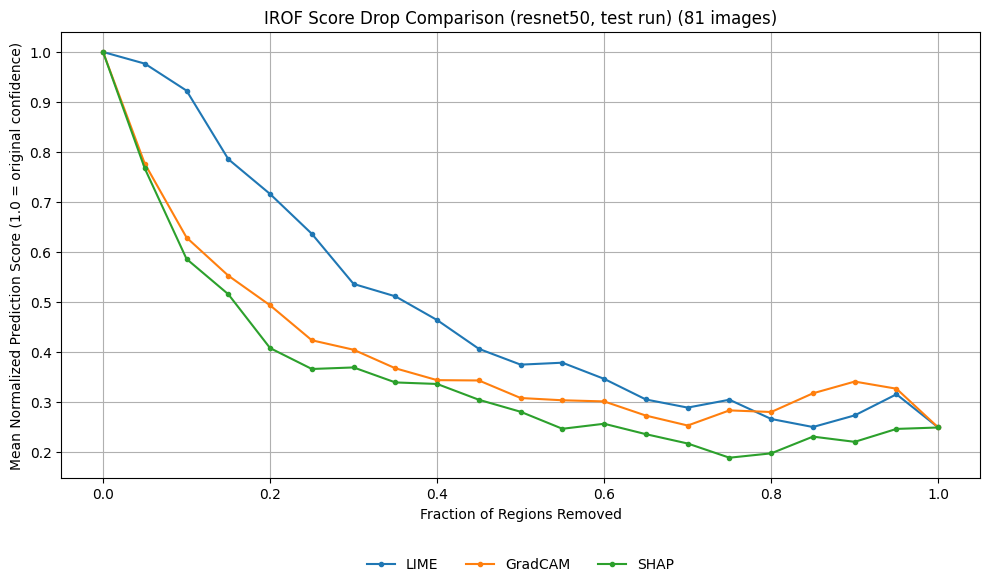

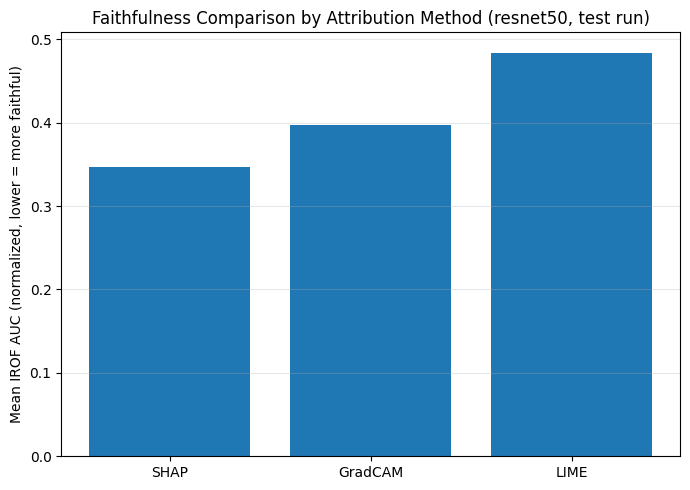


  Faithfulness (IROF) | Model: efficientnetb0


Running faithfulness (IROF) test run on 81 images 


IROF:   0%|                                                        | 0/81 [00:00<?, ?it/s]

[W910 16:29:11.125723978 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.


IROF:   1%|▌                                               | 1/81 [00:07<09:42,  7.28s/it]

IROF:   2%|█▏                                              | 2/81 [00:14<09:34,  7.28s/it]

IROF:   4%|█▊                                              | 3/81 [00:23<10:24,  8.01s/it]

IROF:   5%|██▎                                             | 4/81 [00:30<09:48,  7.65s/it]

IROF:   6%|██▉                                             | 5/81 [00:37<09:15,  7.31s/it]

IROF:   7%|███▌                                            | 6/81 [00:44<09:15,  7.41s/it]

IROF:   9%|████▏                                           | 7/81 [00:51<08:54,  7.22s/it]

IROF:  10%|████▋                                           | 8/81 [00:58<08:32,  7.02s/it]

IROF:  11%|█████▎                                          | 9/81 [01:05<08:33,  7.13s/it]

IROF:  12%|█████▊                                         | 10/81 [01:13<08:38,  7.30s/it]

IROF:  14%|██████▍                                        | 11/81 [01:20<08:37,  7.39s/it]

IROF:  15%|██████▉                                        | 12/81 [01:27<08:17,  7.21s/it]

IROF:  16%|███████▌                                       | 13/81 [01:35<08:22,  7.39s/it]

IROF:  17%|████████                                       | 14/81 [01:42<08:09,  7.31s/it]

IROF:  19%|████████▋                                      | 15/81 [01:50<08:10,  7.42s/it]

IROF:  20%|█████████▎                                     | 16/81 [01:57<08:02,  7.42s/it]

IROF:  21%|█████████▊                                     | 17/81 [02:04<07:39,  7.18s/it]

IROF:  22%|██████████▍                                    | 18/81 [02:10<07:21,  7.01s/it]

IROF:  23%|███████████                                    | 19/81 [02:18<07:22,  7.14s/it]

IROF:  25%|███████████▌                                   | 20/81 [02:25<07:16,  7.16s/it]

IROF:  26%|████████████▏                                  | 21/81 [02:33<07:30,  7.50s/it]

IROF:  27%|████████████▊                                  | 22/81 [02:40<07:04,  7.19s/it]

IROF:  28%|█████████████▎                                 | 23/81 [02:47<06:58,  7.22s/it]

IROF:  30%|█████████████▉                                 | 24/81 [02:56<07:11,  7.57s/it]

IROF:  31%|██████████████▌                                | 25/81 [03:02<06:43,  7.20s/it]

IROF:  32%|███████████████                                | 26/81 [03:09<06:37,  7.23s/it]

IROF:  33%|███████████████▋                               | 27/81 [03:17<06:38,  7.38s/it]

IROF:  35%|████████████████▏                              | 28/81 [03:25<06:36,  7.47s/it]

IROF:  36%|████████████████▊                              | 29/81 [03:32<06:29,  7.49s/it]

IROF:  37%|█████████████████▍                             | 30/81 [03:39<06:19,  7.43s/it]

IROF:  38%|█████████████████▉                             | 31/81 [03:48<06:24,  7.69s/it]

IROF:  40%|██████████████████▌                            | 32/81 [03:55<06:16,  7.68s/it]

IROF:  41%|███████████████████▏                           | 33/81 [04:04<06:18,  7.89s/it]

IROF:  42%|███████████████████▋                           | 34/81 [04:11<06:00,  7.67s/it]

IROF:  43%|████████████████████▎                          | 35/81 [04:18<05:46,  7.53s/it]

IROF:  44%|████████████████████▉                          | 36/81 [04:25<05:36,  7.47s/it]

IROF:  46%|█████████████████████▍                         | 37/81 [04:33<05:25,  7.39s/it]

IROF:  47%|██████████████████████                         | 38/81 [04:41<05:27,  7.62s/it]

IROF:  48%|██████████████████████▋                        | 39/81 [04:49<05:27,  7.80s/it]

IROF:  49%|███████████████████████▏                       | 40/81 [04:55<05:02,  7.39s/it]

IROF:  51%|███████████████████████▊                       | 41/81 [05:03<04:57,  7.43s/it]

IROF:  52%|████████████████████████▎                      | 42/81 [05:11<04:59,  7.68s/it]

IROF:  53%|████████████████████████▉                      | 43/81 [05:20<04:59,  7.88s/it]

IROF:  54%|█████████████████████████▌                     | 44/81 [05:27<04:45,  7.73s/it]

IROF:  56%|██████████████████████████                     | 45/81 [05:34<04:28,  7.46s/it]

IROF:  57%|██████████████████████████▋                    | 46/81 [05:40<04:08,  7.09s/it]

IROF:  58%|███████████████████████████▎                   | 47/81 [05:47<03:57,  6.98s/it]

IROF:  59%|███████████████████████████▊                   | 48/81 [05:53<03:41,  6.73s/it]

IROF:  60%|████████████████████████████▍                  | 49/81 [06:00<03:35,  6.74s/it]

IROF:  62%|█████████████████████████████                  | 50/81 [06:08<03:38,  7.06s/it]

IROF:  63%|█████████████████████████████▌                 | 51/81 [06:16<03:42,  7.42s/it]

IROF:  64%|██████████████████████████████▏                | 52/81 [06:22<03:28,  7.19s/it]

IROF:  65%|██████████████████████████████▊                | 53/81 [06:30<03:21,  7.20s/it]

IROF:  67%|███████████████████████████████▎               | 54/81 [06:36<03:08,  6.99s/it]

IROF:  68%|███████████████████████████████▉               | 55/81 [06:43<03:03,  7.04s/it]

IROF:  69%|████████████████████████████████▍              | 56/81 [06:50<02:52,  6.89s/it]

IROF:  70%|█████████████████████████████████              | 57/81 [06:58<02:50,  7.12s/it]

IROF:  72%|█████████████████████████████████▋             | 58/81 [07:05<02:42,  7.08s/it]

IROF:  73%|██████████████████████████████████▏            | 59/81 [07:12<02:41,  7.33s/it]

IROF:  74%|██████████████████████████████████▊            | 60/81 [07:20<02:33,  7.33s/it]

IROF:  75%|███████████████████████████████████▍           | 61/81 [07:27<02:26,  7.31s/it]

IROF:  77%|███████████████████████████████████▉           | 62/81 [07:35<02:21,  7.45s/it]

IROF:  78%|████████████████████████████████████▌          | 63/81 [07:42<02:13,  7.40s/it]

IROF:  79%|█████████████████████████████████████▏         | 64/81 [07:49<02:05,  7.37s/it]

IROF:  80%|█████████████████████████████████████▋         | 65/81 [07:57<02:00,  7.50s/it]

IROF:  81%|██████████████████████████████████████▎        | 66/81 [08:04<01:51,  7.41s/it]

IROF:  83%|██████████████████████████████████████▉        | 67/81 [08:10<01:38,  7.00s/it]

IROF:  84%|███████████████████████████████████████▍       | 68/81 [08:18<01:33,  7.17s/it]

IROF:  85%|████████████████████████████████████████       | 69/81 [08:26<01:29,  7.47s/it]

IROF:  86%|████████████████████████████████████████▌      | 70/81 [08:33<01:20,  7.28s/it]

IROF:  88%|█████████████████████████████████████████▏     | 71/81 [08:41<01:13,  7.37s/it]

IROF:  89%|█████████████████████████████████████████▊     | 72/81 [08:48<01:07,  7.50s/it]

IROF:  90%|██████████████████████████████████████████▎    | 73/81 [08:55<00:58,  7.36s/it]

IROF:  91%|██████████████████████████████████████████▉    | 74/81 [09:02<00:50,  7.27s/it]

IROF:  93%|███████████████████████████████████████████▌   | 75/81 [09:10<00:43,  7.26s/it]

IROF:  94%|████████████████████████████████████████████   | 76/81 [09:16<00:34,  6.98s/it]

IROF:  95%|████████████████████████████████████████████▋  | 77/81 [09:25<00:29,  7.44s/it]

IROF:  96%|█████████████████████████████████████████████▎ | 78/81 [09:32<00:22,  7.45s/it]

IROF:  98%|█████████████████████████████████████████████▊ | 79/81 [09:40<00:15,  7.58s/it]

IROF:  99%|██████████████████████████████████████████████▍| 80/81 [09:49<00:07,  7.96s/it]

IROF: 100%|███████████████████████████████████████████████| 81/81 [09:56<00:00,  7.68s/it]

IROF: 100%|███████████████████████████████████████████████| 81/81 [09:56<00:00,  7.36s/it]


Collected 243 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_efficientnetb0_test_2026-09-10.csv
Saved summary to /data/aveera/results/irof_summary_efficientnetb0_test_2026-09-10.csv

=== Faithfulness (IROF) summary | efficientnetb0 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3757,0.1595,81
0,GradCAM,0.3825,0.1845,81
1,LIME,0.6052,0.2369,81


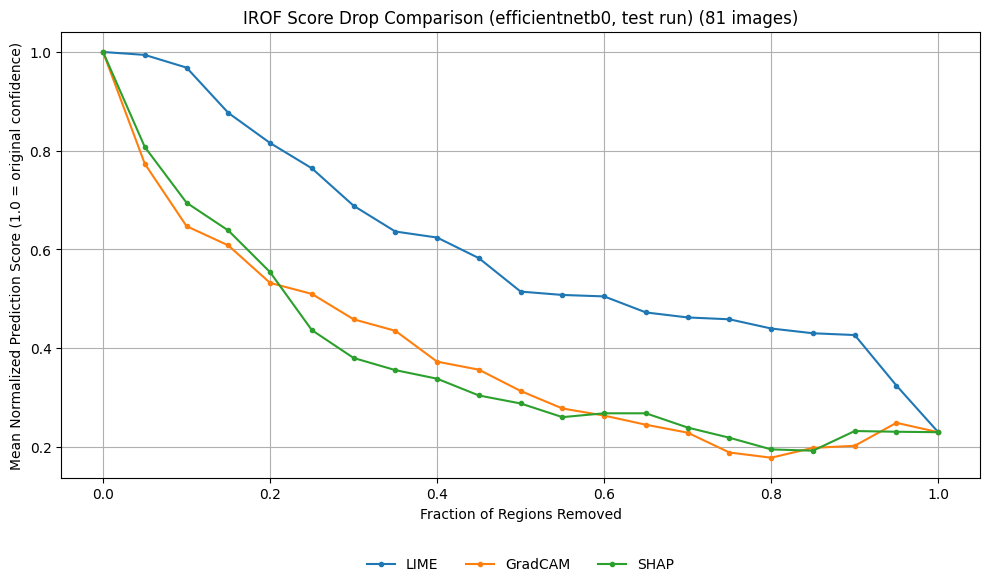

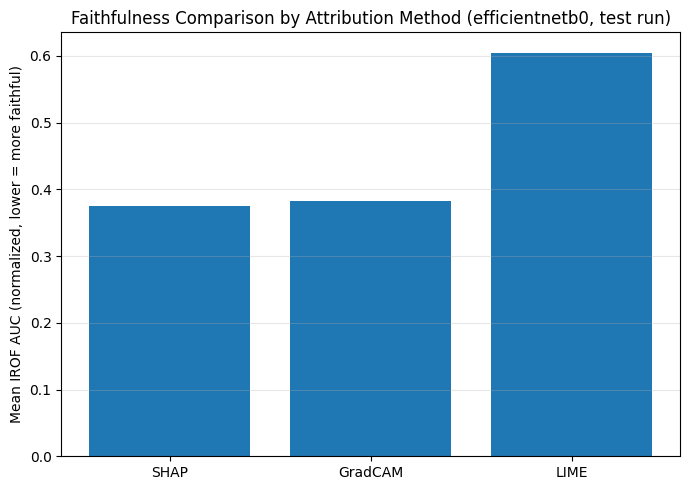


=== Combined IROF summary (all models) ===


,model,method,mean_irof_auc,std_irof_auc,n_images
2,efficientnetb0,SHAP,0.3757,0.1595,81
0,efficientnetb0,GradCAM,0.3825,0.1845,81
1,efficientnetb0,LIME,0.6052,0.2369,81
5,resnet50,SHAP,0.3466,0.1835,81
3,resnet50,GradCAM,0.3971,0.1861,81
4,resnet50,LIME,0.4840,0.2310,81


In [46]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_trapz = getattr(np, "trapezoid", None) or np.trapz

all_irof_dfs = []
irof_curves_by_model = {}

for model_name in["resnet50", "efficientnetb0"]:
    print(f"\n{'='*60}\n  Faithfulness (IROF) | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    N_FAITHFULNESS_IMAGES = len(next(iter(method_maps.values())))
    faithfulness_samples = idrid_subset[:N_FAITHFULNESS_IMAGES]

    predicted_labels = get_predicted_labels(model, faithfulness_samples, device)

    print(f"Running faithfulness (IROF) test run on {N_FAITHFULNESS_IMAGES} images ")

    full_irof_df, irof_curves, irof_random_curves = run_irof_evaluation(
        model, faithfulness_samples, predicted_labels, method_maps
    )

    full_irof_df['model'] = model_name
    all_irof_dfs.append(full_irof_df)
    irof_curves_by_model[model_name] = irof_curves

    print(f"\nCollected {len(full_irof_df)} IROF measurements")

    irof_summary = summarize_and_save_irof(
        full_irof_df,
        results_dir="/data/aveera/results",
        tag=f"{model_name}_test"
    )

    print(f"\n=== Faithfulness (IROF) summary | {model_name} ===")
    print("    (lower mean_irof_auc = confidence drops faster once top-attributed regions")
    print("     are removed = more faithful explanation)\n")
    display(irof_summary)

    plot_irof_curves(irof_curves, N_FAITHFULNESS_IMAGES, title_suffix=f" ({model_name}, test run)")
    print()
    plot_irof_bar(irof_summary, title_suffix=f" ({model_name}, test run)")

full_irof_df_all_models = pd.concat(all_irof_dfs, ignore_index=True)
combined_irof_summary = (
    full_irof_df_all_models.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
    .sort_values(['model', 'mean_irof_auc'])
)

combined_irof_summary['mean_irof_auc'] = combined_irof_summary['mean_irof_auc'].round(4)
combined_irof_summary['std_irof_auc'] = combined_irof_summary['std_irof_auc'].round(4)

print("\n=== Combined IROF summary (all models) ===")
display(combined_irof_summary)

In [47]:
RESULTS_DIR = "/data/aveera/results"
combined_irof_summary.to_csv(os.path.join(RESULTS_DIR, "irof_summary_all_models.csv"), index=False)

# **Interpretation of the IROF Score Curve**
The displayed score curve illustrates how the model’s output score changes when important image regions are gradually masked. The regions are sorted based on their estimated importance according to the chosen attribution method and then removed step by step.

An ideal score curve would show a continuous and steady decline. This would indicate that the model strongly relies on these regions for its prediction. An unstable or fluctuating curve should not necessarily be interpreted as an error but rather as a possible indication of a robust model or a broadly distributed attribution.

In this case, the score curve shows an unusual pattern. Instead of decreasing steadily, the score goes up and down a lot. There are two possible reasons for this:

1. The model appears to be highly robust to the removal of individual regions and is able to extract relevant information from the remaining areas.

2. The selected attribution method (eg. LIME) distributes importance relatively evenly across many regions, resulting in less focused and highly localized key areas.

In [48]:
def explain_gradcam(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)  # use the model Quantus actually passed in, not a stray global

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        gradcam = eng.compute_gradcam(
            img_tensor.unsqueeze(0).to(eng.device),
            int(target)
        )

        maps.append(gradcam)

    return np.stack(maps)[:, None, :, :]


def explain_lime(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        raw = eng.unnormalize_to_uint8(img_tensor)

        explanation = eng.compute_lime(raw, int(target))
        heatmap = eng.get_lime_heatmap(explanation, int(target))

        maps.append(heatmap)

    return np.stack(maps)[:, None, :, :]


def explain_shap(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)

    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()

        raw = eng.unnormalize_to_uint8(img_tensor)

        shap_values = eng.compute_shap(raw, target_class=int(target), all_classes=False)
        heatmap, _ = eng.get_shap_heatmap(shap_values, class_position=0)

        maps.append(heatmap)

    return np.stack(maps)[:, None, :, :]


explain_funcs = {
    "GradCAM": explain_gradcam,
    "LIME": explain_lime,
    "SHAP": explain_shap,
}

**We use the default Max-Sensitivity parameter choices:**
  -nr_samples =10
  -lower_bound=0.2

In [49]:
# N_TEST = 10
# maxsens_samples = idrid_subset[:N_TEST]

# now = datetime.now().strftime("%Y-%m-%d")
# OUTPUT_DIR = "/data/aveera/results"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# all_maxsens_rows = []

# for model_name in ["resnet50", "efficientnetb0"]:
#     print(f"\n{'='*60}\n  MaxSensitivity Evaluation | Model: {model_name}\n{'='*60}")

#     drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
#     model = load_model(model_name, drive_weight_path, device)

#     engine = AttributionEngine(model, device)
#     _engine_cache.clear()  
#     _engine_cache[id(model)] = engine

#     input_tensors = []
#     for raw_img_np, _ in maxsens_samples:
#         image_np = raw_img_np.astype(np.float32) / 255.0
#         t = preprocess_image(image_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
#         input_tensors.append(t.squeeze(0))
#     input_batch = torch.stack(input_tensors).to(device)

#     x_batch = input_batch.cpu().numpy()
#     y_batch = get_predicted_labels(model, maxsens_samples, device)

#     model_rows = []  # per-model rows, saved incrementally

#     for method, explain_func in sorted(explain_funcs.items()):
#         print(f"  Computing MaxSensitivity for: {method} ({model_name})")

#         np.random.seed(SEED)
#         random.seed(SEED)
#         torch.manual_seed(SEED)

#         a_list = []
#         for i in range(x_batch.shape[0]):
#             a_i = explain_func(model, x_batch[i:i+1], y_batch[i:i+1])
#             a_list.append(a_i[0])
#         a_batch = np.stack(a_list)
#         del a_list
#         gc.collect()

#         metric = MaxSensitivity(
#             nr_samples=10,
#             lower_bound=0.2,
#             norm_numerator=norm_func.fro_norm,
#             norm_denominator=norm_func.fro_norm,
#             similarity_func=similarity_func.difference,
#         )

#         try:
#             max_sens = metric(
#                 model=model,
#                 x_batch=x_batch,
#                 y_batch=y_batch,
#                 a_batch=a_batch,
#                 device=device,
#                 explain_func=explain_func,
#             )

#             for img_idx, score in enumerate(max_sens):
#                 row = {
#                     'model':           model_name,
#                     'method':          method,
#                     'image_index':     img_idx,
#                     'max_sensitivity': float(score),
#                 }
#                 model_rows.append(row)
#                 all_maxsens_rows.append(row)

#         except Exception as e:
#             print(f"Error in method {method} for model {model_name}: {e}")

#         finally:
#             del a_batch
#             if 'max_sens' in dir():
#                 del max_sens
#             gc.collect()
#             if device.type == "cuda":
#                 torch.cuda.empty_cache()

#     # Save this model's results immediately so partial progress survives
#     model_df = pd.DataFrame(model_rows)
#     model_df.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_{model_name}_{now}.csv'), index=False)
#     print(f"  Saved {model_name} results to maxsens_{model_name}_{now}.csv")

#     # Free the model and engine before moving to the next one
#     del model, engine
#     _engine_cache.clear()
#     gc.collect()
#     if device.type == "cuda":
#         torch.cuda.empty_cache()

In [50]:
# full_maxsens_df = pd.DataFrame(all_maxsens_rows)
# display(full_maxsens_df)

# maxsens_summary = (
#     full_maxsens_df
#     .groupby(['model', 'method'])['max_sensitivity']
#     .agg(['mean', 'std', 'count'])
#     .reset_index()
#     .rename(columns={'mean': 'mean_max_sensitivity', 'std': 'std_max_sensitivity', 'count': 'n_images'})
# )
# maxsens_summary['mean_max_sensitivity'] = maxsens_summary['mean_max_sensitivity'].round(4)
# maxsens_summary['std_max_sensitivity'] = maxsens_summary['std_max_sensitivity'].round(4)
# maxsens_summary = maxsens_summary.sort_values(['model', 'mean_max_sensitivity'])

# print("\n=== MaxSensitivity summary -- mean score per model/method ===")
# print("    (lower mean_max_sensitivity = explanation changes less under small input")
# print("     perturbations = more robust explanation)\n")
# display(maxsens_summary)


# now = datetime.now().strftime("%Y-%m-%d")
# OUTPUT_DIR = "/data/aveera/results"
# os.makedirs(OUTPUT_DIR, exist_ok=True)
# full_maxsens_df.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_full_{now}.csv'), index=False)
# maxsens_summary.to_csv(os.path.join(OUTPUT_DIR, f'maxsens_summary_{now}.csv'), index=False)
# print(f"\nSaved per-image results to maxsens_full_{now}.csv")
# print(f"Saved summary to maxsens_summary_{now}.csv")

In [51]:
# plt.figure(figsize=(9, 5))
# pivot = maxsens_summary.pivot(index='method', columns='model', values='mean_max_sensitivity')
# pivot.plot(kind='bar', ax=plt.gca())
# plt.yscale("log")
# plt.ylabel("Mean MaxSensitivity (log scale, lower = more robust)")
# plt.title(f"MaxSensitivity Comparison by Model and Method")
# plt.xticks(rotation=0)
# plt.grid(axis="y", alpha=0.3)
# plt.tight_layout()
# plt.show()
